# 05. 변환·파생변수 — 전체 11단계 중 5단계

**어디서 나온 노트북인가.** 4단계(무엇이 LNG를 움직이는지 그림과 상관으로 보는 단계)를 닫으면서 「다음 단계로 넘기는 물음」 칸에 5단계에서 볼 것 넷을 적어 두었습니다. 그 넷이 이 노트북의 물음이었고, 09-24에 물음 1을 마치며 시간 지연을 더하고 기온 이야기를 이어서 하도록 순서를 바꿨습니다 — ① 기온을 어떤 숫자로 바꿔 넣을까 ② 시간 지연(전날 평균기온·몇 시간 전 기온)을 열로 넣을까 ③ 태양광 열을 어떤 모양으로 만들까 ④ 기온과 시간대를 묶은 열을 만들까(09-27에 태양광을 앞으로 옮겼습니다) ⑤ 공휴일을 따로 넣을까. 5단계를 닫기 전 점검에서 09-29에 ⑥ 단위가 다른 열을 표준화해서 넘길까를, 09-30에 ⑦ 쉬는 날에 시간대마다 따로 주는 열을 선형회귀에 넣을까를 더했습니다. 둘 다 클로드가 찾은 물음입니다(클로드 제안).

**이 단계가 하는 일.** 있는 칸으로 새 칸을 만듭니다. 새 데이터를 받지 않고, 이미 가진 열을 모델이 알아듣기 좋은 모양으로 바꾸거나 둘을 묶어 새 열을 만듭니다. 4단계에서 시각 하나로 hour24(시간대)·dow(요일)·is_weekend(주말)·month(월)를 이미 만들었고, 여기서 더 만듭니다.

**여기서 정하지 않는 것.** 만든 열 중에 무엇을 실제로 입력에 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다. 이 노트북에서는 만들 수 있는 모양을 보고 어느 모양이 나은지까지만 정합니다.

**09-17에 만들어 둔 옛 노트북을 09-22에 다시 짰습니다.** 옛것은 「묶음 3b」 시절 모양이라 네 군데가 지금과 어긋났습니다 — ⓐ ✍️ 칸 모양이 달랐습니다 ⓑ 준비 셀이 원자료를 처음부터 다시 읽어서, 돌리면 3단계가 만든 표를 덮어썼습니다 ⓒ 태양광이 설비용량으로 들어가 있었습니다(09-19에 발전량으로 바꾸기로 정했습니다) ⓓ 공휴일을 `holidays` 패키지로 다시 만들고 있었습니다(09-19에 받아서 `data/raw/holidays_kr.csv`에 두었습니다). 옛 파일은 `notebooks/.bak_0922/`에 그대로 있습니다.

**먼저 준비 ①과 준비 ②를 돌립니다.**

| 단계 | 이름 |
|---|---|
| 1 | 과제 정의 |
| 2 | 데이터 수집과 구성 보기 |
| 3 | 정제 |
| 4 | 탐색적 분석 |
| 5 | 변환·파생변수 ◀ 이 노트북 |
| 6 | 분석계획 |
| 7 | 모델링과 검정 |
| 8 | 모델 확정과 핵심인자 |
| 9 | 이 과제만의 물음 — 2026년은 평소와 얼마나 달랐나 |
| 10 | 그 답을 숫자로 내기 |
| 11 | 결론 |

진행 기록(지금 어디)은 리포의 `README.md`가 원본입니다. 단계마다 무엇을 하고 내가 무엇을 정하는지는 옵시디언 볼트 「빅데이터 분석의 순서」에 있습니다.

In [922]:
# 5단계 파생변수 · 준비 ①
import os                                      # 폴더와 파일 경로를 다루는 기본 모듈
import numpy as np                             # 조건에 따라 값을 고르는 계산에 쓴다
import pandas as pd                            # 표(데이터프레임)를 다루는 라이브러리
import matplotlib.pyplot as plt                # 그림을 그리는 라이브러리
from IPython.display import display            # 표를 글자가 아니라 격자로 그린다
plt.rcParams["font.family"] = "AppleGothic"    # 맥에서 그림 속 한글이 깨지지 않게
plt.rcParams["axes.unicode_minus"] = False     # 그림의 마이너스 부호가 깨지지 않게
pd.set_option("display.max_columns", 50)       # 열이 많아도 생략하지 않고 다 보이게

ROOT = os.getcwd()                             # 지금 폴더(보통 notebooks/)에서 시작해서
while not os.path.isdir(os.path.join(ROOT, "data")) and ROOT != os.path.dirname(ROOT):
    ROOT = os.path.dirname(ROOT)               # data 폴더가 보일 때까지 위로 = 프로젝트 루트
HOT = os.path.join(ROOT, "data", "hot")        # 3단계가 만들어 둔 정제된 표가 있는 폴더
RAW = os.path.join(ROOT, "data", "raw")        # 원자료 폴더 — 공휴일 파일과 3-라의 기상청 원자료를 읽는다

print("프로젝트 루트:", ROOT)                    # 경로가 맞는지만 확인한다

프로젝트 루트: /Users/kimchangju/vs코드 /개인 프로젝트/lng-project


In [923]:
# 5단계 파생변수 · 준비 ②
tbl = pd.read_csv(os.path.join(HOT, "clean_2023_2024_2025.csv"), encoding="utf-8-sig")  # 3단계가 만든 표를 읽는다
tbl["ts"] = pd.to_datetime(tbl["ts"])            # 파일에 글자로 저장된 시각을 다시 시각 자료형으로

hol = pd.read_csv(os.path.join(RAW, "holidays_kr.csv"), encoding="utf-8-sig")   # 2단계에서 받아 둔 공휴일 78일
공휴일날짜 = set(pd.to_datetime(hol["date"]).dt.date)                             # 날짜만 뽑아 한 덩어리로 모은다
tbl["is_holiday"] = tbl["ts"].dt.date.isin(공휴일날짜).astype(int)                 # 그 시각의 날짜가 공휴일이면 1, 아니면 0

학습해 = [2023, 2024]                             # 학습에 쓸 해 — 2024년은 2월 29일과 8월 한 달이 빠져 334일이다
train = tbl[tbl["year"].isin(학습해)].copy()       # 학습 기간 — 재료는 여기서만 뽑는다
valid = tbl[tbl["year"] == 2025].copy()           # 채점 기간 — 2025년은 결정을 내리는 데 쓰지 않는다

print("표 모양 (행, 열):", tbl.shape, "· 빈 칸 합계:", int(tbl.isna().sum().sum()))
print("학습", 학습해, len(train), "행 / 채점 2025", len(valid), "행")
print("열 이름:", ", ".join(tbl.columns))
print()
요약 = tbl.groupby("year").agg(행수=("ts", "size"), 시작=("ts", "min"),
                              끝=("ts", "max"), 공휴일시각=("is_holiday", "sum"))
display(요약)

표 모양 (행, 열): (25536, 14) · 빈 칸 합계: 0
학습 [2023, 2024] 16776 행 / 채점 2025 8760 행
열 이름: ts, lng_mwh, nuke_mwh, solar_cap_mw, ta, hm, icsr, year, month, hour24, dow, is_weekend, solar_mwh, is_holiday



,행수,시작,끝,공휴일시각
year,,,,
2023,8760,2023-01-01,2023-12-31 23:00:00,432
2024,8016,2024-01-01,2024-12-31 23:00:00,432
2025,8760,2025-01-01,2025-12-31 23:00:00,456


# 물음 1 — 기온을 어떤 숫자로 바꿔 넣을까

**적을 곳 아홉입니다 — 「1-가」부터 「1-자」까지 셀마다 아래에 있는 「✍️ 내 답변」 칸입니다.** 1-다 칸에는 번호 붙은 질문이 셋 있고, 넘길 방식(②)은 1-자 칸 아래에서 정했습니다(09-24, 바로 아래 「물음 1 결론」). 1-라부터 1-자까지는 09-24에 창주 님이 칸에 적으신 물음을 보고 더한 셀입니다. 셀마다 어디서 나왔는지는 아래 🗂️ 칸에 있습니다.

**어디서 나온 물음인가.** 4단계 1-라에서 상관표를 보다가 나왔습니다. 기온과 LNG 발전량의 상관은 −0.06입니다. 이 숫자는 「둘이 관계가 없다」는 뜻이 아닙니다. 상관계수는 한쪽으로 기우는 직선 관계만 봅니다. 그런데 LNG는 추울 때도 올라가고 더울 때도 올라갑니다. 두 방향이 서로 지워져서 0 근처가 된 것입니다. 같은 자료를 「16도에서 얼마나 떨어졌나」로 바꿔서 다시 보니 0.359가 나왔습니다.

**무엇을 정하는가.** 기온을 모델에 어떤 숫자로 건넬지 셋 중에서 정합니다.

- **ⓐ 기온을 그대로 넣는다** — 열 하나로 끝납니다. 위에서 말한 문제가 그대로 남습니다.
- **ⓑ 기준온도에서 떨어진 정도를 한 열로 넣는다**(|기온 − 기준온도|) — 추운 쪽과 더운 쪽을 한 열에 담습니다. 대신 「1도 추워질 때 오르는 만큼 1도 더워질 때도 오른다」고 가정하게 됩니다.
- **ⓒ 난방도와 냉방도 두 열로 가른다** — 난방도는 기준보다 추운 만큼(더우면 0), 냉방도는 기준보다 더운 만큼(추우면 0)입니다. ⓑ의 가정을 풀 수 있지만 열이 하나 늡니다.

ⓑ나 ⓒ를 고르면 기준온도를 몇 도로 둘지도 같이 정해야 합니다.

**여기서 정하는 것과 6단계에서 정하는 것.** 이 단계에서 정하는 것은 「어떤 모양을 만들어 둘까」까지입니다. 그 열을 실제로 모델에 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다. 갈라 두는 이유는 어느 모양이 나은지가 **어떤 모델을 쓰느냐에 따라 달라지기 때문**입니다. 트리 계열(의사결정나무·랜덤포레스트·XGBoost)은 「이 값보다 큰가」로 칸을 나누며 배우기 때문에 기온을 그대로 넣어도 추운 쪽과 더운 쪽을 스스로 갈라냅니다. 선형회귀는 기울기 하나로 배우기 때문에 ⓐ를 넣으면 추운 쪽과 더운 쪽이 서로 지워집니다. 시험할 모델은 6단계에서 정하므로, 여기서는 유력한 모양을 고르고 필요하면 열을 둘 다 만들어 둡니다.

**재료 아홉**

- **1-가** — 기준온도를 12도부터 22도까지 바꿔 가며 ⓑ와 ⓒ의 상관이 어떻게 달라지는지 숫자로 봅니다.
- **1-나** — 기온 구간별 LNG 평균이 어떤 모양을 그리는지, 바닥이 몇 도인지 봅니다.
- **1-다** — 추운 쪽과 더운 쪽의 기울기가 같은지 봅니다. 여기서 ⓑ와 ⓒ가 갈립니다.
- **1-라** — 기준온도를 1도씩 바꿔 가며 ⓑ와 ⓒ로 LNG에 직선을 맞춰 보고, 어느 기준에서 가장 많이 설명하는지(R²) 봅니다. 09-24에 더했습니다.
- **1-마** — 난방도 기준과 냉방도 기준을 따로 두고, 시간대와 월을 고정했을 때 냉방도 기준에 따라 R²가 어떻게 바뀌는지 봅니다. 09-24에 더했습니다.
- **1-바** — 기준을 하나(16도)로 둘 때와 둘(16·24도)로 둘 때 맞춘 선을 기온 구간별 평균 위에 겹쳐 그립니다. 09-24에 더했습니다.
- **1-사** — 16·24도로 나눈 3구간에 나누는 온도를 하나 더 두면(4구간·5구간) 시간대·월을 고정한 R²가 얼마나 느는지 봅니다. 09-24에 더했습니다.
- **1-아** — 난방 쪽 나누는 온도를 10~20도로 바꿔 보고, 선을 끊었을 때와 이었을 때를 비교합니다. 09-24에 더했습니다.
- **1-자** — 16·24도와 10·16·24도로 나눈 선에서 16~24도에 따로 기울기를 주면 R²가 느는지 봅니다. 10·12·24도(⑤)와 9·12·24도(⑥)도 같이 놓습니다. 09-24에 더했습니다.

**미리 말씀드릴 한계 하나.** 아래 숫자에는 시간대가 섞여 있습니다. 새벽 3시는 기온도 낮고 LNG도 낮기 때문에, 기온만의 효과가 실제보다 크거나 작게 나올 수 있습니다. 시간대와 월을 고정하고 기준온도를 다시 보는 것은 1-마에서 하고, 기온의 효과가 시간대마다 다른지는 물음 4(기온과 시간대를 묶은 열을 만들까)에서 봅니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 1 결론

**왜 생긴 물음인가** — 4단계 1-라에서 기온 그대로의 상관은 −0.06인데 16도 기준으로 바꾸면 0.359가 나왔다. 추울 때와 더울 때 둘 다 LNG가 올라 두 방향이 서로 지워진 것이라, 기온을 어떤 숫자로 넣을지 정한 물음이다.

### 결정 — 7단계로 넘길 기온 방식 넷: 기온 그대로(트리용) · 16·24도 · 10·16·24도(16~24도 평평) · 9·12·24도(구간마다 기울기)

**결정 근거** — 1-마에서 난방 16도·냉방 24도로 나누면 시간대·월을 고정한 R²가 0.501이었고, 냉방 기준 23~27도는 0.500~0.502로 같았다. 1-사·1-아·1-자에서 더 잘게 나누거나, 선을 끊거나, 16~24도에 기울기를 줘도 0.502 안쪽이었다(0.002 안쪽은 같다고 봤다). 16~24도에 기울기를 주는 방식은 09-24에 빠뜨렸다가 1-자에서 확인했다. 판단은 1-자 「✍️ 읽고 나서」 ②에 적었다 — 계산 시간 차이가 없으니 셋으로 가고, 그래프에서 보이는 9·12·24도도 넣는다. 클로드 제안은 기온 그대로와 16·24도 둘이었다.

**남은 것** — 선형회귀용 셋은 7단계에서 2024년 검증으로 비교하고, 16·24도보다 나아지지 않는 것은 거기서 뺀다. 16~24도 기울기가 음수로 나온 것은 물음 3의 3-다에서 햇빛 때문이었다고 확인했다. 물음 4에서 16·24도 × 시간대(48열)를 선형회귀용으로 하나 더 넘겨, 넘기는 지금 기온 방식은 모두 다섯이 됐다(물음 4 결론 칸).

→ **이어진 곳(10-05)** — 7단계까지 미루지 않고 6단계에서 줄였다. 10·16·24도와 9·12·24도는 2023년으로 배워 2024년을 맞힌 R²가 16·24도보다 나아지지 않아 뺐다(6단계 닫는 칸 ① 첫 줄, 09-30, 클로드 판단 · 4-가 [표 B]). 7단계에는 선형회귀에 16·24도, 기온 × 시간대 선형회귀에 16·24도 × 시간대, 트리 계열에 기온 그대로를 넘긴다(6단계 물음 4·6).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 1 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 1-가 | 4단계 물음 1 · 1-라 상관표 → 5단계 물음 1 머리 칸 (클로드가 물음을 열며 계획) | 기온을 16도 기준으로 바꾸니 LNG와의 상관이 0.359였다. 다른 기준온도와는 비교해 보지 않았다 | 16도가 가장 나은 기준온도인지 |
| 1-나 | 5단계 물음 1 · 1-가 (물음을 열 때 같이 계획) | 1-가는 기준온도마다 상관 하나씩만 낸다 | 상관이 가장 큰 기준온도가 실제로 LNG가 가장 낮은 온도인지 |
| 1-다 | 5단계 물음 1 머리 칸 (물음을 열 때 같이 계획) | ⓑ(한 열)와 ⓒ(난방도·냉방도 두 열)는 추운 쪽과 더운 쪽의 기울기가 같으냐로 갈린다 | ⓑ와 ⓒ 가운데 무엇으로 갈지 |
| 1-라 | 5단계 1-가 · 1-나 · 1-다 「✍️ 내 답변」 | 「이걸 조금 더 적합한 방향으로 볼 수 있는 방식이 있을까??」 · 「여기중 무엇으로 정해야 하지??」 · 「기준이라면 그냥 가장 낮은 값만 기준으로 보면 될까??」 | 1-나에서 12~20도가 거의 평평해서 기준온도 한 점이 골라지지 않았다 |
| 1-마 | 5단계 1-나 「✍️ 읽고 나서」 · 1-라 「✍️ 내 답변」 ② | 「특정한 값들을 고정시키고 비교시켰던 거 같은데..?」 · 「b도 고려해야 하는건가?」 | 1-라는 시간대·월을 고정하지 않았고, ⓑ는 15도·ⓒ는 22도에서 가장 커서 난방 쪽과 냉방 쪽 기준을 따로 둘지 |
| 1-바 | 5단계 1-마 「✍️ 읽고 나서」 ② | 「그러면 난방일 때는 어떻게 해??」 | 난방도 16도·냉방도 24도로 나누면 실제로 어떤 모양의 선이 되는지 |
| 1-사 | 5단계 1-바 「✍️ 내 답변」 ② · 1-마 「✍️ 다시 읽고 나서」 | 「24이상, 16~24, 그리고 16~10, 10~-5도?? 이렇게 나누는건?」 · 「지금 우리가 여러 가정을 다 정해둬도 되는건가?」 | 기온을 더 잘게 나누면(4구간·5구간) 설명이 느는지 |
| 1-아 | 5단계 1-사 「✍️ 읽고 나서」 · 그 아래 ② | 「이러면 또 기준점을 바꿔야하나??」 · 「이게 곡선이 꼭 연결되어야 하나??」 | 난방 쪽 나누는 온도를 12도로 낮출지, 선을 끊어도 되는지 |
| 1-자 | 5단계 1-바 「✍️ 내 답변」 → 1-아 「✍️ 읽고 나서」 2번 | 「이 구간만 좁혀가지고 회귀 곡선을 그려보면」 → 「원래 내 생각 — 16도로 좌우를 나누고, 그래프가 크게 갈리는 곳에서 한 번씩 더 나누는 4등분 — 은 앞에서 했나?」 | 16~24도에 따로 기울기를 주는 방식을 본 적이 없었다. 클로드가 1-사에서 1-바의 생각을 빠뜨렸다 |

</div>

## 1-가

**어디서 나온 셀인가.** 4단계 1-라에서 상관표를 낼 때 기온만 16도 기준으로 바꿔서 0.359를 확인했습니다. 그때는 16도가 가장 나은 기준인지 다른 온도와 견줘 보지 않았습니다. 이 셀이 그것을 봅니다.

**무엇을 보는 셀인가.** 기준온도 후보 여섯(12·14·16·18·20·22도)마다 ⓑ와 ⓒ의 상관이 얼마인지 표로 냅니다. 「난방도>0 시각」과 「냉방도>0 시각」은 그 기준으로 갈랐을 때 각 쪽에 몇 시각이 들어가는지입니다 — 한쪽이 너무 적으면 그 열은 모델이 배울 재료가 모자랍니다. 학습 기간(2023+2024, 16,776시각)만 씁니다. 2025년은 채점용이라 여기서 보지 않습니다.

In [924]:
# 5단계 파생변수 · 1-가
표 = []                                                              # 기준온도마다 한 줄씩 담을 목록
for 기준 in (12, 14, 16, 18, 20, 22):                                 # 기준온도 후보 여섯
    난방도 = (기준 - train["ta"]).clip(lower=0)                        # 기준보다 추운 만큼. 더우면 0으로 깎는다
    냉방도 = (train["ta"] - 기준).clip(lower=0)                        # 기준보다 더운 만큼. 추우면 0으로 깎는다
    떨어진정도 = (train["ta"] - 기준).abs()                            # 부호를 떼고 떨어진 거리만 — ⓑ가 쓰는 값
    표.append({"기준온도": 기준,
               "ⓑ |기온-기준|": round(train["lng_mwh"].corr(떨어진정도), 3),   # LNG와의 상관
               "ⓒ 난방도": round(train["lng_mwh"].corr(난방도), 3),
               "ⓒ 냉방도": round(train["lng_mwh"].corr(냉방도), 3),
               "난방도>0 시각": int((난방도 > 0).sum()),                 # 그 기준보다 추웠던 시각 수
               "냉방도>0 시각": int((냉방도 > 0).sum())})                # 그 기준보다 더웠던 시각 수

print("ⓐ 기온을 그대로 넣을 때의 상관:", round(train["lng_mwh"].corr(train["ta"]), 3))
print("기준온도를 바꿔 가며 본 상관 — 학습 기간(2023+2024) 16,776시각")
display(pd.DataFrame(표).set_index("기준온도"))

ⓐ 기온을 그대로 넣을 때의 상관: -0.06
기준온도를 바꿔 가며 본 상관 — 학습 기간(2023+2024) 16,776시각


,ⓑ |기온-기준|,ⓒ 난방도,ⓒ 냉방도,난방도>0 시각,냉방도>0 시각
기준온도,,,,,
12,0.307,0.202,0.081,6952,9794
14,0.354,0.200,0.118,7865,8862
16,0.359,0.191,0.155,8824,7900
18,0.330,0.177,0.192,9812,6914
20,0.285,0.160,0.228,10918,5809
22,0.235,0.140,0.263,11908,4805


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 물음 자체에서 조금 헷갈리긴 한데, 어떤 방식으로 기온을 구성하는지에 따라 적합한 모델이 달라진다는건 이해했어. 회귀는 직선을 그리니까 하나의 선이기에 뭉뚱그릴 수 있다는 점(다중 회귀를 고려하면 이 부분을 해소할 수 있는 부분인가?) 트리 계열은 너가 크다, 작다의 방향으로 볼 수 있다고 말한 것을 보면, b,c 둘 다 어쨌든 기준을 중심으로 좌우로 뻗어나가는 것이니까 b와 c의 차이가 뭔지 잘 모르겠네?? b는 숫자 그 자체, 즉 기온의 변화량 자체를 lng의 주요 변수로 보는 관점이라면, c는 기온에 따라 인간이 느끼는 냉방도,뭐 난방도라는 인간이 느끼는 상태 자체를 주요 변수로 보는 관점의 차이인가??

b와 C의 구분이 명확하게 느껴지지 않어. b는 수학에서 배운 것을 생각해보면 결국 차이의 절댓값이니까 기준점을 기준으로 좌우로 같은 크기만큼 뻗어나가는 x축이 그려질거야. 지금 상관도 그래프를 그려놨는데 헷갈리는게, 기준을 내가 정해야 하는거 아닌가?? 아.. 기준 온도가 정해져 있고, 그것과 다른 기온을 기준으로 b,c 각각 시각을 나눈거구나. 이해했어. 그런데 이 수치만 보고 느낌적으로, 16도, 18도 뭐가 더 적절한 기준으로 잡아야할지 감이 잘 안잡히는데?? 이걸 조금 더 적합한 방향으로 볼 수 있는 방식이 있을까?? 아이디어가 잘 떠오르지 않어.

### 클로드 답변

> **짧게**
> 1. ⓑ와 ⓒ는 「숫자 그 자체 대 사람이 느끼는 상태」로 갈리는 것이 아닙니다. 둘 다 같은 기온 숫자로 만들고, **추운 쪽과 더운 쪽을 한 열에 담느냐 두 열로 가르느냐**가 다릅니다.
> 2. 「다중 회귀를 고려하면 이 부분을 해소할 수 있는 부분인가?」 — 기온 한 열을 그대로 넣으면 다중회귀로도 안 풀립니다. **ⓒ가 다중회귀에서 이 문제를 푸는 방법입니다.**
> 3. 「16도, 18도 뭐가 더 적절한 기준인지 볼 수 있는 방식이 있을까??」는 1-라 셀로 만들었습니다. 1-다 아래에 있습니다.

**맞게 읽으신 것**

- 「기준 온도가 정해져 있고, 그것과 다른 기온을 기준으로 b,c 각각 시각을 나눈거구나」 — 맞습니다. 1-가 표는 기준온도 후보 여섯을 한 줄씩 놓고, 그 기준으로 ⓑ·ⓒ를 만들었을 때의 상관과 양쪽 시각 수를 적은 것입니다. 기준을 미리 정해 두고 보는 것이 아니라, 여섯을 다 만들어 보고 고르는 것입니다.
- 「회귀는 직선을 그리니까 하나의 선이기에 뭉뚱그릴 수 있다」 — 맞습니다. 선형회귀는 입력 열 하나에 기울기를 하나 배웁니다. 기온을 그대로(ⓐ) 넣으면 「기온이 1도 오르면 LNG가 몇 MWh 바뀐다」는 한 방향의 숫자 하나만 배우기 때문에, 추워도 오르고 더워도 오르는 U자를 그리지 못합니다.

**다르게 읽으신 것 — ⓑ와 ⓒ의 차이**

「b는 숫자 그 자체… c는 기온에 따라 인간이 느끼는 냉방도, 뭐 난방도라는 인간이 느끼는 상태 자체를 주요 변수로 보는 관점의 차이인가??」라고 적으셨는데, 그런 차이는 아닙니다. 난방도·냉방도는 에너지 분야에서 쓰는 이름일 뿐이고, ⓑ와 똑같이 기온 숫자에서 뺄셈 한 번으로 만듭니다. 기준을 16도로 두고 기온이 6도인 시각과 26도인 시각을 놓아 보면 차이가 보입니다.

| 기온 | ⓑ 떨어진 정도(한 열) | ⓒ 난방도 | ⓒ 냉방도 |
|---|---|---|---|
| 6도 | 10 | 10 | 0 |
| 26도 | 10 | 0 | 10 |

- ⓑ에서는 6도와 26도가 둘 다 10입니다. 모델에게는 두 시각이 같은 값이라서 「10도 추운 것」과 「10도 더운 것」을 구별하지 못하고, LNG도 같은 만큼 오른다고 배웁니다.
- ⓒ에서는 두 시각이 다른 열에 들어갑니다. 그래서 선형회귀가 난방도에 기울기 하나, 냉방도에 기울기 하나를 따로 배웁니다. 추운 쪽과 더운 쪽이 다른 속도로 올라도 담을 수 있습니다.

1-다 칸에 「1-가에서부터 흐름을 쭉 따르다보니 알겠다」고 적으신 것이 이 차이입니다.

**「다중 회귀를 고려하면 이 부분을 해소할 수 있는 부분인가?」**

다중회귀는 입력 열을 여러 개 넣고 **열마다 기울기를 하나씩** 배우는 선형회귀입니다. 그러니 기온 열 하나를 그대로 넣으면, 다른 열이 몇 개 더 있어도 기온에 대한 기울기는 여전히 하나라서 U자가 안 풀립니다. 풀리려면 기온을 **두 열로 갈라서 넣어야** 하고, 그것이 ⓒ입니다. 「다중회귀냐 ⓒ냐」를 고르는 것이 아니라, **다중회귀가 U자를 배울 수 있게 기온을 미리 두 열로 바꿔 두는 것이 ⓒ**입니다. 이것이 5단계(있는 열로 새 열을 만드는 단계)가 하는 일입니다.

「어떤 방식으로 기온을 구성하는지에 따라 적합한 모델이 달라진다」고 적으셨는데, 방향을 반대로 보는 것이 정확합니다. **어떤 모델을 쓰느냐에 따라 기온을 바꿔 넣어야 하는지가 달라집니다.** 선형회귀라면 ⓒ처럼 바꿔 넣어야 하고, 트리 계열이라면 기온을 그대로(ⓐ) 넣어도 「16도보다 낮은가」·「26도보다 높은가」 같은 질문으로 스스로 나눠 배웁니다. 모델은 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

**「16도, 18도 뭐가 더 적절한 기준으로 잡아야할지… 조금 더 적합한 방향으로 볼 수 있는 방식이 있을까??」**

있습니다. 기준온도를 1도씩 바꿔 가며 ⓑ·ⓒ로 LNG에 직선을 실제로 맞춰 보고, 어느 기준에서 LNG를 가장 많이 설명하는지(R², 결정계수)를 비교하는 방법입니다. 1-가처럼 열 하나씩 상관을 보는 것과 달리, ⓒ처럼 열이 둘일 때도 두 열을 함께 넣고 숫자 하나로 비교할 수 있습니다. 1-라 셀로 만들었습니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 다중회귀.** 입력(독립변수)이 둘 이상인 선형회귀입니다. `LNG = 절편 + 기울기1 × 난방도 + 기울기2 × 냉방도`처럼 쓰고, 기울기 하나하나는 「다른 입력은 그대로 두고 그 입력만 1 늘 때 LNG가 바뀌는 양」입니다. 입력과 답의 관계가 굽어 있으면 입력을 그대로 넣어서는 안 잡히고, 입력을 바꿔 넣어야 합니다.
- **3과목 회귀분석 — 다항회귀.** 굽은 관계를 잡는 다른 방법으로, 기온과 기온의 제곱을 같이 넣는 방법이 있습니다. 포물선이 되어 U자를 그릴 수 있지만, 포물선은 꼭짓점을 중심으로 좌우가 같은 모양이라서 ⓑ와 같은 약점(추운 쪽과 더운 쪽이 같은 속도로 오른다고 보는 것)이 남습니다.
- **2과목 파생변수.** 원래 열(기온)에서 계산으로 새 열(난방도·냉방도)을 만드는 것입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러네 둘로 내가 느낌상 나누었지만 어차피 기온이라는 변수로 나눈 것이기에, 숫자 대 사람 그 자체가 나눈다는 가정 자체가 적합한 설명은 아니라는 것이구나. c가 다중회귀로 푸는 방법이라면, 다중 회귀 방식 자체는 그러면 예컨대 x를 기준으로 전혀 다른 함수가 그려지는 방식이라고 보면 되는걸까?? x변수 하나의 구간에서 여러 함수로 바꾸는게 아니라 x가 예컨대 두 구간으로 나뉘어 있다면 그 각각에 가장 적합한 기울기를 찾는 방식?? 그렇게 생각되는데 맞나?? 

- 우리가 c를 선택했다는 것 자체가 이미 구간을 기준으로 다른 기울기를 가진 회귀 방식(뭐 다른 모델링을 쓸 수도 있겠지)을 사용하겠다는 의미 아닌가??
- 다중회귀는 열마다 기울기를 배운다는건 기울기에 영향을 준다는 것이라면 결국 x1,x2,x3.... 이런 여러 x들이 결국 모아져서 하나의 기울기를 찾는 방식인거네?? 예컨대 우리는 지금 기온만 봤다면, 뭐 기온을 기준으로 나누었는데 기준으로 나눈것에 다른 기준을 추가하는 그런 방식?? "다중회귀가 u자를 배울 수 있게??" -> 그런데 다중회귀가 여러 x1,x2 이런것을 쓴다면 다중 회귀가 u자를 배운다는 가정 자체가 이미 기온 말고 다른 변수들도 고려해야 한다는거 아니야?? 단순히 특정한 기온을 기준으로 좌우를 나누는건 다중회귀가 아닌거 아닌가??

- r^2는 결정계수라고 맞어 배웠었다. 이거 빅분기 과목 연결하면 결과 알수 있을건데??? 내가 개념에 적어두지 않았나? 사실 수학적으로 어떤 원리로 지금 그걸 비교하겠다는지 모르겠다. 결정계수는 내가 기억하기로는 연속형에 쓰이는 것으로 기억하는데... rmse.. 뭐 이런건 범주형에 쓰이는 것이고. 결국 그러면 특정한 구간이라는 x라는 연속형과 lng사용량이라는 y의 변화량이 얼마나 유사하게 그려지는지를 r^2으로 보는건가??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. **다중회귀는 구간을 나누지 않습니다.** 열마다 기울기를 하나씩 찾고, 그 결과를 더할 뿐입니다. 구간이 나뉘는 것은 난방도·냉방도라는 열을 그렇게 만들어 넣었기 때문입니다.
> 2. 「단순히 특정한 기온을 기준으로 좌우를 나누는건 다중회귀가 아닌거 아닌가??」 — 다중회귀가 맞습니다. 「다중」은 입력 열이 둘 이상이라는 뜻이고, 두 열이 같은 기온에서 나왔어도 됩니다.
> 3. **RMSE도 연속형(회귀)에 쓰는 지표입니다.** 범주형(분류)에는 정확도·정밀도·재현율·F1을 씁니다. 결정계수는 2·3·4단계 개념 표에 아직 없어서, 5단계를 닫을 때 넣겠습니다.

**「x가 예컨대 두 구간으로 나뉘어 있다면 그 각각에 가장 적합한 기울기를 찾는 방식??」**

결과는 그렇게 보이는데, 구간을 나누는 일을 하는 것은 다중회귀가 아니라 ⓒ입니다. 기준 16도로 식을 써 보면 이렇습니다.

`예측 LNG = 절편 + a × 난방도 + b × 냉방도`

- 기온이 6도이면 난방도 10, 냉방도 0이라서 `절편 + 10a`만 남습니다.
- 기온이 26도이면 난방도 0, 냉방도 10이라서 `절편 + 10b`만 남습니다.
- 기온이 16도이면 둘 다 0이라서 `절편`만 남습니다.

다중회귀가 하는 일은 a와 b를 하나씩 찾는 것뿐입니다. 그런데 난방도는 16도보다 추울 때만 0이 아니고 냉방도는 16도보다 더울 때만 0이 아니게 만들어 두었으니, 추운 쪽에서는 a만, 더운 쪽에서는 b만 움직입니다. 그래서 결과가 「16도에서 꺾이고 양쪽 기울기가 다른 선」이 됩니다. **구간은 열을 만들 때 나뉘고, 다중회귀는 그 열마다 기울기를 찾습니다.**

「우리가 c를 선택했다는 것 자체가 이미 구간을 기준으로 다른 기울기를 가진 회귀 방식을 사용하겠다는 의미 아닌가??」 — 선형회귀를 쓴다면 맞습니다. 다만 ⓒ는 열이라서 어떤 모델에든 넣을 수 있습니다. 트리 계열에 넣어도 되고, 트리는 원래 기온 열(`ta`)만으로도 스스로 나눕니다. 어떤 모델에 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

**「여러 x들이 결국 모아져서 하나의 기울기를 찾는 방식인거네??」**

하나로 모으지 않습니다. x마다 기울기가 따로 하나씩 있고, 예측값은 「기울기 × 그 x」를 모두 더한 것입니다.

`예측 LNG = 절편 + a × 난방도 + b × 냉방도 + c × 원자력 + d × 주말 + …`

- a는 「원자력·주말 같은 다른 열은 그대로 두고 난방도만 1 늘 때 LNG가 바뀌는 양」입니다. b, c, d도 각각 같은 뜻입니다.
- 7단계(모델을 만들고 기준선과 비교하는 단계)에서 선형회귀를 돌리면 이런 식이 되고, 기온은 그중 두 열(난방도·냉방도)로 들어갑니다.

**「다중회귀가 u자를 배운다는 가정 자체가 이미 기온 말고 다른 변수들도 고려해야 한다는거 아니야?? 단순히 특정한 기온을 기준으로 좌우를 나누는건 다중회귀가 아닌거 아닌가??」**

다중회귀가 맞습니다. 입력 열이 하나면 단순회귀, 둘 이상이면 다중회귀라고 부르고, 그 열들이 어디서 나왔는지는 따지지 않습니다. 1-라에서 ⓑ로 맞춘 것은 열이 하나라서 단순회귀, ⓒ로 맞춘 것은 열이 둘이라서 다중회귀입니다.

말씀하신 대로 실제 모델에는 기온 말고 다른 열(시간대·주말·원자력 등)도 들어갑니다. 그래서 1-마에서 시간대와 월을 같이 넣고 기준온도를 다시 봅니다.

**「결정계수는 내가 기억하기로는 연속형에 쓰이는 것… rmse.. 뭐 이런건 범주형에 쓰이는 것이고」**

RMSE도 연속형에 쓰는 지표입니다. 결정계수와 RMSE 둘 다 LNG처럼 숫자로 된 값을 맞히는 회귀에 씁니다.

| 맞히는 값 | 쓰는 지표 |
|---|---|
| 연속형(회귀) — LNG 발전량처럼 숫자 | MAE · RMSE · MAPE · R²(결정계수) |
| 범주형(분류) — 불량/정상처럼 종류 | 정확도 · 정밀도 · 재현율 · F1 · AUC |

아카데미의 중고차 가격 예측이 위 줄, 스케일 불량 분류가 아래 줄입니다. 이 프로젝트는 위 줄이고, 어느 지표로 잘했다고 할지는 6단계에서 정합니다.

**「x라는 연속형과 lng사용량이라는 y의 변화량이 얼마나 유사하게 그려지는지를 r^2으로 보는건가??」**

거의 맞습니다. 정확히는 **「LNG가 오르내리는 전체 크기 중에서 직선이 설명한 비율」**입니다. 계산은 이렇게 합니다.

1. 아무 열도 안 쓰고 모든 시각을 LNG 평균 하나로 맞힌다고 해 봅니다. 시각마다 틀린 만큼을 제곱해서 모두 더한 것이 **전체 흔들림**입니다.
2. 직선으로 맞힌 뒤 시각마다 틀린 만큼(잔차)을 제곱해서 모두 더한 것이 **남은 흔들림**입니다.
3. R² = 1 − 남은 흔들림 ÷ 전체 흔들림 입니다.

그래서 1-라에서 기준 16도 ⓒ의 R² 0.143은 「평균 하나로 맞힐 때보다 틀린 크기(제곱해서 더한 것)가 14.3% 줄었다」는 뜻입니다. 1에 가까울수록 직선이 많이 설명한 것이고, 0이면 평균 하나로 맞힌 것과 같습니다.

열이 하나인 단순회귀에서는 R²가 상관계수의 제곱과 같습니다. 1-가에서 기준 16도 ⓑ의 상관이 0.359였는데, 0.359 × 0.359 = 0.129이고 1-라의 기준 16도 ⓑ R²가 0.129입니다. 1-가와 1-라가 같은 것을 다른 숫자로 보여 준 것입니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 단순회귀와 다중회귀.** 독립변수가 하나면 단순회귀, 둘 이상이면 다중회귀입니다. 다중회귀의 회귀계수 하나하나는 「다른 변수를 고정했을 때 그 변수의 효과」로 읽습니다.
- **3과목 회귀분석 — 결정계수(R²).** R² = SSR ÷ SST = 1 − SSE ÷ SST입니다. SST(총제곱합)는 평균에서 벗어난 정도, SSE(잔차제곱합)는 직선이 못 맞힌 정도입니다. 단순회귀에서는 상관계수의 제곱과 같습니다. 열을 더 넣으면 R²는 줄지 않고 늘기만 하므로, 열 수가 다른 모델끼리 비교할 때는 수정된 결정계수(adjusted R²)를 씁니다. ⓒ가 ⓑ보다 R²가 작아지지 않는 것도 이 성질입니다.
- **4과목 평가지표 — 회귀와 분류.** 회귀는 MAE·MSE·RMSE·MAPE·R², 분류는 혼동행렬에서 나오는 정확도·정밀도·재현율·F1과 ROC 곡선의 AUC입니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답: 내가 궁금한건 기준을 나누었잖어?? 그래도 어차피 뭐 예컨대 18도를 기준으로 그것보다 적거나 낮은 두 구간으로 나뉘었지?? 그러면 물론 각 구간에 따라 다른 함수, 기울기 절편 이런 것들이 들어가는건 아는데, 각각이 그냥 선형회귀지 다중회귀는 아닌거 아니야?? 다중 회귀라면 예컨대 특정한 기간 좌우로 나뉘는데 거기에 너가 말한 것처럼 입력 값이 두 개 이상이라면 다른 변수가 추가되어야 하는거 아닌가??

- 아 맞다. 그러네 rmse도 연속형이었고, 범주형의 경우 정밀도, 정확도, f1스코어 등이었지 기억났어.
- 그러면 예측에 저렇게 두개를 쓰는거라고?? 그냥 아예 기준 단위로 예측 lng곡선을 나누어서 따로 그리는거 아니야?? 아.. 그러네. 냉방도 난방도라는 것 자체가 기준 이상, 혹은 이하일 때 하나의 개념만 쓰일 것이니 당연히 값은 0으로 적용되겠네... 이해했어.

- 너가 말한게, 그 뭐지 예측 lng에 다중의 x라는게 난방도,뭐 냉방도, 원자력, 주말 이런 요소들이 '다중'으로 모여서 하나의 회귀 곡선의 기울기를 정한다는거야?? 아니면 그 각각이 이제 온도를 기준으로 각각 다른 곡선으로 만들어진다는 의미인가?? 좀 헷갈린다. 그러면 이렇게 예컨대 기준을 정하면 우리는 x로 본게 기온이라는 하나의 변수에 따라 여러 변수들의 기울기를 각각 설정해서 합치는게 다중회귀라는 의미인가?? 그러면 여기서 "`예측 LNG = 절편 + a × 난방도 + b × 냉방도 + c × 원자력 + d × 주말 + …`" 는 결국 변수 x는 온도밖에 없는거야??

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 구간마다 선형회귀를 따로 두 번 돌리는 것이 아닙니다. **16,776시각을 한꺼번에 넣고 한 번 돌립니다.** 그래서 절편이 하나이고, 두 선이 기준온도에서 이어집니다.
> 2. 회귀에서 「변수」는 원래 무엇을 잰 값이냐가 아니라 **표에 넣는 열 하나하나**입니다. 난방도와 냉방도는 서로 다른 두 열이라 다중회귀입니다.
> 3. 식의 x는 온도 하나가 아닙니다. 난방도·냉방도는 기온에서, 원자력은 원자력 발전량에서, 주말은 달력에서 온 **서로 다른 x**이고, 시각마다 네 값을 넣어 예측값 하나를 계산합니다.

**「각 구간에 따라 다른 함수, 기울기 절편 이런 것들이 들어가는 건 아는데, 각각이 그냥 선형회귀지 다중회귀는 아닌거 아니야??」**

두 구간에서 따로 돌렸다면 말씀이 맞습니다. 16도보다 추운 시각만 모아서 한 번, 더운 시각만 모아서 한 번 돌리면 x가 하나인 단순회귀가 둘 생깁니다. 그런데 ⓒ는 그렇게 하지 않습니다. **모든 시각을 한 번에 넣고, 난방도·냉방도 두 열로 한 번 돌립니다.** 그러면 달라지는 것이 하나 있습니다.

- 따로 두 번 돌리면 절편도 둘이 되어서, 두 선이 16도에서 만나지 않고 끊길 수 있습니다. 예를 들어 추운 쪽 선은 16도에서 15,000, 더운 쪽 선은 16도에서 16,000이 될 수 있습니다.
- 한 번에 돌리면 절편이 하나입니다. 16도에서는 난방도·냉방도가 둘 다 0이라서 예측값이 절편 하나로 같고, 두 선이 16도에서 이어집니다.

**「다중 회귀라면… 입력 값이 두 개 이상이라면 다른 변수가 추가되어야 하는거 아닌가??」**

회귀에서 「변수」는 표의 열 하나하나를 말하고, 그 열이 원래 무엇을 잰 값인지는 따지지 않습니다. 난방도와 냉방도는 같은 기온에서 계산했지만 표에 들어가면 다른 두 열입니다. 1월 새벽 시각은 난방도에만 값이 있고 냉방도는 0이며, 8월 낮 시각은 그 반대입니다. 모델에게는 원자력 열과 주말 열이 서로 다른 것처럼 이 두 열도 서로 다른 변수입니다. 그래서 x가 둘인 회귀, 곧 다중회귀입니다.

「그냥 아예 기준 단위로 예측 lng곡선을 나누어서 따로 그리는거 아니야?? 아.. 그러네… 이해했어」 — 맞게 이해하셨습니다. 한쪽 열이 0이 되는 덕분에, 한 번 돌렸는데도 결과가 두 구간으로 나뉜 선처럼 보입니다.

**「변수 x는 온도밖에 없는거야??」**

아닙니다. 이 식에는 x가 넷 있습니다.

| x | 어디서 온 값인가 |
|---|---|
| 난방도 | 기온에서 계산 |
| 냉방도 | 기온에서 계산 |
| 원자력 | 원자력 발전량(`nuke_mwh`) — 기온과 상관없이 정비 일정으로 움직입니다 |
| 주말 | 달력(토·일이면 1) |

시각 하나를 예측할 때 네 값을 모두 넣습니다. 기준을 16도로 두고 두 시각을 넣어 보면 이렇습니다.

- 1월 평일 오전 8시, 기온 −2도, 원자력 20,000 → `절편 + a×18 + b×0 + c×20,000 + d×0`
- 8월 토요일 오후 3시, 기온 33도, 원자력 19,000 → `절편 + a×0 + b×17 + c×19,000 + d×1`

그러니 곡선 하나를 그리는 식이 아니라, 시각마다 네 값을 넣어 예측값 하나를 계산하는 식입니다. 이 식을 기온에 대한 그림으로 보고 싶으면 원자력과 주말을 한 값으로 묶어 두고 기온만 바꿔 가며 그리면 되고, 그러면 16도에서 꺾인 선이 나옵니다. 원자력 값을 바꾸면 그 꺾인 선이 모양은 그대로인 채 **통째로 위아래로 옮겨집니다.** 이것이 「열마다 기울기를 따로 찾아 더한다」는 말의 뜻이고, 1-다 「다시 읽고 나서」 답변의 교호작용과 이어집니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 다중회귀의 효과는 더해진다.** 교호작용 항이 없는 다중회귀에서는 변수마다 효과가 더해질 뿐이라, 한 변수의 기울기가 다른 변수의 값에 따라 바뀌지 않습니다. 그림으로는 선의 모양은 그대로이고 높이만 옮겨집니다.
- **3과목 회귀분석 — 구간을 나눈 열을 한 번에 맞추기.** 구간마다 따로 맞추면 경계에서 선이 끊길 수 있고, 한 번에 맞추면 경계에서 이어집니다.

## 1-나

**어디서 나온 셀인가.** 1-가는 기준온도마다 상관 하나씩만 내놓습니다. 상관이 가장 큰 기준온도가 실제로 바닥인지는 모양을 봐야 압니다.

**무엇을 보는 셀인가.** 기온을 2도 폭으로 묶어 구간마다 LNG 평균을 냅니다. 평균이 가장 낮은 구간이 기준온도의 후보입니다. 시각 수를 같이 내는 것은 양 끝 구간의 표본이 적기 때문입니다 — 평균 하나가 열몇 시각으로 만들어진 것이라면 그 점은 흔들립니다. 표와 그림은 같은 값입니다.

기온 2도 구간별 LNG 발전량 평균 — 학습 기간만. 평균이 가장 낮은 구간이 바닥이다


,시각수,평균
구간,,
-18.0,15,19789.0
-16.0,15,22556.0
-14.0,42,20218.0
-12.0,78,20968.0
-10.0,103,23196.0
-8.0,152,21613.0
-6.0,253,20222.0
-4.0,494,19591.0
-2.0,838,19164.0


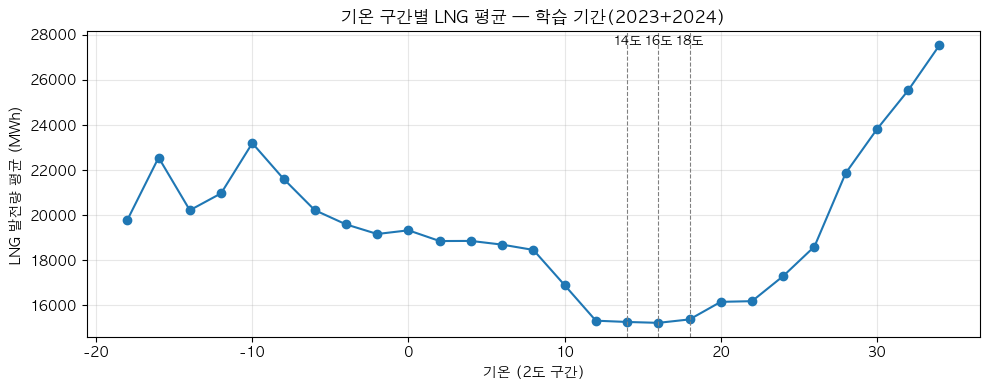

In [925]:
# 5단계 파생변수 · 1-나
구간 = (train.assign(구간=(train["ta"] // 2 * 2))                       # 기온을 2도 폭으로 내림해서 묶는다
        .groupby("구간")["lng_mwh"]
        .agg(시각수="size", 평균="mean").round(0))                       # 구간마다 시각 수와 LNG 평균

print("기온 2도 구간별 LNG 발전량 평균 — 학습 기간만. 평균이 가장 낮은 구간이 바닥이다")
display(구간)

plt.figure(figsize=(10, 4))
plt.plot(구간.index, 구간["평균"], marker="o")                           # 구간 평균을 선으로 잇는다
for 후보 in (14, 16, 18):                                              # 기준온도 후보를 세로선으로 표시
    plt.axvline(후보, ls="--", lw=.8, color="gray")
    plt.text(후보, 구간["평균"].max(), f"{후보}도", ha="center", fontsize=9)
plt.xlabel("기온 (2도 구간)"); plt.ylabel("LNG 발전량 평균 (MWh)")
plt.title("기온 구간별 LNG 평균 — 학습 기간(2023+2024)")
plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 해당 구간일 때 lng발전량이 가장 적은건 이해하겠고, 가장 적은건 16도인데, 14도 18도와 비슷하고, 오히려 날짜는 18도가 더 많단 말이지? 여기중 무엇으로 정해야 하지?? 그리고 근원적인 물음인데, 왜 가장 낮은 기간이 기준이 되는거야?? 이게 일종의 바닥 역할을 하고, 이 낮은 기준으로부터 차이를 바탕으로 무언가 결괏값이 그려진다는 것 자체가 기온에 영향을 받는다는 방증이라서 그런가?

### 클로드 답변

> **짧게**
> 1. 14·16·18도 구간의 평균 차이(39~152 MWh)는 구간 평균이 우연히 흔들리는 크기와 비슷해서, **이 표만으로는 셋 중 어느 것이 바닥인지 가릴 수 없습니다.** 바닥은 한 점이 아니라 12도부터 20도까지 거의 평평합니다.
> 2. 「날짜는 18도가 더 많단 말이지?」 — 날짜가 아니라 **시각** 수이고, 시각 수가 많다고 기준이 되지는 않습니다. 네 구간 다 천 시각 안팎이라 평균을 믿기에는 충분합니다.
> 3. 「왜 가장 낮은 기간이 기준이 되는거야??」 — 기준은 **기온이 LNG를 올리지 않는 온도**여야 하기 때문입니다. U자의 바닥이 그 온도입니다.

**맞게 읽으신 것**

- 「가장 적은건 16도인데, 14도 18도와 비슷하고」 — 맞습니다. 12도 구간 15,317 · 14도 15,260 · 16도 15,221 · 18도 15,373 MWh로 네 구간이 거의 같습니다.
- 「이 낮은 기준으로부터 차이를 바탕으로 무언가 결괏값이 그려진다」 — 맞습니다. 난방도·냉방도는 기준에서 떨어진 거리이고, 거리가 0인 곳에서는 기온이 LNG를 올리지 않는다고 보는 것입니다.

**「왜 가장 낮은 기간이 기준이 되는거야??」**

난방도와 냉방도는 「기준보다 추운 만큼」·「기준보다 더운 만큼」입니다. 이 두 열이 뜻을 가지려면 **기준온도에서는 기온이 LNG를 올리지 않고, 기준에서 멀어질수록 LNG가 올라야** 합니다. U자의 바닥이 그 온도입니다. 난방도 냉방도 필요 없는 날씨라 전기를 덜 쓰고, 그래서 LNG 발전도 가장 적습니다.

바닥이 아닌 곳을 기준으로 잡으면 열이 말하는 방향이 실제와 어긋납니다. 예를 들어 기준을 22도로 잡으면 16~22도 사이 시각의 난방도가 0~6이 됩니다. 「22도보다 추우니 LNG가 올라야 한다」고 적어 넣는 셈인데, 1-나 표에서는 22도 구간 16,183에서 16도 구간 15,221로 **내려갑니다.**

「기온에 영향을 받는다는 방증이라서 그런가?」는 조금 다릅니다. 기온이 LNG를 움직인다는 증거는 U자 모양 자체이고, 바닥은 그 영향이 0이 되는 온도라서 기준이 됩니다.

**「여기중 무엇으로 정해야 하지??」 — 이 표만으로는 못 정합니다**

구간 평균은 그 구간에 들어온 시각들의 평균이라, 다른 시각들이 들어왔다면 조금 다르게 나왔을 것입니다. 그 흔들림의 크기가 **표준오차**이고, 「표준편차 ÷ √시각 수」로 계산합니다. 학습 기간에서 실제로 계산하면 이렇습니다.

| 구간 | 시각 수 | LNG 평균 | 표준편차 | 평균의 표준오차 |
|---|---|---|---|---|
| 12~14도 | 913 | 15,317 | 4,202 | 139 |
| 14~16도 | 959 | 15,260 | 4,090 | 132 |
| 16~18도 | 988 | 15,221 | 3,990 | 127 |
| 18~20도 | 1,106 | 15,373 | 4,086 | 123 |

14도와 16도 구간의 차이는 39, 16도와 18도의 차이는 152입니다. 두 평균의 차이가 우연히 흔들리는 크기는 약 180이라서, 이 차이들은 우연으로도 충분히 생길 수 있는 크기입니다. 게다가 이어진 시각들은 서로 비슷한 값을 가지므로(같은 날의 1시와 2시처럼) 실제 흔들림은 표보다 더 큽니다. **그러니 「16도가 가장 낮다」는 이 표에서 확실한 말이 아니고, 12도부터 20도까지가 거의 평평한 바닥이라고 읽는 것이 맞습니다.** 한 점을 고르려면 다른 방법이 필요하고, 그것을 1-라에서 봅니다.

「오히려 날짜는 18도가 더 많단 말이지?」 — 표의 「시각수」는 날짜가 아니라 한 시간 단위의 시각 수입니다. 18도 구간이 1,106시각으로 조금 많은 것은 그 온도가 자주 나타났다는 뜻일 뿐, 기준을 고르는 근거는 아닙니다. 시각 수가 문제가 되는 것은 1-나 표 맨 위(−18도·−16도 구간 15시각)처럼 수십 개 아래로 떨어질 때입니다.

**📘 빅분기 과목 연결**

- **2과목 기초통계 — 표준오차.** 표본에서 낸 평균이 얼마나 흔들리는지를 나타냅니다. 표준편차 ÷ √n이라서, 표본이 4배가 되면 흔들림은 절반이 됩니다.
- **2과목 기초통계 — 신뢰구간.** 평균 ± 약 2 × 표준오차가 95% 신뢰구간입니다. 14·16·18도 구간의 신뢰구간은 서로 겹칩니다. 두 평균의 차이를 검정할 때는 독립표본 t검정을 쓰고, 셋 이상이면 분산분석(ANOVA)을 씁니다. 물음 5에서 공휴일을 볼 때 이 방법을 씁니다.
- **3과목 시계열 분석 — 자기상관.** 이어진 시각처럼 시간 순서로 붙은 값은 서로 비슷해서, 표준오차 공식이 가정하는 「표본끼리 독립」이 깨집니다. 그러면 실제 흔들림이 공식으로 낸 값보다 큽니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 가장 낮은 값이 기준이 되어서, 그 이후 온도 차이에 따라서 변화가 일어나기에, 그 값이 기준이 된다는건 이제 이해했어.

- 오키 그래 이렇게 다 바닥에 깔려 있으니 앞에서 배웠던 것을 떠올리면, 특정한 값들을 고정시키고 비교시켰던 거 같은데..? 너가 1-라에서 해당하는 방법으로 했는지, 아니면 다른 방식을 썼는지 내가 살펴봐야겠다.

- 아 시각수구나. 나는 왜 날짜라고 착각했구나. 그런데 어쨌든 시각수가 많으면 편차가 안정화될 수 있으니까, 나는 평균이 어차피 거의 다 낮다면 가장 안정적인 값으로 가져다줄 온도, 시간이 적합하다고 판단했기에 그렇게 적은거야.

- 평균 차이를 검정할 때는 그래, 독립 표본t, 셋 이상이면 anova를 쓰는거지. 그런데 여기서 그러면 평균 차이라는건 lng라는 y에 해당하는 것이겠지? 지금 x온도에 해당하는 y값의 평균을 수치화한 값이니까??


### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 1-라는 다른 값을 고정하지 않았습니다. 기온에서 만든 열만 넣었습니다. **시간대와 월을 고정하고 다시 본 것을 1-마로 만들었습니다.**
> 2. 「시각수가 많으면 편차가 안정화될 수 있으니까… 가장 안정적인 값」 — 생각은 맞습니다. 다만 네 구간 다 천 시각 안팎이라 이미 충분히 안정적이어서, 시각 수로는 기준이 갈리지 않습니다.
> 3. 평균 차이를 검정할 때 비교하는 평균은 **y(LNG)의 평균**이 맞습니다. 기온 구간(x)으로 무리를 나누고, 무리마다 LNG의 평균을 냅니다.

**「특정한 값들을 고정시키고 비교시켰던 거 같은데..? 너가 1-라에서 해당하는 방법으로 했는지」**

1-라는 고정하지 않았습니다. 기온에서 만든 열만 넣고 LNG에 직선을 맞췄습니다. 그래서 1-라의 R²에는 기온의 효과와, 기온과 같이 움직이는 시간대·달의 효과가 섞여 있습니다 — 28도 넘는 시각은 71%가 오전 11시~오후 6시이고, 8도 아래 시각은 98%가 11~3월입니다(1-다 답변).

기억하신 방법은 4단계 2-나입니다. 그때는 10~15시·기온 15~25도로 **범위를 묶어서** 조건을 맞춘 뒤 비교했습니다. 회귀에서는 같은 일을 **시간대와 월을 열로 같이 넣어서** 합니다. 다중회귀의 기울기는 「다른 열은 그대로 두고 그 열만 바뀔 때의 효과」라서, 같이 넣기만 하면 모델이 같은 시간대·같은 달끼리 비교한 것과 같은 효과를 냅니다. 1-마가 이것입니다.

**「시각수가 많으면 편차가 안정화될 수 있으니까… 가장 안정적인 값으로 가져다줄 온도」**

생각은 맞습니다. 표본이 많을수록 평균이 덜 흔들립니다(표준오차 = 표준편차 ÷ √시각 수). 다만 제 답변의 표에서 표준오차가 139·132·127·123으로 이미 작고 서로 비슷합니다. 18도 구간이 시각이 가장 많아서 가장 안정적인 것은 맞지만, 127과 123의 차이는 기준을 가를 만한 크기가 아닙니다. 기준을 가르는 것은 1-라·1-마처럼 **그 기준으로 만든 열이 LNG를 얼마나 설명하느냐**입니다.

**「평균 차이라는건 lng라는 y에 해당하는 것이겠지?」**

맞습니다. t검정·분산분석에서 x는 무리를 나누는 기준(여기서는 기온 구간)이고, 비교하는 평균은 y(LNG)의 평균입니다. 「14도 구간의 LNG 평균과 16도 구간의 LNG 평균이 다른가」를 묻는 것입니다. 물음 5에서 공휴일을 볼 때도 같습니다 — x는 평일·주말·공휴일, y는 LNG입니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 다른 변수를 같이 넣어 고정하기.** 관심 있는 변수(기온)의 효과를 보려고 같이 넣는 변수(시간대·월)를 통제변수라고 합니다. 회귀계수가 「다른 변수를 고정했을 때의 효과」라서 같이 넣는 것만으로 고정이 됩니다.
- **3과목 회귀분석 — 더미 변수.** 시간대(0~23시)나 월(1~12월)처럼 숫자로 적혀 있어도 크기에 뜻이 없는 값은 「몇 시인가」를 0/1 열 여러 개로 바꿔 넣습니다. 한 범주는 기준으로 빼고 넣습니다(24시간이면 23열, 12달이면 11열). 숫자 그대로 넣으면 「1시간 늦어질 때마다 LNG가 같은 만큼 오른다」는 직선 하나로 배우게 되어, 새벽에 낮고 저녁에 높은 모양을 그리지 못합니다.
- **2과목 통계검정 — t검정과 분산분석.** x는 범주형(무리), y는 연속형입니다. 두 무리면 독립표본 t검정, 셋 이상이면 분산분석(ANOVA)입니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답: 기온의 변화에 따라 기온과 같이 움직이는 시간대, 달의 효과마 섞여 있다는게 기온과 그 날짜에서 나오는 lng발전량 이렇게만 비교하기 위해서 이렇게 좁혀서 본거지??

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 목적은 맞습니다 — **기온과 LNG만의 관계를 보려는 것**입니다. 다만 1-마는 행을 골라내서 좁힌 것이 아니라, 16,776시각을 다 쓰면서 시간대·월을 열로 같이 넣어 그 효과를 떼어 낸 것입니다.

**「기온과 그 날짜에서 나오는 lng발전량 이렇게만 비교하기 위해서 이렇게 좁혀서 본거지??」**

목적은 맞고, 방법이 4단계 2-나와 다릅니다.

- **4단계 2-나 — 행을 골라내서 좁혔습니다.** 10~15시이면서 기온 15~25도인 시각만 남기고 나머지는 뺐습니다. 조건이 같은 시각끼리만 비교하니 이해하기 쉽지만, 뺀 시각만큼 재료가 줄고 남긴 범위 밖은 말할 수 없습니다.
- **5단계 1-마 — 행을 빼지 않고 열로 넣었습니다.** 16,776시각을 모두 쓰고, 시간대와 월을 기온 열과 함께 회귀에 넣었습니다. 회귀의 기울기는 「다른 열은 그대로 두고 그 열만 바뀔 때의 효과」라서, 시간대와 월 때문에 생긴 차이는 그 열들이 가져가고 남은 것이 기온 열에 갑니다.

1-마 맨 아래 줄 「기온 열 없이 시간대·월만 넣었을 때 R² 0.432」가 이것을 보여 줍니다. 시간대와 월만으로 LNG 흔들림의 43.2%가 설명되고, 기온 두 열을 더하면 48~50%가 됩니다. 기온이 따로 더하는 것은 5~7%p입니다. 1-라에서 기온만으로 본 R²(0.1대)에는 시간대·월의 효과가 섞여 있었습니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 다른 변수의 영향을 떼어 내는 두 방법.** 조건이 같은 것끼리 골라서 보는 방법(층화)과, 회귀에 같이 넣는 방법이 있습니다. 층화는 이해하기 쉽지만 표본이 줄고, 회귀에 넣는 방법은 표본을 다 쓰는 대신 「효과가 서로 더해진다」는 가정을 둡니다.

## 1-다

**어디서 나온 셀인가.** ⓑ와 ⓒ의 차이는 「추운 쪽과 더운 쪽의 기울기가 같은가」 하나입니다. 같으면 ⓑ 한 열로 충분하고, 다르면 ⓒ로 갈라야 합니다. 1-가의 상관 숫자만으로는 이것이 안 보입니다.

**무엇을 보는 셀인가.** 4단계에서 상관이 가장 컸던 16도를 기준으로 삼아, 가로축에 「기준에서 몇 도 떨어졌나」를 두고 추운 쪽과 더운 쪽을 선 둘로 나란히 그립니다. 두 선이 겹쳐 가면 ⓑ, 갈라지면 ⓒ입니다. 기준온도를 바꿔 보시려면 셀 안 `기준 = 16`의 숫자만 고쳐서 다시 돌리시면 됩니다.

표에서 한쪽이 빈 칸(NaN)인 줄은 그 방향으로 그만큼 떨어진 시각이 학습 기간에 없었다는 뜻입니다.

기준 16도에서 떨어진 정도별 LNG 평균 — 두 선의 기울기가 같은가


쪽,더운 쪽,추운 쪽
구간,,
0.0,15221.0,15238.0
2.0,15373.0,15299.0
4.0,16153.0,16827.0
6.0,16183.0,18415.0
8.0,17298.0,18766.0
10.0,18609.0,18727.0
12.0,21866.0,18916.0
14.0,23813.0,19345.0
16.0,25538.0,19088.0


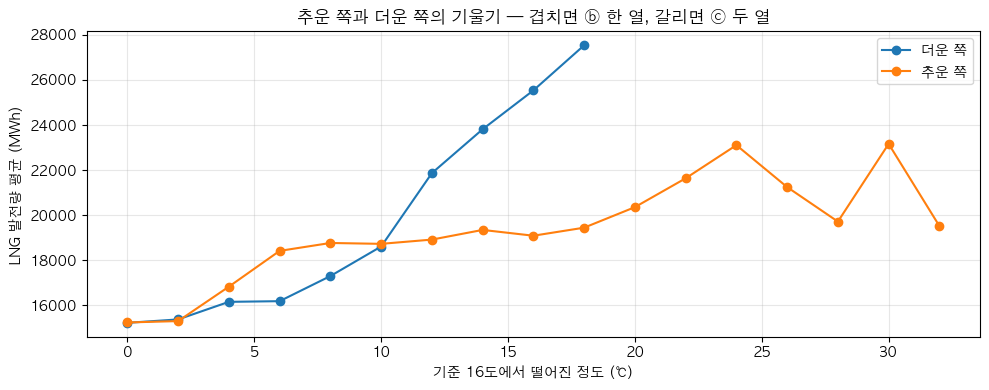

In [926]:
# 5단계 파생변수 · 1-다
기준 = 16                                                             # 4단계에서 상관이 가장 컸던 온도. 바꿔 보셔도 된다
d = train.assign(떨어진=(train["ta"] - 기준).abs(),                     # 기준에서 떨어진 거리
                 쪽=np.where(train["ta"] < 기준, "추운 쪽", "더운 쪽"))   # 기준보다 낮으면 추운 쪽
양쪽 = (d.assign(구간=(d["떨어진"] // 2 * 2))                            # 떨어진 거리를 2도 폭으로 묶는다
        .groupby(["구간", "쪽"])["lng_mwh"].mean()
        .unstack("쪽").round(0))                                       # 추운 쪽과 더운 쪽을 열 둘로 펼친다

print(f"기준 {기준}도에서 떨어진 정도별 LNG 평균 — 두 선의 기울기가 같은가")
display(양쪽)

plt.figure(figsize=(10, 4))
for 쪽 in 양쪽.columns:
    plt.plot(양쪽.index, 양쪽[쪽], marker="o", label=쪽)                # 쪽마다 선 하나
plt.xlabel(f"기준 {기준}도에서 떨어진 정도 (℃)"); plt.ylabel("LNG 발전량 평균 (MWh)")
plt.title("추운 쪽과 더운 쪽의 기울기 — 겹치면 ⓑ 한 열, 갈리면 ⓒ 두 열")
plt.legend(); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 아! 1-나에서 왜 그냥 b로 나누지 않고 c로 나누어야 하는지 1-가에서부터 흐름을 쭉 따르다보니 알겠다. 일단 나는 위에서 14,16,18도 중 무엇을 기준으로 삼아야할지 모른다고 했는데, 일단 너가 그려준 그래프에서는 16을 기준으로 했구나. 좋아. 그러면 보자고. 확실히 b방식, 그러니까 단순히 기온을 기준으로 나누어서 하는 방식은 양쪽의 다른 기울기를 대변하지 못해. 따라서, 특정한 기준 온도를 컬럼으로 두고 양쪽으로 나누어서 모델링을 하는게 더 적합하다는 판단이 들어. 수치로 보지 않고, 그래프만 보더라도, 더 더울수록 그래프가 가팔라지는데, 특히 10도 이상, 즉 26도를 넘어설 때부터 급격히 기울기가 커지고 있다는 점을 알 수 있어.

- 추울때는 완만하게 그리는데, 16도를 기준으로 보면 약 x값이 16일때 기온은 0도가 나올건데, 좌우를 살펴도 즉, 온도 범위로 보면 6도에서 -4도 정도까지 봐도 크게 lng발전에 차이가 없다는 것을 알 수 있어. 맨 마지막에 그래프가 요동치는건 아마 데이터해석? 2단계에서 봤던거 같은데 이쪽에는 데이터 숫자 자체가 적어서, 아마 찍힌 값 자체가 적어서 매끈하게 어떤 연결성의 모습은 보여주지 못한다고 해석했던 것 같다.


#### ① 1-가·1-나·1-다를 다 보시고, 기온을 ⓐ 그대로 · ⓑ 기준온도에서 떨어진 정도 한 열 · ⓒ 난방도와 냉방도 두 열 중 어느 모양이 유력해 보이십니까? 왜 그렇게 보십니까?

답: 그러면 일단 내가 명확하게는 모르겠지만, 즉 몇 도를 기준으로 나누어야 할지는 고민이 되지만, 확실한 것은 단순히 b방식으로 나누는 것보다는 냉방도, 난방도를 기준으로 차이가 극명하기에 다른 함수?모델? 수리학적 도구를 사용해야 할 것 같아. 그래야 실제를 더 잘 대변할 수 있으니까. b로 하면 기준으로 +10 이나 -10이나 동일하게 뭉뚱그려 버리기 때문에 이런 방식은 사용해선 안되겠지. 그런데 위에 적은 것처럼 다중회귀로 하는 것과는 또 다른가? 내가 어떤 모델이 적합한 방식인지는 잘 몰라가지고 이 부분에서는 방향을 잘 모르겠네..?

#### ② ⓑ나 ⓒ라면 기준온도를 몇 도로 두시겠습니까?

- ⓐ를 고르시면 비워 두셔도 됩니다.

답: 14,16,18?? 가장 낮은건 아마 16이었던 거 같은데 16이 날짜 자체가 적은데..? 기준이라면 그냥 가장 낮은 값만 기준으로 보면 될까??

#### ③ 원래 기온 열(`ta`)도 같이 남겨 둘까요, 바꾼 모양만 둘까요?

- 물음 1 머리 칸에 적은 대로, 트리 계열은 기온을 그대로 받아도 추운 쪽과 더운 쪽을 스스로 가르고 선형회귀는 못 가릅니다. 어느 모델을 쓸지는 6단계에서 정합니다.

답: 이거는 그러면 위에서 어떤 방식으로 기온을 쓸지에 따라서, 그리고 만약 여기서 어떤 방향인지 못정했다면, 두 가지를 다 가져가서 모델링 한다음에 25년도에 적용해서 실험할 때 유사도가 높은 방식을 쓰면 되는거 아닌가??

### 클로드 답변

> **짧게**
> 1. ①번 — **ⓒ를 고르신 것과 그 이유(ⓑ는 +10과 −10을 같은 값으로 뭉뚱그린다)가 맞습니다.** 더운 쪽이 26도를 넘으며 가팔라지고, 추운 쪽은 6도 아래로 완만하다고 읽으신 것도 표 숫자와 맞습니다.
> 2. 「다중회귀로 하는 것과는 또 다른가?」 — 다르지 않습니다. **ⓒ로 만든 두 열을 다중회귀에 넣는 것**이 두 기울기를 담는 방법입니다(1-가 답변).
> 3. ③번 — 둘 다 만들어 두는 것은 맞습니다. 다만 **2025년 성적으로 고르면 2025년이 채점 역할을 못 하게 됩니다.** 고르는 것은 2023·2024년 안에서 합니다.

**맞게 읽으신 것**

- 「b방식… 은 양쪽의 다른 기울기를 대변하지 못해」 — 맞습니다. 기준 16도에서 10도 떨어졌을 때는 추운 쪽 18,727, 더운 쪽 18,609로 비슷한데, 16도 떨어지면 추운 쪽 19,088, 더운 쪽 25,538로 6천 넘게 벌어집니다. ⓑ 한 열로는 이 차이를 담지 못합니다.
- 「특히 10도 이상, 즉 26도를 넘어설 때부터 급격히 기울기가 커지고 있다」 — 맞습니다. 가장 크게 뛰는 것은 26~28도에서 28~30도로 넘어갈 때(18,609 → 21,866, +3,257)입니다. 그 전에도 22도부터 2도마다 1,100~1,300씩 오르기 시작하고, 16~22도 사이에서는 2도마다 30~780이었습니다.
- 「6도에서 -4도 정도까지 봐도 크게 lng발전에 차이가 없다」 — 맞습니다. 6~8도 18,766에서 −4~−2도 19,445로, 기온이 10도 내려가는 동안 700쯤 오릅니다.
- 「맨 마지막에 그래프가 요동치는건… 데이터 숫자 자체가 적어서」 — 맞습니다. 1-나 표에서 −10도 아래 구간은 시각이 103·78·42·15·15개입니다. 4단계에서 서울 108의 −12도 이하 시각이 2023년 64시간, 2024년 10시간뿐인 것을 확인했고, 11단계(결론과 한계를 적는 단계)의 한계에 적기로 했습니다.

**짚을 것**

**「특정한 기준 온도를 컬럼으로 두고」** — 기준온도는 열(컬럼)이 되지 않습니다. 기준온도는 난방도·냉방도를 계산할 때 쓰는 숫자 하나(예: 16)이고, 열이 되는 것은 그 숫자로 계산한 난방도와 냉방도 두 개입니다.

**추운 쪽도 한 직선은 아닙니다.** 읽으신 대로 6도 아래로는 완만한데, 그 위는 가파릅니다. 기준에서 0~2도 떨어진 구간(14~16도) 15,238에서 8~10도 떨어진 구간(6~8도) 18,766으로 3,500쯤 오르고, 그 뒤 −4~−2도까지는 700쯤 오릅니다. ⓒ의 난방도는 이것을 기울기 하나로 줄여서 보는 것이라, 선형회귀를 쓰면 이 꺾임만큼은 못 맞힙니다. 트리 계열은 이런 꺾임을 스스로 나눠 배웁니다.

**이 그래프에는 달과 시간대가 섞여 있습니다.** 학습 기간에서 8도 미만인 시각은 98%가 11~3월이고, 12~20도인 시각은 69%가 4·5·10월이며, 28도 이상인 시각은 59%가 7·8월, 71%가 오전 11시~오후 6시입니다(실측). 그런데 LNG는 달마다도 다릅니다 — 학습 기간 시간 평균으로 1월 20,642, 10월 15,225 MWh입니다(실측). 그러니 가팔라지는 정도와 꺾이는 지점에는 기온의 영향과 달·시간대의 영향이 같이 들어 있습니다(판단). 물음 1 머리 칸에 적은 한계가 이것이고, 시간대를 고정해서 보는 것은 물음 4에서 합니다.

**다만 ⓒ를 고르신 판단은 이것과 상관없이 유지됩니다.** ⓒ는 ⓑ를 포함하는 모양이기 때문입니다. ⓑ의 「떨어진 정도」는 난방도 + 냉방도와 같아서, ⓒ에서 두 기울기가 같아지면 그대로 ⓑ가 됩니다. 그러니 두 기울기가 같다면 ⓒ가 ⓑ만큼 맞고, 다르다면 ⓒ가 더 맞습니다. 열이 하나 더 드는 대가는 학습 16,776시각에 비하면 작습니다.

**②·③ 칸에 적으신 것**

**② 기준온도** — 「기준이라면 그냥 가장 낮은 값만 기준으로 보면 될까??」라고 적으셨습니다. 1-나 답변에 적은 대로 바닥이 12~20도에 걸쳐 평평해서 가장 낮은 구간 하나로는 못 정합니다. 1-라를 보고 1-라 아래 칸에서 다시 정하시면 됩니다.

**③ 원래 기온 열** — 「두 가지를 다 가져가서 모델링 한다음에 25년도에 적용해서 실험할 때 유사도가 높은 방식을 쓰면 되는거 아닌가??」 — 여러 방식을 만들어 보고 성적이 좋은 쪽을 고르는 것 자체는 맞는 방법이고 늘 합니다. 문제는 **고르는 데 쓴 해로 채점까지 하는 것**입니다. 2025년 성적을 보고 고르면, 고른 방식은 「2025년에 잘 맞는 방식」이 되고, 그 방식의 2025년 오차는 처음 보는 해에서 나올 오차보다 좋게 나옵니다. 그러면 2025년이 「평소 해에 이만큼 틀린다」를 말해 주지 못하고, 9단계(2026년이 평소와 얼마나 달랐는지 보는 단계)에서 2026년의 차이를 판단할 기준이 흔들립니다. 4단계 닫는 칸의 6단계 물음 4(「2025년을 언제부터 안 볼까」)가 이 이야기입니다.

그래서 보통은 학습 기간 안에서 한 번 더 나눕니다. 예를 들어 2023년으로 배우고 2024년으로 성적을 본 뒤(검증), 고른 방식으로 2023+2024년 전체를 다시 배우고, 2025년은 마지막에 한 번만 채점에 씁니다. 어떻게 나눌지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다. **5단계에서는 기온 그대로(`ta`)와 난방도·냉방도를 둘 다 열로 만들어 두는 것까지** 하면 됩니다.

**📘 빅분기 과목 연결**

- **4과목 데이터 분할 — 학습·검증·평가.** 학습(train)으로 배우고, 검증(validation)으로 후보 중에 고르고, 평가(test)는 마지막에 한 번만 씁니다. 평가 데이터로 고르면 그 성적은 실제보다 좋게 나옵니다.
- **4과목 데이터 누수.** 모델을 만들고 고르는 과정에 평가 데이터의 정보가 들어가는 것입니다. 여기서는 2025년이 평가 데이터입니다.
- **4과목 시계열 교차검증.** 시간 순서가 있는 데이터는 무작위로 섞어 나누지 않고, 앞 기간으로 배우고 뒤 기간으로 검증합니다(2023 → 2024처럼).
- **3과목 의사결정나무.** 트리는 「기온이 26도보다 높은가」 같은 질문으로 데이터를 나눠서, 가팔라지는 지점과 꺾이는 지점을 스스로 찾습니다. 그래서 트리에는 기온을 그대로 넣어도 됩니다.
- **2과목 교란.** 두 값이 같이 움직일 때 제3의 것(여기서는 달과 시간대)이 둘을 함께 움직이는 경우입니다. 4단계에서 본 허위상관과 같은 이야기입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:

- 특정 온도를 기준으로 컬럼 둔다는건.. 어 기준 온도를 정한다는 의미야. 그 기준을 정하는게, 냉방도,난방도 두개를 기준으로 나누었잖어? 그래프를 보면 뭐 예컨대 냉방도의 기준으로 26도까지, 그리고 26도 이상부터 또 다른 직선의 기울기를 보인단 말이지?? 그러면 또 세분화할 수 있는거 아닌가?? 일종의 교호작용인거지? 예컨대 16도를 기준으로 했다고 해보면, 26도까지를 냉방도라 봤는데, 뭐 특정한 상황 26도가 넘으면 모델에 그 가중치를 더 곱해주는 컬럼이나 뭐 값을 넣을 수 있지 않을까?? 과한가? 그래도 온도에 따라 기준이 명확하니까 오히려 이걸 냉방도로 뭉뚱그리는 것보다 더 세밀하게 나눌 수도 있을 것 같은데..??

- 그래 너가 적은 것처럼 추운 쪽도 한 직선은 아니지. 그러면 이게 드라마틱 한 구간에는 다른 함수를 적용할 수도 있지 않을까 싶기도 해. 아! 트리는 이런 꺾임을 스스로 배우는구나.. 어렵지만 모델링이 다양한건 역시 이유가 있는 것이겠지..? 알아서 학습한다면 따로 막 가중치나 위에 적은것처럼 교호 작용을 고려하지 않거나 혹은 두 가지를 따로 한 다음에 더 적합하게 설명해주는 방식을 채택하는 방향으로 나아가야하지 않을까 싶은데..?

- 맞어 c는 결국 b를 포괄하지. 맞어 예컨대 기준을 기준으로 좌우가 데칼코마니의 y를 그린다면 b로 통합해도 되겠지. 하지만 이미 그래프에서 봤던 것처럼 다르기에 우리는 c방향으로 나아가는게 맞을 것 같어. 틀린 의견이라고 판단하면 얼마든지 의견과 비판을 제시해줘.

- 그렇구나, 만약 25년도를 가지고 와서 23,24년도를 끌어오면 그건 앞서 말한 것처럼 데이터 누수에 해당하겠네?? 그러면 지금 예컨대 모델링을 학습시키는 년도가 적잖어?? 이럴 경우 뭐 내가 데이터를 배운 방법에 따르면 오버샘플링 하거나, fold 방식을 바꾸거나, 뭐 하는 방식으로 학습을 최대한 끌어내는 방법을 사용한다고 배웠는데 이런 것들 중에선 뭐가 현재 데이터에서 적합한건지 판단할 수 있을까??

- 너가 마지막에 적은 것 ta와 난방도 냉방도를 나눈다는건 결국 c를 하겠다는거네? 그러면 위에 좀 더 세부적으로 어떤 방식으로 갈지, 즉 나누고, 내 아이디어 처럼 모델들을 비교하는건 결국 6단계에서 진행할 수 있는건가??


### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「26도가 넘으면… 더 세밀하게 나눌 수도」 — 할 수 있고, 이름은 교호작용이 아니라 **한 변수를 구간으로 더 나누는 것**입니다. 다만 냉방 쪽 기준을 올리면 상당 부분이 잡히고(1-마) 트리는 스스로 하므로, **지금 열을 더 만들지 않고 7단계에서 볼 것으로 적어 두는 쪽을 권합니다.**
> 2. 「학습 연도가 적은데 오버샘플링·fold를 바꾸는 방법은?」 — 오버샘플링은 이 데이터에 맞지 않습니다. 검증은 **시간 순서대로 나누고, 학습 쪽에 한 해가 통째로 들어가게** 합니다. 약점은 행 수가 아니라 **계절을 두 번밖에 못 봤다**는 것이고, 이건 방법으로 메울 수 없어 한계에 적습니다.
> 3. 「모델들을 비교하는건 결국 6단계에서?」 — 무엇을 비교할지는 6단계에서 정하고, 실제로 돌려서 비교하는 것은 7단계입니다. 5단계에서는 열을 만들어 두는 데까지입니다.

**「26도가 넘으면 모델에 그 가중치를 더 곱해주는 컬럼… 일종의 교호작용인거지? 과한가?」**

생각은 맞고 방법도 있습니다. 「26도보다 더운 만큼」이라는 열을 하나 더 만들면(26도 아래는 0), 선형회귀가 26도 위에서 기울기를 하나 더 얹어 배웁니다. 그러면 기준~26도에서는 냉방도 기울기만, 26도 위에서는 두 기울기를 더한 만큼 가파르게 오르는 선이 됩니다. 말씀하신 「26도가 넘으면 가중치를 더 곱해주는 컬럼」이 이것입니다.

다만 이름은 교호작용이 아닙니다. 교호작용은 **서로 다른 두 변수**가 서로의 효과를 바꾸는 것입니다. 같은 30도라도 낮 2시와 새벽 3시에 LNG가 오르는 정도가 다르다면, 그것이 기온과 시간대의 교호작용입니다(물음 4에서 봅니다). 기온 하나를 꺾이는 점 여러 개로 나누는 것은 **구간별 선형**이라고 부릅니다. 난방도·냉방도가 꺾이는 점이 하나(기준온도)인 경우이고, 26도에 하나를 더 두면 꺾이는 점이 둘이 됩니다.

과한지는 이렇게 판단합니다.

- 1-마에서 냉방도 기준을 16도보다 위로 옮겨 보면, 26도 위의 가파른 부분을 냉방도 한 열이 상당 부분 맡습니다. 1-라에서 ⓒ가 22도에서 가장 컸던 이유가 이것입니다.
- 트리 계열은 꺾이는 점을 스스로 찾으므로 이 열이 필요 없습니다.
- 그러니 이 열이 뜻이 있는 것은 선형회귀를 쓸 때뿐이고, 도움이 되는지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 넣은 것과 뺀 것을 같은 표에 놓고 보면 됩니다. **지금 만들지 않고 닫는 칸 ③에 「7단계에서 볼 것」으로 적어 두겠습니다.** 지금 만들어 두고 싶으시면 말씀해 주세요.

**「드라마틱한 구간에는 다른 함수를 적용할 수도 있지 않을까」 · 「두 가지를 따로 한 다음에 더 적합하게 설명해주는 방식을 채택하는 방향」**

방향이 맞습니다. 선형회귀에 열을 손으로 더 만들어 넣는 방법이 있고, 트리처럼 스스로 나누는 모델을 쓰는 방법이 있습니다. 둘을 다 돌려서 같은 표에 놓고 고르는 것이 7단계에서 하는 일입니다(기준선 → 선형회귀 → 트리 계열 순서). 어떤 모델을 후보로 올릴지는 6단계에서 정합니다.

**「c는 결국 b를 포괄하지… 틀린 의견이라고 판단하면 얼마든지 의견과 비판을 제시해줘」**

결론(ⓒ로 간다)은 맞습니다. 근거에서 하나 짚겠습니다. 「그래프에서 봤던 것처럼 다르기에」라고 하셨는데, 1-다 그래프는 달과 시간대가 섞인 모양이라서 좌우가 다른 것이 모두 기온 때문이라고는 말할 수 없습니다(제 답변의 「이 그래프에는 달과 시간대가 섞여 있습니다」). 1-마에서 시간대와 월을 고정하고 보시면, 좌우 차이가 기온만으로도 남는지 확인하실 수 있습니다. 다만 어느 쪽으로 나와도 결론은 안 바뀝니다 — ⓒ는 ⓑ를 포함하므로, 좌우가 같게 나오더라도 ⓒ가 ⓑ보다 못해지지 않습니다.

**「모델링을 학습시키는 년도가 적잖어?? … 오버샘플링 하거나, fold 방식을 바꾸거나… 뭐가 현재 데이터에서 적합한건지」**

- **오버샘플링은 맞지 않습니다.** 분류에서 한쪽 범주가 너무 적을 때(불량이 1%뿐일 때처럼) 그 범주의 행을 늘리는 방법입니다. 우리는 숫자를 맞히는 회귀라 치우친 범주가 없고, 행을 복사해 늘려도 새로운 정보가 생기지 않습니다. 이 프로젝트를 시작할 때 「불균형 처리는 하지 않는다(회귀라서)」로 빼 둔 것이 이 이유입니다.
- **검증은 시간 순서대로 나누고, 학습 쪽에 한 해가 통째로 들어가게 합니다.** 무작위로 섞어서 k개로 나누면 바로 옆 시각이 학습과 검증에 나뉘어 들어가는데, 이어진 시각끼리는 값이 비슷해서 성적이 실제보다 좋게 나옵니다. 그리고 계절이 뚜렷한 데이터라서 1~6월로 배우고 7~9월을 맞히면 여름을 한 번도 못 본 채로 여름을 맞히게 됩니다. 그래서 예를 들면 2023년 한 해로 배우고 2024년으로 검증합니다. 어떻게 나눌지는 6단계에서 정합니다.
- **진짜 약점은 행 수가 아니라 계절을 두 번밖에 못 봤다는 것입니다.** 학습 16,776시각은 입력 열 수에 비해 충분합니다. 그런데 겨울과 여름을 두 번씩만 봤습니다. 이건 오버샘플링이나 fold로 메울 수 없고, 이 프로젝트에서는 「데이터를 늘려 풀지 않고 한계에 적는다」로 정해 두었습니다. 11단계(결론과 한계를 적는 단계)의 한계에 들어갑니다.

**「ta와 난방도 냉방도를 나눈다는건 결국 c를 하겠다는거네? … 모델들을 비교하는건 결국 6단계에서 진행할 수 있는건가??」**

맞습니다. 단계별로 나누면 이렇습니다.

- **5단계**(있는 열로 새 열을 만드는 단계): 기온 그대로(`ta`)와 난방도·냉방도를 열로 만들어 둡니다. 기준온도를 몇 도로 할지도 여기서 정합니다(1-마 아래 칸).
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계): 어떤 모델을 후보로 올릴지, 어느 열을 어느 모델에 넣을지, 검증을 어떻게 나눌지를 정합니다.
- **7단계**(모델을 만들고 기준선과 비교하는 단계): 실제로 돌려서 같은 표에 놓고 비교합니다.

**「그렇구나, 만약 25년도를 가지고 와서 23,24년도를 끌어오면 그건 앞서 말한 것처럼 데이터 누수에 해당하겠네??」** *(09-29, 5단계를 닫기 전 노트북 전체를 세다가 답이 빠진 것을 찾아 덧붙였습니다)*

맞습니다. 채점에 쓸 2025년의 정보가 2023·2024년으로 모델을 만들거나 고르는 쪽으로 들어가는 것이 데이터 누수입니다. 그러면 2025년 채점 점수가 실제보다 좋게 나옵니다. 4단계 개념 표 「데이터 누수」 줄에 09-22에 고쳐 쓰신 「2025년의 검증하려는 데이터가 23·24년 우리 모델링할 때 흘러드는게 누수인건가?」와 같은 뜻입니다. 그래서 이 프로젝트는 후보를 2023년으로 배워 2024년을 맞혀 보며 고르고, 고른 모델은 2023·2024년으로 배워 2025년에 한 번만 채점합니다(3-다 「다시 읽고 나서」 답변 2).

**📘 빅분기 과목 연결**

- **4과목 모형 평가 — 시계열 교차검증.** 시간 순서를 지켜서 앞 구간으로 학습하고 바로 뒤 구간으로 검증합니다. 무작위 k-fold를 쓰면 미래의 정보가 학습에 섞입니다.
- **2과목 데이터 전처리 — 불균형 데이터.** 오버샘플링(SMOTE 등)·언더샘플링은 분류 문제에서 범주 비율이 크게 치우쳤을 때 씁니다. 회귀에는 해당하지 않습니다.
- **3과목 회귀분석 — 교호작용 항.** 두 변수를 곱한 열(예: 기온 × 낮 시간인지)을 넣어서, 한 변수의 효과가 다른 변수에 따라 달라지는 것을 담습니다. 한 변수를 구간으로 나누는 것과는 다릅니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답: 그러면 교호작용의 개념은 여러 변수가 하나의 y값에 주는 영향인건가? 그러면 지금 이 그래프가 꺾이는 데 설명하는 적합한 개념이 아니고, 이렇게 나누는건 결국 너가 말한 것처럼 한 변수를 구간으로 더 나누는 것이네. 대신 가중치를 곱해주는 컬럼을 추가하면 이 곡선의 변화를 조금 더 잘 예측할 수 있겠다.

- 그러면 결국 7단계에서 어떤 모델이 적합한지 알려면, 지금 데이터를 나누는 방식도 달라야하는거 아닌가?? c방식으로 가는건 알겠는데. 이 방식도 있을 거고, c방식에서 냉방을 기준으로 새로운 뭐 가중치를 곱한 방식도 있고 -> 이 두개는 회귀 방식인건가?? 아니면 c방식으로 나누었을 때 트리 방식을 썼을 수도 있고.. 아니면 아예 뭐 b를 썼다면 b방식의 경우에 뭐 특정한 모델을 쓰는 등 결국 연속형 변수 y를 측정했고 그것을 가장 잘 설명하는 수학적인 데이터, 수치를 통해, 최적의 방식을 알 수 있는거 아닌가?? 그러면 궁금한게, 그냥 이게 나는 지금 학습방식이라서 그냥 하는거지만, 전혀 모른다면 예컨대 너에게는 이미 데이터와 셋이 있으니 스스로 코드 만들고 뭐가 가장 적합한 방식인지 이미 알고 있겠네(물론 지금 내가 그 답변을 달라는 말은 절대 아니야.)

- 달과 시간대가 섞여도 괜찮나? 예컨대, 뭐 여름의 경우의 달과 그 시간대에 사용되는 에너지의 편차와, 가을의 달일 때 사용되는 에너지의 편차는 크게 다르잖어? 우리가 앞서 했던 것처럼, 에너지 사용량은 월별로 크게 차이가 났고 가장 큰 상관계수를 보였으니까?? 그러면 추후에 모델링 할 때도, 예컨대 월별로 다 다른 모델링이 들어가야 26년도에 가장 적합한 모델, 즉 예측을 할 수 있는거 아닌가??

- 좋아. 데이터 상으로만 봐도 일단 가장 적합한 것은 c방식으로 보이고, 지금 보는건 결국 어떤 기준으로 나누고, 그 기준에 또 세부적으로 어떤 기준으로 나누고, 각각에 적합한 모델을 찾아서, 구성한 다음에 y값에 적합한 것을 찾는 과정 같다. 내가 이 프로젝트 전체를 한 번 돌려본 적이 없어서, 단계마다 적합한게 무엇인지 감이 잘 안잡히는데 아마 지금 하는 것도 뭐 다른 단계에 내용중에 중첩된 것도 많겠지. 적합한 것은 너가 잘 옮겨주고 방향을 잘 잡아줘.

- 지금 월과, 시간을 기준으로 고정시켜서 비교했으니까 너가 말한 것처럼 시계열 교차검증이 적합할 수 있겠다.

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 교호작용은 「여러 변수가 y에 주는 영향」이 아니라 **「한 변수의 영향이 다른 변수의 값에 따라 달라지는 것」**입니다. 여러 변수가 각자 영향을 주는 것은 그냥 다중회귀입니다.
> 2. 「월별로 다 다른 모델」은 쓸 수 있는 방법이지만, 달마다 학습 재료가 12분의 1로 줄고 각 달을 두 번씩만 보게 됩니다. 같은 효과를 **월을 입력으로 넣거나 트리를 쓰는 것**으로 손해를 덜 보고 얻을 수 있습니다. 어떻게 할지는 6단계에서 정합니다.
> 3. 시계열 교차검증이 맞다는 결론은 맞는데, **이유는 시간대·월을 고정해서가 아니라 데이터가 시간 순서로 이어져 있어서**입니다.

**「교호작용의 개념은 여러 변수가 하나의 y값에 주는 영향인건가?」**

아닙니다. 여러 변수가 각자 y에 영향을 주는 것은 다중회귀 그 자체입니다(1-가 「다시 읽고 나서」 답변의 식). 교호작용은 **한 변수의 영향이 다른 변수의 값에 따라 달라지는 것**입니다.

- 교호작용이 없으면: 새벽 3시든 낮 2시든 기온이 1도 오를 때 LNG가 오르는 양(기울기)이 같습니다. 시간대는 선을 통째로 위아래로 옮기기만 합니다.
- 교호작용이 있으면: 같은 1도라도 낮 2시에는 LNG가 많이 오르고 새벽 3시에는 조금 오릅니다. 시간대에 따라 기온의 기울기 자체가 바뀝니다.

아카데미 종합실습에서 `work_group`과 `fur_no`를 따로 보면 약한데 「1조 + 3호기」로 묶으니 뜻이 생긴 것이 교호작용입니다. 물음 4(기온과 시간대를 묶은 열을 만들까)에서 이것을 봅니다.

「이렇게 나누는건 결국 한 변수를 구간으로 더 나누는 것이네. 대신 가중치를 곱해주는 컬럼을 추가하면 이 곡선의 변화를 조금 더 잘 예측할 수 있겠다」 — 맞습니다.

**「7단계에서 어떤 모델이 적합한지 알려면… 연속형 변수 y를 가장 잘 설명하는 수치를 통해 최적의 방식을 알 수 있는거 아닌가??」**

맞습니다. 7단계에서 하는 일이 그것입니다. 비교할 것은 「열을 어떻게 만들었나」와 「어떤 모델에 넣었나」의 짝입니다.

| 기온을 넣는 열 | 넣을 모델 |
|---|---|
| 난방도·냉방도(ⓒ) | 선형회귀 — 말씀하신 대로 회귀 방식입니다 |
| 난방도·냉방도 + 26도 넘는 만큼 | 선형회귀 |
| 기온 그대로(`ta`) | 트리 계열 — 꺾이는 점을 스스로 찾습니다 |

이 짝들을 같은 지표로, 같은 검증 기간에서 비교해 고릅니다. ⓑ는 1-다에서 ⓒ로 정하셨고 ⓒ가 ⓑ를 포함하므로 다시 올릴 필요가 없습니다. 무엇을 후보로 올리고 어떤 지표·검증 기간으로 볼지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정하고, 실제로 돌리는 것은 7단계(모델을 만들고 기준선과 비교하는 단계)입니다.

**「너에게는 이미 데이터와 셋이 있으니 스스로 코드 만들고 뭐가 가장 적합한 방식인지 이미 알고 있겠네」**

일부는 봤고 일부는 모릅니다. 갈라서 말씀드리겠습니다.

- **본 것** — 1-라와 1-마를 드리기 전에 코드가 도는지 확인하느라 그 두 표를 먼저 봤습니다. 그리고 1-마가 잘못된 방향을 보여 주지 않는지 확인하려고, 난방도 기준까지 바꿔 본 것과 「26도 넘는 만큼」 열을 더해 본 것을 따로 돌려 봤습니다. 숫자는 말씀드리지 않겠습니다. 보고 싶으시면 셀로 드리겠습니다.
- **모르는 것** — 선형회귀와 트리 중 무엇이 나은지, 2025년을 얼마나 맞히는지는 돌려 보지 않아서 모릅니다. 7단계에서 처음 봅니다.

제가 미리 본 것은 앞으로도 이렇게 밝히겠습니다. 이미 아는 답을 따라가는 것이 되지 않게 하려는 것입니다.

**「달과 시간대가 섞여도 괜찮나?」 · 「월별로 다 다른 모델링이 들어가야 26년도에 가장 적합한 모델, 즉 예측을 할 수 있는거 아닌가??」**

- 1-다 그래프처럼 **기온 하나만 놓고 볼 때** 섞이는 것은 문제입니다. 그래서 1-마에서 시간대와 월을 같이 넣고 다시 봤습니다.
- 모델에서는 **월과 시간대를 입력으로 같이 넣으므로**, 달과 시간대 때문에 생긴 차이는 그 열들이 가져갑니다.

「월별로 다 다른 모델」, 곧 달마다 선형회귀를 하나씩 따로 두는 것은 쓸 수 있는 방법입니다. 다만 대가가 둘 있습니다.

- 달마다 학습 재료가 12분의 1로 줄어듭니다. 한 달이 1,344~1,488시각이고 8월은 744시각뿐입니다. 그리고 각 달을 2023·2024년 두 번씩만 봅니다.
- 달마다 따로 배우면 옆 달에서 배운 것을 쓰지 못합니다. 3월과 4월은 비슷한데도 서로를 모르는 모델이 됩니다.

같은 효과를 손해를 덜 보고 얻는 방법이 세 가지 있습니다. 첫째, 월을 입력으로 넣으면 달마다 수준이 다른 것이 담깁니다(지금 하려는 것). 둘째, 달마다 기온의 기울기까지 다르다면 월 × 기온 교호작용 열을 넣습니다. 셋째, 트리 계열은 데이터가 받쳐 주는 만큼 스스로 달로 나눠 배웁니다. 어느 쪽으로 할지는 6단계에서 모델 후보를 정할 때 정하고, 아래 닫는 칸 ③에 적어 두었습니다.

짚을 것 둘이 있습니다.

- 「월별로 크게 차이가 났고 가장 큰 상관계수를 보였으니까」는 반만 맞습니다. 달마다 LNG 평균이 크게 다른 것은 맞습니다(학습 기간 시간 평균 1월 20,642, 10월 15,225). 그런데 상관계수가 가장 큰 것은 시간대(0.45)였고, 월의 상관계수는 −0.09로 작습니다(학습 기간 실측). 월은 겨울과 여름이 둘 다 높은 모양이라, 기온처럼 직선으로 재는 상관계수에서는 작게 나옵니다. 1-마의 「시간대·월만 R² 0.432」는 상관계수와 달리 이 모양까지 담은 숫자입니다.
- 「26년도에 가장 적합한 모델」 — 모델은 2026년에 맞춰 고르지 않습니다. 2024년 검증과 2025년 채점으로 고르고, 2026년에는 그대로 적용만 합니다. 2026년에 맞춰 고르면 「2026년이 평소와 얼마나 달랐나」를 볼 수 없게 됩니다.

**「적합한 것은 너가 잘 옮겨주고 방향을 잘 잡아줘」**

그렇게 하겠습니다. 이번 물음에서 나왔지만 5단계에서 끝낼 것이 아닌 것을 아래 「5단계를 닫으며」 칸 ③에 옮겨 두었습니다 — 달마다 모델을 따로 둘지(6단계) · 검증을 시간 순서로 어떻게 나눌지(6단계) · 「26도 넘는 만큼」 열을 넣은 것과 뺀 것 비교(7단계).

**「지금 월과, 시간을 기준으로 고정시켜서 비교했으니까 너가 말한 것처럼 시계열 교차검증이 적합할 수 있겠다」**

결론은 맞는데 이유가 다릅니다. 시계열 교차검증이 필요한 이유는 데이터가 시간 순서로 이어져 있기 때문입니다. 이어진 시각끼리 값이 비슷해서 무작위로 섞어 나누면 성적이 실제보다 좋게 나오고, 미래 시각으로 배워서 과거를 맞히는 일이 생깁니다. 시간대·월을 고정한 것과는 따로 있는 이유라서, 시간대·월을 넣지 않은 모델이라도 시계열 교차검증을 씁니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 교호작용.** 두 변수를 곱한 항(x1 × x2)을 넣어, 한 변수의 효과가 다른 변수의 값에 따라 달라지게 합니다. 교호작용 항이 없으면 효과는 더해지기만 합니다.
- **4과목 모형 선택.** 여러 후보(열을 만드는 방법 × 모델)를 같은 지표·같은 검증 데이터로 비교해 고릅니다.
- **4과목 시계열 교차검증.** 시간 순서를 지켜 앞 구간으로 학습하고 뒤 구간으로 검증합니다. 이유는 시간 순서와 이어진 값끼리의 닮음(자기상관)입니다.

## 1-라

**어디서 나온 셀인가.** 1-가 칸에 「이 수치만 보고 느낌적으로, 16도, 18도 뭐가 더 적절한 기준으로 잡아야할지 감이 잘 안잡히는데?? 이걸 조금 더 적합한 방향으로 볼 수 있는 방식이 있을까??」, 1-나 칸에 「여기중 무엇으로 정해야 하지??」, 1-다의 ② 칸에 「기준이라면 그냥 가장 낮은 값만 기준으로 보면 될까??」라고 적으셨습니다(09-24). 1-나 답변에 적은 대로 12~20도가 거의 평평해서, 구간 평균만으로는 기준온도 한 점이 골라지지 않습니다.

**무엇을 보는 셀인가.** 기준온도를 10도부터 28도까지 1도씩 바꿔 가며, 그 기준으로 만든 ⓑ 한 열과 ⓒ 두 열로 LNG에 직선을 실제로 맞춰 봅니다. 그 직선이 LNG의 오르내림을 얼마나 설명하는지를 R²(결정계수)로 냅니다. R²는 0~1이고 1에 가까울수록 많이 설명합니다. **ⓑ와 ⓒ 각각에서 R²가 가장 큰 기준온도가 몇 도인지** 보시면 됩니다. 오른쪽 두 칸은 ⓒ로 맞춘 직선의 기울기로, 기준에서 1도 멀어질 때 LNG가 몇 MWh 느는지입니다.

**읽기 전에 알아 두실 것 셋.**

- 기온 열만 넣은 작은 회귀라서 R²가 작게 나옵니다. LNG를 가장 크게 움직이는 시간대·주말이 빠져 있기 때문입니다. 여기서 보는 것은 R²의 크기가 아니라 **기준온도에 따라 R²가 어떻게 바뀌는가**입니다.
- 같은 기준에서 ⓒ의 R²는 ⓑ보다 작아질 수 없습니다. 1-다 답변에 적은 대로 ⓒ는 ⓑ를 포함하는 모양이기 때문입니다. 그러니 같은 줄에서 ⓑ와 ⓒ 중 어느 쪽 R²가 크냐는 이 표에서 볼 것이 아닙니다.
- 이 회귀는 7단계(모델을 만들고 기준선과 비교하는 단계)의 모델이 아니라 기준온도를 고르는 재료입니다. 학습 기간(2023+2024)만 씁니다.

In [927]:
# 5단계 파생변수 · 1-라
from sklearn.linear_model import LinearRegression                      # 입력과 LNG 사이에 직선을 맞추는 선형회귀
y = train["lng_mwh"]                                                   # 맞힐 값 — 학습 기간의 LNG 발전량
표 = []                                                                # 기준온도마다 한 줄씩 담을 목록
for 기준 in range(10, 29):                                              # 기준온도 후보를 10도부터 28도까지 1도씩
    열_b = (train["ta"] - 기준).abs().to_frame("떨어진 정도")              # ⓑ 한 열 — 부호를 뗀 거리
    열_c = pd.DataFrame({"난방도": (기준 - train["ta"]).clip(lower=0),     # ⓒ 첫째 열 — 기준보다 추운 만큼
                         "냉방도": (train["ta"] - 기준).clip(lower=0)})    # ⓒ 둘째 열 — 기준보다 더운 만큼
    회귀_b = LinearRegression().fit(열_b, y)                             # ⓑ로 직선을 맞춘다(기울기 하나)
    회귀_c = LinearRegression().fit(열_c, y)                             # ⓒ로 직선을 맞춘다(열이 둘이라 기울기도 둘)
    표.append({"기준온도": 기준,
               "ⓑ R²": round(회귀_b.score(열_b, y), 3),                  # ⓑ가 LNG의 오르내림을 설명하는 정도
               "ⓒ R²": round(회귀_c.score(열_c, y), 3),                  # ⓒ가 설명하는 정도
               "ⓒ 난방도 기울기": round(회귀_c.coef_[0]),                   # 기준에서 1도 추워질 때 LNG가 느는 MWh
               "ⓒ 냉방도 기울기": round(회귀_c.coef_[1])})                  # 기준에서 1도 더워질 때 LNG가 느는 MWh

print("기준온도별로 ⓑ 한 열과 ⓒ 두 열이 LNG를 얼마나 설명하나 — 학습 기간(2023+2024)만")
print("R²는 0~1이고 1에 가까울수록 많이 설명한다 · 기울기는 기준에서 1도 멀어질 때 LNG가 느는 MWh")
display(pd.DataFrame(표).set_index("기준온도"))

기준온도별로 ⓑ 한 열과 ⓒ 두 열이 LNG를 얼마나 설명하나 — 학습 기간(2023+2024)만
R²는 0~1이고 1에 가까울수록 많이 설명한다 · 기울기는 기준에서 1도 멀어질 때 LNG가 느는 MWh


,ⓑ R²,ⓒ R²,ⓒ 난방도 기울기,ⓒ 냉방도 기울기
기준온도,,,,
10,0.052,0.081,380,194
11,0.073,0.092,374,229
12,0.094,0.104,365,266
13,0.113,0.115,355,306
14,0.126,0.126,343,350
15,0.131,0.135,329,398
16,0.129,0.143,314,451
17,0.121,0.151,298,510
18,0.109,0.157,282,577


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: c가 b를 포함하는데, 왜 결정계수가 더 적어질 수 있는거야?? 같은 줄에서 결정계수를 보고, b,c를 결정하는게 아니라는거야?

일단 표를 보면, 결국 기준온도에 따라 y값에 해당하는 lng발전량과 얼마나 유사한지?? 그런걸 살피는건가? 그런데 궁금한게 b,c 경우 결정계수를 따지는데, 어차피 b든 c든 하나를 선택하면 그냥 그 특정한 범주에 가장 높은 결정계수를 가진 기준온도를 결정하면 되는거야?? 이 부분은 내가 결정계수 개념을 명확하게 이해하지 못해서 어렵다. 표 뒤에 기울기는 더 모르겠어.

#### ② 다시 — 1-라를 보고, 기준온도를 몇 도로 두시겠습니까?

답: c 결정계수로 보면 가장 높은건 22도인데.. 이걸 정하라는건 아닌거 같고, b도 고려해야 하는건가? 위에 적은 것처럼 하나의 범주로 좁히면 이렇게 보는 이유가 있나 어려워. 제대로 해석을 잘 못하겠는데..?

### 클로드 답변

> **짧게**
> 1. 표를 읽는 법 — 한 줄은 「그 기준온도로 열을 만들었을 때」이고, **R²는 그 열이 LNG의 오르내림을 몇 %나 설명하는지**, 기울기는 **기준에서 1도 멀어질 때 LNG가 몇 MWh 느는지**입니다.
> 2. 「c가 b를 포함하는데, 왜 결정계수가 더 적어질 수 있는거야??」 — 같은 줄에서는 적어지지 않습니다. 19줄 모두 ⓒ가 ⓑ보다 크거나(18줄) 같습니다(14도 한 줄). 다른 줄끼리는 기준온도가 달라서 작을 수 있습니다.
> 3. 「가장 높은 결정계수를 가진 기준온도를 결정하면 되는거야??」 — 기본은 그것이 맞습니다. 다만 **ⓑ는 15도, ⓒ는 22도에서 가장 컸다**는 것이 갈려서, 난방 쪽과 냉방 쪽의 기준을 따로 두고 시간대·월까지 고정해 본 것이 1-마입니다. 기준온도는 1-마를 보고 정하시면 됩니다.

**표를 읽는 법**

한 줄씩 봅니다. 기준온도 16도 줄은 「16도를 기준으로 ⓑ 한 열, ⓒ 두 열을 만들어 LNG에 직선을 맞췄더니」입니다.

- **ⓑ R² 0.129** — ⓑ 한 열로 맞춘 직선이 LNG가 오르내리는 전체 크기의 12.9%를 설명했다는 뜻입니다. 모든 시각을 평균 하나로 맞힐 때보다 틀린 크기(제곱해서 더한 것)가 12.9% 줄었다는 말과 같습니다. 계산법은 1-가 「읽고 나서」 답변에 적었습니다.
- **ⓒ R² 0.143** — ⓒ 두 열로는 14.3%를 설명했습니다.
- **ⓒ 난방도 기울기 314** — 16도에서 1도 추워질 때마다 LNG가 314 MWh씩 는다고 직선이 배웠다는 뜻입니다. 16도에서 6도가 되면 3,140 MWh 늡니다.
- **ⓒ 냉방도 기울기 451** — 16도에서 1도 더워질 때마다 451 MWh씩 늡니다. 26도가 되면 4,510 MWh 늡니다.

기울기 둘이 314와 451로 다른 것이, 1-다에서 그래프로 보신 「추운 쪽과 더운 쪽의 기울기가 다르다」를 숫자로 적은 것입니다. ⓑ는 이 둘을 숫자 하나로 묶어야 해서 그 차이를 담지 못합니다.

**R²가 0.1대로 작은 것은 괜찮은가**

괜찮습니다. 기온에서 만든 열만 넣었기 때문입니다. LNG를 가장 크게 움직이는 시간대·주말·달이 빠져 있어서, 기온만으로는 LNG 흔들림의 일부만 설명됩니다. 여기서 볼 것은 R²의 크기가 아니라 **기준온도를 바꿀 때 R²가 어떻게 오르내리는가**입니다.

**「c가 b를 포함하는데, 왜 결정계수가 더 적어질 수 있는거야?? 같은 줄에서 결정계수를 보고, b,c를 결정하는게 아니라는거야?」**

1-라 설명 칸에 「같은 기준에서 ⓒ의 R²는 ⓑ보다 작아질 수 없습니다」라고 적었습니다. 표에서 확인하시면 19줄 모두 ⓒ가 ⓑ보다 크거나 같습니다 — 14도 줄만 0.126으로 같고 나머지 18줄은 ⓒ가 큽니다. 14도에서 같은 것은 그 기준에서 두 기울기가 343과 350으로 거의 같아서, ⓒ가 ⓑ와 거의 같은 직선이 되었기 때문입니다.

다른 줄끼리 비교하면 ⓒ가 작을 수 있습니다. 예를 들어 28도 줄의 ⓒ(0.107)는 15도 줄의 ⓑ(0.131)보다 작습니다. ⓒ가 ⓑ보다 못해서가 아니라 기준온도 28도가 맞지 않아서입니다.

그래서 「같은 줄에서 ⓑ와 ⓒ 중 무엇이 크냐」로는 ⓑ와 ⓒ를 고를 수 없습니다 — ⓒ가 늘 크거나 같게 만들어져 있기 때문입니다. ⓑ와 ⓒ 중에서는 1-다에서 이미 ⓒ로 정하셨으니, 여기서 볼 것은 **ⓒ 칸에서 어느 기준온도가 가장 큰가**입니다.

**「하나를 선택하면 그냥 그 특정한 범주에 가장 높은 결정계수를 가진 기준온도를 결정하면 되는거야??」 · ② 「c 결정계수로 보면 가장 높은건 22도인데.. 이걸 정하라는건 아닌거 같고, b도 고려해야 하는건가?」**

기본은 그것이 맞고, ⓒ 칸에서 가장 큰 것이 22도(0.169)라고 읽으신 것도 맞습니다. ⓑ는 고를 때 쓰지 않습니다. 다만 ⓑ에서 알 수 있는 것이 하나 있습니다.

- ⓑ는 15도(0.131)에서 가장 컸습니다. ⓑ는 좌우를 같은 기준으로 묶으니 U자의 바닥 근처를 고릅니다.
- ⓒ는 22도에서 가장 컸습니다. 더운 쪽이 26도를 넘으며 가팔라지는 것을 잡으려고 기준을 위로 올린 것입니다. 그 대신 16~22도 사이에서는 난방도가 「22도보다 추우니 LNG가 올라야 한다」고 잘못 적게 됩니다(1-나 답변의 22도 예).
- 즉 **난방 쪽이 맞는 기준(15~16도)과 냉방 쪽이 맞는 기준(22도 근처)이 다릅니다.** 그러면 기준을 하나로 두지 않고 난방도 기준과 냉방도 기준을 따로 둘 수 있습니다.

그리고 1-나 「읽고 나서」에 적으신 대로 이 표는 시간대·달을 고정하지 않았습니다. 그래서 1-마에서 **난방도 기준은 16도로 두고 냉방도 기준만 바꿔 가며, 시간대와 월을 고정했을 때와 안 했을 때를 나란히** 봅니다. 기준온도는 1-마를 보고 1-마 아래 칸에서 정하시면 됩니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 회귀계수 해석.** 기울기(회귀계수)는 「그 입력이 1 늘 때 y가 바뀌는 양」이고 단위가 붙습니다. 여기서는 「MWh / 도」입니다.
- **3과목 회귀분석 — 결정계수로 비교하기.** 같은 데이터에 열 수가 같으면 R²가 큰 쪽이 더 많이 설명합니다. 여기서는 기준온도만 바뀌고 열 수는 같으니 R²를 그대로 비교해도 됩니다. 열 수가 다르면 수정된 결정계수를 봅니다.
- **3과목 모델 튜닝 — 하이퍼파라미터.** 기준온도처럼 직선이 스스로 배우지 않고 사람이 정해 주는 값을 여러 개 넣어 보고 가장 잘 맞는 것을 고르는 일은, 하이퍼파라미터(초매개변수)를 고르는 것과 같은 일입니다. 그래서 이것도 학습 기간 안에서만 고릅니다 — 2025년으로 고르면 1-다 답변의 데이터 누수가 됩니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 난방쪽이 맞는 기준과 냉방쪽이 맞는 기준이 다르다. 오키 이해했어. 내가 봐도, 그 난방도, 냉방도 기준온도에 따라 나누었지만, 그 안에서 한 번 더 세부적으로 나뉠 가능성이 높아질 수 있겠다. 아마 이 방향으로 진행될 것 같네.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 맞습니다. 1-마에서 두 기준을 따로 둬 봤고, 어떻게 고를지는 1-마 답변에 적었습니다.

「그 안에서 한 번 더 세부적으로 나뉠 가능성이 높아질 수 있겠다」 — 그렇게 될 수 있습니다. 다만 나눌수록 선형회귀에 넣을 열이 늘어나고, 늘어난 만큼 설명이 실제로 느는지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 확인합니다. 「26도 넘는 만큼」 열이 그 예입니다. 트리를 쓰면 이렇게 나누는 일을 모델이 스스로 합니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답: 좋아 방향을 정하는건 결괏값을 알아야할 수 있겠다. 이건 다음 단계에서 정해지겠군.

## 1-마

**어디서 나온 셀인가.** 세 가지가 겹쳐서 나왔습니다(09-24).

- 1-나 「읽고 나서」에 「특정한 값들을 고정시키고 비교시켰던 거 같은데..? 너가 1-라에서 해당하는 방법으로 했는지, 아니면 다른 방식을 썼는지」라고 적으셨습니다. 1-라는 고정하지 않았습니다 — 기온에서 만든 열만 넣었습니다.
- 1-라 칸 ②에 「c 결정계수로 보면 가장 높은건 22도인데.. 이걸 정하라는건 아닌거 같고, b도 고려해야 하는건가?」라고 적으셨습니다. 1-라에서 ⓑ는 15도, ⓒ는 22도에서 R²가 가장 컸습니다. 난방 쪽이 맞는 기준과 냉방 쪽이 맞는 기준이 다르다는 뜻이라서, 두 기준을 따로 둬 봅니다.
- 1-다 「읽고 나서」에 「26도가 넘으면… 냉방도로 뭉뚱거리는 것보다 더 세밀하게 나눌 수도 있을 것 같은데」라고 적으신 것도 냉방 쪽 기준을 어디에 두느냐와 이어집니다.

**무엇을 보는 셀인가.** 난방도 기준은 16도로 두고(1-나의 바닥 근처이고 1-라에서 ⓑ가 가장 컸던 곳), 냉방도 기준만 16도부터 28도까지 1도씩 바꿔 가며 R²를 냅니다. 칸이 둘입니다.

- **R² 기온만** — 1-라처럼 기온에서 만든 두 열만 넣은 것입니다.
- **R² 시간대·월 고정** — 시간대(0~23시)와 월(1~12월)을 같이 넣은 것입니다. 이렇게 하면 모델이 같은 시간대·같은 달끼리 비교한 것과 같은 효과가 나서, 기온의 효과를 따로 떼어 볼 수 있습니다. 4단계 2-나에서 10~15시·기온 15~25도로 묶어 비교했던 것을 회귀로 하는 방법입니다.

맨 아래 한 줄은 **기온 열 없이 시간대·월만 넣었을 때의 R²**입니다. 오른쪽 칸과 비교하면, 시간대와 달을 알고 난 뒤에 기온이 얼마나 더 설명하는지가 보입니다.

**읽기 전에 알아 두실 것.** 냉방도 기준이 16도인 첫 줄의 왼쪽 칸은 1-라의 「기준 16도 ⓒ」와 같은 것입니다. 시간대와 월은 「몇 시인가」·「몇 월인가」를 0/1 열 여러 개로 바꿔 넣었습니다(더미 변수, 1-나 「읽고 나서」 답변의 📘). 난방도 기준을 바꿔 보시려면 셀 안 `난방기준 = 16`의 숫자만 고치시면 됩니다. 이 셀도 모델이 아니라 기준온도를 고르는 재료이고, 학습 기간만 씁니다.

In [928]:
# 5단계 파생변수 · 1-마
from sklearn.linear_model import LinearRegression                         # 1-라와 같은 선형회귀
y = train["lng_mwh"]                                                      # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),             # 시간대(0~23시)와 월(1~12월)을
                        drop_first=True).astype(float)                    # 「몇 시인가」「몇 월인가」 0/1 열로 바꾼다
난방기준 = 16                                                              # 난방도 기준 — 바꿔 보셔도 된다
표 = []                                                                   # 냉방도 기준마다 한 줄씩 담을 목록
for 냉방기준 in range(16, 29):                                             # 냉방도 기준을 16도부터 28도까지 1도씩
    두열 = pd.DataFrame({"난방도": (난방기준 - train["ta"]).clip(lower=0),    # 난방도 기준보다 추운 만큼
                         "냉방도": (train["ta"] - 냉방기준).clip(lower=0)})   # 냉방도 기준보다 더운 만큼
    같이 = pd.concat([고정열, 두열], axis=1)                                 # 시간대·월 열 옆에 기온 두 열을 붙인다
    표.append({"냉방도 기준": 냉방기준,
               "R² 기온만": round(LinearRegression().fit(두열, y).score(두열, y), 3),          # 1-라처럼 기온 두 열만
               "R² 시간대·월 고정": round(LinearRegression().fit(같이, y).score(같이, y), 3)})  # 시간대·월을 같이 넣었을 때

print(f"난방도 기준을 {난방기준}도로 두고 냉방도 기준만 바꿨을 때 — 학습 기간(2023+2024)만")
display(pd.DataFrame(표).set_index("냉방도 기준"))
기온없이 = LinearRegression().fit(고정열, y).score(고정열, y)                   # 기온 열 없이 시간대·월만 넣었을 때
print("기온 열 없이 시간대·월만 넣었을 때 R²:", round(기온없이, 3))

난방도 기준을 16도로 두고 냉방도 기준만 바꿨을 때 — 학습 기간(2023+2024)만


,R² 기온만,R² 시간대·월 고정
냉방도 기준,,
16,0.143,0.484
17,0.148,0.486
18,0.153,0.488
19,0.158,0.490
20,0.163,0.493
21,0.167,0.495
22,0.171,0.498
23,0.174,0.500
24,0.173,0.501


기온 열 없이 시간대·월만 넣었을 때 R²: 0.432


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 월까지 고정 시켰을 때 기온의 효과를 볼 수 있고.. 아 지금 이미 기준이 냉방도 기준으로 나누었구나. 그러면 예컨대 냉방도 기준으로 이미 나눈 상태에서 월과 시간대를 고정시켜서 즉, 온도만을 기준으로 봤을 때 25일때 결정계수가 가장 높은데..? 그러면 이 값을 기준으로 삼아야한다는건가?? 기온까지 고려해야하나?? 이거 예전에 아카데미에서 모델 결정할 때 배웠던거 같은데.. 무엇을 가장 높은거 찾고... 그 다음꺼 보는..? 그러니까 23도 정도 가장 높은거 찾고 그 다음 0.500 이거 골라야하나?? 잘 모르겠어. 어렵다.

#### ② 다시 — 1-라와 1-마를 보고, 기준온도를 어떻게 두시겠습니까?

- 하나로 둘지, 난방도 기준과 냉방도 기준을 따로 둘지, 각각 몇 도로 둘지를 적어 주세요.

답: 모르겠어. 어떤 것을 골라야하는지 어렵다.

### 클로드 답변

> **짧게**
> 1. 읽으신 것이 맞습니다 — 난방도 기준 16도는 그대로 두고, 시간대·월을 고정한 상태에서 냉방도 기준을 바꿔 가며 기온의 효과를 본 표입니다.
> 2. 「무엇을 가장 높은 거 찾고... 그 다음 거 보는」 — 아카데미에서 배우신 모델 평가 순서(**설명력 → 안정성 → 효율성**)를 떠올리신 것 같습니다. 이 표에 그대로 적용하면 **냉방도 기준 23~25도**가 남습니다.
> 3. **기본값 제안: 난방도 기준 16도, 냉방도 기준 24도로 따로 둔다.** 정하시는 것은 창주 님입니다 — 아래 「읽고 나서」 칸의 ②에 적어 주세요.

**맞게 읽으신 것**

- 「월까지 고정 시켰을 때 기온의 효과를 볼 수 있고」 — 맞습니다.
- 「냉방도 기준으로 이미 나눈 상태에서 월과 시간대를 고정시켜서, 즉 온도만을 기준으로 봤을 때 25일때 결정계수가 가장 높은데」 — 맞습니다. 오른쪽 칸에서 25도가 0.502로 가장 큽니다.

**어느 칸을 먼저 보나**

**오른쪽 「R² 시간대·월 고정」을 먼저 봅니다.** 실제 모델에는 시간대와 월이 같이 들어가므로, 그 상태에서 어느 기준이 기온을 가장 잘 담는지가 알고 싶은 것입니다. 왼쪽 「R² 기온만」은 아래 두 번째 순서(안정성)에서 씁니다.

「23도 정도 가장 높은거 찾고 그 다음 0.500 이거 골라야하나??」 — 23도는 왼쪽 칸(기온만)에서 가장 큰 곳이고, 0.500은 23도 줄의 오른쪽 칸 값입니다. 두 칸이 섞였는데, 아래 순서대로 보시면 됩니다.

**고르는 순서 — 설명력 → 안정성 → 효율성**

1. **설명력** — 오른쪽 칸에서 가장 큰 것은 25도 0.502입니다. 그런데 23도 0.500 · 24도 0.501 · 25도 0.502 · 26도 0.501 · 27도 0.500으로, 23~27도의 차이가 0.002(0.2%p)밖에 안 됩니다. 1-나 답변의 표준오차처럼, 이 정도 차이는 표본이 조금만 달라져도 순서가 바뀔 수 있는 크기입니다. 그래서 설명력으로는 「23~27도 어디든 같다」까지만 말할 수 있습니다.
2. **안정성** — 그 다섯 줄을 왼쪽 칸(기온만)에서도 봅니다. 23도 0.174 · 24도 0.173 · 25도 0.170은 거의 그대로인데, 26도 0.163 · 27도 0.151은 떨어집니다. 보는 방법을 바꿔도 좋게 남는 것은 **23~25도**입니다.
3. **효율성** — 어느 기준이든 열은 난방도·냉방도 둘로 같습니다. 두 기준을 따로 둬도 열이 늘지 않습니다.

그래서 23~25도가 남고, 그 가운데인 **24도**를 기본값으로 제안합니다. 23도나 25도를 고르셔도 차이는 거의 없습니다.

**하나로 둘지, 따로 둘지 — 따로 두는 쪽을 제안합니다**

- 1-라에서 추운 쪽이 맞는 기준(15~16도)과 더운 쪽이 맞는 기준(22도 근처)이 달랐습니다. 기준을 하나로 두면 22도로 두든 16도로 두든 한쪽이 어긋납니다.
- 따로 둬도 열은 둘 그대로입니다. 그러면 16~24도 사이는 난방도·냉방도가 모두 0인 구간, 곧 기온이 LNG를 올리지 않는 구간이 됩니다. 1-나에서 12~20도가 거의 평평했던 것과 대체로 맞습니다(20~24도에서는 조금 오르기 시작합니다).

**난방도 기준 16도는 괜찮은가**

1-마에서는 난방도 기준을 16도로 묶어 두었습니다(1-나의 바닥 근처이고 1-라에서 ⓑ가 가장 컸던 곳). 다른 값은 이 표에 없습니다. 셀 안 `난방기준 = 16`을 17·18·19·20으로 바꿔 다시 돌리시면 오른쪽 칸이 어떻게 바뀌는지 직접 보실 수 있습니다. 저는 코드를 확인하면서 몇 값을 돌려 봤고, 차이는 이 표 위쪽의 차이(0.001~0.002)와 비슷한 크기였습니다.

**이 결정이 얼마나 중요한가 — 크지 않습니다**

맨 아래 줄을 보면 시간대·월만으로 R²가 0.432이고, 기온 두 열을 더하면 0.484~0.502입니다. 기온이 더하는 것이 5~7%p이고, 기준온도를 어디에 두느냐는 그중 2%p 안쪽을 움직입니다. 그러니 기준온도는 근거를 적고 정한 뒤 넘어가면 되고, 오래 붙잡을 일은 아닙니다. 7단계(모델을 만들고 기준선과 비교하는 단계)에서 모델에 넣고 검증 기간 성적으로 한 번 더 확인할 수 있습니다.

**📘 빅분기 과목 연결**

- **모델 평가 3기준 — 설명력 · 안정성 · 효율성(아카데미 교재).** 설명력(R²·오차)이 비슷하면, 조건이 바뀌어도 성적이 유지되는지(안정성), 같은 성적을 더 적은 열·더 단순한 모델로 내는지(효율성)로 고릅니다. 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서 모델을 고를 때도 이 순서를 씁니다.
- **4과목 모형 선택 — 차이가 작을 때.** 가장 좋은 값과의 차이가 흔들림 크기 안에 들어가면, 그 안에서 더 단순하거나 해석하기 쉬운 것을 고릅니다. 머신러닝에서 흔히 쓰는 「1-표준오차 규칙」과 같은 생각입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러면 어차피 즉 14~18도? 사이에서 특정한 기준을 바탕으로 냉방도, 난방도를 나눈건 맞고, 그리고 그 각각의 기준 안에서 다시 각각 세부적으로 나눈 방식을 적용해야겠다. 

흠.. 그러면 우리가 지금 본건 기준 16도를 기준이었고, 너가 아마 앞서 말한 것처럼, 크게 18이나 16이나 정하진 않았는데 지금 정해야할 것 같은데. 그래야 데이터가 고정돼야 뒷부분도 그 일정한 기준으로 대화가 진행될 수 있을 것 같거든?

#### ② 마지막 — 기준온도를 어떻게 두시겠습니까? (제안: 난방도 16도 · 냉방도 24도, 따로)

- 제안대로 가시면 「16·24로 간다」처럼 한 줄만 적으셔도 됩니다. 다르게 두시면 몇 도로, 왜 그렇게 두시는지 적어 주세요.

답: 지금 16도는 그 냉방 난방을 기준을 고르는 것을 의미하고 24는 그 냉방도 중에서도 급격한 온도의 변화를 보여주는 그 구간을 기준으로 다시 나눈다는거지??? 그러면 난방일 때는 어떻게 해??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 제안을 조금 다르게 읽으셨습니다. 「16도로 난방·냉방을 가르고, 24도에서 냉방 쪽을 한 번 더 나눈다」가 아닙니다. **16도보다 추우면 난방도, 24도보다 더우면 냉방도, 그 사이(16~24도)는 둘 다 0**입니다. 가르는 점이 둘이고, 그 사이는 기온이 LNG를 올리지 않는 구간으로 둡니다.
> 2. 「그러면 난방일 때는 어떻게 해??」 — 난방 쪽은 16도 아래로 직선 하나입니다. 더 나누지는 않습니다.
> 3. 「지금 정해야할 것 같은데」 — 맞습니다. 두 방식이 어떤 선이 되는지 그림으로 보시도록 **1-바**를 만들었습니다. 보신 뒤 1-바 아래 칸에서 정하시면 됩니다.

**제안이 무슨 뜻인가 — 숫자로 보면**

기온별로 두 열에 들어가는 값을 놓아 보면 차이가 보입니다.

| 기온 | 기준 하나(16도) 난방도 | 기준 하나 냉방도 | 기준 둘(16·24도) 난방도 | 기준 둘 냉방도 |
|---|---|---|---|---|
| −2도 | 18 | 0 | 18 | 0 |
| 10도 | 6 | 0 | 6 | 0 |
| 16도 | 0 | 0 | 0 | 0 |
| 20도 | 0 | 4 | 0 | 0 |
| 24도 | 0 | 8 | 0 | 0 |
| 30도 | 0 | 14 | 0 | 6 |

- **기준 하나(16도)**는 16도를 넘자마자 냉방도가 쌓입니다. 20도면 4, 24도면 8입니다.
- **기준 둘(16·24도)**은 16~24도에서 난방도도 냉방도도 0입니다. 냉방도는 24도를 넘어야 쌓이기 시작합니다. 30도에서 6인 것은 24도부터 센 값입니다.

그러니 24도는 「냉방도 안을 한 번 더 나누는 점」이 아니라 **냉방도가 시작하는 점**이고, 16도는 **난방도가 시작하는 점**입니다. 열은 여전히 둘(난방도·냉방도)입니다.

「24는 그 냉방도 중에서도 급격한 온도의 변화를 보여주는 그 구간을 기준으로」라고 읽으신 것은 반은 맞습니다. 24도를 고른 까닭이 LNG가 그 위에서 가파르게 오르기 때문인 것은 맞습니다(1-다 답변에 적은 대로 22도부터 오르기 시작하고 26도를 넘으며 급해집니다). 다만 24도에서 한 번 더 나누는 것이 아니라, 냉방도가 그 점에서 시작하도록 옮긴 것입니다. 창주 님이 읽으신 방식 — 냉방도는 16도부터 쌓고 24도에서 기울기를 한 번 더 바꾸는 것 — 은 열이 셋이 되는 다른 방식이고, 1-다에서 말씀하신 「26도 넘는 만큼」 열이 그것입니다. 그 방식은 7단계에서 비교할 것으로 닫는 칸 ③에 적어 두었습니다.

**「그러면 난방일 때는 어떻게 해??」**

난방 쪽은 16도에서 아래로 직선 하나입니다. 1도 추워질 때마다 같은 만큼 LNG가 오른다고 봅니다.

실제 모양은 그렇지 않습니다. 1-다 답변에 적은 대로 16도에서 8도까지는 가파르게 오르고, 그 아래로는 완만합니다. 직선 하나로는 이 꺾임을 다 담지 못합니다. 1-바 그림에서 추운 쪽의 점들과 직선이 어디서 벌어지는지 보실 수 있습니다.

난방 쪽도 냉방 쪽과 같은 방법으로 더 나눌 수 있습니다(예: 「8도보다 추운 만큼」 열을 하나 더 두기). 다만 「26도 넘는 만큼」과 같은 이유로 — 선형회귀를 쓸 때만 뜻이 있고, 트리는 스스로 나누므로 — 지금 만들지 않고 7단계 비교 후보로 닫는 칸 ③에 같이 적어 두었습니다.

**「지금 정해야할 것 같은데. 그래야 데이터가 고정돼야 뒷부분도 그 일정한 기준으로 대화가 진행될 수 있을 것 같거든?」**

맞습니다. 정하시면 5단계를 닫을 때 그 기준으로 난방도·냉방도 열을 만들어 `data/hot/`에 표로 저장하고, 6단계와 7단계는 그 표를 읽습니다. 뒤에서 기준을 바꾸려면 5단계로 되돌아와 표를 다시 저장하게 됩니다.

「우리가 지금 본건 기준 16도를 기준이었고, 크게 18이나 16이나 정하진 않았는데」 — 1-마는 난방도 기준을 16도로 묶어 두고 냉방도 기준만 바꿔 본 표입니다. 16도는 1-나의 바닥 근처이고 1-라에서 ⓑ가 가장 컸던 15도 바로 옆이라 골랐습니다. 1-마 답변에 적은 대로 셀의 `난방기준`을 17~20으로 바꿔 돌려 보셔도 됩니다. 18도로 두시려면 그렇게 적어 주셔도 됩니다 — 차이가 작아서, 어느 쪽이든 근거를 적고 정하면 됩니다.

**📘 빅분기 과목 연결**

- **2과목 데이터 변환 — 구간화의 경계 정하기.** 연속형 변수를 구간으로 나눌 때 경계를 어디에 둘지는 자료의 모양(여기서는 U자의 평평한 바닥)과 목적(모델이 배우기 쉬운 모양)으로 정합니다. 난방도·냉방도를 두 기준으로 나누는 것은 두 경계 사이를 0으로 두는 구간화의 한 형태입니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답: 오키 그러면 예컨대, 내가 생각한건 기준을 나누고 그 기준 안에서 각각의 기준이 한 번씩 나뉘니까 4등분이라고 생각했는데, 너는 그게 아니라 3등분을 생각한거네??

- 흠.. 그러면 지금 우리가 여러 가정을 다 정해둬도 되는건가? 하나로 하지 말고?? 예컨대 지금 온도를 정하는 기준이 뭐 내가 생각한 방식대로 4등분일 수도 있고, 너가 말한 것처럼 3등분일 수도 있잖어?? 이것을 뭐 너가 말한 것처럼 /data/hot에 컬럼 형태로 저장시켜둔 뒤에 추후에 뒤에 모델링할때 변화를 가장 잘 설명하는 온도 구분이 있을거 아니여?? 그것에 적용하면 되는거 아닌가?? 물론 지금 4등분이든 3등분이든 수리학적으로 데이터를 가장 잘 설명하는 방식으로 기준을 세워야하지만 말이지??

- 이게 지금 기준 온도를 정해야지. 계속 뭐 18도, 17도 옮기면서 가장 적합한것을 내가 찾아야하는건가? 너에게 요청한 다음 내가 값을 정하면 되는건가?? 아 아래에 그래프가 있구나 한 번 볼께.

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 맞습니다. 제안은 **3등분**(16도 아래 · 16~24도 · 24도 위)이고, 생각하신 것은 한쪽을 한 번 더 나누는 **4등분**입니다.
> 2. 「여러 가정을 다 정해 두고 `data/hot`에 컬럼으로 저장해 뒀다가, 모델링할 때 가장 잘 설명하는 걸 쓰면 되는 거 아닌가??」 — 됩니다. 실제로 그렇게 합니다. 다만 **후보는 몇 개로 줄여 둡니다.**
> 3. 「18도, 17도 옮기면서 내가 찾아야 하나? 너에게 요청한 다음 내가 값을 정하면 되나??」 — 뒤쪽이 맞습니다. 옮겨 보는 것은 코드가 한 번에 하고, 창주 님은 그 표를 보고 정하시면 됩니다.

**「여러 가정을 다 정해둬도 되는건가? 하나로 하지 말고??」**

후보 열을 여럿 만들어 저장해 두고 7단계(모델을 만들고 기준선과 비교하는 단계)에서 검증 성적으로 고르는 것은 흔히 쓰는 방법입니다. 1-다에서 「26도 넘는 만큼」 열을 7단계로 넘긴 것도 이 방법입니다. 다만 두 가지를 지킵니다.

- **후보를 적게 둡니다.** 후보가 열 개, 스무 개가 되면 그중 하나는 검증 기간에 우연히 잘 맞습니다. 그러면 고른 것이 진짜 나은 것인지 운이 좋았던 것인지 가리기 어려워집니다.
- **후보에 올릴 때도 근거를 둡니다.** 5단계에서 표로 봐서 「더해도 거의 늘지 않는다」면 후보에서 빼고, 뚜렷이 늘면 후보로 남깁니다. 1-사가 그것을 봅니다.

**「계속 뭐 18도, 17도 옮기면서 가장 적합한것을 내가 찾아야하는건가? 너에게 요청한 다음 내가 값을 정하면 되는건가??」**

뒤쪽이 맞습니다. 값을 옮겨 가며 계산하는 일은 코드가 한 번에 합니다. 1-마가 냉방도 기준을 16도부터 28도까지 한 번에 옮겨 본 것처럼, 1-사는 난방 쪽 추가 기준을 영하 6도부터 14도까지 한 번에 옮겨 봅니다. 창주 님이 아이디어를 던지시면 제가 그것을 보는 셀을 만들고, 창주 님이 표를 보고 정하시는 순서입니다.

**📘 빅분기 과목 연결**

- **4과목 모형 선택 — 여러 번 비교할 때의 위험.** 후보를 많이 비교할수록 순전히 우연으로 좋아 보이는 후보가 나올 가능성이 커집니다. 그래서 후보 수를 줄이거나, 고르는 데 쓴 데이터와 최종 채점 데이터를 나눕니다. 우리는 2025년을 최종 채점용으로 남겨 두고 고르는 데 쓰지 않습니다.

## 1-바

**어디서 나온 셀인가.** 1-마 「읽고 나서」에 「지금 16도는 그 냉방 난방을 기준을 고르는 것을 의미하고 24는 그 냉방도 중에서도 급격한 온도의 변화를 보여주는 그 구간을 기준으로 다시 나눈다는거지??? 그러면 난방일 때는 어떻게 해??」라고 적으셨습니다(09-24). 제안한 「난방도 16도·냉방도 24도」가 실제로 어떤 모양의 선이 되는지는 말보다 그림이 정확해서 셀로 만들었습니다.

**무엇을 보는 셀인가.** 1-나의 기온 2도 구간별 LNG 평균(회색 점) 위에, 두 방식으로 맞춘 선을 겹쳐 그립니다.

- **① 기준 하나(16도)** — 1-라의 16도 줄과 같은 것입니다. 16도에서 난방도와 냉방도가 갈립니다.
- **② 기준 둘(난방도 16도·냉방도 24도)** — 1-마 답변에서 제안한 것입니다. 16도 아래는 난방도, 24도 위는 냉방도, 그 사이는 둘 다 0입니다.

점선 두 개가 16도와 24도입니다. 선이 점들과 어디서 가깝고 어디서 벌어지는지, 특히 16~24도 사이와 추운 쪽을 보시면 됩니다.

**읽기 전에 알아 두실 것.** 기온 열만 넣고 맞춘 선입니다. 시간대·월까지 넣으면 시각마다 선이 달라져서 선 하나로 그릴 수 없기 때문입니다. 그래서 선의 높이는 1-마의 「시간대·월 고정」과 다르지만, 기온에 따라 꺾이는 모양을 보기에는 이것으로 충분합니다. 학습 기간만 씁니다.

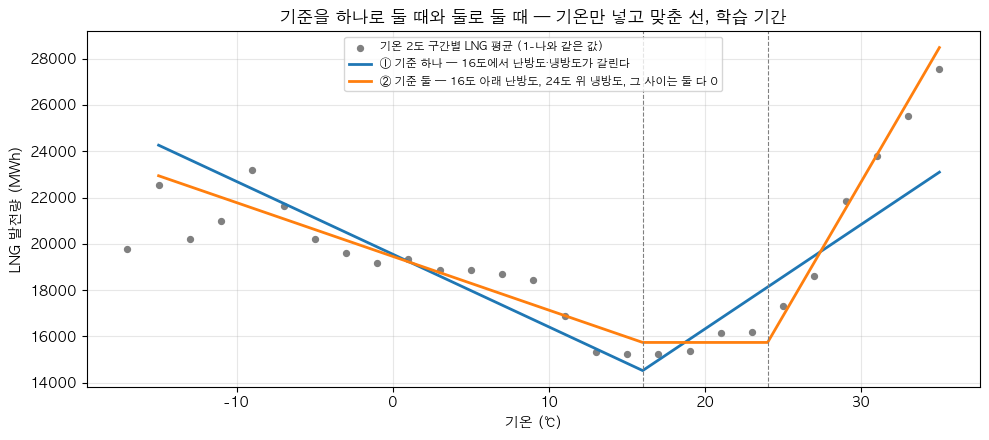

In [929]:
# 5단계 파생변수 · 1-바
from sklearn.linear_model import LinearRegression                          # 1-라·1-마와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량

def 두열(난방기준, 냉방기준, 기온):                                          # 기온으로 난방도·냉방도 두 열을 만든다
    return pd.DataFrame({"난방도": (난방기준 - 기온).clip(lower=0),          # 난방도 기준보다 추운 만큼
                         "냉방도": (기온 - 냉방기준).clip(lower=0)})         # 냉방도 기준보다 더운 만큼

격자 = pd.Series(np.arange(-15, 35.5, 0.5))                                 # 선을 그릴 기온 −15~35도, 0.5도 간격
선_하나 = LinearRegression().fit(두열(16, 16, train["ta"]), y).predict(두열(16, 16, 격자))   # ① 기준 하나(16도)
선_둘 = LinearRegression().fit(두열(16, 24, train["ta"]), y).predict(두열(16, 24, 격자))     # ② 기준 둘(16도·24도)
점 = train.assign(가운데=train["ta"] // 2 * 2 + 1).groupby("가운데")["lng_mwh"].mean()       # 2도 구간 평균을 구간 가운데에 찍는다

plt.figure(figsize=(10, 4.5))
plt.scatter(점.index, 점.values, color="gray", s=18, label="기온 2도 구간별 LNG 평균 (1-나와 같은 값)")
plt.plot(격자, 선_하나, lw=2, label="① 기준 하나 — 16도에서 난방도·냉방도가 갈린다")
plt.plot(격자, 선_둘, lw=2, label="② 기준 둘 — 16도 아래 난방도, 24도 위 냉방도, 그 사이는 둘 다 0")
for 선 in (16, 24):
    plt.axvline(선, ls="--", lw=.8, color="gray")                           # 16도와 24도에 세로선
plt.xlabel("기온 (℃)"); plt.ylabel("LNG 발전량 (MWh)")
plt.title("기준을 하나로 둘 때와 둘로 둘 때 — 기온만 넣고 맞춘 선, 학습 기간")
plt.legend(fontsize=8, loc="upper center"); plt.grid(alpha=.3); plt.tight_layout(); plt.show()

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 지금 그래프를 보면 16도를 기준으로 하고 있잖어. 그리고 점은 결국 값들인데,, 확실히 24도 이후로 설명하는건 오렌지색이 좋고, 16~24도 사이에도 오렌지가 좋은 거 같은데 이건 이 구간만 좁혀가지고 회귀 곡선을 그려보면 실제 데이터를 더 잘 대변하는 값을 찾을 수 있을 거 같은데.. 

- 영하 한 8도쯤?? 부터는 데이터가 왔다갔다 하는데.. 이게 참 어렵네. 이게 내가 기억하기로는 서울 108지점에 해당하는데 차라리 다른 영역에서 가져온 lng는 없겠지??(데이터가 풍부한 것). 그런데 그것을 가져오면 지금까지 해오던 모든게 틀어질 것 같아서 불가능할 것 같네..

난방 측면에서 보면,.. 약 영하 5도~10도 사이가 거의 직선이란 말이지?? 그리고 그 뒤는 엉망진창이고.. 그 뒤를 버릴 수도 없고 애매하다. 뭔가 생각하기로는 주황색이 더 잘 설명하는데. 10도를 기준으로는 또 다른 회귀 곡선을 그리면 더 정확해질 수 있겠다? 이런 생각이 들어.

#### ② 마지막 — 기준온도를 어떻게 두시겠습니까? (제안: 난방도 16도 · 냉방도 24도, 따로)

- 제안대로 가시면 「16·24로 간다」처럼 한 줄만 적으셔도 됩니다. 다르게 두시면 몇 도로, 왜 그렇게 두시는지 적어 주세요.

답: 사실 이미 답은 정해진 거 같은데 그래도 그래프로 위에서 말한 것처럼 수치로 보자. 그리고 그거 보면서, 뒤에 10도를 기준으로 다시 곡선을 그릴 수도 있으니까 그것도 고려해보자. 그러니까 흠.. 예컨대 24이상, 16~24, 그리고 16~10, 10~-5도?? 이렇게 나누는건? 그 뒤는 나도 모르겠다 뭐가 적합한건지. 일단 나는 내가 보이는 대로 아이디어를 던질테니까 너는 보고 코드를 적어주고, 진행하고, 판단에 도움을 주는 선생님 역할을 하면 돼. 알고있지??

### 클로드 답변

> **짧게**
> 1. 그림을 맞게 읽으셨습니다 — 24도 위와 16~24도 모두 주황색(기준 둘)이 점에 더 가깝습니다.
> 2. 「10도를 기준으로 또 다른 회귀 곡선을 그리면 더 정확해질 수 있겠다」 — 그 생각을 숫자로 보는 **1-사**를 만들었습니다. 다만 1-바는 기온만 넣은 그림이라 눈으로 본 꺾임에는 달의 효과가 섞여 있습니다. 그래서 1-사에는 1-마처럼 시간대·월을 고정한 칸을 같이 두었습니다.
> 3. 「다른 영역에서 가져온 lng는 없겠지??」 — LNG는 서울 것이 아니라 **전국 합계 하나**입니다. 서울 108에서 가져온 것은 기온뿐입니다. 영하 8도 아래가 흔들리는 것은 그런 시각이 적어서이고, 지점을 바꿔도 풀리지 않습니다.

**맞게 읽으신 것**

- 「16도를 기준으로 하고 있잖어」 — 파란 선(기준 하나)은 16도 한 곳에서 꺾입니다. 주황 선(기준 둘)은 16도와 24도 두 곳에서 꺾이고 그 사이가 평평합니다.
- 「24도 이후로 설명하는건 오렌지색이 좋고, 16~24도 사이에도 오렌지가 좋은 거 같은데」 — 맞습니다. 파란 선은 16도 한 점에서 꺾여야 해서 바닥 근처에서 점들보다 아래로 내려가고, 30도 위에서도 점들보다 낮게 지나갑니다. 주황 선은 16~24도를 평평하게 지나다가 24도 위에서 가파르게 올라 점에 더 가깝습니다.

**「16~24도 사이에도… 이 구간만 좁혀가지고 회귀 곡선을 그려보면 실제 데이터를 더 잘 대변하는 값을 찾을 수 있을 거 같은데」**

16~24도 점들은 완전히 평평하지 않고 조금 오릅니다(1-나 표: 16~18도 15,221 → 22~24도 16,183). 주황 선은 이 구간을 평평하게 두니 그만큼은 못 맞힙니다. 이 구간에 기울기를 따로 주는 것도 결국 「꺾이는 점을 하나 더 두는 것」입니다 — 냉방도를 20도쯤부터 약하게 시작하고 26도 근처에서 한 번 더 가파르게 하는 모양입니다. 냉방 쪽은 1-다에서 「26도 넘는 만큼」으로 이미 7단계 후보에 올려 두었으니, 이번에는 창주 님이 적으신 난방 쪽(10도)을 1-사에서 봅니다.

**「영하 한 8도쯤?? 부터는 데이터가 왔다갔다」 · 「차라리 다른 영역에서 가져온 lng는 없겠지??(데이터가 풍부한 것)」**

- LNG는 서울에서 가져온 값이 아니라 **전국 LNG 발전량 합계 하나**입니다(전력거래소 자료). 서울 108 지점에서 가져온 것은 기온·습도·일사뿐입니다.
- 영하 8도 아래 점이 흔들리는 것은 그런 시각이 적어서입니다. 1-나 표에서 영하 10도 아래 구간은 시각이 103·78·42·15·15개입니다. 점 하나가 수십 시각의 평균이라, 그 시각에 원전이 몇 기 서 있었는지 같은 다른 사정이 그대로 드러납니다.
- 다른 지점의 기온을 가져와도 이건 풀리지 않습니다. 서울이 그만큼 추웠던 시각 자체가 2년 동안 얼마 없기 때문입니다. 4단계에서 「기상 지점은 늘리지 않고, 7단계에서 추운 날에 크게 틀리면 그때 부산을 더한다」로 정했고, 극단 추위가 드물다는 것은 11단계(결론과 한계를 적는 단계)의 한계에 적기로 했습니다.
- 그래서 「그 뒤를 버릴 수도 없고 애매하다」는 판단이 맞습니다. 버리지 않고, 그 구간은 적은 표본으로 배운다는 것을 한계로 남깁니다.

**「난방 측면에서 보면.. 약 영하 5도~10도 사이가 거의 직선… 10도를 기준으로는 또 다른 회귀 곡선을 그리면 더 정확해질 수 있겠다?」**

눈으로 보신 것은 맞습니다. 추운 쪽 점들은 16도에서 12도까지는 거의 평평하고, 12도에서 8도 사이에 크게 오르고, 8도부터 영하 5도까지는 완만하게 오릅니다. 난방도 한 열(직선)은 이 모양의 평균을 지나갑니다.

다만 짚을 것이 하나 있습니다. **1-바는 기온만 넣은 그림이라, 이 꺾임에 달의 효과가 섞여 있습니다.** 1-다 답변에 적은 대로 8도 미만 시각은 98%가 11~3월이고, 12~20도 시각은 69%가 4·5·10월입니다. 12도에서 8도 사이에 크게 오르는 것은 「기온이 4도 내려가서」일 수도 있고 「봄·가을 달에서 겨울 달로 넘어가서」일 수도 있습니다. 모델에는 월이 따로 들어가므로, 10도에 꺾이는 점을 더할지는 **시간대·월을 고정한 상태에서** 판단해야 합니다. 1-사에 그 칸을 같이 넣었습니다.

**② 칸에 적으신 것**

「24이상, 16~24, 그리고 16~10, 10~-5도?? 이렇게 나누는건?」 — 3등분(16·24)을 기본으로 두고, 10도를 더한 4등분과 영하 5도까지 더한 5등분이 뚜렷이 나은지 숫자로 보자는 말씀으로 이해했습니다. 1-사가 그 세 가지를 한 표에 놓습니다. 기준은 1-사 아래 칸에서 정하시면 됩니다.

「나는 내가 보이는 대로 아이디어를 던질테니까 너는 보고 코드를 적어주고, 진행하고, 판단에 도움을 주는 선생님 역할을 하면 돼」 — 네, 그 순서로 하고 있습니다. 창주 님 아이디어 → 그것을 보는 셀 → 창주 님 판단입니다.

**📘 빅분기 과목 연결**

- **2과목 기초통계 — 표본이 적은 구간의 흔들림.** 평균의 흔들림은 표준편차 ÷ √n이라서, 시각이 15개인 구간은 1,000개인 구간보다 흔들림이 8배쯤 큽니다.
- **2과목 교란.** 기온과 달이 같이 움직이면, 기온만 넣은 그림의 꺾임이 기온 때문인지 달 때문인지 가릴 수 없습니다. 달을 같이 넣고 보면 가려집니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 따로 필요한건 없어 보여. 1-사에서 검토해서 결정해야겠네.

## 1-사

**어디서 나온 셀인가.** 1-바 칸에 「10도를 기준으로는 또 다른 회귀 곡선을 그리면 더 정확해질 수 있겠다」, ② 줄에 「24이상, 16~24, 그리고 16~10, 10~-5도?? 이렇게 나누는건?」라고 적으셨습니다. 1-마 「다시 읽고 나서」에는 「3등분이든 4등분이든… 컬럼 형태로 저장시켜둔 뒤에 추후에 모델링할 때 변화를 가장 잘 설명하는 것」이라고 적으셨습니다(09-24). 기온을 더 잘게 나눈 것이 7단계 후보로 저장해 둘 만큼 나은지를 여기서 봅니다.

**무엇을 보는 셀인가.** 기온을 몇 구간으로 나누느냐에 따라 R²가 얼마나 달라지는지 봅니다. 구간은 「기온을 나누는 온도」로 정합니다. 두 가지를 기온별로 나란히 놓으면 이렇습니다.

| 기온 | 16·24도로 나눔 (3구간) | 10·16·24도로 나눔 (4구간) |
|---|---|---|
| 30도 | 24도 위 — 냉방 쪽 기울기 | 24도 위 — 냉방 쪽 기울기 |
| 20도 | 16~24도 — 기온이 LNG를 올리지 않음 | 16~24도 — 기온이 LNG를 올리지 않음 |
| 13도 | 16도 아래 — 난방 쪽 기울기 하나 | 10~16도 — 난방 쪽 기울기 ① |
| 0도 | 16도 아래 — 같은 난방 쪽 기울기 | 10도 아래 — 난방 쪽 기울기 ② |

- 3구간은 16도 아래를 기울기 하나로 봅니다. 4구간은 16도 아래를 10도에서 한 번 더 나눠서, 10~16도와 10도 아래에 기울기를 따로 줍니다. 1-바 칸에 적으신 「16~10, 10~-5」가 이런 모양입니다.
- 표의 첫 줄은 3구간(16·24도)입니다. 그 아래로 추운 쪽을 한 번 더 나눈 4구간(나누는 온도를 영하 6도부터 14도까지 2도씩), 10도와 영하 5도를 둘 다 둔 5구간, 더운 쪽을 26·28·30도에서 한 번 더 나눈 4구간이 이어집니다. 더운 쪽 세 줄은 1-다 「읽고 나서」에 적으신 「26도가 넘으면… 더 세밀하게 나눌 수도」를 같이 본 것입니다.
- R² 칸은 1-마처럼 둘입니다 — 기온만 넣었을 때와 시간대·월을 같이 넣었을 때입니다.

**읽는 법.** 첫 줄(3구간)의 오른쪽 R²와 아래 줄들의 오른쪽 R²를 비교합니다. 구간을 늘리면 R²는 줄지 않고 늘기만 하니, 늘었느냐가 아니라 **얼마나 늘었느냐**를 봅니다. 1-마 답변에서 0.002 안쪽은 우연으로도 생길 수 있는 차이라고 적었습니다. 판단은 오른쪽 칸(시간대·월 고정)으로 합니다. 첫 줄 오른쪽 칸은 1-마의 「냉방도 기준 24도」 줄과 같은 값이어야 맞습니다.

In [930]:
# 5단계 파생변수 · 1-사
from sklearn.linear_model import LinearRegression                          # 1-라~1-바와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),              # 1-마와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)

def 기온열(추운쪽, 더운쪽):                                                  # 나누는 온도로 기온 열을 만든다
    열 = pd.DataFrame(index=train.index)
    for 온도 in 추운쪽:                                                     # 추운 쪽 — 나누는 온도마다 「그보다 추운 만큼」 한 열
        열[f"{온도}도보다 추운 만큼"] = (온도 - train["ta"]).clip(lower=0)
    for 온도 in 더운쪽:                                                     # 더운 쪽 — 나누는 온도마다 「그보다 더운 만큼」 한 열
        열[f"{온도}도보다 더운 만큼"] = (train["ta"] - 온도).clip(lower=0)
    return 열

def 두R2(열):                                                              # 기온만 넣을 때와 시간대·월을 같이 넣을 때의 R²
    같이 = pd.concat([고정열, 열], axis=1)
    return (round(LinearRegression().fit(열, y).score(열, y), 3),
            round(LinearRegression().fit(같이, y).score(같이, y), 3))

후보 = [([16], [24], "–")]                                                  # 3구간 — 16도와 24도로 나눈다
후보 += [([16, k], [24], "추운 쪽") for k in range(-6, 15, 2)]              # 추운 쪽을 k도에서 한 번 더 나눈다 — 4구간
후보 += [([16, 10, -5], [24], "추운 쪽 두 번")]                              # 1-바 칸에 적으신 10도와 영하 5도 — 5구간
후보 += [([16], [24, k], "더운 쪽") for k in (26, 28, 30)]                  # 더운 쪽을 k도에서 한 번 더 나눈다 — 4구간

표 = []                                                                    # 나누는 방법마다 한 줄씩
for 추운쪽, 더운쪽, 쪽 in 후보:
    r1, r2 = 두R2(기온열(추운쪽, 더운쪽))
    온도들 = sorted(추운쪽 + 더운쪽)                                          # 나누는 온도를 작은 것부터 적는다
    표.append({"기온을 나누는 온도": "·".join(str(t) for t in 온도들) + "도",
               "구간 수": len(온도들) + 1, "더 나눈 쪽": 쪽,
               "R² 기온만": r1, "R² 시간대·월 고정": r2})

print("기온을 몇 구간으로 나누면 R²가 얼마나 느나 — 학습 기간(2023+2024)만")
display(pd.DataFrame(표).set_index("기온을 나누는 온도"))

기온을 몇 구간으로 나누면 R²가 얼마나 느나 — 학습 기간(2023+2024)만


,구간 수,더 나눈 쪽,R² 기온만,R² 시간대·월 고정
기온을 나누는 온도,,,,
16·24도,3,–,0.173,0.501
-6·16·24도,4,추운 쪽,0.174,0.502
-4·16·24도,4,추운 쪽,0.174,0.502
-2·16·24도,4,추운 쪽,0.174,0.501
0·16·24도,4,추운 쪽,0.174,0.501
2·16·24도,4,추운 쪽,0.174,0.501
4·16·24도,4,추운 쪽,0.175,0.501
6·16·24도,4,추운 쪽,0.175,0.502
8·16·24도,4,추운 쪽,0.175,0.502


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 그래프 결괏값 해석이 어려운데?? 너가 괄호 안에 적은 추가 몇도?? 이게 정확히 무슨 의미인지 잘 모르겠어. 확실한건 뭐 어떤 변화도 결정계수에 드라마틱한 차이가 보이지는 않는데.. 

#### ② 마지막 — 기온을 몇 등분으로, 기준을 몇 도로 두시겠습니까?

- 몇 등분으로 둘지, 기준을 몇 도로 둘지, 더 나누는 열을 7단계 후보로 같이 저장해 둘지를 적어 주세요.

답: 해당 그래프를 제대로 해석하지 못해서 결정을 못내리겠는데??

### 클로드 답변

> **짧게**
> 1. 「추가 몇 도」는 제가 줄여 쓴 이름이라 뜻이 안 보였습니다. **기온을 나누는 온도를 하나 더 둔 것**입니다. 「추가 10도」는 기온을 10도 아래 · 10~16도 · 16~24도 · 24도 위, **네 구간**으로 나눈 것입니다. 표 이름을 「10·16·24도」처럼 나누는 온도를 그대로 적도록 고쳤으니 1-사를 다시 돌려 주세요.
> 2. 「어떤 변화도 결정계수에 드라마틱한 차이가 보이지는 않는데」 — **이 표에서 읽어야 할 것이 바로 그것입니다.** 시간대·월 고정 칸에서 3구간이 0.501이고, 추운 쪽을 어디서 더 나눠도 0.501 아니면 0.502입니다.
> 3. 다시 돌리시면 더운 쪽을 더 나눈 세 줄이 새로 생깁니다. 그 세 줄까지 보시고 정하시면 됩니다.

**제가 잘못 쓴 것**

표의 이름을 「4등분 (추가 10도)」처럼 적었습니다. 코드가 하는 일(열을 하나 더 넣는다)을 이름으로 붙이고, 그 결과로 기온이 어떤 구간으로 나뉘는지는 적지 않았습니다. 설명 칸도 「k도보다 추운 만큼 열을 하나 더 넣으면 k도에서 한 번 더 꺾이는 4등분」처럼 줄여 써서, 코드를 보지 않은 사람은 무엇이 어떻게 나뉘는지 알 수 없었습니다. 표 이름을 나누는 온도로 바꾸고(「10·16·24도」, 구간 수와 더 나눈 쪽은 칸을 따로 둠), 설명 칸에 3구간과 4구간을 기온별로 나란히 놓은 표를 넣었습니다. 지침에도 「표의 행·열 이름은 코드가 하는 일이 아니라 결과를 가리키는 말로 쓴다」를 넣었습니다.

**표를 다시 읽으면**

다시 돌리시면 줄 이름이 이렇게 바뀝니다. 숫자는 지금 출력과 같습니다.

- 첫 줄 **「16·24도」 (3구간)** — 지금까지 정해 온 모양입니다.
- **「-6·16·24도」부터 「14·16·24도」까지 (4구간, 추운 쪽)** — 16도 아래를 한 번 더 나눈 것이고, 나누는 온도를 영하 6도부터 14도까지 옮겼습니다. 1-바 칸에 적으신 10도는 「10·16·24도」 줄입니다.
- **「-5·10·16·24도」 (5구간)** — 1-바 칸에 적으신 「16~10, 10~-5」를 그대로 한 것입니다.
- **「16·24·26도」·「16·24·28도」·「16·24·30도」 (4구간, 더운 쪽)** — 새로 넣은 줄입니다. 24도 위를 한 번 더 나눈 것입니다.

지금 출력에서 오른쪽 칸(시간대·월 고정)을 위에서 아래로 보면 0.501 아니면 0.502입니다. 구간을 늘려도 0.001 느는 것이 전부이고, 1-마 답변에 적은 「0.002 안쪽은 우연으로도 생긴다」 안에 들어갑니다. 적으신 「드라마틱한 차이가 보이지는 않는다」가 정확한 읽기입니다.

**1-바 그림에서는 10도 근처에서 꺾여 보였는데, 왜 나눠도 늘지 않나**

왼쪽 칸(기온만)을 보시면 오른쪽 칸보다 조금 더 오릅니다(3구간 0.173에서 많게는 0.175). 기온만 넣었을 때는 구간을 나누는 것이 조금 도움이 되는데, 시간대와 월을 같이 넣으면 그 도움이 거의 없어진다는 뜻입니다. 1-바 답변에 적은 대로, 그림에서 12도와 8도 사이에 크게 오르던 것은 상당 부분이 기온 때문이 아니라 **달이 바뀌어서**(봄·가을 달에서 겨울 달로 넘어가서)였고, 월이 따로 들어가면 추운 쪽은 기울기 하나로 충분하다는 것입니다.

**② 기준 — 기본값 제안**

- **추운 쪽은 더 나누지 않습니다.** 영하 6도부터 14도까지 어디서 나눠도 늘지 않았습니다.
- **더운 쪽 세 줄도 같다면 3구간(난방도 16도·냉방도 24도)으로 가고, 더 나누는 열은 7단계 후보로도 저장하지 않습니다.** 1-마 「다시 읽고 나서」 답변에 적은 대로 후보는 근거가 있을 때만 올리는데, 여기서는 늘지 않는다는 것이 확인되기 때문입니다. 그러면 닫는 칸 ③에 7단계 후보로 적어 둔 「26도 넘는 만큼」·「8도보다 추운 만큼」도 이 표로 판단이 끝난 것이 됩니다.
- 더운 쪽 세 줄에서 뚜렷이 느는 줄이 있으면 그 줄만 7단계 후보로 남깁니다.

정하시는 것은 창주 님입니다. 아래 「읽고 나서」 칸의 ②에 적어 주세요.

**📘 빅분기 과목 연결**

- **4과목 모형 선택 — 간결성.** 설명력이 같으면 변수가 적은 모델을 고릅니다. 변수가 많으면 학습 데이터에만 맞는 부분까지 배워서 새 데이터에서 성적이 떨어지기 쉽습니다(과적합).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 아 오키 이제 이해했다. 기온을 나누는 방식과 구간을 적었구나. 그런데 생각보다 이게 결정계수 값은 크게 차이가 안나네?? 그런데 우리가 기온을 나누는 온도 나누고, 그 안에 각각의 회귀함수에 적합한 기울기를 찾는건 또 다른 문제 아닌가?? 그리고 보니까 16도가 아니라?? 12도?? 까지 비슷하게 점이 찍히는데 이러면 또 기준점을 바꿔야하나??

#### ② 마지막 — 1-사를 다시 돌려 보시고, 기온을 몇 구간으로, 기준을 몇 도로 두시겠습니까?

- 몇 구간으로 둘지, 나누는 온도를 몇 도로 둘지, 더 나누는 열을 7단계 후보로 같이 저장해 둘지를 적어 주세요.

답: 아직 모르겠다. 이게 곡선이 꼭 연결되어야 하나?? 각각의 구간을 설명하는 그래프 즉, 직선들로 이루어져도 괜찮지 않나??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「기온을 나누는 온도 나누고, 그 안에 각각의 회귀함수에 적합한 기울기를 찾는건 또 다른 문제 아닌가??」 — 기울기는 따로 찾지 않아도 됩니다. **나누는 온도를 정해 열을 만들면, 구간마다 가장 잘 맞는 기울기는 회귀가 계산으로 찾습니다.** 1-사 표의 R²도 이미 그렇게 찾은 기울기로 낸 값입니다. 우리가 정할 것은 나누는 온도뿐입니다.
> 2. 「16도가 아니라?? 12도?? 까지 비슷하게 점이 찍히는데 이러면 또 기준점을 바꿔야하나??」와 「곡선이 꼭 연결되어야 하나??」는 둘 다 표로 볼 수 있어서 **1-아**를 만들었습니다.
> 3. ②는 1-아를 보신 뒤 1-아 아래 칸에서 정하시면 됩니다.

**「그 안에 각각의 회귀함수에 적합한 기울기를 찾는건 또 다른 문제 아닌가??」**

두 가지 일이 맞는데, 하는 쪽이 다릅니다.

- **나누는 온도를 정하는 일** — 우리가 합니다. 16도로 나눌지 12도로 나눌지는 회귀가 스스로 정하지 못합니다. 그래서 1-라부터 1-사까지 온도를 바꿔 가며 표를 본 것입니다.
- **구간마다 기울기를 찾는 일** — 회귀가 합니다. 열을 넣고 돌리면, 1-가 「읽고 나서」 답변에 적은 「남은 흔들림」(틀린 만큼을 제곱해서 더한 것)이 가장 작아지는 기울기를 계산으로 찾습니다. 1-라 표의 「난방도 기울기 314 · 냉방도 기울기 451」이 그렇게 찾은 값입니다.

그러니 1-사의 각 줄은 「이렇게 나누면, 가장 잘 맞는 기울기를 찾았을 때 R²가 이만큼」이라는 뜻입니다. 기울기를 더 잘 찾아서 R²를 올릴 여지는 없습니다.

**「보니까 16도가 아니라?? 12도?? 까지 비슷하게 점이 찍히는데 이러면 또 기준점을 바꿔야하나??」**

1-바 그림을 맞게 읽으셨습니다. 1-나 표에서도 12~14도 15,317 · 14~16도 15,260 · 16~18도 15,221로 12도부터 거의 평평합니다. 다만 1-바는 기온만 넣은 그림입니다. 12~16도 시각은 대부분 4·5·10월이고, 이 달들은 LNG가 원래 낮은 달입니다(1-다 답변). 그래서 12~16도에서 LNG가 평평해 보이는 것에 달의 효과가 섞여 있을 수 있습니다. 1-사에서처럼 시간대·월을 고정한 칸으로 봐야 하고, 1-아의 「난방 12도」 줄이 그것입니다.

**「이게 곡선이 꼭 연결되어야 하나?? 각각의 구간을 설명하는 그래프 즉, 직선들로 이루어져도 괜찮지 않나??」**

꼭 연결될 필요는 없고, 끊는 방법도 있습니다. 구간마다 기울기뿐 아니라 **시작 높이(절편)도 따로** 주면 선이 경계에서 끊깁니다. 1-가 「다시 읽고 나서」 답변에서 「구간마다 따로 돌리면 선이 끊길 수 있다」고 한 것이 이것입니다. 열로는 「16도보다 추운가」·「24도보다 더운가」라는 0/1 열 둘을 더하면 됩니다.

끊을 때 생각할 것이 둘 있습니다.

- 선이 끊기면 경계에서 예측이 한 번에 바뀝니다. 기온이 15.9도일 때와 16.1도일 때 예측이 수백 MWh 차이 날 수 있습니다. 0.2도 차이로 전력 수요가 갑자기 바뀌지는 않으니, 기온처럼 조금씩 변하는 값에는 이어진 선이 실제에 가깝다고 봅니다(제 판단입니다).
- 기온 열이 둘에서 넷으로 늘어납니다.

끊은 선이 설명을 더 하는지는 1-아의 마지막 줄에서 보실 수 있습니다. 참고로 트리 계열은 계단처럼 끊긴 모양으로 배웁니다. 그래서 트리에는 기온을 그대로 넣습니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 최소제곱법.** 잔차(실제값 − 예측값)를 제곱해서 더한 값이 가장 작아지도록 기울기와 절편을 정하는 방법입니다. 선형회귀가 기울기를 찾는 방법이 이것입니다.
- **2과목 파생변수 — 더미 변수로 구간 표시.** 「16도보다 추운가」처럼 조건에 맞으면 1, 아니면 0인 열을 넣으면 그 구간에만 따로 높이를 줄 수 있습니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답: 그러니까 뭔가 온도로 나누면 온도로 나누는 이유가 있어야 하는데, 즉 기준을 정한 이유가 있어야 하는데 값들이 비슷해가지고 특정한 기준으로 왜 이 기준으로 온도를 나눴는지가 명확하지 않으니까.. 어렵네.

- 아 이게 달과도 연관이 있으니까 해석하거나 어떤 기준으로 정할지가 어렵다..
- 그러네 끊으면 그 딱 구간 좌우에서 값이 크게 바뀌겠네.. 흠 이러면 진짜 회귀방식이 아니라 다른 모델을 사용해야 할 수도 있겠는걸? 일단 더 봐야 알겠는데,,?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「값들이 비슷해가지고 특정한 기준으로 왜 이 기준으로 온도를 나눴는지가 명확하지 않으니까」 — **값이 비슷하다는 것 자체가 확인한 결과이고, 그것이 이유가 됩니다.** 「시간대·월을 고정하면 난방은 16~20도, 냉방은 23~27도 사이 어디서 나눠도 설명력이 같았고, 그 안에서 16도와 24도를 골랐다」라고 적으면 됩니다.
> 2. 「진짜 회귀방식이 아니라 다른 모델을 사용해야 할 수도 있겠는걸?」 — 끊긴 계단 모양으로 배우는 것이 트리 계열입니다. 7단계(모델을 만들고 기준선과 비교하는 단계)에서 선형회귀와 같은 표에 놓고 비교합니다.

**「기준을 정한 이유가 있어야 하는데 값들이 비슷해가지고…」**

기준온도를 정한 이유는 둘로 나눠 적을 수 있습니다.

- **범위는 표로 확인했습니다.** 시간대·월을 고정했을 때 난방은 16~20도에서 0.501~0.502(1-아), 냉방은 23~27도에서 0.500~0.502(1-마)로, 0.002 안쪽에서 같았습니다. 그 밖은 뚜렷이 낮았습니다 — 난방 12도는 0.496, 난방·냉방 기준을 둘 다 16도로 둔 것은 0.484입니다.
- **그 범위 안에서 한 값을 고른 이유는 따로 있습니다.** 16도는 기온만 볼 때 LNG가 가장 낮은 구간입니다(1-나의 U자 바닥). 24도는 1-마 표의 두 칸(기온만 · 시간대·월 고정)에서 모두 높게 남은 23~25도의 가운데입니다(1-마 답변).

그리고 「기준온도를 몇 도 바꿔도 결과가 거의 같다」는 것은, 기준온도를 어떻게 잡았든 결론이 크게 달라지지 않는다는 뜻입니다. 11단계(결론과 한계를 적는 단계)에서 「기준온도를 바꿔 봤는데 결과가 거의 같았다」로 적을 수 있는 확인입니다.

「아 이게 달과도 연관이 있으니까 해석하거나 어떤 기준으로 정할지가 어렵다..」 — 맞습니다. 그래서 판단은 시간대·월을 고정한 칸으로 했습니다. 모델에는 월이 따로 들어가므로, 달 때문에 생긴 차이는 월 열이 설명합니다.

**「끊으면 그 딱 구간 좌우에서 값이 크게 바뀌겠네.. 흠 이러면 진짜 회귀방식이 아니라 다른 모델을 사용해야 할 수도 있겠는걸?」**

맞습니다. 구간마다 끊긴 계단 모양으로 배우는 것이 트리 계열입니다(1-사 「읽고 나서」 답변). 선형회귀는 이어진 선으로, 트리는 계단으로 배웁니다. 둘 중 어느 쪽이 2025년을 더 잘 맞히는지는 7단계에서 기준선 → 선형회귀 → 트리 계열 순서로 같은 표에 놓고 봅니다. 「일단 더 봐야 알겠는데,,?」가 7단계에서 할 일입니다.

**📘 빅분기 과목 연결**

- **4과목 분석모형 평가·개선 쪽 — 민감도 분석.** 사람이 정한 설정값(여기서는 기준온도)을 바꿔 가며 결과가 얼마나 달라지는지 보는 것입니다. 결과가 거의 안 달라지면, 그 설정을 어떻게 잡았든 결론이 같다는 뜻입니다. 출제기준에 이 이름으로 나오지는 않습니다. 또 시험에서 「민감도」는 대개 분류 모델의 지표(실제로 양성인 것 중 양성으로 맞힌 비율, 재현율과 같은 말)를 가리키니, 이 「민감도 분석」과 섞지 않으셔야 합니다.

## 1-아

**어디서 나온 셀인가.** 1-사 칸 아래 「읽고 나서」에 「보니까 16도가 아니라?? 12도?? 까지 비슷하게 점이 찍히는데 이러면 또 기준점을 바꿔야하나??」, ② 줄에 「이게 곡선이 꼭 연결되어야 하나?? 각각의 구간을 설명하는 그래프 즉, 직선들로 이루어져도 괜찮지 않나??」라고 적으셨습니다(09-24).

**무엇을 보는 셀인가.** 두 가지를 한 표에 놓습니다.

- 난방 쪽 나누는 온도를 10도부터 20도까지 2도씩 바꿉니다. 냉방 쪽은 24도 그대로입니다. 1-마가 냉방 쪽 온도를 바꿔 본 것을 이번에는 난방 쪽으로 한 것입니다. 「난방 12도」 줄이 적으신 물음입니다.
- 마지막 줄은 16·24도로 나누되 선을 끊은 것입니다. 이어진 선과 끊긴 선은 이렇게 다릅니다.

| | 이어진 선 | 끊긴 선 |
|---|---|---|
| 구간마다 따로 주는 것 | 기울기 | 기울기와 시작 높이 |
| 15.9도와 16.1도의 예측 | 거의 같다 | 한 번에 크게 달라질 수 있다 |
| 기온 열 수 | 2 (난방도·냉방도) | 4 (난방도·냉방도 + 「16도보다 추운가」·「24도보다 더운가」 0/1 열) |

**읽는 법.** 오른쪽 칸(시간대·월 고정)으로 봅니다. 「난방 16도 · 냉방 24도, 이어진 선」 줄이 지금 제안이고, 1-사 첫 줄과 같은 값이어야 맞습니다. 다른 줄이 이 줄보다 0.002 넘게 크면 그쪽이 낫고, 0.002 안쪽이면 같은 것으로 봅니다. 열 수가 늘었는데 R²가 같다면 열이 적은 쪽을 고릅니다(1-마 답변의 효율성).

In [931]:
# 5단계 파생변수 · 1-아
from sklearn.linear_model import LinearRegression                          # 1-라~1-사와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),              # 1-마와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)

def 두R2(열):                                                              # 기온만 넣을 때와 시간대·월을 같이 넣을 때의 R²
    같이 = pd.concat([고정열, 열], axis=1)
    return (round(LinearRegression().fit(열, y).score(열, y), 3),
            round(LinearRegression().fit(같이, y).score(같이, y), 3))

표 = []                                                                    # 방법마다 한 줄씩
for 난방 in range(10, 21, 2):                                              # 난방 쪽 나누는 온도 10~20도(냉방 쪽은 24도)
    열 = pd.DataFrame({"난방도": (난방 - train["ta"]).clip(lower=0),          # 난방 온도보다 추운 만큼
                       "냉방도": (train["ta"] - 24).clip(lower=0)})           # 24도보다 더운 만큼
    r1, r2 = 두R2(열)
    표.append({"기온 열을 만드는 방법": f"난방 {난방}도 · 냉방 24도, 이어진 선",
               "기온 열 수": 2, "R² 기온만": r1, "R² 시간대·월 고정": r2})

끊긴 = pd.DataFrame({"난방도": (16 - train["ta"]).clip(lower=0),             # 이어진 선과 같은 두 열에
                     "냉방도": (train["ta"] - 24).clip(lower=0),
                     "16도보다 추운가": (train["ta"] < 16).astype(float),     # 구간마다 시작 높이를 따로 주는 0/1 열 둘을 더한다
                     "24도보다 더운가": (train["ta"] > 24).astype(float)})
r1, r2 = 두R2(끊긴)
표.append({"기온 열을 만드는 방법": "난방 16도 · 냉방 24도, 끊긴 선",
           "기온 열 수": 4, "R² 기온만": r1, "R² 시간대·월 고정": r2})

print("난방 쪽 나누는 온도를 바꿀 때, 그리고 선을 끊을 때 — 학습 기간(2023+2024)만")
display(pd.DataFrame(표).set_index("기온 열을 만드는 방법"))

난방 쪽 나누는 온도를 바꿀 때, 그리고 선을 끊을 때 — 학습 기간(2023+2024)만


,기온 열 수,R² 기온만,R² 시간대·월 고정
기온 열을 만드는 방법,,,
"난방 10도 · 냉방 24도, 이어진 선",2,0.162,0.493
"난방 12도 · 냉방 24도, 이어진 선",2,0.169,0.496
"난방 14도 · 냉방 24도, 이어진 선",2,0.173,0.499
"난방 16도 · 냉방 24도, 이어진 선",2,0.173,0.501
"난방 18도 · 냉방 24도, 이어진 선",2,0.171,0.502
"난방 20도 · 냉방 24도, 이어진 선",2,0.168,0.502
"난방 16도 · 냉방 24도, 끊긴 선",4,0.174,0.502


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 위에서 말한 12도로 끊는건 우리가 원래 보려던 16도보다 적합하지 않아보이고, 우리가 원래 했던 그 16~24도 방식보다는 끊긴 선이지만 4개로 끊는게 가장 높은 값을 보이는데, 그러면 이렇게 나누는게 결정 계수 측면에서 약간 차이가 나는데, 그러면 너가 말한 것처럼 그 끊기는 구간 좌우에서 예측이 크게 달라질 수 있는데 이걸 감당하느냐 아니냐 선택의 문제겠네?

#### ② 마지막 — 1-사와 1-아를 보시고, 기온을 몇 구간으로, 나누는 온도를 몇 도로 두시겠습니까? 선은 이을까요, 끊을까요?

- 몇 구간으로 둘지, 나누는 온도를 몇 도로 둘지, 선을 이을지 끊을지, 더 나누는 열을 7단계 후보로 같이 저장해 둘지를 적어 주세요.

답: 뭐가 적합한지는 진짜 다 가정한다음에 7단계에서 모델링해야겠는데..? 지금 그냥 숫자들이 다 비슷비슷하고, 어떤 모델로 어떤 결과가 나올지 몰라가지고, 우리가 지금까지 정한 여러 온도의 설정이나, 방식들을 잘 정리해야할 것 같아.

### 클로드 답변

> **짧게**
> 1. 「12도로 끊는건 우리가 원래 보려던 16도보다 적합하지 않아보이고」 — 맞습니다. 12도 0.496은 16도 0.501보다 0.005 낮아서, 우연으로도 생긴다고 본 0.002의 폭을 넘습니다.
> 2. 「끊긴 선이지만 4개로 끊는게 가장 높은 값」 — 0.502는 난방 18도·20도의 이어진 선과 같은 값입니다. 16도 이어진 선(0.501)과는 0.001 차이라 우연의 폭 안이고, 기온 열은 둘에서 넷으로 늘어납니다. 그래서 「감당하느냐 아니냐」를 고를 만큼의 이득이 없습니다.
> 3. 「우리가 지금까지 정한 여러 온도의 설정이나, 방식들을 잘 정리해야할 것 같아」 — 맨 아래 「5단계를 닫으며」 칸 ①·②에 표로 정리했습니다. 7단계로 넘길 기온 열은 **둘(16·24도 이어진 선, 기온 그대로)만 넘기자**는 것이 제 제안이고, 정하시는 것은 창주 님입니다.

**맞게 읽으신 것**

- 「12도로 끊는건… 16도보다 적합하지 않아보이고」 — 맞습니다. 1-아에서 난방 쪽 온도를 16도에서 내릴수록 R²가 낮아집니다 — 16도 0.501 · 14도 0.499 · 12도 0.496 · 10도 0.493. 1-바 그림에서 12~16도가 평평해 보였던 것은 달의 효과가 섞인 모양이었고, 시간대·월을 고정하면 12~16도에서도 추울수록 LNG가 조금씩 오르는 것으로 읽힙니다.
- 「끊기는 구간 좌우에서 예측이 크게 달라질 수 있는데 이걸 감당하느냐 아니냐 선택의 문제겠네?」 — 이득이 있을 때는 그렇게 고르는 것이 맞습니다. 여기서는 이득이 0.001이라, 경계에서 예측이 한 번에 바뀌는 것과 열이 둘 느는 것을 감당할 까닭이 없습니다.

**다르게 읽으신 것 — 「가장 높은 값」**

끊긴 선 0.502가 표에서 가장 큰 숫자인 것은 맞지만, 같은 0.502가 난방 18도·20도의 이어진 선에도 있습니다. 가장 큰 값들끼리의 차이가 0.001이면 「가장 높다」가 아니라 「같다」로 읽어야 합니다. 1-마 답변의 순서(설명력 → 안정성 → 효율성)로 보면, 설명력이 같으니 열이 적고(효율성) 경계에서 예측이 한 번에 바뀌지 않는 이어진 선을 고릅니다.

**「뭐가 적합한지는 진짜 다 가정한다음에 7단계에서 모델링해야겠는데..?」에 대해 — 제 제안과 그 반대편**

제안은 7단계로 기온 열을 **둘만** 넘기는 것입니다.

- **난방도(16도)·냉방도(24도), 이어진 선** — 선형회귀용입니다.
- **기온 그대로(`ta`)** — 트리 계열용입니다. 트리는 스스로 구간을 나누므로, 창주 님이 말씀하신 「끊긴 선」이나 「4등분」에 해당하는 모양은 트리 쪽에서 이미 비교됩니다.

나머지를 넘기지 않자는 이유는 둘입니다.

- 5단계에서 이미 시간대·월을 고정하고 봤는데, 후보들이 0.501~0.502 안에서 같았습니다. 7단계의 선형회귀도 이 열들에 입력 몇 개(요일·공휴일·원전 발전량 등)를 더한 같은 모양의 식이라, 순서가 뚜렷이 바뀔 까닭이 약합니다(제 판단입니다).
- 후보가 많을수록 7단계에서 검증 성적이 우연히 좋은 것을 고를 위험이 커집니다(1-마 「다시 읽고 나서」 답변).

반대편도 적어 둡니다. 7단계에서 다른 입력이 더 들어가면 기온 열 사이의 순서가 바뀔 수 있다는 것은 맞습니다. 그게 걱정되시면 하나만 더(난방 18도·냉방 24도, 이어진 선) 넘기는 정도가 알맞습니다. 전부 넘기는 것은 권하지 않습니다.

정하시는 것은 창주 님입니다. 아래 「읽고 나서」 칸의 ②에 7단계로 넘길 기온 열을 적어 주세요. 그 줄이 채워지면 물음 1이 닫히고 물음 2(시간 지연을 열로 넣을까)로 넘어갑니다.

**📘 빅분기 과목 연결**

- **4과목 최종 모형 선정 — 간결성.** 설명력이 같으면 변수가 적고 단순한 쪽을 고릅니다. 변수가 많을수록 학습 데이터에만 맞는 부분까지 배워 새 데이터에서 성적이 떨어지기 쉽습니다(과대적합, 과적합이라고도 합니다).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:

1. 온도는 2개 정도 넘기자는 제안인데, 나는 조금 더 추가하고 싶다.
2. 원래 내 생각 — 16도로 좌우를 나누고, 그래프가 크게 갈리는 곳에서 한 번씩 더 나누는 4등분 — 은 앞에서 했나?
3. 안 했다면, 지금 비교하는 온도 나누기 방식은 정확히 무엇무엇인가?
4. 수치로 결정해 오다가 앞에서 빠진 것이 있어서 흐름이 깨졌다. 몇 번째에서, 어느 온도에서 빠졌나?
5. 결국 기온을 나눈 방식이 몇 개 넘어가나? 16~24도로 나눈 것, 4등분, 더 잘게 나눈 것, 끊긴 것 등 많은데.
6. 1-자를 보면 몇 개가 넘어갈지 정해지나? 7단계로 넘길 후보를 추리는 것으로 이해했다.
7. 앞에서 꼬인 것을 지금 제대로 알아야 뒤를 제대로 한다.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게** (번호는 위 「읽고 나서」의 번호입니다)
> - **2번** — **반만 했습니다.** 10·16·24도로 네 구간을 나눈 것(1-사)은 봤지만, 16~24도는 평평하게 둔 채였습니다. 16~24도에 따로 기울기를 주는 것은 제가 빠뜨렸고, 그것을 보는 **1-자**를 아래에 만들었습니다.
> - **3번** — 1-자에서 비교하는 것은 네 줄입니다. 나누는 온도는 16·24도와 10·16·24도 두 가지이고, 각각 16~24도를 평평하게 두느냐 따로 기울기를 주느냐로 나눴습니다. 1-자 칸 맨 위 2×2 표에 있습니다.
> - **4번** — 아래 「물음 1의 흐름」 표의 **3번**, 1-바에서 1-사로 넘어갈 때 빠졌습니다. 온도로는 **16~24도 구간** 하나입니다. 16도 아래와 24도 위를 본 것은 그대로 유효합니다.
> - **1·5·6번** — **제안은 두 가지 방식입니다.** 16·24도로 나눈 것(선형회귀용)과 기온 그대로(`ta`, 트리 계열용)입니다. 1-자에서 ③이나 ④가 ①보다 0.002 넘게 높으면 그 줄을 더해 3개가 됩니다. 넘길 방식은 1-자 아래 ②에서 정하시면 되고, 이 칸에 있던 ②는 그리로 옮겼습니다.
> - **7번** — 지금까지 본 방식은 전부 맨 아래 「5단계를 닫으며」 칸 ② 표에 있고, 꼬인 곳이 보이도록 「16~24도에 따로 기울기」 칸을 넣었습니다. 1-자 전까지는 이 칸이 전부 「없음」입니다.

**물음 1의 흐름 — 어디가 비었나 (4번)**

| 순서 | 물은 것 | 본 셀 | 나온 것 |
|---|---|---|---|
| 1 | 기온을 어떤 모양으로 넣을까 | 1-가~1-다 | 추운 쪽과 더운 쪽 기울기가 달라서 난방도·냉방도 두 열로 |
| 2 | 몇 도에서 나눌까 | 1-라~1-바 | 16·24도 — 16도 아래 기울기, 16~24도 평평, 24도 위 기울기 (0.501) |
| 3 | 더 잘게 나누면 나아질까 | 1-사·1-아 | 16도 아래나 24도 위를 더 나누거나 선을 끊어도 늘지 않는다 (0.501~0.502) |
| 4 | 16~24도에 따로 기울기를 주면 나아질까 | 빠졌음 → 1-자 | 1-자를 보시고 적습니다 |

- 3번에서 16~24도도 같이 봤어야 했는데 빠졌습니다. 그래서 3번의 「더 나눠도 늘지 않는다」는 16도 아래와 24도 위에 대한 결론이고, 그 범위에서는 맞습니다. 16~24도까지 포함한 말인지는 4번이 있어야 말할 수 있습니다.
- 1-자에서 ③·④가 ①과 0.002 안쪽이면 3번의 결론이 16~24도까지 넓어지고, 뚜렷이 늘면 그 줄이 7단계 후보가 됩니다. 그다음이 ② 「7단계로 넘길 열」입니다.

**제가 빠뜨린 것 (4번)**

1-바 칸에 「16~24도 사이에도 오렌지가 좋은 거 같은데 이건 이 구간만 좁혀가지고 회귀 곡선을 그려보면 실제 데이터를 더 잘 대변하는 값을 찾을 수 있을 거 같은데..」라고 적으셨습니다. 16~24도에 따로 기울기를 주자는 말씀이었습니다. 저는 1-바 답변에서 이것을 「냉방 쪽은 1-다에서 『26도 넘는 만큼』으로 이미 7단계 후보에 올려 두었으니」라고 넘겼는데, 둘은 다른 것입니다.

- 「26도 넘는 만큼」은 **24도 위**를 한 번 더 나눠서 더 가파르게 하는 것입니다. 1-사의 더운 쪽 세 줄(16·24·26도 등)이 이것입니다.
- 창주 님 말씀은 **16~24도**에 따로 기울기를 주는 것입니다.

앞에서 본 것을 구간별로 놓으면 이렇습니다.

| 구간 | 앞에서 한 것 |
|---|---|
| 16도 아래 | 10도 등에서 한 번 더 나눠 봄(1-사), 나누는 온도를 옮겨 봄(1-아) |
| 16~24도 | 평평하게 두거나(1-마·1-사·1-아), 24도 위와 같은 기울기 하나로 묶음(1-마에서 냉방 기준을 16~22도로 둔 줄) — **따로 기울기를 준 적은 없음, 여기가 빠짐** |
| 24도 위 | 26·28·30도에서 한 번 더 나눠 봄(1-사) |

적으신 생각을 이미 있는 후보와 같은 것으로 묶고 넘어가서 생긴 일입니다. 앞으로는 묶기 전에, 셀이 적으신 생각을 그대로 보는지 한 번 더 대조하겠습니다.

**지금 비교하는 방식 (3번)**

나누는 온도는 16·24도와 10·16·24도 두 가지이고, 각각 16~24도를 평평하게 두느냐 따로 기울기를 주느냐로 네 줄을 봅니다. 네 줄을 2×2로 놓은 표와 각 줄이 어떤 열로 만들어지는지는 바로 아래 1-자 칸 맨 위에 적었습니다. ④가 2번에 적으신 4등분입니다. 옮긴 것이 생각하신 모양과 다르면 1-자 아래 칸에 적어 주세요.

**몇 개가 넘어가나 (1·5·6번)**

표는 하나이고, 방식은 그 표에 열로 들어갑니다. 제안대로면 기온 열은 셋입니다 — 16·24도로 나눈 난방도·냉방도 두 열(선형회귀용)과 기온 그대로(`ta`) 한 열(트리 계열용). 5단계를 닫을 때 물음 2~5에서 만들 열과 함께 한 표로 `data/hot/`에 저장하고, 6단계(분석계획)와 7단계(모델링)가 그 표를 읽습니다.

| 1-자 결과 | 넘기는 방식 | 표에 들어가는 기온 열 |
|---|---|---|
| ③·④가 ①과 같으면 | 2개: 16·24도, 기온 그대로 | 3개 |
| ③이 뚜렷이 나으면 | 3개: 위 둘 + ③ | 4개 |
| ④가 뚜렷이 나으면 | 3개: 위 둘 + ④ | 5개 |

④의 열 안에 ③에 쓰는 열(「16도보다 더운 만큼」)이 이미 들어 있어서, ③과 ④를 둘 다 넘길 일은 없습니다.

다 넘기는 것도 방법입니다. 다만 1-자 전까지 본 방식들은 낮게 나온 것을 빼면 R²가 0.500~0.502 사이라 서로 구별되지 않습니다. 같은 것을 여러 개 넘기면 7단계에서 비교할 줄이 열 개 넘게 늘고, 1-마 「다시 읽고 나서」 답변에 적은 대로 그중 하나가 검증 기간에 우연히 좋아 보일 위험이 커집니다. 그래서 대표 하나(16·24도, 열이 가장 적은 것)만 넘기자는 것이 제 제안입니다.

**📘 빅분기 과목 연결**

- **3과목 회귀분석 — 구간별 선형회귀.** 기온 같은 연속형 변수를 몇 개의 온도에서 꺾이는 선으로 맞추는 방법입니다. 스플라인 회귀의 가장 단순한 모양이고, 꺾이는 온도를 매듭점(knot)이라고 부릅니다. 매듭점을 늘리면 선이 데이터를 더 따라가지만 열이 늘고, 학습 데이터에만 맞는 부분까지 배울 위험(과대적합)도 커집니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답: 이부분은 그냥 너가 잘못해서 놓친거잖어? 그러면 1-자에서 보고 적절한거 그냥 고르는 단계만 넘어가면 되는거 아니야? 결국 몇 개의 정한 몇 개의 온도 기준점이나 어떤 방식들을 결국 6,7단계로 넘어가는거잖어?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「이부분은 그냥 너가 잘못해서 놓친거잖어?」 — 네, 제가 놓친 것입니다. 앞의 결론은 그대로 두고, 빠진 가운데 구간만 1-자로 채웠습니다.
> 2. 「그러면 1-자에서 보고 적절한거 그냥 고르는 단계만 넘어가면 되는거 아니야?」 — 맞습니다. 1-자 아래에서 고르시면 물음 1이 닫힙니다.
> 3. 「결국 몇 개의 정한 몇 개의 온도 기준점이나 어떤 방식들을 결국 6,7단계로 넘어가는거잖어?」 — 맞습니다. 고르신 방식이 `data/hot/` 표에 열로 들어갑니다. 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 입력 목록과 검증 방법을 정하고, 7단계(모델을 만들고 기준선과 비교하는 단계)에서 비교합니다.

**📘 빅분기 과목 연결**

- **1과목 분석 기획 — 분석 절차.** 변수 후보를 만들고(5단계) → 분석 계획을 세우고(6단계) → 모델을 비교해 고르는(7단계) 순서입니다. 5단계에서 후보를 좁혀 두는 것은 7단계에서 비교할 줄 수를 줄이기 위해서입니다.

## 1-자

**어디서 나온 셀인가.** 1-아 아래 「읽고 나서」 2번에 「원래 내 생각 — 16도로 좌우를 나누고, 그래프가 크게 갈리는 곳에서 한 번씩 더 나누는 4등분 — 은 앞에서 했나?」라고 적으셨습니다(09-24). 1-사의 「10·16·24도」 줄은 네 구간으로 나눈 것은 맞지만 16~24도를 평평하게 묶어 둔 것이었습니다. 1-바 칸에 적으신 「16~24도 사이에도… 이 구간만 좁혀가지고 회귀 곡선을 그려보면」처럼 16~24도에 따로 기울기를 주는 것은 아직 안 봤습니다.

**무엇을 보는 셀인가.** 나누는 온도는 두 가지(16·24도 / 10·16·24도)이고, 각각 16~24도를 평평하게 두느냐 따로 기울기를 주느냐로 나눠서 네 줄을 봅니다.

| 나누는 온도 | 16~24도 평평 | 16~24도에 따로 기울기 |
|---|---|---|
| 16·24도 | ① 지금 제안 (기온 열 2) | ③ (기온 열 3) |
| 10·16·24도 | ② 1-사에서 본 것 (기온 열 3) | ④ 창주 님 4등분 (기온 열 4) |

- ①·②는 앞에서 이미 본 것이고, 새로 보는 것은 ③·④입니다.
- ④가 적으신 4등분입니다. 16도로 좌우를 가르고, 추운 쪽은 1-바 칸에 적으신 10도에서, 더운 쪽은 24도에서 한 번 더 나눕니다. 네 구간(10도 아래 · 10~16도 · 16~24도 · 24도 위)이 모두 기울기를 따로 가집니다.
- 표를 옆으로 보면(①과 ③, ②와 ④) 16~24도에 따로 기울기를 준 만큼이, 아래로 보면(①과 ②, ③과 ④) 10도에서 한 번 더 나눈 만큼이 보입니다.
- 네 가지 모두 선은 이어져 있습니다(1-아의 이어진 선).
- **⑤는 09-24에 더한 줄입니다.** 1-자 아래 칸에 적으신 「24도 이상, 12~24도, 12~10정도, 그리고 그 아래」를 옮긴 것으로, 나누는 온도가 10·12·24도이고 네 구간 모두 기울기가 따로 있습니다. 가운데 구간이 12~24도라서 2×2 표에는 들어가지 않습니다.
- **⑥도 09-24에 더한 줄입니다.** 그래프에서 보이는 점을 이어 9·12·24도로 나눈 것이고, 네 구간 모두 기울기가 따로 있습니다(1-자 아래 「읽고 나서」).
- 열로 보면 ②·③·④는 모두 ①(「16도보다 추운 만큼」 = 난방도, 「24도보다 더운 만큼」 = 냉방도)에 열을 더한 것입니다. ②는 「10도보다 추운 만큼」을, ③은 「16도보다 더운 만큼」을, ④는 둘 다를 더합니다. 16~24도에서는 「16도보다 더운 만큼」만 0이 아니라서, 이 열이 있어야 그 구간에 기울기가 생깁니다.

**읽는 법.**

- 판단은 「R² 시간대·월 고정」 칸으로 합니다. ① 줄이 지금 제안이고, 1-사 첫 줄과 셋째 자리까지 같아야 맞습니다(0.501).
- 이번 표는 R²를 넷째 자리까지 적습니다. 줄 사이 차이가 작을 때 셋째 자리에서 반올림하면 차이가 실제보다 커 보이거나 작아 보일 수 있어서입니다. 1-마 답변에서 0.002 안쪽은 같은 것으로 보기로 했습니다.
- 「가운데 구간 기울기」 칸은 시간대·월을 고정했을 때 가운데 구간(①~④는 16~24도, ⑤·⑥은 12~24도)에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지입니다. +면 늘고 −면 준다는 뜻입니다. ①·②는 이 구간을 평평하게 묶어 두었으니 0입니다.
- 「24도 위 기울기」 칸은 비교용입니다. 24도 위에서 기온이 1도 오를 때의 변화입니다.

In [932]:
# 5단계 파생변수 · 1-자
from sklearn.linear_model import LinearRegression                          # 1-라~1-아와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),              # 1-마와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)

def 추운(온도): return (온도 - train["ta"]).clip(lower=0)                      # 그 온도보다 추운 만큼 — 그 온도 아래에서만 0보다 크다
def 더운(온도): return (train["ta"] - 온도).clip(lower=0)                      # 그 온도보다 더운 만큼 — 그 온도 위에서만 0보다 크다

후보 = [                                                                    # (표에 적을 이름, 기온 열, 가운데 구간에 기울기를 주는 열)
    ("① 16·24도 · 16~24도 평평 (지금 제안)",
     {"16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)}, None),
    ("② 10·16·24도 · 16~24도 평평 (1-사에서 본 것)",
     {"10도보다 추운 만큼": 추운(10), "16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)}, None),
    ("③ 16·24도 · 16~24도에 따로 기울기",
     {"16도보다 추운 만큼": 추운(16), "16도보다 더운 만큼": 더운(16), "24도보다 더운 만큼": 더운(24)}, "16도보다 더운 만큼"),
    ("④ 10·16·24도 · 16~24도에 따로 기울기 (4등분)",
     {"10도보다 추운 만큼": 추운(10), "16도보다 추운 만큼": 추운(16),
      "16도보다 더운 만큼": 더운(16), "24도보다 더운 만큼": 더운(24)}, "16도보다 더운 만큼"),
    ("⑤ 10·12·24도 · 12~24도에 따로 기울기 (1-자 칸에 적으신 것)",
     {"10도보다 추운 만큼": 추운(10), "12도보다 추운 만큼": 추운(12),
      "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)}, "12도보다 더운 만큼"),
    ("⑥ 9·12·24도 · 네 구간 모두 기울기 (그래프에서 보이는 대로)",
     {"9도보다 추운 만큼": 추운(9), "12도보다 추운 만큼": 추운(12),
      "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)}, "12도보다 더운 만큼"),
]

표 = []                                                                    # 나누는 방법마다 한 줄씩
for 이름, 열들, 가운데열 in 후보:
    열 = pd.DataFrame(열들)                                                  # 이 줄에서 쓸 기온 열을 모은다
    같이 = pd.concat([고정열, 열], axis=1)                                   # 시간대·월 열과 합친다
    모델1 = LinearRegression().fit(열, y)                                    # 기온 열만 넣은 모델
    모델2 = LinearRegression().fit(같이, y)                                  # 시간대·월을 같이 넣은 모델
    기울기 = dict(zip(같이.columns, 모델2.coef_))                              # 열 이름 → 그 열의 기울기(시간대·월 고정)
    if 가운데열:                                                             # 가운데 구간에 따로 기울기를 준 줄이면
        가운데 = f"{기울기[가운데열]:+,.0f}"                                    # 가운데 구간에서 기온이 1도 오를 때 LNG 변화(MWh)
    else:                                                                  # 가운데 구간을 평평하게 둔 줄이면
        가운데 = "0 (평평하게 둠)"                                            # 이 구간 기울기는 0으로 정해 둔 것
    위쪽 = 기울기["24도보다 더운 만큼"] + (기울기[가운데열] if 가운데열 else 0)  # 24도 위에서 1도 오를 때 LNG 변화 — 두 열의 기울기를 더한 것
    표.append({"기온을 나누는 방법": 이름, "기온 열 수": len(열들),
               "R² 기온만": round(모델1.score(열, y), 4),                     # 이번 표는 넷째 자리까지 적는다
               "R² 시간대·월 고정": round(모델2.score(같이, y), 4),
               "가운데 구간 기울기": 가운데,
               "24도 위 기울기": f"{위쪽:+,.0f}"})

print("가운데 구간에 따로 기울기를 주면 R²가 늘까 — 학습 기간(2023+2024)만")
print("가운데 구간은 ①~④가 16~24도, ⑤·⑥이 12~24도 · 기울기는 시간대·월을 고정했을 때 그 구간에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지")
display(pd.DataFrame(표).set_index("기온을 나누는 방법"))

가운데 구간에 따로 기울기를 주면 R²가 늘까 — 학습 기간(2023+2024)만
가운데 구간은 ①~④가 16~24도, ⑤·⑥이 12~24도 · 기울기는 시간대·월을 고정했을 때 그 구간에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지


,기온 열 수,R² 기온만,R² 시간대·월 고정,가운데 구간 기울기,24도 위 기울기
기온을 나누는 방법,,,,,
① 16·24도 · 16~24도 평평 (지금 제안),2,0.1734,0.5011,0 (평평하게 둠),+661
② 10·16·24도 · 16~24도 평평 (1-사에서 본 것),3,0.1745,0.5021,0 (평평하게 둠),+658
③ 16·24도 · 16~24도에 따로 기울기,3,0.1750,0.5021,-120,+683
④ 10·16·24도 · 16~24도에 따로 기울기 (4등분),4,0.1793,0.5026,-89,+675
⑤ 10·12·24도 · 12~24도에 따로 기울기 (1-자 칸에 적으신 것),4,0.1809,0.5019,-163,+695
⑥ 9·12·24도 · 네 구간 모두 기울기 (그래프에서 보이는 대로),4,0.1807,0.5018,-168,+696


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 앞에서 말한 것과 비슷하게, 특정하게 나눈 것 자체가 결정계수값에 큰 차이는 없어. 다만 뒤에서 하게 되겠지만, 예컨대 선형회귀의 경우 각 구간별로 다른 기울기를 적을 수 있을 것이고, 그렇다면 모델링 예측할 때 더 정확하게 예측할 수 있을 거 같은데?? 그래프로만 봤을 때 24도 이상, 12~24도, 12~10정도, 그리고 그 아래를 그은 것처럼 말이지? 

- 추후에 그러면 선형회귀나 각 구간별 함수를 다르게 설정할 때 어느정도의 비중을 두면 결과가 어떻게 나올지는 지금 이 결정계수로는 알 수 없어보이는걸??

#### ② 마지막 — 7단계(모델을 만들고 기준선과 비교하는 단계)로 넘길 기온 열을 무엇으로 하시겠습니까?

- 1-아 아래 「읽고 나서」에 있던 ②를 1-자를 보고 정하시도록 여기로 옮겼습니다.
- 후보는 맨 아래 「5단계를 닫으며」 칸 ② 표와 1-자 표에 있습니다. 여러 개를 고르셔도 되고, 어느 것을 왜 넘기는지 적어 주세요. 제 제안은 1-아 답변에 적은 대로 둘(16·24도 이어진 선, 기온 그대로)입니다.
- 고르신 열은 5단계를 닫을 때 `data/hot/`의 표에 열로 저장하고, 7단계는 그 표를 읽어서 시작합니다.

답: 그러니까 지금 너가 보여준 표만 봐도, 값들이 비슷하잖어? 그러니까 지금 이 상태로 어느 정도의 기준으로 온도를 나누어서 뒤에 모델링에 넘겨야할지 모르겠다. 이게 지금 내가 본 결론인데? 내가 놓친게 있으면 말해줘

### 클로드 답변

> **짧게**
> 1. 「특정하게 나눈 것 자체가 결정계수값에 큰 차이는 없어」 — 맞습니다. ①~④가 0.5011~0.5026이고, 가장 큰 차이(④와 ①)가 0.0015입니다. 0.002 안쪽이라 같다고 봅니다. 적으신 「24도 이상, 12~24도, 12~10정도, 그리고 그 아래」도 1-자에 ⑤ 줄로 더해 봤는데 0.5019로 같습니다.
> 2. 「구간별로 다른 기울기를 … 더 정확하게 예측할 수 있을 거 같은데??」 — 놓치신 것이 하나 있습니다. ③·④·⑤가 바로 구간마다 다른 기울기를 준 선형회귀이고, R²는 그렇게 가장 잘 맞는 기울기를 찾았을 때의 값입니다. 「구간별 기울기로 얼마나 더 정확해지나」의 답이 이 표에 이미 있고, 그 답이 0.0015 정도입니다.
> 3. 놓치신 것이 하나 더 있습니다. 「가운데 구간 기울기」 칸이 −89~−163으로 음수입니다. 기온 때문이라기보다 태양광이 섞였을 수 있습니다(추측). 아래에 적었습니다.
> 4. ② 제안은 그대로 둘(16·24도, 기온 그대로)입니다. 아래 「읽고 나서」의 ②에 다시 적어 주세요.

**맞게 읽으신 것**

1-자를 ⑤까지 넣고 다시 돌리면 오른쪽 칸(시간대·월 고정)이 이렇습니다.

| 줄 | 나누는 온도 | 가운데 구간 | R² 시간대·월 고정 | ①과 차이 |
|---|---|---|---|---|
| ① | 16·24도 | 평평 | 0.5011 | — |
| ② | 10·16·24도 | 평평 | 0.5021 | +0.0010 |
| ③ | 16·24도 | 16~24도에 기울기 | 0.5021 | +0.0010 |
| ④ | 10·16·24도 | 16~24도에 기울기 | 0.5026 | +0.0015 |
| ⑤ | 10·12·24도 | 12~24도에 기울기 | 0.5019 | +0.0008 |

어느 줄도 ①보다 0.002 넘게 높지 않습니다. 1-사에서 낸 「더 나눠도 늘지 않는다」가 이제 가운데 구간까지 포함한 말이 됐습니다. 「물음 1의 흐름」 표의 4번이 채워진 것입니다.

**「추후에 그러면 선형회귀나 각 구간별 함수를 다르게 설정할 때 어느정도의 비중을 두면 결과가 어떻게 나올지는 지금 이 결정계수로는 알 수 없어보이는걸??」**

반은 맞고 반은 다릅니다.

- **다른 부분** — 구간마다의 「비중」(기울기)은 우리가 정하는 것이 아니라 회귀가 찾습니다(1-사 「읽고 나서」 답변). 그래서 구간별로 기울기를 다르게 줬을 때 학습 기간에서 얼마나 나아지는지는 이 R²로 이미 알 수 있습니다.
- **맞는 부분** — 이 R²는 학습 기간(2023+2024)에서 얼마나 맞느냐입니다. 2025년을 얼마나 잘 맞히는지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 따로 봐야 압니다. 원전·태양광·공휴일이 같이 들어가면 기온 열 사이의 순서가 바뀔 수도 있습니다.

**놓치신 것 — 가운데 구간 기울기가 음수**

③은 −120, ④는 −89, ⑤는 −163입니다. 같은 시간대·같은 달끼리 보면, 가운데 구간에서는 따뜻할수록 LNG가 조금 준다는 뜻입니다. 1-바 그림(기온만 넣은 것)에서 16~24도가 조금 오르는 것처럼 보였던 것과 방향이 반대입니다.

제 추측은 이렇습니다. 같은 달·같은 시각이면 더 따뜻한 날이 대체로 더 맑은 날이고, 맑은 날은 태양광이 많이 나와서 LNG가 덜 돕니다. 그렇다면 이 음수 기울기는 기온이 아니라 태양광을 대신 잡은 것이고, 태양광을 입력에 넣으면 작아질 것입니다. 이것은 물음 3(태양광 열을 어떤 모양으로 만들까)에서 셀로 확인합니다. 맨 아래 닫는 칸 ③에 적어 두었습니다.

그래서 가운데 구간에 기울기를 주는 열(③·④·⑤)을 지금 넘기지 않자는 이유가 하나 더 생깁니다. 늘어나는 R²가 작고, 그 기울기가 기온이 아닌 다른 것을 잡았을 수 있기 때문입니다.

**② 「이 상태로 어느 정도의 기준으로 온도를 나누어서 뒤에 모델링에 넘겨야할지 모르겠다」 — 제안과 반대편**

- **제안: 둘입니다.** 16·24도로 나눈 난방도·냉방도(선형회귀용)와 기온 그대로(`ta`, 트리 계열용)입니다.
- **근거 셋:** ①~⑤가 0.002 안쪽에서 같습니다. 가운데 구간 기울기에는 태양광이 섞였을 수 있습니다. 후보가 적을수록 7단계에서 검증 기간에 우연히 좋아 보이는 것을 고를 위험이 줄어듭니다(1-마 「다시 읽고 나서」 답변).
- **반대편:** 7단계에서 다른 입력이 들어가면 기온 열 사이의 순서가 바뀔 수 있습니다. 그게 걱정되시면 ④ 하나를 더 넘기는 정도가 알맞습니다. 표에 열이 둘(「10도보다 추운 만큼」·「16도보다 더운 만큼」) 더 붙습니다.

정하시는 것은 창주 님입니다. 아래 「읽고 나서」의 ②에 적어 주세요.

**📘 빅분기 과목 연결**

- **2과목 — 교란 변수.** 기온과 태양광처럼 두 변수가 같이 움직이면, 한 변수(기온)의 기울기에 다른 변수(태양광)의 효과가 섞여 들어갑니다. 섞인 변수를 모델에 같이 넣으면 둘이 가려집니다. 1-다에서 본 기온과 달의 관계와 같은 구조입니다.
- **4과목 — 학습 성능과 검증 성능.** 결정계수는 학습 데이터에서 얼마나 맞느냐를 보는 값입니다. 새 데이터에서의 성능은 검증 데이터로 따로 봐야 하고, 둘의 차이가 크면 과대적합입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러네. 태양광도 고려해야 하는 변수구나. 내가 온도 자체에 너무 집착하고 있었네. 그러면 지금 너가 보기엔 16~24로 나눈 3구간과, 기온 그대로 트리용으로 두개 남긴다는거야?? 그러면 흠.. 온도의 경우 4개 넣어봤던 그거대로 하고 어차피 별로면 그냥 모델링에서 값 적을거니까 4개 써도 되는거 아닌가? 계산하는데 막 시간이 오래 걸리진 않을 거 같은데

- 너가 말한 것처럼 음수인 구간은 그러면 태양광의 영향도 있을텐데 내가 너무 지금 여기에 집착하고 있다는 느낌도 드네.

#### ② 다시 — 7단계(모델을 만들고 기준선과 비교하는 단계)로 넘길 기온 방식을 무엇으로 하시겠습니까? (제안: 16·24도와 기온 그대로, 둘)

- 제안대로 가시면 「둘로 간다」처럼 한 줄만 적으셔도 됩니다. 더 넘기시려면 1-자의 어느 줄(③·④·⑤)을 왜 넘기는지 적어 주세요.

답: 둘로 가는게 나도 적합해 보이긴 하는데, 넷으로 가도 계산하는데 큰 문제가 없다면 넷도 괜찮아 보여.

→ 셋으로 간다: 트리용 기온 그대로, 3구간(16·24도), 그 아래 10도로 한 번 더 자른 것(10·16·24도). 계산 시간 차이가 없으니 더 고를 필요는 없다.

→ 그래프에서 보이는 점을 이어 9·12·24도로 나눈 것도 넣는다. 학습용이고, 결과가 틀어지지 않으면 넣어서 7단계에서 비교하면 된다.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「태양광도 고려해야 하는 변수구나」 — 맞습니다. 물음 3(태양광 열을 어떤 모양으로 만들까)에서 가운데 구간 기울기가 어떻게 되는지 같이 봅니다.
> 2. 넘길 방식은 **넷**입니다 — 기온 그대로(트리용), 16·24도, 10·16·24도(16~24도 평평), 9·12·24도(구간마다 기울기, 그래프에서 보이는 대로). 제 제안은 앞의 둘이었고, 선형회귀용 셋은 7단계에서 2024년 검증으로 비교합니다.
> 4. 「어차피 학습용인데 … 결과 안트렁지면 그냥 하면 되는거 아니야?」 — 맞습니다. 9·12·24도는 R² 0.5018로 16·24도(0.5011)와 같고, 그림에서 보인 꺾임은 시간대·월을 넣으면 사라져서 제 판단은 빼는 쪽이었습니다. 다만 2024년으로 고르고 2025년은 채점에만 쓰면 결과가 틀어지지 않으니, 「눈으로 본 구간」과 「수치로 고른 구간」을 7단계에서 나란히 비교하는 것도 배울 거리입니다.
> 3. 「계산하는데 막 시간이 오래 걸리진 않을 거 같은데」 — 맞습니다. 선형회귀 한 번이 1초도 안 걸립니다. 후보를 줄일 이유는 계산이 아니라 우연히 좋아 보이는 것을 고를 위험뿐이었고, 2025년을 마지막 채점에만 쓰면 그 위험은 작습니다.

물음 1은 09-24에 이 넷으로 정리했습니다. 7단계에서 나아지지 않는 것은 거기서 뺍니다. 지금까지 정한 것은 물음 1 맨 위 「물음 1 결론」 칸에 모았습니다.

**📘 빅분기 과목 연결**

- **4과목 — 검증 데이터와 평가 데이터를 나누는 이유.** 여러 후보 중에서 고를 때 쓰는 데이터(검증, 여기서는 2024년)와 마지막 성능을 재는 데이터(평가, 여기서는 2025년)를 나눠 두면, 고르는 과정에서 생긴 운이 마지막 점수에 섞이지 않습니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답:

# 물음 2 — 지난 기온(시간 지연)을 열로 넣을까

**적을 곳 하나입니다 — 「2-가」 아래에 있는 「✍️ 내 답변」 칸입니다.**

**어디서 나온 물음인가.** 물음 1을 마치며 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」라고 물으셨고, 다른 방식 중 시간 지연을 물음으로 보기로 했습니다(09-24). 기온 이야기를 이어서 하도록 순서를 바꿔 물음 2가 됐습니다.

**왜 보나.** 물음 1에서는 기온을 그 시각의 값으로만 넣었습니다. 그런데 난방·냉방 수요는 기온을 늦게 따라갈 수 있습니다. 건물이 식거나 데워지는 데 시간이 걸리고, 하루 내내 추웠으면 난방을 더 오래 합니다. 이 늦음을 열로 담으면 설명이 느는지 봅니다.

**여기서 정하는 것.** 지난 기온으로 만든 열을 7단계 후보로 넘길지, 넘긴다면 어느 것을 넘길지입니다. 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 2 결론

**왜 생긴 물음인가** — 물음 1을 마치며 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」라고 물었고, 그 가운데 시간 지연을 물음으로 보기로 했다(09-24). 건물이 식거나 데워지는 데 시간이 걸려 난방·냉방 수요가 기온을 늦게 따라갈 수 있어서, 지난 기온을 열로 넣으면 설명이 느는지 본 물음이다.

### 결정 — 3시간 전 기온(난방도·냉방도 두 열)을 7단계 후보로 넘긴다

**결정 근거** — 2-가 ③ 줄(① + 3시간 전 기온)에서 R²가 +0.0090 올랐다. 물음 1에서 같다고 본 폭(0.002)의 4배가 넘고, 2023년으로 배워 2024년을 맞혀도 +0.0095였다. 1·6·12시간 전, 지난 24시간 평균, 전날 평균은 +0.0013~+0.0083으로 그보다 작았다. 판단은 2-가 「✍️ 읽고 나서」 ②에 적었다(「응 너의 의견대로 넘길께」).

**남은 것** — 원전은 그 시각 값만 넣는다(정비로 선 호기까지 그 숫자에 이미 들어 있다). 2026년 원전 값이 학습 범위를 벗어나는지는 6단계에서 세고, 범위 밖 시각의 차이는 9단계에서 갈라 본다. 5단계 4-다에서 지금 난방도와 3시간 전 난방도의 VIF가 35.5·35.8로 10을 넘었다(상관 0.972). 둘을 어떻게 넣을지는 6단계에서 정한다(09-28). 2-가는 선형회귀로만 비교했다 — 트리 계열에 3시간 전 기온을 넣을지도 6단계에서 정한다(09-28, 4-라 「다시 읽고 나서」 답변).

→ **이어진 곳(10-05)** — 원전은 6단계 물음 1에서 입력에서 뺐다(10-03). 3시간 전 기온은 6단계 물음 4에서 정했다 — 선형회귀에는 「3시간 동안 바뀐 만큼」(지금 값 − 3시간 전 값) 두 열로 바꿔 넣어 VIF가 모두 10 아래가 됐고, 트리 계열에는 2024년 결정계수가 0.002 넘게 오르지 않아 넣지 않는다(4-라·4-마).

</div>

## 2-가

**어디서 나온 셀인가.** 물음 2 머리 칸에 적은 대로, 물음 1을 마치며 나온 「시간 지연」을 숫자로 보는 첫 셀입니다(09-24).

**무엇을 보는 셀인가.** 물음 1에서 정한 16·24도(①)에, 지난 기온으로 만든 난방도·냉방도를 더하면 R²가 느는지 봅니다.

| 줄 | 더하는 것 | 무엇을 보려는 것인가 |
|---|---|---|
| ① | 없음 (지금 기온만) | 비교 기준 |
| ②~⑤ | 1·3·6·12시간 전 기온 | 건물이 식거나 데워지는 데 몇 시간이 걸리는지 |
| ⑥ | 지난 24시간 평균 기온 | 하루 동안 쌓인 추위·더위 |
| ⑦ | 전날 하루 평균 기온 | 전날 날씨 |

- 지난 기온도 16·24도로 나눠 난방도·냉방도 두 열로 만듭니다. 그래서 ②~⑦은 기온 열이 넷입니다.
- 지난 기온이 없는 시각은 일곱 줄 모두에서 빼고 같은 시각으로 비교합니다. 2023년 1월 1일, 2024년 3월 1일, 2024년 9월 1일 하루씩입니다(72시각). 앞날이 데이터에 없는 날들입니다.
- 그래서 ①의 R²가 물음 1의 0.501과 조금 다릅니다. 이 표 안에서만 비교합니다.

**읽는 법.** 「R² 시간대·월 고정」 칸으로 봅니다. ①보다 0.002 넘게 높으면 지난 기온이 설명을 더한다고 봅니다(물음 1과 같은 기준).

In [933]:
# 5단계 파생변수 · 2-가
from sklearn.linear_model import LinearRegression                          # 물음 1과 같은 선형회귀
기온 = tbl.set_index("ts")["ta"].sort_index()                               # 세 해 전체 기온을 시각 순서로 — 지난 기온은 해를 넘어가도 이어져야 한다
지연 = pd.DataFrame(index=기온.index)                                        # 지난 기온으로 만든 열을 모은다
for 시간 in (1, 3, 6, 12):                                                  # 1·3·6·12시간 전 기온
    지연[f"{시간}시간 전"] = 기온.shift(freq=f"{시간}h").reindex(기온.index)   # 그 시각이 빠졌으면 빈칸
지연["지난 24시간 평균"] = 기온.rolling("24h", min_periods=24).mean()          # 지금까지 24시간 평균 — 24시각이 다 있을 때만
하루 = 기온.groupby(기온.index.date).agg(["mean", "size"])                   # 날짜별 평균 기온과 시각 수
하루평균 = 하루.loc[하루["size"] == 24, "mean"]                               # 24시각이 다 있는 날만 쓴다
전날 = pd.Series((기온.index.normalize() - pd.Timedelta(days=1)).date, index=기온.index)  # 각 시각의 전날 날짜
지연["전날 하루 평균"] = 전날.map(하루평균)                                     # 전날 하루 평균 기온 — 전날이 빠졌으면 빈칸

학습 = train.set_index("ts").join(지연).dropna(subset=list(지연.columns))    # 학습 기간에 붙이고, 지난 기온이 빈 시각은 뺀다
y = 학습["lng_mwh"]                                                         # 맞힐 값
고정열 = pd.get_dummies(학습[["hour24", "month"]].astype(str),               # 물음 1과 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)
def 난냉(열, 이름):                                                          # 기온 열 하나로 난방도·냉방도(16·24도) 두 열을 만든다
    return pd.DataFrame({f"난방도({이름})": (16 - 열).clip(lower=0),
                         f"냉방도({이름})": (열 - 24).clip(lower=0)})
지금 = 난냉(학습["ta"], "지금")                                               # 물음 1에서 정한 16·24도

후보 = [("① 지금 기온만 (물음 1의 16·24도)", None),                         # (표에 적을 이름, 더할 지난 기온 열)
        ("② ① + 1시간 전 기온", "1시간 전"), ("③ ① + 3시간 전 기온", "3시간 전"),
        ("④ ① + 6시간 전 기온", "6시간 전"), ("⑤ ① + 12시간 전 기온", "12시간 전"),
        ("⑥ ① + 지난 24시간 평균 기온", "지난 24시간 평균"), ("⑦ ① + 전날 하루 평균 기온", "전날 하루 평균")]

표 = []                                                                    # 줄마다 R²를 적는다
for 이름, 지난 in 후보:
    열 = 지금 if 지난 is None else pd.concat([지금, 난냉(학습[지난], 지난)], axis=1)  # ①에 지난 기온의 난방도·냉방도를 더한다
    같이 = pd.concat([고정열, 열], axis=1)                                   # 시간대·월 열과 합친다
    r2 = LinearRegression().fit(같이, y).score(같이, y)                      # 시간대·월을 고정했을 때의 R²
    표.append({"넣는 것": 이름, "기온 열 수": 열.shape[1], "R² 시간대·월 고정": round(r2, 4)})
표 = pd.DataFrame(표).set_index("넣는 것")
표["①과 차이"] = (표["R² 시간대·월 고정"] - 표["R² 시간대·월 고정"].iloc[0]).round(4)  # ①보다 얼마나 늘었나

print("지난 기온을 더하면 R²가 늘까 — 학습 기간(2023+2024)만")
print("비교에 쓴 시각", len(학습), "/ 학습 기간", len(train), "— 지난 기온이 없는 시각은 일곱 줄 모두에서 뺐다")
display(표)

지난 기온을 더하면 R²가 늘까 — 학습 기간(2023+2024)만
비교에 쓴 시각 16704 / 학습 기간 16776 — 지난 기온이 없는 시각은 일곱 줄 모두에서 뺐다


,기온 열 수,R² 시간대·월 고정,①과 차이
넣는 것,,,
① 지금 기온만 (물음 1의 16·24도),2,0.5058,0.0000
② ① + 1시간 전 기온,4,0.5117,0.0059
③ ① + 3시간 전 기온,4,0.5148,0.0090
④ ① + 6시간 전 기온,4,0.5141,0.0083
⑤ ① + 12시간 전 기온,4,0.5100,0.0042
⑥ ① + 지난 24시간 평균 기온,4,0.5084,0.0026
⑦ ① + 전날 하루 평균 기온,4,0.5071,0.0013


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 어려운데..? 그러면 지금 기온 열수 맨 윗칸 1번만 보는게 기존의 방식이고, 여기에 추가적으로 컬럼을 더하겠다는거네?? 시간 지연이 기온에 영향을 주는 요소를 시간 말고 추가적인 요소를 보는 것 같은데. 일단 보면 가장 그ㄹ도 수치가 높은건 0.0090이 차이 나는 3시간 전 기온인데. 나는 이 데이터가 모델링이 이 정도의 값이 적합한지 아닌지 판별할 수 없거든?? 수리학적으로 너의 의견을 들려줘.

#### ② 마지막 — 지난 기온 열을 7단계로 넘기시겠습니까? 넘긴다면 어느 것을 넘기시겠습니까?

- 2-가 표를 보시고 적어 주세요. 넘기는 열은 5단계를 닫을 때 `data/hot/`의 표에 물음 1의 넷과 함께 저장합니다.
  
답: 영향력을 해석하는 능력이 부족해서, 어느 정도의 기온열, 또는 시간 지연을 넣을지 안 넣을지 고민이야. 뭐가 적합한 방향으로 보이는지 너의 의견을 들려줘. 이 정도의 결정계수를 높이는게 유용한지도 말이지..? 그리고 기억하기로는 원자력 부분은 물음3에서 추가할 수도 있다고 했는데, 이 영역은 시간 지연과는 무관한건가? 예컨대 원자력 부분을 넣었는데, 그것을 고려해서 시간지연까지 고려해야 하는지 아니면 이것과는 별개인지 잘 모르겠네.

### 클로드 답변

> **짧게**
> 1. 「1번만 보는게 기존의 방식이고, 여기에 추가적으로 컬럼을 더하겠다는거네??」 — 맞습니다. ②~⑦은 ①에 「몇 시간 전 기온」으로 만든 난방도·냉방도 두 열을 더한 것입니다.
> 2. 「수리학적으로 너의 의견을 들려줘」 — **3시간 전 기온은 넘길 만합니다.** 0.0090은 물음 1에서 「같다」로 본 폭(0.002)의 4배가 넘고, 2023년으로 배워 2024년을 맞혀 봐도 같은 만큼 좋아졌습니다. 다만 크기는 작습니다 — 시간당 오차가 약 35 MWh(1%) 줄어드는 정도입니다.
> 3. 「원자력 부분은 물음3에서 추가할 수도 있다고 했는데… 시간 지연과는 무관한건가?」 — 별개입니다. 아래에 적었습니다.

**「시간 지연이 기온에 영향을 주는 요소를 시간 말고 추가적인 요소를 보는 것 같은데」**

시간 지연이 보는 것은 「지금의 LNG가 지금 기온만이 아니라 몇 시간 전 기온에도 반응하나」입니다. 예를 들어 아침 9시 기온이 5도여도 새벽 6시에 영하 5도였다면, 건물이 아직 덜 데워져서 난방을 더 합니다. 그 늦음을 「3시간 전 기온」 열로 담는 것입니다.

**「이 정도의 값이 적합한지」 — 숫자로 본 근거 셋**

| 근거 | 숫자 | 뜻 |
|---|---|---|
| 우연의 폭과 비교 | +0.0090 (물음 1에서 같다고 본 폭은 0.002) | 4배가 넘어 우연으로 보기 어렵다 |
| 모양 | 1시간 +0.0059 → 3시간 +0.0090 → 6시간 +0.0083 → 12시간 +0.0042 → 24시간 평균 +0.0026 | 3~6시간에서 가장 크고 멀어질수록 줄어든다. 우연이면 이렇게 고른 모양이 나오기 어렵다 |
| 처음 보는 해에서도 | 2023년으로 배워 2024년을 맞히면 R² 0.4314 → 0.4409 (+0.0095), 오차 4,119 → 4,084 MWh | 학습 기간 안에서만 좋아진 것이 아니다 |

마지막 줄은 제가 VM에서 따로 돌린 값입니다. 7단계에서 같은 방식으로 제대로 봅니다.

**「이 정도의 결정계수를 높이는게 유용한지도 말이지..?」**

크기는 작습니다. LNG는 시간당 평균 약 17,900 MWh이고, 학습 기간 안의 오차가 약 3,760 MWh에서 3,720 MWh로 1% 줄어듭니다. 설명력의 대부분은 시간대·월(0.43)과 기온(+0.07)이 이미 가져갑니다. 그래도 넘길 만하다고 보는 이유는 둘입니다 — 열 두 개라 비용이 거의 없고, 처음 보는 해에서도 같은 만큼 좋아졌습니다. 7단계에서 원전·태양광이 들어간 뒤에도 남는지 다시 봅니다.

**「원자력 부분은 물음3에서 추가할 수도 있다고 했는데」 — 원전과 시간 지연은 별개입니다**

- 5단계의 물음 3은 태양광입니다(09-27에 기온×시간대보다 앞으로 옮겼습니다). 원전 발전량은 5단계 물음이 아니라 4단계에서 정한 입력 후보이고, 모양을 바꾸지 않고 그대로 넣습니다. 넣을지는 6단계에서 정합니다.
- 시간 지연은 수요 쪽 이야기입니다 — 건물이 기온을 늦게 따라가는 것. 원전은 공급 쪽입니다 — 그 시각에 원전이 얼마나 돌았는지. 원전 출력은 정비 일정에 따라 며칠·몇 주 단위로 바뀌어서, 지난 시각의 원전을 따로 넣을 이유는 없다고 봅니다(제 판단).
- 둘은 7단계 모델에 같이 들어갑니다. 원전이 들어가면 시간 지연이 설명하는 몫이 조금 달라질 수 있어서, 7단계에서 다시 봅니다.

**📘 빅분기 과목 연결**

- **2과목 파생변수 — 시차 변수(lag).** 시간 순서가 있는 데이터에서 앞 시각의 값을 새 열로 만드는 것입니다. 전력 수요처럼 반응이 늦는 현상에 흔히 씁니다.
- **4과목 — 학습 성능과 검증 성능.** 학습 데이터에서 좋아진 만큼 처음 보는 데이터에서도 비슷하게 좋아지면 과대적합이 아니라고 봅니다. 위 표의 마지막 줄이 그 확인입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러면 어쨌든 변수가 영향을 주니까, 너 의견에 따라 추가하는 것으로 하자.
- 아 내가 착각했구나. 추가하는건 원전이 아니라 태양광이었지. 그래. 그시간 지연은 수요쪽 원전이나 태양광은 공급 쪽이니까 둘 다 그러면 넣을 이유가 없는건가?

#### ② 다시 — 3시간 전 기온(난방도·냉방도 두 열)을 7단계 후보로 넘기시겠습니까? (제안: 넘긴다)

- 제안대로 가시면 「넘긴다」 한 줄이면 됩니다. 다르게 하시려면 무엇을 왜 넘기거나 빼는지 적어 주세요.

답: 응 너의 의견대로 넘길께.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「응 너의 의견대로 넘길께」 — 3시간 전 기온(난방도·냉방도 두 열)을 7단계 후보로 넘깁니다. 물음 2는 이것으로 정리됐습니다.
> 2. 「그 시간 지연은 수요쪽 원전이나 태양광은 공급 쪽이니까 둘 다 그러면 넣을 이유가 없는건가?」 — 원전과 태양광은 **그 시각의 값으로는 넣습니다.** 모델에 꼭 필요한 입력입니다. 넣을 이유가 없을 수 있는 것은 **지난 시각의 값**입니다.
> 3. 원전의 지난 시각 값은 넣지 않습니다(제 판단). 태양광은 판단으로 정하지 않고 물음 3의 3-가에서 숫자로 봅니다.
> 4. 「추가하는건 원전이 아니라 태양광이었지」 — 맞습니다. 태양광은 물음 3입니다. 09-27에 기온×시간대보다 앞으로 옮겼고, 이유는 물음 3 머리 칸에 적었습니다.

**원전과 태양광이 다른 이유**

- 원전 출력은 정비 일정에 따라 며칠·몇 주 단위로 바뀝니다. 지난 시각의 원전 값은 지금 값과 거의 같아서 새로 알려 주는 것이 없습니다(제 판단).
- 태양광은 해에 따라 시간마다 바뀌어서, 지난 시각 값이 무엇을 더 알려 줄지 미리 말하기 어렵습니다. 그래서 3-가에 「1시간 전 일사」·「3시간 전 일사」 줄을 넣었습니다.

**📘 빅분기 과목 연결**

- **2과목 파생변수 — 시차 변수가 쓸모 있는 경우.** 값이 천천히 바뀌는 변수(원전 출력)는 지난 값이 지금 값과 거의 같아서 시차 변수를 만들어도 설명이 늘지 않고 열만 늘어납니다. 반응이 늦게 오는 변수(기온과 난방)에서 쓸모가 있습니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답: 태양광은 모델링에 넣기로 이전에 말했던 거 같고, 원전은 그러면 해마다, 시간마다 바뀌는데 그건 어떻게 고려해야 하지?? 최신 뭐 2026년 데이터를 받아야하나? 어디 원전이 가동되고 있다는 정보를 알아야하는거 아니야??
- 남는 걱정에서 보듯 외삽을 해야 하는 거 아닌가? 23·24년 데이터와 26년은 원전 발전량 자체가 다르니까. 여기서 회귀나 트리 방식을 고르는 것 같은데 조금 어렵다. 지금 단계에서 고려할 부분은 아닌가?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「원전은 그러면 해마다, 시간마다 바뀌는데 그건 어떻게 고려해야 하지??」 — 원전은 **그 시각의 원전 발전량**을 열로 넣습니다. 해마다 줄거나 느는 것, 정비로 몇 호기가 서 있는 것이 그 숫자에 이미 들어 있어서 모델은 그 값을 그대로 봅니다.
> 2. 「2026년 데이터를 받아야하나?」 — 이미 받아 두었습니다. 2026년 API 파일(1월 1일~7월 10일, 191개)에 원자력이 시간별로 들어 있습니다(09-27에 파일을 열어 확인).
> 3. 「어디 원전이 가동되고 있다는 정보를 알아야하는거 아니야??」 — 모델에는 필요 없습니다. 다만 2026년 원전 값이 2023·2024년에 본 범위를 벗어나는지는 확인해야 해서 6단계로 넘겼습니다.
> 4. 「태양광은 모델링에 넣기로 이전에 말했던 거 같고」 — 맞습니다. 4단계에서 넣는 쪽 아홉에 들어갔습니다(09-22, 확정은 6단계). 물음 3에서는 어떤 모양의 열로 넣을지를 봅니다.
> 5. 「외삽해야 하는거 아니야? … 지금 단계에서 고려할 부분은 아닌건가?」 — 지금(5단계) 정할 것은 아닙니다. 외삽은 고르는 방법이 아니라, 예측할 시각의 원전 값이 배운 범위 밖에 있으면 생기는 일입니다. 얼마나 밖인지는 6단계에서 세고, 모델마다 어떻게 다르게 틀리는지는 7단계에서 비교하고, 9단계에서는 범위 밖 시각을 갈라서 봅니다.

**원전을 「그 시각의 값」으로 넣는다는 것**

- 모델이 한 시각을 볼 때 받는 것은 그 시각의 기온·시간대·월·원전 발전량 같은 숫자들입니다. 원전 칸에는 그 시각에 원전 전체가 실제로 만든 전기(MWh)가 들어갑니다.
- 어느 호기가 정비로 섰는지는 이 숫자에 이미 들어 있습니다. 두 호기가 서 있으면 그 시각의 원전 발전량이 그만큼 작게 적힙니다. 그래서 호기별 가동 정보를 따로 몰라도 모델은 「원전이 이만큼 돌 때 LNG는 이만큼」을 배웁니다.
- 해마다 바뀌는 것도 같습니다. 2단계에서 EPSIS 월별 표로 봤듯이 2026년 원전은 2025년보다 적었고, 2026년을 예측할 때는 그 작아진 원전 값이 그대로 들어갑니다. 1단계에서 정한 「원전이 줄어든 것까지 감안했는데도 LNG가 예상과 얼마나 달랐나」가 이 뜻입니다.

**그래서 남는 걱정 하나 — 학습 때 못 본 크기**

- 모델은 2023·2024년에 본 원전 값의 범위 안에서 「원전이 이만큼일 때」를 배웁니다. 2026년 원전 값이 그 범위보다 작은 시각이 많으면, 그 시각의 예측은 배운 적 없는 곳을 짐작하는 것이 됩니다. 이것을 외삽이라고 합니다 — 배운 범위 밖에서 값을 내는 것입니다.
- 선형회귀는 배운 기울기를 범위 밖까지 그대로 이어 쓰고, 트리 계열은 배운 범위의 가장 끝 값에서 더 움직이지 않습니다. 어느 쪽이든 범위 밖에서는 예측을 덜 믿어야 합니다.
- 이 걱정은 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)의 「학습·채점 범위가 겹치는지 보는 셀」에서 숫자로 봅니다. 4단계를 닫을 때 6단계 물음으로 이미 적어 둔 셀이고, 여기에 2026년 1~6월 원전 값을 같이 넣도록 5단계 닫는 칸 ③에 적었습니다.

**호기별 가동 정보는 어디에 쓰나**

- 모델에는 쓰지 않습니다. 쓸 곳은 9단계(2026년 예측과 실제를 비교하는 단계)입니다. 예측과 실제가 크게 어긋난 달이 원전 정비가 몰린 달과 겹쳐 보이면, 그때 정비 일정 자료를 찾을지 정합니다.
- 지금 가진 자료에는 정비 일정 열이 없습니다. 4단계를 닫을 때 「원전 정비 일정 자료 — 지금은 찾지 않고 11단계 한계에 적는다」로 README 「되돌아올 수 있는 곳」에 적어 두었습니다.

**「외삽해야 하는거 아니야?」 — 지금 단계에서 정할 것인가**

- 외삽은 우리가 고르는 방법이 아닙니다. 예측할 시각의 원전 값이 2023·2024년에 본 범위 밖에 있으면, 어떤 모델을 쓰든 그 시각은 외삽이 됩니다.
- 「2026년 원전이 다르다」와 「범위 밖이다」는 다릅니다. 2026년 원전이 평균으로 적어도, 한 시각 한 시각의 값이 2023·2024년에 본 가장 작은 값보다 크면 그 시각은 배운 범위 안입니다. 2023·2024년에도 정비로 원전이 적게 돈 달이 있었습니다(4단계 3-마). 그래서 범위 밖인 시각이 얼마나 되는지는 세어 봐야 압니다 — 6단계 셀입니다.
- 범위 밖일 때 모델마다 틀리는 방식이 다릅니다. 아카데미 중고차 가격 회귀로 옮기면, 주행거리 15만 km까지만 있는 데이터로 배운 모델에 30만 km 차를 넣은 경우입니다.
- 선형회귀는 「1만 km마다 얼마씩 내려간다」는 기울기를 30만 km까지 그대로 이어 씁니다. 관계가 15만 km 밖에서도 같으면 맞고, 달라지면 틀립니다.
- 트리 계열은 「가장 많이 달린 차」 칸의 값을 그대로 냅니다. 30만 km 차를 15만 km 차 값으로 봅니다.
- 원전에 옮기면 이렇습니다. 원전이 적을수록 LNG가 많아지는 관계라면, 트리 계열은 원전이 배운 것보다 더 적은 시각에도 LNG를 「배운 가장 적은 원전」일 때만큼만 예측합니다. 그러면 실제 LNG가 예측보다 커 보이는데, 이 차이는 2026년이 평소와 달랐던 것이 아니라 모델이 따라가지 못한 것일 수 있습니다.
- 그래서 단계마다 할 일이 다릅니다. **5단계(지금)** — 없습니다. 원전은 그 시각의 발전량 그대로 넣기로 했고, 열의 모양을 바꿔서 풀리는 문제가 아닙니다. **6단계** — 2026년 1~6월 원전 값 중 범위 밖 시각의 비율을 셉니다. **7단계** — 선형회귀와 트리 계열을 같은 표에서 비교할 때, 2025년 채점 기간에도 원전이 학습 범위 밖인 시각이 있으니(3단계) 그 시각에서 두 모델이 어떻게 다른지 봅니다. **9단계** — 범위 밖 시각과 안 시각을 갈라서 차이를 봅니다.

**📘 빅분기 과목 연결**

- **3과목 회귀 — 외삽.** 학습 데이터의 입력 범위 밖에서 예측하는 것입니다. 회귀식은 범위 밖에서도 값을 내지만 그 값을 받쳐 주는 관측이 없습니다. 시험에서는 「회귀모형은 관측된 X의 범위 안에서 해석한다」로 나옵니다.
- **2과목 데이터 탐색 — 합계 변수.** 원전 발전량은 호기별 가동을 더한 값이라, 합계 한 열이 호기별 정보를 대신합니다. 모델이 알아야 하는 것이 「원전이 전체로 얼마나 돌았나」라면 합계로 충분합니다.

# 물음 3 — 태양광 열을 어떤 모양으로 만들까

**적을 곳 여섯입니다 — 「3-가」·「3-나」·「3-다」·「3-라」·「3-마」·「3-바」 아래에 있는 「✍️ 내 답변」 칸입니다. 태양광을 어떤 열로 넘길지는 3-다 아래 ②에서 정합니다. 3-라는 그 결정 뒤에, 일사가 햇빛이 비친 시간인지 햇빛의 세기인지 보려고 더한 셀입니다(09-27). 3-마는 09-29에 물음 6(표준화)의 6-가를 보시다가 창주 님이 채팅에서 「특정 상황에 따라 일사가 크거나 작게」를 물으셔서 더한 셀입니다. 물음 6이 아니라 여기에 넣은 까닭은 3-마 설명 칸에 적었습니다. 3-바는 3-마를 보시고 「수학적인 차이가 어느정도 유의미한지」를 물으셔서 더한 셀입니다. 일사를 나눠 넣지 않고 한 열 그대로 넘기기로 09-29에 정했습니다(바로 아래 결론 칸 같이 정한 것 3). 셀마다 어디서 나왔는지는 아래 🗂️ 칸에 있습니다.**

**어디서 나온 물음인가.** 4단계를 닫으며 넘어온 물음입니다. 3단계에서 태양광을 설비용량 대신 발전량으로 보기로 방향을 정했는데(09-19), 발전량은 2023~2025년에만 시간별로 있고 2026년은 API가 「신재생·기타」로 묶어서 줍니다. 2026년 설비용량도 API에 칸이 없습니다. 9단계에서 2026년을 예측하려면 2026년에도 있는 모양이어야 합니다. 물음 2에서 물으신 「태양광도 지난 시각 값을 넣어야 하나」도 여기서 봅니다.

**왜 기온×시간대보다 먼저 보나 (09-27).** 기온×시간대를 보려고 미리 돌려 봤더니, 태양광을 넣느냐에 따라 그 결과가 크게 달라졌습니다. 태양광 모양을 먼저 정해야 기온×시간대를 제대로 볼 수 있어서 순서를 바꿨습니다 — 물음 3 태양광, 물음 4 기온×시간대입니다.

**여기서 정하는 것.** 태양광을 어떤 열로 7단계에 넘길지입니다. 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 3 결론

**왜 생긴 물음인가** — 4단계를 닫으며 넘어온 물음이다. 태양광 발전량은 2023~2025년에만 시간별로 있고, 2026년은 API가 「신재생·기타」로 묶어 주며 설비용량 칸도 없다. 9단계에서 2026년을 예측하려면 2026년에도 있는 모양이어야 해서, 태양광을 어떤 열로 넘길지 정한 물음이다.

### 결정 — 태양광 대신 일사 한 열(`icsr`)을 7단계 후보로 넘긴다. 태양광을 따로 예측해 넣지 않는다

**같이 정한 것**

1. 지난 시각 일사(1·3시간 전)는 넣지 않는다. 3-가 ⑤·⑥ 줄에서 일사만 넣은 ④보다 R²가 ⑤ +0.0000, ⑥ +0.0003이었다. 지난 시각 값을 넣는 것은 기온이다(물음 2의 3시간 전 기온). 판단은 3-다 「✍️ 읽고 나서」에 적었다(「일사의 태양광일 경우 이게 무의미하다는건 앞에서 배운 것으로 이해하고 있는데」).

2. 넣는 것은 일조(`ss`, 그 한 시간 가운데 해가 직접 비친 시간)가 아니라 일사(`icsr`, 그 한 시간 동안 땅 1㎡에 들어온 햇빛 에너지)다. 3-라에서 일조 0인 시각에도 일사가 0.56이었고, 일조가 모두 1.0인 시각끼리도 일사가 0.36~3.43으로 달랐다. 판단은 3-라 「✍️ 읽고 나서」에 적었다(「어쨌든 일조시간 0이라도 일사가 나오니까. 그리고 그 일사가 실제로 데이터 발전량과 관련되니까」).

3. 일사는 한 열로 넣고, 일사 크기·시간대·달마다 나눠 넣지 않는다. 3-마에서 달마다 따로가 2024년 R² +0.0025(평균 절대 오차 19 MWh, 0.75%)로 가장 나았지만, 3-바에서 2024년 11달 가운데 8달에서만 나아졌고(부호검정 p 0.113) 8월 기울기는 2023년 한 해로만 정해진다. 시간대마다 따로는 2024년 +0.0013으로 0.002 안쪽이고, 일사 크기에 따라는 F검정 p 0.1525로 기울기가 바뀌지 않았다. 달마다 차이 자체는 두 해 모두 봄에 크게 나와 실제로 있는 것 같다(3-마 답변 4). 판단은 09-29 채팅에 적으셨다(「최종적인 결론에 이르는 논리만 타당하면 너가 정해준 방향으로 가자」, 3-바 「✍️ 읽고 나서」 ①에 옮김) — 클로드 제안(한 열 그대로)을 받아들였다. 3-마는 물음 6(표준화)의 6-가를 보다가 나온 창주 님 아이디어다.

**결정 근거** — 3-가에서 태양광 열을 넣으면 R²가 +0.042~+0.049 올랐고, 일사(④ 0.5583)가 태양광 발전량(② 0.5517)보다 컸다. 3-나에서 2023년으로 배워 2024년을 맞혀도 ④가 가장 나았다(R² ④ 0.4791 · ③ 0.4606 · ② 0.4411, 낮 10~15시 평균 오차 ④ +728 · ③ +1,443 · ② +1,591 MWh). 태양광을 먼저 예측해 넣은 줄(3-나 ⑤)은 ④와 숫자가 똑같았다. 3-다에서 일사를 넣자 물음 1의 음수 기울기가 사라졌다(16~24도 −120 → +103). 일사를 빼면 햇빛의 효과가 기온 열의 기울기에 섞인다는 뜻이다. 판단은 3-다 「✍️ 읽고 나서」에 적었다(「그러면 최종적으로 여기에서 내릴 수 있는 결론은 일사량 컬럼이 반드시 추가되어야 한다」).

**남은 것** — 설비가 더 큰 2025년에도 ④가 통하는지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 2025년 낮 오차를 2024년 검증 때 숫자(+728) 옆에 놓고 본다. 그 전에 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 2025·2026년 일사가 2023·2024년 범위 안인지 세고, ④를 계속 쓸지 판단 기준을 7단계 결과를 보기 전에 적는다. 역산(「신재생·기타」에서 밤 값을 빼 태양광을 뽑고, 일사로 나눠 설비 증가를 보는 방법)은 모델 입력이 아니다. 9단계(2026년 예측과 실제를 비교하는 단계)에서 낮 차이 가운데 태양광 설비가 늘어서 생긴 부분을 가를 때 쓰고, ④가 7단계에서 크게 틀려 ②·③으로 바꿀 때도 쓴다. 일사를 한 열로 넣었으므로, 7단계에서 달마다 잔차를 볼 때 봄(3~5월)에 햇빛이 많은 시각을 한쪽으로 틀리는지 본다(3-마에서 봄의 일사 기울기가 한 열보다 컸다, 3-마 답변 2·4).

→ **이어진 곳(10-05)** — 6단계 물음 3에서 셌다. 2025년은 30시각, 2026년 1~6월은 1시각만 배운 범위 밖이었고, 2024년에는 일사 한 열이 늘어난 패널을 못 따라간다는 흔적이 없어 그대로 간다. 7단계에서 볼 기준도 결과를 보기 전에 적었다 — 2025년에 날마다 「낮 − 밤」 잔차의 95% 구간 위 끝이 0보다 아래면 달마다 나눠 보고, 여러 달에 고르게 아래면 설비를 아는 열(설비용량 × 일사)을 넣은 모델을 시험한다(6단계 물음 3 결론 칸).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 3 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 3-가 | 4단계 물음 1 · 1-마 · 1-바 → 4단계 닫는 칸 ③ 3번 · 5단계 2-가 「✍️ 읽고 나서」 | 2026년 API는 태양광을 신재생·기타로 묶어 준다(1-마), 태양광은 일사와 상관 0.880(1-바) → 태양광 열의 모양을 5단계에서 보기로 · 「원전이나 태양광은 공급 쪽이니까 둘 다 그러면 넣을 이유가 없는건가?」(지난 시각 값) | 태양광을 어떤 모양의 열로 넣으면 설명이 가장 느는지, 그 모양이 2026년에도 있는지 |
| 3-나 | 5단계 3-가 「✍️ 내 답변」 | 「발전량 값은 없으니까 그러면 일사를 기준으로 우리가 태양광량을 예측하는 모델링을 하겠다는 이야기야??」 | 일사(④)는 설비가 늘어난 것을 모르는데도 배우지 않은 해를 맞히는지, 태양광 모델을 따로 만들어야 하는지 |
| 3-다 | 5단계 물음 1 · 1-자 표 → 1-자 「✍️ 읽고 나서」 → 닫는 칸 ③ 물음 3 줄 | 가운데 구간 기울기가 음수(−89~−168)였다 → 「음수인 구간은 그러면 태양광의 영향도 있을텐데」 | 그 음수가 기온 때문인지 햇빛 때문인지 |
| 3-라 | 5단계 3-나 「✍️ 다시 읽고 나서」 1번 | 「그러면 일사를 햇빛의 세기라고 한 기존 설명은 잘못된 것 아닌가?」 | 넣기로 한 일사(`icsr`)가 해가 비친 시간(일조)인지 들어온 햇빛 에너지인지 |
| 3-마 | 5단계 물음 6(표준화) · 6-가 [표 2] → 6-가 「✍️ 내 답변」 → 「✍️ 읽고 나서」 → 「✍️ 다시 읽고 나서」 → 채팅 → 6-가 「✍️ 다시 읽고 나서 (2)」 1번 | [표 2]의 일사 기울기(원래 단위 −2,699)를 두고 「어차피 온도는 온도대로 모델링하고, 일사는 일사대로 모델링해서 전체를 합친다고 생각했거든??」에서 시작해 네 번 주고받은 끝에 「몇 단계로 나누어서 예컨대 뭐 특정 상황에 따라 일사가 크거나 작게 적용될 수 있게 구성한다는 의미인가??」(창주 님 아이디어). 칸마다 주고받은 것은 3-마 설명 칸의 표에 있다 | 일사 1 MJ/m²의 효과가 일사 크기·시간대·달에 따라 다른지, 다르면 일사 열을 나눠 넘길지 |
| 3-바 | 5단계 3-마 「✍️ 읽고 나서」(위 답과 ① 다시) | 「이 정도 차이가 그것을 감수할만한 차이인지는 내가 잘 모르겠어」 · 「수학적인 차이가 어느정도 유의미한지, 그리고 그것을 모델에 넣을 때 다른 문제가 없는지 판단하고 없다면 최적의 방향으로 가야할 것 같은데」 | 달마다 따로가 한 열보다 나은 것이 우연인지, 2024년에 고르게 나아졌는지, 넣을 때 다른 열과 겹치거나 기울기를 정할 시각이 모자란 달이 없는지 |

- 3-마는 물음 6(표준화)을 하다가 나왔지만 물음 3에 넣었습니다. 물음 6은 표준화할지를 정하는 물음이고, 일사를 몇 개의 열로 넣을지는 물음 3에서 정하기 때문입니다. 물음 6 결론 칸 「남은 것」에도 3-마로 이어졌다고 적었습니다.

</div>

## 3-가

**어디서 나온 셀인가.** 물음 3 머리 칸에 적은 대로, 태양광을 어떤 모양으로 넣으면 설명이 가장 느는지와 그 모양이 2026년에도 있는지를 함께 봅니다(09-27).

**무엇을 보는 셀인가.** 물음 1·2에서 정한 기온 열(16·24도 + 3시간 전 기온)과 시간대·월을 넣은 것(①)에 태양광 열을 하나씩 더합니다.

| 줄 | 더하는 것 | 2026년에도 있나 |
|---|---|---|
| ① | 없음 | — |
| ② | 태양광 발전량 (전력거래소) | 없음 — API가 「신재생·기타」로 묶어서 준다 |
| ③ | 설비용량 × 일사 | 없음 — 2026년 설비용량은 API에 칸이 없다 |
| ④ | 일사 (기상청 서울 108) | 있음 — 2026년 1~8월을 받아 두었다 |
| ⑤ | ④ + 1시간 전 일사 | 있음 |
| ⑥ | ④ + 3시간 전 일사 | 있음 |

- ⑤·⑥은 물음 2 「읽고 나서」에 물으신 「원전이나 태양광도 지난 시각 값을 넣어야 하나」를 보는 줄입니다.
- 지난 값이 없는 시각(세 날의 첫 3시간씩, 9시각)은 여섯 줄 모두에서 빼고 비교합니다. 그래서 ①의 R²가 2-가와 조금 다릅니다.

**읽는 법.** 「①과 차이」가 클수록 태양광 열이 설명을 더한 것입니다. 「2026년에도 있나」가 「없음」인 모양은 9단계에서 2026년을 예측할 때 쓸 수 없습니다.

In [934]:
# 5단계 파생변수 · 3-가
from sklearn.linear_model import LinearRegression                          # 물음 1·2와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 지난 시각 값을 만들려고
지난 = pd.DataFrame(index=시각순.index)                                      # 지난 시각 값을 모은다
지난["3시간 전 기온"] = 시각순["ta"].shift(freq="3h").reindex(시각순.index)    # 물음 2에서 넘기기로 한 열
지난["1시간 전 일사"] = 시각순["icsr"].shift(freq="1h").reindex(시각순.index)  # ⑤에 쓴다
지난["3시간 전 일사"] = 시각순["icsr"].shift(freq="3h").reindex(시각순.index)  # ⑥에 쓴다

학습3 = train.set_index("ts").join(지난).dropna(subset=list(지난.columns))   # 학습 기간에 붙이고, 지난 값이 빈 시각은 여섯 줄 모두에서 뺀다
학습3["설비용량×일사"] = 학습3["solar_cap_mw"] * 학습3["icsr"]               # ③에 쓴다 — 설비가 클수록, 햇빛이 셀수록 커진다
y = 학습3["lng_mwh"]                                                        # 맞힐 값
고정열 = pd.get_dummies(학습3[["hour24", "month"]].astype(str),              # 물음 1·2와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)
def 난냉(열, 이름):                                                          # 기온 열 하나로 난방도·냉방도(16·24도) 두 열을 만든다
    return pd.DataFrame({f"난방도({이름})": (16 - 열).clip(lower=0),
                         f"냉방도({이름})": (열 - 24).clip(lower=0)})
기온열 = pd.concat([난냉(학습3["ta"], "지금"), 난냉(학습3["3시간 전 기온"], "3시간 전")], axis=1)  # 물음 1·2에서 정한 기온 열

후보 = [("① 태양광 없음", [], "—"),                                          # (표에 적을 이름, 더할 열, 2026년에도 있나)
        ("② + 태양광 발전량", ["solar_mwh"], "없음"),
        ("③ + 설비용량 × 일사", ["설비용량×일사"], "없음"),
        ("④ + 일사", ["icsr"], "있음"),
        ("⑤ + 일사 + 1시간 전 일사", ["icsr", "1시간 전 일사"], "있음"),
        ("⑥ + 일사 + 3시간 전 일사", ["icsr", "3시간 전 일사"], "있음")]

표 = []                                                                    # 줄마다 R²를 적는다
for 이름, 열이름, 있나 in 후보:
    같이 = pd.concat([고정열, 기온열, 학습3[열이름]], axis=1)                 # 시간대·월 + 기온 열 + 태양광 열
    r2 = LinearRegression().fit(같이, y).score(같이, y)                      # 시간대·월을 고정했을 때의 R²
    표.append({"더하는 것": 이름, "2026년에도 있나": 있나, "R² 시간대·월 고정": round(r2, 4)})
표 = pd.DataFrame(표).set_index("더하는 것")
표["①과 차이"] = (표["R² 시간대·월 고정"] - 표["R² 시간대·월 고정"].iloc[0]).round(4)  # ①보다 얼마나 늘었나

print("태양광을 어떤 모양으로 넣으면 설명이 느나 — 학습 기간(2023+2024)만")
print("①은 물음 1·2에서 정한 기온 열(16·24도 + 3시간 전 기온)과 시간대·월 · 비교에 쓴 시각", len(학습3))
display(표)

태양광을 어떤 모양으로 넣으면 설명이 느나 — 학습 기간(2023+2024)만
①은 물음 1·2에서 정한 기온 열(16·24도 + 3시간 전 기온)과 시간대·월 · 비교에 쓴 시각 16767


,2026년에도 있나,R² 시간대·월 고정,①과 차이
더하는 것,,,
① 태양광 없음,—,0.5097,0.0000
② + 태양광 발전량,없음,0.5517,0.0420
③ + 설비용량 × 일사,없음,0.5534,0.0437
④ + 일사,있음,0.5583,0.0486
⑤ + 일사 + 1시간 전 일사,있음,0.5583,0.0486
⑥ + 일사 + 3시간 전 일사,있음,0.5586,0.0489


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 우리가 물음 2에서 였나? 가장 적합한 방식은 3시간전 일사를 고려한다고 했는데, 가장 높은 값을 주는건 맨 아래 부분이네. 발전량 값은 없으니까 그러면 일사를 기준으로 우리가 태양광량을 예측하는 모델링을 하겠다는 이야기야??

#### ② 마지막 — 태양광을 어떤 열로 7단계에 넘기시겠습니까?

- 3-가 표를 보시고 적어 주세요. 넘기는 열은 5단계를 닫을 때 `data/hot/`의 표에 물음 1·2에서 정한 열과 함께 저장합니다.

답: 맨 아래 1과 차이가 가장 큰 맨 아랫것을 너도 추천하는거니??

### 클로드 답변

> **짧게**
> 1. 「가장 높은 값을 주는건 맨 아래 부분이네」 — 맞습니다. ⑥이 0.5586으로 가장 높습니다. 다만 ④(0.5583)와 0.0003 차이라, 물음 1에서 정한 기준(0.002 안쪽은 같다)으로는 ④·⑤·⑥이 같습니다.
> 2. 「물음 2에서 였나? 가장 적합한 방식은 3시간전 일사를 고려한다고 했는데」 — 물음 2에서 넘기기로 한 것은 **3시간 전 기온**입니다. 3시간 전 일사는 3-가에서 처음 본 줄(⑥)입니다.
> 3. 「일사를 기준으로 우리가 태양광량을 예측하는 모델링을 하겠다는 이야기야??」 — 4단계에서 정한 방향(ⓒ)이 그것이었습니다. 3-가의 ④는 그 예측을 거치지 않고 일사를 LNG 모델에 바로 넣은 것입니다. 둘이 어떻게 다른지는 3-나에서 봅니다.
> 4. 「맨 아래 1과 차이가 가장 큰 맨 아랫것을 너도 추천하는거니??」 — 아닙니다. 3-가만 보면 제안은 ④(일사 한 열)입니다. 결정은 3-나·3-다를 보신 뒤 3-다 아래에서 다시 묻겠습니다. 결정은 물음의 마지막 셀 아래에서 한 번 묻는데, 3-나·3-다가 더 붙어서 묻는 칸을 옮겼습니다.

**맞게 읽으신 것**

- 태양광 열을 넣으면 R²가 크게 오릅니다. ①에서 ②~⑥으로 +0.042~+0.049이고, 물음 2의 3시간 전 기온(+0.009)보다 다섯 배쯤 큽니다. 4단계 2-나에서 본 「낮에는 태양광이 많을수록 LNG가 적다」가 여기서도 나옵니다.
- ②·③은 2026년에 없어서, 9단계에서 2026년을 예측할 때 쓸 수 없습니다.

**다르게 읽으신 것 — 가장 높은 줄이 가장 좋은 줄은 아닙니다**

- ⑤·⑥은 ④에 열을 하나씩 더한 것인데, 늘어난 설명이 0.0000(⑤)·0.0003(⑥)입니다. 물음 1에서 0.002 안쪽은 우연으로도 생기는 크기로 보고 같은 것으로 봤습니다.
- 설명이 같으면 열이 적은 쪽이 낫습니다. 지금 일사와 1시간·3시간 전 일사는 함께 움직이는 값이라, 선형회귀에 같이 넣으면 설명은 거의 늘지 않고 두 열의 기울기만 흔들립니다(다중공선성 — 7단계에서 VIF로 봅니다).
- 태양광은 해가 비치는 그 시각에 바로 나옵니다. 건물이 천천히 데워지는 기온과 달리 늦게 반응할 까닭이 적어서 ⑤·⑥이 더하는 것이 없는 것으로 보입니다(제 판단).

**새로 보이는 것 — 일사(④)가 태양광 발전량(②)보다 설명이 큽니다**

- ④ 0.5583, ② 0.5517 — 차이 0.0066으로 0.002의 세 배가 넘습니다. 실제 태양광 발전량보다 서울 일사가 LNG를 더 잘 설명한다는 뜻입니다.
- 이유로 짐작되는 것(추측): 전력거래소 태양광 발전량에는 전력시장에서 거래된 것만 들어 있습니다. 공장·건물 지붕의 자가용 태양광이나 PPA로 파는 태양광은 빠져 있는데, 이것들이 발전하면 전력시장에서 사는 전기가 줄어 LNG도 줄어듭니다. 일사는 두 쪽을 다 담습니다.

**④에서 확인할 것 — 설비가 늘어난 것을 모릅니다**

- 태양광 설비는 해마다 늘었습니다(3단계 2-다: 설비용량이 학습 기간 6,916~9,615MW, 2025년 9,616~10,834MW). 같은 일사라도 설비가 크면 태양광이 더 나옵니다.
- ④는 일사만 보므로 설비가 늘어난 것을 모릅니다. ②(발전량)와 ③(설비용량 × 일사)은 설비 증가가 숫자에 들어 있습니다.
- 이것이 문제라면, 설비가 더 큰 해를 맞힐 때 ④가 ②·③보다 낮 시각에 한쪽으로 더 틀릴 것입니다. 설비는 2023년에서 2024년 사이에도 늘었으니, 2023년으로 배워 2024년을 맞혀 보면 미리 확인할 수 있습니다. 그것이 3-나입니다. 2025년은 마지막 채점에만 쓰기로 했으므로 여기서는 쓰지 않습니다.

**📘 빅분기 과목 연결**

- **2과목 파생변수 — 대리변수.** 직접 쓸 수 없는 변수(2026년 태양광 발전량) 대신 그것과 함께 움직이는 변수(일사)를 넣는 것입니다. 원래 변수와의 관계가 바뀌면(설비가 늘면) 대리변수는 틀리기 시작할 수 있습니다.
- **3과목 회귀 — 다중공선성.** 함께 움직이는 두 열(지금 일사와 1시간 전 일사)을 같이 넣으면 설명은 거의 늘지 않고 기울기만 불안정해집니다. 7단계에서 VIF 10을 기준으로 봅니다.
- **3과목 모형 선택 — 간명성.** 설명력이 같으면 변수가 적은 모형을 고릅니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 태양광 넣는건 그래 결정계수가 큰 영향을 주니 넣는게 맞고, 그러네 설명력이 같다면 간단한 모델을 선택한다. 너무 많으면 다중공선성 문제가 있구나. 이건 7단계에서 오키 vif로 보는거 이해했고. 그러면 태양광은 그냥 빛이 있으면 그 빛에너지로 발전이 일어나는거지 시간 그러니까 데워지는 것과 연관없다는 의미인거지(내가 위에서 3시간 정할 때는 그거는 lng였는데, 이건 태양광이라서 그런 것에 영향이 없어서 적게 결정계수가 큰 차이가 안나는거지??)

- 좋아. 일사 4번 선택지가 발전량 2번보다 더 설명력이 크고, 일사는 너가 적은 두 가지를 다 담아서 발전량보다 더 적합하는거 이해했어. 이 부분은 나도 간과했는데 좋은 인사이트로 보여. 회사 건물 위에서 바로 발전된 것은 회사가 바로 쓰지만 여기 거래소에서는 안잡히니까.
- 그러네 설비가 늘어난건 결국 얼마나 어느 정도 수준으로 늘어난지 우리가 가진 데이터로는 알 수가 없네? 26년 데이터에서 이것이 없으니 그리고 다행히도 일사가 가장 큰 영향을 주니 일사를 기준으로 태양광 모델링을 해야할 것 같은데..? 내가 잘못 이해하고 있는 거라면 얼마든지 말해줘. 설비 늘어난건 그러면 뭐 고려할 수 조차 없는건가? 이거 26년도 예측할 때 그러니까 일사는 알 수 있는데 그 일사에서 얼마나만큼의 에너지가 생성되는지는 모를 수 있다는거지? 흠.. 이 부분은 까다롭구먼. 알 수 없나? 없으면 뭐 어쩔 수 없는거고.. 아니면 우리 일사 데이터가 있고, 신재생에너지라는 부분에서 나머지 에너지 생산량들을 빼서, 태양광 에너지 값을 뽑아낼 수 있다면 역으로 일사 시간과 역산해가지고 전체적인 발전량(실제 말고 우리 이만큼 증원했다) 이런 것들을 계산할 수 없을까?

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「태양광은 그냥 빛이 있으면 그 빛에너지로 발전이 일어나는거지 … 데워지는 것과 연관없다는 의미인거지」 — 맞습니다. 태양광은 빛이 들어오는 그 시각에 발전합니다. 늦게 반응할 까닭이 없어서 지난 시각 일사가 더하는 것이 없습니다.
> 2. 「내가 위에서 3시간 정할 때는 그거는 lng였는데」 — 물음 2의 3시간은 **기온**이 LNG에 늦게 닿는 시간이었습니다. 건물이 식고 데워지는 데 시간이 걸려서 난방·냉방 수요가 기온을 늦게 따라가기 때문입니다. 태양광에는 그런 과정이 없습니다.
> 3. 「설비 늘어난건 그러면 뭐 고려할 수 조차 없는건가?」 — 지금 가진 자료로 2026년 설비를 직접 알 수는 없습니다. 다만 ④(일사)는 설비를 몰라도 되는 방식이고, 3-나에서 설비를 아는 ②·③보다 오히려 잘 맞혔습니다. 설비가 더 늘어난 해에도 그런지는 7단계의 2025년 채점에서 봅니다.
> 4. 「신재생에너지라는 부분에서 나머지 에너지 생산량들을 빼서, 태양광 에너지 값을 뽑아낼 수 있다면 … 역산」 — 할 수 있는 방법입니다. 다만 지금 바로 만들 이유는 약합니다. 3-나에서 실제 태양광 발전량(②)을 넣은 것이 일사(④)보다 못했기 때문입니다. 7단계에서 ④가 2025년 낮에 한쪽으로 크게 틀리면 그때 이 방법을 씁니다(닫는 칸 ①·③에 적었습니다).

**「3시간」이 기온에는 있고 태양광에는 없는 이유**

- 물음 2에서 본 것은 「3시간 전 기온」이 지금 LNG를 설명하느냐였습니다. 기온이 떨어져도 건물 안이 식는 데 시간이 걸려 난방을 늘리는 것이 늦게 오고, 그래서 3시간 전 기온이 도움이 됐습니다(+0.009).
- 태양광 패널은 빛이 들어오는 순간 전기를 만들고, 빛이 사라지면 바로 멈춥니다. 쌓였다가 늦게 나오는 것이 없어서 3시간 전 일사가 지금 태양광을 더 알려 주지 못합니다. 3-가 ⑥의 +0.0003이 그것입니다.

**설비가 늘어난 것 — 지금 알 수 있는 것과 없는 것**

- 알 수 없는 것: 2026년 태양광 설비용량(API에 칸이 없습니다)과 2026년 태양광 발전량(「신재생·기타」에 묶여 옵니다).
- 알 수 있는 것: 2026년 일사(받아 두었습니다)와 2026년 「신재생·기타」 시간별 값(받아 두었습니다).
- 3-나에서 본 것: 설비 증가를 아는 ②·③이 2024년 낮을 오히려 더 크게 틀렸고, 설비를 모르는 ④가 가장 잘 맞혔습니다. 「설비를 모르면 틀린다」는 걱정은 2023→2024에서는 나오지 않았습니다. 2025·2026년은 설비가 더 늘었으니 7단계의 2025년 채점에서 한 번 더 봅니다.

**창주 님 아이디어 — 「신재생·기타」에서 태양광을 뽑아 역산하기**

- 방법: ① 밤 시각의 「신재생·기타」는 태양광이 0이라 풍력·바이오·연료전지 같은 나머지뿐입니다. ② 같은 날 낮의 「신재생·기타」에서 밤 값을 빼면 태양광이 대략 나옵니다. 바이오·연료전지는 하루 내내 거의 일정하고 풍력은 작기 때문입니다(4단계 1-바). ③ 그 태양광을 일사로 나누면 「같은 햇빛에서 태양광이 얼마나 나오나」가 나오고, 이 값이 해마다 커지면 설비가 그만큼 늘어난 것입니다.
- 확인하는 법: 2024년에는 「신재생·기타」(API)와 실제 태양광 발전량(연간 파일)이 둘 다 있습니다. 이 방법으로 뽑은 값이 실제와 얼마나 맞는지 2024년에서 먼저 볼 수 있습니다.
- 지금 만들지 않는 이유: 이 방법이 잘 되면 2026년에도 ②(태양광 발전량)를 쓸 수 있게 되는데, 3-나에서 ②가 ④보다 못했습니다. ②를 살리는 방법을 지금 만들 이유가 약합니다.
- 언제 돌아오나: 7단계에서 ④를 넣은 모델이 2025년 낮 시각에 한쪽으로 크게 틀리면, 그때 이 방법을 2024년에서 먼저 확인하고 2025·2026년에 씁니다.

**📘 빅분기 과목 연결**

- **2과목 파생변수 — 시차 변수를 쓸 때.** 원인이 결과에 늦게 닿는 과정(건물이 식는 시간)이 있을 때 쓸모가 있습니다. 바로 반응하는 관계(빛 → 태양광)에서는 지난 값이 새로 알려 주는 것이 없습니다.

### ✍️ 다시 읽고 나서

되묻고 싶은 것이나 생각이 바뀐 것을 적는 칸입니다. 비워 두셔도 됩니다.

답:
1. 태양광 모델을 만들 필요가 없다는 건 일사로 하면 되기 때문인가?
2. 역산하는 방식을 7단계로 넘긴다고 했는데, 이 방식은 어차피 일사를 쓰는 지금 고르려는 모델과 무관한 데이터 아닌가?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「태양광 모델을 만들 필요가 없다는 건 일사로 하면 되기 때문인가」 — 네. LNG 모델에 일사·시간대·월이 이미 들어가 있어서, 태양광 모델이 하려던 일(일사·시간대·월로 태양광을 짐작하기)을 LNG 모델이 안에서 같이 합니다. 3-나에서 ⑤가 ④와 숫자까지 똑같았던 것이 그 증거입니다.
> 2. 「이 방식은 어차피 일사를 쓰는 지금 고르려는 모델과 무관한 데이터 아닌가」 — 맞습니다. 역산 값은 ④ 모델의 입력에 들어가지 않습니다. 위 답변에 「7단계에서 ④가 틀리면 이 방법을 쓴다」고 적은 것은 무엇에 쓰는지를 빼고 적은 것이었습니다(09-27 고침). 쓰일 곳은 아래 둘입니다.

**역산 값이 쓰일 곳 둘**

- **9단계(2026년 예측과 실제를 비교하는 단계) — 결과를 읽을 때.** ④ 모델은 태양광 설비가 늘어난 것을 모릅니다. 2026년 낮에 예측과 실제가 다르게 나오면, 그중 얼마가 「태양광이 더 늘어서」인지 가려야 2026년이 평소와 달랐던 이유를 말할 수 있습니다. 그때 역산으로 뽑은 2026년 태양광이 재료가 됩니다. 모델에 넣는 것이 아니라 원전·석탄 변화처럼 차이 옆에 놓고 보는 것입니다.
- **7단계(모델을 만들고 기준선과 비교하는 단계) — ④가 2025년 채점에서 낮에 한쪽으로 크게 틀릴 때만.** 그때는 설비를 아는 ②(태양광 발전량)나 ③(설비용량 × 일사)으로 바꿀지 정해야 하는데, 두 열은 2026년 값이 없습니다. 역산으로 2026년 태양광이나 설비 증가를 만들어 줘야 쓸 수 있습니다. 이 경우도 ④가 아니라 ②·③ 모델에 쓰입니다.

**왜 틀리게 적었나**

- 역산 아이디어를 「2026년에 ②를 살리는 방법」으로만 보고, ④를 고른 뒤에도 이 값이 결과를 읽는 데 필요하다는 것을 놓쳤습니다. 입력으로 쓰는 것과 결과를 읽는 데 쓰는 것을 갈라 적지 않아서 생긴 일입니다.
- 닫는 칸 ③의 7단계 줄을 고치고 9단계 줄을 새로 넣었습니다. 물음 3을 닫을 때 결론 칸에도 적습니다.

**📘 빅분기 과목 연결**

- **4과목 결과 해석 — 잔차를 나눠 읽기.** 모델이 모르는 요인(설비 증가)은 잔차(실제 − 예측)에 섞여 나옵니다. 그 요인을 따로 구해 잔차 옆에 놓으면, 잔차 중 얼마가 그 요인과 같이 움직이는지 볼 수 있습니다.

## 3-나

**어디서 나온 셀인가.** 3-가 「✍️ 내 답변」에 적으신 「발전량 값은 없으니까 그러면 일사를 기준으로 우리가 태양광량을 예측하는 모델링을 하겠다는 이야기야??」와, 그 아래 답변에 적은 ④에서 확인할 것(설비가 늘어난 것을 모른다)을 숫자로 봅니다(09-27).

**무엇을 보는 셀인가.** 2023년으로만 배우고, 배우지 않은 2024년을 맞혀 봅니다. 태양광 설비가 2023년보다 2024년에 더 크므로, 설비가 늘어난 것을 아는 열과 모르는 열이 2024년에 어떻게 다르게 틀리는지 볼 수 있습니다.

| 줄 | 더하는 것 | 설비가 늘어난 것을 아나 | 2026년에도 있나 |
|---|---|---|---|
| ① | 없음 | — | — |
| ② | 태양광 발전량 | 안다 — 발전량에 들어 있다 | 없음 |
| ③ | 설비용량 × 일사 | 안다 | 2026년 설비용량을 추세로 늘려 써야 한다 |
| ④ | 일사 | 모른다 | 있음 |
| ⑤ | 일사로 먼저 예측한 태양광 — 4단계에서 정한 방향 ⓒ | 모른다 — 2023년 설비로 배운 예측이다 | 있음 |
| ⑥ | 일사 + 3시간 전 일사 | 모른다 | 있음 |

- ⑤는 2023년 태양광 발전량을 일사·시간대·월로 먼저 배우고(태양광 모델), 그 예측값을 ④의 일사 대신 LNG 모델에 넣습니다.
- 기온 열(16·24도 + 3시간 전 기온)과 시간대·월은 3-가와 같습니다. 3-가는 두 해를 모두 배운 R²였고 여기는 배우지 않은 해의 R²라서, 숫자가 3-가보다 낮게 나오는 것이 보통입니다.

**읽는 법.** 「R² 2024년」과 「①과 차이」는 배우지 않은 해를 얼마나 맞히는지입니다. 「낮 10~15시 평균 오차」는 2024년 낮 시각마다 「실제 − 예측」을 구해 평균한 것입니다. 0에 가까울수록 한쪽으로 쏠리지 않은 것이고, 양수면 낮 LNG를 적게, 음수면 많게 예측한 것입니다.

In [935]:
# 5단계 파생변수 · 3-나
from sklearn.linear_model import LinearRegression                          # 3-가와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 지난 시각 값을 만들려고
지난 = pd.DataFrame(index=시각순.index)                                      # 지난 시각 값을 모은다
지난["3시간 전 기온"] = 시각순["ta"].shift(freq="3h").reindex(시각순.index)    # 물음 2에서 넘기기로 한 열
지난["3시간 전 일사"] = 시각순["icsr"].shift(freq="3h").reindex(시각순.index)  # ⑥에 쓴다
자료 = train.set_index("ts").join(지난).dropna(subset=list(지난.columns))     # 2023+2024에 붙이고, 지난 값이 빈 시각은 뺀다
자료["설비용량×일사"] = 자료["solar_cap_mw"] * 자료["icsr"]                 # ③에 쓴다 — 설비가 클수록, 햇빛이 셀수록 커진다

배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열 — 두 해를 같이 만들어 열 이름을 맞춘다
                        drop_first=True).astype(float)
def 난냉(열, 이름):                                                          # 기온 열 하나로 난방도·냉방도(16·24도) 두 열을 만든다
    return pd.DataFrame({f"난방도({이름})": (16 - 열).clip(lower=0),
                         f"냉방도({이름})": (열 - 24).clip(lower=0)})
기온열 = pd.concat([난냉(자료["ta"], "지금"), 난냉(자료["3시간 전 기온"], "3시간 전")], axis=1)  # 물음 1·2에서 정한 기온 열

태양광입력 = pd.concat([고정열, 자료[["icsr"]]], axis=1)                     # ⑤의 태양광 모델에 넣는 것 — 일사·시간대·월
태양광모델 = LinearRegression().fit(태양광입력[배움], 자료.loc[배움, "solar_mwh"])  # 2023년 태양광 발전량을 일사·시간대·월로 배운다
자료["일사로 예측한 태양광"] = 태양광모델.predict(태양광입력)                    # 2023년은 배운 값, 2024년은 예측값 — ⑤에 쓴다

후보 = [("① 태양광 없음", [], "—"),                                          # (표에 적을 이름, 더할 열, 2026년에도 있나)
        ("② + 태양광 발전량", ["solar_mwh"], "없음"),
        ("③ + 설비용량 × 일사", ["설비용량×일사"], "설비용량을 늘려 써야"),
        ("④ + 일사", ["icsr"], "있음"),
        ("⑤ + 일사로 예측한 태양광", ["일사로 예측한 태양광"], "있음"),
        ("⑥ + 일사 + 3시간 전 일사", ["icsr", "3시간 전 일사"], "있음")]

y = 자료["lng_mwh"]                                                          # 맞힐 값
낮 = 맞힘 & 자료["hour24"].between(10, 15)                                    # 2024년 낮 10~15시
표 = []                                                                     # 줄마다 2024년 성적을 적는다
for 이름, 열이름, 있나 in 후보:
    X = pd.concat([고정열, 기온열, 자료[열이름]], axis=1)                       # 시간대·월 + 기온 열 + 태양광 열
    모델 = LinearRegression().fit(X[배움], y[배움])                           # 2023년으로만 배운다
    예측 = pd.Series(모델.predict(X), index=X.index)                          # 두 해 모두 예측한다
    표.append({"더하는 것": 이름, "2026년에도 있나": 있나,
               "R² 2024년": round(모델.score(X[맞힘], y[맞힘]), 4),          # 배우지 않은 2024년을 얼마나 맞히나
               "낮 10~15시 평균 오차": round((y[낮] - 예측[낮]).mean())})    # 2024년 낮 「실제 − 예측」의 평균(MWh)
표 = pd.DataFrame(표).set_index("더하는 것")
표.insert(2, "①과 차이", (표["R² 2024년"] - 표["R² 2024년"].iloc[0]).round(4))  # ①보다 얼마나 나은가

print("2023년으로 배워 2024년을 맞혀 보면 — 태양광 열의 모양별")
print("배운 시각", int(배움.sum()), "· 맞힌 시각", int(맞힘.sum()))
print("낮 평균 오차는 「실제 − 예측」(MWh) — 양수면 낮 LNG를 적게, 음수면 많게 예측한 것")
display(표)

2023년으로 배워 2024년을 맞혀 보면 — 태양광 열의 모양별
배운 시각 8757 · 맞힌 시각 8010
낮 평균 오차는 「실제 − 예측」(MWh) — 양수면 낮 LNG를 적게, 음수면 많게 예측한 것


,2026년에도 있나,R² 2024년,①과 차이,낮 10~15시 평균 오차
더하는 것,,,,
① 태양광 없음,—,0.4360,0.0000,704
② + 태양광 발전량,없음,0.4411,0.0051,1591
③ + 설비용량 × 일사,설비용량을 늘려 써야,0.4606,0.0246,1443
④ + 일사,있음,0.4791,0.0431,728
⑤ + 일사로 예측한 태양광,있음,0.4791,0.0431,728
⑥ + 일사 + 3시간 전 일사,있음,0.4795,0.0435,728


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 지금 이게 23년도 특정한 방식으로 모델링한 것으로, 24년도를 예측한 것이지? 4번이 우리가 하려는 방식이었는데.. 5,6번은 뭐 같으니까 4번으로 한다고 치고, 이것과 1,2,3번을 고려해보면, 1번은 뭐 당연히 고려 하지 않아도 되고, 2번과 3번인데.. 둘 다 오히려 10~15시 오차가 커지네?? 그리고 이상한게 1과 차이가 더 나네? 그러면 발전량이나, 설비 용량으로 모델링한다는 행위 자체가 일사로 예측하는 것보다 부정확할 수 있다는 의미일까?? 데이터를 확장해봐도 이럴까? 확장할만한 년도나 수치가 없긴 하지만..?

### 클로드 답변

> **짧게**
> 1. 「23년도 특정한 방식으로 모델링한 것으로, 24년도를 예측한 것이지?」 — 맞습니다. 2023년으로만 배우고, 2024년은 보지 않은 채 맞혔습니다.
> 2. 「5,6번은 뭐 같으니까 4번으로 한다고 치고」 — 맞습니다. 특히 ⑤는 ④와 숫자가 **똑같습니다**. 태양광을 일사·시간대·월로 먼저 예측해 넣는 것(4단계에서 정한 방향 ⓒ)은 일사를 바로 넣는 것과 같은 정보라서 결과도 같습니다. 태양광 모델을 따로 만들 필요가 없습니다.
> 3. 「2번과 3번인데.. 둘 다 오히려 10~15시 오차가 커지네??」 — 맞게 보셨습니다. ① +704, ④ +728인데 ② +1,591, ③ +1,443입니다. 양수라서 2024년 낮 LNG를 실제보다 적게 예측했다는 뜻입니다.
> 4. 「발전량이나, 설비 용량으로 모델링한다는 행위 자체가 일사로 예측하는 것보다 부정확할 수 있다는 의미일까??」 — 2023→2024에서는 그렇습니다. R²도 ④가 크고(④ 0.4791 · ③ 0.4606 · ② 0.4411), 낮 오차도 ④가 작습니다.
> 5. 「데이터를 확장해봐도 이럴까?」 — 다음 확인은 7단계의 2025년 채점입니다. 2025년은 설비가 학습 기간보다 모두 큰 해라서 같은 물음을 한 번 더 볼 수 있습니다.

**①부터 낮 오차가 양수입니다**

- 태양광 열이 없는 ①도 +704입니다. 2024년 낮 LNG는 태양광과 상관없이 2023년에서 배운 것보다 높았다는 뜻입니다. 이유는 이 표로는 알 수 없습니다. 태양광 열끼리 비교할 때는 ①의 +704를 바닥으로 두고 그보다 얼마나 더 벗어나는지를 보시면 됩니다 — ④는 +24, ②는 +887입니다.

**왜 ②·③이 낮을 더 크게 틀렸나 (추측)**

- ②를 넣은 모델은 2023년에서 「시장 태양광이 1MWh 늘면 LNG가 얼마 준다」를 배웁니다. 2024년에는 설비가 늘어 시장 태양광이 더 많았고, 모델은 그만큼 LNG가 더 줄 것이라고 예측했습니다. 실제 LNG는 그만큼 줄지 않았습니다 — 그래서 낮 오차가 크게 양수입니다.
- 왜 덜 줄었는지는 이 자료로 확인할 수 없습니다. 짐작되는 것 하나(추측): LNG 발전소 중에는 열병합처럼 낮에도 일정 이상 돌려야 하는 곳이 있어서, 태양광이 더 늘어도 LNG가 어느 선 아래로는 잘 안 내려갈 수 있습니다. 그렇다면 「태양광이 늘수록 LNG가 준다」를 직선으로 배운 모델은 태양광이 많은 해에 LNG를 너무 적게 예측합니다.
- ④는 태양광 발전량이 아니라 햇빛의 세기를 봅니다. 설비가 늘어도 모델이 예측하는 LNG 감소가 같이 커지지 않고, 이 점이 2024년에는 오히려 맞았습니다.

**「데이터를 확장해봐도 이럴까?」**

- 2020~2022년은 「평소」가 아니라서 받지 않기로 했습니다(1·2단계). 더 늘릴 해는 없습니다.
- 대신 2025년이 남아 있습니다. 2025년은 마지막 채점에만 쓰기로 해서 지금은 보지 않았습니다. 7단계에서 ④를 넣은 모델로 2025년을 맞힐 때 낮 시각 오차를 3-나와 같은 방식으로 봅니다. 2025년 설비는 학습 기간보다 모두 커서(3단계 2-다), 「설비가 더 늘어도 ④가 통하나」를 확인하기에 알맞습니다.

**📘 빅분기 과목 연결**

- **3과목 — 홀드아웃 검증.** 배우지 않은 기간으로 채점해야 모델이 새 기간에도 통하는지 알 수 있습니다. 두 해를 다 배운 R²(3-가)보다 배우지 않은 해의 R²(3-나)가 낮게 나오는 것은 정상입니다.
- **4과목 결과 해석 — 잔차의 치우침.** 오차의 평균이 0이 아니면 모델이 그 구간을 한쪽으로 틀리는 것입니다. 낮 10~15시처럼 구간을 나눠 평균 오차를 보면 어디서 치우치는지 보입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 일단 그러면 4번 방식이 최선으로 보이는건 분명하고, 특이한건 발전량이나, 설비용량을 추가해서 일사한 3번의 경우도 더 높은 오차를 보인게 특이하네..

- 흠 너가 가정한 것처럼 lng가 최소의 수준을 유지해야 한다면,, 태양광이 많이 늘어나도 그것에 상응해서 그만큼 내려가지 않을 수도 있겠다.
- 4번은 햇빛의 세기를 보는게 아니라 iscr은 내가 방금 데이터를 찾아봤는데 "태양광 발전 및 기상 공학에서 \[I_{scr}\]은 온도와 일사량의 변화를 반영하여 계산된 태양광 패널의 단락 전류(Short-Circuit Current)를 의미합니" 이렇게 구글에 정의가 되어 있네? 나는 단순히 일사량을 어떤 날짜에 그냥 햇빛이 강한 날 정도로 생각했는데 그건 아니었네. 그러면 햇빛이 강할 때 높은 수치가 찍힐 수 있겠다. 애초에 햇빛의 세기였구나.. 이제라도 알아서 다행이다.

- 데이터를 확장해도 이럴까? 이 질문에 대해선 너가 2025년도 자료를 보지만, 어떤 방식으로 보는게 가장 적합한지는 나도 잘 모르겠긴 한데.. 최선의 방향을 나에게 제시해줘. 

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「특이한건 … 3번의 경우도 더 높은 오차를 보인게 특이하네」 — 바로 아래 줄에 적으신 「최소의 수준」 이야기가 짐작되는 이유 하나입니다. 3-나 답변에 적은 짐작과 같고, 이 자료로는 확인하지 못합니다(추측).
> 2. **`icsr`은 단락 전류가 아니라 기상청 「일사」입니다.** 한 시간 동안 땅 1㎡에 들어온 햇빛 에너지(MJ/m²)입니다. 구글에서 나온 I_scr(태양광 패널의 단락 전류)은 알파벳만 비슷한 다른 값입니다. 「햇빛의 세기였구나」라는 결론은 맞습니다.
> 3. 「데이터를 확장해도 이럴까?」 — 2025년은 지금 열어 보지 않고, 6단계와 7단계에서 아래 순서로 봅니다.

**1. ②·③도 낮 오차가 큰 이유**

- 3-나에서 2023년으로 배워 2024년을 맞히면, 낮 10~15시 평균 오차(실제 − 예측)가 ① 태양광 없음 +704, ④ 일사 +728, ③ 설비용량 × 일사 +1,443, ② 태양광 발전량 +1,591 MWh였습니다. 양수는 LNG를 실제보다 적게 예측했다는 뜻입니다.
- ②·③은 2023년에서 태양광이 1만큼 늘면 LNG가 얼마 주는지를 배웁니다. 2024년에는 설비가 늘어 태양광 값이 커졌고, 모델은 그만큼 LNG를 더 깎았습니다. 실제 LNG는 그만큼 줄지 않았습니다.
- 왜 덜 줄었는지는 이 자료로 확인할 수 없습니다. 적으신 「lng가 최소의 수준을 유지해야 한다면 … 그만큼 내려가지 않을 수도」가 짐작 중 하나입니다. 열병합처럼 낮에도 일정 이상 돌려야 하는 LNG 발전소가 있으면, 태양광이 늘어도 LNG가 어느 선 아래로는 잘 안 내려갑니다(추측).

**2. `icsr`이 무엇인가**

- 기상청 ASOS 시간 자료의 `icsr`은 「일사」이고 단위는 MJ/m²입니다. 그 한 시간 동안 땅 1㎡에 들어온 햇빛 에너지를 더한 값이라, 맑은 한낮에 크고 흐린 날이나 밤에는 작거나 비어 있습니다. 밤 빈 칸은 3단계 준비 ②에서 0으로 채웠습니다.
- 2단계 「ASOS·API 파일 상태」 아래 「✍️ 내 생각」에 직접 옮겨 적으신 열 뜻 표에도 「icsr 일사량 (Incoming Solar Radiation) MJ/m² (시간 누적)」이라고 되어 있습니다.
- 구글에서 나온 I_scr은 태양광 패널 한 장의 전기적 성질(패널의 두 선을 바로 이었을 때 흐르는 전류)이고, 기상청 자료에는 없는 값입니다. 이름의 알파벳이 비슷해서 섞였습니다.
- 그래서 ④는 햇빛이 얼마나 들어왔나를 넣는 것이고, 태양광 설비가 얼마나 있는지는 모릅니다. 설비가 늘어도 ④가 예측하는 LNG 감소는 커지지 않습니다. 3-나에서 ④의 낮 오차가 ②·③만큼 커지지 않은 이유이고, 설비가 더 큰 2025년에 한 번 더 봐야 하는 이유이기도 합니다.

**3. 「데이터를 확장해도 이럴까?」 — 이렇게 보겠습니다**

- 2025년은 7단계에서 마지막으로 채점할 해입니다. 지금 2025년 LNG를 보고 ④를 고르면, 7단계에서 2025년으로 채점한 점수가 실제보다 좋게 나옵니다(📘 4과목 데이터 누수). 그래서 지금은 보지 않습니다.
- ① 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 2025·2026년 일사가 2023·2024년 범위 안에 있는지 셉니다. 맞힐 값(LNG)은 보지 않고 입력 값의 범위만 세는 것이라, 정답을 보고 모델을 고르는 일이 되지 않습니다. 원전 범위를 세기로 한 그 셀에 같이 넣습니다.
- ② 같은 6단계에서, 7단계 결과를 보기 전에 ④를 계속 쓸지 판단 기준을 적어 둡니다. 예를 들어 2025년 낮 10~15시 평균 오차가 태양광 없는 모델보다 크게 벌어지면 ④를 다시 본다는 식입니다. 기준을 먼저 적어야 결과를 보고 기준을 바꾸지 않게 됩니다.
- ③ 7단계(모델을 만들고 기준선과 비교하는 단계)에서 2025년을 채점할 때 3-나와 같은 표를 만듭니다. ① 태양광 없음, ④ 일사, ② 태양광 발전량(2025년까지는 있습니다)의 낮 오차를 2024년 검증 때 숫자(+704 · +728 · +1,591) 옆에 놓습니다. 2025년은 설비가 학습 기간보다 모두 커서(3단계 2-다) 「설비가 더 늘어도 ④가 통하나」를 보기에 알맞습니다.
- 이 셋은 5단계 닫는 칸 ③의 6단계·7단계 줄에 적어 두었습니다.

**📘 빅분기 과목 연결**

- **4과목 — 데이터 누수.** 채점에 쓸 자료를 보고 입력이나 모델을 고르면 채점 점수가 실제보다 좋게 나옵니다. 입력 값의 범위를 세는 것은 괜찮고, 채점할 해의 정답(LNG)을 보고 고르는 것은 안 됩니다.
- **2과목 — 변수의 뜻 확인.** 열 이름만 보고 뜻을 짐작하면 틀릴 수 있어서, 자료를 준 곳(기상청)의 설명으로 확인합니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:
1. 기상청 일사라면 그 한 시간 동안 햇빛이 비친 시간은 알아도, 햇빛이 얼마나 강했는지 약했는지는 모르는 것 아닌가? 그러면 일사를 햇빛의 세기라고 한 기존 설명은 잘못된 것 아닌가?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 숫자로 직접 보시도록 3-라를 만들었습니다(물음 3 맨 아래, 3-다 다음). 기상청 원자료에는 햇빛에 관한 열이 둘 있습니다 — 그 한 시간 가운데 해가 비친 시간인 「일조」(`ss`)와, 우리가 넣는 「일사」(`icsr`)입니다. 3-라에 두 열을 나란히 놓았으니, 일사가 해가 비친 시간인지 햇빛의 세기인지 보시고 3-라 아래 「✍️ 내 답변」에 적어 주세요. 기존 설명이 맞았는지는 그 칸 아래 답변에서 답하겠습니다.

## 3-다

**어디서 나온 셀인가.** 물음 1의 1-자에서 가운데 구간(16~24도 또는 12~24도)의 기울기가 음수로 나왔습니다(1-자 표에서 −89~−168). 기온이 오르는데 LNG가 준다는 뜻이라, 같은 시간대·달이면 따뜻한 날이 맑아서 태양광이 많이 나온 효과가 섞였을 수 있다고 봤습니다(추측). 닫는 칸 ③에 「물음 3에서 확인한다」고 적어 둔 것을 여기서 봅니다(09-27).

**무엇을 보는 셀인가.** 1-자와 같은 모델(시간대·월 고정, 기온 열만)에 일사 한 열을 더했을 때 가운데 구간 기울기와 R²가 어떻게 바뀌는지 봅니다. 물음 1에서 넘긴 두 방법(16·24도 평평, 9·12·24도)과, 가운데 구간에 기울기를 따로 준 1-자 ③을 같이 놓습니다.

**읽는 법.** 「일사 없음」 줄은 1-자와 같은 숫자입니다. 일사를 넣은 뒤 가운데 구간 기울기가 0에 가까워지거나 부호가 바뀌면, 그 음수는 기온 때문이 아니라 햇빛 때문이었다는 뜻입니다. 「R² 시간대·월 고정」은 방법끼리 0.002 안쪽이면 같은 것으로 봅니다.

In [936]:
# 5단계 파생변수 · 3-다
from sklearn.linear_model import LinearRegression                          # 1-자와 같은 선형회귀
y = train["lng_mwh"]                                                       # 맞힐 값 — 학습 기간의 LNG 발전량
고정열 = pd.get_dummies(train[["hour24", "month"]].astype(str),              # 1-자와 같은 시간대·월 0/1 열
                        drop_first=True).astype(float)
def 추운(온도): return (온도 - train["ta"]).clip(lower=0)                      # 그 온도보다 추운 만큼
def 더운(온도): return (train["ta"] - 온도).clip(lower=0)                      # 그 온도보다 더운 만큼

방법 = [("16·24도 · 16~24도 평평 (물음 1에서 넘긴 것)",                        # (표에 적을 이름, 기온 열, 가운데 구간 기울기 열)
         {"16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)},
         None),
        ("16·24도 · 16~24도에 따로 기울기 (1-자 ③)",
         {"16도보다 추운 만큼": 추운(16), "16도보다 더운 만큼": 더운(16), "24도보다 더운 만큼": 더운(24)},
         "16도보다 더운 만큼"),
        ("9·12·24도 · 네 구간 모두 기울기 (1-자 ⑥, 물음 1에서 넘긴 것)",
         {"9도보다 추운 만큼": 추운(9), "12도보다 추운 만큼": 추운(12),
          "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)},
         "12도보다 더운 만큼")]

표 = []                                                                     # 방법마다 일사를 뺀 줄과 넣은 줄
for 이름, 열들, 가운데열 in 방법:
    for 일사 in ("없음 (1-자와 같다)", "넣음"):
        더할 = [train[["icsr"]]] if 일사 == "넣음" else []                    # 일사를 넣는 줄이면 일사 열을 더한다
        X = pd.concat([고정열, pd.DataFrame(열들)] + 더할, axis=1)             # 시간대·월 + 기온 열 (+ 일사)
        모델 = LinearRegression().fit(X, y)                                  # 학습 기간 전체로 배운다
        기울기 = dict(zip(X.columns, 모델.coef_))                              # 열 이름 → 그 열의 기울기
        표.append({"기온을 나누는 방법": 이름, "일사": 일사,
                   "가운데 구간 기울기": f"{기울기[가운데열]:+,.0f}" if 가운데열 else "0 (평평하게 둠)",  # 가운데 구간에서 기온이 1도 오를 때 LNG 변화(MWh)
                   "R² 시간대·월 고정": round(모델.score(X, y), 4)})

print("가운데 구간의 음수 기울기가 태양광 때문이었나 — 학습 기간(2023+2024)만")
print("가운데 구간은 위 두 방법이 16~24도, 셋째가 12~24도")
print("기울기는 시간대·월을 고정했을 때 그 구간에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지")
display(pd.DataFrame(표).set_index(["기온을 나누는 방법", "일사"]))

가운데 구간의 음수 기울기가 태양광 때문이었나 — 학습 기간(2023+2024)만
가운데 구간은 위 두 방법이 16~24도, 셋째가 12~24도
기울기는 시간대·월을 고정했을 때 그 구간에서 기온이 1도 오르면 LNG가 몇 MWh 바뀌는지


가운데 구간 기울기  \
기온을 나누는 방법                                  일사                         
16·24도 · 16~24도 평평 (물음 1에서 넘긴 것)            없음 (1-자와 같다)  0 (평평하게 둠)   
                                            넣음            0 (평평하게 둠)   
16·24도 · 16~24도에 따로 기울기 (1-자 ③)             없음 (1-자와 같다)        -120   
                                            넣음                  +103   
9·12·24도 · 네 구간 모두 기울기 (1-자 ⑥, 물음 1에서 넘긴 것) 없음 (1-자와 같다)        -168   
                                            넣음                   -13   

                                                          R² 시간대·월 고정  
기온을 나누는 방법                                  일사                         
16·24도 · 16~24도 평평 (물음 1에서 넘긴 것)            없음 (1-자와 같다)       0.5011  
                                            넣음                 0.5572  
16·24도 · 16~24도에 따로 기울기 (1-자 ③)             없음 (1-자와 같다)       0.5021  
                                            넣음                 0.5580  
9·12·24도 · 네 구간 모두 기울기 (1-자 ⑥, 물음 1에서 넘긴 것) 없음 (1-자와 같다)       0.5018  
                                            넣음                 0.5561

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 해석이 어려운데...? 그러니까 기울기가 음수라는건 태양광 영향이 더 크게 영향을 준거 아닌가? 그래서 lng가 원래 기온에 따라 특정한 선을 그리는데 그것과 다르게 나왔다는 거고?? 

- 그런데 너가 나눈 방식이 내가 이해가 잘 안가가지고 해석이 어렵네. 위에서 한 것처럼 일사를 넣을 때 확실히 설명계수가 높아지는건 알겠는데, 구간을 다르게 잡았을 때 기울기 값이 다르게 찍히잖어? 이 수치를 전체적인 모델링 측면에서 어떻게 이해해야할지 잘 모르겠어.

#### ② 다시 — 태양광을 어떤 열로 7단계에 넘기시겠습니까?

- 3-가·3-나·3-다를 다 보시고 적어 주세요. 3-가 아래 ②에 적으신 물음에는 3-가 답변 칸에서 답했습니다.
- 넘기는 열은 5단계를 닫을 때 `data/hot/`의 표에 물음 1·2에서 정한 열과 함께 저장합니다.

답: 전체적으로 이해가 잘 안가서 지금 못고르겠어. 너의 도움이 필요해.

### 클로드 답변

> **짧게**
> 1. 「기울기가 음수라는건 태양광 영향이 더 크게 영향을 준거 아닌가?」 — 맞습니다. 일사를 넣기 전에는 16~24도 기울기가 −120이었는데, 넣고 나니 +103이 됐습니다. 음수는 기온 때문이 아니라 햇빛 때문이었습니다.
> 2. 「구간을 다르게 잡았을 때 기울기 값이 다르게 찍히잖어?」 — 기울기 숫자 하나하나를 크게 보실 필요는 없습니다. 보실 것은 둘입니다 — ① 일사를 넣으면 음수가 없어지거나 0에 가까워진다 ② 일사를 넣은 세 줄의 R²가 0.5561~0.5580으로 0.002 안쪽이라 같다.
> 3. 「너의 도움이 필요해」 — 제안은 **④ 일사 한 열을 넘기는 것**입니다. 근거는 아래 「② 제안」에 셋으로 적었습니다. 바로 아래 「읽고 나서」 칸의 ②에 넘길지 한 줄로 적어 주시면 됩니다.

**음수 기울기가 뜻하는 것 — 교란**

- 같은 시간대·같은 달 안에서 보면 따뜻한 날은 대체로 맑은 날입니다. 맑으면 태양광이 많이 나와 LNG가 줍니다. 일사를 모르는 모델은 이것을 「따뜻하면 LNG가 준다」로 배웁니다 — 햇빛의 효과를 기온 열이 대신 가져간 것입니다.
- 일사를 넣으면 햇빛의 효과는 일사 열이 가져가고, 기온 열에는 기온 자체의 효과만 남습니다. 16~24도 기울기가 +103이 된 것은 「같은 햇빛이면 이 구간에서도 따뜻할수록 LNG가 조금 는다」는 뜻입니다. 냉방이 24도 전부터 조금씩 시작되는 것으로 볼 수 있습니다(추측).
- 아카데미 스케일 불량 분석에서 `spec_country`가 불량과 관련 있어 보였는데 실제로는 `steel_kind` 구성 때문이었던 것과 같은 꼴입니다(교란).

**세 줄의 숫자를 모델 전체에서 어떻게 읽나**

- 세 줄은 물음 1에서 본 「기온 선을 긋는 방법」 셋입니다 — 16~24도를 평평하게 두기, 16~24도에 기울기 주기, 9·12·24도로 네 구간 나누기.
- 일사를 넣은 뒤 R²는 평평 0.5572 · 16~24도 기울기 0.5580 · 9·12·24도 0.5561입니다. 가장 큰 차이가 0.0019로 0.002 안쪽이라 셋은 같습니다. 그러니 **물음 1에서 정한 것(넘길 방식 넷)을 바꿀 이유는 없습니다.**
- 가운데 구간 기울기가 방법마다 다른 것(+103, −13)은 구간을 다르게 잘랐기 때문입니다. 16~24도와 12~24도는 다른 구간이고, 9·12·24도는 12도 아래를 두 번 나눠서 같은 온도가 다른 열에 나뉘어 들어갑니다. 숫자가 다르다는 것 자체에 큰 뜻을 두지 않으셔도 됩니다.
- 모델 전체에서 가져갈 것은 하나입니다. **일사를 빼고 기온만 넣으면 기온 열이 햇빛의 효과까지 가져가서 틀린 방향의 기울기를 배웁니다.** 태양광이 더 많은 2026년에는 그 틀린 기울기가 예측을 더 흔들 수 있습니다(제 판단). 그래서 일사를 넣는 것은 태양광 때문만이 아니라 기온 열을 제대로 읽게 하는 데도 필요합니다.

**② 제안 — ④ 일사 한 열을 넘긴다**

1. **2026년에도 있습니다.** 서울 108 일사를 2026년 1~8월까지 받아 두었습니다. ②·③은 2026년에 없습니다.
2. **두 번 다 가장 나았습니다.** 두 해를 다 배운 3-가에서도(④ 0.5583 > ② 0.5517), 2023으로 배워 2024를 맞힌 3-나에서도(④ 0.4791 > ③ 0.4606 > ② 0.4411) ④가 ②·③보다 컸고, 3-나의 낮 오차도 ④가 가장 작았습니다.
3. **더 넣어도 늘지 않습니다.** ⑤(태양광을 먼저 예측해 넣기)는 ④와 똑같고, ⑥(3시간 전 일사)은 +0.0003~+0.0004로 같습니다.

- 이렇게 가면 4단계에서 정한 방향 ⓒ(태양광을 일사로 따로 예측해 넣는다)는 필요 없어집니다. ⑤ = ④라서 같은 결과를 더 간단히 얻습니다.
- 남는 걱정 하나: 설비가 더 큰 2025·2026년에도 ④가 통하는지. 7단계에서 2025년 낮 시각 오차로 확인하고, 문제가 보이면 3-가 「읽고 나서」에 적으신 역산 방법을 그때 씁니다.

**📘 빅분기 과목 연결**

- **2과목 — 교란변수(누락변수 편의).** 결과에 영향을 주는 변수(일사)를 모델에서 빼면, 그 변수와 함께 움직이는 다른 변수(기온)의 기울기가 그 효과를 대신 가져가 틀린 방향으로 나옵니다. 교란을 막는 방법 하나가 그 변수를 모델에 넣는 것입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러네 일사를 모르면, 따뜻하면 lng가 준다로 착각하겠다. 그래서 일사를 넣는게 맞는 방향이고, 또 데이터 상 결정계수도 일사를 추가할 때 가장 높은 결정계수를 보였으니 이 방향으로 가면 되겠다. 전체적인 해석에서 달라지는건 뭐 범위를 다르게 잡아서 생긴 것으로 이해했고, 그러면 최종적으로 여기에서 내릴 수 있는 결론은 일사량 컬럼이 반드시 추가되어야 한다. 이정도겠다.

- 우리가 lng였나?? 거기서는 3시간 전 일사를 추가했을 때 꽤 유의미한 차이가 발생했는데 이건 lng연료의 특수성 때문이었나?? 일사의 태양광일 경우 이게 무의미하다는건 앞에서 배운 것으로 이해하고 있는데 lng는 3시간 이거 추가하기로 했잖어..? 차이가 뭘까? 

- 최종방향은 그러면 너가 적은 것처럼 일사를 따로 예측해 넣지 않고, 25년도는 확인하고, 26년도는 예측하는 것이니까 뭐 뒤에 모델링해보면 결과를 알 수 있겠지?? 역산 부분은 어떻게 하겠다는건지 사실 지금 잘 이해가 되진 않는데 일단 모델링 할 때 추후에 보겠다는 거겠지??

#### ② 다시 — ④ 일사 한 열(`icsr`)을 7단계 후보로 넘기시겠습니까? (제안: 넘긴다)

- 제안대로 가시면 「넘긴다」 한 줄이면 됩니다. 다르게 하시려면 무엇을 왜 넘기거나 빼는지 적어 주세요.

답:

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「일사를 모르면, 따뜻하면 lng가 준다로 착각하겠다」 — 맞게 읽으셨습니다. 그래서 「일사량 컬럼이 반드시 추가되어야 한다」가 물음 3의 결론입니다. ② 칸은 비어 있어서, 이 문장을 결정으로 받아 물음 3 맨 위 결론 칸에 옮겼습니다. 다르게 정하시려면 ② 「답:」에 적어 주시면 결론 칸을 고칩니다.
> 2. 물음 2에서 넣기로 한 것은 3시간 전 **기온**입니다. 3시간 전 **일사**는 3-가 ⑥ 줄에서 R²가 거의 늘지 않았습니다(④보다 +0.0003).
> 3. 역산은 모델에 넣는 값이 아니라 9단계에서 결과를 읽을 때 쓰는 계산입니다. 지금 할 일은 없습니다.

**1. 결론 — 일사를 넣는다**

- 「일사를 따로 예측해 넣지 않고」는 태양광을 일사로 따로 예측해 넣지 않는다(3-나 ⑤)는 뜻으로 읽었습니다. 일사는 한 열로 그대로 넣고, 태양광을 먼저 예측하는 모델은 만들지 않습니다.
- 「25년도는 확인하고, 26년도는 예측」 — 맞습니다. 2025년은 7단계(모델을 만들고 기준선과 비교하는 단계)에서 채점하고, 2026년은 9단계(2026년 예측과 실제를 비교하는 단계)에서 예측과 실제를 비교합니다.

**2. 3시간 전 기온은 넣고 3시간 전 일사는 안 넣는 이유**

- 물음 2의 2-가 ③ 줄은 「① + 3시간 전 기온」이었고, 지금 기온만 넣은 ①보다 R²가 +0.0090 올랐습니다. 물음 3의 3-가 ⑥ 줄은 「+ 일사 + 3시간 전 일사」였고, 일사만 넣은 ④보다 +0.0003이었습니다.
- 기온은 **수요** 쪽입니다. 건물이 데워지거나 식는 데 시간이 걸려서, 냉방이나 난방을 켜는 것이 기온을 몇 시간 늦게 따라갑니다. 그래서 몇 시간 전 기온이 지금의 전기 수요를 더 설명합니다.
- 일사는 **공급** 쪽입니다. 태양광 패널은 빛이 들어오는 그 시각에 전기를 만듭니다. 3시간 전 햇빛은 지금 전기를 만들지 않습니다. 그래서 지금 시각의 일사 하나로 충분합니다.
- LNG 연료의 특수성 때문이 아니라, 무엇이 LNG를 움직이느냐의 차이입니다. 기온은 늦게 따라가는 쪽이고, 태양광은 바로 따라가는 쪽입니다.

**3. 역산은 무엇이고 언제 쓰나**

- 2026년 API는 태양광을 따로 주지 않고, 풍력·바이오 등과 함께 「신재생·기타」로 묶어서 줍니다.
- 밤에는 태양광이 0이니, 밤의 「신재생·기타」에는 태양광이 아닌 것만 들어 있습니다. 바이오·연료전지는 하루 내내 거의 일정하고 풍력은 작아서(4단계 1-바), 낮 값에서 그 밤 값을 빼면 낮에 태양광이 얼마였는지 대략 나옵니다.
- 그 값을 같은 시각 일사로 나누면 햇빛이 1만큼 들어올 때 태양광이 얼마나 나오는지가 나옵니다. 이 숫자가 해마다 커지면 태양광 설비가 그만큼 늘어난 것입니다.
- 쓰는 곳은 9단계(2026년 예측과 실제를 비교하는 단계)입니다. ④ 모델은 설비가 늘어난 것을 모르므로, 2026년 낮에 예측과 실제가 벌어지면 그 가운데 태양광 설비가 늘어서 생긴 부분이 얼마인지를 이 계산으로 가릅니다. 쓰기 전에, 태양광이 따로 있는 2024년에서 이 계산이 실제 태양광과 맞는지 먼저 확인합니다.
- 「일단 모델링 할 때 추후에 보겠다는 거겠지?」 — 맞습니다. 7단계에서는 ④가 2025년에 크게 틀릴 때만 쓰고, 그렇지 않으면 9단계에서 셀로 만듭니다.

**📘 빅분기 과목 연결**

- **2과목 — 파생변수와 시간 지연.** 지난 시각 값을 열로 넣을지는 그 변수가 결과에 늦게 영향을 주는지로 정합니다. 기온에서 냉난방 수요로 가는 것처럼 늦게 따라가는 관계에는 지연 열이 쓸모 있고, 햇빛에서 태양광으로 가는 것처럼 바로 따라가는 관계에는 쓸모가 없습니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:
1. 3시간 전에 넣기로 한 것은 기온이었다. 내가 착각한 부분이고, 이런 부분은 잘 적혀 있어야겠다.
2. 2025년으로 채점한 뒤에 2025년 자료도 모델링(학습)에 쓰는가, 안 쓰는가?
3. 역산을 9단계에서 결과를 계산할 때 쓴다면, 태양광이 차이에서 어느 정도 비중을 차지했는지를 보는 것인가? 아니면 역산으로 모델링 결과가 타당했는지를 보는 것인가?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 물음 3 맨 위 결론 칸에 **같이 정한 것**으로 적었습니다 — 지난 시각 일사(1·3시간 전)는 넣지 않고, 3시간 전 값을 넣는 것은 기온입니다(물음 2).
> 2. 지금 기본값은 쓰지 않는 것입니다. 2023·2024년으로 배운 모델을 2025년으로 채점하고, 그 모델 그대로 2026년을 예측합니다. 2025년까지 넣어 다시 배울지는 6단계에서 정합니다.
> 3. 비중 쪽입니다. 2026년 낮 차이 가운데 태양광 설비가 늘어서 생긴 부분이 얼마인지를 떼어 봅니다. 모델이 맞는지는 7단계에서 2025년으로 채점해서 봅니다.

**1. 지난 시각 값 — 기온은 넣고 일사는 넣지 않는다**

- 물음 2 결론 칸의 결정은 「3시간 전 기온(난방도·냉방도 두 열)을 7단계 후보로 넘긴다」입니다. 물음 3 결론 칸에는 지난 시각 일사(1·3시간 전)를 넣지 않는다는 줄을 더했습니다. 두 결론 칸만 읽어도 어느 쪽에 지난 시각 값을 넣는지 보이게 했습니다.

**2. 2025년 자료를 학습에 넣나**

- 지금 기본값은 2023·2024년 학습, 2025년 채점, 2026년 1~6월 적용입니다. 6단계 노트북(`06_분석계획`) 닫는 칸에도 이렇게 적혀 있습니다. 2025년은 모델을 배우는 데도, 고르는 데도 쓰지 않고 마지막 채점에만 씁니다.
- 채점이 끝난 뒤 2025년까지 넣어 다시 배운 모델로 2026년을 예측할지는 아직 정하지 않았습니다. 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 학습·채점·적용 구간을 정할 때 같이 정하고, 선택지와 각각의 대가는 그때 6단계 물음 칸에 적겠습니다. 닫는 칸 ③에 적어 두었습니다.

**3. 역산으로 무엇을 보나**

- 9단계에서 보는 차이는 2026년의 실제 − 예측입니다. ④ 모델은 2023·2024년의 태양광 설비를 기준으로, 햇빛이 이만큼 들면 LNG가 이만큼 준다는 것을 배웠습니다. 2026년에는 설비가 더 많아서 같은 햇빛에도 태양광이 더 나오고, 그만큼 LNG가 더 줄었을 수 있습니다. 모델은 이것을 모르니 그 부분이 낮 차이에 섞여 나옵니다.
- 역산은 2026년 태양광이 2023·2024년보다 얼마나 더 나왔는지를 추정하는 계산입니다. 그 값을 낮 차이 옆에 놓으면, 차이 가운데 태양광 설비가 늘어서 생긴 부분이 어느 정도인지 가늠할 수 있습니다. 적으신 「이게 어느정도 비중을 차지했다」가 이것입니다.
- 그 부분을 떼고 남는 차이가, 원전 변화와 태양광 설비 증가를 감안하고도 LNG가 예상과 얼마나 달랐는지에 더 가깝습니다(제 판단).
- 다만 태양광이 1만큼 더 나왔다고 LNG가 1만큼 준 것은 아닙니다. 3-나에서 태양광이 는 만큼 LNG가 줄지 않았습니다. 태양광 증가를 LNG 차이로 바꾸는 방법은 9단계에서 셀을 보며 정합니다.
- 「모델링의 결과가 타당했는지」는 7단계에서 봅니다. 2025년은 실제 태양광 발전량이 있고 설비도 학습 기간보다 커서, ④가 설비가 는 해에도 통하는지를 채점으로 확인할 수 있습니다. 9단계의 역산은 모델을 채점하는 계산이 아니라, 모델이 모르는 것 때문에 생긴 차이를 떼어 결과를 읽는 계산입니다.

**📘 빅분기 과목 연결**

- **4과목 — 학습·검증·평가 데이터 나누기.** 모델을 배우는 데이터, 모델과 설정을 고르는 데이터, 마지막 성능을 보는 데이터를 나눕니다. 지금 이 프로젝트는 2023년으로 배워 2024년으로 고르고(3-나처럼), 2023·2024년으로 배운 모델의 성능을 2025년에서 마지막으로 봅니다. 2026년은 성능을 보는 데이터가 아니라, 모델을 적용해 차이를 보는 데이터입니다.

## 3-라

**어디서 나온 셀인가** — 3-나 아래 답변에서 `icsr`을 「한 시간 동안 땅 1㎡에 들어온 햇빛 에너지」라고 적었더니, 「아니 그러면 기상청 일사인데 이게 어떻게 햇빛의 세기가 되는거야??」·「햇빛이 비친 시간은 알지만 … 너의 기존 설명은 잘못된거 아니니??」라고 물으셨습니다(09-27, 3-나 「다시 읽고 나서」). 말로 답하지 않고 원자료의 숫자로 보시도록 만든 셀입니다.

**무엇을 보는 셀인가** — 기상청 서울 108 원자료에는 햇빛에 관한 열이 둘 있습니다. `ss`는 「일조」로, 그 한 시간 가운데 해가 비친 시간(0~1시간)입니다. 4단계 1-라 상관표에 「일조시간」으로 나왔던 열입니다. `icsr`은 「일사」로 단위가 MJ/m²이고, 3단계부터 표에 넣어 온 열입니다. 이 셀은 원자료에서 두 열을 같이 읽어 표 둘을 뽑습니다. [표 1]은 한 시간 내내 해가 비친 시각(일조 1.0시간)만 골라, 시각과 달마다 일사 평균을 놓은 표입니다. [표 2]는 낮 12시만 골라, 그 한 시간 가운데 해가 비친 시간(일조)이 0부터 1.0까지 다를 때 일사 평균을 놓은 표입니다. 학습에 쓰는 두 해(2023·2024년)만 읽습니다.

In [937]:
# 5단계 파생변수 · 3-라
import glob                                                                      # 이름 규칙으로 여러 파일을 한 번에 찾는다
파일들 = sorted(glob.glob(os.path.join(RAW, "asos", "asos_108_202[34]*.csv")))      # 기상청 서울 108 원자료 중 학습 두 해(2023·2024) 파일만
기상 = pd.concat([pd.read_csv(f, encoding="utf-8-sig", usecols=["tm", "ss", "icsr"])  # 시각 · 일조(ss) · 일사(icsr) 세 열만 읽는다
                for f in 파일들])
기상["tm"] = pd.to_datetime(기상["tm"])                                            # 글자로 된 시각을 시각 자료형으로
기상["시"] = 기상["tm"].dt.hour                                                   # 몇 시인지
기상["월"] = 기상["tm"].dt.month                                                  # 몇 월인지

내내 = 기상[기상["ss"] == 1.0]                                                     # 그 한 시간 내내 해가 비친 시각만 (일조 1.0시간)
표1 = 내내.pivot_table(index="시", columns="월", values="icsr", aggfunc="mean")      # 시각 × 달마다 일사 평균
표1 = 표1.reindex(index=range(8, 18), columns=[1, 3, 6, 9, 12]).round(2)          # 8~17시, 다섯 달만 골라 보기 쉽게
표1.index = [f"{h}시" for h in 표1.index]                                          # 행 이름: 8시, 9시, …
표1.columns = [f"{m}월" for m in 표1.columns]                                      # 열 이름: 1월, 3월, …
표1 = 표1.apply(lambda 열: 열.map(lambda v: f"{v:.2f}" if pd.notna(v) else "—"))   # 소수 둘째 자리까지 적고, 빈 칸은 「—」로 (그 달 그 시각에 한 시간 내내 해가 비친 적이 없다)

낮12 = 기상[기상["시"] == 12].copy()                                                # 낮 12시만
낮12["일조"] = pd.cut(낮12["ss"], [-0.01, 0.05, 0.35, 0.75, 0.95, 1.0],             # 그 한 시간 가운데 해가 비친 시간을 다섯 구간으로
                    labels=["0 (안 비침)", "0.1~0.3", "0.4~0.7", "0.8~0.9", "1.0 (내내 비침)"])
표2 = 낮12.groupby("일조", observed=True)["icsr"].agg(["size", "mean"]).round(2)    # 구간마다 시각 수와 일사 평균
표2.columns = ["시각 수", "일사 평균 (MJ/m²)"]                                      # 열 이름을 결과를 가리키는 말로
표2.index.name = "일조 (시간)"                                                     # 행 이름의 뜻

print("[표 1] 그 한 시간 내내 해가 비친 시각(일조 1.0시간)만 — 일사 평균 (MJ/m²), 서울 2023·2024년")
print("「—」는 그 달 그 시각에 한 시간 내내 해가 비친 적이 없다는 뜻")
display(표1)
print("[표 2] 낮 12시만 — 그 한 시간 가운데 해가 비친 시간(일조)별 일사 평균 (MJ/m²)")
display(표2)

[표 1] 그 한 시간 내내 해가 비친 시각(일조 1.0시간)만 — 일사 평균 (MJ/m²), 서울 2023·2024년
「—」는 그 달 그 시각에 한 시간 내내 해가 비친 적이 없다는 뜻


,1월,3월,6월,9월,12월
8시,—,0.47,1.20,0.65,—
9시,0.36,1.01,1.90,1.36,0.38
10시,0.93,1.74,2.52,2.02,0.92
11시,1.51,2.33,3.08,2.60,1.45
12시,1.89,2.74,3.37,2.96,1.80
13시,2.06,2.90,3.43,3.09,1.90
14시,1.97,2.86,3.35,2.95,1.79
15시,1.71,2.53,3.08,2.62,1.47
16시,1.20,2.02,2.60,2.07,0.91
17시,0.60,1.35,2.02,1.39,0.40


[표 2] 낮 12시만 — 그 한 시간 가운데 해가 비친 시간(일조)별 일사 평균 (MJ/m²)


,시각 수,일사 평균 (MJ/m²)
일조 (시간),,
0 (안 비침),169,0.56
0.1~0.3,74,1.45
0.4~0.7,108,2.04
0.8~0.9,73,2.51
1.0 (내내 비침),303,2.60


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 그러면 어쨌든 일조가 존재해야만 일사평균이 나오는거 아니야? 그리고 우리가 일사라고 표현한 icsr은 결국 표2에 나온것처럼 일조 시간의 그 값에 따라서 평균이 찍히는것이고 당연히 이 둘의 관계는 비례하니까, 너는 햇빛의 세기와 일조시간을 같은 방향으로 묶은거 아니야??

### 클로드 답변

> **짧게**
> 1. 「일조가 존재해야만 일사평균이 나오는거 아니야?」 — 아닙니다. [표 2] 첫 줄, 그 한 시간 동안 해가 한 번도 직접 비치지 않은 시각(일조 0)에도 일사 평균이 0.56입니다. 169시각 가운데 일사가 0인 시각은 1개뿐입니다.
> 2. 「이 둘의 관계는 비례하니까」 — 같은 방향으로 움직이는 것은 맞지만 비례는 아닙니다. 비례라면 일조 0에서 일사도 0이어야 하는데 0.56이고, 일조 0.8~0.9(2.51)와 1.0(2.60)이 거의 같습니다.
> 3. 「햇빛의 세기와 일조시간을 같은 방향으로 묶은거 아니야??」 — 묶지 않았습니다. [표 1]은 전부 일조가 1.0인 시각인데도 일사가 0.36~3.43으로 다릅니다. 일조가 같아도 달라지는 이 부분이 일사에만 있는 햇빛의 세기입니다. 다만 앞 답변들에서 「햇빛의 세기」라고만 줄여 쓴 것이 헷갈리게 했습니다. 정확히는 그 한 시간 동안 땅 1㎡에 들어온 햇빛 에너지의 합이고, 그 한 시간 동안의 평균 세기로 읽으시면 됩니다.

**1. 두 표를 일조로 나눈 이유**

- 일사가 일조로 계산되는 값이라서 나눈 것이 아닙니다. 일조가 같은 시각끼리 일사를 비교하려고 제가 고른 방법입니다. 기상청은 두 값을 따로 기록합니다. 일조는 그 한 시간 가운데 해가 직접 비친 시간이고, 일사는 그 한 시간 동안 땅 1㎡에 들어온 햇빛 에너지의 합입니다.
- [표 1]의 「—」는 일조가 1.0인 시각만 골라서 생긴 빈 칸입니다. 1월·12월 8시는 해가 막 뜨는 때라 일조가 가장 길어도 0.1·0.3시간이었고, 그 시각의 일사도 0에 가깝습니다(평균 0.00·0.01).

**2. 일조가 같아도 일사가 다르다 — [표 1]**

- 같은 12시에 한 시간 내내 해가 비친 날끼리 봐도 6월은 3.37, 12월은 1.80입니다. 여름에는 해가 높이 떠서 햇빛이 땅에 곧게 들어오고, 겨울에는 해가 낮아서 비스듬히 들어옵니다. 비스듬히 들어오면 같은 1㎡에 들어오는 햇빛 에너지가 줄어듭니다.
- 같은 6월 안에서도 8시는 1.20, 13시는 3.43입니다. 아침에는 해가 낮고 한낮에는 높기 때문입니다.
- 일조로는 이 차이가 보이지 않습니다. [표 1]의 칸은 모두 일조가 1.0이기 때문입니다.

**3. 그래도 같은 방향으로 움직이는 이유 — [표 2]**

- 일사는 한 시간 동안 들어온 에너지를 더한 값이라, 구름이 해를 가린 시간이 길면 그만큼 작아집니다. 그래서 일조가 길수록 일사도 커집니다. 적으신 「비례」는 이 부분을 보신 것입니다.
- 그런데 일조 0에서도 일사가 0.56입니다. 해가 구름에 가려도 구름을 지나 흩어져 들어오는 빛이 있고, 일사에는 그 빛도 들어갑니다. 일조는 해가 직접 비칠 때만 셉니다.

**4. 그래서 무엇이 달라지나**

- 태양광 패널은 들어온 햇빛 에너지에 따라 전기를 만들고, 흐린 시각에도 흩어져 들어온 빛으로 전기를 만듭니다. 3-라에는 없고 제가 같은 방식으로 따로 센 숫자로는, 2023·2024년 낮 12시 태양광 발전량 평균이 일조 0일 때 1,941MWh, 일조 1.0일 때 4,204MWh였습니다. 일조로는 이 1,941MWh가 0으로 보입니다. 그래서 태양광을 대신할 열로는 일조가 아니라 일사를 씁니다. 4단계 1-바에서 태양광 발전량과 일사의 상관이 0.880이었습니다.
- 3-나 답변에 적은 설명(한 시간 동안 땅 1㎡에 들어온 햇빛 에너지)은 그대로 둡니다. 물음 3의 결정(일사 한 열을 넘긴다)도 그대로입니다.

**📘 빅분기 과목 연결**

- **2과목 — 한 변수를 고정하고 다른 변수 보기.** 두 변수가 같은 방향으로 움직여도(양의 상관) 같은 정보를 담는 것은 아닙니다. 한 변수(일조)를 1.0으로 고정했는데도 다른 변수(일사)가 여전히 달라지면([표 1]), 그 변수에는 따로 담긴 정보가 있다는 뜻입니다. 1-마에서 시간대·월을 고정하고 기온을 본 것과 같은 방식입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러네 0이라도 일사평균은 나오는구나. 흐린 날에도 완전 어두운건 아니니까. 아 그러면 일조 0일때 1에 비해 상대적으로 낮은 일사평균이 나오는건 당연한거고. 그렇게 찍혔다. 아 '일사'랑 '일조'를 내가 혼동했구나. 결국 그러면 너가 쓰는건 '일사'를 쓰는거네? 어쨌든 일조시간 0이라도 일사가 나오니까. 그리고 그 일사가 실제로 데이터 발전량과 관련되니까.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「결국 그러면 너가 쓰는건 '일사'를 쓰는거네?」 — 네. 3단계부터 표에 넣어 온 `icsr`이 일사이고, 물음 3에서 7단계 후보로 넘긴 것도 이 일사 한 열입니다. 일조(`ss`)는 넣지 않습니다.
> 2. 「흐린 날에도 완전 어두운건 아니니까」 — 맞게 읽으셨습니다. 흐린 시각에도 구름을 지나 흩어져 들어오는 빛이 있어서 일사가 0이 아닙니다.
> 3. 「그 일사가 실제로 데이터 발전량과 관련되니까」 — 맞습니다. 4단계 1-바에서 태양광 발전량과 일사의 상관이 0.880이었습니다.

- 물음 3 결론 칸의 **같이 정한 것**에, 넣는 것은 일조가 아니라 일사라는 줄을 둘째로 적었습니다. 나중에 결론 칸만 읽어도 두 열이 헷갈리지 않게 하려는 것입니다.

**📘 빅분기 과목 연결**

- **2과목 — 비슷한 변수 가르기.** 이름이나 움직임이 비슷한 두 변수(일사·일조)는 자료를 준 곳의 정의로 먼저 가르고, 한쪽을 고정했을 때 다른 쪽이 여전히 달라지는지로 서로 다른 정보를 담는지 확인합니다(3-라 [표 1]).

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 오키 그러면 일사로 하는 것이고, 태양광은 따로 모델링이 아니라 일사로 하는 것으로 이해했어. 좋아.

## 3-마

**어디서 나온 셀인가** — 물음 6(단위가 다른 열을 표준화해서 넘길까)의 6-가를 보시다가 나온 창주 님 아이디어입니다(09-29). 물음 6은 클로드가 제안한 물음이지만, 3-마의 생각(일사의 효과를 상황마다 다르게 주기)은 창주 님이 하신 것입니다. 거쳐 온 칸은 6-가 [표 2] → 6-가 「✍️ 내 답변」 → 「✍️ 읽고 나서」 → 「✍️ 다시 읽고 나서」 → 채팅 → 6-가 「✍️ 다시 읽고 나서 (2)」 1번입니다. 6-가 [표 2]에 열마다 기울기가 나왔고(일사는 원래 단위로 −2,699), 그 일사를 두고 네 번 주고받았습니다.

| 순서 | 6-가의 칸 | 적으신 것 | 그 칸 아래 클로드 답변 |
|---|---|---|---|
| 1 | 「✍️ 내 답변」 | 「어차피 온도는 온도대로 모델링하고, 일사는 일사대로 모델링해서 전체를 합친다고 생각했거든??」 | 열마다 따로 배워 합치는 것이 아니라 한 번에 같이 배운다(답변 3) |
| 2 | 「✍️ 읽고 나서」 | 「온도 부분은 조금 어려운데, 결국 각각 모델링해서 합친다는 의미겠지..?」 | 일사의 기울기가 일사 하나만 넣으면 +555, 시간대를 같이 넣으면 −1,882로 바뀐다(답변 1) |
| 3 | 「✍️ 다시 읽고 나서」 | 「일사는 사실 정확히 어떻게 들어가는지 이해하진 못했어」 | 같은 4월 수요일 12시, 기온이 거의 같은 두 시각에서 일사 줄이 예측을 8,042 MWh 낮췄다(답변 1) |
| 4 | 채팅 → 「✍️ 다시 읽고 나서 (2)」 1번 | 「너가 적은 것처럼 일사가 하나면 이게 오차가 커지니까 몇 단계로 나누어서 예컨대 뭐 특정 상황에 따라 일사가 크거나 작게 적용될 수 있게 구성한다는 의미인가??」 | 「일사 하나만」은 일사 열만 넣은 모델을 말한 것이었다(답변 2). 상황마다 기울기를 다르게 주는 생각은 지금 방식에 없어서 이 셀로 본다(답변 3) |

- **왜 물음 6이 아니라 물음 3에 넣었나.** 물음 6은 단위가 있는 열을 표준화할지 정하는 물음이고, 3-마는 일사를 몇 개의 열로 넣을지 보는 셀입니다. 일사를 어떤 열로 넣을지는 물음 3(태양광을 어떤 열로 넣을까)에서 「일사 한 열」로 정했으니, 그 결정을 다시 보는 셀로 물음 3의 다음 글자(3-라 다음)에 이어 붙였습니다. 물음 6의 결정(원래 단위 그대로 넘긴다)은 3-마와 관계없이 그대로입니다.

**무엇을 보는 셀인가** — 일사를 넣는 방식 넷을 나란히 놓습니다. 나머지 열은 6-가와 같습니다(시간대·월 0/1, 난방도·냉방도 넷, 요일·공휴일 0/1 다섯).

| 방식 | 일사를 어떻게 넣나 | 일사 열 수 |
|---|---|---|
| 일사 한 열 (지금 넘기는 것) | 기울기 하나를 모든 시각에 씁니다 | 1 |
| 일사 크기에 따라 | 일사, 「일사가 1보다 많은 만큼」, 「일사가 2보다 많은 만큼」 세 열 — 1·2 MJ/m²를 넘으면 기울기가 바뀝니다 | 3 |
| 시간대마다 따로 | 그 시각일 때만 일사, 아니면 0인 열을 시각마다 — 일사가 0보다 큰 적이 있는 시각만 | 15 |
| 달마다 따로 | 그 달일 때만 일사, 아니면 0인 열을 달마다 | 12 |

- [표 1]은 네 방식의 R²입니다. 「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 것이고, 「한 열과 차이」 두 칸은 지금 넘기는 일사 한 열보다 얼마나 큰지입니다.
- [표 2]·[표 3]은 「시간대마다 따로」·「달마다 따로」에서 시각마다·달마다 일사의 기울기가 얼마인지입니다(두 해를 배운 모델). 「특정 상황에 따라 일사가 크거나 작게」가 실제로 어떤 모습인지 봅니다. 「평균적으로 예측을 바꾸는 양」은 기울기 × 일사 평균입니다. 기울기가 커 보여도 그 시각의 일사가 거의 0이면 이 양은 작습니다.

**읽는 법.** 물음 1·4와 같이 봅니다. [표 1]에서 「한 열과 차이 (2024년)」가 0.002를 넘는지, 그리고 「한 열과 차이 (두 해)」에서 느는 폭이 2024년에서도 이어지는지를 봅니다.

In [938]:
# 5단계 파생변수 · 3-마
from sklearn.linear_model import LinearRegression                          # 물음 5·6과 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 6-가와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3, 일사 = 자료["ta"], 자료["3시간 전 기온"], 자료["icsr"]               # 지금 기온 · 3시간 전 기온 · 일사
시, 달 = 자료["hour24"], 자료["month"]                                       # 몇 시인지 · 몇 월인지
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")], axis=1)  # 요일·공휴일 0/1 다섯
낮시각 = sorted(시[일사 > 0].unique())                                        # 일사가 0보다 큰 적이 있는 시각만
방식 = {"일사 한 열 (지금 넘기는 것)": 일사.to_frame("일사"),
        "일사 크기에 따라 — 1·2 MJ/m²에서 기울기가 바뀜": pd.DataFrame({"일사": 일사,
                                  "일사가 1보다 많은 만큼": (일사 - 1).clip(lower=0),     # 1 MJ/m²를 넘는 만큼
                                  "일사가 2보다 많은 만큼": (일사 - 2).clip(lower=0)}),   # 2 MJ/m²를 넘는 만큼
        "시간대마다 따로": pd.DataFrame({f"일사×{h}시": 일사 * (시 == h) for h in 낮시각}),  # 그 시각일 때만 일사, 아니면 0
        "달마다 따로": pd.DataFrame({f"일사×{m}월": 일사 * (달 == m) for m in range(1, 13)})}  # 그 달일 때만 일사, 아니면 0
표1 = []
for 이름, 일사열 in 방식.items():
    X = pd.concat([기본, 일사열], axis=1)                                    # 나머지 열은 네 줄 모두 같다
    두해모델 = LinearRegression().fit(X, y)                                   # 두 해를 다 배운 모델
    모델 = LinearRegression().fit(X[배움], y[배움])                          # 2023년으로만 배운다
    표1.append({"방식": 이름, "일사 열 수": 일사열.shape[1],
                "R² 두 해를 배움": round(두해모델.score(X, y), 4),
                "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
표1 = pd.DataFrame(표1).set_index("방식")
표1.insert(2, "한 열과 차이 (두 해)", (표1["R² 두 해를 배움"] - 표1.iloc[0]["R² 두 해를 배움"]).round(4))  # 두 해를 배운 R²가 일사 한 열보다 얼마나 큰가
표1["한 열과 차이 (2024년)"] = (표1["R² 2024년 맞히기"] - 표1.iloc[0]["R² 2024년 맞히기"]).round(4)  # 2024년 R²가 일사 한 열보다 얼마나 큰가
def 기울기표(일사열, 이름들, 뜻):                                          # 그 방식의 기울기와, 기울기 × 일사 평균을 한 표로
    X = pd.concat([기본, 일사열], axis=1)
    기울기 = pd.Series(LinearRegression().fit(X, y).coef_, index=X.columns)[일사열.columns]  # 두 해를 배운 모델의 기울기
    평균 = pd.Series([일사[뜻(k)].mean() for k in 이름들], index=일사열.columns)   # 그 시각(그 달)의 일사 평균
    return pd.DataFrame([[f"{v:,.0f}" for v in 기울기], [f"{v:.2f}" for v in 평균], [f"{v:,.0f}" for v in 기울기 * 평균]],  # 글자로 — 줄마다 소수 자리가 달라서
                        index=["일사 1 MJ/m²마다 LNG (MWh)", "일사 평균 (MJ/m²)", "평균적으로 예측을 바꾸는 양 (MWh)"],
                        columns=[f"{k}시" if len(이름들) != 12 else f"{k}월" for k in 이름들])
표2 = 기울기표(방식["시간대마다 따로"], 낮시각, lambda h: 시 == h)          # 시각마다
표3 = 기울기표(방식["달마다 따로"], list(range(1, 13)), lambda m: 달 == m)   # 달마다 — 일사 평균은 그 달 모든 시각(밤 포함)

print("[표 1] 일사를 넣는 방식 넷 — 나머지 열은 6-가와 같다(시간대·월 0/1, 난방도·냉방도 넷, 요일·공휴일 다섯)")
print("「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 R²")
display(표1)
print("[표 2] 시간대마다 따로 — 시각마다 일사의 기울기 (두 해를 배운 모델)")
display(표2)
print("[표 3] 달마다 따로 — 달마다 일사의 기울기 (두 해를 배운 모델) · 일사 평균은 그 달 모든 시각의 평균")
display(표3)

[표 1] 일사를 넣는 방식 넷 — 나머지 열은 6-가와 같다(시간대·월 0/1, 난방도·냉방도 넷, 요일·공휴일 다섯)
「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 R²


,일사 열 수,R² 두 해를 배움,한 열과 차이 (두 해),R² 2024년 맞히기,한 열과 차이 (2024년)
방식,,,,,
일사 한 열 (지금 넘기는 것),1,0.7140,0.0000,0.6515,0.0000
일사 크기에 따라 — 1·2 MJ/m²에서 기울기가 바뀜,3,0.7140,0.0000,0.6515,0.0000
시간대마다 따로,15,0.7168,0.0028,0.6528,0.0013
달마다 따로,12,0.7213,0.0073,0.6540,0.0025


[표 2] 시간대마다 따로 — 시각마다 일사의 기울기 (두 해를 배운 모델)


,6시,7시,8시,9시,10시,11시,12시,13시,14시,15시,16시,17시,18시,19시,20시
일사 1 MJ/m²마다 LNG (MWh),"-23,458","-6,394","-4,597","-3,322","-2,858","-2,583","-2,438","-2,633","-2,632","-2,621","-2,474","-2,200","-1,406",620,"10,822"
일사 평균 (MJ/m²),0.01,0.10,0.34,0.76,1.23,1.65,1.91,1.99,1.90,1.65,1.28,0.83,0.41,0.13,0.02
평균적으로 예측을 바꾸는 양 (MWh),-159,-620,"-1,559","-2,536","-3,517","-4,252","-4,646","-5,253","-4,995","-4,324","-3,159","-1,824",-571,81,198


[표 3] 달마다 따로 — 달마다 일사의 기울기 (두 해를 배운 모델) · 일사 평균은 그 달 모든 시각의 평균


,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
일사 1 MJ/m²마다 LNG (MWh),"-1,761","-2,406","-3,309","-2,947","-2,521","-2,233","-1,377","-1,167","-2,193","-2,652","-2,440","-1,416"
일사 평균 (MJ/m²),0.38,0.46,0.65,0.73,0.90,0.89,0.59,0.63,0.60,0.53,0.40,0.34
평균적으로 예측을 바꾸는 양 (MWh),-677,"-1,104","-2,162","-2,161","-2,262","-1,996",-815,-737,"-1,320","-1,397",-982,-481


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 달마다 따로 한 것이 가장 높은 결정계수를 가지고 있다. 편차로 보면 표 2보다는 표. 이 좀 더 작다. 이정도 이해했어.

#### ① 일사를 한 열 그대로 넘기시겠습니까, 「일사 크기에 따라」·「시간대마다 따로」·「달마다 따로」 가운데 하나를 7단계 후보로 더 넘기시겠습니까?

- 기준은 둘입니다(물음 1·4와 같습니다). 기준 1 — [표 1] 「한 열과 차이 (2024년)」가 0.002를 넘는가. 기준 2 — 「한 열과 차이 (두 해)」에서 느는 폭이 「한 열과 차이 (2024년)」에서도 이어지는가.
- [표 2]·[표 3]은 결정에 쓰는 표가 아니라, 「특정 상황에 따라 일사가 크거나 작게」가 어떤 모습인지 보시는 표입니다.
- 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

답: 위에서 말한 설명이 맞다면 가장 결정계수가 높은 것으로 가야하는 것 아닌가??

### 클로드 답변

> **짧게**
> 1. 「달마다 따로 한 것이 가장 높은 결정계수를 가지고 있다」 — 맞습니다. 두 해를 배운 R²와 2024년을 맞힌 R² 모두 가장 높습니다. 「일사 크기에 따라」가 두 칸 다 0.0000인 것은, 햇빛이 약할 때나 강할 때나 일사 1 MJ/m²의 효과가 같다는 뜻입니다(아래 1).
> 2. 「편차로 보면 표 2보다는 표. 이 좀 더 작다」 — 「표 3이」로 읽었습니다. 맞습니다. [표 2]에서 기울기가 크게 나온 곳은 햇빛이 거의 없는 6·7시와 19·20시이고, 그 시각이 예측을 바꾸는 양은 −620~+198 MWh로 작습니다. 9~17시는 한 열의 기울기(−2,699) 근처입니다(아래 2).
> 3. 「가장 결정계수가 높은 것으로 가야하는 것」 — 결정계수가 가장 높은 것만으로 고르지 않습니다. 열을 더하면 배운 해의 R²는 거의 늘 오르기 때문입니다. 달마다 따로는 두 해에서 +0.0073 늘었지만 2024년에는 +0.0025만 늘었습니다. 2024년 한 시간 예측이 실제와 평균 몇 MWh 다른지로 보면 2,569에서 2,549로 19 MWh(0.75%) 줄어듭니다(아래 3).
> 4. 달마다 따로를 넘길 근거도 있습니다. 2023년만, 2024년만 따로 배워도 3·4월이 가장 크고 7월이 작았습니다. 달마다 차이는 우연이 아니라 실제로 있는 것 같습니다(아래 4).
> 5. 제안은 일사 한 열 그대로 넘기는 것입니다. 달마다 차이는 있지만 예측을 나아지게 하는 양이 작고, 물음 4에서 같은 숫자(두 해 +0.0093 → 2024년 +0.0025)가 나온 9·12·24도 × 시간대를 넘기지 않았습니다(아래 5). 아래 「✍️ 읽고 나서」 ①에서 정해 주세요.

**1. [표 1] — 맞게 읽으신 것**

[표 1]과 같은 줄, 같은 순서입니다. 오른쪽 끝 칸은 셀 밖에서 더한 것입니다.

| 방식 | 일사 열 수 | 한 열과 차이 (두 해) | 한 열과 차이 (2024년) | 2024년 평균 절대 오차 (MWh, 셀 밖) |
|---|---|---|---|---|
| 일사 한 열 (지금 넘기는 것) | 1 | 0.0000 | 0.0000 | 2,569 |
| 일사 크기에 따라 | 3 | 0.0000 | 0.0000 | 2,569 |
| 시간대마다 따로 | 15 | +0.0028 | +0.0013 | 2,564 |
| 달마다 따로 | 12 | +0.0073 | +0.0025 | 2,549 |

- 달마다 따로가 두 칸 모두 가장 큽니다. 읽으신 대로입니다.
- 평균 절대 오차는 2023년으로 배운 모델이 2024년 한 시간을 예측했을 때 실제와 평균 몇 MWh 다른지입니다. 2024년 LNG는 한 시간 평균 18,291 MWh입니다.
- 「일사 크기에 따라」는 일사가 1·2 MJ/m²를 넘는 곳에서 기울기가 바뀔 수 있게 열 둘을 더한 것인데, 두 칸 다 0.0000입니다. 기울기가 바뀌지 않았다는 뜻입니다. 햇빛이 약한 시각이나 강한 시각이나 1 MJ/m²가 LNG를 줄이는 양이 같으므로, 일사를 기울기 하나로 넣어도 됩니다.
- 시간대마다 따로는 2024년 +0.0013으로 0.002 안쪽입니다. 기준 1에서 빠집니다.

**2. 「편차」 — [표 2]에서 기울기가 크게 나온 곳**

- [표 2]에서 기울기가 크게 나온 칸은 6시(−23,458)·7시(−6,394)와 19시(+620)·20시(+10,822)입니다. 이 네 시각은 「일사 평균」이 0.01·0.10·0.13·0.02 MJ/m²로 햇빛이 거의 없습니다.
- 이런 시각은 일사 값이 0 근처에서만 조금씩 달라서, 그 작은 차이로 기울기를 정하게 됩니다. 이럴 때 기울기가 크게 나오기 쉽습니다. 그래서 기울기 칸만 보면 크게 달라 보여도, 「평균적으로 예측을 바꾸는 양」은 −159·−620·+81·+198 MWh로 작습니다.
- 9~17시는 기울기가 −2,200~−3,322로 한 열의 기울기 −2,699 근처입니다. 햇빛이 많은 시각에는 시각마다 따로 줘도 한 열과 비슷해서, 시간대마다 따로가 2024년에 +0.0013밖에 늘지 않았습니다.
- [표 3]은 12달 모두 −1,167~−3,309 안에 있습니다. 3~5월이 크고(−2,521~−3,309), 7·8월과 12·1월이 작습니다(−1,167~−1,761). 봄에 같은 햇빛이 LNG를 더 많이 줄인다는 뜻입니다. 왜 그런지는 이 셀로 확인할 수 없습니다. 추측으로는, 봄은 냉난방을 적게 해 전기를 덜 쓰는 계절이라 태양광이 LNG를 대신하는 양이 크고, 여름 맑은 낮에는 같은 기온이라도 냉방이 더 늘어 태양광이 LNG를 줄이는 양의 일부가 다시 늘어나는 것일 수 있습니다.

**3. 결정계수가 가장 높은 것만으로 고르지 않는 까닭**

- 열을 더하면 배운 해의 R²는 거의 늘 오릅니다. 열이 늘면 그 해에만 우연히 생긴 오르내림까지 맞출 수 있기 때문입니다. 4-라 「내 답변」에 적으신 「결정계수는 열이 많아지면서 높아질 수 있어가지고」가 이것입니다. 달마다 따로는 일사 열이 12개로, 한 열보다 11개 많습니다.
- 그래서 물음 1·4·5에서 기준 둘을 썼습니다. 기준 1 — 배우지 않은 2024년에서 0.002를 넘게 느는가(1-마 답변, 0.002 안쪽은 우연으로도 생기는 크기). 기준 2 — 두 해에서 느는 폭이 2024년에도 이어지는가.
- 달마다 따로는 기준 1을 0.0005 차이로 넘습니다(+0.0025). 기준 2는 두 해 +0.0073 가운데 +0.0025만 2024년에 남아서, 늘어난 것의 3분의 2가 배운 해에만 있었습니다.
- 한 시간 예측으로 옮기면, 평균 절대 오차가 2,569에서 2,549 MWh로 19 MWh(0.75%) 줄어듭니다. 나아지기는 하지만 작은 크기입니다.

**4. 달마다 따로를 넘길 근거 — 두 해에 같은 방향으로 나온다**

달마다 기울기를 2023년만으로, 2024년만으로 따로 배웠습니다(셀 밖). 나머지 열은 3-마와 같습니다.

| | 1월 | 2월 | 3월 | 4월 | 5월 | 6월 | 7월 | 8월 | 9월 | 10월 | 11월 | 12월 |
|---|---|---|---|---|---|---|---|---|---|---|---|---|
| 2023년만 | −2,199 | −2,689 | −3,469 | −3,199 | −2,427 | −2,290 | −1,188 | −1,047 | −2,085 | −2,957 | −2,614 | −1,078 |
| 2024년만 | −1,474 | −2,447 | −3,211 | −2,836 | −2,650 | −2,302 | −1,345 | 자료 없음 | −2,258 | −2,372 | −2,431 | −1,938 |
| 두 해 ([표 3]) | −1,761 | −2,406 | −3,309 | −2,947 | −2,521 | −2,233 | −1,377 | −1,167 | −2,193 | −2,652 | −2,440 | −1,416 |

- 두 해 모두 3·4월이 가장 크고 7월이 작습니다. 8월을 빼고 두 줄의 상관계수는 0.81입니다. 한 해에만 우연히 생긴 차이라면 다른 해에는 다른 달이 크게 나왔을 것입니다. 그래서 달마다 차이는 실제로 있는 것 같습니다.
- 다만 12월(−1,078과 −1,938)과 1월(−2,199와 −1,474)은 두 해가 꽤 다릅니다.
- 2024년 8월은 자료가 없는 달입니다(3단계에서 뺀 달).

**5. 제안 — 일사 한 열 그대로**

- 4를 보면 달마다 차이는 실제로 있는 것 같습니다. 다만 2024년 예측을 한 시간 평균 19 MWh 나아지게 하는 크기이고, 두 해에서 늘어난 것의 3분의 1만 2024년에 남았습니다.
- 물음 4에서 같은 숫자가 나왔을 때 넘기지 않았습니다. 9·12·24도 × 시간대는 두 해 +0.0093, 2024년 +0.0025였고, 4-라 「읽고 나서」에 「다른 방식으로 세분화해도 결정계수가 높아지지도 않았고, 더 좋아보이진 않네」라고 적으셨습니다. 달마다 따로는 두 해 +0.0073, 2024년 +0.0025입니다.
- 달마다 따로를 더 넘기시는 것도 근거가 있는 선택입니다(위 4). 그렇게 정하시면 선형회귀용 7단계 후보에 일사 × 달 12열이 하나 더 들어가고, 7단계(모델을 만들고 기준선과 비교하는 단계)에서 한 열과 같은 표에 놓고 비교합니다.

**📘 빅분기 과목 연결**

- 3과목 회귀 — 교호작용: 「시간대마다 따로」·「달마다 따로」는 일사와 시간대, 일사와 월의 교호작용항입니다. 물음 4의 기온 × 시간대와 같은 방법입니다. 「일사 크기에 따라」는 한 열을 구간마다 다른 기울기로 잇는 방법으로, 물음 1에서 기온을 16·24도에서 나눈 난방도·냉방도와 같은 방법입니다.
- 3과목 — 변수 선택: 변수를 더하면 학습 데이터의 결정계수는 떨어지지 않습니다. 그래서 수정된 결정계수(변수 개수만큼 벌점을 준 결정계수)나 검증 데이터로 고릅니다. 여기서는 두 해의 행이 16,767개라 열 11개를 더한 벌점이 0.0002쯤입니다. 수정된 결정계수로 봐도 달마다 따로가 0.0071 높습니다(셀 밖). 행이 많으면 벌점이 작아서 수정된 결정계수로는 차이가 거의 줄지 않습니다. 그래서 배우지 않은 2024년으로 봤습니다.
- 4과목 — 평균 절대 오차(MAE)는 회귀 모델의 평가지표입니다. 7단계에서 어느 지표로 고를지는 6단계에서 정합니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 일사를 여러 각도로 봤을 때 뭐가 적절한지를 고르는 것으로 이해했고, 너의 추천은 한 열이구나. 다만 너가 적은 것처럼 달을 여러 단위로 쪼갠 것 혹은 시간대별로 쪼갠 것이 차이를 만들긴 하는데.. 이 정도 차이가 그것을 감수할만한 차이인지는 내가 잘 모르겠어.

#### ① 다시 — 일사를 한 열 그대로 넘기시겠습니까, 「달마다 따로」(일사 × 달 12열)도 7단계 후보로 더 넘기시겠습니까? (제안: 한 열 그대로)

- 「일사 크기에 따라」와 「시간대마다 따로」는 2024년에서 0.002 안쪽이고 창주 님도 고르지 않으셨으니, 남은 것은 「달마다 따로」 하나입니다.
- 기준은 하나입니다 — [표 1] 「한 열과 차이 (두 해)」의 +0.0073이 「한 열과 차이 (2024년)」의 +0.0025로 이어졌다고 볼지입니다. 물음 4에서는 +0.0093 → +0.0025를 이어지지 않았다고 보고 넘기지 않았습니다. 위 답변 4(두 해에 같은 방향으로 나온다)는 넘기는 쪽의 근거입니다.
- 「그대로 넘긴다」나 「달마다 따로도 넘긴다」 한 줄이면 됩니다. 채팅에 적으셔도 됩니다. 입력에 실제로 넣을지는 6단계에서 정합니다.

답: 수학적인 차이가 어느정도 유의미한지, 그리고 그것을 모델에 넣을 때 다른 문제가 없는지 판단하고 없다면 최적의 방향으로 가야할 것 같은데

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「너의 추천은 한 열이구나」 — 네. 다만 ①에 적으신 두 가지를 숫자로 본 뒤에 다시 적겠습니다.
> 2. 「이 정도 차이가 그것을 감수할만한 차이인지는 내가 잘 모르겠어」 — 달마다 따로를 넣으면 얻는 것과 감수할 것을 아래 1에 나란히 적었습니다.
> 3. 「수학적인 차이가 어느정도 유의미한지, 그리고 그것을 모델에 넣을 때 다른 문제가 없는지」 — 둘 다 숫자로 확인할 수 있어서 3-바를 만들었습니다. ①은 3-바 아래로 옮겨서, 적으신 순서(유의미한가 → 다른 문제가 없는가)대로 다시 묻겠습니다(아래 2).

**1. 달마다 따로를 넣으면 얻는 것과 감수할 것**

| | 무엇인가 | 어디서 보나 |
|---|---|---|
| 얻는 것 | 2024년 평균 절대 오차가 2,569에서 2,549 MWh로 19 MWh(0.75%) 줄어든다 | 3-마 답변 3 |
| 감수할 것 1 | 일사 열이 1개에서 12개로 는다. 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서 일사의 효과를 기울기 12개로 읽어야 한다 | — |
| 감수할 것 2 | 한 열은 두 해의 햇빛 있는 시각 전부로 기울기 하나를 정하고, 달마다 따로는 그 달의 햇빛 있는 시각만으로 기울기를 정한다. 그래서 달마다 기울기가 해마다 더 달라질 수 있다 | 3-마 답변 4의 12·1월, 3-바 [표 4] |

- 「수학적인 차이가 어느정도 유의미한지」는 얻는 것이 우연으로 생긴 것인지를 묻고, 「이 정도 차이가 그것을 감수할만한 차이인지」는 얻는 것의 크기를 감수할 것과 나란히 놓고 정하는 것입니다. 3-바는 앞의 것을 [표 1]~[표 3]에서, 감수할 것 2를 [표 4]에서 봅니다.

**2. ①을 3-바로 옮긴 까닭**

- 이 칸 ①에 적으신 「판단하고 없다면 최적의 방향으로」는 결정을 내리는 순서입니다. 그 순서에 쓸 숫자가 3-바에 나오므로, ①을 3-바 「✍️ 내 답변」 아래에 같은 순서로 옮겼습니다.

**📘 빅분기 과목 연결**

- 3과목 회귀 — 모형 비교의 F검정: 열을 더한 모델과 더하지 않은 모델의 오차 제곱합 차이로 「더한 열의 기울기가 모두 0인가(여기서는 나눠 넣은 기울기가 모두 같은가)」를 검정합니다. 3-바 [표 1]이 이것이고, 5-가의 분산분석과 같은 F분포를 씁니다.
- 3과목 — 비모수 통계의 부호검정: 두 방식 가운데 어느 쪽이 나은지를 달마다 덜 틀렸나 더 틀렸나로만 세어서, 반반에서 얼마나 벗어났는지 봅니다. 차이의 크기를 쓰지 않아서 정규분포를 가정하지 않습니다. 3-바 [표 3]이 이것입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:

## 3-바

**어디서 나온 셀인가** — 3-마 「✍️ 읽고 나서」에서 창주 님이 「이 정도 차이가 그것을 감수할만한 차이인지는 내가 잘 모르겠어」라고 적고, ①에 「수학적인 차이가 어느정도 유의미한지, 그리고 그것을 모델에 넣을 때 다른 문제가 없는지 판단하고 없다면 최적의 방향으로 가야할 것 같은데」라고 적으셨습니다(09-29). 숫자로 확인할 수 있는 물음이라 셀로 만들었습니다. 같은 것(일사를 어떤 열로 넘길지)을 정하려고 재료를 하나 더 보는 것이라 물음 3의 다음 글자로 이어 붙였습니다.

**무엇을 보는 셀인가** — 적으신 두 가지를 표 넷으로 봅니다. 나머지 열은 3-마와 같습니다.

| 표 | 무엇을 보나 | 적으신 말 가운데 어느 것 |
|---|---|---|
| [표 1] | 두 해를 배운 모델에서, 일사를 나눠 넣어 줄어든 오차가 우연으로 생길 만한 크기인가 — F검정 | 「수학적인 차이가 어느정도 유의미한지」 |
| [표 2] | 2023년으로 배워 2024년을 맞혔을 때 달마다 평균 몇 MWh 틀렸나 | 〃 |
| [표 3] | [표 2]에서 한 열보다 덜 틀린 달과 날이 몇인가 — 부호검정 | 〃 |
| [표 4] | 달마다 따로를 넣을 때 일사×달 열이 다른 열과 겹치는지(VIF), 달마다 기울기를 몇 시각으로 정하는지 | 「그것을 모델에 넣을 때 다른 문제가 없는지」 |

- **F검정([표 1])** — 「나눠 넣은 기울기가 사실은 모두 같다(한 열로 충분하다)」고 가정하고, 그래도 열을 더한 것만으로 오차가 이만큼 줄어들 확률을 p값으로 냅니다. p값이 0.05보다 작으면 「모두 같다」고 보기 어렵습니다. 5-가의 분산분석과 같은 F분포를 씁니다.
- **F검정을 읽을 때 조심할 것** — F검정은 시각마다 오차가 따로따로 생긴다고 가정합니다. 실제로는 어느 날 아침을 많이 틀리면 그날 낮도 많이 틀리는 식으로 오차가 이어져 있어서, p값이 실제보다 작게 나옵니다. 그래서 [표 3]에서 달 단위로 한 번 더 봅니다.
- **부호검정([표 3])** — 한 열과 나눠 넣은 방식이 사실은 같다면, 2024년 11달 가운데 덜 틀린 달이 반반쯤 나올 것입니다. 실제로 나온 달 수 이상이 나올 확률을 p값으로 냅니다. 달 단위로 세면 이어진 오차의 영향이 줄어듭니다. 날 수는 참고로 세었습니다.
- **VIF([표 4])** — 4-다와 같습니다. 1이면 다른 열과 겹치는 것이 없고, 10을 넘으면 흔히 문제로 봅니다.
- **시각 수([표 4])** — 달마다 기울기는 그 달의 햇빛 있는 시각(일사가 0보다 큰 시각)만으로 정합니다.
- 「시간대마다 따로」도 [표 1]~[표 3]에 비교하려고 넣었습니다. 2024년 +0.0013으로 0.002 안쪽이라 고르는 대상은 아닙니다.

**읽는 법.** [표 1]은 p값 칸을, [표 3]은 덜 틀린 달 칸과 p값 칸을 봅니다. [표 4]는 VIF 줄에 10을 넘는 달이 있는지와, 시각 수 줄에서 다른 달보다 적은 달이 있는지를 봅니다.

In [939]:
# 5단계 파생변수 · 3-바
from scipy import stats                                                    # F분포로 p값을 구한다(5-가와 같은 scipy)
from math import comb                                                      # 부호검정 — 반반이라면 이만큼 이상 나올 경우의 수
from sklearn.linear_model import LinearRegression                          # 3-마와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 6-가와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3, 일사 = 자료["ta"], 자료["3시간 전 기온"], 자료["icsr"]               # 지금 기온 · 3시간 전 기온 · 일사
시, 달 = 자료["hour24"], 자료["month"]                                       # 몇 시인지 · 몇 월인지
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")], axis=1)  # 요일·공휴일 0/1 다섯
낮시각 = sorted(시[일사 > 0].unique())                                        # 일사가 0보다 큰 적이 있는 시각만
방식 = {"일사 한 열 (지금 넘기는 것)": 일사.to_frame("일사"),
        "일사 크기에 따라 — 1·2 MJ/m²에서 기울기가 바뀜": pd.DataFrame({"일사": 일사,
                                  "일사가 1보다 많은 만큼": (일사 - 1).clip(lower=0),     # 1 MJ/m²를 넘는 만큼
                                  "일사가 2보다 많은 만큼": (일사 - 2).clip(lower=0)}),   # 2 MJ/m²를 넘는 만큼
        "시간대마다 따로": pd.DataFrame({f"일사×{h}시": 일사 * (시 == h) for h in 낮시각}),  # 그 시각일 때만 일사, 아니면 0
        "달마다 따로": pd.DataFrame({f"일사×{m}월": 일사 * (달 == m) for m in range(1, 13)})}  # 그 달일 때만 일사, 아니면 0
def p글(p): return "0.0001 미만" if p < 0.0001 else f"{p:.4f}"              # 5-가와 같다 — 아주 작으면 「0.0001 미만」
전체변동 = float(((y - y.mean()) ** 2).sum())                                # 두 해 LNG가 평균에서 벗어난 양 — R²의 분모
def 두해오차(X):                                                              # 두 해를 배운 모델이 두 해에서 틀린 양(오차 제곱의 합)
    return float(((y - LinearRegression().fit(X, y).predict(X)) ** 2).sum())
X한열 = pd.concat([기본, 방식["일사 한 열 (지금 넘기는 것)"]], axis=1)          # 기준 — 지금 넘기는 일사 한 열
오차한열 = 두해오차(X한열)
표1 = []
for 이름, 일사열 in 방식.items():                                              # 3-마 [표 1]과 같은 네 줄, 같은 순서
    X = pd.concat([기본, 일사열], axis=1)                                     # 나머지 열은 네 줄 모두 같다
    오차 = 두해오차(X)
    더한열 = X.shape[1] - X한열.shape[1]                                       # 한 열보다 더 넣은 열 수
    남은자유도 = len(y) - X.shape[1] - 1                                       # 시각 수 − 열 수 − 1(절편)
    F = ((오차한열 - 오차) / 더한열) / (오차 / 남은자유도) if 더한열 else None   # 더한 열 하나가 줄인 오차 ÷ 남은 오차 한 칸
    표1.append({"방식": 이름, "더한 열 수": 더한열,
                "한 열과 차이 (두 해)": f"{round(1 - 오차 / 전체변동, 4) - round(1 - 오차한열 / 전체변동, 4):+.4f}".replace("+0.0000", "0.0000"),  # 3-마 [표 1]과 같게 — R²를 넷째 자리로 줄인 뒤 뺀다
                "F": f"{F:.1f}" if 더한열 else "—",
                "p값": p글(stats.f.sf(F, 더한열, 남은자유도)) if 더한열 else "—"})   # 기울기가 모두 같다면 F가 이만큼 이상 나올 확률
표1 = pd.DataFrame(표1).set_index("방식")
오차2024 = {}                                                                # 2023년으로 배워 2024년을 맞혔을 때 시각마다 틀린 크기
for 이름 in ["일사 한 열 (지금 넘기는 것)", "시간대마다 따로", "달마다 따로"]:
    X = pd.concat([기본, 방식[이름]], axis=1)
    모델 = LinearRegression().fit(X[배움], y[배움])                             # 2023년으로만 배운다
    오차2024[이름] = (y[맞힘] - 모델.predict(X[맞힘])).abs()                      # 2024년 시각마다 실제와 몇 MWh 다른가
월 = 달[맞힘]                                                                  # 2024년 시각의 달 — 8월은 자료가 없다
달별 = pd.DataFrame({k: v.groupby(월).mean() for k, v in 오차2024.items()}).T   # 줄은 방식, 칸은 달 — 그 달 평균 절대 오차
달별["2024년 전체"] = [v.mean() for v in 오차2024.values()]                     # 2024년 모든 시각의 평균 절대 오차
한열 = 달별.loc["일사 한 열 (지금 넘기는 것)"]
차이 = (달별.loc[["시간대마다 따로", "달마다 따로"]] - 한열).rename(index=lambda k: k + " − 한 열")  # 음수면 한 열보다 덜 틀렸다
표2 = pd.concat([달별, 차이])
표2 = pd.DataFrame([[f"{v:+,.0f}" if "− 한 열" in 줄 else f"{v:,.0f}" for v in 값] for 줄, 값 in 표2.iterrows()],  # 글자로 — 차이 줄만 부호를 붙인다
                   index=표2.index, columns=[c if c == "2024년 전체" else f"{c}월" for c in 표2.columns])
날 = pd.Series(자료.index.date, index=자료.index)[맞힘]                          # 2024년 시각의 날짜
표3 = []
for 이름 in ["시간대마다 따로", "달마다 따로"]:
    달수 = len(한열) - 1                                                         # 2024년 달 수 — 8월 빼고 11
    덜틀린달 = int((달별.loc[이름].drop("2024년 전체") < 한열.drop("2024년 전체")).sum())   # 한 열보다 덜 틀린 달 수
    p = sum(comb(달수, i) for i in range(덜틀린달, 달수 + 1)) / 2 ** 달수          # 반반이라면 덜 틀린 달이 이만큼 이상 나올 확률
    하루 = 오차2024[이름].groupby(날).mean() < 오차2024["일사 한 열 (지금 넘기는 것)"].groupby(날).mean()  # 그날 평균으로 덜 틀렸나
    표3.append({"방식": 이름, "한 열보다 덜 틀린 달": f"{덜틀린달} / {달수}", "부호검정 p값": f"{p:.3f}",
                "한 열보다 덜 틀린 날": f"{int(하루.sum())} / {len(하루)}"})
표3 = pd.DataFrame(표3).set_index("방식")
X달 = pd.concat([기본, 방식["달마다 따로"]], axis=1)                            # 달마다 따로를 넣은 모델의 열 전부
def VIF(X, 열):                                                              # 4-다와 같다 — 그 열을 나머지 열로 회귀한 R²가 r이면 1 / (1 − r)
    나머지 = X.drop(columns=[열])
    r = LinearRegression().fit(나머지, X[열]).score(나머지, X[열])
    return 1 / (1 - r)
표4 = pd.DataFrame([[f"{VIF(X달, c):.1f}" for c in 방식["달마다 따로"].columns],   # 일사×달 열마다 VIF
                    [f"{int(((달 == m) & (일사 > 0)).sum()):,}" for m in range(1, 13)]],  # 그 달 기울기를 정하는 시각 — 햇빛이 있는 시각
                   index=["VIF (달마다 따로 모델)", "일사가 0보다 큰 시각 수 (두 해)"],
                   columns=[f"{m}월" for m in range(1, 13)])

print("[표 1] 일사를 나눠 넣어 줄어든 오차가 우연으로 생길 만한 크기인가 — F검정 · 두 해(2023+2024)를 배운 모델을 한 열과 비교")
print("p값이 0.05보다 작으면 「나눠 넣은 기울기가 사실은 모두 같다(한 열로 충분하다)」고 보기 어렵다")
display(표1)
print("[표 2] 2023년으로 배워 2024년을 맞혔을 때 달마다 평균 절대 오차 (MWh) · 「− 한 열」 줄이 음수면 한 열보다 덜 틀렸다 · 8월은 자료 없음")
display(표2)
print("[표 3] 2024년에 한 열보다 덜 틀린 달과 날 · 부호검정 p값은 반반이라면 덜 틀린 달이 이만큼 이상 나올 확률")
display(표3)
print(f"[표 4] 달마다 따로를 넣을 때 — 일사×달 열의 VIF(10을 넘으면 흔히 문제로 본다)와 달마다 기울기를 정하는 시각 수 · 한 열 모델의 일사 VIF는 {VIF(X한열, '일사'):.1f}")
display(표4)

[표 1] 일사를 나눠 넣어 줄어든 오차가 우연으로 생길 만한 크기인가 — F검정 · 두 해(2023+2024)를 배운 모델을 한 열과 비교
p값이 0.05보다 작으면 「나눠 넣은 기울기가 사실은 모두 같다(한 열로 충분하다)」고 보기 어렵다


,더한 열 수,한 열과 차이 (두 해),F,p값
방식,,,,
일사 한 열 (지금 넘기는 것),0,0.0000,—,—
일사 크기에 따라 — 1·2 MJ/m²에서 기울기가 바뀜,2,0.0000,1.9,0.1525
시간대마다 따로,14,+0.0028,12.1,0.0001 미만
달마다 따로,11,+0.0073,39.8,0.0001 미만


[표 2] 2023년으로 배워 2024년을 맞혔을 때 달마다 평균 절대 오차 (MWh) · 「− 한 열」 줄이 음수면 한 열보다 덜 틀렸다 · 8월은 자료 없음


,1월,2월,3월,4월,5월,6월,7월,9월,10월,11월,12월,2024년 전체
일사 한 열 (지금 넘기는 것),"2,731","2,697","2,436","2,260","2,242","2,265","2,869","2,704","2,468","2,866","2,723","2,569"
시간대마다 따로,"2,692","2,660","2,413","2,228","2,229","2,350","2,853","2,760","2,472","2,847","2,704","2,564"
달마다 따로,"2,686","2,722","2,388","2,197","2,177","2,231","2,842","2,767","2,508","2,831","2,704","2,549"
시간대마다 따로 − 한 열,-39,-36,-23,-32,-14,+85,-16,+55,+4,-19,-19,-5
달마다 따로 − 한 열,-45,+25,-48,-63,-66,-34,-28,+63,+40,-35,-18,-19


[표 3] 2024년에 한 열보다 덜 틀린 달과 날 · 부호검정 p값은 반반이라면 덜 틀린 달이 이만큼 이상 나올 확률


,한 열보다 덜 틀린 달,부호검정 p값,한 열보다 덜 틀린 날
방식,,,
시간대마다 따로,8 / 11,0.113,194 / 334
달마다 따로,8 / 11,0.113,184 / 334


[표 4] 달마다 따로를 넣을 때 — 일사×달 열의 VIF(10을 넘으면 흔히 문제로 본다)와 달마다 기울기를 정하는 시각 수 · 한 열 모델의 일사 VIF는 4.1


,1월,2월,3월,4월,5월,6월,7월,8월,9월,10월,11월,12월
VIF (달마다 따로 모델),1.9,1.9,2.1,1.8,1.9,2.6,2.4,2.1,2.3,1.8,1.9,1.9
일사가 0보다 큰 시각 수 (두 해),637,637,748,798,914,897,910,433,772,723,647,635


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답:  표,, 1을 보면 "일사 크기에 따라" 이거는 대립가설을 채택할 수 없고, 표2는 좀 복잡한데 결국 오차가 적어야 하니까 시간대 혹은 달마다인 아래 두 개를 취하는게 적합하겠지? 그래서 표 3을 보는데.. 다른건 비슷한데 덜 틀린날이 많은 시간대가 적절해보이는데..  표4에서는 일사가 0보다 큰 시각수는 vif가 너무 높으니 다중공선성 문제가 있네.. 이 정도로 이해했어. 그래서 아마 내가 본 데이터상으로는 표 2에 따라 시간대마다 혹은 달마다로 고르되, 표 3에 따라 덜 틀린날이 적은 것을 고르면 되는 것 같은데?? 내가 놓친거 있으면 적어주고.

#### ① 일사를 한 열 그대로 넘기시겠습니까, 「달마다 따로」(일사 × 달 12열)도 7단계 후보로 더 넘기시겠습니까?

- 3-마 「✍️ 읽고 나서」 ①에 적으신 순서대로 봅니다. 기준 1 — 수학적인 차이가 유의미한가: [표 1] 「달마다 따로」 줄의 p값, [표 3] 「달마다 따로」 줄의 덜 틀린 달과 부호검정 p값. 기준 2 — 넣을 때 다른 문제가 없는가: [표 4]의 VIF 줄과 시각 수 줄.
- [표 2]는 [표 3]의 달 수가 어느 달에서 나왔는지 보시는 표입니다.
- 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

답:

### 클로드 답변

> **짧게**
> 1. 「"일사 크기에 따라" 이거는 대립가설을 채택할 수 없고」 — 맞습니다. p값이 0.1525라 「기울기가 모두 같다」를 버릴 수 없습니다. 시간대마다·달마다는 p값이 0.0001 미만이라 「모두 같다」고 보기 어렵습니다. 다만 이 p값은 실제보다 작게 나온 것입니다(아래 1).
> 2. 「vif가 너무 높으니 다중공선성 문제가 있네」 — 다르게 읽으셨습니다. [표 4]의 VIF는 첫째 줄(1.8~2.6)이고, 10보다 한참 낮아서 다중공선성 문제는 없습니다. 둘째 줄(433~914)은 VIF가 아니라 시각 수입니다. [표 4]에서 볼 것은 8월이 433시각(2023년 한 해)뿐이라는 것입니다. 두 줄을 한 표에 같은 달 칸 아래 놓은 것이 제 잘못입니다(아래 4).
> 3. 「표 2에 따라 시간대마다 혹은 달마다로 고르되, 표 3에 따라 덜 틀린날이 적은 것을 고르면 되는 것 같은데??」 — 「적은 것」은 앞 문장(덜 틀린 날이 많은 시간대가 적절해 보인다)에 맞춰 「많은 것」으로 읽었습니다. 덜 틀린 날 수는 얼마나 자주 나았는지이고, 얼마나 나았는지는 아닙니다. 시간대마다 따로는 194일 동안 평균 56 MWh 덜 틀리고 140일 동안 평균 65 MWh 더 틀려서, 합치면 5 MWh 나아집니다. 달마다 따로는 19 MWh입니다(아래 3, 셀 밖).
> 4. 「내가 놓친거 있으면 적어주고」 — 셋입니다. [표 4]의 두 줄이 서로 다른 숫자인 것, 덜 틀린 날 수와 덜 틀린 양이 다른 것, 그리고 [표 3]의 부호검정 p값(둘 다 0.113)입니다. 2024년 달 단위로는 두 방식 모두 「고르게 나아졌다」고 말할 수 없습니다(아래 2).
> 5. 제안은 그대로 일사 한 열입니다. 하나를 더 넘기신다면 시간대마다 따로가 아니라 달마다 따로입니다(아래 5). 아래 「✍️ 읽고 나서」 ①에서 정해 주세요.

**1. [표 1] — F검정**

- 「일사 크기에 따라」는 p값이 0.1525로 0.05보다 큽니다. 「1·2 MJ/m²를 넘어도 기울기가 같다」는 가정을 버릴 수 없으니, 적으신 대로 대립가설(기울기가 달라진다)을 채택할 수 없습니다. 3-마 답변 1에서 본 것(일사를 기울기 하나로 넣어도 된다)과 같은 결과입니다.
- 시간대마다·달마다는 p값이 0.0001 미만입니다. 두 해 안에서는 「시각마다(달마다) 기울기가 모두 같다」고 보기 어렵습니다.
- 3-바 설명 칸에 적은 대로, 시각끼리 오차가 이어져 있어서 이 p값은 실제보다 작게 나옵니다. 그래서 2024년 달 단위로 한 번 더 봤습니다([표 3]).

**2. [표 2]·[표 3] — 2024년에 고르게 나아졌나**

- [표 2] 「2024년 전체」 칸에서 두 방식 모두 한 열보다 덜 틀립니다(시간대마다 −5, 달마다 −19 MWh). 적으신 「결국 오차가 적어야 하니까」로 보면 두 방식 모두 한 열보다 낫습니다.
- 달마다 보면 둘 다 11달 가운데 8달에서 덜 틀리고 3달에서 더 틀립니다. 시간대마다 따로는 6·9·10월(6월 +85), 달마다 따로는 2·9·10월에 더 틀립니다.
- [표 3]의 부호검정 p값은 둘 다 0.113입니다. 한 열과 사실은 같더라도 11달 가운데 8달 이상에서 덜 틀릴 확률이 11% 남짓이라는 뜻입니다. 0.05보다 커서, 2024년 달 단위로는 「고르게 나아졌다」고 말할 수 없습니다.

**3. 덜 틀린 날 수와 덜 틀린 양**

2024년 334일을 하루 평균 절대 오차로 한 열과 비교했습니다(셀 밖). 오른쪽 끝 칸은 [표 2] 「2024년 전체」의 차이입니다.

| 방식 | 덜 틀린 날 | 그날들의 평균 (MWh) | 더 틀린 날 | 그날들의 평균 (MWh) | [표 2] 2024년 전체 차이 |
|---|---|---|---|---|---|
| 시간대마다 따로 | 194 | −56 | 140 | +65 | −5 |
| 달마다 따로 | 184 | −181 | 150 | +178 | −19 |

- 시간대마다 따로는 한 열과 예측이 조금만 달라서, 덜 틀린 날에도 하루 56 MWh쯤 덜 틀립니다. 더 틀린 날에는 65 MWh쯤 더 틀려서, 합치면 5 MWh입니다.
- 달마다 따로는 한 열과 예측이 크게 달라서, 덜 틀린 날에는 181 MWh, 더 틀린 날에는 178 MWh 차이가 납니다. 덜 틀린 날이 조금 더 많아서 합치면 19 MWh입니다.
- 그래서 덜 틀린 날 수만으로 고르면 오차가 적은 쪽을 고르지 못할 수 있습니다. 「결국 오차가 적어야 하니까」를 따르면 [표 2] 「2024년 전체」 칸을 보고, 거기서는 달마다 따로가 가장 덜 틀립니다.

**4. [표 4] — 다르게 읽으신 것**

| 줄 | 무엇인가 | 값 | 읽는 법 |
|---|---|---|---|
| VIF (달마다 따로 모델) | 일사×달 열이 다른 열과 얼마나 겹치나 | 1.8~2.6 | 10보다 한참 낮다 — 다중공선성 문제가 없다 |
| 일사가 0보다 큰 시각 수 (두 해) | 그 달 기울기를 정하는 햇빛 있는 시각의 수 | 433~914 | VIF가 아니다. 8월만 433(2023년 한 해)이고, 나머지 달은 635~914 |

- 무엇이 잘못됐나 — VIF는 10이라는 기준선이 있는 숫자이고 시각 수는 그런 기준선이 없는 숫자인데, 둘을 한 표에 같은 달 칸 아래 놓았습니다. 그래서 VIF의 기준선을 둘째 줄에도 대고 읽게 되어, 433~914를 VIF로 읽으시게 됐습니다. 지침에 「판단 기준이 다른 숫자는 한 표에 놓지 않는다」를 넣었습니다(v47).
- [표 4]에서 볼 것은 8월입니다. 2024년 8월 자료가 없어서, 8월 기울기는 2023년 8월 433시각으로만 정해집니다. 3-마 답변 4에서 한 해만으로 배운 기울기는 12월(−1,078과 −1,938)과 1월(−2,199와 −1,474)처럼 해마다 700~900 MWh 달라졌습니다. 8월은 두 해를 나란히 놓아 볼 수가 없습니다.

**5. 제안 — 그대로 일사 한 열**

적으신 순서(유의미한가 → 다른 문제가 없는가 → 없으면 최적의 방향)대로 두 방식을 놓았습니다.

| | 시간대마다 따로 | 달마다 따로 |
|---|---|---|
| 두 해 안에서 우연인가 ([표 1]) | p 0.0001 미만 — 우연으로 보기 어렵다(실제보다 작게 나온 값) | p 0.0001 미만 — 〃 |
| 2024년에 고르게 나아졌나 ([표 3]) | 11달 가운데 8달, p 0.113 — 말할 수 없다 | 11달 가운데 8달, p 0.113 — 말할 수 없다 |
| 2024년 R² 한 열과 차이 (3-마 [표 1]) | +0.0013 — 기준 0.002 안쪽 | +0.0025 — 기준을 조금 넘는다 |
| 넣을 때 다른 문제 ([표 4]) | 3-바에서 보지 않았다 | 다중공선성은 없다. 8월 기울기는 2023년 한 해로만 정한다 |

- 2024년 달 단위로는 두 방식 모두 「고르게 나아졌다」고 말할 수 없습니다(p 0.113). 적으신 순서의 첫째(유의미한가)를 넘지 못하므로, 제안은 그대로 일사 한 열입니다.
- 하나를 더 넘기신다면 달마다 따로입니다. 2024년에 덜 틀린 양이 시간대마다 따로의 네 배쯤(19와 5 MWh)이고, 시간대마다 따로는 2024년 R²가 +0.0013으로 기준 1(0.002)에 못 미칩니다.

**📘 빅분기 과목 연결**

- 3과목 — 가설검정: 「일사 크기에 따라」의 p 0.1525는 「기울기가 같다」가 맞다는 증거가 아니라, 다르다고 말할 근거가 모자라다는 뜻입니다. 귀무가설을 채택하는 것이 아니라 기각하지 못하는 것입니다. 적으신 「대립가설을 채택할 수 없고」가 정확한 표현입니다.
- 3과목 — 다중공선성과 VIF: VIF는 1보다 작아지지 않고, 흔히 10(엄하게 보면 5)을 넘으면 문제로 봅니다. 여기 1.8~2.6은 일사×달 열이 다른 열로 거의 설명되지 않는다는 뜻입니다.
- 4과목 — 평가지표: 평균 절대 오차는 틀린 크기의 평균이라, 자주 조금 나아지는 방식보다 가끔 크게 나아지는 방식이 더 좋게 나올 수 있습니다. 덜 틀린 날의 비율과 평균 오차는 다른 것을 봅니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 뭔가 복잡한데 그러면 결론적으로 지금  가장 적합하다고 하는건 뭐야?? 내용이 너무 좀 많고 설명이 복잡해서 이해하기가 너무 어려워. 수학적으로 너무 많은 정보와 가정이 들어가서 핵심을 이해 못하겠어.

#### ① 다시 — 일사를 한 열 그대로 넘기시겠습니까, 아니면 「달마다 따로」나 「시간대마다 따로」 가운데 하나를 7단계 후보로 더 넘기시겠습니까? (제안: 한 열 그대로)

- 적으신 순서대로 봅니다. 기준 1 — 수학적인 차이가 유의미한가: [표 3] 「부호검정 p값」 칸(둘 다 0.113). 기준 2 — 다른 문제가 없는가: [표 4] 첫째 줄 VIF(1.8~2.6)와 둘째 줄의 8월 시각 수(433).
- 하나를 더 넘기신다면 [표 2] 「2024년 전체」 칸(시간대마다 −5, 달마다 −19)으로 고르시면 됩니다.
- 「그대로 넘긴다」, 「달마다 따로도 넘긴다」, 「시간대마다 따로도 넘긴다」 가운데 한 줄이면 됩니다. 채팅에 적으셔도 됩니다. 입력에 실제로 넣을지는 6단계에서 정합니다.

답: 최종적인 결론에 이르는 논리만 타당하면 너가 정해준 방향으로 가자. 수학적인 검토는 끝난거 같은데..??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 결론 — 일사는 지금처럼 한 열 그대로 넘깁니다.
> 2. 이유 — 달마다 나눠 넣으면 2024년에 조금(한 시간 평균 19 MWh, 0.75%) 덜 틀리지만, 11달 가운데 8달에서만 나아져서 우연일 수 있습니다. 대신 일사 열이 12개로 늘고 8월은 한 해 자료뿐입니다.
> 3. 수학적인 검토는 끝났습니다. 제안대로 가기로 하신 것을 물음 3 결론 칸에 적었습니다.

**결론에 이르는 논리 — 세 단계**

| 단계 | 무엇을 봤나 | 나온 것 |
|---|---|---|
| 1. 기준 | 3-마 「✍️ 읽고 나서」 ①에 적으신 순서 | 수학적으로 유의미하고, 넣을 때 다른 문제가 없으면 나은 쪽으로 간다 |
| 2. 유의미한가 | 3-바 [표 3] 부호검정 | 달마다 따로는 11달 가운데 8달에서 덜 틀렸고 p 0.113이라, 우연일 수 있다. 첫째 기준에서 멈춘다 |
| 3. 결정 | 물음 4와 같은 기준 | 한 열 그대로 넘긴다. 물음 4에서 같은 숫자(2024년 +0.0025)가 나온 9·12·24도 × 시간대도 넘기지 않았다 |

- 반대쪽 근거도 적어 둡니다. 달마다 차이 자체는 두 해 모두 봄에 크게 나와서 실제로 있는 것 같습니다(3-마 답변 4). 다만 예측을 나아지게 하는 양이 작고, 달마다 고르지 않습니다.
- 남은 것 하나 — 7단계(모델을 만들고 기준선과 비교하는 단계)에서 달마다 잔차를 볼 때, 봄(3~5월)에 햇빛이 많은 시각을 한쪽으로 틀리는지 봅니다. 물음 3 결론 칸 「남은 것」에 적었습니다.

**📘 빅분기 과목 연결**

- 3과목 — 모형 선택의 간결성: 설명력이 비슷하면 열이 적은 모델을 고릅니다. 3-가 「읽고 나서」에 적으신 「설명력이 같다면 간단한 모델을 선택한다」가 이것입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:

# 물음 4 — 기온과 시간대를 묶은 열을 만들까

**적을 곳 다섯입니다 — 「4-가」·「4-나」·「4-다」·「4-라」·「4-마」 아래에 있는 「✍️ 내 답변」 칸입니다. 넘길지는 4-나 아래 ①에서 정했고, 다른 기온 방식에도 만들지는 4-라 아래 ②에서 정했습니다. 트리 계열에 넘길 기온의 모양은 4-마 아래 ③에서 정했습니다. 셀마다 어디서 나왔는지는 아래 🗂️ 칸에 있습니다.**

**어디서 나온 물음인가.** 4단계(무엇이 LNG를 움직이는지 그림과 상관으로 보는 단계)를 하던 09-13에 「예컨대 2개의 변수를 그골라서 묶고 그것과 발전량간의 관계를 보는건 너무 무모한가?? 이 개념은 여기에 사용하기 적합하지 않은건가?」라고 물으셨습니다. 그때는 제가 말로만 답했고, 4단계를 닫으며 「5단계를 열 때 이 셀을 만듭니다」라고 적어 두었습니다. 두 변수를 묶는 것을 교호작용이라고 부르고, 여기서 볼 것은 기온 × 시간대입니다.

**교호작용이 무엇인가.** 한 변수의 효과가 다른 변수의 값에 따라 달라지는 것입니다(1-다 「다시 읽고 나서」 답변). 물음 1~3에서 만든 모델은 새벽 3시든 낮 2시든 기온이 1도 바뀔 때 LNG가 바뀌는 양(기울기)이 같다고 배웁니다. 시간대 열은 시간대마다 LNG를 통째로 올리거나 내리기만 합니다. 시간대마다 기온의 기울기를 따로 주면, 같은 1도라도 시간대에 따라 LNG가 다르게 바뀌는 것을 담을 수 있습니다.

**여기서 정하는 것.** 선형회귀에 넣을 기온 × 시간대 열을 7단계(모델을 만들고 기준선과 비교하는 단계) 후보로 넘길지와 그 모양입니다. 트리 계열은 이런 조합을 스스로 찾으므로 여기서 정하지 않습니다. 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

**그대로 두는 열.** 물음 1~3에서 정한 열을 기본으로 둡니다 — 시간대·월 0/1 열, 3시간 전 기온의 난방도·냉방도, 일사. 지금 기온의 난방도(16도보다 추운 만큼)·냉방도(24도보다 더운 만큼)만 시간대마다 기울기를 따로 줍니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 4 결론

**왜 생긴 물음인가** — 4단계를 하던 09-13에 「예컨대 2개의 변수를 그골라서 묶고 그것과 발전량간의 관계를 보는건 너무 무모한가??」라고 물었고, 4단계를 닫으며 5단계에서 셀로 보기로 했다. 기온 1도의 효과가 시간대마다 다른지, 다르면 기온과 시간대를 묶은 열을 만들지 정한 물음이다.

### 결정 — 기온 1도의 효과는 시간대마다 다르다(냉방도 새벽 5시 −665 ~ 오전 10시 +1,184). 난방도·냉방도를 둘 다 시간대마다 따로 주는 열(④)을 선형회귀용 7단계 후보로 넘긴다

**같이 정한 것**

1. 물음 1에서 같이 넘긴 10·16·24도와 9·12·24도에는 시간대마다 나눈 열을 만들지 않는다. 두 방식은 모든 시간대에 기울기 하나로 7단계 후보에 남는다. 4-라에서 16·24도 × 시간대(④)보다 두 해를 배운 R²는 +0.0029·+0.0093 늘었지만, 2023년으로 배워 2024년을 맞힌 R²는 +0.0010·+0.0025만 늘었다. 늘어난 것의 대부분이 배운 해에만 있었다. 판단은 4-라 「✍️ 읽고 나서」에 적었다(「다른 방식으로 세분화해도 결정계수가 높아지지도 않았고, 더 좋아보이진 않네」).

2. 트리 계열에 넘길 지금 기온은 물음 1대로 기온 그대로 한 열이다. 4-마에서 16·24도 난방도·냉방도(②)는 두 모델 모두 기온 그대로와 0.002 안쪽이었고, 16·24도 × 시간대(③)는 그래디언트 부스팅에서만 +0.0082 올랐다(랜덤포레스트 +0.0005). 판단은 4-마 「✍️ 내 답변」 ③에 적었다(「딱히?? 뭐 내가 손보거나 할건 없는것 같아」).

**결정 근거** — 4-가에서 시간대마다 따로 배운 냉방도 1도당이 −665~+1,184, 난방도가 +326~+576이었다. 4-나에서 ④를 넣으면 두 해를 배운 R²가 +0.0177, 2023년으로 배워 2024년을 맞힌 R²가 +0.0174 늘었다. 배우지 않은 해에서도 거의 같은 만큼 늘었다. 판단은 4-나 「✍️ 읽고 나서」에 적었다(「일단 0.01이 너의 의견에 따라 적합하다고 판단했으니 쓰는 것으로 하고」).

**남은 것** — 넘긴 지금 기온 방식 다섯(기온 그대로 · 16·24도 · 10·16·24도 · 9·12·24도 · 16·24도 × 시간대) 가운데 무엇을 7단계 비교에 올릴지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정한다. 4-다에서 시간대마다 나눈 열의 VIF는 1.3~5.9로 낮았지만, 3시간 전 난방도는 44.2(①에서도 35.8), 3시간 전 냉방도는 10.4였다. 물음 2에서 넣은 3시간 전 기온과 지금 기온이 같이 움직이는 것이고, 6단계에서 입력 목록을 정할 때 다룬다. 새벽 냉방도 기울기가 음수인 것과, 시간대마다 나눈 기울기를 하나씩 떼어 읽을 수 있는지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 요일·공휴일·원전을 같이 넣은 모델과 VIF로 다시 본다. 트리 계열에 넘길 기온은 **같이 정한 것** 2에 적었다. 그래디언트 부스팅에 ③을 넣어 기온 그대로와 비교할지는 6단계에서 7단계 후보를 정할 때 같이 정한다(4-마 「✍️ 내 답변」 ③의 제안).

→ **이어진 곳(10-05)** — 6단계에서 정했다. 16·24도 × 시간대는 「기온 × 시간대 선형회귀」라는 모델 하나로 7단계 비교에 올렸다(물음 6). 3시간 전 기온이 지금 기온과 같이 움직이는 문제는 선형회귀에 「3시간 동안 바뀐 만큼」 두 열로 바꿔 넣어 풀었다(물음 4 — VIF가 모두 10 아래).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 4 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 4-가 | 4단계 09-13 기록의 옛 칸 2-5 「✍️ 내가 정한 것」 1번(지금은 `docs/4단계_09-13_기록.md`) → 4단계 닫는 칸 ③ 4번 | 「예컨대 2개의 변수를 그골라서 묶고 그것과 발전량간의 관계를 보는건 너무 무모한가??」 → 그때는 말로만 답했고, 5단계를 열 때 셀을 만들기로 적었다 | 기온 1도의 효과가 시간대마다 다른지. 다르지 않으면 묶은 열을 만들 까닭이 없다 |
| 4-나 | 5단계 물음 4 · 4-가 (물음을 열 때 같이 계획) | 4-가는 시간대마다 기울기가 다른지만 본다 | 그 열을 넣으면 설명이 느는지, 배우지 않은 해에서도 느는지 |
| 4-다 | 5단계 4-나 「✍️ 읽고 나서」 | 「vif로 비교하는건 여기서 사용되는 개념은 아닌가?」 | 열을 48개로 늘린 것이 다중공선성을 만드는지 |
| 4-라 | 5단계 4-다 「✍️ 다시 읽고 나서」 2번 (채팅에서 물으신 것) | 「다른 방식으로 기온을 나눈 경우도 있었는데, 이것은 다 6단계에서 정하는 건가?」 | ④를 16·24도로만 시험해서, 10·16·24도·9·12·24도에도 시간대마다 나눈 열을 만들지 |
| 4-마 | 5단계 4-라 「✍️ 다시 읽고 나서」 2번 (채팅에서 물으신 것) | 「트리 계열은 스스로 정하는데, 온도에는 지금처럼 따로 손댈 필요가 없는가?」 | 물음 1~4의 기온 열을 모두 선형회귀로만 비교해서, 트리 계열에도 이런 열이 필요한지 |

</div>

## 4-가

**어디서 나온 셀인가.** 물음 4 머리 칸의 09-13 물음을 숫자로 보는 첫 셀입니다. 묶은 열을 만들기 전에, 시간대마다 기온 1도의 효과가 실제로 다른지부터 봅니다.

**무엇을 보는 셀인가.** 학습 기간(2023+2024)의 선형회귀에서 지금 기온의 난방도·냉방도를 시간대마다 따로 배우게 했습니다. 표의 한 줄이 한 시간대입니다.

| 열 | 뜻 |
|---|---|
| 난방도 1도당 (MWh) | 그 시간대에 16도보다 1도 더 추우면 LNG가 몇 MWh 바뀌나 |
| 16도보다 추운 시각 수 | 학습 기간에 그 시간대가 16도보다 추웠던 시각이 몇 개인가. 적을수록 그 줄의 기울기는 적은 시각으로 배운 것이다 |
| 냉방도 1도당 (MWh) | 그 시간대에 24도보다 1도 더 더우면 LNG가 몇 MWh 바뀌나 |
| 24도보다 더운 시각 수 | 학습 기간에 그 시간대가 24도보다 더웠던 시각이 몇 개인가 |

- 표 위 「비교」 줄은 지금처럼 모든 시간대에 기울기 하나로 배웠을 때의 값입니다.
- 3시간 전 기온의 난방도·냉방도는 모든 시간대에 기울기 하나로 그대로 둡니다.

In [940]:
# 5단계 파생변수 · 4-가
from sklearn.linear_model import LinearRegression                          # 물음 1~3과 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘기기로 한 열
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 학습 기간(2023+2024)에 붙이고, 3시간 전 값이 빈 시각은 뺀다
y = 자료["lng_mwh"]                                                        # 맞힐 값
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열 — 물음 1~3과 같다
                        drop_first=True).astype(float)
전3열 = pd.DataFrame({"난방도(3시간 전)": (16 - 자료["3시간 전 기온"]).clip(lower=0),   # 3시간 전 기온의 난방도·냉방도 —
                      "냉방도(3시간 전)": (자료["3시간 전 기온"] - 24).clip(lower=0)})  # 물음 2에서 정한 두 열
기본 = pd.concat([고정열, 전3열, 자료[["icsr"]]], axis=1)                    # 시간대·월 + 3시간 전 기온 + 일사 (물음 2·3에서 정한 것)
난방 = (16 - 자료["ta"]).clip(lower=0)                                      # 지금 기온이 16도보다 추운 만큼
냉방 = (자료["ta"] - 24).clip(lower=0)                                      # 지금 기온이 24도보다 더운 만큼
시 = 자료["hour24"]                                                         # 몇 시인지

X1 = pd.concat([기본, 난방.rename("난방도"), 냉방.rename("냉방도")], axis=1)   # 지금처럼 모든 시간대에 기울기 하나
하나 = dict(zip(X1.columns, LinearRegression().fit(X1, y).coef_))            # 열 이름 → 기울기

따로 = pd.concat([pd.DataFrame({f"난방도×{h}시": 난방 * (시 == h) for h in range(24)}),   # 그 시간대일 때만 난방도, 아니면 0
                 pd.DataFrame({f"냉방도×{h}시": 냉방 * (시 == h) for h in range(24)})], axis=1)  # 그 시간대일 때만 냉방도, 아니면 0
X2 = pd.concat([기본, 따로], axis=1)                                         # 시간대마다 기울기를 따로 배우게 한다
기울기 = dict(zip(X2.columns, LinearRegression().fit(X2, y).coef_))          # 열 이름 → 기울기

표 = pd.DataFrame({"난방도 1도당 (MWh)": [f"{기울기[f'난방도×{h}시']:+,.0f}" for h in range(24)],
                   "16도보다 추운 시각 수": [int(((시 == h) & (난방 > 0)).sum()) for h in range(24)],
                   "냉방도 1도당 (MWh)": [f"{기울기[f'냉방도×{h}시']:+,.0f}" for h in range(24)],
                   "24도보다 더운 시각 수": [int(((시 == h) & (냉방 > 0)).sum()) for h in range(24)]},
                  index=[f"{h}시" for h in range(24)])              # 한 줄이 한 시간대

print("시간대마다 기온 1도의 효과가 다른가 — 학습 기간(2023+2024)만, 시간대·월 · 3시간 전 기온 · 일사는 그대로 둠")
print(f"비교 — 모든 시간대에 기울기 하나로 배우면: 난방도 1도당 {하나['난방도']:+,.0f} · 냉방도 1도당 {하나['냉방도']:+,.0f} MWh")
display(표)

시간대마다 기온 1도의 효과가 다른가 — 학습 기간(2023+2024)만, 시간대·월 · 3시간 전 기온 · 일사는 그대로 둠
비교 — 모든 시간대에 기울기 하나로 배우면: 난방도 1도당 +408 · 냉방도 1도당 +975 MWh


,난방도 1도당 (MWh),16도보다 추운 시각 수,냉방도 1도당 (MWh),24도보다 더운 시각 수
0시,+441,405,-132,115
1시,+432,418,-303,108
2시,+431,427,-475,97
3시,+432,433,-540,95
4시,+444,440,-624,88
5시,+474,448,-665,82
6시,+514,455,-555,78
7시,+560,445,+19,84
8시,+576,429,+733,101
9시,+528,393,"+1,107",128


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 지금 그러면 현재 기준으로 즉, 물음 4-가에서 시작하는 방식은 3분할의 방식, 16이하, 16~24, 24 이상 이렇게 세 가지로 구분지었을 때 어떻게 변하는지를 관찰하는거네?

너가 비교에서 정리한 것처럼 아마 평균값이겠지? 확실히 냉방도일 때 1도당 y값이 크게 변하는데 이건 우리가 그래프에서 본 것처럼 냉방도일 때 기울기가 가팔랐던 것을 의미할거야.

- 특이한 점은 한국의 시각수, 그러니까 날짜로 보면 24보다 더운 시각의 숫자보다 16보다 추운 시각 수가 더 많네. 특이한건 아니고 이건 기후적인 특성이라고 말하는게 더 알맞고,

### 클로드 답변

> **짧게**
> 1. 「3분할의 방식 … 세 가지로 구분지었을 때 어떻게 변하는지를 관찰하는거네?」 — 3구간(16도 아래·16~24도·24도 위)은 물음 1에서 정한 그대로입니다. 4-가에서 새로 본 것은 그 기울기가 **시간대(0~23시)마다 다른가**이고, 표의 한 줄이 한 시간대입니다. 냉방도 1도당은 새벽 5시 −665에서 오전 10시 +1,184까지 벌어지고, 난방도 1도당은 +326(20시)~+576(8시)로 덜 벌어집니다.
> 2. 「아마 평균값이겠지?」 — 아닙니다. 표 위 비교 줄의 냉방도 +975는 24개 값의 평균이 아니라, 모든 시간대에 기울기 하나만 허락했을 때 가장 잘 맞는 값입니다. 기울기 하나로 맞추면 한낮 시간대에 가깝게 맞춰지고, 두 모델에서 3시간 전 기온의 기울기도 달라져서 한 칸씩 맞대어 볼 수 없습니다. 비교 줄을 표 위에 둔 것이 이렇게 읽히게 했습니다.
> 3. 「이건 기후적인 특성이라고 말하는게 더 알맞고」 — 맞습니다. 표의 시각 수를 더하면 두 해 동안 16도보다 추운 시각이 8,818, 24도보다 더운 시각이 3,604입니다. 그래서 냉방도 기울기, 특히 새벽 것은 적은 시각(한 시간대에 78~115개)으로 배운 값입니다.

**1. 표를 읽는 법 — 한 줄이 한 시간대**

- 물음 1~3의 모델은 모든 시간대에 난방도·냉방도 기울기가 하나씩이었습니다. 4-가는 그 기울기를 시간대마다 따로 배우게 했습니다. 기온을 16·24도로 나눈 것은 그대로입니다.
- 냉방도(24도보다 더운 만큼)는 새벽 0~6시에 음수(−132~−665)이고, 7시에 거의 0(+19)이 된 뒤 9~11시에 +1,100대로 가장 큽니다. 저녁 19~20시에 +820 안팎으로 한 번 더 올랐다가 23시에 +97로 내려갑니다. 같은 1도라도 오전과 새벽이 전혀 다릅니다.
- 난방도(16도보다 추운 만큼)는 아침 7~8시가 +560~+576으로 가장 크고, 저녁 19~21시가 +326~+340으로 가장 작습니다. 시간대마다 다르지만 냉방도만큼 벌어지지는 않습니다.
- 이것이 물음 4에서 보려던 교호작용입니다. 기온의 효과가 시간대에 따라 달라집니다.

**2. 비교 줄은 평균이 아니다**

- 24개 값을 그냥 평균하면 냉방도 +391, 더운 시각 수로 가중해 평균하면 +556입니다(셀에는 없고 제가 따로 계산한 숫자). 비교 줄의 +975와 다릅니다.
- 이유는 둘입니다. 첫째, 기울기 하나로 맞추면 24도보다 더운 시각이 많고 기온이 크게 오르내리는 한낮(10~15시)에 가깝게 맞춰집니다. +975가 한낮 값(+751~+1,184) 사이에 있는 것이 그래서입니다. 둘째, 다른 열의 기울기도 같이 바뀝니다. 지금 기온과 3시간 전 기온은 거의 같이 움직여서, 3시간 전 냉방도의 기울기가 기울기 하나일 때 −7, 시간대마다 따로일 때 +175입니다(역시 제가 따로 본 숫자).
- **09-28 고침.** 처음에 이 줄에 3시간 전 냉방도 기울기가 −540이 됐다고 적었는데 틀렸습니다. −540은 위 표의 3시 냉방도 기울기입니다. 제 확인 코드에서 두 열에 같은 이름을 붙여서 잘못 읽었습니다.
- 그래서 4-가 표의 값은 3시간 전 기온이 같다고 놓고, 지금 기온이 1도 더 높을 때의 값입니다. 시간대끼리 모양을 비교하는 데는 쓸 수 있지만, 한 칸만 떼어 10시에는 1도당 1,184MWh가 는다고 말하기는 어렵습니다.
- 시간대 사이의 모양은 3시간 전 기온을 빼고 배워도 같았습니다. 새벽 1~6시가 음수(−105~−471)이고 10시가 +1,336으로 가장 컸습니다(제가 따로 확인).

**3. 새벽에 냉방도가 음수인 것**

- 더운 새벽일수록 LNG가 적다는 뜻이라 이상해 보입니다. 새벽 0~6시에 24도보다 더웠던 시각은 663개이고, 7월 312 · 8월 161 · 9월 140 · 6월 50입니다(제가 따로 센 숫자).
- 왜 음수인지는 이 셀로는 알 수 없습니다. 이 모델에는 요일·공휴일·원전이 들어 있지 않습니다. 같은 달 안에서 더운 새벽이 여름휴가 기간처럼 전력 수요가 낮은 날과 겹쳤을 수 있습니다(추측). 7단계(모델을 만들고 기준선과 비교하는 단계)에서 요일·공휴일·원전을 같이 넣은 모델로 다시 봅니다.

**📘 빅분기 과목 연결**

- **3과목 — 교호작용 항.** 시간대마다 기울기를 따로 준 열(난방도×0시 … 냉방도×23시)이 기온과 시간대의 교호작용 항입니다. 한 변수(기온)의 기울기가 다른 변수(시간대)에 따라 달라지게 합니다.
- **3과목 — 다중공선성.** 입력끼리 거의 같이 움직이면(지금 기온과 3시간 전 기온) 예측은 잘 되어도, 기울기 하나하나가 모델마다 크게 바뀌어 해석하기 어렵습니다. 7단계에서 VIF(10을 넘으면 문제로 보는 값)로 확인합니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 
- 기울기 하나만 허락했을 때 가장 잘 맞는 값이라는건 결국 회귀함수의 기울기겠네??
- 단순히 기온1이 줄어들 때 다른 값으로 변동한다는건 결국 너가 말한 것처럼 '기온의 효과가 시간대에 따라 달라진다'는 의미구나. 이해했어.
- 3시간전 기온 내용과 1도 더 높을때? 이 부분은 이해가 잘 안돼. 그러니까 3시간전 값에 비해 이렇게 차이가 난다는 것이지, 단순히 그 위치에 값이 +1184 되어 있다고 해서 다른 위치들보다 1184 높다는 의미가 아니라는거지? 
- 앞에서 봤을 때 시간대에 영향을 주는 요소는 3시간 전 기온으로 아마 좁혔던 거 같은데.. 맞지?
- 새벽에 냉방도 음수인건.. 흠 그러네. 다른 요소들을 고려해야 해당하는 원인을 찾을 수 있겠는데..? 지금 가진 표로는 어떤 원인을 찾긴 어렵네. 그냥 새벽에 냉방도가 음수로 나오고 있다.. 이정도네.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. **먼저 고칠 것.** 위 답변에 3시간 전 냉방도 기울기가 −7에서 −540으로 바뀌었다고 적었는데 틀렸습니다. −540은 4-가 표의 3시 냉방도 기울기였고, 제 확인 코드에서 3시간 전 냉방도 열과 3시 냉방도 열에 같은 이름을 붙여서 잘못 읽었습니다. 바른 값은 −7 → +175입니다. 위 답변의 그 줄도 고쳐 두었습니다.
> 2. 「기울기 하나만 허락했을 때 가장 잘 맞는 값이라는건 결국 회귀함수의 기울기겠네??」 — 맞습니다. 모든 시간대에 냉방도 기울기를 하나만 두고 선형회귀로 찾은 계수입니다.
> 3. 「단순히 그 위치에 값이 +1184 되어 있다고 해서 다른 위치들보다 1184 높다는 의미가 아니라는거지?」 — 맞습니다. +1,184는 10시 LNG가 다른 시간대보다 1,184 높다는 뜻이 아니라, 10시 안에서 기온이 1도 다를 때 LNG가 얼마나 다른지입니다. 아래 표로 풀었습니다.
> 4. 「시간대에 영향을 주는 요소는 3시간 전 기온으로 아마 좁혔던 거 같은데.. 맞지?」 — 물음 2에서 좁힌 것은 지난 기온을 몇 시간 전 것으로 넣을지였고, 답이 3시간 전 기온이었습니다. 시간대가 LNG에 주는 영향은 시간대 0/1 열이 따로 담습니다.
> 5. 「그냥 새벽에 냉방도가 음수로 나오고 있다.. 이정도네」 — 네. 7단계에서 요일·공휴일·원전을 같이 넣은 모델로 다시 보도록 닫는 칸 ③에 적었습니다.

**1. +1,184가 뜻하는 것 — 예로 보기**

셋 다 같은 달의 10시이고 일사도 같다고 놓고, 7시 기온(3시간 전)과 10시 기온(지금)만 다른 세 날을 봅니다.

| 날 | 7시 기온 (3시간 전) | 10시 기온 (지금) | 모델이 보는 LNG 차이 (㉠ 기준) |
|---|---|---|---|
| ㉠ | 25도 | 26도 | 기준 |
| ㉡ | 25도 | 27도 | +1,184 MWh — 지금 기온만 1도 높다 |
| ㉢ | 26도 | 27도 | +1,184 + 175 = +1,359 MWh — 둘 다 1도 높다 |

- 4-가 표의 +1,184는 ㉠과 ㉡처럼 3시간 전 기온은 같고 지금 기온만 1도 다를 때의 차이입니다.
- 실제로 더운 날은 ㉢처럼 3시간 전 기온도 같이 높은 경우가 많아서, 그날의 차이는 두 기울기를 더해야 나옵니다. 지금 기온과 3시간 전 기온이 얼마나 같이 움직이는지는 4-다 표 위에 적었습니다.
- 10시 LNG가 다른 시간대보다 얼마나 높은지는 이 값이 아니라 시간대 0/1 열이 담습니다.

**2. 비교 줄이 평균이 아닌 이유 (고친 것)**

- 모든 시간대에 기울기 하나를 두면, 그 하나는 24도보다 더운 시각이 많고 기온이 크게 오르내리는 한낮(10~15시)에 가깝게 맞춰집니다. 비교 줄의 +975가 한낮 값(+751~+1,184) 사이에 있는 것이 그래서입니다.
- 두 모델에서 다른 열의 기울기도 같이 바뀝니다. 3시간 전 냉방도 기울기가 −7에서 +175로, 3시간 전 난방도 기울기가 −137에서 −211로 바뀌었습니다(셀 밖에서 따로 본 숫자). 그래서 비교 줄과 표의 칸을 하나씩 맞대어 볼 수 없습니다.

**3. 물음 2에서 좁힌 것과 물음 4에서 본 것**

| 열 | 어디서 | 담는 것 |
|---|---|---|
| 시간대 0/1 열 | 물음 1부터 | 시간대마다 LNG가 통째로 높고 낮은 것 |
| 3시간 전 기온 | 물음 2 | 냉방·난방이 기온을 몇 시간 늦게 따라가는 것 |
| 기온 × 시간대 | 물음 4 | 같은 1도의 효과가 시간대마다 다른 것 |

- 적으신 「3시간 전 기온으로 아마 좁혔던」은 물음 2의 결정입니다. 1·6·12시간 전, 지난 24시간 평균, 전날 평균 가운데 3시간 전 기온이 R²를 가장 많이 늘렸습니다(+0.0090).

**📘 빅분기 과목 연결**

- **3과목 — 회귀계수의 뜻.** 다중회귀의 계수 하나는 다른 입력을 모두 그대로 두고 그 입력만 1 바꿨을 때 y가 얼마나 바뀌는지입니다. 입력끼리 같이 움직이면(지금 기온과 3시간 전 기온), 한 계수만 떼어 읽으면 실제 두 날의 차이와 다르게 읽힙니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 같은 온도라고 해서 같은 에너지 소모량이 찍히는 건 아니니까 말이지.
- 2번에서 너가 기울기를 평균으로 하면 높은 비중의 값들 때문에 다른 것들이 묻혀버린다는 의미지?
- 시간대 0/1열은 무슨 말이야? 우리가 시간대를 이미 4개였나?? hot/data였나? 그런 형태로 정한거 같은데?? 아닌가?


### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「같은 온도라고 해서 같은 에너지 소모량이 찍히는 건 아니니까 말이지」 — 맞습니다. 같은 1도라도 몇 시인지, 3시간 전에 몇 도였는지에 따라 LNG가 다르게 바뀝니다.
> 2. 「기울기를 평균으로 하면 높은 비중의 값들 때문에 다른 것들이 묻혀버린다는 의미지?」 — 맞습니다. 정확히는 평균을 내는 것이 아니라 기울기 하나로 모든 시각을 맞추는 것인데, 그러면 더운 시각이 많은 한낮이 크게 반영되고 새벽처럼 다른 모양을 보이는 시간대는 드러나지 않습니다.
> 3. 「시간대 0/1열은 무슨 말이야? 우리가 시간대를 이미 4개였나??」 — 시간대를 4개로 묶은 적은 없습니다. 0~23시 24개를 그대로 쓰고, 선형회귀에는 「몇 시인가」를 0/1 열 23개로 바꿔 넣었습니다(1-마부터). `data/hot/`은 시간대가 아니라 3단계가 정제한 표를 저장해 둔 폴더 이름입니다.

**시간대 0/1 열 — 예로 보기**

| 그 시각이 몇 시인가 | 1시 열 | 2시 열 | … | 23시 열 |
|---|---|---|---|---|
| 0시 | 0 | 0 | … | 0 |
| 1시 | 1 | 0 | … | 0 |
| 2시 | 0 | 1 | … | 0 |
| 23시 | 0 | 0 | … | 1 |

- 한 시각에는 자기 시간대 열만 1이고 나머지는 0입니다. 0시는 기준이라 열이 없고, 모든 열이 0이면 0시입니다.
- 모델은 열마다 숫자 하나를 배웁니다. 예를 들어 10시 열의 숫자는 다른 조건이 같을 때 10시 LNG가 0시보다 얼마나 높은가입니다. 이것이 시간대마다 LNG가 통째로 높고 낮은 것을 담는 방법입니다.
- 시간대를 0부터 23까지 숫자 하나로 넣으면, 한 시간 늦어질 때마다 LNG가 같은 만큼 오른다는 직선 하나로 배우게 되어서 이렇게 넣었습니다(1-나 「읽고 나서」 답변의 📘 더미 변수).
- 4-가에서 시간대마다 따로 준 기울기(냉방도×10시 같은 열)는 이 0/1 열에 난방도·냉방도를 곱한 것입니다. 10시 열이 1인 시각에만 냉방도 값이 들어가고, 나머지 시각에는 0입니다.

**📘 빅분기 과목 연결**

- **3과목 — 더미 변수와 교호작용 항.** 더미 변수(0/1 열)는 범주마다 높이를 따로 주고, 더미 변수에 다른 변수를 곱한 열(교호작용 항)은 범주마다 기울기를 따로 줍니다. 4-가는 시간대 더미에 난방도·냉방도를 곱한 것입니다.

## 4-나

**어디서 나온 셀인가.** 4-가처럼 시간대마다 기울기를 따로 주면 기온 열이 늘어납니다. 늘어난 만큼 설명이 늘고, 배우지 않은 해에서도 맞히는 힘이 느는지를 봅니다. 물음 3의 3-가(두 해를 다 배운 R²)·3-나(2023년으로 배워 2024년을 맞힌 R²)와 같은 방식입니다.

**무엇을 보는 셀인가.** 네 줄을 비교합니다.

| 줄 | 시간대마다 기울기를 따로 주는 열 | 지금 기온 열 수 |
|---|---|---|
| ① | 없음 (물음 1~3에서 정한 열 그대로) | 2 |
| ② | 냉방도만 | 25 |
| ③ | 난방도만 | 25 |
| ④ | 난방도와 냉방도 둘 다 | 48 |

- 「지금 기온 열 수」는 지금 기온에서 만든 열의 수입니다. ①은 난방도·냉방도 두 열이고, ②는 냉방도를 시간대 24개로 나눈 24열에 난방도 1열입니다. 시간대·월, 3시간 전 기온, 일사 열은 네 줄 모두 같습니다.
- 「R² 두 해를 배움」은 2023+2024년을 다 배운 뒤 같은 두 해를 얼마나 설명하나이고, 「R² 2024년 맞히기」는 2023년으로만 배우고 배우지 않은 2024년을 얼마나 맞히나입니다.
- 열이 늘면 배운 해는 조금이라도 더 설명하게 됩니다. 그래서 배우지 않은 2024년에서도 느는지를 같이 봅니다.
- 시간대를 몇 묶음으로 묶어 열을 줄이는 방법은, 4-가를 보시고 묶음을 정하시면 셀로 봅니다.

In [941]:
# 5단계 파생변수 · 4-나
from sklearn.linear_model import LinearRegression                          # 4-가와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘기기로 한 열
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 2023+2024에 붙이고, 3시간 전 값이 빈 시각은 뺀다
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 3-나처럼 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열 — 두 해를 같이 만들어 열 이름을 맞춘다
                        drop_first=True).astype(float)
전3열 = pd.DataFrame({"난방도(3시간 전)": (16 - 자료["3시간 전 기온"]).clip(lower=0),   # 3시간 전 기온의 난방도·냉방도
                      "냉방도(3시간 전)": (자료["3시간 전 기온"] - 24).clip(lower=0)})
기본 = pd.concat([고정열, 전3열, 자료[["icsr"]]], axis=1)                    # 시간대·월 + 3시간 전 기온 + 일사 (물음 2·3에서 정한 것)
난방 = (16 - 자료["ta"]).clip(lower=0)                                      # 지금 기온이 16도보다 추운 만큼
냉방 = (자료["ta"] - 24).clip(lower=0)                                      # 지금 기온이 24도보다 더운 만큼
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열, 이름):                                                     # 한 열을 시간대 24개로 나눈다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for h in range(24)})

후보 = [("① 모든 시간대에 기울기 하나 (물음 1~3에서 정한 열)", [난방.rename("난방도"), 냉방.rename("냉방도")]),
        ("② 냉방도만 시간대마다 따로", [난방.rename("난방도"), 시간대마다(냉방, "냉방도")]),
        ("③ 난방도만 시간대마다 따로", [시간대마다(난방, "난방도"), 냉방.rename("냉방도")]),
        ("④ 둘 다 시간대마다 따로", [시간대마다(난방, "난방도"), 시간대마다(냉방, "냉방도")])]

표 = []                                                                     # 줄마다 두 가지 R²를 적는다
for 이름, 기온열 in 후보:
    X = pd.concat([기본] + 기온열, axis=1)                                     # 기본 열 + 기온 열
    두해 = LinearRegression().fit(X, y).score(X, y)                            # 3-가처럼 두 해를 다 배운 R²
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 3-나처럼 2023년으로만 배운다
    표.append({"기온 기울기를 주는 방법": 이름, "지금 기온 열 수": X.shape[1] - 기본.shape[1],
               "R² 두 해를 배움": round(두해, 4),
               "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})  # 배우지 않은 2024년을 얼마나 맞히나
표 = pd.DataFrame(표).set_index("기온 기울기를 주는 방법")
표.insert(2, "①과 차이 (두 해)", (표["R² 두 해를 배움"] - 표["R² 두 해를 배움"].iloc[0]).round(4))
표["①과 차이 (2024년)"] = (표["R² 2024년 맞히기"] - 표["R² 2024년 맞히기"].iloc[0]).round(4)

print("시간대마다 기온 기울기를 따로 주면 설명이 느나 — 두 해를 배운 R²와, 2023년으로 배워 2024년을 맞힌 R²")
print("배운 시각: 두 해", len(자료), "· 2023년", int(배움.sum()), "· 맞힌 2024년", int(맞힘.sum()))
display(표)

시간대마다 기온 기울기를 따로 주면 설명이 느나 — 두 해를 배운 R²와, 2023년으로 배워 2024년을 맞힌 R²
배운 시각: 두 해 16767 · 2023년 8757 · 맞힌 2024년 8010


,지금 기온 열 수,R² 두 해를 배움,①과 차이 (두 해),R² 2024년 맞히기,①과 차이 (2024년)
기온 기울기를 주는 방법,,,,,
① 모든 시간대에 기울기 하나 (물음 1~3에서 정한 열),2,0.5583,0.0000,0.4791,0.0000
② 냉방도만 시간대마다 따로,25,0.5691,0.0108,0.4889,0.0098
③ 난방도만 시간대마다 따로,25,0.5675,0.0092,0.4892,0.0101
④ 둘 다 시간대마다 따로,48,0.5760,0.0177,0.4965,0.0174


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 이게 시간대별로 난방도, 냉방도를 다르게 열로 잡았을 때 결정계수가 꽤 차이가 난다는 것. 0.002였나? 그 정도 차이 범위라면 우연으로 무시할 수 있지만, 이 정도의 0.01정도면 포함시켜야하는 것 아닌가? 수치적으로 이게 어느정도 유의미한지는 내가 감이 잘 안잡히는데 너의 의견을 들려줘.

- 셀을 해석하면 확실히 냉방도, 난방도 따로 할 때보다 둘 다 시간대마다 따로 했을 때 가장 높은 결정계수를 보여주고 있다.

#### ① 시간대마다 기온의 기울기를 따로 주는 열을 7단계 후보로 넘기시겠습니까? 넘긴다면 어떤 모양으로 넘기시겠습니까?

- 여기서 정하는 것은 선형회귀에 넣을 열입니다. 트리 계열은 이런 조합을 스스로 찾습니다.
- 입력에 실제로 넣을지는 6단계에서 정합니다.

답: 위에서 정한 답에 대한 답변을 듣고 결정할 수 있지 않을까? 우리가 이렇게 정한 경우는 회귀모형을 쓸 것이고, 트리 계열은 앞에서 말한것처럼 스스로 분류해서 나뉘겠지. 그리고 최종적으로 어떤 모델이 적절한지는 모델 비교에서 알 수 있을거야.

### 클로드 답변

> **짧게**
> 1. 「이 정도의 0.01정도면 포함시켜야하는 것 아닌가? … 너의 의견을 들려줘」 — 넘기는 쪽이 제 의견입니다. 0.002의 약 5~9배이고, 물음 2에서 넘긴 3시간 전 기온(+0.0090)과 비슷하거나 크며, 배우지 않은 2024년에서도 거의 같은 만큼(+0.0098~+0.0174) 늘었습니다.
> 2. 모양은 ④(난방도·냉방도 둘 다 시간대마다)를 제안합니다. 2024년에서 가장 많이 늘었습니다(+0.0174). ②와 ③이 늘린 것을 더하면 +0.0199인데 ④가 +0.0174라서, 둘이 대부분 서로 다른 것을 담습니다.
> 3. 「최종적으로 어떤 모델이 적절한지는 모델 비교에서 알 수 있을거야」 — 맞습니다. ① 결정은 이 아래 「✍️ 읽고 나서」에 적어 주세요.

**1. 0.01이 어느 정도 뜻이 있는 크기인가**

- 1-마에서 0.002 안쪽 차이는 우연으로도 생기는 크기로 보고 같다고 했습니다. 4-나에서 늘어난 폭은 두 해 +0.0092~+0.0177, 2024년 +0.0098~+0.0174로 그 약 5~9배입니다.
- 비교할 기준이 하나 더 있습니다. 물음 2에서 넘기기로 한 3시간 전 기온은 +0.0090(2023→2024 검증 +0.0095)이었습니다. ②·③은 그와 비슷하고 ④는 두 배쯤입니다.
- 가장 중요한 것은 배우지 않은 해입니다. 열을 늘리면 배운 해는 늘 조금씩 더 설명하게 되는데, 그것이 배운 해에만 맞춘 것이라면 2024년에서는 늘지 않거나 줄어듭니다(과적합). 여기서는 2024년에서도 두 해를 배웠을 때와 거의 같은 만큼 늘었습니다.
- 열 수도 봅니다. ④는 지금 기온 열이 2개에서 48개로 늘지만, 배우는 시각이 16,767개(2023년만 배울 때 8,757개)라 열 하나에 쓰이는 시각이 충분하다고 봅니다(제 판단). 2024년 결과가 그것을 보여 줍니다.

**2. 넘길 때 알아 둘 것**

- 4-가 답변에 적은 대로, 시간대마다 따로 준 기울기 하나하나는 3시간 전 기온과 같이 움직여서 몇 시에 1도당 몇 MWh라고 떼어 읽기 어렵습니다. 예측에 쓰는 데는 문제가 없고, 7단계에서 VIF로 확인합니다.
- 시간대를 몇 묶음으로 묶어 열을 줄일 수도 있지만, 2024년에서 과적합이 보이지 않아 지금 줄일 이유는 약합니다. 7단계에서 기울기를 설명해야 할 때 다시 볼 수 있습니다.

**3. 선형회귀와 트리 계열**

- 이 열은 선형회귀에 넣는 것입니다. 트리 계열은 10시인가, 26도가 넘는가처럼 시간대와 기온으로 차례로 나누면서 이런 조합을 스스로 찾습니다.
- 7단계(모델을 만들고 기준선과 비교하는 단계)에서 이 열을 넣은 선형회귀와 트리 계열을 같은 표에서 비교합니다. 적으신 「최종적으로 어떤 모델이 적절한지는 모델 비교에서」가 그 단계입니다.

**📘 빅분기 과목 연결**

- **3과목 — 과적합과 홀드아웃.** 입력을 늘리면 배운 데이터의 R²는 거의 늘 오릅니다. 그래서 배우지 않은 데이터(여기서는 2024년)에서도 오르는지로 판단합니다.
- **3과목 — 수정 결정계수.** 열 수가 늘수록 벌점을 주는 R²입니다. 열 수가 다른 모델끼리 비교할 때 씁니다. 여기서는 배우지 않은 해로 직접 확인해서 쓰지 않았습니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 ① 결정 — 넘길지, 넘긴다면 어떤 모양으로 — 을 적어 주세요. 되묻고 싶은 것도 여기에 적습니다.)*

답: 궁금한게, 무작정 열을 늘리면 또 문제가 생길 수 있잖어? 다중공선성은 변수들 사이 독립성이 사라져서 생기는 문제 아닌가? 지금처럼 컬럼을 나누는것과는 다른건가?? vif로 비교하는건 여기서 사용되는 개념은 아닌가? 너가 말한 것처럼 결정계수는 열수가 늘수록 그냥 설명력이 오를 수도 있는거 아닌가??

- 일단 0.01이 너의 의견에 따라 적합하다고 판단했으니 쓰는 것으로 하고, 이게 지금 23년도 자료로 24년도 예측했을 때 값이잖어? 최종 모델링할때는 23,24년도 다 학습하고 25년으로 검증하는거지?
- 24년도 과적합이 보이지 않는다고 말했는데 어떤 기준으로 그렇게 말할 수 있는거지?
- 응 이해했어. 지금 이렇게 나누고, 뭐 열을 다르게 잡아서 하는건 결국 회귀함수에 넣는거니까. 트리는 알아서 맡기는거고, 위에서 말한 것처럼 최종적인 모델 비교 시 더 높은 설명력을 가진것을 사용하면 되겠지. 

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「다중공선성은 변수들 사이 독립성이 사라져서 생기는 문제 아닌가? 지금처럼 컬럼을 나누는것과는 다른건가??」 — 맞게 알고 계십니다. 입력끼리 거의 같이 움직이는 문제입니다. 시간대마다 나눈 24열은 한 시각에 하나만 0이 아니라서 서로 같이 움직이지 않습니다. 같이 움직일 수 있는 것은 지금 기온과 3시간 전 기온입니다.
> 2. 「vif로 비교하는건 여기서 사용되는 개념은 아닌가?」 — 여기서도 씁니다. 숫자로 보시도록 4-다를 만들었습니다(4-나 다음).
> 3. 「결정계수는 열수가 늘수록 그냥 설명력이 오를 수도 있는거 아닌가??」 — 맞습니다. 배운 해의 R²는 열이 늘면 거의 늘 오릅니다. 그래서 배우지 않은 2024년에서도 오르는지를 봤습니다.
> 4. 「어떤 기준으로 그렇게 말할 수 있는거지?」 — 같은 모델이 배운 해에서 느는 폭과 배우지 않은 해에서 느는 폭을 비교했습니다. 2023년으로 배운 ④는 2023년 +0.0171, 2024년 +0.0174로 거의 같습니다.
> 5. 「최종 모델링할때는 23,24년도 다 학습하고 25년으로 검증하는거지?」 — 네, 지금 기본값이 그렇습니다.
> 6. 결정은 「0.01이 너의 의견에 따라 적합하다고 판단했으니 쓰는 것으로」를 ④(난방도·냉방도 둘 다 시간대마다)를 넘기는 것으로 받아 물음 4 결론 칸에 적었습니다. 다르게 정하시려면 아래 「✍️ 다시 읽고 나서」에 적어 주세요.

**1. 열을 늘릴 때 생길 수 있는 문제 둘**

- 적으신 「무작정 열을 늘리면 또 문제가 생길 수 있잖어?」는 맞습니다. 문제는 두 가지이고 서로 다릅니다.
- **과적합** — 배운 해에만 우연히 있었던 오르내림까지 따라가서, 배우지 않은 해에서는 오히려 못 맞히는 것입니다. 열이 많을수록 생기기 쉽고, 배우지 않은 해로 채점해서 확인합니다.
- **다중공선성** — 입력끼리 거의 같이 움직여서, 효과를 어느 열에 얼마나 나눠 줄지가 정해지지 않는 것입니다. 예측은 잘 되어도 기울기 하나하나가 모델마다 크게 바뀌고 부호가 뒤집히기도 합니다. VIF로 확인합니다.

**2. 시간대마다 나누는 것과 다중공선성**

- 냉방도를 시간대 24열로 나누면, 한 시각에는 그 시간대 열 하나만 0이 아니고 나머지 23열은 0입니다. 그래서 나눈 열끼리는 같이 움직이지 않습니다.
- 같이 움직일 수 있는 것은 지금 기온과 3시간 전 기온입니다. 4-다에서 두 모델의 VIF를 나란히 보시면 어느 열끼리 겹치는지 보입니다.

**3. 과적합이 안 보인다고 한 기준**

- 같은 모델이 배운 해에서 느는 폭과 배우지 않은 해에서 느는 폭을 비교합니다. 배운 해에만 맞춘 열이라면, 배운 해에서는 늘고 배우지 않은 해에서는 덜 늘거나 줄어듭니다.
- 4-나에는 두 해를 다 배운 R²와 2023년으로 배워 2024년을 맞힌 R²를 놓았는데, 더 정확한 비교는 2023년으로 배운 같은 모델의 2023년 R²와 2024년 R²입니다. 셀 밖에서 따로 셌습니다(①보다 는 폭).

| 줄 | 2023년 (배운 해) | 2024년 (안 배운 해) |
|---|---|---|
| ② 냉방도만 시간대마다 | +0.0111 | +0.0098 |
| ③ 난방도만 시간대마다 | +0.0082 | +0.0101 |
| ④ 둘 다 시간대마다 | +0.0171 | +0.0174 |

- 배운 해와 배우지 않은 해에서 거의 같은 만큼 늘었습니다. 이것이 과적합이 안 보인다고 한 기준입니다. 반대로 배운 해에서 +0.03 늘고 2024년에서 +0.005만 늘었다면, 늘어난 대부분이 2023년에만 있는 것이라 과적합을 의심합니다.

**4. 7단계에서 할 것**

- 적으신 「최종 모델링할때는 23,24년도 다 학습하고 25년으로 검증하는거지?」 — 네. 지금 기본값은 2023+2024년으로 배우고 2025년으로 채점하는 것입니다. 4-나의 2023→2024는 5단계에서 열의 모양을 고르려고 쓴 검증입니다.
- 7단계에서는 6단계에서 먼저 정한 지표로 비교합니다. 설명력(R²)으로 고를지 오차(MAE 같은 것)로 고를지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다. 적으신 「더 높은 설명력을 가진것을 사용하면」도 그때 지표로 정해집니다.

**📘 빅분기 과목 연결**

- **3과목 — 과적합 확인.** 학습 데이터 성능과 검증 데이터 성능의 차이로 봅니다. 입력을 늘렸을 때 학습 쪽만 오르고 검증 쪽이 오르지 않으면 과적합입니다.
- **3과목 — 다중공선성과 VIF.** VIF = 1 / (1 − 그 열을 나머지 열로 회귀한 R²)입니다. 10을 넘으면 흔히 문제로 보고, 한 열을 빼거나 두 열을 합쳐 하나로 만드는 방법을 씁니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 아 그러면 열을 24개 나누었지만 그게 다 함께 움직이는게 아니라 우리가 기준으로 본 3시간 전 기온과 같이 움직이니까 이 문제에서는 자유롭겠네? 오키 그러면 4-다의 vif를 보고 우리의 방향이 적합한지 알 수 있겠다.

- 과적합이란 결국 모델링에서는 높은 성능을 보이다가 실제에 적용했을 때 예측값이 떨어지는거잖어?  만약 3번에서 보듯, 냉방도만의 경우, 배운 해보다 안 배운 해에서 떨어졌는데, 난방도만 쓸 때는 그렇진 않고, 둘 다 했을 때는 그래도 안 배운 해에서 0.0003정도 늘어나네? 이렇다면 어떻게 해야하지? 이정도는 과적합이라고 할 수는 없기에 너가 그렇게 말한거고? 그러면 4번 즉, 둘 다 시간대마다 냉방, 난방도 두개를 쓰는걸로 결정한거네..?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「열을 24개 나누었지만 그게 다 함께 움직이는게 아니라 우리가 기준으로 본 3시간 전 기온과 같이 움직이니까 이 문제에서는 자유롭겠네?」 — 앞 절반은 맞고 뒤 절반은 반대입니다. 나눈 24열끼리는 같이 움직이지 않습니다. 하지만 지금 기온과 3시간 전 기온이 같이 움직이는 것이 바로 다중공선성이고, 4-다에서 그 값이 10을 넘었습니다(4-다 아래 답변).
> 2. 「과적합이란 결국 모델링에서는 높은 성능을 보이다가 실제에 적용했을 때 예측값이 떨어지는거잖어?」 — 맞습니다. 배운 데이터에서는 잘 맞히다가 새 데이터에서 성능이 떨어지는 것입니다.
> 3. 「냉방도만의 경우, 배운 해보다 안 배운 해에서 떨어졌는데 … 이렇다면 어떻게 해야하지?」 — 할 것은 없습니다. 아래 표처럼 셋 다 배운 해와 안 배운 해의 차이가 0.002 안쪽이라, 1-마에서 같다고 본 폭 안입니다.
> 4. 「그러면 4번 즉, 둘 다 시간대마다 냉방, 난방도 두개를 쓰는걸로 결정한거네..?」 — 네. 4-나 「읽고 나서」에 적으신 문장을 ④로 받아 물음 4 결론 칸에 적었습니다.

**①보다 는 폭 — 2023년으로 배운 같은 모델 (셀 밖에서 따로 센 숫자)**

| 줄 | 배운 해 (2023) | 안 배운 해 (2024) | 차이 |
|---|---|---|---|
| ② 냉방도만 시간대마다 | +0.0111 | +0.0098 | −0.0013 |
| ③ 난방도만 시간대마다 | +0.0082 | +0.0101 | +0.0019 |
| ④ 둘 다 시간대마다 | +0.0171 | +0.0174 | +0.0003 |

- 과적합이라면 배운 해에서 +0.03 늘고 안 배운 해에서 +0.005만 느는 것처럼 크게 벌어집니다. ②의 −0.0013은 그 정도가 아닙니다.

**📘 빅분기 과목 연결**

- **3과목 — 과적합 판단.** 학습 성능과 검증 성능이 비슷하면 과적합으로 보지 않습니다. 둘의 차이가 우연으로 생길 만한 크기(여기서는 0.002) 안이면 같다고 봅니다.

## 4-다

**어디서 나온 셀인가.** 4-나 「읽고 나서」에 「다중공선성은 변수들 사이 독립성이 사라져서 생기는 문제 아닌가? 지금처럼 컬럼을 나누는것과는 다른건가?? vif로 비교하는건 여기서 사용되는 개념은 아닌가?」라고 물으셨습니다(09-28). 말로 답하지 않고 숫자로 보시도록 만든 셀입니다.

**무엇을 보는 셀인가.** VIF(분산팽창계수)는 한 열이 나머지 열들과 얼마나 겹치는지를 나타내는 값입니다. 그 열을 나머지 열로 회귀했을 때의 R²가 r이면 VIF = 1 / (1 − r)입니다. 나머지 열로 전혀 설명되지 않으면 1이고, r이 0.9면 10입니다. 10을 넘으면 흔히 문제로 봅니다(지침의 7단계 기준도 10입니다).

- 4-나의 두 줄을 나란히 놓습니다. ①은 모든 시간대에 기울기 하나, ④는 난방도·냉방도 둘 다 시간대마다 따로입니다.
- 시간대마다 나눈 24열은 한 줄로 묶어 가장 작은 VIF ~ 가장 큰 VIF로 적었습니다.
- 시간대·월 0/1 열은 계산에는 넣고 표에는 적지 않았습니다.
- 표 위에 지금 기온과 3시간 전 기온의 상관을 같이 적었습니다.

In [942]:
# 5단계 파생변수 · 4-다
import numpy as np                                                          # 상관을 계산한다
from sklearn.linear_model import LinearRegression                          # VIF는 한 열을 나머지 열로 회귀한 R²에서 나온다
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘기기로 한 열
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-가·4-나와 같은 학습 기간(2023+2024) 자료
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열 — 계산에는 넣고 표에는 안 적는다
                        drop_first=True).astype(float)
전3열 = pd.DataFrame({"난방도 (3시간 전)": (16 - 자료["3시간 전 기온"]).clip(lower=0),   # 3시간 전 기온의 난방도·냉방도
                      "냉방도 (3시간 전)": (자료["3시간 전 기온"] - 24).clip(lower=0)})
기본 = pd.concat([고정열, 전3열, 자료[["icsr"]].rename(columns={"icsr": "일사"})], axis=1)  # 물음 2·3에서 정한 열
난방 = (16 - 자료["ta"]).clip(lower=0)                                      # 지금 기온이 16도보다 추운 만큼
냉방 = (자료["ta"] - 24).clip(lower=0)                                      # 지금 기온이 24도보다 더운 만큼
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열, 이름):                                                     # 한 열을 시간대 24개로 나눈다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for h in range(24)})
X1 = pd.concat([기본, 난방.rename("난방도 (지금)"), 냉방.rename("냉방도 (지금)")], axis=1)  # ① 모든 시간대에 기울기 하나
X4 = pd.concat([기본, 시간대마다(난방, "난방도"), 시간대마다(냉방, "냉방도")], axis=1)      # ④ 둘 다 시간대마다 따로

def VIF(X, 열):                                                              # 그 열을 나머지 열로 회귀한 R²가 r이면 VIF = 1 / (1 − r)
    나머지 = X.drop(columns=[열])                                            # 그 열을 뺀 나머지 열
    r = LinearRegression().fit(나머지, X[열]).score(나머지, X[열])           # 나머지 열이 그 열을 얼마나 설명하나
    return 1 / (1 - r)

v1 = {열: VIF(X1, 열) for 열 in ["난방도 (지금)", "냉방도 (지금)", "난방도 (3시간 전)", "냉방도 (3시간 전)", "일사"]}
v4 = {열: VIF(X4, 열) for 열 in X4.columns if "×" in 열 or 열 in ["난방도 (3시간 전)", "냉방도 (3시간 전)", "일사"]}
def 범위(이름):                                                              # 시간대 24열의 VIF를 「가장 작은 값 ~ 가장 큰 값」 한 칸으로
    값 = [v for k, v in v4.items() if k.startswith(이름 + "×")]
    return f"{min(값):.1f} ~ {max(값):.1f}"
표 = pd.DataFrame({"① 모든 시간대에 기울기 하나": [f"{v1['난방도 (지금)']:.1f}", f"{v1['냉방도 (지금)']:.1f}", "—", "—",
                                                   f"{v1['난방도 (3시간 전)']:.1f}", f"{v1['냉방도 (3시간 전)']:.1f}", f"{v1['일사']:.1f}"],
                   "④ 둘 다 시간대마다 따로": ["—", "—", 범위("난방도"), 범위("냉방도"),
                                             f"{v4['난방도 (3시간 전)']:.1f}", f"{v4['냉방도 (3시간 전)']:.1f}", f"{v4['일사']:.1f}"]},
                  index=["난방도 (지금)", "냉방도 (지금)", "난방도×시간대 24열", "냉방도×시간대 24열",
                         "난방도 (3시간 전)", "냉방도 (3시간 전)", "일사"])    # 한 줄이 한 열(시간대 24열은 한 줄로 묶었다)

print("기온·일사 열의 VIF — 1이면 다른 열과 겹치는 것이 없고, 10을 넘으면 흔히 문제로 본다 · 학습 기간(2023+2024)")
print(f"상관 — 지금 난방도와 3시간 전 난방도 {np.corrcoef(난방, 전3열['난방도 (3시간 전)'])[0, 1]:.3f}"
      f" · 지금 냉방도와 3시간 전 냉방도 {np.corrcoef(냉방, 전3열['냉방도 (3시간 전)'])[0, 1]:.3f}")
display(표)

기온·일사 열의 VIF — 1이면 다른 열과 겹치는 것이 없고, 10을 넘으면 흔히 문제로 본다 · 학습 기간(2023+2024)
상관 — 지금 난방도와 3시간 전 난방도 0.972 · 지금 냉방도와 3시간 전 냉방도 0.853


,① 모든 시간대에 기울기 하나,④ 둘 다 시간대마다 따로
난방도 (지금),35.5,—
냉방도 (지금),6.4,—
난방도×시간대 24열,—,3.5 ~ 5.9
냉방도×시간대 24열,—,1.3 ~ 2.7
난방도 (3시간 전),35.8,44.2
냉방도 (3시간 전),5.6,10.4
일사,4.1,4.3


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 한 열이 나머지 열들과 얼마나 겹치는지를 보는 값이고, 보통 10을 넘으면 다중공선성이 있다고 예상할 수 있구나. 너가 위에서 보듯, 하나의 값, 그러니까 이것을 24개의 열로 나누지 않으면 다중공선성 문제가 나타나고, 각각 나누고, 또 뭐 난방 냉방 나눈 48개의 열일 때는(이미 이 상태로는 3시간 전 그 방식으로 고려하는거지) 다중 공선성에서 자유롭다는 것을 알 수 있어. 

- 냉방도에 기울기 하나로 해도 다중공선성이 나오지 않는건 특이하네. 일사도 나오지 않는다는건 결국, 데이터에 대해 어떻게 해석하면 되는거야? 다중공선성이 없다는건 변수로 설정한 얘들 간의 독립성이 확보되어서 함께 사용해도 서로 상호 연관 때문이 아니라 실제로 그렇기 때문에 라는 가정을 쓸 수 있다는건가?

### 클로드 답변

> **짧게**
> 1. 「보통 10을 넘으면 다중공선성이 있다고 예상할 수 있구나」 — 맞습니다.
> 2. 「48개의 열일 때는 … 다중 공선성에서 자유롭다는 것을 알 수 있어」 — **다르게 읽으셨습니다.** 시간대마다 나눈 48열 자체는 VIF가 1.3~5.9로 낮습니다. 하지만 같은 ④에서 3시간 전 난방도는 44.2, 3시간 전 냉방도는 10.4로 오히려 올랐습니다. 다중공선성은 없어진 것이 아니라 지금 기온과 3시간 전 기온 사이에 그대로 있습니다.
> 3. 「냉방도에 기울기 하나로 해도 다중공선성이 나오지 않는건 특이하네」 — 냉방도는 지금과 3시간 전의 상관이 0.853으로 난방도(0.972)보다 낮아서 VIF가 6.4·5.6에 그쳤습니다. 한낮에 24도를 넘는 날도 3시간 전(아침)에는 아직 24도 아래라 냉방도가 0인 경우가 많기 때문으로 봅니다(제 판단).
> 4. 「일사도 나오지 않는다는건 결국, 데이터에 대해 어떻게 해석하면 되는거야?」 — 일사는 VIF가 4 안팎이라, 다른 열로는 거의 설명되지 않는 정보를 따로 갖고 있다는 뜻입니다. 해가 뜨고 지는 모양은 시간대·월과 겹치지만, 같은 시각·같은 달 안에서 맑은 날과 흐린 날의 차이는 일사에만 있습니다(3-라).
> 5. 「다중공선성이 없다는건 … 실제로 그렇기 때문에 라는 가정을 쓸 수 있다는건가?」 — 반만 맞습니다. VIF가 낮으면 그 열의 기울기를 다른 열과 섞이지 않게 따로 떼어 읽을 수 있습니다. 하지만 그 기울기가 원인과 결과라는 뜻은 아닙니다. 모델에 없는 변수(요일·원전 같은 것)가 섞일 수 있습니다. 3-다에서 일사를 빼면 기온 기울기가 음수로 나왔던 것이 그 예입니다.

**1. 표를 다시 읽기**

| 열 | ① 기울기 하나 | ④ 시간대마다 | 읽는 법 |
|---|---|---|---|
| 지금 난방도 | 35.5 | 3.5 ~ 5.9 (24열) | ①에서는 3시간 전 난방도와 겹친다. ④에서 나눈 열 하나하나는 낮다 |
| 3시간 전 난방도 | 35.8 | 44.2 | 두 모델 모두 10을 넘는다. ④에서 더 높다 |
| 지금 냉방도 | 6.4 | 1.3 ~ 2.7 (24열) | 10 아래 |
| 3시간 전 냉방도 | 5.6 | 10.4 | ④에서 10을 조금 넘는다 |
| 일사 | 4.1 | 4.3 | 10 아래 |

- 나눈 열 하나하나는 한 시간대에서만 값이 있어서 VIF가 낮게 나옵니다. 그런데 24열을 모두 더하면 지금 난방도와 같아지므로, 3시간 전 난방도 쪽에서 보면 거의 같은 정보가 여전히 모델 안에 있습니다. 그래서 3시간 전 난방도의 VIF는 내려가지 않고 44.2로 올랐습니다.
- 다중공선성이 생긴 곳은 물음 4가 아니라 물음 2입니다. 3시간 전 기온을 더하면서 지금 난방도와 3시간 전 난방도(상관 0.972)가 함께 들어왔습니다.

**2. 무엇이 달라지나**

- 예측에는 큰 문제가 없습니다. 4-나에서 ④가 배우지 않은 2024년에서도 R²를 늘렸습니다.
- 기울기를 떼어 읽을 때 문제가 됩니다. 두 기울기가 모델마다 크게 바뀝니다. 4-가 「읽고 나서」 답변에 적은, 3시간 전 난방도 기울기가 음수(−137·−211)로 나온 것도 그 흔적으로 봅니다(제 판단).
- 지금 난방도와 3시간 전 난방도를 어떻게 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 입력 목록을 정할 때 정합니다. 닫는 칸 ③과 물음 2 결론 칸에 적었습니다.

**📘 빅분기 과목 연결**

- **3과목 — 다중공선성 진단.** VIF가 10을 넘는 열이 있으면 그 열과 겹치는 열을 찾습니다(여기서는 상관 0.972인 지금 난방도). 다루는 방법으로 하나를 빼기, 둘을 합쳐 하나로 만들기, 그대로 두고 기울기를 해석하지 않기가 있고, 어느 쪽인지는 모델을 무엇에 쓰느냐로 정합니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 다중공선성이 없다는건 다른 무언가로 설명되지 않는 이 변수만이 설명력을 가지고 있다는 의미구나. 이해했어. 하지만 너가 5번에 적은 것처럼 다른 요소가 영향을 주어서 섞일 수 있겠네.

- 그러면 결론은 뭐야?? 시간대마다의 경우 난방도, 냉방도 뭐 어떤걸 골라야하는거야? 내가 아카데미에서 했을 때 10.4정도도 썼던거 같은데, 이게 방식을 통일시켜야하나? 무엇을 지금 골라야하는거야??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. **지금(5단계) 더 고를 것은 없습니다.** 물음 4에서 고를 것은 기온과 시간대를 묶은 열을 만들지였고, ④(난방도·냉방도 둘 다 시간대마다)를 넘기는 것으로 이미 정했습니다. 4-다에서 ④의 열은 VIF가 1.3~5.9로 문제가 없었습니다.
> 2. 10을 넘은 것은 ④의 열이 아니라 물음 2에서 넣은 3시간 전 난방도(35.8~44.2)입니다. 이것을 어떻게 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 셀로 보고 정합니다. 지금 고르지 않습니다.
> 3. 「내가 아카데미에서 했을 때 10.4정도도 썼던거 같은데」 — 10은 딱 끊는 선이 아니라 눈여겨보라는 기준이라, 10.4를 쓰는 것은 괜찮습니다. 35~44는 그보다 훨씬 커서 따로 다룹니다.
> 4. 「다중공선성이 없다는건 다른 무언가로 설명되지 않는 이 변수만이 설명력을 가지고 있다는 의미구나」 — 절반은 맞습니다. 다른 입력과 겹치지 않는 자기만의 정보가 있다는 뜻입니다. 그 정보가 LNG를 잘 설명하는지는 VIF가 아니라 R²와 기울기로 봅니다.

**1. 물음 4에서 정한 것과 정하지 않는 것**

| 무엇 | 정하는 곳 | 지금 상태 |
|---|---|---|
| 기온과 시간대를 묶은 열(④)을 7단계 후보로 넘길까 | 물음 4 (5단계) | 넘긴다 — 09-28 정함 |
| ④의 열이 다른 열과 겹치나 | 4-다 | VIF 1.3~5.9 — 겹치지 않는다 |
| 지금 난방도와 3시간 전 난방도를 둘 다 넣을까 | 6단계 | 4-다에서 VIF 35.5~44.2 — 6단계에서 정한다 |

- 5단계는 열을 어떤 모양으로 만들지까지 정하고, 입력에 무엇을 실제로 넣을지는 6단계에서 정합니다(이 노트북 맨 위 「여기서 정하지 않는 것」). 그래서 3시간 전 난방도 문제는 6단계에서 다룹니다.

**2. 「이게 방식을 통일시켜야하나?」 — VIF를 어떻게 쓰나**

- 이 프로젝트의 기준은 지침에 적힌 대로 7단계에서 VIF가 10을 넘는지 보는 것입니다. 다만 넘었다고 자동으로 빼지 않습니다.
- 모델을 무엇에 쓰느냐로 정합니다. 예측에 쓰는 모델이면 배우지 않은 해에서 잘 맞히는지(4-나 같은 검증)가 먼저이고, VIF가 높아도 예측은 대체로 괜찮습니다. 기울기를 떼어 읽는 데 쓰면(8단계에서 변수마다 역할을 적을 때) VIF가 높은 열은 따로 다룹니다.
- 그래서 방식은 하나로 두되, 그 방식은 10에서 기계적으로 자르는 것이 아니라 10을 넘은 열을 찾아 겹치는 짝을 보고 6단계에서 정하는 것입니다. 10.4는 경계에 있는 경우, 35~44는 확실히 넘는 경우입니다.

**📘 빅분기 과목 연결**

- **3과목 — VIF 기준.** VIF 10(더 엄격하게는 5)은 흔히 쓰는 기준이지 법칙이 아닙니다. 기준을 넘으면 겹치는 짝을 찾고, 모델의 목적(예측인지 해석인지)에 따라 빼거나 합치거나 그대로 둡니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:
1. 기온과 시간대(3시간) 이것을 기준으로 — 열은 난방도·냉방도 둘 다, 총 48열로 하겠다는 건가?
2. 지금 정한 방식은 기온을 3등분(16·24도)으로 나누었을 때다. 다른 방식으로 기온을 나눈 경우도 있었는데, 이것은 다 6단계에서 정하는 건가?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「총 48열로 하겠다는건가??」 — 네. 지금 기온의 난방도·냉방도를 시간대(0~23시)마다 나눈 24 × 2 = 48열입니다. 괄호 안의 3시간은 다른 것입니다. 3시간 전 기온은 물음 2에서 넣은 따로의 두 열(난방도·냉방도)이고, 시간대마다 나누지 않습니다.
> 2. 「다른 방식으로 기온을 나눈경우도 있었는데 이거는 다 6단계에서 정하는거야??」 — 둘로 나뉩니다. 다른 방식에도 시간대마다 나눈 열을 만들지는 열의 모양이라 지금(5단계) 정하고, 그래서 4-라를 만들었습니다(바로 아래). 만든 후보 가운데 무엇을 7단계 비교에 올릴지는 6단계에서 정합니다.

**1. 4-나 ④ 모델에 들어간 열**

| 열 | 정한 곳 | 열 수 | 시간대마다 나누나 |
|---|---|---|---|
| 지금 기온의 난방도·냉방도 (16·24도) | 물음 1 → 물음 4 | 48 | 나눈다 (④) |
| 3시간 전 기온의 난방도·냉방도 | 물음 2 | 2 | 나누지 않는다 |
| 시간대 0/1 열 · 월 0/1 열 · 일사 | 물음 1·3 | 23 + 11 + 1 = 35 | — |

- 기온 열은 48 + 2 = 50개이고, 모두 합치면 85열입니다.
- 시간대는 0~23시 24개이고, 3시간은 지금보다 3시간 앞선 시각의 기온을 가리킵니다. 둘은 다른 것입니다.

**2. 물음 4에서 아직 남은 것**

- ④는 16·24도 방식으로만 시험했습니다. 물음 1에서 선형회귀용으로 같이 넘긴 10·16·24도(지금 기온 3열)와 9·12·24도(4열)에 시간대마다 나눈 열을 만들면 72열·96열이 됩니다. 이 둘을 만들지를 4-라에서 보고, 4-라 아래 ②에서 정합니다.
- 물음 1에서는 세 방식의 차이가 0.002 안쪽이라 7단계로 넘겼습니다. 시간대마다 나누는 것이 더해지면서 다시 볼 이유가 생겼습니다.

**📘 빅분기 과목 연결**

- **3과목 — 입력 열 수와 표본 수.** 열이 늘수록 배운 데이터의 R²는 오르기 쉬워서, 열을 늘린 모델은 배우지 않은 데이터로 확인합니다. 4-나와 4-라가 2023년으로 배워 2024년을 맞힌 R²를 같이 보는 까닭입니다.

## 4-라

**어디서 나온 셀인가.** 물음 4의 ④는 16·24도 방식으로만 시험했습니다. 채팅에서 「이거 지금 정한 방식이 3등분으로 기온을 나누었을 때잖어? 다른 방식으로 기온을 나눈경우도 있었는데 이거는 다 6단계에서 정하는거야??」라고 물으셨습니다(09-28). 다른 방식에도 시간대마다 나눈 열을 만들지는 열의 모양이라 5단계에서 정할 수 있어서 만든 셀입니다.

**무엇을 보는 셀인가.** 물음 1에서 선형회귀용으로 넘긴 기온 방식 셋을 각각 「모든 시간대에 기울기 하나」와 「시간대마다 따로」로 넣고, 4-나와 같은 두 R²를 나란히 놓습니다.

| 기온을 나누는 방법 | 지금 기온 열 | 시간대마다 따로 줄 때 열 수 |
|---|---|---|
| 16·24도 (3구간) | 16도보다 추운 만큼 · 24도보다 더운 만큼 | 48 |
| 10·16·24도 | 10도보다 추운 만큼 · 16도보다 추운 만큼 · 24도보다 더운 만큼 | 72 |
| 9·12·24도 | 9도보다 추운 만큼 · 12도보다 추운 만큼 · 12도보다 더운 만큼 · 24도보다 더운 만큼 | 96 |

- 3시간 전 기온(16·24도의 난방도·냉방도), 일사, 시간대·월 0/1 열은 여섯 줄 모두 같습니다.
- 첫 줄은 4-나의 ①과 같습니다. 「첫 줄과 차이 (2024년)」는 2023년으로 배워 2024년을 맞힌 R²가 첫 줄보다 얼마나 큰지입니다.

In [943]:
# 5단계 파생변수 · 4-라
from sklearn.linear_model import LinearRegression                          # 4-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘기기로 한 열
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-가·4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
고정열 = pd.get_dummies(자료[["hour24", "month"]].astype(str),               # 시간대·월 0/1 열
                        drop_first=True).astype(float)
전3열 = pd.DataFrame({"난방도(3시간 전)": (16 - 자료["3시간 전 기온"]).clip(lower=0),   # 3시간 전 기온은 세 방식 모두 16·24도로 같게 둔다
                      "냉방도(3시간 전)": (자료["3시간 전 기온"] - 24).clip(lower=0)})
기본 = pd.concat([고정열, 전3열, 자료[["icsr"]]], axis=1)                    # 시간대·월 + 3시간 전 기온 + 일사
ta = 자료["ta"]                                                            # 지금 기온
def 추운(온도): return (온도 - ta).clip(lower=0)                               # 그 온도보다 추운 만큼
def 더운(온도): return (ta - 온도).clip(lower=0)                               # 그 온도보다 더운 만큼
방식 = {"16·24도 (3구간)": {"16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)},          # 물음 1에서 넘긴 선형회귀용 셋
        "10·16·24도": {"10도보다 추운 만큼": 추운(10), "16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)},
        "9·12·24도": {"9도보다 추운 만큼": 추운(9), "12도보다 추운 만큼": 추운(12),
                      "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)}}
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열들):                                                          # 기온 열마다 시간대 24개로 나눈다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for 이름, 열 in 열들.items() for h in range(24)})

표 = []                                                                     # 방식마다 두 줄 — 기울기 하나 / 시간대마다
for 이름, 열들 in 방식.items():
    for 나눔 in ("모든 시간대에 기울기 하나", "시간대마다 따로"):
        기온열 = pd.DataFrame(열들) if 나눔.startswith("모든") else 시간대마다(열들)
        X = pd.concat([기본, 기온열], axis=1)                                  # 기본 열 + 지금 기온 열
        두해 = LinearRegression().fit(X, y).score(X, y)                        # 두 해를 다 배운 R²
        모델 = LinearRegression().fit(X[배움], y[배움])                        # 2023년으로만 배운다
        표.append({"기온을 나누는 방법": 이름, "기울기": 나눔, "지금 기온 열 수": 기온열.shape[1],
                   "R² 두 해를 배움": round(두해, 4), "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
표 = pd.DataFrame(표).set_index(["기온을 나누는 방법", "기울기"])
기준 = 표.iloc[0]                                                            # 첫 줄 — 16·24도, 기울기 하나 (4-나의 ①)
표["첫 줄과 차이 (2024년)"] = (표["R² 2024년 맞히기"] - 기준["R² 2024년 맞히기"]).round(4)

print("물음 1에서 넘긴 선형회귀용 기온 방식 셋에 시간대마다 기울기를 따로 주면 — 4-나와 같은 방식")
print("첫 줄은 4-나의 ①과 같다 · 3시간 전 기온과 일사는 여섯 줄 모두 같다")
display(표)

물음 1에서 넘긴 선형회귀용 기온 방식 셋에 시간대마다 기울기를 따로 주면 — 4-나와 같은 방식
첫 줄은 4-나의 ①과 같다 · 3시간 전 기온과 일사는 여섯 줄 모두 같다


지금 기온 열 수  R² 두 해를 배움  R² 2024년 맞히기  \
기온을 나누는 방법   기울기                                                   
16·24도 (3구간) 모든 시간대에 기울기 하나          2      0.5583        0.4791   
             시간대마다 따로               48      0.5760        0.4965   
10·16·24도    모든 시간대에 기울기 하나          3      0.5583        0.4790   
             시간대마다 따로               72      0.5789        0.4975   
9·12·24도     모든 시간대에 기울기 하나          4      0.5565        0.4768   
             시간대마다 따로               96      0.5853        0.4990   

                             첫 줄과 차이 (2024년)  
기온을 나누는 방법   기울기                              
16·24도 (3구간) 모든 시간대에 기울기 하나           0.0000  
             시간대마다 따로                 0.0174  
10·16·24도    모든 시간대에 기울기 하나          -0.0001  
             시간대마다 따로                 0.0184  
9·12·24도     모든 시간대에 기울기 하나          -0.0023  
             시간대마다 따로                 0.0199

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 기온 열 많을 때 결정계수가 높아지긴 해. 이게 어느정도 유의미한지 수학적으로는 내가 잘 모르겠어. 단지, 결정계수는 열이 많아지면서 높아질 수 있어가지고, 지금 보고 있는 값 만으로는 어떤 온도 방식을 선택해야할지 잘 모르겠어.

#### ② 10·16·24도와 9·12·24도에도 시간대마다 나눈 열을 만들어 7단계 후보로 넘기시겠습니까?

- 여기서 정하는 것은 그 열을 만들지입니다. 만든 후보 가운데 무엇을 7단계 비교에 올릴지는 6단계에서 정합니다.

답: 잘 모르겠는데 뭐가 적합한지?

### 클로드 답변

> **짧게**
> 1. 「결정계수는 열이 많아지면서 높아질 수 있어가지고」 — 맞게 보셨습니다. 그래서 두 해를 배운 R²에서 는 폭과, 배우지 않은 2024년에서 는 폭을 나란히 봅니다.
> 2. 「잘 모르겠는데 뭐가 적합한지?」 — 제안은 **만들지 않는 것**입니다. 시간대마다 나누는 것은 16·24도(④)에만 두고, 10·16·24도와 9·12·24도는 물음 1에서 넘긴 대로 기울기 하나로 7단계 후보에 둡니다.
> 3. 근거는 늘어난 폭이 배우지 않은 해로 이어지지 않는다는 것입니다. 16·24도에 시간대를 곱했을 때는 두 해 +0.0177, 2024년 +0.0174로 거의 그대로 이어졌습니다. 그 위에 기온을 더 잘게 나누면 두 해에서는 +0.0029·+0.0093 늘지만 2024년에서는 +0.0010·+0.0025만 늡니다.

**1. 표에서 볼 곳 — 두 해에서 는 폭과 2024년에서 는 폭**

| 비교 | R² 두 해를 배움에서 는 폭 | R² 2024년 맞히기에서 는 폭 |
|---|---|---|
| 16·24도: 기울기 하나 → 시간대마다 따로 | +0.0177 | +0.0174 |
| 16·24도 × 시간대 → 10·16·24도 × 시간대 | +0.0029 | +0.0010 |
| 16·24도 × 시간대 → 9·12·24도 × 시간대 | +0.0093 | +0.0025 |

- 첫 줄은 배운 해에서 는 만큼 배우지 않은 해에서도 늘었습니다. 둘째·셋째 줄은 배운 해에서 는 것의 3분의 1 안팎만 2024년에 남았습니다. 늘어난 것의 대부분이 배운 해에만 있던 것이라는 뜻이고, 4-나 「읽고 나서」 답변에 적은 과적합 기준에 걸립니다.
- 2024년에서 는 폭만 봐도, +0.0010은 0.002 안쪽이라 같다고 보고, +0.0025는 0.002를 겨우 넘지만 열을 두 배(96열)로 늘린 값입니다.
- 셀 밖에서 2023년으로 배운 같은 모델의 2023년 R²로 다시 보면 차이가 더 뚜렷합니다. 16·24도 × 시간대보다 9·12·24도 × 시간대가 2023년에서는 +0.0153, 2024년에서는 +0.0024 높았습니다.

**2. 무엇이 달라지나**

- 7단계로 넘기는 기온 열은 다섯이 됩니다 — 기온 그대로(트리용), 16·24도, 10·16·24도, 9·12·24도(여기까지 물음 1), 그리고 16·24도 × 시간대(물음 4의 ④). 10·16·24도와 9·12·24도는 기울기 하나로만 갑니다.
- 결정은 아래 「✍️ 읽고 나서」에 적어 주세요. 적으시면 물음 4 결론 칸에 **같이 정한 것**으로 넣고 물음 4를 닫습니다.

**📘 빅분기 과목 연결**

- **3과목 — 모델 선택과 과적합.** 열이 많은 모델은 학습 데이터에서 거의 늘 더 좋게 나옵니다. 검증 데이터에서도 그만큼 좋아지는지를 보고, 좋아지는 폭이 작으면 단순한 모델을 고릅니다. 3-가 「읽고 나서」에 적으신 「설명력이 같다면 간단한 모델을 선택한다」와 같은 판단입니다.
- **3과목 — 수정 결정계수.** 열 수에 벌점을 주는 R²인데, 여기처럼 시각이 16,767개로 많으면 벌점이 작아서 열이 많은 쪽이 여전히 높게 나옵니다. 그래서 배우지 않은 해로 직접 확인하는 쪽이 더 믿을 만합니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 ② 결정 — 10·16·24도와 9·12·24도에도 시간대마다 나눈 열을 만들지 — 을 적어 주세요. 되묻고 싶은 것도 여기에 적습니다.)*

답:그러네 처음 설정한 다른 방식으로 세분화해도 결정계수가 높아지지도 않았고, 더 좋아보이진 않네. 그러면 너가 말한 방향으로 정해야겠다.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「그러면 너가 말한 방향으로 정해야겠다」 — 물음 4 결론 칸 **같이 정한 것** 1에 적었습니다. 10·16·24도와 9·12·24도에는 시간대마다 나눈 열을 만들지 않고, 물음 1에서 넘긴 대로 모든 시간대에 기울기 하나로 7단계 후보에 둡니다.
> 2. 「결정계수가 높아지지도 않았고」 — 하나만 고칩니다. 두 해를 배운 R²는 +0.0029·+0.0093 높아졌습니다. 거의 안 높아진 것은 배우지 않은 2024년(+0.0010·+0.0025)입니다. 그래서 「더 좋아보이진 않네」는 맞습니다 — 늘어난 것이 배운 해에만 있었습니다.
> 3. 아래 「✍️ 다시 읽고 나서」에 더 적을 것이 없으시면 물음 4를 닫고 물음 5(공휴일을 넣을까)로 갑니다.

**1. 두 해에서 는 폭과 2024년에서 는 폭 — 4-나와 나란히**

| 무엇을 더했나 | R² 두 해를 배움에서 는 폭 | R² 2024년 맞히기에서 는 폭 |
|---|---|---|
| 4-나 ② 냉방도만 시간대마다 따로 (①보다) | +0.0108 | +0.0098 |
| 4-나 ③ 난방도만 시간대마다 따로 (①보다) | +0.0092 | +0.0101 |
| 4-라 9·12·24도 × 시간대 (④보다) | +0.0093 | +0.0025 |
| 4-라 10·16·24도 × 시간대 (④보다) | +0.0029 | +0.0010 |

- 9·12·24도 × 시간대는 두 해에서 4-나의 ②·③과 비슷한 만큼(+0.0093) 늘었습니다. 두 해만 보면 넣을 만해 보입니다.
- 다른 점은 2024년입니다. ②·③은 2024년에서도 +0.0098·+0.0101로 그대로 남았고, 9·12·24도 × 시간대는 +0.0025만 남았습니다. 「더 좋아보이진 않네」의 근거가 이 칸입니다.

**2. 7단계로 넘기는 기온 열 — 물음 1·2·4를 합치면**

| 기온 열 | 열 수 | 어디서 정했나 | 어느 모델에 |
|---|---|---|---|
| 기온 그대로 (`ta`) | 1 | 물음 1 (09-24) | 트리 계열 |
| 16·24도 난방도·냉방도 | 2 | 물음 1 (09-24) | 선형회귀 |
| 10·16·24도 | 3 | 물음 1 (09-24 창주 님 결정) | 선형회귀 |
| 9·12·24도 | 4 | 물음 1 (09-24 창주 님 결정) | 선형회귀 |
| 16·24도 × 시간대 (④) | 48 | 물음 4 (09-28) | 선형회귀 |
| 3시간 전 기온의 난방도·냉방도 | 2 | 물음 2 (09-27) | 선형회귀. 지금 기온과 같이 움직여 VIF가 35~44라, 어떻게 넣을지는 6단계 |

- 기온 말고 넘긴 열은 일사 한 열(`icsr`, 물음 3)이고, 시간대·월은 0/1 열로 들어갑니다.
- 이 가운데 무엇을 7단계 비교에 올릴지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다. 그때 4-라 「모든 시간대에 기울기 하나」 세 줄도 같이 봅니다. 2024년 R²가 16·24도(0.4791)보다 10·16·24도는 −0.0001, 9·12·24도는 −0.0023이었습니다. 일사까지 넣은 뒤이고 요일·공휴일·원전을 넣기 전의 숫자입니다. 닫는 칸 ③의 6단계 줄에 적어 두었습니다.

**📘 빅분기 과목 연결**

- **3과목 — 변수 선택(전진 선택법).** 열을 하나씩, 또는 묶음으로 더해 가면서 기준이 좋아질 때만 남기는 방법입니다. 빅분기 문제에서는 기준으로 AIC·BIC를 주로 쓰고, 여기서는 배우지 않은 해(2024년)의 R²를 기준으로 썼습니다. 4-나에서 ④를 더하자 2024년 R²가 +0.0174 늘어 남겼고, 4-라에서 그 위에 기온을 더 잘게 나누자 +0.0010·+0.0025라 남기지 않았습니다.
- **4과목 — 과대적합.** 배운 데이터에서만 좋아지고 새 데이터에서는 좋아지지 않는 것입니다. 9·12·24도 × 시간대는 배운 두 해에서 +0.0093, 배우지 않은 2024년에서 +0.0025였습니다. 늘어난 것의 대부분이 배운 두 해에만 있는 모양을 맞춘 것으로 읽습니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 값 보고, 과적합 따지면, 결국 난방도, 냉방도 방식으로 가는 것이고, 아마 앞에서 본 것처럼 두 가지를 다 쓰는 방식이구나. 그게 지금 기온 열에 넘어가는 거고, 오키 알았어. 그러면 지금 위에 6개의 온도가 넘어가는건가??

1. 내가 본 것은 6개의 온도가 들어가는 것 아닌가? 그런데 답변에는 왜 그보다 적게 적혀 있나?
2. 트리 계열은 스스로 정하는데, 온도에는 지금처럼 따로 손댈 필요가 없는가?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「결국 난방도, 냉방도 방식으로 가는 것」 — 선형회귀는 맞습니다. 트리 계열은 기온 그대로(`ta`) 한 열로 갑니다.
> 2. 「두 가지를 다」 — 난방도와 냉방도를 둘 다 시간대마다 나눈 ④를 말씀하신 것이면 맞습니다. 4-나에서 냉방도만 나눈 ②, 난방도만 나눈 ③보다 ④가 두 해에서도 2024년에서도 컸습니다.
> 3. 「그러면 지금 위에 6개의 온도가 넘어가는건가??」 — 여섯 줄 모두 7단계 후보로 넘어갑니다. 다만 한 모델에 여섯을 다 넣지 않습니다. 여섯 가운데 다섯은 지금 기온을 넣는 방식이라(선형회귀용 넷, 트리 계열용 하나) 모델 하나에 하나씩만 들어가고, 여섯째인 3시간 전 기온은 선형회귀 넷에 모두 같이 들어갑니다.
> 4. 「내가 봤던건 6개의 온도가 들어가는거 아니야?? 근데 답변에는 왜. 개만 적혀있어??」 — 여섯이 맞습니다. 처음 적은 아래 표는 여섯을 모델마다 묶어 다섯 줄로 그리면서 3시간 전 기온을 오른쪽 칸으로 뺐고, 짧게 3에는 선형회귀용만 세어 「네 방식」이라고 적었습니다. 제목은 「여섯 줄」인데 표는 다섯 줄이었습니다. 표를 4-라 「읽고 나서」 답변과 같은 여섯 줄, 같은 순서로 고쳤습니다(09-28 고침).
> 5. 「궁금한게 트리. 계열은 스스로 정하잖어?? 그런데 여기 온도에는 우리가 지금처럼 뭐 따로 손대거나 할 필요는 없는거야?」 — 숫자로 볼 수 있는 물음이라 4-마를 만들었습니다(바로 아래).

**1. 여섯 줄이 7단계 모델에 어떻게 들어가나** — 4-라 「읽고 나서」 답변의 표와 같은 줄, 같은 순서입니다(09-28 고침).

| 기온 열 | 열 수 | 어느 모델에 들어가나 |
|---|---|---|
| 기온 그대로 (`ta`) | 1 | 트리 계열 |
| 16·24도 난방도·냉방도 | 2 | 선형회귀 1 |
| 10·16·24도 | 3 | 선형회귀 2 |
| 9·12·24도 | 4 | 선형회귀 3 |
| 16·24도 × 시간대 (④) | 48 | 선형회귀 4 |
| 3시간 전 기온의 난방도·냉방도 | 2 | 선형회귀 1~4 모두. 트리 계열에 넣을지는 정하지 않음 — 아래 2 |

- 위 다섯 줄은 **지금 기온**을 넣는 방식이라 모델 하나에 하나만 들어갑니다. 맨 아래 줄은 **3시간 전 기온**이라, 지금 기온을 어느 방식으로 넣든 같이 들어갑니다.
- 네 선형회귀 모델은 지금 기온 열만 다르고, 나머지 열(3시간 전 기온, 일사, 시간대·월 0/1 열, 6단계에서 정할 다른 입력)은 같습니다. 4-라에서 여섯 줄을 나란히 놓은 방식과 같습니다.
- 넷을 한 모델에 같이 넣지 않는 까닭은 같은 기온에서 만든 열이라 서로 겹치기 때문입니다. 10·16·24도의 세 열에는 16·24도의 두 열이 그대로 들어 있고, 16·24도 × 시간대 48열을 시간대끼리 더하면 16·24도의 두 열이 됩니다. 같은 열이 두 번 들어가면 회귀가 기울기를 하나로 정하지 못합니다.
- 무엇을 7단계 비교에 올릴지는 6단계에서 정합니다. 7단계에서는 2023년으로 배워 2024년을 맞히는 방식으로 비교하고, 16·24도보다 나아지지 않는 것을 뺍니다(닫는 칸 ③).

**2. 트리 계열의 3시간 전 기온 — 정하지 않은 것 하나**

- 물음 2에서 넘긴 3시간 전 기온은 난방도·냉방도 두 열입니다. 2-가에서 선형회귀로만 비교했기 때문에, 트리 계열에 3시간 전 기온을 넣을지는 정하지 않았습니다. 여섯 줄을 모델마다 나눠 보다가 드러났습니다.
- 넣는다면 지금 기온처럼 3시간 전 기온도 그대로 넣는 것이 기본값입니다. 난방도·냉방도로 바꾸면 16~24도인 시각은 두 열이 모두 0이 되어, 트리가 그 사이를 나눌 수 없습니다(물음 1 머리 칸의 트리 계열 설명).
- 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 입력 목록을 정할 때 같이 정합니다. 닫는 칸 ③과 물음 2 결론 칸 「남은 것」에 적었습니다.

**📘 빅분기 과목 연결**

- **3과목 — 완전 공선성.** 한 열이 다른 열들의 합과 똑같으면 VIF가 무한대가 되고, 회귀는 기울기를 하나로 정하지 못합니다. 16·24도 × 시간대 48열과 16·24도 두 열을 같이 넣으면 이 경우입니다. 시간대 0/1 열을 스물넷이 아니라 스물셋만 넣는 것(`drop_first=True`)도 같은 이유입니다 — 스물네 칸을 다 넣으면 합이 늘 1이라 절편과 겹칩니다(더미 변수 함정).
- **2과목 — 변환은 모델에 맞춰 합니다.** 선형회귀는 한 열에 기울기 하나라서, 꺾이는 모양을 난방도·냉방도처럼 열로 만들어 줘야 합니다. 트리 계열은 「이 값보다 큰가」만 보므로 값의 순서가 같으면 결과가 같고, 16~24도를 0 하나로 묶으면 오히려 나눌 수 있는 곳이 줄어듭니다.

## 4-마

**어디서 나온 셀인가.** 4-라 「다시 읽고 나서」 답변에서 넘길 기온 열 여섯을 모델마다 나눠 보시다가 물으셨습니다 — 「궁금한게 트리. 계열은 스스로 정하잖어?? 그런데 여기 온도에는 우리가 지금처럼 뭐 따로 손대거나 할 필요는 없는거야?」(09-28). 물음 1부터 4까지 만든 기온 열(난방도·냉방도, 시간대마다 나눈 48열)은 모두 선형회귀로만 비교했습니다. 트리 계열에도 이런 열이 필요한지는 숫자로 본 적이 없어서 만든 셀입니다.

**무엇을 보는 셀인가.** 트리 계열 모델 두 가지에 기온을 네 가지 모양으로 넣고, 2023년으로 배워 2024년을 맞힌 R²를 나란히 놓습니다.

| 줄 | 기온을 넣는 모양 | 기온 열 수 |
|---|---|---|
| ① | 기온 그대로 — 물음 1에서 트리 계열용으로 넘긴 것 | 1 |
| ② | 16·24도 난방도·냉방도 — 선형회귀용으로 만든 두 열 | 2 |
| ③ | 16·24도 × 시간대 — 물음 4에서 선형회귀용으로 넘긴 48열 | 48 |
| ④ | 기온 그대로 + 3시간 전 기온 그대로 | 2 |

- 모델 두 가지는 랜덤포레스트와 그래디언트 부스팅입니다. 랜덤포레스트는 나무 여러 그루를 따로 키워 평균을 내고, 그래디언트 부스팅은 앞 나무가 틀린 만큼을 다음 나무가 배우도록 나무를 차례로 더합니다(XGBoost가 이 방식입니다). 설정(나무 수·깊이)은 기본값에 가깝게 두었고, 설정을 정하는 것은 7단계(모델을 만들고 기준선과 비교하는 단계)입니다.
- 시간대·월은 0/1 열로 바꾸지 않고 숫자 그대로 넣었습니다. 트리는 「이 값보다 큰가」로 나누므로 숫자 크기에 뜻이 없어도 됩니다. 일사도 네 줄 모두 같이 넣었습니다.
- 두 해를 배운 R²는 싣지 않았습니다. 트리 계열은 배운 해에 맞추는 힘이 커서, 배운 해의 R²가 배우지 않은 해보다 훨씬 높게 나옵니다. 그래서 모양끼리 비교는 2024년 R²로만 합니다.

**읽는 법.** 모델마다 「①과 차이」를 봅니다. 물음 1부터 써 온 대로 0.002 안쪽이면 같은 것으로 봅니다. 두 모델에서 같은 방향으로 나오는지도 봅니다 — 한 모델에서만 오르면 그 모양 때문이 아니라 그 모델의 설정 때문일 수 있습니다. 이 표의 R²를 4-라의 선형회귀 R²와 바로 비교하지는 않습니다. 들어간 열이 다르고, 선형회귀와 트리 가운데 무엇이 나은지는 7단계에서 같은 입력으로 비교합니다.

In [944]:
# 5단계 파생변수 · 4-마
from sklearn.ensemble import RandomForestRegressor, HistGradientBoostingRegressor  # 트리 계열 모델 두 가지
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 4-라와 같은 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-라와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
기본 = 자료[["hour24", "month", "icsr"]]                                    # 시간대·월은 숫자 그대로(트리는 0/1 열로 바꾸지 않아도 된다) + 일사
ta = 자료["ta"]                                                            # 지금 기온
난냉 = pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),          # 16·24도 난방도
                     "24도보다 더운 만큼": (ta - 24).clip(lower=0)})          # 16·24도 냉방도
시 = 자료["hour24"]                                                         # 몇 시인지
시간대마다 = pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h)                     # 4-라와 같은 48열 — 그 시간대일 때만 값, 아니면 0
                           for 이름, 열 in 난냉.items() for h in range(24)})
모양 = {"① 기온 그대로": 자료[["ta"]],                                        # 물음 1에서 트리 계열용으로 넘긴 것
        "② 16·24도 난방도·냉방도": 난냉,                                      # 선형회귀용으로 만든 두 열
        "③ 16·24도 × 시간대": 시간대마다,                                     # 물음 4에서 선형회귀용으로 넘긴 48열
        "④ 기온 그대로 + 3시간 전 기온 그대로": 자료[["ta", "3시간 전 기온"]]}  # 다른 시각의 기온을 열로 더한 것
모델들 = {"랜덤포레스트": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5,  # 나무 300그루의 평균
                                                      n_jobs=-1, random_state=0),
          "그래디언트 부스팅": lambda: HistGradientBoostingRegressor(early_stopping=False,  # 나무를 차례로 더한다 — 설정은 기본값
                                                                   random_state=0)}

표 = {}                                                                     # (모양, 모델)마다 2024년 R²
for 이름, 기온열 in 모양.items():
    X = pd.concat([기본, 기온열], axis=1)                                      # 기본 열 + 기온 열
    for 모델이름, 만들기 in 모델들.items():
        모델 = 만들기().fit(X[배움], y[배움])                                   # 2023년으로만 배운다
        표[(이름, 모델이름)] = 모델.score(X[맞힘], y[맞힘])                     # 배우지 않은 2024년을 맞힌 R²
표 = pd.Series(표).unstack()[list(모델들)]                                     # 줄은 모양, 칸은 모델
결과 = pd.concat({"R² 2024년 맞히기": 표.round(4),                             # 모델마다 R²와 「①과 차이」를 나란히
                  "①과 차이": (표 - 표.iloc[0]).round(4)}, axis=1).swaplevel(axis=1)[list(모델들)]
결과.insert(0, ("", "기온 열 수"), [모양[i].shape[1] for i in 결과.index])     # 기온 열이 몇 개인지

print("트리 계열 모델 두 가지에 기온을 네 가지 모양으로 넣고, 2023년으로 배워 2024년을 맞힌 R²")
print("시간대·월(숫자 그대로)과 일사는 네 줄 모두 같다")
display(결과)

트리 계열 모델 두 가지에 기온을 네 가지 모양으로 넣고, 2023년으로 배워 2024년을 맞힌 R²
시간대·월(숫자 그대로)과 일사는 네 줄 모두 같다


랜덤포레스트            그래디언트 부스팅        
                        기온 열 수 R² 2024년 맞히기   ①과 차이 R² 2024년 맞히기   ①과 차이
① 기온 그대로                     1       0.4627  0.0000       0.4672  0.0000
② 16·24도 난방도·냉방도             2       0.4635  0.0008       0.4690  0.0018
③ 16·24도 × 시간대              48       0.4633  0.0005       0.4754  0.0082
④ 기온 그대로 + 3시간 전 기온 그대로      2       0.4663  0.0035       0.4631 -0.0041

### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 두 모델의 큰 차이는 없지만, 그래디언트 부스팅이 더 높은 결정계수. 그리고 온도대는 우리가 정한 것처럼 3번의 경우가 가장 높은 결정계수라는 것.

#### ③ 트리 계열에 넘길 지금 기온의 모양을 바꾸시겠습니까?

- 지금은 기온 그대로 한 열입니다(물음 1). 4-마의 ①·②·③ 줄을 보시고, 바꾸거나 더할 모양이 있으면 무엇을 왜 그렇게 하시는지 적어 주세요.
- 3시간 전 기온(④ 줄)을 트리 계열에 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 입력 목록을 정할 때 정합니다(닫는 칸 ③). ④ 줄은 그때 볼 재료입니다.

답: 딱히?? 뭐 내가 손보거나 할건 없는것 같아. 생각보다 차이도 별로 없고 모델을 돌리는데 시간이 별로 안드네. 그리고 눈에 띄는건 1번인 기온 그대로의 경우보다 3번의 경우 더 높은 결정계수를 보였는데 최후 모델링 단계에서, 우리가 선형회귀를 하기로 결정한 것과, 특정한 방법으로 온도를 설정한 방식에 그래디언트 부스팅 방식을 적용하는건 어때? 이건 항목이 달라서 적절하지 않나?

### 클로드 답변

> **짧게**
> 1. 「그래디언트 부스팅이 더 높은 결정계수」 — ①·②·③ 줄은 맞습니다. ④ 줄은 랜덤포레스트가 더 높습니다(0.4663 · 0.4631). 두 모델 가운데 무엇이 나은지는 설정을 정한 뒤 7단계에서 봅니다.
> 2. 「3번의 경우가 가장 높은 결정계수」 — 그래디언트 부스팅에서만 그렇습니다(①보다 +0.0082). 랜덤포레스트에서는 ③이 ①과 같고(+0.0005) 가장 높은 줄은 ④입니다. 두 모델이 같은 방향으로 가지 않아서, 48열이 트리에 도움이 된다고 말하기는 어렵습니다.
> 3. 「손보거나 할건 없는것 같아」 — 물음 4 결론 칸 **같이 정한 것** 2에 적었습니다. 트리 계열에는 기온 그대로 한 열을 넘깁니다.
> 4. 「그래디언트 부스팅 방식을 적용하는건 어때? 이건 항목이 달라서 적절하지 않나?」 — 적절하지 않은 것은 아닙니다. 선형회귀용으로 만든 열을 트리에 넣어도 됩니다. 비교할 때 한 번에 하나만 바꾸면 됩니다(아래 2). 7단계 후보로 올릴지는 6단계에서 정하도록 닫는 칸 ③에 적었습니다.

**1. ③이 그래디언트 부스팅에서만 오른 것**

- 4-마 머리 칸 「읽는 법」에 적은 대로, 한 모델에서만 오르면 그 모양 때문이 아니라 그 모델의 설정 때문일 수 있습니다. 셀 밖에서 그래디언트 부스팅의 설정(나무 수·학습률·나무 하나의 잎 수)을 두 가지로 바꿔 돌려 보니, ③의 「①과 차이」가 −0.001과 +0.014로 갈렸습니다. 설정에 따라 오르기도 하고 안 오르기도 합니다.
- 같은 코드를 제가 미리 돌려 본 곳(맥 안의 리눅스 VM)에서는 그래디언트 부스팅 ①이 0.4687, ③의 차이가 +0.0062로 창주 님 화면과 조금 달랐습니다. 랜덤포레스트는 네 줄이 모두 같았습니다. 라이브러리 판이 달라서 그런 것으로 짐작합니다(추측). 그래디언트 부스팅의 0.002 안팎 차이는 컴퓨터만 바꿔도 생길 수 있다는 뜻입니다.
- 그래서 지금 말할 수 있는 것은 ②(난방도·냉방도)가 트리에 필요 없다는 것까지입니다 — 두 모델 모두 0.002 안쪽이었습니다. ③이 트리에 도움이 되는지는 설정을 정하는 7단계에서 같은 설정으로 ①과 비교해야 답이 나옵니다.

**2. 「항목이 달라서 적절하지 않나?」 — 한 번에 하나만 바꾸면 됩니다**

모델마다 넣는 열이 달라도 됩니다. 다만 두 모델을 비교할 때 모델과 열을 한꺼번에 바꾸면, 차이가 어디서 왔는지 가를 수 없습니다.

| 비교 | 바꾸는 것 | 알 수 있는 것 |
|---|---|---|
| 선형회귀(48열) ↔ 그래디언트 부스팅(기온 그대로) | 모델과 기온 열 둘 다 | 차이가 모델 때문인지 열 때문인지 가를 수 없다 |
| 그래디언트 부스팅(기온 그대로) ↔ 그래디언트 부스팅(48열) | 기온 열만 | 트리에 48열이 도움이 되는지 — 제안하신 것 |
| 선형회귀(48열) ↔ 그래디언트 부스팅(48열) | 모델만 | 같은 열을 줬을 때 어느 모델이 나은지 |

- 제안하신 것은 둘째 줄입니다. 48열은 선형회귀용으로 이미 만들어 두어서, 7단계에서 한 줄 더 돌리는 데 드는 것은 몇 초입니다.
- 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 7단계 후보를 정할 때 같이 정합니다. 닫는 칸 ③에 적었습니다.

**📘 빅분기 과목 연결**

- **3과목 — 앙상블: 배깅과 부스팅.** 랜덤포레스트는 배깅입니다. 자료를 여러 번 다시 뽑아 나무를 따로 키우고 평균을 냅니다. 그래디언트 부스팅은 부스팅입니다. 앞 나무가 틀린 만큼을 다음 나무가 배우도록 차례로 더합니다. 배깅은 나무마다 흩어진 예측을 평균해서 줄이고(분산 감소), 부스팅은 틀린 것을 이어서 줄여 갑니다(편향 감소). 그래서 부스팅이 입력과 설정에 더 민감하게 움직이기 쉽습니다.
- **4과목 — 하이퍼파라미터(초매개변수) 최적화.** 나무 수·학습률·깊이처럼 사람이 정해 주는 값입니다. 검증 데이터로 여러 값을 비교해 고르고(그리드 서치), 이 프로젝트에서는 7단계에서 합니다. 설정을 정하기 전에 본 차이는 설정이 바뀌어도 남는지를 따로 확인해야 합니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 일단 구성 자체가 조금 복잡하긴 한데, 수치적으로 큰 차이는 없기는 하고, 적절한건 그러면 여기서 따로 정할 것 없이 일단 그래도 6개의 온도를 넘기는 방향으로 하고 다음 단계에서 모델링 하면서 정해지는건가?

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「여기서 따로 정할 것 없이 일단 그래도 6개의 온도를 넘기는 방향으로 하고」 — 맞습니다. 물음 4에서 정할 것은 끝났습니다. 넘기는 기온 열은 4-라 「다시 읽고 나서」 답변 표의 여섯 줄이고, 트리 계열에는 그 가운데 기온 그대로가 갑니다(4-마).
> 2. 「다음 단계에서 모델링 하면서 정해지는건가?」 — 두 단계에 걸쳐 정해집니다. 다음 단계인 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 여섯 가운데 무엇을 7단계 비교에 올릴지 고르고, 모델을 실제로 돌려 가리는 것은 7단계(모델을 만들고 기준선과 비교하는 단계)입니다.
> 3. 「구성 자체가 조금 복잡하긴 한데」 — 저도 후보가 많다고 봅니다. 6단계에서 줄일 수 있고, 줄일 때 볼 숫자는 이미 있습니다(아래).

**1. 6단계에서 후보를 줄일 때 볼 숫자** — 2023년으로 배워 2024년을 맞힌 R²를 16·24도(모든 시간대에 기울기 하나)와 비교한 것입니다.

| 지금 기온 열 | 16·24도와 차이 | 어디서 본 숫자 |
|---|---|---|
| 10·16·24도 | −0.0001 | 4-라 「모든 시간대에 기울기 하나」 줄 |
| 9·12·24도 | −0.0023 | 4-라 「모든 시간대에 기울기 하나」 줄 |
| 16·24도 × 시간대 | +0.0174 | 4-나 ④ 줄 |

- 세 숫자 모두 일사까지 넣은 뒤이고, 요일·공휴일·원전을 넣기 전입니다. 7단계에서 이것들을 넣으면 차이가 달라질 수 있습니다.
- 닫는 칸 ③에는 2024년 검증에서 16·24도보다 나아지지 않는 방식은 7단계에서 빼기로 적어 두었습니다. 이 숫자로 6단계에서 미리 뺄지는 그때 정하시면 됩니다.

**📘 빅분기 과목 연결**

- **4과목 — 검증 데이터로 후보를 여러 번 고를 때 생기는 일.** 후보가 많을수록 그중 하나가 검증 데이터(여기서는 2024년)에 우연히 잘 맞을 가능성이 커집니다. 그렇게 고른 모델은 새 데이터에서 기대보다 못할 수 있습니다. 그래서 후보를 미리 줄이고, 마지막 채점용 데이터는 고르는 데 쓰지 않습니다. 이 프로젝트가 2025년을 채점에만 쓰는 것도 같은 이유입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 좋아 그러면 물음 4까지는 거의 끝나간다.

# 물음 5 — 공휴일을 따로 넣을까

**적을 곳 여섯입니다 — 「5-가」·「5-나」·「5-다」·「5-라」·「5-마」·「5-바」 아래에 있는 「✍️ 내 답변」 칸입니다. 공휴일을 어떤 방식으로 넘길지(①)와 선형회귀의 요일 열을 합칠지(②)는 5-바 아래에서 정합니다 — ①·②에 적으신 뒤 5-바 답변에 제안을 적었고, 그 아래 「✍️ 읽고 나서」에서 정했습니다(09-29, 바로 아래 결론 칸). 5-다~5-바는 09-28·09-29에 창주 님이 5-가~5-마 칸에 적으신 물음과 생각을 보고 더한 셀입니다. 셀마다 어디서 나왔는지는 아래 🗂️ 칸에 있습니다.**

**어디서 나온 물음인가.** 4단계(무엇이 LNG를 움직이는지 그림과 상관으로 보는 단계)를 닫으며 넘긴 물음입니다. 4단계 1-라 상관표에서 주말 여부가 −0.33으로 시간대 다음으로 컸고, 시간별 LNG 평균이 평일 19,303 · 주말 14,882 · 공휴일 15,597 MWh였습니다. 그때 이 셋을 분산분석(아노바)으로 비교하기로 적어 두었습니다. 4단계 1-가 「읽고 나서」에 적으신 「y는 연속형이고, x는 범주형이니까 t테스트 혹은 아노바로 보는건가?」의 방법이고, 5단계 1-나 「읽고 나서」에도 「평균 차이를 검정할 때는 그래, 독립 표본t, 셋 이상이면 anova를 쓰는거지」라고 적으셨습니다.

**무엇을 정하는가.** 요일은 선형회귀에 0/1 열로 넣습니다(시간대·월과 같은 방식). 그런데 공휴일은 평일에 들어도 쉬는 날이라, 요일만 알려 주면 모델은 그날을 평일로 봅니다. 공휴일을 알려 주는 방식으로 셋을 놓고 봅니다. 09-28에 5-가 「읽고 나서」에 적으신 생각에서 ⓓ가, 5-라를 보고 ⓔ·ⓕ가, 09-29에 5-마 「내 답변」에 적으신 생각에서 ⓖ가 더해져 일곱이 됐습니다.

| 방식 | 무엇을 하나 | 더하는 열 |
|---|---|---|
| ⓐ 공휴일 열을 따로 둔다 | 공휴일이면 1인 열을 하나 더한다. 요일 열은 그대로 둔다 | 1 |
| ⓑ 공휴일을 일요일로 넣는다 | 공휴일인 날은 요일 열에서 일요일로 바꾼다 | 0 |
| ⓒ 명절 열을 더 둔다 | ⓐ에 더해, 설·추석 연휴이면 1인 열을 하나 더한다 | 2 |
| ⓓ 평일 공휴일을 토요일로 넣는다 (09-28에 더함) | 월~금에 든 공휴일은 요일 열에서 토요일로 바꾼다. 5-가 「읽고 나서」에서 나왔고 5-라에서 본다 | 0 |
| ⓔ 날 종류로 넣는다 (09-28에 더함) | 명절인 날은 「명절」, 명절이 아닌 평일 공휴일은 「공휴일」이라는 날 종류로 요일 대신 넣고, 그 값을 모델이 배운다. 5-라 답변에서 나왔고 5-마에서 본다 | 2 |
| ⓕ 공휴일은 토요일로, 명절은 일요일로 넣는다 (09-28에 더함) | ⓓ에 더해 명절인 날은 요일과 상관없이 일요일로 바꾼다. 5-라 답변에서 나왔고 5-마에서 본다 | 0 |
| ⓖ 네 칸으로 넣는다 (09-29에 더함) | ⓔ의 「공휴일」·「명절」을 평일·주말로 한 번 더 나눈다. 5-마 「내 답변」에서 나왔고 5-바에서 본다 | 4 |

- ⓐ와 ⓑ는 공휴일의 LNG가 일요일과 같으냐에서 갈립니다. 같으면 ⓑ로 충분하고, 다르면 ⓐ처럼 공휴일에 따로 값을 줘야 합니다. 5-가가 그것을 봅니다.
- ⓒ는 공휴일끼리도 다를 수 있어서 넣었습니다. 설·추석은 사흘 넘게 이어지는 연휴라 하루짜리 공휴일과 다를 수 있습니다.
- 트리 계열은 요일(0~6)과 공휴일(0/1)을 숫자 그대로 받아 스스로 나눌 수 있어서, 여기서는 선형회귀에 넣을 방식을 봅니다. 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

**0/1 열이 무엇인가 (09-28에 물으셔서 더했습니다).** 요일은 표에 0(월요일)부터 6(일요일)까지 숫자로 적혀 있지만, 이 숫자는 크기에 뜻이 없는 이름표입니다. 선형회귀에 숫자 그대로 넣으면 요일 숫자가 1 커질 때마다 LNG가 같은 만큼 변한다는 직선 하나로 배웁니다. 실제로는 평일끼리 비슷하고 토·일에만 크게 떨어져서 직선 하나로는 그릴 수 없습니다. 그래서 요일마다 그 요일이면 1, 아니면 0인 열을 하나씩 만듭니다. 1과 0은 참(True)과 거짓(False)을 숫자로 적은 것입니다 — 코드의 `pd.get_dummies`가 True/False 열을 만들고, 뒤에 붙인 `.astype(float)`이 그것을 1.0과 0.0으로 바꿉니다. 선형회귀는 열마다 기울기를 하나씩 배우므로, 일요일 열의 기울기가 곧 일요일이면 월요일보다 LNG가 얼마나 다른가입니다. 월요일 열은 만들지 않습니다 — 여섯 열이 모두 0이면 월요일입니다(4-라 「다시 읽고 나서」 답변 📘의 더미 변수 함정).

예로 2024년 5월 13일(월)부터 19일(일)까지를 놓습니다. 15일(수)은 부처님오신날입니다.

| 날짜 | 요일 | 화 | 수 | 목 | 금 | 토 | 일 | 공휴일 (ⓐ) |
|---|---|---|---|---|---|---|---|---|
| 5월 13일 | 월 | 0 | 0 | 0 | 0 | 0 | 0 | 0 |
| 5월 14일 | 화 | 1 | 0 | 0 | 0 | 0 | 0 | 0 |
| 5월 15일 | 수 · 부처님오신날 | 0 | 1 | 0 | 0 | 0 | 0 | 1 |
| 5월 16일 | 목 | 0 | 0 | 1 | 0 | 0 | 0 | 0 |
| 5월 17일 | 금 | 0 | 0 | 0 | 1 | 0 | 0 | 0 |
| 5월 18일 | 토 | 0 | 0 | 0 | 0 | 1 | 0 | 0 |
| 5월 19일 | 일 | 0 | 0 | 0 | 0 | 0 | 1 | 0 |

- ⓐ로 넣으면 5월 15일은 수요일 열과 공휴일 열이 둘 다 1입니다. 모델은 그날을 수요일 값에 공휴일 기울기만큼을 더해 계산합니다.
- ⓑ로 넣으면 5월 15일 줄은 수요일 열이 0, 일요일 열이 1이 되고 공휴일 열은 없습니다. 모델은 그날을 일요일과 똑같이 계산합니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 5 결론

**왜 생긴 물음인가** — 4단계 1-라 상관표에서 주말 여부가 −0.33으로 시간대 다음으로 컸고, 시간별 LNG 평균이 평일 19,303 · 주말 14,882 · 공휴일 15,597 MWh였다. 4단계를 닫으며 5단계에서 보기로 넘겼다. 요일만 알려 주면 모델은 평일에 든 공휴일을 평일로 보기 때문에, 공휴일을 따로 알려 줄지와 어떤 방식으로 알려 줄지를 정한 물음이다.

### 결정 — 따로 넣는다. 공휴일과 명절을 요일 대신 날 종류로 넣고(ⓔ), 선형회귀의 요일 열은 화~금을 하나로 합친다(⑩)

**같이 정한 것**

1. 선형회귀에 넣는 요일·공휴일 열은 화~금 · 토요일 · 일요일 · 공휴일(명절 아님) · 명절의 0/1 다섯이다. 월요일은 다섯 열이 모두 0인 날이다. 명절인 날은 요일과 상관없이 명절 열만 1이고, 주말에 든 명절 아닌 공휴일은 토요일·일요일 그대로 둔다.

2. 트리 계열에는 요일(0~6) · 공휴일(0/1) · 명절(0/1)을 숫자 그대로 넘긴다. 명절과 명절 아닌 공휴일이 3,268 다른 것(5-마 [표 1])을 트리가 나눌 수 있게 명절 열을 더했다.

3. 주말에 든 명절 아닌 공휴일(두 해 3일)에는 값을 따로 주지 않는다. 날짜마다 값을 주는 것도 하지 않는다 — 그 날을 외울 뿐이라 다른 해에 쓸 수 없다(5-마 「✍️ 다시 읽고 나서」 답변). 칸을 따로 준 ⓖ도 그 값이 세 날의 평균에 맞춰져 하루씩은 +2,073 · −3,068 · +1,254로 틀렸고(두 해를 배운 모델, 셀 밖), 2023년으로 배워 2024년을 맞힐 때 그 칸에 든 2024년의 날은 어린이날 하루뿐이었다(5-바 「✍️ 다시 읽고 나서」 답변 4·5).

4. 2023·2024년의 5월 1일은 공휴일 표 그대로(보통 평일) 두고 한계로 적는다. 2026년 표에는 노동절로 있어 2026년에는 공휴일로 계산된다.

**결정 근거** — 5-가에서 공휴일의 하루 평균(15,597)은 토요일(15,623)과 26 차이였고 일요일(14,156)과는 달랐다(p 0.0004). 5-나에서 공휴일을 알려 주면 2024년 R²가 +0.024~+0.026 늘었다. 5-마 [표 1]에서 ⓔ가 배운 값(월요일 대비)은 명절 아닌 공휴일 −2,226, 명절 −5,494, 토요일 −2,991, 일요일 −4,492로, 명절과 명절 아닌 공휴일이 3,268 달랐다. 5-마 [표 2]에서 2024년 R²는 ⓔ 0.6516 · ⓕ 0.6519 · ⓒ 0.6498로 ⓔ와 ⓕ가 같았지만, 토요일·일요일 값을 그대로 쓰는 ⓕ는 공휴일인 날을 −611 · +841 · +1,210으로 한쪽으로 틀렸다. 5-바 [표 1]에서 명절은 평일 +33 · 주말 −59로 나눌 까닭이 없었고, [표 2]에서 네 칸으로 나눈 ⓖ는 +0.0004(한 시간 평균 오차 2,569 가운데 2 MWh, 셀 밖), 화~금을 합친 ⑩은 −0.0001, 월~금을 합친 ⑪은 −0.0019(두 해 −0.0023)였다. 0.002 안쪽은 같다고 보고 열이 적은 쪽을 골랐다. 판단은 5-마 「✍️ 내 답변」 ①(「현재까지 내가 위에서 본 것을 기준으로 하면 e가 가장 적합한 수리학적인 통계값을 보이는 것 같은데」), 5-마 「✍️ 읽고 나서」(「너가 말한 것처럼 e가 더 적합할 수 있겠다」), 5-바 「✍️ 내 답변」 ②(「이거 사실 값으로 보면 10번이 11보다는 더 적합해보인다.」)에 적었다. 5-바 ①에는 「모르겠어.. 어떤 것을 골라야 하는지..」라고 적은 뒤, 5-바 답변의 클로드 제안(① ⓔ, ② ⑩)을 5-바 「✍️ 읽고 나서」에서 받아들였다(「너의 의견에 따르는게 가장 적합해 보이긴 해」). 09-29에 ⓖ의 R²가 가장 높은데 왜 고르지 않는지 다시 물었고(5-바 「✍️ 다시 읽고 나서」 1~3), 세 날을 하루씩 본 숫자를 보고 「내가 봐도 너의 의견대로 가는게 가장 그래도 모델링이라는 측면에서 적합해보이네」라고 확인했다(채팅, 같은 칸 4에 옮김).

**남은 것**

- 주말에 든 명절 아닌 공휴일을 ⓔ는 한 시간에 약 2,000 높게 예측한다(5-바 [표 1] +1,997, 두 해 3일의 평균이다. 하루씩은 신정 약 +3,600 · 부처님오신날 약 −100 · 어린이날 약 +2,700으로 방향이 같지 않다 — 5-바 「✍️ 다시 읽고 나서」 답변 4). 2025년 채점에서는 3월 1일(토), 2026년 1~6월에는 3월 1일(일) · 5월 24일(일) · 6월 6일(토)이 이 경우다. 7단계(모델을 만들고 기준선과 비교하는 단계) 잔차와 9단계(2026년 예측과 실제를 비교하는 단계)의 3·5·6월 차이에서 이 날들을 따로 본다.
- 명절 값은 두 해의 설·추석 네 번(14일)으로 배운 값이다. 2026년 설(2월 16~18일)이 9단계 2월에 걸린다.
- 2023·2024년의 5월 1일은 실제가 예측보다 3,584 · 1,594 낮았다(셀 밖, 5-바 「읽고 나서」 답변 3). 9단계에서 2026년 5월 1일을 따로 본다.
- 셋 다 README 한계에 적는다(닫는 칸 ③). 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정한다.

→ **이어진 곳(10-05)** — 6단계 물음 4에서 날 종류(공휴일·명절)를 넣는 것으로 확정했다(4-가 [표 A]).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 5 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 5-가 | 4단계 물음 1 · 1-라 상관표 · 1-가 「✍️ 읽고 나서」 → 4단계 닫는 칸 ③ 2번 · 5단계 1-나 「✍️ 읽고 나서」 | 주말 여부의 상관 −0.33 · 「y는 연속형이고, x는 범주형이니까 t테스트 혹은 아노바로 보는건가?」 → 평일·주말·공휴일을 아노바로 비교하기로 · 「평균 차이를 검정할 때는 그래, 독립 표본t, 셋 이상이면 anova를 쓰는거지」 | 공휴일의 LNG가 일요일과 같은지. 그래서 공휴일을 따로 둘지(ⓐ) 일요일로 넣을지(ⓑ) |
| 5-나 | 5단계 물음 5 · 5-가 (물음을 열 때 같이 계획) | 5-가는 하루 평균을 그대로 비교해서 달·기온이 섞인다 | 모델 안에서도 공휴일 열이 설명을 더하는지, ⓐ·ⓑ·ⓒ 가운데 어느 방식이 나은지 |
| 5-다 | 5단계 5-가 「✍️ 내 답변」 · 5-나 「✍️ 내 답변」과 그 아래 ① | 「여기에 온도의 기준을 쓸 수 있어??」 · 「다중 공선성이나 과적합 이런것을 고려해야 하는걸까??」 · 「그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해」 | 기온·달을 고정해도 공휴일이 일요일만큼 낮은지, ⓐ·ⓑ·ⓒ가 모델 안에서 공휴일을 각각 어떻게 계산하는지, 공휴일·명절 열이 서로 겹치는지 |
| 5-라 | 5단계 5-가 「✍️ 읽고 나서」 → 5-다 [표 1] · 5-나 「✍️ 내 답변」 ① → 5-다 [표 1] | 「어? 토요일과 공휴일의 차이가 거의 비슷하네? 둘만 해보니 p 0.95면 그냥 같은거네? 그러면 5-다에서 보고, 공휴일과 토요일을 같은 것으로 봐야겠네.」 → 5-다 ⓐ 칸에서 수요일에 든 공휴일 −2,594 · 토요일 −2,851 · 「그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해」 → 5-다에서 ⓐ·ⓑ가 수요일에 든 공휴일을 1,675 다르게 계산하는데 5-나의 2024년 R² 차이는 0.0014 | 공휴일을 토요일로 넣는 방식(ⓓ)이 ⓐ만큼 맞히는지, 방식마다 명절과 명절 아닌 공휴일을 실제와 얼마나 다르게 계산하는지 |
| 5-마 | 5단계 5-라 「✍️ 내 답변」 ① · 5-다 「✍️ 읽고 나서」 → 5-라 [표 2] | 「어려워서 결정을 잘 못하겠어. 수치는 알겠고 뭐가 크고 작은지는 알겠는데 어떤 구조로 이렇게 나왔는지 이해가 잘 안가.」 · 「기준이 너무 다양하고 많아서 해석이 어렵다」 → 5-라 [표 2]에서 더하는 방식(ⓐ·ⓒ)은 주말에 든 공휴일을 실제보다 낮게, 바꿔 넣는 방식(ⓑ·ⓓ)은 명절을 실제보다 높게 예측 | 기온·달을 고정했을 때 공휴일·명절이 어떤 날과 비슷한지, 두 계산 문제를 다 피하는 방식(ⓔ·ⓕ)이 2024년 R²와 공휴일인 날에서 어떤지 |
| 5-바 | 5단계 5-마 「✍️ 내 답변」 · 5-라 「✍️ 읽고 나서」 → 5-마 [표 2] | 「그러면 예컨대 명절의 경우 따로 보고, 그 명절이 주중, 주말의 경우는 고려해야하는거 아닌가?? 그러면 4개의 조합이 생길려나?」 · 「주말에 든 공휴일?? 이 부분만 잘 만지거나 하면 최적의 방식을 찾을 수 있을 것 같은데..」 · 「그냥 주중을 통합시켜야하나? 그건 또 아닌가..?」 · 「주말 명절과 평일 명절은 다르게 계산되어야 하는데」 → 5-마 [표 2]는 주말에 든 공휴일 8일을 한 칸으로 합쳐 둠 | ⓔ가 공휴일인 날의 네 칸 가운데 어디서 틀리는지, 네 칸으로 나눈 ⓖ가 나은지, 선형회귀의 요일 열을 합쳐도 되는지 |

</div>

## 5-가

**어디서 나온 셀인가.** 물음 5 머리 칸에 적은 대로, 4단계를 닫으며 평일·주말·공휴일의 LNG 평균을 분산분석으로 비교하기로 했습니다. 여기서는 주말을 토요일과 일요일로 나눠 넷으로 봅니다. ⓑ가 공휴일을 일요일로 넣는 모양이라, 공휴일과 일요일을 바로 비교해야 하기 때문입니다.

**무엇을 보는 셀인가.** 하루를 한 줄로 묶어(그날 24시각 LNG의 평균) 네 무리로 나눕니다.

| 무리 | 무엇이 들어가나 |
|---|---|
| 평일 | 월~금 가운데 공휴일이 아닌 날 |
| 토요일 · 일요일 | 그 요일인 날. 주말에 든 공휴일도 여기에 넣습니다 |
| 공휴일 | 월~금에 든 공휴일 |

- 하루로 묶는 이유는 둘입니다. 같은 날의 시각들은 서로 이어져 있어서 따로 뽑은 표본으로 보기 어렵고, 하루 평균으로 하면 시간대의 차이도 빠집니다.
- [표 1]은 무리마다 날 수·하루 평균·표준편차입니다. [표 2]는 검정 둘입니다. 네 무리를 한꺼번에 비교하는 분산분석과, 공휴일과 일요일 둘만 비교하는 t검정입니다. t검정은 두 무리의 날 수와 흩어진 정도가 달라도 쓸 수 있는 웰치 t검정을 씁니다.
- 학습 기간(2023+2024, 2024년 8월 뺌)만 씁니다.

**읽기 전에 알아 두실 것.** p값이 0.05보다 작으면 평균이 같다고 보기 어렵다고 읽습니다. 공휴일은 설·추석이 있는 1·2·9·10월과 5월에 몰려 있어서, 달마다 LNG 수준이 다른 것이 이 평균에 섞여 있습니다. 달·기온·시간대를 고정하고 보는 것은 5-나입니다.

In [945]:
# 5단계 파생변수 · 5-가
from scipy import stats                                                    # 분산분석·t검정
하루 = (train.assign(날짜=train["ts"].dt.date)                              # 학습 기간(2023+2024, 2024년 8월 뺌)
        .groupby("날짜").agg(LNG=("lng_mwh", "mean"),                      # 그날 24시각 LNG의 평균
                             요일=("dow", "first"),                          # 0=월요일 … 6=일요일
                             공휴일=("is_holiday", "max")))                   # 그날이 공휴일이면 1
하루["무리"] = np.select([하루["요일"] == 5, 하루["요일"] == 6, 하루["공휴일"] == 1],   # 토요일 · 일요일 — 주말에 든 공휴일도 여기에 넣는다
                         ["토요일", "일요일", "공휴일"], default="평일")      # 월~금에 든 공휴일 / 그 밖의 월~금
순서 = ["평일", "토요일", "일요일", "공휴일"]                                 # 표에 놓을 순서
표1 = 하루.groupby("무리")["LNG"].agg(날수="size", 하루평균="mean", 표준편차="std").loc[순서].round(0)  # 무리마다 날 수·평균·표준편차
표1["평일과 차이(%)"] = ((표1["하루평균"] / 표1.loc["평일", "하루평균"] - 1) * 100).round(1)       # 평일보다 몇 % 낮은가
무리별 = [하루.loc[하루["무리"] == k, "LNG"] for k in 순서]                      # 무리마다 하루 평균들
아노바 = stats.f_oneway(*무리별)                                              # 네 무리의 평균이 모두 같은가
웰치 = stats.ttest_ind(무리별[3], 무리별[2], equal_var=False)                  # 공휴일과 일요일의 평균이 같은가 — 두 무리의 분산이 달라도 되는 t검정
def p글(p): return "0.0001 미만" if p < 0.0001 else f"{p:.4f}"                 # p값을 읽기 쉽게 — 아주 작으면 「0.0001 미만」
표2 = pd.DataFrame({"비교": ["평일·토요일·일요일·공휴일 넷", "공휴일과 일요일 둘"],
                    "검정": ["분산분석 (F)", "웰치 t검정 (t)"],
                    "통계량": [round(float(아노바.statistic), 2), round(float(웰치.statistic), 2)],
                    "p값": [p글(아노바.pvalue), p글(웰치.pvalue)]}).set_index("비교")

print("[표 1] 하루 평균 LNG (MWh/시) — 학습 기간 2023+2024, 하루를 한 줄로")
display(표1)
print("[표 2] 평균이 같은가 — p값이 0.05보다 작으면 「평균이 같다」고 보기 어렵다")
display(표2)

[표 1] 하루 평균 LNG (MWh/시) — 학습 기간 2023+2024, 하루를 한 줄로


,날수,하루평균,표준편차,평일과 차이(%)
무리,,,,
평일,471,19303.0,2624.0,0.0
토요일,99,15623.0,2113.0,-19.1
일요일,101,14156.0,1938.0,-26.7
공휴일,28,15597.0,1716.0,-19.2


[표 2] 평균이 같은가 — p값이 0.05보다 작으면 「평균이 같다」고 보기 어렵다


,검정,통계량,p값
비교,,,
평일·토요일·일요일·공휴일 넷,분산분석 (F),168.56,0.0001 미만
공휴일과 일요일 둘,웰치 t검정 (t),3.82,0.0004


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표 1을 보면,, 이렇게 나뉘는데 공휴일을 단순히 이렇게 나누면 안될 것 같다. 처음 기억하기로는 아마 주말인가 아닌가에서 꽤 차이가 났던것 같은데.. 여기에 온도의 기준을 쓸 수 있어?? 예컨대 지금의 방식은 겨울의 공휴일이나 봄의 공휴일이나 다 같이 치부해서 데이터 해석이 뭉개져서 나오는거 아닌가??? 물론 공휴일이나 주말과 평일에서 많은 차이가 난다는건 알 수 있어.. 토요일과 일요일의 차이가 좀 나는건 신기하긴 하네.. 어떤식으로 이 조합을 구성해야 할지, 파생변수 혹은 true.false로 너가 위에 적은 방식을 적용할지 고민이 좀 된다. 5-나에서 해당하는 이야기를 하는 것 같은데 살펴볼께.

- p값을 0.05보다 작으면 즉, 이때는 아마 기억상 귀무가설이 기각되고 대립가설이 채택 돼. 그러면 여기서 볼 때 평균이 같은가? 라는 질문에 대해서 결과는 둘 다 같지 않다라고 결론이 나온거지?? 궁금한건, 그래 평일, 일요일, 공휴일, 토요일 넷도 일단 다른거고..? 아랫 부분을 보면, 공휴일과 일요일 둘?? 이게 무슨 말인지 잘 모르겠어. 공휴일과 일요일, 토요일이 다르다는 의미인가?

### 클로드 답변

> **짧게**
> 1. 「여기에 온도의 기준을 쓸 수 있어??」 · 「겨울의 공휴일이나 봄의 공휴일이나 다 같이 치부해서 데이터 해석이 뭉개져서 나오는거 아닌가???」 — 맞게 보셨습니다. 5-가는 달·기온을 고정하지 않은 비교입니다. 고정한 것이 5-나이고, 고정한 뒤에 공휴일이 몇 MWh 낮게 잡히는지는 새로 만든 5-다에서 봅니다.
> 2. 「평균이 같은가? 라는 질문에 대해서 결과는 둘 다 같지 않다라고 결론이 나온거지??」 — 반만 맞습니다. 분산분석이 기각하는 것은 넷이 모두 같다는 가정입니다. 넷 가운데 적어도 하나가 다르다는 뜻이지, 넷이 서로 다 다르다는 뜻은 아닙니다.
> 3. 「공휴일과 일요일 둘?? 이게 무슨 말인지 잘 모르겠어」 — 아래 줄은 공휴일과 일요일 둘만 비교한 t검정입니다. p값이 0.0004라 둘의 평균이 같다고 보기 어렵습니다. 토요일은 이 검정에 들어 있지 않습니다.

**1. 두 검정이 각각 무엇을 묻나**

| 검정 | 같다고 놓고 시작하는 것 (귀무가설) | p값 | 그래서 |
|---|---|---|---|
| 분산분석 | 평일·토요일·일요일·공휴일 넷의 평균이 모두 같다 | 0.0001 미만 | 넷이 모두 같지는 않다. 어느 둘이 다른지는 이것만으로 모른다 |
| 웰치 t검정 | 공휴일과 일요일 둘의 평균이 같다 | 0.0004 | 공휴일과 일요일은 다르다 |

- 「공휴일과 일요일, 토요일이 다르다는 의미인가?」 — 토요일은 어느 검정에도 따로 들어가지 않았습니다. [표 1]에서 공휴일(15,597)과 토요일(15,623)은 26 MWh 차이입니다. 셀 밖에서 둘만 웰치 t검정을 해 보니 p값이 0.95였습니다. 다르다고 볼 근거가 없습니다(p값이 크다고 같다는 것이 증명되지는 않지만, 26 MWh는 하루 평균의 0.2%입니다).
- 그러니 [표 1]만 보면 공휴일은 일요일보다 토요일에 가깝습니다. 달·기온을 고정해도 그런지는 5-다에서 봅니다.

**2. 「여기에 온도의 기준을 쓸 수 있어??」**

- 쓸 수 있고, 5-나가 그렇게 했습니다. 5-나의 선형회귀에는 달(0/1 열)과 기온(난방도·냉방도)이 같이 들어가 있어서, 공휴일 열의 기울기는 같은 달·같은 기온의 평일과 비교한 차이로 잡힙니다. 겨울 공휴일은 겨울 평일과, 봄 공휴일은 봄 평일과 비교하는 것과 같습니다.
- 그 차이가 몇 MWh인지는 5-나 표에 안 나옵니다(R²만 나옵니다). 그래서 5-다에서 기울기를 직접 봅니다.

**📘 빅분기 과목 연결**

- **2과목 — 분산분석과 사후검정.** 분산분석은 모든 무리의 평균이 같은지를 한 번에 검정합니다. 기각되면 어느 둘이 다른지 보려고 사후검정(Tukey HSD 등)을 합니다. 두 무리씩 t검정을 여러 번 하면 우연히 p값이 작게 나올 확률이 쌓여서, 사후검정은 그만큼을 보정합니다.
- **2과목 — 귀무가설과 p값.** p값이 작으면 귀무가설을 기각합니다. p값이 크다고 귀무가설이 참이라는 증명이 되지는 않습니다. 다르다고 볼 근거가 없다는 뜻입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러면 지금 수학적 계산에 따라 공휴일과 일요일도 다르고, 넷도 다 다르니까. 결국 넷은 다 다르게 처리해야 한다는거네?? 일단 평일과 주말이 다른건 극명한데.. 어? 토요일과 공휴일의 차이가 거의 비슷하네? 둘만 해보니 p 0.95면 그냥 같은거네? 그러면 5-다에서 보고, 공휴일과 토요일을 같은 것으로 봐야겠네.


- 2번에 적은 것처럼 그래 겨울 공휴일은 같은 달과 비교하는게 맞지. 오키 이해했어. 

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「결국 넷은 다 다르게 처리해야 한다는거네??」 — 아닙니다. 분산분석은 넷이 모두 같지는 않다는 데까지만 말합니다. [표 1]의 크기로 보면 넷이 아니라 셋입니다 — 평일 / 토요일·공휴일 / 일요일.
> 2. 「둘만 해보니 p 0.95면 그냥 같은거네?」 — 같다고 보는 근거는 p값이 아니라 차이의 크기(26 MWh, 하루 평균의 0.2%)입니다. 공휴일이 28일뿐이라 이 날 수로는 차이가 780 MWh쯤 되어야 p값이 0.05 아래로 내려갑니다.
> 3. 「그러면 5-다에서 보고, 공휴일과 토요일을 같은 것으로 봐야겠네.」 — 5-다 [표 1]의 ⓐ 칸에서 달·기온을 고정해도 수요일에 든 공휴일(−2,594)이 토요일(−2,851)에 가깝습니다. 공휴일을 토요일로 넣는 모양은 ⓐ·ⓑ·ⓒ에 없어서 5-라를 만들었습니다.

**1. 분산분석 다음에는 둘씩 봅니다**

- 분산분석이 기각한 것은 「넷이 모두 같다」입니다. 평일(19,303)과 주말(토요일 15,623 · 일요일 14,156)의 차이만으로도 기각됩니다. 어느 둘이 다른지는 둘씩 비교해야 압니다.
- 5-가 셀 안에서 둘씩 본 것은 공휴일과 일요일 한 쌍이고, 공휴일과 토요일은 5-가 답변을 쓰면서 셀 밖에서 봤습니다. 이번에 토요일과 일요일도 셀 밖에서 웰치 t검정을 해 봤습니다.

| 둘 | 하루 평균 차이 (MWh) | p값 | 그래서 |
|---|---|---|---|
| 공휴일 · 일요일 | 1,441 | 0.0004 (셀 안) | 다르다 |
| 토요일 · 일요일 | 1,467 | 0.0001 미만 (셀 밖) | 다르다 |
| 공휴일 · 토요일 | 26 | 0.95 (셀 밖) | 다르다고 볼 근거가 없다 |

- 평일은 나머지 셋보다 3,680 이상 높아서 따로 검정하지 않았습니다. 그래서 [표 1]은 평일 / 토요일·공휴일 / 일요일의 셋으로 읽는 것이 숫자에 맞습니다.

**2. p값은 날 수에 따라 달라집니다**

- p값 0.95는 「둘의 평균이 같다」고 놓고 봤을 때 26 MWh 정도의 차이는 아주 흔히 나온다는 뜻입니다. 그래서 다르다고 볼 근거가 없습니다.
- 다만 공휴일은 28일이고 표준편차가 1,716이라, 셀 밖에서 계산해 보니 이 날 수로는 두 무리의 차이가 780 MWh(하루 평균의 5%)쯤 되어야 p값이 0.05 아래로 내려갑니다. 700 MWh 차이가 나도 「다르다고 볼 근거가 없다」가 나올 수 있다는 뜻입니다.
- 그래서 같다고 볼 때는 p값과 함께 차이의 크기를 봅니다. 공휴일과 토요일은 차이가 26 MWh라 같다고 봐도 되는 쪽입니다.

**3. 「2번에 적은 것처럼 그래 겨울 공휴일은 같은 달과 비교하는게 맞지.」**

- 5-다 [표 1]이 그 비교입니다. 같은 달·같은 기온·같은 시간대끼리 비교한 기울기라, ⓐ 칸의 「수요일에 든 공휴일」(−2,594)과 「토요일」(−2,851)을 보면 5-가에서 보신 것이 달·기온을 고정해도 남는지 알 수 있습니다. 257 차이로 가깝습니다. 읽는 순서는 5-다 답변에 적었습니다.
- 공휴일을 토요일로 넣는 모양(ⓓ)은 5-라에서 봅니다. 월~금에 든 공휴일을 요일 열에서 토요일로 바꾸는 모양이고, 열을 더하지 않습니다.

**📘 빅분기 과목 연결**

- **2과목 — 사후검정과 범주 합치기.** 분산분석이 기각되면 어느 둘이 다른지를 둘씩 봅니다(사후검정). 차이가 없는 범주는 하나로 합쳐 열 수를 줄일 수 있습니다(범주 수준 통합). 공휴일을 토요일로 넣는 ⓓ가 범주를 합치는 것입니다. 합칠지는 검정만이 아니라 차이의 크기와, 합친 모델이 따로 둔 모델만큼 맞히는지로 정합니다(5-라).
- **2과목 — 표본 크기와 p값.** 같은 차이라도 표본이 적으면 p값이 커집니다. 그래서 p값이 크다는 것만으로 같다고 하지 않고 차이의 크기를 같이 적습니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: p 가 0.05보다 크다는건 대립가설을 기각한다는거지 귀무가설이 틀리다는 말은 아니니까..

- 분산분석이 기각한 것은 모두 같다는 귀무가설이 아니라는거네? 그래서 p값은 대립가설을 채택한 것이고?
- 수치가 다양하게 나오고 여러 기준으로 범위를 나누고 하니까 조금 헷갈린다.. 

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「p 가 0.05보다 크다는건 대립가설을 기각한다는거지 귀무가설이 틀리다는 말은 아니니까..」 — 앞부분만 고칩니다. p값이 0.05보다 크면 귀무가설을 기각하지 못하는 것이고, 대립가설을 기각하는 것이 아닙니다. 뒷부분 「귀무가설이 틀리다는 말은 아니니까」는 맞습니다. 다만 귀무가설이 맞다는 증명도 아닙니다.
> 2. 「분산분석이 기각한 것은 모두 같다는 귀무가설이 아니라는거네? 그래서 p값은 대립가설을 채택한 것이고?」 — 분산분석이 기각한 것은 「넷의 평균이 모두 같다」는 귀무가설이고, 그래서 대립가설 「적어도 하나는 다르다」를 채택했습니다. 대립가설은 「넷이 다 다르다」가 아닙니다.
> 3. 「수치가 다양하게 나오고 여러 기준으로 범위를 나누고 하니까 조금 헷갈린다..」 — 5-다 「읽고 나서」 답변에 이 결정에 쓰는 표만 추렸습니다.

**검정은 늘 귀무가설을 기각하느냐 못 하느냐만 판정합니다**

| 검정 | 귀무가설 | 대립가설 | p값 | 판정 |
|---|---|---|---|---|
| 분산분석 (5-가 [표 2]) | 넷의 평균이 모두 같다 | 적어도 하나는 다르다 | 0.0001 미만 | 귀무가설을 기각하고 대립가설을 채택한다 |
| 웰치 t검정 — 공휴일 · 일요일 (5-가 [표 2]) | 둘의 평균이 같다 | 둘의 평균이 다르다 | 0.0004 | 귀무가설을 기각하고 대립가설을 채택한다 |
| 웰치 t검정 — 공휴일 · 토요일 (셀 밖) | 둘의 평균이 같다 | 둘의 평균이 다르다 | 0.95 | 귀무가설을 기각하지 못한다 — 다르다고 볼 근거가 없다 |

- p값이 작으면 귀무가설을 기각하고 대립가설을 채택합니다. p값이 크면 귀무가설을 기각하지 못합니다. 「대립가설을 기각한다」는 판정은 없습니다.
- 기각하지 못했다고 귀무가설이 맞다는 뜻은 아닙니다. 공휴일과 토요일을 같다고 보는 근거는 p값이 아니라 차이가 26 MWh로 작다는 것입니다(5-가 「읽고 나서」 답변 2).

**📘 빅분기 과목 연결**

- **2과목 — 가설검정의 판정 문장.** 판정은 「귀무가설을 기각한다」 또는 「귀무가설을 기각하지 못한다」 둘뿐입니다. 시험에서 「귀무가설을 채택한다」·「대립가설을 기각한다」로 적힌 보기는 틀린 표현으로 나옵니다. p값이 크다는 것은 데이터가 귀무가설과 어긋나지 않는다는 뜻이지, 귀무가설이 참이라는 뜻이 아니기 때문입니다.

## 5-나

**어디서 나온 셀인가.** 5-가는 하루 평균을 그대로 비교해서 달·기온의 차이가 섞여 있습니다. 모델 안에서 시간대·월·기온·일사를 같이 넣은 뒤에도 공휴일 열이 설명을 더하는지, 더한다면 ⓐ·ⓑ·ⓒ 가운데 어느 모양이 나은지를 봅니다. 물음을 열 때 5-가와 같이 계획한 셀입니다.

**무엇을 보는 셀인가.** 4-나의 ①(16·24도 난방도·냉방도, 3시간 전 기온, 일사, 시간대·월 0/1 열)에 요일과 공휴일을 차례로 더한 선형회귀입니다. R²는 4-나와 같이 두 해를 배운 것과 2023년으로 배워 2024년을 맞힌 것 둘입니다.

| 줄 | 더하는 것 | 요일·공휴일 열 수 |
|---|---|---|
| ① | 없음 (4-나의 ①) | 0 |
| ② | 요일 0/1 열 | 6 |
| ③ | ② + 공휴일 열 (ⓐ) | 7 |
| ④ | ②에서 공휴일인 날을 일요일로 (ⓑ) | 6 |
| ⑤ | ③ + 명절 열 (ⓒ) | 8 |

- 요일 0/1 열은 월요일을 뺀 여섯입니다(시간대·월과 같이 첫 칸 하나를 뺍니다).
- 공휴일 열은 주말에 든 공휴일도 1입니다. 명절 열은 공휴일 이름에 `설날`·`추석`이 든 날(설·추석 연휴와 그 대체 휴일)이 1입니다.

**읽는 법.** ②와 ①을 비교하면 요일이 얼마나 더하는지, ③·④·⑤를 ②와 비교하면 공휴일을 알려 주는 모양마다 얼마나 더하는지가 보입니다. 물음 4와 같이 두 해에서 는 만큼 2024년에서도 늘면 넣을 만하고, 줄끼리 0.002 안쪽이면 같은 것으로 봅니다.

In [946]:
# 5단계 파생변수 · 5-나
from sklearn.linear_model import LinearRegression                          # 4-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # 공휴일인 날은 요일을 일요일(6)로 바꾼다
줄들 = {"① 없음 (4-나의 ①)": [],                                            # 줄마다 기본 열에 더할 것
        "② 요일": [요일열(요일)],
        "③ 요일 + 공휴일 (ⓐ)": [요일열(요일), 공휴일],
        "④ 공휴일을 일요일로 (ⓑ)": [요일열(공휴일은일요일)],
        "⑤ 요일 + 공휴일 + 명절 (ⓒ)": [요일열(요일), 공휴일, 명절]}

표 = []                                                                     # 줄마다 두 R²
for 이름, 더할것 in 줄들.items():
    X = pd.concat([기본] + 더할것, axis=1)                                     # 기본 열 + 요일·공휴일 열
    두해 = LinearRegression().fit(X, y).score(X, y)                            # 두 해를 다 배운 R²
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    표.append({"더하는 것": 이름, "요일·공휴일 열 수": X.shape[1] - 기본.shape[1],
               "R² 두 해를 배움": round(두해, 4), "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
표 = pd.DataFrame(표).set_index("더하는 것")
표["②와 차이 (2024년)"] = (표["R² 2024년 맞히기"] - 표.loc["② 요일", "R² 2024년 맞히기"]).round(4)  # 요일만 넣은 ②보다 얼마나 큰가

print("선형회귀에 요일과 공휴일을 더했을 때 — 4-나의 ①에서 시작")
print("「②와 차이」는 요일만 넣은 ②보다 2024년 R²가 얼마나 큰가")
display(표)

선형회귀에 요일과 공휴일을 더했을 때 — 4-나의 ①에서 시작
「②와 차이」는 요일만 넣은 ②보다 2024년 R²가 얼마나 큰가


,요일·공휴일 열 수,R² 두 해를 배움,R² 2024년 맞히기,②와 차이 (2024년)
더하는 것,,,,
① 없음 (4-나의 ①),0,0.5583,0.4791,-0.1446
② 요일,6,0.6927,0.6237,0.0000
③ 요일 + 공휴일 (ⓐ),7,0.7112,0.6495,0.0258
④ 공휴일을 일요일로 (ⓑ),6,0.7092,0.6481,0.0244
⑤ 요일 + 공휴일 + 명절 (ⓒ),8,0.7126,0.6498,0.0261


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 뭔가 드디어 틀이 잡혀가는 기분이다. 앞서 정한 기온의 구조에다가, 이제 지금 정하려고 하는 뭐 공휴일, 주말을 처리하는 방식을 묶어가지고 뭐가 y값을 설명하는데 최적인 것인지를 찾는 과정이네? 물론 내가 어떤 식으로 지금 데이터가 구성되어서 모델링을 이루고 있는지는 명확하지는 않지만, 우리가 앞선 물음에서 정해온 값들을 하나씩 조합하고 있다는 건 알겠어.

- 일단 보면 결정계수 두 해를 배웠을 때 가장 높은건 c선택지네. 그것과 비견될 만한건 a이고. 그러면 컬럼을 어떤 식으로 정하고, 이 컬럼에서 이것도 마찬가지로 다중 공선성이나 과적합 이런것을 고려해야 하는걸까?? b는 a,c보다는 수치가 약간 떨어져있긴 하네.

#### ① 공휴일을 어떤 모양으로 7단계 후보에 넘기시겠습니까?

- ⓐ 공휴일 열 · ⓑ 공휴일을 일요일로 · ⓒ 명절 열까지 가운데 고르시거나, 넘기지 않으셔도 됩니다. 여러 개를 골라도 됩니다. 무엇을 왜 넘기는지 적어 주세요.
- 입력에 실제로 넣을지는 6단계에서 정합니다.

답: 값으로 보면 c인데 다른 고려 사항이 있지 않을까?? 그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해.

### 클로드 답변

> **짧게**
> 1. 「앞서 정한 기온의 구조에다가, 이제 지금 정하려고 하는 뭐 공휴일, 주말을 처리하는 방식을 묶어가지고 뭐가 y값을 설명하는데 최적인 것인지를 찾는 과정이네?」 — 맞습니다. 다만 여기서 정하는 것은 조합이 아니라 넘길 모양입니다. 조합을 정하는 것은 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)이고, 모델을 돌려 가리는 것은 7단계입니다.
> 2. 「가장 높은건 c선택지네네」 — 맞습니다(0.7126). 다만 ⓐ(0.7112)와 0.0014 차이이고, 2024년에서는 0.0003 차이입니다. 물음 1부터 써 온 0.002로 보면 ⓐ와 ⓒ는 같습니다. ⓑ도 2024년에서 ⓐ와 0.0014 차이라 같은 쪽에 듭니다.
> 3. 「다중 공선성이나 과적합 이런것을 고려해야 하는걸까??」 — 네, 둘 다 봅니다. 과적합은 아래 1에 숫자로 적었고, 다중공선성은 5-다 [표 2]에서 봅니다.
> 4. 「그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해」 — 그래서 5-다를 만들었습니다. ⓐ·ⓑ·ⓒ가 모델 안에서 공휴일을 각각 어떻게 계산하는지를 기울기로 봅니다. 결정은 5-다 아래 ①에서 다시 묻겠습니다.

**1. 과적합 — 배운 해에서 는 폭과 2024년에서 는 폭**

| 비교 | R² 두 해를 배움에서 는 폭 | R² 2024년 맞히기에서 는 폭 |
|---|---|---|
| ② 요일 → ③ ⓐ 공휴일 열 | +0.0185 | +0.0258 |
| ② 요일 → ④ ⓑ 공휴일을 일요일로 | +0.0165 | +0.0244 |
| ③ ⓐ → ⑤ ⓒ 명절 열을 더함 | +0.0014 | +0.0003 |

- 공휴일을 알려 주는 것(ⓐ·ⓑ)은 배우지 않은 2024년에서 오히려 더 늘었습니다. 과적합으로 볼 것이 없습니다.
- 명절 열(ⓒ)은 배운 해에서 +0.0014, 2024년에서 +0.0003입니다. 늘어난 것의 대부분이 배운 해에만 있어서 4-라의 더 잘게 나눈 기온 열과 같은 모양입니다. 다만 폭이 작아서 과적합이 컸다고 말할 만큼도 아닙니다.

**2. 모델 안에서 무엇을 하는지는 5-다**

- 5-나는 R²만 보여 줘서, ⓐ·ⓑ·ⓒ가 공휴일을 각각 어떻게 계산하는지는 안 보입니다. 5-다가 그 기울기를 보여 줍니다.

**📘 빅분기 과목 연결**

- **3과목 — 변수 선택.** 열을 더하면 배운 데이터의 R²는 거의 늘 오릅니다. 그래서 배운 데이터의 R²만으로 고르지 않고, 배우지 않은 데이터에서도 느는지(과적합)와 그 열이 모델 안에서 무엇을 하는지(해석)를 같이 봅니다. 설명력이 같으면 열이 적은 쪽을 고릅니다(효율성).

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러면 일단 위의 공휴일을 알려주는 것 부분은 과적합 그건 아니고, 추가적으로 c를 더한 곳도 값의 폭이 크게 차이나지 않아서 과적합으로 단정짓긴 어려운거네? 이게 지금 배우는 날짜 년도가 하나라 부족한건 뭐 한계로 잘 적어두면 될 것 같어 이해했어.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「공휴일을 알려주는 것 부분은 과적합 그건 아니고」 · 「c를 더한 곳도 값의 폭이 크게 차이나지 않아서 과적합으로 단정짓긴 어려운거네?」 — 둘 다 맞습니다.
> 2. 「이게 지금 배우는 날짜 년도가 하나라 부족한건 뭐 한계로 잘 적어두면 될 것 같어」 — 5단계를 닫을 때 README 「한계」에 적도록 닫는 칸 ③에 적어 두었습니다. 명절 열은 이 한계가 더 큽니다. 2023년의 설·추석 두 번으로 배워 2024년의 두 번에 맞혀 본 것입니다(아래 1).

**1. 공휴일 열과 명절 열은 며칠로 배웠나**

5-나의 「2024년 맞히기」는 2023년만 배운 모델입니다. 공휴일인 날을 해마다 세면 이렇습니다.

| 공휴일인 날 | 2023년 (배운 해) | 2024년 (맞혀 본 해) |
|---|---|---|
| 평일에 든 공휴일 — 명절 아님 | 9일 | 10일 |
| 평일에 든 명절 | 4일 (1월 23·24일, 9월 28·29일) | 5일 (2월 9·12일, 9월 16·17·18일) |
| 주말에 든 공휴일 | 5일 | 3일 |

- 명절은 한 해에 설과 추석 두 번뿐이라, ⓒ의 2024년 +0.0003은 명절 두 번으로 배워 두 번에 맞혀 본 결과입니다.
- 7단계(모델을 만들고 기준선과 비교하는 단계)에서 두 해를 다 배워도 명절은 네 번이고, 2025년 채점에서 두 번을 더 맞혀 봅니다.

**2. README 「한계」에 적을 것**

- 적으신 것: 검증(2023년으로 배워 2024년을 맞히기)은 한 해로 배운 모델로 했다.
- 같이 적을 것: 명절은 한 해에 두 번이라, 명절 열은 두 번으로 배워 두 번에 맞혀 본 것이다.
- 처음부터 적어 둔 이 프로젝트의 약점(학습이 두 해라 계절 반복이 두 번뿐이다)과 같은 이야기입니다. 데이터를 늘려 풀지 않고 한계에 적습니다.

**📘 빅분기 과목 연결**

- **4과목 — 검증 결과를 읽을 때 사례 수를 같이 적기.** 검증 점수는 검증에 들어간 사례가 적으면 크게 달라질 수 있습니다. 드문 범주(명절)의 효과는 몇 번으로 배웠고 몇 번에 맞혀 봤는지를 같이 적어야 읽는 사람이 판단할 수 있습니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:날짜 자체도 굉장히 적기도 하고, 모델링할 년도도 적어가지고, 흠.. 한계에 제대로 잘 적어야겠다. 그럼에도 어쨌든 적절한 방법을 찾아서 적용하는건 적합해 보이니까 그건 뭐 진행하는거고.

## 5-다

**어디서 나온 셀인가.** 5-가 「✍️ 내 답변」에 「여기에 온도의 기준을 쓸 수 있어??」라고, 5-나 「✍️ 내 답변」 ①에 「그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해」라고 적으셨습니다(09-28). 같은 칸에 「다중 공선성이나 과적합 이런것을 고려해야 하는걸까??」도 적으셨습니다. 5-나는 R²만 보여 줘서, 기온·달을 고정했을 때 공휴일이 몇 MWh 낮게 잡히는지와 ⓐ·ⓑ·ⓒ가 그것을 각각 어떻게 계산하는지는 안 보였습니다.

**무엇을 보는 셀인가.** 5-나의 ③·④·⑤ 모델(ⓐ·ⓑ·ⓒ)을 두 해(2023+2024)로 배우고, 요일·공휴일·명절 열의 기울기를 나란히 놓습니다.

- 기울기는 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가입니다. 월요일 열이 없어서(물음 5 머리 칸의 0/1 열 설명) 모든 요일이 월요일과의 차이로 나옵니다.
- 기온·달·시간대·일사가 같은 모델에 들어 있어서, 이 기울기는 같은 달·같은 기온·같은 시각끼리 비교한 차이입니다.
- 맨 아래 두 줄은 기울기를 더해 만든 줄입니다. 수요일에 든 공휴일(명절 아님)과 수요일에 든 명절을 모델마다 어떻게 계산하는지 보입니다. 「—」은 그 모양에는 그 열이 없다는 뜻입니다.
- [표 2]는 ⓒ 모델에서 공휴일·명절·토요일·일요일 열의 VIF입니다. 4-다와 같은 방법이고, 10을 넘으면 다중공선성을 의심합니다.
- 셀 안에서 5-나의 준비 줄을 다시 돌려서, 5-나를 먼저 돌리지 않아도 됩니다.

**읽는 법.** [표 1]에서 ⓐ의 공휴일 줄과 일요일 줄, 맨 아래 두 줄을 모델끼리 비교해 봅니다. ⓑ는 공휴일을 일요일로 넣는 모양이라, 그 값이 ⓐ가 데이터에서 배운 값과 얼마나 다른지가 보입니다.

In [947]:
# 5단계 파생변수 · 5-다
from sklearn.linear_model import LinearRegression                          # 5-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # 공휴일인 날은 요일을 일요일(6)로 바꾼다
줄들 = {"① 없음 (4-나의 ①)": [],                                            # 줄마다 기본 열에 더할 것
        "② 요일": [요일열(요일)],
        "③ 요일 + 공휴일 (ⓐ)": [요일열(요일), 공휴일],
        "④ 공휴일을 일요일로 (ⓑ)": [요일열(공휴일은일요일)],
        "⑤ 요일 + 공휴일 + 명절 (ⓒ)": [요일열(요일), 공휴일, 명절]}

모양 = {"ⓐ 공휴일 열": "③ 요일 + 공휴일 (ⓐ)",                                  # 칸 이름: 5-나의 줄 이름
        "ⓑ 공휴일을 일요일로": "④ 공휴일을 일요일로 (ⓑ)",
        "ⓒ 명절 열까지": "⑤ 요일 + 공휴일 + 명절 (ⓒ)"}
이름표 = {"요일_1": "화요일", "요일_2": "수요일", "요일_3": "목요일", "요일_4": "금요일",   # 열 이름 → 표에 적을 이름
          "요일_5": "토요일", "요일_6": "일요일", "공휴일": "공휴일", "명절": "명절"}
기울기 = {}                                                                  # 모양마다 열별 기울기
for 모양이름, 줄이름 in 모양.items():
    X = pd.concat([기본] + 줄들[줄이름], axis=1)                                # 5-나와 같은 열
    계수 = pd.Series(LinearRegression().fit(X, y).coef_, index=X.columns)       # 두 해(2023+2024)를 다 배운 기울기
    기울기[모양이름] = {이름표[k]: 계수[k] for k in 이름표 if k in 계수.index}
표1 = pd.DataFrame(기울기).reindex(list(이름표.values()))                      # 줄은 요일·공휴일·명절, 칸은 모양
def 합(칸, *줄): return sum(표1.loc[k, 칸] for k in 줄 if pd.notna(표1.loc[k, 칸]))  # 기울기 더하기 — 없는 열은 건너뛴다
표1.loc["수요일에 든 공휴일 (명절 아님)"] = [합("ⓐ 공휴일 열", "수요일", "공휴일"),   # 모델마다 그날을 어떻게 계산하나
                                          합("ⓑ 공휴일을 일요일로", "일요일"),
                                          합("ⓒ 명절 열까지", "수요일", "공휴일")]
표1.loc["수요일에 든 명절"] = [합("ⓐ 공휴일 열", "수요일", "공휴일"),
                               합("ⓑ 공휴일을 일요일로", "일요일"),
                               합("ⓒ 명절 열까지", "수요일", "공휴일", "명절")]
표1 = 표1.apply(lambda 칸: 칸.map(lambda v: "—" if pd.isna(v) else f"{v:,.0f}"))  # 그 모양에 없는 열은 「—」
X = pd.concat([기본] + 줄들["⑤ 요일 + 공휴일 + 명절 (ⓒ)"], axis=1)             # ⓒ 모델의 열로 VIF를 본다
def VIF(열):                                                                 # 그 열을 나머지 열로 맞힌 R²로 계산 — 4-다와 같은 방법
    나머지 = X.drop(columns=[열])
    return 1 / (1 - LinearRegression().fit(나머지, X[열]).score(나머지, X[열]))
표2 = pd.DataFrame({"VIF": [round(VIF(k), 2) for k in ["공휴일", "명절", "요일_5", "요일_6"]]},
                   index=["공휴일", "명절", "토요일", "일요일"])

print("[표 1] 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가 — 두 해를 배운 선형회귀의 기울기")
print("기온·달·시간대·일사가 같은 모델에 들어 있다 · 맨 아래 두 줄은 기울기를 더해 만든 줄")
display(표1)
print("[표 2] ⓒ 모델에서 공휴일·명절·토·일 열의 VIF — 10을 넘으면 다중공선성을 의심한다")
display(표2)

[표 1] 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가 — 두 해를 배운 선형회귀의 기울기
기온·달·시간대·일사가 같은 모델에 들어 있다 · 맨 아래 두 줄은 기울기를 더해 만든 줄


,ⓐ 공휴일 열,ⓑ 공휴일을 일요일로,ⓒ 명절 열까지
화요일,840,794,845
수요일,777,669,764
목요일,"1,019",902,"1,028"
금요일,618,611,637
토요일,"-2,851","-2,996","-2,814"
일요일,"-4,304","-4,269","-4,284"
공휴일,"-3,371",—,"-2,642"
명절,—,—,"-1,876"
수요일에 든 공휴일 (명절 아님),"-2,594","-4,269","-1,878"
수요일에 든 명절,"-2,594","-4,269","-3,754"


[표 2] ⓒ 모델에서 공휴일·명절·토·일 열의 VIF — 10을 넘으면 다중공선성을 의심한다


,VIF
공휴일,1.70
명절,1.75
토요일,1.71
일요일,1.72


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 지금 월요일 기준으로 어떻게 바뀌는지가 적히는거네? 대신 기준은 같은 해, 기온 이런걸로 맞춰가지고, 공휴일을 어떻게 묶는지에 따라서 설명력이 어떤게 좋은지를 찾는 것이고?? 흠 표 1은 어려운데 일단 내가 이해한바에 따르면, 이게 월요일과 차이가 많이 난다 안난다 이게 중요한건 아니잖어? 결국 우리가 설정한 방식이 실제 모델링했을 때 적합한 설명력을 가지는 방식은 '어떻게 공휴일을 묶을까?'이거 아닌가?? 보면 a,b는 큰 차이는 없는데 c는 차이가 꽤 나고, 우리가 봤던건 주중과 주말의 차이인데.. 해석하기가 좀 어려운걸?? 

- 표2는 보니까 다중공선성 문제는 없어서 독립적으로 생각해도 된다는 의미로 이해했어.

#### ① 다시 — 공휴일을 어떤 모양으로 7단계 후보에 넘기시겠습니까?

- 5-나 아래 ①에 적으신 「그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해」에 따라, 5-다를 보시고 정하시도록 여기로 옮겼습니다.
- ⓐ 공휴일 열 · ⓑ 공휴일을 일요일로 · ⓒ 명절 열까지 가운데 고르시거나, 넘기지 않으셔도 됩니다. 여러 개를 골라도 됩니다. 무엇을 왜 넘기는지 적어 주세요.
- 입력에 실제로 넣을지는 6단계에서 정합니다.

답: 표1을 어떻게 해석할지 감이 잘 안잡히는데 너의 의견을 들어봐야겠어.

### 클로드 답변

> **짧게**
> 1. 「대신 기준은 같은 해, 기온 이런걸로 맞춰가지고」 — 맞춘 것은 같은 해가 아니라 같은 달·같은 기온·같은 시간대·같은 일사입니다. 해(연도)는 모델에 들어 있지 않습니다.
> 2. 「공휴일을 어떻게 묶는지에 따라서 설명력이 어떤게 좋은지를 찾는 것이고??」 — 설명력(R²)을 비교한 것은 5-나입니다. 5-다는 모양마다 공휴일인 날을 몇 MWh로 계산하는지를 보여 줍니다.
> 3. 「a,b는 큰 차이는 없는데 c는 차이가 꽤 나고」 — 요일 여섯 줄(화~일)에서는 세 모양이 다 비슷합니다(차이 200 안쪽). 공휴일이 든 아래 네 줄에서는 ⓐ와 ⓑ도 크게 다릅니다 — 수요일에 든 공휴일을 ⓐ는 −2,594, ⓑ는 −4,269로 계산해 1,675 차이입니다.
> 4. ① 「표1을 어떻게 해석할지 감이 잘 안잡히는데 너의 의견을 들어봐야겠어.」 — 제 해석은, 달·기온을 고정해도 평일에 든 공휴일은 토요일 수준이고, ⓑ는 그것을 일요일 수준으로 낮게 계산하며, ⓒ는 그 값을 명절과 나머지로 가른다는 것입니다. 읽는 순서는 아래 1·2에 적었습니다.

**1. [표 1]을 읽는 순서**

- 첫째, 숫자는 모두 월요일과의 차이입니다. 적으신 대로 월요일과 얼마나 다른지는 중요하지 않습니다. 월요일은 0으로 놓은 기준이고, 줄끼리 빼서 봅니다. ⓐ 칸에서 토요일(−2,851)과 일요일(−4,304)을 빼면 일요일이 토요일보다 1,453 낮습니다. 5-가 [표 1]에서 토요일과 일요일의 하루 평균 차이가 1,467이었으니, 달·기온을 고정해도 거의 같습니다.
- 둘째, 화~일 여섯 줄은 세 모양이 다 비슷합니다. 공휴일을 어떻게 알려 주든 보통 날을 계산하는 값은 크게 바뀌지 않는다는 뜻입니다. 그래서 모양끼리 비교할 곳은 공휴일이 든 줄입니다.
- 셋째, 공휴일은 요일 줄과 더해서 읽습니다. ⓐ의 「공휴일」 줄 −3,371은 공휴일이면 그 요일의 값에서 3,371을 더 뺀다는 뜻입니다. 수요일에 든 공휴일은 「수요일」 줄 777에 −3,371을 더한 −2,594입니다. 맨 아래 두 줄이 그렇게 더한 값이고, 이것을 같은 칸의 「토요일」·「일요일」 줄과 비교합니다.

**2. 세 모양이 공휴일을 어떻게 계산했나**

- ⓐ는 공휴일 값을 데이터에서 배웁니다. 수요일에 든 공휴일 −2,594는 같은 칸의 토요일(−2,851)과 257 차이, 일요일(−4,304)과 1,710 차이입니다. 다른 요일에 든 공휴일도 같은 방법으로 더하면 −2,352(목요일)~−3,371(월요일)입니다. 달·기온을 고정해도 평일에 든 공휴일은 평균으로 토요일에 가깝습니다. 5-가 「읽고 나서」에 적으신 「공휴일과 토요일을 같은 것으로 봐야겠네」와 같은 방향입니다.
- ⓑ는 공휴일을 일요일로 넣도록 정한 모양이라, 공휴일 값을 따로 배우지 않고 일요일 값(−4,269)을 씁니다. ⓐ가 배운 값보다 1,675 낮습니다. 5-가에서 공휴일과 일요일이 다르다고 나온 것(p 0.0004)이 달·기온을 고정해도 그대로입니다.
- ⓒ는 ⓐ의 공휴일 값을 둘로 가릅니다. 명절이 아닌 공휴일은 −1,878로 같은 칸의 토요일(−2,814)보다 936 높고, 명절은 −3,754로 토요일보다 940 낮습니다. ⓐ의 −2,594는 이 둘이 섞인 값입니다. 두 해의 평일 공휴일 28일 가운데 명절이 9일입니다.
- 그래서 공휴일이 든 줄에서는 ⓐ와 ⓑ가 1,675 다르고, ⓒ는 ⓐ의 값 하나를 둘로 나눈 것입니다.

**3. R²로는 왜 이 차이가 거의 안 보였나**

- 5-나에서 ⓐ와 ⓑ의 2024년 R² 차이는 0.0014였습니다. 그런데 평일에 든 공휴일을 계산하는 값은 1,675 다릅니다.
- R²는 모든 시각을 한데 모아 계산합니다. 평일에 든 공휴일은 두 해 699일 가운데 28일(4%)이라, 그날에서 크게 틀려도 R²에는 조금밖에 나타나지 않습니다.
- 5-나 ①에 적으신 「그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해」가 여기서 드러납니다. R²로는 ⓐ와 ⓑ가 같지만 공휴일을 계산하는 값은 다릅니다. 공휴일인 날만 떼어 모양마다 얼마나 틀리는지는 5-라 [표 2]에서 봅니다.

**4. 「표2는 보니까 다중공선성 문제는 없어서 독립적으로 생각해도 된다는 의미로 이해했어.」**

- 맞습니다. 공휴일 열의 VIF 1.70은, 그 열을 ⓒ 모델의 나머지 열 전부(시간대·월·기온·일사·요일·명절)로 맞힌 R²가 0.41이라는 뜻입니다(1 ÷ (1 − 0.41) ≈ 1.70). 명절인 날은 모두 공휴일이라 두 열이 조금 겹치지만, 기준 10(그 R²가 0.9)에 한참 못 미칩니다.
- 그래서 공휴일 기울기와 명절 기울기를 따로 떼어 읽어도 됩니다. 다만 「독립적」은 기울기를 따로 읽어도 된다는 데까지이고, 두 열이 서로 관계없다는 뜻은 아닙니다.

**5. 제 의견 — ①에 대해**

- [표 1]로 보면 ⓑ는 평일에 든 공휴일을 ⓐ가 데이터에서 배운 값보다 1,675 낮게 계산합니다. 5-가에서도 공휴일과 일요일은 달랐습니다.
- ⓐ가 배운 값은 토요일에 가까워서, 적으신 「공휴일과 토요일을 같은 것으로」가 달·기온을 고정해도 평균으로는 맞습니다. 다만 ⓒ를 보면 그 평균 안에 명절(토요일보다 940 낮음)과 명절 아닌 공휴일(936 높음)이 섞여 있습니다.
- 그래서 고르시기 전에 두 가지를 더 보시면 좋겠습니다. 공휴일을 토요일로 넣었을 때 공휴일 열을 따로 둔 ⓐ만큼 맞히는지, 그리고 모양마다 명절과 명절 아닌 공휴일을 실제와 얼마나 다르게 계산하는지입니다. 5-라가 그 둘을 봅니다.
- 어느 모양을 넘길지에 대한 제 제안은 5-라 아래 ①을 적으신 뒤에 드리겠습니다. 5-라가 창주 님 생각을 확인하는 셀이라, 먼저 말씀드리면 셀을 보시기 전에 답을 알려 드리게 됩니다.

**📘 빅분기 과목 연결**

- **3과목 — 더미 변수의 기울기 읽기.** 더미 변수의 기울기는 기준 범주(여기서는 월요일)와의 차이입니다. 두 범주의 차이는 두 기울기를 빼서 구하고(토요일 − 일요일), 한 날에 1인 열이 둘이면(수요일 + 공휴일) 그날 값은 두 기울기를 더한 값입니다. 공휴일 효과가 어느 요일에 들든 같은 크기로 더해진다고 보는 것이 이 선형회귀의 가정입니다.
- **3과목 — 다중공선성과 VIF.** VIF = 1 ÷ (1 − R²)이고, 이 R²는 그 열을 나머지 열로 맞힌 결정계수입니다. 10을 넘으면(R² 0.9) 기울기가 불안정해져 하나씩 떼어 읽기 어렵습니다.
- **4과목 — 평가지표를 나눠 보기.** R²는 모든 시각을 한데 모은 설명력이라, 드문 날(평일 공휴일 4%)에서 생긴 큰 차이는 거의 안 보입니다. 드문 경우가 중요하면 그 경우만 떼어 오차를 따로 봅니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 와 이부분 좀 많이 어려운데..? 어떻게 결정해야 할지 감이 잘 안잡힌다. 5-라를 보고 해야겠다. 이 부분 어려워서 잘 모르겠긴 해. 기준이 너무 다양하고 많아서 해석이 어렵다.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「기준이 너무 다양하고 많아서 해석이 어렵다」 — 맞습니다. 물음 5의 표가 일곱 개로 늘었는데, 그중 무엇을 보고 정하는지를 제가 적지 않았습니다. 이 결정에 쓰는 표를 아래에 추렸고, 기준은 5-라 답변 3에 둘로 줄여 적었습니다.
> 2. 「어떻게 결정해야 할지 감이 잘 안잡힌다」 — 5-라 답변 1·2에 방식마다 예측값이 어떻게 계산되는지를 2024년의 실제 날짜 셋으로 적었습니다. 그것을 읽으신 뒤 5-마를 보시면 됩니다.

**이 결정에 쓰는 표와 쓰지 않는 표**

| 표 | 이 결정에 쓰나 |
|---|---|
| 5-가 [표 1]·[표 2] | 쓰지 않습니다. 달·기온이 같이 들어간 비교라서, 모델 안에서 본 5-다 이후의 표로 대신합니다 |
| 5-나 | 쓰지 않습니다. 공휴일을 알려 주면 네 방식 모두 2024년 R²가 비슷하게 는다는 것까지 확인했습니다 |
| 5-다 [표 1] | 방식마다 예측값이 어떻게 계산되는지 볼 때 씁니다(5-라 답변 1) |
| 5-다 [표 2] | 쓰지 않습니다. VIF가 모두 10보다 한참 작았습니다 |
| 5-라 [표 1]·[표 2] | 같은 줄이 5-마 [표 2]에 다시 들어 있어서 5-마에서 봅니다 |
| 5-마 [표 1]·[표 2] | 기준 둘을 여기서 봅니다(5-마 아래 ①) |

**📘 빅분기 과목 연결**

- **4과목 — 고르는 기준을 먼저 정하기.** 지표가 여럿이면 어느 지표로 고를지를 먼저 정해 두고 결과를 봅니다. 결과를 보고 나서 기준을 고르면 마음에 드는 결과에 맞는 기준을 고르게 됩니다. 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 지표를 미리 정하는 것도 같은 이유입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 흠.. 기억하기로는 온도는 총 6개가 넘어가고, 모델은 일단 선형회귀와 트리 방식으로 정해졌던 것 만 알겠고, 사실 디테일하게 무엇을 정하는지 하는건 아직 잘 모르겠긴 해. 뭐 다 이해할 수는 없겠지만 일단 진행해보자.

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「온도는 총 6개가 넘어가고, 모델은 일단 선형회귀와 트리 방식으로 정해졌던 것 만 알겠고」 — 맞습니다. 5단계(있는 열로 새 열을 만드는 단계)에서 정하는 것은 7단계에서 비교할 후보 열까지입니다. 지금까지 정한 것을 아래 표에 모았습니다.
> 2. 「사실 디테일하게 무엇을 정하는지 하는건 아직 잘 모르겠긴 해.」 — 물음 5에서 정하는 것은 아래 표의 마지막 줄 하나, 공휴일을 어떤 방식으로 넣을지입니다.

**5단계에서 7단계 후보로 넘기기로 정한 열** (닫는 칸 ②에서 모았습니다)

| 물음 | 무엇을 정했나 | 넘기는 열 | 어느 모델용 |
|---|---|---|---|
| 물음 1 | 기온을 어떤 숫자로 넣을까 | 16·24도 난방도·냉방도 · 10·16·24도 · 9·12·24도 | 선형회귀 (셋 가운데 하나씩) |
| 물음 1 | 〃 | 기온 그대로 (`ta`) | 트리 계열 |
| 물음 2 | 몇 시간 전 기온을 넣을까 | 3시간 전 기온의 난방도·냉방도 | 선형회귀 |
| 물음 3 | 태양광을 어떤 열로 넣을까 | 일사 (`icsr`) 한 열 | 둘 다 |
| 물음 4 | 기온과 시간대를 묶은 열을 만들까 | 16·24도 × 시간대 48열 | 선형회귀 (물음 1의 셋과 나란히 하나 더) |
| 물음 5 | 공휴일을 어떤 방식으로 넣을까 | 지금 정하는 중 (5-바 아래 ①·②) | 선형회귀 |

- 기억하신 온도 여섯은 위 표의 기온 줄들입니다 — 지금 기온을 넣는 방식 다섯(선형회귀용 넷, 트리 계열용 하나)과 3시간 전 기온 하나입니다(4-라 「다시 읽고 나서」 답변 1).
- 시간대·월 0/1 열은 모든 선형회귀에 똑같이 들어갑니다.
- 실제로 어느 열을 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서, 어느 모델이 나은지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 정합니다.

**📘 빅분기 과목 연결**

- **2과목 — 파생변수와 후보 목록.** 파생변수를 만드는 단계에서는 후보를 만들고 근거를 적는 데까지 하고, 어느 변수를 최종으로 쓸지는 모델을 비교하며 정합니다(3과목 변수 선택). 후보를 미리 줄여 두면 뒤에서 비교할 거리가 없어지고, 너무 많이 넘기면 비교할 조합이 많아집니다.

## 5-라

**어디서 나온 셀인가.** 5-가 「✍️ 읽고 나서」에 「어? 토요일과 공휴일의 차이가 거의 비슷하네? 둘만 해보니 p 0.95면 그냥 같은거네? 그러면 5-다에서 보고, 공휴일과 토요일을 같은 것으로 봐야겠네.」라고 적으셨습니다(09-28). 5-다 [표 1]의 ⓐ 칸에서 수요일에 든 공휴일(−2,594)이 토요일(−2,851)에 가까워, 달·기온을 고정해도 평일에 든 공휴일이 토요일 수준인 것까지는 보입니다. 그런데 ⓐ·ⓑ·ⓒ에는 공휴일을 토요일로 넣는 모양이 없어서, 그렇게 넣은 모델이 공휴일 열을 따로 둔 ⓐ만큼 맞히는지는 안 보였습니다. 5-나 「✍️ 내 답변」 ①에 적으신 「그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해」도 이어집니다. 5-다에서 ⓐ와 ⓑ는 수요일에 든 공휴일을 1,675 다르게 계산하는데, 5-나의 2024년 R² 차이는 0.0014였습니다. 그래서 공휴일인 날만 떼어 보는 표를 같이 뽑습니다.

**무엇을 보는 셀인가.** 모양 ⓓ를 더해 5-나 표를 다시 뽑고, 모양마다 공휴일인 날을 실제와 얼마나 다르게 계산했는지 봅니다.

| 모양 | 무엇을 하나 | 더하는 열 |
|---|---|---|
| ⓓ 평일 공휴일을 토요일로 | 월~금에 든 공휴일은 요일 열에서 토요일로 바꾼다. 주말에 든 공휴일은 그 요일 그대로 둔다 | 0 |

- 주말에 든 공휴일을 그대로 두는 것은, 5-가에서 토요일과 비교한 「공휴일」 무리가 월~금에 든 공휴일이었기 때문입니다.
- [표 1]은 5-나 표에 ⑥ 줄을 더한 것입니다. ①~⑤는 5-나와 같은 숫자입니다.
- [표 2]는 공휴일인 날만 떼어, 모델이 그날을 실제보다 한 시간에 몇 MWh 높게(+) 또는 낮게(−) 계산했는지의 평균입니다. 공휴일은 두 해 699일 가운데 36일이라, 공휴일에서 크게 틀려도 R²에는 거의 나타나지 않습니다.
- [표 2]의 칸은 공휴일인 날을 셋으로 나눈 것입니다 — 평일에 든 공휴일 가운데 명절이 아닌 날, 평일에 든 명절, 주말에 든 공휴일. 괄호 안은 두 해에 그런 날이 며칠인지입니다.
- [표 2]의 ② 줄은 공휴일을 알려 주지 않은 모델이라, 공휴일인 날을 보통 날처럼 계산하면 얼마나 다른지 보여 줍니다. ①은 요일 열도 없어서 뺐습니다.
- [표 2]는 5-다와 같이 두 해를 다 배운 모델로 계산합니다. 여기서 보는 것은 과적합이 아니라 모양마다 공휴일을 계산하는 방식이 실제와 맞는지이고, 과적합은 [표 1]의 2024년 맞히기로 봅니다.

**읽는 법.** [표 1]에서 ⑥이 ③(ⓐ)과 0.002 안쪽이면, 공휴일을 토요일로 넣어도 공휴일 열을 따로 둔 것만큼 맞힌다는 뜻입니다. [표 2]는 0에 가까울수록 그 모양이 그날을 실제에 가깝게 계산한 것입니다. ⑥ 줄의 앞 두 칸이 0에 가까우면 그 종류의 공휴일은 토요일과 같다고 봐도 되고, 세 번째 칸은 주말에 든 공휴일을 보통 주말처럼 계산해도 되는지입니다. ③(ⓐ)·⑤(ⓒ)는 공휴일 열의 기울기를 바로 이 날들로 배워서, 공휴일 전체로 보면 평균이 0이 됩니다. 그래서 이 두 줄은 칸마다 어느 쪽으로 쏠렸는지를 봅니다.

In [948]:
# 5단계 파생변수 · 5-라
from sklearn.linear_model import LinearRegression                          # 5-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # ⓑ 공휴일인 날은 요일을 일요일(6)로 바꾼다
평일공휴일 = (공휴일 == 1) & (요일 <= 4)                                       # 월~금에 든 공휴일
공휴일은토요일 = 요일.where(~평일공휴일, 5)                                      # ⓓ 월~금에 든 공휴일은 요일을 토요일(5)로 — 주말에 든 공휴일은 그대로
줄들 = {"① 없음 (4-나의 ①)": [],                                            # 5-나의 다섯 줄에 ⑥을 더한다
        "② 요일": [요일열(요일)],
        "③ 요일 + 공휴일 (ⓐ)": [요일열(요일), 공휴일],
        "④ 공휴일을 일요일로 (ⓑ)": [요일열(공휴일은일요일)],
        "⑤ 요일 + 공휴일 + 명절 (ⓒ)": [요일열(요일), 공휴일, 명절],
        "⑥ 평일 공휴일을 토요일로 (ⓓ)": [요일열(공휴일은토요일)]}
날종류 = {"평일에 든 공휴일 — 명절 아님": 평일공휴일 & (명절 == 0),           # [표 2]의 칸 — 공휴일인 날을 셋으로 나눈다
          "평일에 든 명절": 평일공휴일 & (명절 == 1),
          "주말에 든 공휴일": (공휴일 == 1) & (요일 >= 5)}
날수 = {k: len(set(v[v].index.date)) for k, v in 날종류.items()}                # 두 해에 그런 날이 며칠인가

표1, 표2 = [], {}
for 이름, 더할것 in 줄들.items():
    X = pd.concat([기본] + 더할것, axis=1)                                     # 기본 열 + 요일·공휴일 열
    두해모델 = LinearRegression().fit(X, y)                                    # 두 해를 다 배운 모델 — [표 2]에 쓴다
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    표1.append({"더하는 것": 이름, "요일·공휴일 열 수": X.shape[1] - 기본.shape[1],
                "R² 두 해를 배움": round(두해모델.score(X, y), 4), "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
    if 이름 == "① 없음 (4-나의 ①)": continue                                 # ①은 요일 열도 없어서 [표 2]에서 뺀다
    계산 = pd.Series(두해모델.predict(X), index=X.index) - y                    # 시각마다 모델이 계산한 값 − 실제 값
    표2[이름] = {f"{k} ({날수[k]}일)": f"{계산[v].mean():+,.0f}" for k, v in 날종류.items()}  # 그런 날의 시각들로 평균
표1 = pd.DataFrame(표1).set_index("더하는 것")
표1["②와 차이 (2024년)"] = (표1["R² 2024년 맞히기"] - 표1.loc["② 요일", "R² 2024년 맞히기"]).round(4)  # 요일만 넣은 ②보다 얼마나 큰가
표2 = pd.DataFrame.from_dict(표2, orient="index")                            # 줄은 모양, 칸은 공휴일인 날의 종류

print("[표 1] 5-나 표에 ⑥ 줄을 더했다 — 「②와 차이」는 요일만 넣은 ②보다 2024년 R²가 얼마나 큰가")
display(표1)
print("[표 2] 공휴일인 날에 모델이 실제보다 한 시간에 몇 MWh 높게(+)·낮게(−) 계산했나 — 두 해를 배운 모델")
print("0에 가까울수록 그 모양이 그날을 실제에 가깝게 계산한 것 · 괄호 안은 두 해에 그런 날이 며칠인가")
display(표2)

[표 1] 5-나 표에 ⑥ 줄을 더했다 — 「②와 차이」는 요일만 넣은 ②보다 2024년 R²가 얼마나 큰가


,요일·공휴일 열 수,R² 두 해를 배움,R² 2024년 맞히기,②와 차이 (2024년)
더하는 것,,,,
① 없음 (4-나의 ①),0,0.5583,0.4791,-0.1446
② 요일,6,0.6927,0.6237,0.0000
③ 요일 + 공휴일 (ⓐ),7,0.7112,0.6495,0.0258
④ 공휴일을 일요일로 (ⓑ),6,0.7092,0.6481,0.0244
⑤ 요일 + 공휴일 + 명절 (ⓒ),8,0.7126,0.6498,0.0261
⑥ 평일 공휴일을 토요일로 (ⓓ),6,0.7102,0.6478,0.0241


[표 2] 공휴일인 날에 모델이 실제보다 한 시간에 몇 MWh 높게(+)·낮게(−) 계산했나 — 두 해를 배운 모델
0에 가까울수록 그 모양이 그날을 실제에 가깝게 계산한 것 · 괄호 안은 두 해에 그런 날이 며칠인가


,평일에 든 공휴일 — 명절 아님 (19일),평일에 든 명절 (9일),주말에 든 공휴일 (8일)
② 요일,"+2,478","+5,476","+1,727"
③ 요일 + 공휴일 (ⓐ),-609,"+2,463","-1,356"
④ 공휴일을 일요일로 (ⓑ),"-1,948","+1,127","+1,328"
⑤ 요일 + 공휴일 + 명절 (ⓒ),+65,"+1,410","-1,767"
⑥ 평일 공휴일을 토요일로 (ⓓ),-820,"+2,232","+1,755"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 보이는건 기존의 방식에 추가해서 평일 공휴일을 토요일로 추가해서 얼마나 기존과 다른지를 본 것으로 해석했어. 보면 우리는 c가 가장 우수했는데 d보다 더 우수하긴 하네. 표 2를 보면 그런데 d는 명절이 아닌것, 평일에 든 명절의 경우 c보다 더 큰 차이라고 하나? 그런 것을 보여서 c가 더 적절해 보이는데 내 해석이 맞는지는 잘 모르겠다.

#### ① 다시 — 공휴일을 어떤 모양으로 7단계 후보에 넘기시겠습니까?

- 5-다 아래 ①에 적으신 「표1을 어떻게 해석할지 감이 잘 안잡히는데 너의 의견을 들어봐야겠어.」에는 5-다 클로드 답변에 답했습니다. 5-가 「읽고 나서」에 적으신 토요일 생각을 5-라에서 보시고 정하시도록 여기로 옮겼습니다.
- ⓐ 공휴일 열 · ⓑ 공휴일을 일요일로 · ⓒ 명절 열까지 · ⓓ 평일 공휴일을 토요일로 가운데 고르시거나, 넘기지 않으셔도 됩니다. 여러 개를 골라도 됩니다. 무엇을 왜 넘기는지 적어 주세요.
- 넷 말고 다른 모양이 떠오르시면 그것도 적어 주세요. 셀로 확인하겠습니다.
- 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

답: 어려워서 결정을 잘 못하겠어. 수치는 알겠고 뭐가 크고 작은지는 알겠는데 어떤 구조로 이렇게 나왔는지 이해가 잘 안가. 너의 표현 자체도 조금 비유적인 것 같아서 어떤 기준으로 뭘 선택해야 할지도 어렵네..?

### 클로드 답변

> **짧게**
> 1. 「보면 우리는 c가 가장 우수했는데 d보다 더 우수하긴 하네」 · 「c가 더 적절해 보이는데」 — 맞게 읽으셨습니다. 네 방식 가운데서는 ⓒ가 [표 1]의 R² 두 개와 [표 2]의 앞 두 칸에서 모두 ⓓ보다 낫습니다.
> 2. 「어떤 구조로 이렇게 나왔는지 이해가 잘 안가」 — 예측값은 1인 열의 기울기를 더해서 계산됩니다. 2024년의 날짜 셋으로 아래 1에 적었습니다. [표 2]에서 크게 틀린 칸은 두 가지 계산 방법에서 나옵니다(아래 2).
> 3. 「어떤 기준으로 뭘 선택해야 할지도 어렵네..?」 — 기준을 둘로 줄였습니다. 명절을 다른 공휴일과 따로 둘 것인가, 공휴일·명절의 값을 모델이 배우게 할 것인가입니다(아래 3).
> 4. 「너의 표현 자체도 조금 비유적인 것 같아서」 — 「모양」·「쏠렸는지」·「토요일 수준」 같은 말이 그랬던 것 같습니다. 이 칸부터 「방식」, 「예측값이 실제보다 몇 MWh 높다·낮다」로 씁니다. 다른 말도 걸리면 「읽고 나서」에 적어 주세요.
> 5. 두 가지 계산 문제를 다 피하는 방식 둘(ⓔ·ⓕ)을 5-마에 넣었습니다. 넘길 방식은 5-마 아래 ①에서 정합니다.

**1. 예측값은 어떻게 계산되나 — 2024년의 날짜 셋으로**

- 선형회귀는 한 시각의 예측값을 「절편 + 열마다 (그 열의 값 × 기울기)」로 계산합니다. 0/1 열은 1인 열의 기울기만 더해지고, 0인 열은 더해지지 않습니다.
- 기온·달·시간대·일사 열은 모든 방식에 똑같이 들어 있어서, 방식끼리 다른 것은 요일·공휴일·명절 열에서 더해지는 값뿐입니다.
- 5-다 [표 1]의 기울기로 2024년의 세 날을 방식마다 계산하면 이렇습니다. 숫자는 월요일보다 한 시간에 몇 MWh 많거나 적은가입니다.

| 방식 | 5월 15일 (수, 부처님오신날) | 9월 17일 (화, 추석) | 2월 10일 (토, 설날) |
|---|---|---|---|
| ⓐ 공휴일 열 | 수요일 777 + 공휴일 −3,371 = −2,594 | 화요일 840 + 공휴일 −3,371 = −2,531 | 토요일 −2,851 + 공휴일 −3,371 = −6,222 |
| ⓑ 공휴일을 일요일로 | 일요일 −4,269 | 일요일 −4,269 | 일요일 −4,269 |
| ⓒ 명절 열까지 | 수요일 764 + 공휴일 −2,642 = −1,878 | 화요일 845 + 공휴일 −2,642 + 명절 −1,876 = −3,673 | 토요일 −2,814 + 공휴일 −2,642 + 명절 −1,876 = −7,332 |
| ⓓ 평일 공휴일을 토요일로 | 토요일 값 | 토요일 값 | 토요일 값 (주말에 든 공휴일은 바꾸지 않음) |

- ⓓ는 5-다에서 기울기를 뽑지 않아서 숫자 대신 「토요일 값」으로 적었습니다.
- ⓐ·ⓒ는 공휴일 기울기를 그날 요일의 기울기에 더합니다(더하는 방식). ⓑ·ⓓ는 그날의 요일을 일요일이나 토요일로 바꿉니다(바꿔 넣는 방식).

**2. 그래서 [표 2]가 이렇게 나왔습니다**

[표 2]에서 크게 틀린 칸은 두 가지 계산 방법에서 나옵니다.

- 더하는 방식(ⓐ·ⓒ)은 주말에 든 공휴일에서, 이미 낮은 토요일·일요일 값에 공휴일 기울기를 한 번 더 더합니다. 위 표에서 설날 토요일이 ⓐ −6,222, ⓒ −7,332로 일요일보다도 한참 낮게 계산됩니다. [표 2]의 「주말에 든 공휴일」 칸에서 ⓐ −1,356, ⓒ −1,767로 실제보다 낮게 나온 것이 이것입니다.
- ⓒ의 명절 기울기 −1,876 하나가 평일 명절과 주말 명절에 똑같이 더해집니다. 주말 명절에는 토요일·일요일 기울기와 공휴일 기울기가 이미 더해져 있어서 명절 기울기가 조금만 더해져야 맞고, 평일 명절에는 더 크게 더해져야 맞습니다. 기울기는 하나라서 두 경우의 중간으로 정해지고, 그래서 평일 명절은 실제보다 높게(+1,410) 예측합니다.
- 바꿔 넣는 방식(ⓑ·ⓓ)은 공휴일이 일요일이나 토요일과 똑같다고 정해 둡니다. 명절은 실제로 일요일로 계산한 값보다도 1,127 낮아서, 두 방식 모두 명절을 실제보다 높게 예측합니다(ⓑ +1,127, ⓓ +2,232). 명절이 아닌 공휴일은 실제로 토요일로 계산한 값보다 820 높아서, 일요일로 넣은 ⓑ는 크게 낮게(−1,948), 토요일로 넣은 ⓓ는 조금 낮게(−820) 예측합니다.

**3. 기준 둘**

- 기준 1 — 명절을 다른 공휴일과 따로 둘 것인가. 명절을 따로 두지 않은 ⓐ·ⓑ·ⓓ 가운데 ⓐ·ⓓ는 평일 명절을 +2,463·+2,232 높게 예측했고, ⓑ는 명절을 +1,127로 덜 틀리는 대신 명절이 아닌 공휴일을 −1,948 낮게 예측했습니다. 명절을 따로 두지 않으면 둘 중 하나는 크게 틀립니다.
- 기준 2 — 공휴일·명절의 값을 모델이 데이터에서 배우게 할 것인가, 토요일·일요일 값을 그대로 쓸 것인가. 배우게 하면 열이 늘고, 그대로 쓰면 열은 늘지 않지만 공휴일이 토요일·일요일과 똑같다는 가정이 들어갑니다.
- 한쪽으로 틀리는 것이 이 프로젝트에서 문제가 되는 곳이 있습니다. 9단계(2026년 예측과 실제를 비교하는 단계)에서 달마다 예측과 실제를 비교하는데, 공휴일을 한쪽으로 틀리게 계산하는 방식이면 설·추석이 있는 달에 그만큼 차이가 생깁니다. 그 차이는 2026년이 평소와 달라서 생긴 차이와 구분하기 어렵습니다.
- R² 두 해·「②와 차이」·VIF는 이 결정에서는 보지 않아도 됩니다(5-다 「읽고 나서」 답변의 표).

**4. 5-마에서 보는 것**

- 두 가지 계산 문제를 다 피하는 방식이 둘 있습니다.
- ⓔ는 공휴일·명절인 날의 요일을 「공휴일」·「명절」이라는 날 종류로 바꿔 넣고, 그 값을 모델이 배우게 합니다. 바꿔 넣으므로 주말에서 한 번 더 더해지는 일이 없고, 값을 배우므로 토요일·일요일과 같다고 정해 두지 않습니다.
- ⓕ는 5-가 「읽고 나서」에 적으신 토요일 생각(ⓓ)에서 명절만 일요일로 바꿔 넣는 방식입니다. 열이 늘지 않습니다. [표 2]에서 명절이 아닌 공휴일은 토요일로 넣은 ⓓ가, 명절은 일요일로 넣은 ⓑ가 덜 틀린 것을 합친 것입니다.

**📘 빅분기 과목 연결**

- **3과목 — 범주형 변수를 넣는 두 방법.** 한 날에 두 범주(수요일이면서 공휴일)가 겹칠 때 열을 따로 두면(ⓐ·ⓒ) 두 기울기가 더해진다고 가정하게 됩니다. 이 가정이 맞지 않으면 두 범주의 교호작용 열을 넣거나, 겹친 날을 새 범주 하나로 만듭니다(ⓔ). 물음 4에서 기온과 시간대를 묶은 열을 만든 것과 같은 이야기입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 지금 그러면 수치상 높은 것을 기준으로 기준 것들은 조금 가지를 친 다음에 3번에서 말한 것처럼 명절을 공휴일과 따로, 혹은 같이 둘 것인가를 나누고, 그러면 아래 해당하는 값을 기준으로 각각 값들이 나오면 여기서는 24년도를 더 잘 설명하는 것을 찾으면 되겠네?

- 더하는 방식은 그러면 기존 주말에 공휴일의 기울기를 추가? 하는 방식이라서 더 극명하게 차이가 난다는거네?
- 그런데 아래 적은 것처럼 주말 명절과 평일 명절은 다르게 계산되어야 하는데, 모든 명절에 주중, 주말을 구분 짓지 않으면 주말의 경우 과하게 빠질 수 있겠네.
- 그렇다고 d의 방식으로 통일시켜 버리면 또 해석이 뭉개져버리고??
- 그러면 지금 4번, 그러니까 5-마에서 보는 것의 말은 공휴일, 명절이라는 카테고리, 즉 뭐 명절컬럼을 만들어 0/1을 만들고, 주말 주중은 고려하지 않고 계산한 다음 명절을 설명하는 가장 적절한 기울기를 찾은 다음에, 추후에 주말에 그 함수 기울기를 적용시켜서 모델링을 한다는 말이야??
- 명절만 일요일로?? f는 무슨 말인지 잘 모르겠는데? 데이터가 많아가지고 좀 헷갈린다. 지금 위에 공휴일과 일요일 비교했을 때 둘의 p값은 0.0004로 같지 않은거 아닌가?? 그래서 지금 명절을 토요일로 보는거야? 해석이 안되는걸??

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「…24년도를 더 잘 설명하는 것을 찾으면 되겠네?」 — 맞습니다. 2024년을 잘 맞히는지와 함께, 공휴일인 날을 한쪽으로 틀리지 않는지도 봅니다.
> 2. 「더하는 방식은 … 극명하게 차이가 난다는거네?」 · 「그렇다고 d의 방식으로 통일시켜 버리면 또 해석이 뭉개져버리고??」 — 둘 다 맞습니다. ⓓ는 명절과 명절 아닌 공휴일을 똑같이 토요일로 계산합니다.
> 3. 「…추후에 주말에 그 함수 기울기를 적용시켜서 모델링을 한다는 말이야??」 — 아닙니다. ⓔ는 명절인 날의 요일 열을 끄고 명절 열 하나만 켭니다. 주말 값에 명절 값을 더하지 않습니다(아래 1의 표).
> 4. 「명절만 일요일로?? f는 무슨 말인지 잘 모르겠는데?」 · 「그래서 지금 명절을 토요일로 보는거야?」 — ⓕ는 명절을 일요일로, 명절이 아닌 공휴일을 토요일로 봅니다. 5-가의 p 0.0004와 어긋나지 않습니다(아래 2).

**1. ⓒ와 ⓔ는 명절인 날을 어떻게 넣나 — 2024년 설 연휴로**

1인 열만 적었습니다. 나머지 열은 모두 0입니다.

| 날짜 | ⓒ 명절 열까지 — 1인 열 | ⓔ 날 종류로 — 1인 열 |
|---|---|---|
| 2월 8일 (목) | 목요일 | 목요일 |
| 2월 9일 (금, 설날 전날) | 금요일 · 공휴일 · 명절 | 명절 |
| 2월 10일 (토, 설날) | 토요일 · 공휴일 · 명절 | 명절 |
| 2월 11일 (일, 설날 다음날) | 일요일 · 공휴일 · 명절 | 명절 |
| 2월 12일 (월, 설날 대체 휴일) | 공휴일 · 명절 (월요일은 기준이라 열이 없다) | 명절 |

- ⓒ는 요일 열을 켜 둔 채 공휴일·명절 열을 더 켭니다. 그날 예측값에는 요일 기울기, 공휴일 기울기, 명절 기울기가 모두 더해집니다. 설날 토요일에 명절 기울기가 과하게 빠지는 것이 이 때문입니다(적으신 「주말의 경우 과하게 빠질 수 있겠네」).
- ⓔ는 요일 열을 끄고 명절 열 하나만 켭니다. 금요일이든 토요일이든 그날 값은 명절 값(5-마 [표 1]의 −5,494) 하나이고, 주말 값에 더해지는 것이 없습니다.
- 그러면 적으신 「주말 명절과 평일 명절은 다르게 계산되어야 하는데」는 ⓔ에서 두 명절을 같은 값으로 두어도 되는지의 문제가 됩니다. 평일 명절과 주말 명절의 LNG가 실제로 같은지는 5-바 [표 1]에서 봅니다.

**2. ⓕ는 무엇인가 — 5-가의 p 0.0004와 어긋나지 않나**

- ⓕ는 명절이 아닌 공휴일은 토요일로, 명절은 일요일로 바꿔 넣습니다. 명절을 토요일로 보는 것이 아닙니다.
- 5-가의 p 0.0004는 평일에 든 공휴일 28일 전체(명절 9일 포함)와 일요일을 비교한 것이고, 달·기온도 고정하지 않았습니다. 공휴일 전체가 일요일과 다르다는 뜻이고, 명절만 따로 일요일과 비교한 것이 아닙니다.
- ⓕ가 명절을 일요일로 넣는 근거는 5-라 [표 2]입니다. 명절을 토요일로 넣은 ⓓ는 평일 명절을 +2,232, 일요일로 넣은 ⓑ는 +1,127 높게 예측했습니다. 둘 다 실제보다 높지만 일요일 쪽이 덜 틀립니다. 명절은 실제로 일요일로 계산한 값보다도 낮습니다.

**📘 빅분기 과목 연결**

- **3과목 — 더미 변수를 켜고 끄기.** 한 날에 1인 열이 여럿이면 기울기가 모두 더해지고(ⓒ), 1인 열이 하나뿐이면 그 열의 기울기 하나만 쓰입니다(ⓔ). 같은 명절 열이라도 다른 열을 같이 켜 두느냐에 따라 기울기의 뜻이 달라집니다. ⓒ의 명절 기울기 −1,876은 「요일·공휴일 값에서 더 빼는 양」이고, ⓔ의 명절 값 −5,494는 「월요일보다 몇 MWh 적은가」입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: c는 요일구분과 동시에 명절까지 추가로 고려하는 것이기에, 변동이 더 변동이 큰 형태고,  e의 경우는 명절을 따로 두는데 그게 이제 적합한지를 보는거고.. 뒤에 뭐 내가 답을 적으면서 조금씩 추가되는건 이제 이런 기준에 덧대어지면서 적합한 모델링인지 결정계수를 보는 과정인건 이해했어.

- f는 d의 방식을 개선한거네? 오키. 조금씩 이렇게 찾아가는거지.

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「c는 요일구분과 동시에 명절까지 추가로 고려하는 것이기에, 변동이 더 변동이 큰 형태고」 — 하나만 고칩니다. ⓒ의 문제는 변동이 큰 것이 아니라, 한 날에 요일·공휴일·명절 기울기가 한꺼번에 더해지는 것입니다. 그래서 주말 명절에서 너무 많이 빠집니다(5-라 「읽고 나서」 답변 1의 표).
> 2. 「e의 경우는 명절을 따로 두는데 그게 이제 적합한지를 보는거고..」 · 「적합한 모델링인지 결정계수를 보는 과정인건 이해했어」 — 맞습니다. 결정계수(2024년 R²)와 함께, 공휴일인 날을 한쪽으로 틀리는지도 봤습니다.
> 3. 「f는 d의 방식을 개선한거네?」 — 맞습니다. ⓓ에서 명절만 일요일로 바꾼 것이 ⓕ입니다.

**📘 빅분기 과목 연결**

- **3과목 — 한 번에 하나만 바꿔 비교하기.** 모델을 비교할 때 한 번에 한 가지만 바꾸고 나머지 열은 같게 두어야, 결과가 달라진 이유를 그 한 가지로 말할 수 있습니다. ⓓ에서 ⓕ로 갈 때 명절 처리 하나만 바꿨고, 5-나부터 기온·일사·시간대·월 열은 모두 같게 두었습니다.

## 5-마

**어디서 나온 셀인가.** 5-라 「✍️ 내 답변」 ①에 「어려워서 결정을 잘 못하겠어. 수치는 알겠고 뭐가 크고 작은지는 알겠는데 어떤 구조로 이렇게 나왔는지 이해가 잘 안가.」라고, 5-다 「✍️ 읽고 나서」에 「기준이 너무 다양하고 많아서 해석이 어렵다」라고 적으셨습니다(09-28). 5-라 답변 2에 적었듯이, 5-라 [표 2]에서 크게 틀린 칸은 두 가지 계산 방법에서 나옵니다. 더하는 방식(ⓐ·ⓒ)은 주말에 든 공휴일에서 공휴일 기울기를 한 번 더 더해 실제보다 낮게 예측하고, 바꿔 넣는 방식(ⓑ·ⓓ)은 공휴일이 토요일·일요일과 똑같다고 정해 두어서 그보다 낮은 명절을 실제보다 높게 예측합니다. 두 문제를 다 피하는 방식을 둘 더 놓고 봅니다.

**무엇을 보는 셀인가.**

| 방식 | 무엇을 하나 | 더하는 열 |
|---|---|---|
| ⓔ 날 종류로 넣는다 | 요일 열 대신 날 종류 열을 만든다. 명절인 날은 요일과 상관없이 「명절」, 명절이 아닌 평일 공휴일은 「공휴일」, 나머지 날은 요일 그대로 둔다. 공휴일·명절의 값은 모델이 데이터에서 배운다 | 2 |
| ⓕ 공휴일은 토요일로, 명절은 일요일로 넣는다 | ⓓ에 더해, 명절인 날은 요일과 상관없이 일요일로 바꾼다. 값을 따로 배우지 않고 토요일·일요일 값을 그대로 쓴다 | 0 |

- ⓔ는 5-가에서 하루를 평일·토요일·일요일·공휴일로 나눠 평균을 본 것과 같은 나눔을 모델 안에 넣은 것입니다. 5-가와 다른 점은 명절을 따로 두고(주말에 든 명절도 「명절」), 평일을 요일별로 둔 것입니다.
- [표 1]은 ⓔ로 넣은 모델이 날 종류마다 배운 값입니다. 5-다 [표 1]처럼 월요일보다 몇 MWh 많거나 적은가이고, 기온·달·시간대·일사를 고정한 값입니다. 더하는 방식과 달리 날 종류마다 숫자가 하나입니다.
- [표 2]는 5-라 [표 2]의 줄에 ⑦(ⓔ)·⑧(ⓕ)을 더하고, 5-라 [표 1]의 「요일·공휴일 열 수」·「R² 2024년 맞히기」 칸을 앞에 붙인 것입니다. ②~⑥은 5-라와 같은 숫자입니다.
- ③(ⓐ)·⑤(ⓒ)·⑦(ⓔ)은 공휴일·명절의 값을 바로 이 날들로 배워서, [표 2]의 오른쪽 세 칸이 0에 가깝게 나오기 쉽습니다. 배우지 않은 해에서도 맞히는지는 「R² 2024년 맞히기」로 봅니다.

**읽는 법.** [표 1]의 공휴일·명절 줄을 토요일·일요일 줄과 비교하면, 기온·달을 고정했을 때 공휴일인 날이 어떤 날과 비슷한지가 보입니다. [표 2]의 오른쪽 세 칸은 0에 가까울수록 그 방식이 그날을 실제에 가깝게 예측한 것입니다.

In [949]:
# 5단계 파생변수 · 5-마
from sklearn.linear_model import LinearRegression                          # 5-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # ⓑ 공휴일인 날은 요일을 일요일(6)로 바꾼다
평일공휴일 = (공휴일 == 1) & (요일 <= 4)                                       # 월~금에 든 공휴일
공휴일은토요일 = 요일.where(~평일공휴일, 5)                                      # ⓓ 월~금에 든 공휴일은 요일을 토요일(5)로 — 주말에 든 공휴일은 그대로
명절여부 = 명절 == 1                                                          # 설·추석 연휴인 날 (평일·주말 모두)
하루종류 = (요일.astype(str)                                                 # ⓔ 요일 대신 날 종류 — 나머지 날은 요일 그대로
            .where(~(평일공휴일 & ~명절여부), "공휴일")                         #   명절이 아닌 평일 공휴일은 「공휴일」
            .where(~명절여부, "명절"))                                       #   명절인 날은 요일과 상관없이 「명절」
def 하루종류열(종류):                                                        # 날 종류 0/1 열 여덟 — 월요일(0)을 뺀다
    return pd.get_dummies(종류, prefix="날").astype(float).drop(columns="날_0")
공휴일은토명절은일 = 공휴일은토요일.where(~명절여부, 6)                            # ⓕ ⓓ에 더해 명절인 날은 요일과 상관없이 일요일(6)로
줄들 = {"① 없음 (4-나의 ①)": [],                                            # 5-라의 여섯 줄에 ⑦·⑧을 더한다
        "② 요일": [요일열(요일)],
        "③ 요일 + 공휴일 (ⓐ)": [요일열(요일), 공휴일],
        "④ 공휴일을 일요일로 (ⓑ)": [요일열(공휴일은일요일)],
        "⑤ 요일 + 공휴일 + 명절 (ⓒ)": [요일열(요일), 공휴일, 명절],
        "⑥ 평일 공휴일을 토요일로 (ⓓ)": [요일열(공휴일은토요일)],
        "⑦ 날 종류로 (ⓔ)": [하루종류열(하루종류)],
        "⑧ 공휴일은 토요일로, 명절은 일요일로 (ⓕ)": [요일열(공휴일은토명절은일)]}
날종류 = {"평일에 든 공휴일 — 명절 아님": 평일공휴일 & (명절 == 0),           # [표 2]의 칸 — 공휴일인 날을 셋으로 나눈다
          "평일에 든 명절": 평일공휴일 & (명절 == 1),
          "주말에 든 공휴일": (공휴일 == 1) & (요일 >= 5)}
날수 = {k: len(set(v[v].index.date)) for k, v in 날종류.items()}                # 두 해에 그런 날이 며칠인가

표1, 표2 = None, {}
for 이름, 더할것 in 줄들.items():
    if 이름 == "① 없음 (4-나의 ①)": continue                                 # ①은 요일 열도 없어서 뺀다 (5-라 [표 2]와 같은 줄)
    X = pd.concat([기본] + 더할것, axis=1)                                     # 기본 열 + 요일·공휴일 열
    두해모델 = LinearRegression().fit(X, y)                                    # 두 해를 다 배운 모델
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    계산 = pd.Series(두해모델.predict(X), index=X.index) - y                    # 시각마다 예측값 − 실제 값
    표2[이름] = ({"요일·공휴일 열 수": X.shape[1] - 기본.shape[1],
                  "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)}
                 | {f"{k} ({날수[k]}일)": f"{계산[v].mean():+,.0f}" for k, v in 날종류.items()})  # 그런 날의 시각들로 평균
    if 이름 == "⑦ 날 종류로 (ⓔ)":                                            # [표 1] — ⓔ가 배운 날 종류별 값
        계수 = pd.Series(두해모델.coef_, index=X.columns)
        종류이름 = {"날_1": "화요일", "날_2": "수요일", "날_3": "목요일", "날_4": "금요일", "날_5": "토요일",
                    "날_6": "일요일", "날_공휴일": "공휴일 (평일, 명절 아님)", "날_명절": "명절 (평일·주말)"}
        날짜 = pd.Series(자료.index.date, index=자료.index)                       # 날 수를 세려고
        표1 = pd.DataFrame({"두 해의 날 수": [날짜[하루종류 == "0"].nunique()] + [날짜[하루종류 == k[2:]].nunique() for k in 종류이름],
                            "월요일보다 몇 MWh": ["0 (기준)"] + [f"{계수[k]:+,.0f}" for k in 종류이름]},
                           index=["월요일"] + list(종류이름.values()))
표2 = pd.DataFrame.from_dict(표2, orient="index")                            # 줄은 방식, 칸은 R²와 공휴일인 날의 종류

print("[표 1] ⓔ로 넣은 모델이 배운 값 — 날 종류마다 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가")
print("기온·달·시간대·일사가 같은 모델에 들어 있다 · 두 해(2023+2024)를 배운 모델")
display(표1)
print("[표 2] 5-라 [표 2]에 ⑦·⑧ 줄을 더하고, 5-라 [표 1]의 열 수와 2024년 R²를 앞에 붙였다")
print("오른쪽 세 칸: 공휴일인 날에 예측값이 실제보다 한 시간에 몇 MWh 높은가(+)·낮은가(−) — 두 해를 배운 모델")
display(표2)

[표 1] ⓔ로 넣은 모델이 배운 값 — 날 종류마다 월요일보다 LNG가 한 시간에 몇 MWh 많거나 적은가
기온·달·시간대·일사가 같은 모델에 들어 있다 · 두 해(2023+2024)를 배운 모델


,두 해의 날 수,월요일보다 몇 MWh
월요일,92,0 (기준)
화요일,95,+800
수요일,94,+674
목요일,95,+909
금요일,95,+614
토요일,96,"-2,991"
일요일,99,"-4,492"
"공휴일 (평일, 명절 아님)",19,"-2,226"
명절 (평일·주말),14,"-5,494"


[표 2] 5-라 [표 2]에 ⑦·⑧ 줄을 더하고, 5-라 [표 1]의 열 수와 2024년 R²를 앞에 붙였다
오른쪽 세 칸: 공휴일인 날에 예측값이 실제보다 한 시간에 몇 MWh 높은가(+)·낮은가(−) — 두 해를 배운 모델


,요일·공휴일 열 수,R² 2024년 맞히기,평일에 든 공휴일 — 명절 아님 (19일),평일에 든 명절 (9일),주말에 든 공휴일 (8일)
② 요일,6,0.6237,"+2,478","+5,476","+1,727"
③ 요일 + 공휴일 (ⓐ),7,0.6495,-609,"+2,463","-1,356"
④ 공휴일을 일요일로 (ⓑ),6,0.6481,"-1,948","+1,127","+1,328"
⑤ 요일 + 공휴일 + 명절 (ⓒ),8,0.6498,+65,"+1,410","-1,767"
⑥ 평일 공휴일을 토요일로 (ⓓ),6,0.6478,-820,"+2,232","+1,755"
⑦ 날 종류로 (ⓔ),8,0.6516,+0,+33,+692
"⑧ 공휴일은 토요일로, 명절은 일요일로 (ⓕ)",6,0.6519,-611,+841,"+1,210"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 좋아 해석한 바에 즉 위에 다른 셀에 따르면 a,c는 한 번 더 계산해서(공휴일 부분까지) 현실보다 더 낮게 되고, b,d의 방식은 하나로 뭉개버리니까 특수성을 고려할 수 없다는 것이네. 

- 지금 제시한 방식은 날 종류니까, 즉 명절 컬럼을 만드는거네? 그리고 0/1에 따라 그러면 해당하는 날짜가 공휴일이면 영향을 주는건데 그러면 a,c방식이랑 같은거 아니야?? 아 주말을 고려하지 않고 그냥 명절이네? 그러면 뭐 0/1을 사용하는게 아니라 그냥 명절은 따로 떼서 보는거네?? 그러면 예컨대 명절의 경우 따로 보고, 그 명절이 주중, 주말의 경우는 고려해야하는거 아닌가?? 그러면 4개의 조합이 생길려나? 
- f 방식도 뭔 말인지 이해했다. 그리고 지금 e,f방식을 기존 방식과 비교해서 뭐가 적합한건지 찾겠다는거네?
- 그런데 위에서 했던 것처럼 지금 월요일을 기준으로 보는데.. 어차피 이 기준으로 보는게 맞나? 그냥 주중을 통합시켜야하나? 그건 또 아닌가..? 월요일을 기준으로 화~금을 비교하는게 어떤 의미가 있는지 모르겠어. 물론 확실한 것은 지금 주중에서 기준으로 주말이 꽤 차이가 난다는 것, 또한 주말 중 토요일과 일요일도 다르게 취급해야 한다는 것. 일단 지금 확실한 것은 명절... 아 명절이라는 표현과 공휴일이라는 표현이 섞여서 헷갈려. 그냥 같은거로 보면 안되나? 다른가?  너가 표1 아래에 공휴일 명절 이렇게 나눴는데 명절아님, 주말 이렇게 섞어놔서 해석이 너무 안돼
- 표 2를 보자. 7,8번이 가장 높은데 그 결정계수의 차이가 별로 없다면, 7번이 분산이 적으니까 현재까지 본 모델 중에서 가장 적합해 보이는데..? 주말에 든 공휴일?? 이 부분만 잘 만지거나 하면 최적의 방식을 찾을 수 있을 것 같은데.. 이 정도도 다른 것들에 비해서 꽤나 정확하고 말이지??


#### ① 다시 — 공휴일을 어떤 방식으로 7단계 후보에 넘기시겠습니까?

- 5-라 아래 ①에 적으신 「어려워서 결정을 잘 못하겠어.」에 따라, 5-마를 보시고 정하시도록 여기로 옮겼습니다. 기준은 둘입니다(5-라 답변 3).
- 기준 1 — 명절을 다른 공휴일과 따로 둘 것인가. [표 1]의 「공휴일」·「명절」 줄과 [표 2]의 「평일에 든 명절」 칸을 봅니다.
- 기준 2 — 공휴일·명절의 값을 모델이 배우게 할 것인가(ⓐ·ⓒ·ⓔ), 토요일·일요일 값을 그대로 쓸 것인가(ⓑ·ⓓ·ⓕ). [표 2]의 「R² 2024년 맞히기」와 오른쪽 세 칸을 봅니다. R²가 같고 한쪽으로 틀리는 정도도 비슷하면 열이 적은 쪽을 고릅니다.
- ⓐ~ⓕ 가운데 고르시거나, 넘기지 않으셔도 됩니다. 여러 개를 골라도 됩니다. 무엇을 왜 넘기는지 적어 주세요.
- 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.


답: 현재까지 내가 위에서 본 것을 기준으로 하면 e가 가장 적합한 수리학적인 통계값을 보이는 것 같은데 해석이 잘 되었는지 아닌지는 내가 몰라가지고, 적합한 해석인지 몰라서 너가 내 의견에 대해서 의견을 제시해줘.

### 클로드 답변

> **짧게**
> 1. 「그냥 같은거로 보면 안되나? 다른가?」 — 다릅니다. 명절은 공휴일 가운데 설·추석 연휴이고, 5-마 [표 1]에서 명절 −5,494, 명절 아닌 공휴일 −2,226으로 3,268 차이 납니다. 두 이름을 아래 1의 표에 정리했습니다.
> 2. 「월요일을 기준으로 화~금을 비교하는게 어떤 의미가 있는지 모르겠어.」 — 월요일은 열 하나를 빼야 해서 고른 기준일 뿐이고, 기준을 바꿔도 예측값은 같습니다(아래 2). 주중을 합칠지는 5-바에서 봅니다.
> 3. ①의 ⓔ — 동의합니다(아래 3). 다만 [표 2]에서 ⓔ의 앞 두 칸이 0과 +33인 것은 그 날들로 값을 배웠기 때문이라 근거로 삼지 않았습니다. 근거는 [표 1]과 2024년 R²입니다.
> 4. 「그러면 4개의 조합이 생길려나?」 · 「주말에 든 공휴일?? 이 부분만 잘 만지거나 하면」 — 5-바에서 공휴일인 날을 네 칸으로 나눠 봅니다. 결정은 5-바 아래 ①·②에서 합니다.

**맞게 읽으신 것**

- 「a,c는 한 번 더 계산해서(공휴일 부분까지) 현실보다 더 낮게 되고, b,d의 방식은 하나로 뭉개버리니까 특수성을 고려할 수 없다는 것이네.」 — 맞습니다. ⓐ·ⓒ가 실제보다 낮게 되는 것은 주말에 든 공휴일에서입니다.
- 「아 주말을 고려하지 않고 그냥 명절이네?」 — 맞습니다(5-라 「읽고 나서」 답변 1의 표).
- 「지금 e,f방식을 기존 방식과 비교해서 뭐가 적합한건지 찾겠다는거네?」 — 맞습니다.
- 「주말 중 토요일과 일요일도 다르게 취급해야 한다는 것」 — 맞습니다. 5-마 [표 1]에서 토요일 −2,991, 일요일 −4,492로 1,501 차이 납니다.
- 「7,8번이 가장 높은데 그 결정계수의 차이가 별로 없다면」 — 맞습니다. 2024년 R²는 ⓔ 0.6516, ⓕ 0.6519로 0.002 안쪽이라 같습니다.

**1. 공휴일과 명절 — 이름 정리**

공휴일은 두 해에 36일이고, 명절은 그 가운데 설·추석 연휴 14일입니다. 공휴일인 날을 명절인지와 평일·주말로 나누면 네 칸이 됩니다.

| 공휴일인 날 | 평일(월~금)에 든 날 | 주말(토·일)에 든 날 | 합 |
|---|---|---|---|
| 명절이 아닌 공휴일 — 신정·삼일절·어린이날·부처님오신날·현충일·광복절·개천절·한글날·기독탄신일·국회의원 선거일·임시공휴일(2023년 10월 2일)·국군의 날(2024년)과 그 대체 휴일 | 19일 | 3일 | 22일 |
| 명절 — 설·추석 연휴와 그 대체 휴일 | 9일 | 5일 | 14일 |
| 합 | 28일 | 8일 | 36일 |

- 5-마 [표 1]의 「공휴일 (평일, 명절 아님)」은 왼쪽 위 19일이고, 「명절 (평일·주말)」은 아랫줄 14일입니다. 오른쪽 위 3일(주말에 든 명절 아닌 공휴일)은 ⓔ에서 토요일·일요일 그대로 둡니다.
- 5-마 [표 2]의 오른쪽 세 칸은 이 가운데 왼쪽 위(19일), 왼쪽 아래(9일), 그리고 주말 두 칸을 합친 것(8일)입니다. 주말 두 칸을 합쳐 두어서 해석이 어려우셨을 것 같습니다. 5-바 [표 1]에서 네 칸으로 나눠 봅니다.

**2. 월요일 기준은 무엇인가**

- 요일 0/1 열을 일곱 개 다 넣으면 일곱 열의 합이 늘 1이라 절편과 겹칩니다(4-라 답변 📘의 더미 변수 함정). 그래서 하나를 빼고, 뺀 요일이 기준이 됩니다. 월요일을 뺀 것은 코드가 첫 칸을 빼기 때문이고 다른 뜻은 없습니다.
- 기준을 일요일로 바꾸면 표의 숫자는 모두 「일요일보다 몇 MWh」로 바뀌지만, 어느 날의 예측값도 달라지지 않습니다. 5-마 [표 1]에서 토요일과 일요일의 차이는 −2,991 − (−4,492) = 1,501이고, 기준을 바꿔도 1,501입니다.
- 그래서 [표 1]은 줄끼리 빼서 읽습니다. 화~금은 서로 300 안쪽(+614 ~ +909)이고, 월요일은 그보다 614 ~ 909 낮습니다. 화~금을 하나로 합쳐도 되는지, 월요일까지 합쳐도 되는지는 5-바 [표 2]에서 봅니다.

**3. ⓔ에 동의하는 이유**

- 기준 1 — 명절을 따로 둡니다. 5-마 [표 1]에서 명절(−5,494)과 명절 아닌 공휴일(−2,226)이 3,268 다릅니다.
- 기준 2 — 값을 모델이 배우게 합니다. ⓔ가 배운 값으로 보면 명절 아닌 공휴일은 토요일보다 765 높고(−2,226과 −2,991) 명절은 일요일보다 1,002 낮습니다(−5,494와 −4,492). ⓕ처럼 토요일·일요일 값을 그대로 쓰면 그만큼 한쪽으로 틀립니다. 5-마 [표 2]의 ⓕ 줄 −611과 +841이 그것입니다.
- 2024년 R²는 ⓔ 0.6516과 ⓕ 0.6519로 같습니다. 열 수만 보면 ⓕ가 둘 적지만, 9단계(2026년 예측과 실제를 비교하는 단계)에서 설·추석이 있는 달의 차이를 볼 때 한쪽으로 틀리는 양이 그대로 섞입니다(5-라 답변 3). 그래서 ⓔ가 낫다고 봅니다.
- ⓔ의 [표 2] 앞 두 칸이 0과 +33인 것은 ⓔ가 공휴일·명절 값을 바로 그 날들로 배웠기 때문이라 근거로 삼지 않았습니다(5-마 설명 칸).
- ⓔ에 남는 것은 [표 2]의 「주말에 든 공휴일」 +692입니다. 주말 두 칸(3일과 5일)을 합친 칸이라, 어느 쪽에서 나온 것인지를 5-바에서 봅니다.

**4. 5-바에서 보는 것**

- 「그러면 예컨대 명절의 경우 따로 보고, 그 명절이 주중, 주말의 경우는 고려해야하는거 아닌가??」 — 5-바 [표 1]에서 ⓔ가 네 칸마다 얼마나 틀리는지 보고, [표 2]에서 네 칸을 모두 따로 둔 방식(ⓖ)의 R²를 봅니다.
- 「주말에 든 공휴일?? 이 부분만 잘 만지거나 하면 최적의 방식을 찾을 수 있을 것 같은데..」 — 같은 [표 1]에서 +692가 어느 칸에서 나오는지 봅니다.
- 「그냥 주중을 통합시켜야하나? 그건 또 아닌가..?」 — 5-바 [표 2]에서 ⓔ에서 화~금을 합친 것과 월~금을 합친 것의 R²를 봅니다.

**📘 빅분기 과목 연결**

- **2과목 — 범주를 나누고 합치는 기준.** 범주를 더 잘게 나누면 배운 데이터에서는 거의 늘 더 맞습니다. 나눈 범주의 날 수가 적으면 그 몇 날에 맞춘 값이 되기 쉬워서, 배우지 않은 해에서도 느는지(2024년 R²)를 봅니다. 반대로 차이가 작은 범주는 합쳐서 열을 줄입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러네 공휴일과 명절은 다르게 봐야겠네. 선택지가 꽤 복잡한데 너가 말한 것처럼 e가 더 적합할 수 있겠다. 만약 결정을 내린 것이라면 그 결정의 근거는 잘 적혀야할 것 같어. 그리고 e를 했다면 맨 뒤, 그래 주말에 든 공휴일 부분까지 만약 잘 잡아낼 수 있다면 거의 여러 요소를 잘 고려했다고 말할 수 있을 것 같어.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「만약 결정을 내린 것이라면 그 결정의 근거는 잘 적혀야할 것 같어.」 — 결정을 적으시면 물음 5 머리 칸 바로 아래에 결론 칸을 만들고, 결정 근거에 셀 이름과 숫자, 판단을 적으신 칸을 적습니다(물음 1~4의 결론 칸과 같습니다).
> 2. 「그리고 e를 했다면 맨 뒤, 그래 주말에 든 공휴일 부분까지 만약 잘 잡아낼 수 있다면」 — 5-바에서 봤습니다. ⓔ가 크게 틀리는 곳은 주말에 든 명절 아닌 공휴일 3일뿐이었고, 그 3일을 따로 배운 ⓖ도 2024년 R²는 0.0004만 늘었습니다. 자세한 것은 5-바 답변 2에 적었습니다.

**📘 빅분기 과목 연결**

- **4과목 — 분석 결과에 근거를 붙여 적기.** 결론만 적으면 나중에 왜 그렇게 정했는지 되짚을 수 없습니다. 무엇을 비교했고(표와 줄), 어떤 기준으로(R² 0.002), 무엇이 나왔는지(숫자)를 같이 적어야 다른 사람이 같은 판단을 다시 해 볼 수 있습니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러면 이 부분을 추가해서 뭐 고려할 것도 없고 할 수도 크게 없는거네. 아니면 그 3일은 그냥 날짜별로 숫자 값을 고정해야하나?? 그건 좀 또 이상하지??

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「그러면 이 부분을 추가해서 뭐 고려할 것도 없고 할 수도 크게 없는거네.」 — 맞습니다. 그 3일에 값을 따로 준 ⓖ도 2024년 R²가 +0.0004로 ⓔ와 같았습니다.
> 2. 「아니면 그 3일은 그냥 날짜별로 숫자 값을 고정해야하나?? 그건 좀 또 이상하지??」 — 이상하다고 보신 것이 맞습니다. 날짜마다 값을 주면 모델은 그 세 날의 LNG를 외울 뿐이고, 2026년의 3월 1일·5월 24일·6월 6일처럼 다른 날에는 쓸 수 없습니다.

- 날짜마다 0/1 열을 하나씩 만들면, 그 날의 예측값이 실제와 똑같아지도록 기울기가 정해집니다. 배운 데이터에서는 그 날 오차가 0이 되지만, 그 열은 다른 날에는 늘 0이라 새 날에 대해 아무것도 알려 주지 않습니다.
- 다른 해에도 쓸 수 있는 것은 「주말에 든 명절 아닌 공휴일」처럼 규칙으로 묶은 열이고, 그것이 ⓖ였습니다. ⓖ도 2024년에 나아진 크기가 같다고 볼 만큼 작아서, 이 3일은 한계로 적었습니다(물음 5 결론 칸 「남은 것」).

**📘 빅분기 과목 연결**

- **4과목 — 과적합의 극단.** 열 수를 늘릴수록 배운 데이터의 오차는 줄어듭니다. 날짜 하나하나에 열을 주면 그 날들의 오차는 0이 되지만 배운 데이터를 외운 것이라, 새 데이터에서는 나아지지 않습니다. 그래서 새 열은 배우지 않은 해(2024년)에서도 나아지는지로 판단합니다.

## 5-바

**어디서 나온 셀인가.** 5-마 「✍️ 내 답변」에 「그러면 예컨대 명절의 경우 따로 보고, 그 명절이 주중, 주말의 경우는 고려해야하는거 아닌가?? 그러면 4개의 조합이 생길려나?」, 「주말에 든 공휴일?? 이 부분만 잘 만지거나 하면 최적의 방식을 찾을 수 있을 것 같은데..」, 「그냥 주중을 통합시켜야하나? 그건 또 아닌가..?」라고 적으셨습니다(09-29). 5-라 「✍️ 읽고 나서」에도 「주말 명절과 평일 명절은 다르게 계산되어야 하는데」라고 적으셨습니다. 5-마 [표 2]는 주말에 든 공휴일 8일(명절 아닌 공휴일 3일과 명절 5일)을 한 칸으로 합쳐 두어서, ⓔ가 어느 날에서 틀리는지와 네 칸으로 나누면 나아지는지가 안 보였습니다.

**무엇을 보는 셀인가.**

- [표 1]은 공휴일인 날 36일을 네 칸으로 나눈 것입니다. 줄은 명절인지, 칸은 평일에 들었는지 주말에 들었는지입니다(5-마 답변 1의 표와 같은 네 칸). 칸마다 날 수와, ⓔ로 넣은 모델(5-마와 같은 모델, 두 해를 배움)이 그날을 실제보다 한 시간에 몇 MWh 높게(+)·낮게(−) 예측했는지의 평균을 적었습니다. 날 수가 적은 두 칸은 표 아래에 날짜를 적었습니다.
- 평일에 든 명절 아닌 공휴일(19일)은 ⓔ의 「공휴일」 값을 바로 이 날들로 배워서 0이 됩니다. 명절 14일도 ⓔ의 「명절」 값을 이 날들로 배워서 둘을 합치면 0이 되지만, 평일 9일과 주말 5일로 나누면 각각 0이 아닐 수 있습니다.
- [표 2]는 ⓔ를 바꾼 셋의 R²입니다. 첫 줄은 비교할 ⓔ(5-마 ⑦과 같은 숫자)입니다.

| 줄 | 무엇을 바꾸나 | 요일·공휴일 열 수 |
|---|---|---|
| ⑦ ⓔ | 5-마와 같다 | 8 |
| ⑨ 네 가지로 (ⓖ) | ⓔ의 「공휴일」·「명절」을 평일·주말로 한 번 더 나눠, [표 1]의 네 칸마다 값을 따로 배운다 | 10 |
| ⑩ ⓔ에서 화~금을 하나로 | 화·수·목·금을 한 열로 합친다. 월요일은 기준으로 둔다 | 5 |
| ⑪ ⓔ에서 월~금을 하나로 | 월~금을 모두 기준으로 합친다 | 4 |

- ⓖ의 「주말에 든 명절 아닌 공휴일」 값은 두 해 3일로 배웁니다.

**읽는 법.** [표 1]에서 명절의 두 칸이 모두 0에 가까우면 명절을 평일·주말로 나눌 까닭이 없습니다. 어느 한 칸만 크면 그 칸의 날들이 ⓔ로 잘 안 맞는 것입니다. [표 2]에서 ⑨·⑩·⑪이 ⑦과 2024년 R² 0.002 안쪽이면 같다고 보고, 같으면 열이 적은 쪽을 고릅니다.

In [950]:
# 5단계 파생변수 · 5-바
from sklearn.linear_model import LinearRegression                          # 5-나와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 4-나와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
기본 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),     # 3시간 전 기온도 16·24도로
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0)}),
                  자료[["icsr"]]], axis=1)                                   # 일사 — 여기까지가 4-나의 ①
def 요일열(요일):                                                            # 요일 0/1 열 여섯 — 월요일(0)을 뺀다
    return pd.get_dummies(요일.astype(str), prefix="요일", drop_first=True).astype(float)
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"].rename("공휴일")                                   # 공휴일이면 1 (주말에 든 공휴일도 1)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜).astype(int).rename("명절")  # 설·추석 연휴면 1
공휴일은일요일 = 요일.where(공휴일 == 0, 6)                                     # ⓑ 공휴일인 날은 요일을 일요일(6)로 바꾼다
평일공휴일 = (공휴일 == 1) & (요일 <= 4)                                       # 월~금에 든 공휴일
공휴일은토요일 = 요일.where(~평일공휴일, 5)                                      # ⓓ 월~금에 든 공휴일은 요일을 토요일(5)로 — 주말에 든 공휴일은 그대로
명절여부 = 명절 == 1                                                          # 설·추석 연휴인 날 (평일·주말 모두)
하루종류 = (요일.astype(str)                                                 # ⓔ 요일 대신 날 종류 — 나머지 날은 요일 그대로
            .where(~(평일공휴일 & ~명절여부), "공휴일")                         #   명절이 아닌 평일 공휴일은 「공휴일」
            .where(~명절여부, "명절"))                                       #   명절인 날은 요일과 상관없이 「명절」
def 하루종류열(종류):                                                        # 날 종류 0/1 열 여덟 — 월요일(0)을 뺀다
    return pd.get_dummies(종류, prefix="날").astype(float).drop(columns="날_0")
공휴일은토명절은일 = 공휴일은토요일.where(~명절여부, 6)                            # ⓕ ⓓ에 더해 명절인 날은 요일과 상관없이 일요일(6)로
주말 = 요일 >= 5                                                            # 토·일
네칸 = {("명절이 아닌 공휴일", "평일(월~금)에 든 날"): (공휴일 == 1) & ~명절여부 & ~주말,   # [표 1]의 네 칸
        ("명절이 아닌 공휴일", "주말(토·일)에 든 날"): (공휴일 == 1) & ~명절여부 & 주말,
        ("명절", "평일(월~금)에 든 날"): 명절여부 & ~주말,
        ("명절", "주말(토·일)에 든 날"): 명절여부 & 주말}
날짜 = pd.Series(자료.index.date, index=자료.index)                           # 날 수를 세려고
X = pd.concat([기본, 하루종류열(하루종류)], axis=1)                            # ⓔ — 5-마 ⑦과 같은 열
계산 = pd.Series(LinearRegression().fit(X, y).predict(X), index=X.index) - y   # 시각마다 예측값 − 실제 (두 해를 배운 모델)
표1 = pd.DataFrame(index=["명절이 아닌 공휴일", "명절"], columns=["평일(월~금)에 든 날", "주말(토·일)에 든 날"])
for (줄, 칸), 뜻 in 네칸.items():
    표1.loc[줄, 칸] = f"{날짜[뜻].nunique()}일 · {계산[뜻].mean():+,.0f}"      # 날 수 · 예측값 − 실제의 평균
공휴일이름 = dict(zip(pd.to_datetime(hol["date"]).dt.date, hol["name"]))       # 날짜 → 공휴일 이름
요일이름 = "월화수목금토일"

네가지 = (요일.astype(str)                                                   # ⓖ ⓔ의 공휴일·명절을 평일·주말로 한 번 더 나눈다
          .where(~네칸[("명절이 아닌 공휴일", "평일(월~금)에 든 날")], "공휴일·평일")
          .where(~네칸[("명절이 아닌 공휴일", "주말(토·일)에 든 날")], "공휴일·주말")
          .where(~네칸[("명절", "평일(월~금)에 든 날")], "명절·평일")
          .where(~네칸[("명절", "주말(토·일)에 든 날")], "명절·주말"))
화금합침 = 하루종류.replace({"2": "1", "3": "1", "4": "1"})                      # 수·목·금을 화요일 칸("1")으로 합친다
월금합침 = 하루종류.replace({"1": "0", "2": "0", "3": "0", "4": "0"})            # 화~금을 월요일 칸("0")으로 합친다 — 월~금이 기준
바꾼것 = {"⑦ ⓔ (5-마와 같다)": 하루종류, "⑨ 네 가지로 (ⓖ)": 네가지,
          "⑩ ⓔ에서 화~금을 하나로": 화금합침, "⑪ ⓔ에서 월~금을 하나로": 월금합침}
표2 = []
for 이름, 종류 in 바꾼것.items():
    X = pd.concat([기본, 하루종류열(종류)], axis=1)                            # 기본 열 + 날 종류 0/1 열
    두해모델 = LinearRegression().fit(X, y)                                    # 두 해를 다 배운 모델
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    표2.append({"줄": 이름, "요일·공휴일 열 수": X.shape[1] - 기본.shape[1],
                "R² 두 해를 배움": round(두해모델.score(X, y), 4), "R² 2024년 맞히기": round(모델.score(X[맞힘], y[맞힘]), 4)})
표2 = pd.DataFrame(표2).set_index("줄")
표2["⑦과 차이 (2024년)"] = (표2["R² 2024년 맞히기"] - 표2.loc["⑦ ⓔ (5-마와 같다)", "R² 2024년 맞히기"]).round(4)  # ⓔ보다 얼마나 큰가

print("[표 1] 공휴일인 날 36일을 네 칸으로 — 칸마다 「날 수 · ⓔ의 예측값 − 실제」, 한 시간에 몇 MWh (두 해를 배운 모델)")
print("평일에 든 명절 아닌 공휴일은 ⓔ의 「공휴일」 값을 이 날들로 배워서 0이 된다")
display(표1)
for (줄, 칸), 뜻 in 네칸.items():                                             # 날 수가 적은 칸은 날짜를 적는다
    if 날짜[뜻].nunique() <= 5:
        날들 = sorted(set(날짜[뜻]))
        print(f"{줄} · {칸}: " + " / ".join(f"{d:%Y-%m-%d}({요일이름[d.weekday()]}) {공휴일이름.get(d, '')}" for d in 날들))
print("[표 2] ⓔ를 바꾼 셋의 R² — 「⑦과 차이」는 2024년 R²가 ⓔ보다 얼마나 큰가")
display(표2)

[표 1] 공휴일인 날 36일을 네 칸으로 — 칸마다 「날 수 · ⓔ의 예측값 − 실제」, 한 시간에 몇 MWh (두 해를 배운 모델)
평일에 든 명절 아닌 공휴일은 ⓔ의 「공휴일」 값을 이 날들로 배워서 0이 된다


,평일(월~금)에 든 날,주말(토·일)에 든 날
명절이 아닌 공휴일,19일 · +0,"3일 · +1,997"
명절,9일 · +33,5일 · -59


명절이 아닌 공휴일 · 주말(토·일)에 든 날: 2023-01-01(일) 신정연휴 / 2023-05-27(토) 부처님오신날 / 2024-05-05(일) 어린이날
명절 · 주말(토·일)에 든 날: 2023-01-21(토) 설날 전날 / 2023-01-22(일) 설날 / 2023-09-30(토) 추석 다음날 / 2024-02-10(토) 설날 / 2024-02-11(일) 설날 다음날
[표 2] ⓔ를 바꾼 셋의 R² — 「⑦과 차이」는 2024년 R²가 ⓔ보다 얼마나 큰가


,요일·공휴일 열 수,R² 두 해를 배움,R² 2024년 맞히기,⑦과 차이 (2024년)
줄,,,,
⑦ ⓔ (5-마와 같다),8,0.7142,0.6516,0.0000
⑨ 네 가지로 (ⓖ),10,0.7144,0.6520,0.0004
⑩ ⓔ에서 화~금을 하나로,5,0.7140,0.6515,-0.0001
⑪ ⓔ에서 월~금을 하나로,4,0.7119,0.6497,-0.0019


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 10,e / 11는 크게 중요한게 아닌거 같은데..? 뭐 그건 그렇다 치고, 너가 적은 글이나 요약한 표현 자체가 와닿지가 않아서 어떻게 해석할지 잘 모르겠어. 표2의 결과를 보면, 7,10이 비슷한데, 비슷한 수치가 나오면 간략한 모델이 더 적합하다고 배웠는데 사실 지금 해석이 어려워서 잘 모르겠다.

#### ① 공휴일은 5-마 ①에 적으신 대로 ⓔ(날 종류)로 넘기시겠습니까, 네 칸으로 나눈 ⓖ로 넘기시겠습니까?

- 기준 — [표 1]에서 ⓔ가 크게 틀리는 칸이 있는지, [표 2]에서 ⑨(ⓖ)가 ⑦(ⓔ)보다 2024년 R²가 0.002 넘게 큰지. 넘지 않으면 열이 적은 ⓔ입니다.
- 다른 방식을 고르거나 여럿을 넘기셔도 됩니다. 무엇을 왜 넘기는지 적어 주세요.

답: 모르겠어.. 어떤 것을 골라야 하는지.. 이정도의 차이를 어떻게 바라보고 결정해야하지?

#### ② 선형회귀의 요일 열은 월~일 그대로 둘까요, 화~금을 하나로 합칠까요?

- 기준 — [표 2]에서 ⑩·⑪이 ⑦과 2024년 R² 0.002 안쪽인지. 안쪽이면 열이 적은 쪽을 고릅니다.
- 트리 계열은 요일·공휴일·명절을 숫자 그대로 받아 스스로 나누므로(물음 5 머리 칸), 이 결정은 선형회귀에만 걸립니다.
- 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

답: 이거 사실 값으로 보면 10번이 11보다는 더 적합해보인다.

### 클로드 답변

> **짧게**
> 1. 「비슷한 수치가 나오면 간략한 모델이 더 적합하다고 배웠는데」 — 그 원칙이 이 표를 읽는 방법 그대로입니다. [표 2]의 줄들은 ⑦과 2024년 R² 차이가 0.002 안쪽이면 같다고 보고, 같으면 열이 적은 쪽을 고릅니다.
> 2. ① 「이정도의 차이를 어떻게 바라보고 결정해야하지?」 — ⑨(ⓖ)의 +0.0004는 2024년 한 시간 예측의 평균 오차가 2 MWh쯤 줄어드는 크기입니다(평균 오차 2,569 가운데). 같다고 보고, 열이 적은 ⓔ를 제안합니다.
> 3. ② 「이거 사실 값으로 보면 10번이 11보다는 더 적합해보인다.」 — 맞습니다. ⑩은 ⑦과도 같아서(−0.0001), 열이 적은 ⑩을 제안합니다.
> 4. 「너가 적은 글이나 요약한 표현 자체가 와닿지가 않아서」 — 이번 답변은 [표 2]와 [표 1]을 줄 순서대로 숫자만 읽었습니다(아래 1·2).

**1. [표 2] 읽기 — 줄마다 ⑦과 빼서 봅니다**

| 줄 | 요일·공휴일 열 수 | R² 두 해를 배움 | R² 2024년 맞히기 | ⑦과 차이 (2024년) | 2024년 한 시간 평균 오차 (MWh, 셀 밖에서 계산) |
|---|---|---|---|---|---|
| ⑦ ⓔ (5-마와 같다) | 8 | 0.7142 | 0.6516 | 0 | 2,569 |
| ⑨ 네 가지로 (ⓖ) | 10 | 0.7144 | 0.6520 | +0.0004 | 2,567 |
| ⑩ ⓔ에서 화~금을 하나로 | 5 | 0.7140 | 0.6515 | −0.0001 | 2,569 |
| ⑪ ⓔ에서 월~금을 하나로 | 4 | 0.7119 | 0.6497 | −0.0019 | 2,577 |

- 물음 1부터 R² 차이가 0.002보다 작으면 같다고 봤습니다(1-마 답변 — 우연으로도 생기는 크기). ⑨의 +0.0004와 ⑩의 −0.0001은 여기에 듭니다.
- 이 크기를 오차로 바꾸면, 2023년으로 배워 2024년을 맞힐 때 한 시간 평균 오차가 ⑦ 2,569, ⑨ 2,567 MWh입니다. 2 MWh 차이이고 평균 오차의 0.1%가 안 됩니다. 이 칸은 셀에 없어서 셀 밖에서 계산했습니다.
- 같으면 열이 적은 쪽을 고릅니다. 적으신 「비슷한 수치가 나오면 간략한 모델이 더 적합하다고 배웠는데」가 이것입니다.
- ⑪은 2024년에서 −0.0019로 0.002 안쪽이지만, 두 해를 배운 R²에서는 −0.0023으로 밖이고 평균 오차도 8 MWh 늘어 네 줄 가운데 가장 큽니다. 5-마 [표 1]에서 월요일이 화~금보다 614~909 낮았는데, 월요일까지 합치면 그 차이를 모델이 알 수 없게 됩니다.

**2. [표 1] 읽기 — ⓔ가 크게 틀리는 곳은 한 칸뿐입니다**

- 명절 두 칸은 평일 +33, 주말 −59로 둘 다 0에 가깝습니다. 평일 명절과 주말 명절을 명절 값 하나로 두어도 맞는다는 뜻입니다. 5-라 「읽고 나서」에 적으신 「주말 명절과 평일 명절은 다르게 계산되어야 하는데」는 ⓔ에서는 필요하지 않았습니다.
- 크게 틀리는 칸은 주말에 든 명절 아닌 공휴일 3일(+1,997)입니다. 2023년 1월 1일(일, 신정), 2023년 5월 27일(토, 부처님오신날), 2024년 5월 5일(일, 어린이날)입니다. ⓔ는 이 세 날을 보통 토요일·일요일로 계산하는데, 실제는 그보다 한 시간에 2,000쯤 낮았습니다.
- 이 3일에 값을 따로 준 것이 ⑨(ⓖ)입니다. 두 해에 3일뿐이라 그 값은 이 3일로만 배운 값이고, 2024년 R²는 0.0004 늘어 ⓔ와 같았습니다. 5-마 「읽고 나서」에 적으신 「주말에 든 공휴일 부분까지 만약 잘 잡아낼 수 있다면」은, 따로 배우게 할 수는 있지만 배우지 않은 해에서 나아진 크기가 같다고 볼 만큼 작았다는 것이 답입니다.
- ⓔ로 간다면 이 3일을 높게 예측한다는 것은 한계로 적습니다(결론 칸 「남은 것」과 README 한계).

**3. 제안**

- ① 공휴일은 ⓔ(날 종류)로 넘기는 것을 제안합니다. ⓖ와 같고(+0.0004) 열이 둘 적습니다.
- ② 선형회귀의 요일 열은 화~금을 하나로 합친 ⑩을 제안합니다. ⑦과 같고(−0.0001) 열이 셋 적습니다. 월요일은 따로 둡니다.
- 둘을 합치면 선형회귀에 넣는 요일·공휴일 열은 다섯입니다 — 화~금(한 열), 토요일, 일요일, 공휴일(명절 아님), 명절. 월요일은 다섯 열이 모두 0인 날입니다.
- 트리 계열에는 요일(0~6)·공휴일(0/1)에 명절(0/1)을 더해 숫자 그대로 넘기는 것을 제안합니다. 명절과 명절 아닌 공휴일이 3,268 다르다는 것(5-마 [표 1])을 트리가 나눌 수 있게 하려는 것입니다.
- 이 제안대로 가실지, 다르게 가실지를 아래 「✍️ 읽고 나서」에 적어 주세요. 적으시면 물음 5 결론 칸을 만들고 결정 근거를 적습니다.

**📘 빅분기 과목 연결**

- **3과목 — 모델 선택의 효율성.** 설명력이 같으면 변수가 적은 모델을 고릅니다. 변수가 적으면 해석이 쉽고, 배운 데이터에만 맞는 값이 생길 곳이 줄어듭니다. 「같다」의 기준은 결과를 보기 전에 정해 둡니다 — 이 프로젝트는 물음 1부터 R² 0.002를 썼습니다.
- **4과목 — 평가지표를 단위가 있는 값으로 바꿔 보기.** R² 차이는 크기가 잘 와닿지 않아서, 평균 절대 오차(MAE)처럼 맞히려는 값과 같은 단위(MWh)로 바꿔 보면 차이가 얼마나 작은지 보입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 지금 그러면 모델별로 최적의 결과를 낼 수 있는 방식으로 열을 구성해서 넘긴다는거지?? 완전히 그러니까 하나의 온도값 기준을 바탕으로 넘기는게 아니고 말이지?? 그리고 어떤 방식이 어떤 모델링에 가장 적합한지는 내가 정확히 몰라가지고, 너의 의견에 따르는게 가장 적합해 보이긴 해.

- 현재 상황에서 여러 요소를 고려해도 큰 차이가 있어보이진 않고, 아마 특정한 방법의 최적인 모델링이 각각 존재할테니까..? 그게 아니라면 다시 너의 생각을 제시해주고

1. 어차피 완벽한 모델은 없다.
2. 특정한 방식을 선택하면 선택하지 않은 것들이 따라오는 것은 필연적이니, 한계나 놓친 부분을 명확하게 적으면 충분하다.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「지금 그러면 모델별로 최적의 결과를 낼 수 있는 방식으로 열을 구성해서 넘긴다는거지?? 완전히 그러니까 하나의 온도값 기준을 바탕으로 넘기는게 아니고 말이지??」 — 맞습니다. 선형회귀와 트리 계열은 같은 기온·요일을 받는 방식이 달라서, 모델마다 맞는 열을 넘깁니다(아래 1). 다만 넘기는 것은 「최적」이 아니라 「후보」이고, 어느 것이 나은지는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 비교합니다.
> 2. 「너의 의견에 따르는게 가장 적합해 보이긴 해.」 — 제안대로 ⓔ와 ⑩(화~금 합침)으로 정하신 것으로 물음 5 결론 칸을 만들었습니다. 제 제안을 받아들여 정하셨다는 것도 결정 근거에 그대로 적었습니다.
> 3. 「아마 특정한 방법의 최적인 모델링이 각각 존재할테니까..?」 — 반만 맞습니다. 모델마다 맞는 열은 있지만, 공휴일 방식끼리 R² 차이가 작았던 까닭은 따로 있습니다. 공휴일이 두 해 699일 가운데 36일뿐이라 전체 R²에 조금밖에 안 나타납니다(아래 2).
> 4. 위 칸 1·2 — 완벽한 모델은 없으니 버린 것을 명확하게 적으면 된다는 말씀대로, 버린 것마다 대가(MWh)와 걸리는 단계를 아래 3의 표로 적고 결론 칸 「남은 것」과 닫는 칸 ③에 옮겼습니다.

**1. 모델마다 넘기는 열**

| 무엇 | 선형회귀 | 트리 계열 |
|---|---|---|
| 지금 기온 | 16·24도 난방도·냉방도 · 10·16·24도 · 9·12·24도 · 16·24도 × 시간대 48열 (모델마다 하나씩) | 기온 그대로 (`ta`) |
| 3시간 전 기온 | 난방도·냉방도 | 정하지 않음 (6단계) |
| 일사 | `icsr` | `icsr` |
| 요일·공휴일 | 화~금 · 토요일 · 일요일 · 공휴일 · 명절의 0/1 열 다섯 (월요일이 기준) | 요일(0~6) · 공휴일(0/1) · 명절(0/1) 숫자 그대로 |
| 시간대·월 | 0/1 열 | 숫자 그대로 |

- 선형회귀는 열 하나에 기울기 하나만 배워서, 기온처럼 꺾이는 관계나 요일처럼 크기에 뜻이 없는 숫자는 열을 만들어 줘야 합니다. 트리 계열은 「이 값보다 큰가」로 스스로 나누니 숫자 그대로 넣는 것이 낫습니다(4-마). 그래서 모델마다 다른 열을 넘깁니다.
- 트리 계열에 명절 열을 더한 것은, 명절과 명절 아닌 공휴일이 3,268 다르다는 것(5-마 [표 1])을 트리가 나눌 수 있게 하려는 것입니다. 공휴일 열만 주면 트리는 둘을 같은 날로 봅니다.

**2. 공휴일 방식끼리 R² 차이가 작았던 까닭**

- 공휴일은 두 해 699일 가운데 36일(5%)이라, 공휴일에서 크게 달라도 모든 시각으로 계산한 R²에는 조금밖에 나타나지 않습니다(5-다 답변 3). 5-바 [표 2]의 +0.0004가 한 시간 평균 오차로 2 MWh였던 것도 그래서입니다.
- 공휴일인 날만 보면 방식끼리 차이가 큽니다. 5-마 [표 2]의 오른쪽 세 칸은 방식마다 수백에서 2,000 넘게 달랐습니다. 그래서 R²가 같을 때는 공휴일인 날을 한쪽으로 틀리지 않는 ⓔ를 골랐습니다.

**3. 버린 것과 그 대가**

| 버린 것 | 대가 | 걸리는 단계 |
|---|---|---|
| 주말에 든 명절 아닌 공휴일에 값을 따로 주지 않음 | 두 해 3일을 한 시간에 약 2,000 높게 예측 (5-바 [표 1] +1,997) | 7단계 — 2025년 3월 1일(토) · 9단계 — 2026년 3월 1일(일)·5월 24일(일)·6월 6일(토) |
| 명절을 평일·주말로 나누지 않음 | 평일 +33 · 주말 −59라 대가가 거의 없음 (5-바 [표 1]) | — |
| 명절 값을 두 해의 설·추석 네 번(14일)으로만 배움 | 배운 횟수가 적어 값이 얼마나 믿을 만한지 모름 (5-나 「읽고 나서」 답변 1) | 9단계 — 2026년 설(2월 16~18일) |
| 화~금을 한 열로 합침 | 2024년 R² −0.0001 (5-바 [표 2]) | — |
| 2023·2024년의 5월 1일을 보통 평일로 둠 | 실제가 예측보다 2023년 3,584 · 2024년 1,594 낮았음 (셀 밖에서 계산, 보통 평일의 하루 평균 오차는 표준편차 1,500) | 9단계 — 2026년 5월 1일(금)은 공휴일 표에 노동절로 있어 공휴일로 계산됨 |

- 2026년 날짜는 공휴일 표에서 확인했습니다. 2026년의 그 날들도 두 해처럼 틀릴지는 추측입니다.
- 5월 1일은 이번에 새로 찾은 것입니다. 2023·2024·2025년 공휴일 표에는 5월 1일이 없고 2026년 표에만 있어서, 배운 해와 적용하는 해의 표가 다릅니다. 두 해의 5월 1일을 공휴일로 바꿔 다시 배울 수도 있지만, 말씀대로 제 기본값(그대로 두고 한계로 적는다)을 따랐습니다.

**📘 빅분기 과목 연결**

- **4과목 — 분석의 한계를 적는 법.** 한계는 「데이터가 부족하다」처럼 뭉뚱그리지 않고, 무엇을 하지 않았고 그 대가가 얼마이며 결과의 어디에 영향을 주는지를 적습니다. 그래야 결과를 읽는 사람이 그 한계를 감안해서 숫자를 읽을 수 있습니다.
- **3과목 — 모델마다 알맞은 전처리.** 선형회귀에는 범주형 변수를 더미 변수로, 꺾이는 관계를 구간 변수로 바꿔 넣고, 트리 계열에는 원래 값을 넣습니다. 같은 데이터라도 모델이 값을 쓰는 방법이 다르기 때문입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러면 지금 어떤 선택지들의 조합들이 완성되어 있잖어?? 그러면 어차피 다음 단계들에서 모델링해서 비교하면서 점점 가지치기가 되는거지??

- 버린것과 대가가 적혀있잖어? 지금 그러면 몇 개의 온도 구성이나, 뭐 명절 조합이 섞인게 넘어가는거야?

1. 그러면 공휴일은 지금까지 검토한 전체를 통틀어서 결정계수가 가장 높고 변동이 적은 e였나?? 그 방식으로 가는거야?
2. g는 그날로 배웠다는게 날짜값이 그대로 적힌다는 말이지?? 그러면 모델링 측면에서 우리가 가지고 있던 문제, 23·24년밖에 쓸 수 없어서 생기는 그 문제가 그대로 드러난건가??
3. 선택은 결정계수는 비슷한데.. 한쪽으로 덜 틀리는 방향이고, 열이 적은 쪽이네. 그런데 열이 조금 늘어도 공선성 문제나 과적합 오류만 없다면 가장 잘 설명하는걸 고르면 되는거 아니야??
4. 너 답변 보니까 g 방식은 일단 적합하지 않은건 알겠고, 2번에서 물어본 23·24년 문제 때문에 그 방식이 별로인거고. 내가 봐도 너의 의견대로 가는게 그래도 모델링이라는 측면에서 가장 적합해보이네. 다른 방식들은 그냥 그대로 따라쓴 것이거나, 배우는 범위가 좁다는게 그대로 드러나니까..


### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「가지치기가 되는거지??」 — 맞습니다. 6·7·8단계에서 세 번에 걸쳐 줄어듭니다(아래 1).
> 2. 「몇 개의 온도 구성이나, 뭐 명절 조합이 섞인게 넘어가는거야?」 — 여러 개 넘어가는 것은 지금 기온뿐이고, 공휴일은 모델마다 한 방식만 넘어갑니다. 7단계 후보는 선형회귀 넷과 트리 계열입니다(아래 2).
> 3. 1번 — 정한 ⑩은 결정계수가 가장 높은 방식이 아닙니다. 2024년 R²는 ⓖ가 가장 높았지만 0.002 안쪽이라 같다고 보고, 그 가운데 공휴일을 한쪽으로 덜 틀리고 열이 가장 적은 ⑩을 골랐습니다(아래 3).
> 4. 2번·3번 — ⓖ는 날짜마다 값을 적지 않고, 칸 하나에 값 하나를 배웁니다. 그 칸에 든 날이 두 해에 3일뿐이라 값이 세 날의 평균에 맞춰지고, 2024년 검증에 든 날은 하루뿐입니다. 공선성은 문제가 없었고, 과적합인지를 가릴 수 없었습니다(아래 4·5).
> 5. 4번 — 요약하신 두 무리에 하나를 더하면 버린 방식은 세 무리입니다(아래 6). 결정은 그대로 ⑩입니다.
> 6. 고친 것 하나 — 채팅에서 7단계를 「2024년 검증과 2025년 채점으로 비교해 더 줄입니다」라고 적었는데, 후보를 줄이는 데 쓰는 것은 2024년 검증뿐입니다. 2025년은 마지막 채점에만 씁니다(아래 1).

**1. 가지치기 — 세 단계에서 줄어듭니다**

| 단계 | 무엇을 줄이나 | 무엇을 보고 |
|---|---|---|
| 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) | 7단계 비교에 올릴 후보와 입력 목록 | 5단계에서 본 숫자(닫는 칸 ②)와 인과지도 |
| 7단계(모델을 만들고 기준선과 비교하는 단계) | 올린 후보 가운데 나아지지 않는 것 (기온 방식은 16·24도보다 나아지지 않으면 뺀다) | 2023년으로 배워 2024년을 맞히는 비교 |
| 8단계(모델을 확정하고 핵심 인자를 고르는 단계) | 남은 후보를 하나로 | 설명력 → 안정성(교차검증) → 효율성 순서 |

- 지금 기본값은 후보를 고르는 데 2024년 검증만 쓰고, 2025년은 고른 모델의 마지막 채점에만 쓰는 것입니다(3-다 「다시 읽고 나서」 답변 2). 2025년으로 후보를 고르면 2025년에 잘 맞는 후보가 뽑혀서, 2025년 채점 점수가 실제보다 좋게 나옵니다. 구간은 6단계에서 확정합니다.

**2. 7단계로 넘어가는 것 — 5-다 「다시 읽고 나서」 답변의 표를 채웠습니다**

「버린것과 대가가 적혀있잖어?」 — 5-바 「읽고 나서」 답변 3의 표가 넘기지 않는 것과 그 대가입니다. 넘기는 것은 아래 표이고, 5-다 「다시 읽고 나서」 답변의 표와 같은 줄, 같은 순서입니다.

| 물음 | 무엇을 정했나 | 넘기는 열 | 어느 모델용 |
|---|---|---|---|
| 물음 1 | 기온을 어떤 숫자로 넣을까 | 16·24도 난방도·냉방도 · 10·16·24도 · 9·12·24도 | 선형회귀 (셋 가운데 하나씩) |
| 물음 1 | 〃 | 기온 그대로 (`ta`) | 트리 계열 |
| 물음 2 | 몇 시간 전 기온을 넣을까 | 3시간 전 기온의 난방도·냉방도 | 선형회귀 |
| 물음 3 | 태양광을 어떤 열로 넣을까 | 일사 (`icsr`) 한 열 | 둘 다 |
| 물음 4 | 기온과 시간대를 묶은 열을 만들까 | 16·24도 × 시간대 48열 | 선형회귀 (물음 1의 셋과 나란히 하나 더) |
| 물음 5 | 공휴일을 어떤 방식으로 넣을까 | **화~금 · 토요일 · 일요일 · 공휴일 · 명절의 0/1 다섯 (⑩, 09-29 정함)** | 선형회귀 |
| 물음 5 | 〃 | **요일(0~6) · 공휴일(0/1) · 명절(0/1) 숫자 그대로 (09-29 정함)** | 트리 계열 |

- 마지막 두 줄을 09-29에 채웠습니다. 5-다 답변에서는 「지금 정하는 중」 한 줄이었고, 트리 계열 줄을 하나 더했습니다.
- 여러 개가 넘어가는 것은 지금 기온 넷(물음 1의 선형회귀용 셋과 물음 4)뿐입니다. 넷은 같은 기온에서 만든 열이라 한 모델에 하나씩만 넣습니다(4-라 「다시 읽고 나서」 답변 1). 나머지 줄은 모든 선형회귀에 똑같이 들어갑니다.
- 그래서 7단계 후보는 선형회귀 넷(지금 기온 열만 다름)과 트리 계열(랜덤포레스트·그래디언트 부스팅)입니다. 공휴일 방식은 모델마다 하나라서 후보 수가 늘지 않습니다. 공휴일 방식을 둘 넘겼다면 선형회귀 후보가 4 × 2 = 8개가 됐을 것입니다.
- 6단계에서는 넷을 정합니다. 이 후보를 다 7단계에 올릴지, 트리 계열에 3시간 전 기온을 넣을지, 그래디언트 부스팅에 48열을 넣어 볼지(여기까지 닫는 칸 ③), 원전 발전량·습도처럼 5단계에서 새 열을 만들지 않은 입력을 넣을지입니다.

**3. 1번 — ⑩은 결정계수가 가장 높은 방식인가**

채팅에 드린 표와 같은 줄, 같은 순서입니다. 오른쪽 세 칸의 이름은 5-마 [표 2]와 같게 적었습니다.

| 방식 | 요일·공휴일 열 수 | R² 2024년 맞히기 | 평일에 든 공휴일 — 명절 아님 | 평일에 든 명절 | 주말에 든 공휴일 |
|---|---|---|---|---|---|
| ⑨ ⓖ 네 가지로 | 10 | 0.6520 | 0 | 0 | 0 |
| ⑧ ⓕ 공휴일은 토요일로, 명절은 일요일로 | 6 | 0.6519 | −611 | +841 | +1,210 |
| ⑦ ⓔ 날 종류로 | 8 | 0.6516 | 0 | +33 | +692 |
| ⑩ ⓔ에서 화~금을 하나로 (정한 것) | 5 | 0.6515 | 0 | +32 | +695 |

- 오른쪽 세 칸은 공휴일인 날에 예측값이 실제보다 한 시간에 몇 MWh 높은가(+)·낮은가(−)입니다(두 해를 배운 모델). ⑦·⑧은 5-마 [표 2], ⑨·⑩은 셀 밖에서 같은 방법으로 계산했습니다.
- 네 방식의 2024년 R²는 0.6515~0.6520으로 0.002 안쪽이라 같다고 봤습니다.
- 같은 넷 가운데 ⑧(ⓕ)은 공휴일인 날을 한쪽으로 틀려서 넘기지 않았습니다. 9단계(2026년 예측과 실제를 비교하는 단계)에서 설·추석이 있는 달을 볼 때 이 양이 차이에 더해집니다.
- 「변동이 적은」 것은 오른쪽 세 칸이 0에 가깝다는 뜻으로 읽었습니다. 다만 ⑨의 0 · 0 · 0과 ⑦·⑩의 0은 그 날들로 값을 배워서 0이 되는 것이라, 다른 해에도 0이라는 뜻은 아닙니다(아래 4). 그래서 오른쪽 세 칸으로는 한쪽으로 틀리는 ⑧만 뺐고, ⑦·⑨·⑩ 사이의 순서는 정하지 않았습니다.
- 남은 ⑦·⑨·⑩ 가운데 열이 가장 적은 ⑩을 골랐습니다.

**4. 2번 — ⓖ는 날짜마다 값을 적나**

- 아닙니다. ⓖ는 「주말에 든 명절 아닌 공휴일」 칸 하나에 값 하나를 배웁니다. 두 해를 배운 값은 월요일보다 −6,033으로, 토요일(−2,992)·일요일(−4,431)보다 낮습니다(셀 밖).
- 그 칸에 든 날이 두 해에 3일뿐이라, 그 값은 세 날의 평균 오차가 0이 되도록 정해집니다. 하루씩 보면 이렇습니다(두 해를 배운 모델, 셀 밖). 채팅에 드린 표의 ⑩ 칸 옆에 ⓖ 칸을 더했습니다.

| 날 | ⑩ 예측값 − 실제 | ⓖ 예측값 − 실제 |
|---|---|---|
| 2023-01-01 (일, 신정) | +3,598 | +2,073 |
| 2023-05-27 (토, 부처님오신날) | −106 | −3,068 |
| 2024-05-05 (일, 어린이날) | +2,715 | +1,254 |
| 세 날 평균 (시각 수로) | +2,002 | 0 |

- ⓖ에서도 하루씩은 그대로 틀립니다. 3번 표의 0은 세 날의 평균입니다. 세 날이 한 칸의 값(−6,033)을 같이 쓰기 때문에, ⑩에서 −106으로 거의 맞았던 부처님오신날이 ⓖ에서는 신정·어린이날에 맞춘 값으로 계산되어 −3,068이 됩니다.
- ⓔ로 계산해도 세 날은 +3,600 · −115 · +2,707로 ⑩과 거의 같습니다(셀 밖). 5-바 [표 1]의 +1,997이 이 세 날의 평균입니다.
- 「23·24년밖에 쓸 수 없어서 생기는 그 문제가 그대로 드러난건가??」 — 맞습니다. 드문 날 종류는 두 해에 몇 번밖에 안 나와서, 그 값이 몇 날의 평균이 됩니다. 명절 값이 두 해 네 번(14일)으로 배운 값인 것도 같은 문제이고, 물음 5 결론 칸 「남은 것」에 적었습니다.

**5. 3번 — 공선성·과적합만 없으면 가장 잘 설명하는 것을 고르면 되지 않나**

- 원칙은 맞습니다. 이번에 그 원칙을 쓸 수 없었던 것은 과적합이 없는지를 확인할 수 없어서입니다.
- 공선성은 문제가 아닙니다. ⓖ의 요일·공휴일 열 열 개의 VIF는 1.06~1.77로 10보다 훨씬 작습니다(셀 밖, 5-다 [표 2]와 같은 방법).
- 과적합은 배우지 않은 해에서도 나아지는지로 봅니다. 2023년으로 배우면 ⓖ의 새 칸은 2023년의 두 날(신정·부처님오신날)로 값을 정하고, 2024년에 그 칸에 든 날은 어린이날 하루뿐입니다. 2024년 R²가 ⓔ보다 +0.0004 높았던 것 가운데 +0.0003이 어린이날 하루에서 나왔고, 나머지 +0.0001은 다른 날들에서 조금씩 나왔습니다(셀 밖). 하루가 나아진 것으로는 그 값이 2025·2026년의 다른 날에도 맞을지 알 수 없습니다.
- 세 날의 오차가 공휴일이라서 생긴 것인지도 가리기 어렵습니다. 공휴일이 아닌 토·일(192일)의 하루 평균 오차는 표준편차가 1,413이고, 15%가 +1,500을 넘고, 가장 높은 5%는 +2,284를 넘습니다(⑩, 셀 밖). 세 날 가운데 신정(+3,598)과 어린이날(+2,715)은 그보다 높고, 부처님오신날(−106)은 보통 주말과 같습니다. 세 날이 같은 방향이 아니라서, ⓖ의 값은 주말에 든 공휴일은 LNG가 낮다는 규칙이라기보다 신정·어린이날 두 날에 맞춘 값입니다.
- 그래서 ⓖ의 R²가 높은 것은 두 해의 몇 날을 잘 맞춘다는 뜻에 가깝습니다. 0.002 안쪽을 같다고 보는 규칙도 몇 날에서 생긴 차이를 더 나은 모델로 읽지 않으려고 둔 것입니다.

**6. 4번 — 버린 방식 세 무리**

| 무리 | 방식 | 무엇이 문제인가 | 공휴일인 날 예측값 − 실제 |
|---|---|---|---|
| 토요일·일요일 값을 그대로 씀 | ⓑ · ⓓ · ⓕ | 공휴일이 실제로 토요일·일요일과 다른 만큼 한쪽으로 틀린다 | ⓑ 평일에 든 공휴일 −1,948 · ⓓ 평일에 든 명절 +2,232 · ⓕ −611 · +841 · +1,210 (5-마 [표 2]) |
| 두 해 3일로 칸 하나를 배움 | ⓖ | 값이 규칙이 아니라 세 날의 평균에 맞춰진다 | 하루씩 +2,073 · −3,068 · +1,254 (위 4) |
| 요일 값에 공휴일 값을 더함 | ⓐ · ⓒ | 주말에 든 공휴일에서 토요일·일요일 값에 공휴일 값이 한 번 더 더해져 낮게 나온다 | 주말에 든 공휴일 ⓐ −1,356 · ⓒ −1,767 (5-마 [표 2]) |

- 요약하신 「그대로 따라쓴 것」이 첫째 무리이고, 「배우는 범위가 좁다」가 둘째 무리입니다. 셋째 무리는 값을 그대로 쓰지도, 좁게 배우지도 않지만, 공휴일 값을 요일 값 위에 더하는 방식 때문에 틀립니다(5-라 「읽고 나서」 답변 1).
- ⑩(ⓔ)은 공휴일·명절의 값을 그 날들로 배우고(첫째를 피함), 요일 값에 더하지 않고 요일 대신 넣습니다(셋째를 피함). 공휴일·명절 칸에 든 날은 19일·14일이라 둘째보다 많지만, 명절 값을 네 번으로 배운 것과 주말에 든 명절 아닌 공휴일 3일은 한계로 적었습니다(물음 5 결론 칸 「남은 것」).
- ⑦(ⓔ 그대로)과 ⑪(월~금 합침)은 공휴일 방식이 아니라 요일 열을 몇 개로 둘지의 차이라 이 표에 넣지 않았습니다. ⑦은 ⑩과 R²가 같고 열이 셋 많아서, ⑪은 월요일이 화~금보다 614~909 낮아서 넘기지 않았습니다(닫는 칸 ② 물음 5 표).

**📘 빅분기 과목 연결**

- **3과목 — 드문 범주의 더미 변수와 과적합.** 날 수가 적은 범주에 0/1 열을 따로 주면, 그 열의 기울기는 몇 안 되는 관측치의 평균 오차가 0이 되도록 정해집니다. 배운 데이터의 R²는 오르지만, 검증 데이터에 그 범주가 거의 없으면 과적합인지 확인할 수 없습니다. 그래서 드문 범주는 비슷한 범주와 합쳐 넣는 경우가 많습니다(범주 병합). ⓔ가 주말에 든 명절 아닌 공휴일을 토요일·일요일에 둔 것이 이 경우입니다.
- **4과목 — 검증 데이터와 평가 데이터.** 후보를 고르는 데 쓰는 데이터(검증, 여기서는 2024년)와 마지막 성능을 보는 데이터(평가, 여기서는 2025년)를 나눕니다. 평가 데이터로 후보를 고르면 그 데이터에 맞는 후보가 뽑혀, 평가 점수가 실제보다 좋게 나옵니다.

# 물음 6 — 단위가 다른 열을 표준화해서 넘길까

**적을 곳 하나입니다 — 「6-가」 아래에 있는 「✍️ 내 답변」 칸입니다. 표를 읽은 것과 정할 것(①)을 같이 적습니다. 채팅에 적으셔도 그 칸에 옮겨 적겠습니다. ①은 6-가 「✍️ 다시 읽고 나서」에서 정했습니다(09-29, 바로 아래 결론 칸).**

**어디서 나온 물음인가.** 지침의 5단계 칸에는 이 단계에서 볼 것이 셋 적혀 있습니다. 기온을 어떤 숫자로 넣을지(물음 1), 공휴일을 넣을지(물음 5), 그리고 「스케일링이 필요한지」입니다. 셋째를 5단계에서 한 번도 보지 않았다는 것을, 09-29에 5단계를 닫기 전 노트북 전체를 세다가 찾았습니다. 채팅에서 「추가적으로 내가 놓친 부분이 있을까??」라고 물으셔서 센 것입니다. **창주 님이 떠올리신 물음이 아니라 클로드가 꺼낸 물음입니다.** 지침 5단계 칸에 적혀 있던 것을 노트북과 대조하다가 찾았습니다. 창주 님은 「스케일링 자체는 내가 생각해보지 못했고, 너가 제시한 아이디어라는 점을 적어두었으면 좋겠어」라고 하셨습니다(09-29 채팅).

**표준화가 무엇인가.** 넘기는 열은 단위가 서로 다릅니다. 난방도·냉방도는 도(℃)이고, 일사는 MJ/m²이고, 시간대·월·요일은 0과 1입니다. 열마다 단위를 맞추는 방법을 통틀어 스케일링이라고 하고(지침 5단계 칸의 말), 표준화는 그 가운데 하나입니다. 이 프로젝트에서 본 것은 표준화 하나라서, 노트북에서는 표준화로 부릅니다(09-30 창주 님 요청). 표준화는 열마다 평균을 빼고 표준편차로 나눠서, 값을 평균에서 표준편차 몇 개만큼 떨어졌는지로 바꿉니다. 아래 숫자는 예로 든 것입니다.

| 예 | 평균 | 표준편차 | 값 | 표준화한 값 |
|---|---|---|---|---|
| 어떤 기온 열 | 5 | 7 | 12 | (12 − 5) ÷ 7 = 1 |
| 어떤 일사 열 | 0.5 | 0.9 | 1.4 | (1.4 − 0.5) ÷ 0.9 = 1 |

- 두 값은 단위가 달라도 표준화하면 둘 다 1입니다. 둘 다 그 열의 평균보다 표준편차 하나만큼 크다는 뜻입니다.
- 빅분기 2과목의 정규화(가장 작은 값을 0, 가장 큰 값을 1로 맞추기)도 단위를 맞추는 방법입니다. 여기서는 표준화 하나만 봅니다.

**무엇을 정하는가.** 7단계로 넘기는 열 가운데 단위가 있는 열(난방도·냉방도 넷, 일사)을 표준화해서 넘길지입니다. 0/1 열은 이미 0과 1이라 표준화하지 않습니다. 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 6 결론

**왜 생긴 물음인가** — 지침 5단계 칸에 「스케일링이 필요한지」가 적혀 있었는데 5단계에서 한 번도 보지 않았다. 09-29에 5단계를 닫기 전 노트북 전체를 세다가 클로드가 찾아 꺼낸 물음이다(클로드 제안 — 창주 님이 생각하지 않았던 것). 넘기는 열의 단위가 도·MJ/m²·0/1로 제각각이라, 단위가 있는 열을 표준화해서 넘길지 정한 물음이다.

### 결정 — 필요 없다. 표준화해도 7단계 후보 모델의 예측이 똑같아서, 단위가 있는 열 다섯(난방도·냉방도 넷, 일사)을 원래 단위 그대로 넘긴다

**같이 정한 것**

1. 열끼리 기울기 크기를 비교할 때(8단계)는 표준화 기울기(원래 기울기 × 학습 기간의 표준편차)를 계산해서 쓴다. 기울기는 다른 열이 같을 때의 값이라, 지금·3시간 전 기온처럼 같이 움직이는 열은 따로 읽지 않는다.

2. 6단계에서 규제를 거는 선형회귀(릿지·라쏘)를 후보로 올리면 그 모델에만 표준화한다. 평균·표준편차는 학습 기간에서만 구한다.

3. 지침 5단계 칸의 「트리는 불필요, 선형회귀는 영향」을 「트리 계열과 최소제곱 선형회귀는 예측이 같고, 규제를 거는 선형회귀와 거리를 계산하는 모델은 영향」으로 고쳤다(v45, 6-가 답변 5).

**결정 근거** — 6-가 [표 1]에서 2023년으로 배워 2024년을 맞힌 R²가 선형회귀 0.6515 · 0.6515, 랜덤포레스트 0.7484 · 0.7484로 「차이」 칸이 0.0이었고, 선형회귀는 2024년 시각마다 예측값이 같았다(가장 큰 차이 0.0000000002 MWh, 셀 밖). [표 2]에서 원래 단위 기울기는 16도보다 추운 만큼 383 · 일사 −2,699, 표준화 기울기는 2,844 · −2,433이었다. 표준화가 예측이 아니라 기울기 크기를 비교할 때 쓰인다는 것을 여기서 봤다. 판단은 6-가 「✍️ 다시 읽고 나서」 ①에 적었다(「제안대로 진행하자.」) — 클로드 제안(원래 단위 그대로)을 받아들였다. 앞서 「✍️ 읽고 나서」 ①에는 「아직 어려워서 결정하지 못했다」라고 적었고, 기준을 「나중에 쓰기 편한 쪽」 하나로 줄여 다시 물었다.

**남은 것**

- 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서 표준화 기울기를 계산해 트리 계열의 변수 중요도와 나란히 놓는다.
- 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 규제를 거는 선형회귀를 후보로 올릴지 정한다. 지금·3시간 전 난방도가 겹치는 문제(4-다 VIF 35~44)와 같이 본다.
- 6-가를 보다가 일사의 효과를 상황마다 다르게 줄지가 나왔다 — 6-가 「✍️ 다시 읽고 나서 (2)」 1번의 「특정 상황에 따라 일사가 크거나 작게」(창주 님 아이디어). 일사를 몇 개의 열로 넣을지는 물음 3에서 정하므로 물음 3에 3-마로 넣었다. 물음 6의 결정은 바뀌지 않는다.

→ **이어진 곳(10-05)** — 6단계 물음 6에서 릿지·라쏘를 시험했지만 2024년 결정계수가 0.002 넘게 오르지 않아 7단계에 올리지 않았다(6-나). 지금·3시간 전 난방도가 겹치는 문제는 물음 4에서 「3시간 동안 바뀐 만큼」 두 열로 바꿔 풀었다.

</div>

## 6-가

**어디서 나온 셀인가.** 물음 6 머리 칸에 적은 대로, 지침 5단계 칸의 「스케일링이 필요한지」를 5단계를 닫기 전에 클로드가 찾아 꺼냈습니다(클로드 제안). 지침 그 칸에는 괄호로 「트리는 불필요, 선형회귀는 영향」이라고 적혀 있었습니다(09-29에 6-가를 보고 고쳤습니다 — 6-가 답변 5). 적혀 있는 것을 숫자로 확인하는 셀입니다.

**무엇을 보는 셀인가.** 물음 5의 ⑩ 모델과 같은 열을 두 방식으로 넣습니다. 원래 단위 그대로 넣은 것과, 단위가 있는 열 다섯만 표준화해서 넣은 것입니다.

| 표 | 무엇이 나오나 |
|---|---|
| [표 1] | 선형회귀와 랜덤포레스트를 두 방식으로 2023년에 배워 2024년을 맞힌 R² |
| [표 2] | 선형회귀의 기울기 — 단위가 있는 열 다섯을 두 방식으로 |

- 표준화에 쓰는 평균과 표준편차는 배우는 해(2023년)에서만 구합니다. 맞혀 볼 2024년의 값으로 구하면 그 해의 정보가 배우는 쪽으로 들어갑니다(4단계 개념 표의 데이터 누수).
- 랜덤포레스트 설정은 4-마와 같습니다. 다만 트리 계열용 열(기온 그대로)이 아니라 선형회귀용 열을 그대로 받습니다. 그래서 이 셀에서는 선형회귀와 랜덤포레스트의 R²를 서로 비교하지 않습니다. 모델끼리는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 비교합니다.

**읽는 법.** [표 1]은 줄마다 두 방식의 R²가 같은지를 「차이」 칸으로 봅니다. [표 2]는 기울기 크기를 열끼리 비교할 수 있는지를 두 기울기 칸으로 봅니다.

In [951]:
# 5단계 파생변수 · 6-가
from sklearn.linear_model import LinearRegression                          # 5-나~5-바와 같은 선형회귀
from sklearn.ensemble import RandomForestRegressor                         # 4-마와 같은 랜덤포레스트
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 5-바와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
단위열 = pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),          # 단위가 있는 열 다섯 — 넷은 도(℃)
                       "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                       "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                       "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0),
                       "일사": 자료["icsr"]})                                  # 일사만 MJ/m²
요일 = 자료["dow"]                                                           # 0=월요일 … 6=일요일
공휴일 = 자료["is_holiday"]                                                   # 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
영일열 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                    pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")], axis=1)  # 요일·공휴일 0/1 다섯 — 월요일이 기준
평균, 표준편차 = 단위열[배움].mean(), 단위열[배움].std()                       # 배우는 해(2023년)에서만 구한다
표준화열 = (단위열 - 평균) / 표준편차                                         # 표준화 — 평균을 빼고 표준편차로 나눈다
두방식 = {"원래 단위 그대로": pd.concat([단위열, 영일열], axis=1),              # 0/1 열은 두 방식 모두 그대로 둔다
          "표준화": pd.concat([표준화열, 영일열], axis=1)}
모델들 = {"선형회귀": lambda: LinearRegression(),
          "랜덤포레스트": lambda: RandomForestRegressor(n_estimators=300, min_samples_leaf=5,  # 4-마와 같은 설정
                                                      n_jobs=-1, random_state=0)}
표1 = pd.DataFrame(index=list(모델들), columns=list(두방식), dtype=float)       # 줄은 모델, 칸은 넣는 방식
기울기 = {}                                                                 # 방식마다 선형회귀의 기울기
for 방식, X in 두방식.items():
    for 모델이름, 만들기 in 모델들.items():
        모델 = 만들기().fit(X[배움], y[배움])                                   # 2023년으로만 배운다
        표1.loc[모델이름, 방식] = round(모델.score(X[맞힘], y[맞힘]), 4)         # 배우지 않은 2024년을 맞힌 R²
        if 모델이름 == "선형회귀":
            기울기[방식] = pd.Series(모델.coef_, index=X.columns)[단위열.columns]  # 단위가 있는 열 다섯의 기울기만
표1["차이 (표준화 − 원래 단위)"] = (표1["표준화"] - 표1["원래 단위 그대로"]).round(4)
표2 = pd.DataFrame({"열의 단위": ["도", "도", "도", "도", "MJ/m²"],
                    "원래 단위 기울기 (1단위마다 MWh)": 기울기["원래 단위 그대로"].round(0),
                    "2023년 표준편차": 표준편차.round(2),
                    "표준화 기울기 (표준편차 1만큼마다 MWh)": 기울기["표준화"].round(0)})

print("[표 1] 같은 열을 원래 단위 그대로 넣은 것과 표준화해서 넣은 것 — 2023년으로 배워 2024년을 맞힌 R²")
print("열은 물음 5의 ⑩ 모델과 같다 · 표준화는 단위가 있는 열 다섯에만 하고 0/1 열은 그대로 둔다")
display(표1)
print("[표 2] 선형회귀의 기울기 — 단위가 있는 열 다섯")
display(표2)

[표 1] 같은 열을 원래 단위 그대로 넣은 것과 표준화해서 넣은 것 — 2023년으로 배워 2024년을 맞힌 R²
열은 물음 5의 ⑩ 모델과 같다 · 표준화는 단위가 있는 열 다섯에만 하고 0/1 열은 그대로 둔다


,원래 단위 그대로,표준화,차이 (표준화 − 원래 단위)
선형회귀,0.6515,0.6515,0.0
랜덤포레스트,0.7484,0.7484,0.0


[표 2] 선형회귀의 기울기 — 단위가 있는 열 다섯


,열의 단위,원래 단위 기울기 (1단위마다 MWh),2023년 표준편차,표준화 기울기 (표준편차 1만큼마다 MWh)
16도보다 추운 만큼,도,383.0,7.42,2844.0
24도보다 더운 만큼,도,1084.0,1.86,2015.0
3시간 전 16도보다 추운 만큼,도,-94.0,7.42,-697.0
3시간 전 24도보다 더운 만큼,도,-83.0,1.86,-154.0
일사,MJ/m²,-2699.0,0.90,-2433.0


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 표 1은 표준화 하고 안하고 차이가 없는데 이게 정확히 어떤 의미인지 모르겠어. 스케일링 자체가 보니까 차원을 통일하는 뭐 그런거 비슷한거 같은데?? 표준화 개념이니까 이건 같은 수준으로 비교할 수 있도록 조치를 취하는 것이라고 생각해.

- 표 2는 잘 모르겠어. 어떤 방식으로 표준화 하는게 적합한지. 일단 보면 단위 자체가 달라서 넘길 때 그러니까 각 요소들의 모델링시 비중이 다르기에 이런 작업을 하는건가?? 내가 생각해보기로는 어차피 온도는 온도대로 모델링하고, 일사는 일사대로 모델링해서 전체를 합친다고 생각했거든?? 이런 스케일링의 목적과 왜 해야 하는지 궁금해. 

#### ① 단위가 있는 열 다섯(난방도·냉방도 넷, 일사)을 표준화해서 7단계로 넘기시겠습니까?

- 기준은 둘입니다. 기준 1 — 표준화하면 7단계 후보 모델의 2024년 R²가 달라지는가: [표 1]의 「차이」 칸. 기준 2 — 열끼리 기울기 크기를 비교할 때 어느 기울기를 봐야 하는가: [표 2]의 두 기울기 칸.
- 입력에 실제로 넣을지는 6단계에서 정합니다.

답: 개념은 알겠는데 어떤 목적으로 행하는지 내가 위에 궁금증을 적었거든? 답변 부탁해.

### 클로드 답변

> **짧게**
> 1. 「표 1은 표준화 하고 안하고 차이가 없는데 이게 정확히 어떤 의미인지 모르겠어」 — 표준화해도 선형회귀와 랜덤포레스트의 2024년 예측이 똑같다는 뜻입니다. 7단계에 올릴 모델들은 예측을 위해 표준화할 필요가 없습니다(아래 1).
> 2. 「같은 수준으로 비교할 수 있도록 조치를 취하는 것」 — 맞습니다. 이 프로젝트에서 표준화가 쓸모 있는 곳은 예측이 아니라 [표 2]처럼 열끼리 기울기 크기를 비교할 때입니다(아래 2). 「차원을 통일하는」은 「단위를 맞추는」이 더 정확합니다. 빅분기에서 차원은 보통 열의 개수를 말합니다(차원 축소는 열을 줄이는 것).
> 3. 「온도는 온도대로 모델링하고, 일사는 일사대로 모델링해서 전체를 합친다」 — 절반은 맞습니다. 열마다 기울기를 하나씩 배워 더하는 것은 맞지만, 따로 배워 합치는 것이 아니라 한 번에 같이 배웁니다(아래 3).
> 4. 「어떤 방식으로 표준화 하는게 적합한지」 — 기울기를 비교하는 데는 표준화(표준편차로 나누기)를 씁니다. 정규화(0~1)는 쓰지 않습니다(아래 4).
> 5. 고친 것 하나 — 지침 5단계 칸의 「선형회귀는 영향」은 제가 적은 말인데 절반만 맞습니다. 최소제곱으로 푸는 선형회귀는 예측이 같고, 규제를 거는 선형회귀일 때 영향이 있습니다(아래 5). 지침을 고쳤습니다.
> 6. ① — 제안은 표준화하지 않고 원래 단위 그대로 넘기는 것입니다(아래 6). 아래 「✍️ 읽고 나서」 ①에서 정해 주세요.

**1. [표 1] — 표준화해도 예측이 같은 까닭**

선형회귀는 표준화한 만큼 기울기와 절편을 다시 맞춰서 예측값을 똑같이 만듭니다. 기온이 6도인 시각과 16도인 시각을 예로 듭니다. 두 시각의 「16도보다 추운 만큼」은 10과 0입니다.

| | 두 시각의 값 | 기울기 | 두 시각의 예측 차이 |
|---|---|---|---|
| 원래 단위 그대로 | 10과 0 (차이 10도) | 1도마다 383.4 | 10 × 383.4 = 3,834 MWh |
| 표준화 | 0.59와 −0.76 (차이 1.35) | 표준편차 1만큼마다 2,844.3 | 1.35 × 2,844.3 = 3,834 MWh |

- 표준화 값은 (10 − 5.61) ÷ 7.42 = 0.59, (0 − 5.61) ÷ 7.42 = −0.76입니다. 5.61은 2023년 이 열의 평균(셀 밖), 7.42는 표준편차([표 2])입니다.
- 값의 간격이 7.42분의 1로 줄어든 만큼 기울기가 7.42배 커져서, 두 시각의 예측 차이는 똑같이 3,834 MWh입니다. 평균을 뺀 만큼은 절편이 옮겨서 맞춥니다(12,841 → 13,634, 셀 밖). 2024년 모든 시각의 예측값이 두 방식에서 같았습니다(가장 큰 차이 0.0000000002 MWh, 셀 밖).
- 랜덤포레스트는 「이 열이 몇보다 큰가」로 시각을 나눕니다. 표준화는 모든 값에서 같은 수를 빼고 같은 수로 나누는 것이라 값의 순서가 그대로입니다. 「16도보다 추운 만큼이 5보다 큰가」와 「표준화 값이 −0.08보다 큰가」는 같은 시각들을 같은 쪽으로 나눕니다. 그래서 R²가 같습니다.

**2. [표 2] — 표준화가 쓸모 있는 곳: 열끼리 기울기 크기를 비교할 때**

[표 2]와 같은 줄, 같은 순서입니다.

| 열 | 원래 단위 기울기 | 2023년 표준편차 | 표준화 기울기 |
|---|---|---|---|
| 16도보다 추운 만큼 | 1도마다 383 | 7.42도 | 2,844 |
| 24도보다 더운 만큼 | 1도마다 1,084 | 1.86도 | 2,015 |
| 3시간 전 16도보다 추운 만큼 | 1도마다 −94 | 7.42도 | −697 |
| 3시간 전 24도보다 더운 만큼 | 1도마다 −83 | 1.86도 | −154 |
| 일사 | 1 MJ/m²마다 −2,699 | 0.90 MJ/m² | −2,433 |

- 원래 단위 기울기로 보면 일사(−2,699)가 16도보다 추운 만큼(383)의 7배로 보입니다. 그런데 1도와 1 MJ/m²는 크기가 다른 변화라 이 숫자끼리는 비교할 수 없습니다.
- 표준편차는 2023년 한 해 동안 그 열이 보통 오르내린 폭입니다. 표준화 기울기는 원래 기울기 × 표준편차이고, 「그 열이 보통 폭만큼 바뀌면 LNG가 몇 MWh 바뀌나」입니다. 이렇게 맞추면 추운 만큼 2,844 · 일사 −2,433 · 더운 만큼 2,015로 셋이 비슷한 크기가 됩니다.
- 더운 쪽은 1도마다로는 추운 쪽의 2.8배(1,084와 383)입니다. 그런데 24도를 넘는 시각이 한 해 가운데 일부라 이 열은 대부분 0이고, 보통 폭이 1.86도뿐입니다. 한 해 전체로 보면 추운 쪽이 LNG를 더 많이 움직였습니다.
- 3시간 전 기온의 두 줄은 음수입니다. 지금 기온과 3시간 전 기온은 거의 같이 움직여서(4-다에서 지금·3시간 전 난방도의 VIF 35~44) 기울기를 따로 읽기 어렵습니다. 표준화해도 이 두 줄은 크기 비교에 쓰지 않고, 둘을 어떻게 넣을지는 6단계에서 정합니다(닫는 칸 ③).
- 이 비교는 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서 「어느 입력이 LNG를 크게 움직였나」를 적을 때 씁니다.

**3. 「온도는 온도대로 모델링하고, 일사는 일사대로 모델링해서 전체를 합친다」**

- 선형회귀가 하는 일과 가깝습니다. 예측값은 절편에 「열마다 기울기 × 값」을 더한 것입니다. 16도보다 추운 만큼이 10이고 일사가 1이면, 그 두 열에서 383.4 × 10 + (−2,698.7) × 1만큼이 더해집니다.
- 다만 열마다 따로 배워서 합치는 것이 아니라, 모든 열을 한꺼번에 넣고 한 번에 배웁니다(1-가 「다시 읽고 나서」 답변). 그래서 일사의 기울기는 「기온·시간대·월이 같을 때 일사가 1 많으면」의 값입니다. 3-다에서 일사를 넣자 16~24도 기울기가 −120에서 +103으로 바뀐 것이 그 예입니다. 일사가 없을 때는 햇빛의 효과가 기온 열의 기울기에 같이 들어가 있었습니다.
- 모델 안에서 각 열이 예측에 더하는 양은 기울기 × 값이고, 단위는 기울기가 맞춥니다. 그래서 단위가 달라도 예측은 틀어지지 않고, 사람이 열끼리 비중을 비교할 때만 단위를 맞추면 됩니다(위 2).

**4. 어떤 방식으로 표준화하나**

- 기울기를 비교하는 데는 표준화(평균을 빼고 표준편차로 나누기)를 씁니다. [표 2]의 표준화 기울기가 그것입니다.
- 정규화(가장 작은 값을 0, 가장 큰 값을 1로)는 쓰지 않습니다. 가장 추운 시각과 가장 더운 시각 두 값으로 전체가 정해져서, 한파 하루가 더 들어오면 모든 값이 바뀝니다.
- 어느 쪽이든 평균·표준편차는 배우는 기간에서만 구합니다. 6-가에서 2023년으로만 구한 것도 그래서입니다(4단계 개념 표의 데이터 누수).

**5. 표준화가 예측을 바꾸는 모델 — 지침의 「선형회귀는 영향」 고침**

지침 5단계 칸에는 「트리는 불필요, 선형회귀는 영향」이라고 적혀 있었습니다. [표 1]에서 본 대로 최소제곱으로 푸는 선형회귀(지금 쓰는 것)는 예측이 같습니다. 예측이 바뀌는 것은 아래 모델들입니다.

| 모델 | 왜 바뀌나 | 이 프로젝트 |
|---|---|---|
| 규제를 거는 선형회귀(릿지·라쏘) | 기울기가 클수록 벌점을 줍니다. 값의 폭이 큰 열은 작은 기울기로도 같은 효과를 내서 벌점을 덜 받고, 폭이 작은 열은 더 받습니다 | 6단계에서 지금·3시간 전 난방도가 겹치는 문제(다중공선성) 때문에 후보로 올릴 수 있습니다. 올리면 그 모델에만 표준화합니다 |
| 거리를 계산하는 모델(k-최근접 이웃, k-평균 군집) | 두 시각이 얼마나 가까운지를 값의 차이로 계산해서, 폭이 큰 열이 거리를 거의 다 정합니다 | 쓰지 않습니다 |
| 조금씩 고쳐 가며 배우는 모델(신경망) | 열마다 값의 폭이 다르면 배우는 속도가 열마다 달라집니다 | 쓰지 않습니다 |

- 지침 5단계 칸을 「트리 계열과 최소제곱 선형회귀는 예측이 같고, 규제를 거는 선형회귀와 거리를 계산하는 모델은 영향」으로 고쳤습니다(v45).

**6. ① 제안 — 표준화하지 않고 원래 단위 그대로 넘긴다**

- 근거 1 — [표 1]에서 7단계에 올릴 두 종류(선형회귀·트리 계열)의 예측이 같았습니다.
- 근거 2 — 원래 단위 기울기는 「1도마다 383 MWh」처럼 바로 읽힙니다. 표준화 기울기는 필요할 때 기울기 × 표준편차로 계산하면 됩니다(8단계).
- 반대편 — 표준화해서 넘기면 8단계에서 기울기를 바로 비교할 수 있고, 6단계에서 규제를 거는 선형회귀를 올릴 때 다시 할 일이 없습니다. 대신 2026년에 적용할 때도 학습 기간의 평균·표준편차로 똑같이 바꿔 넣어야 해서, 그 숫자들을 보관하고 쓰는 일이 하나 늡니다.
- 입력에 실제로 넣을지는 6단계에서 정합니다.

**📘 빅분기 과목 연결**

- **2과목 — 데이터 변환: 표준화와 정규화.** 표준화(Z-점수)는 (x − 평균) ÷ 표준편차로 평균 0, 표준편차 1을 만듭니다. 정규화(최소-최대)는 (x − 최솟값) ÷ (최댓값 − 최솟값)으로 0~1을 만듭니다. 정규화는 가장 작은 값과 가장 큰 값에 따라 정해지므로, 이상값이 있으면 나머지 값이 좁은 구간에 모입니다.
- **3과목 — 표준화 회귀계수.** 단위가 다른 변수의 영향 크기를 비교할 때 씁니다. 교재의 표준화 회귀계수(베타)는 x와 y를 모두 표준화해서 단위가 없는 숫자로 만들고, [표 2]는 x만 표준화해서 MWh로 남긴 것입니다. 모든 줄을 y의 표준편차 하나로 나누는 차이라 열 사이의 크기 순서는 같습니다.
- **3과목 — 최소제곱법과 단위.** 최소제곱 선형회귀의 예측값은 입력의 단위를 바꿔도 같고, 바뀌는 것은 기울기와 절편의 숫자뿐입니다. 규제(릿지·라쏘)를 걸면 이 성질이 없어져서 표준화가 필요합니다.
- **4과목 — 전처리와 데이터 누수.** 표준화의 평균·표준편차는 학습 데이터에서만 구하고, 검증·평가 데이터에는 그 값을 그대로 씁니다. 검증 데이터까지 넣어 구하면 검증 데이터의 정보가 학습 쪽으로 들어갑니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 그러면 표1에 따라서는 너가 설명한 것처럼 예측이 같기에 표준화가 필요없다는 것 이해했고.

- 8단계 핵심인자 고를 때 쓴다는데 어쨌든 그러면 예컨대 표준화했을 때, x가 같은 크기 움직였을 때 y가 크게 영향 주는게 핵심 변수라고 할 수 있겠다. 표준화란 결국 스케일을 통일하는것이라면 그렇게 해서 영향의 정도, 비중을 파악하는 것이라고 이해했어. 그렇다면 다른 단위의 지표, 어떤 값들이 y라는 하나의 값에 어느정도 영향을 주는지 각각 비교해볼 수 있겠네.
- 온도 부분은 조금 어려운데, 결국 각각 모델링해서 합친다는 의미겠지..?
- 정규화란 표준화랑 헷갈린다. 여기서 하려는건 표준화인것이고.. 배우는 기간에서만 구한다고 했는데, 지금 우리가 쓰는게 23,24년 요것 두개잖어? 23년으로 지금 24년을 비교한다는 의미지?? 모델링의 범위가 적은건 정말 아쉽긴 해.
- 릿지 라쏘는 각각 빅데이터 필기공부하면서 배웠어. 개념은 아는데 실제로 적용하려니까 어렵게 느껴지는군. 일단 선형회귀 부분에서 쓴다는 것 같고.. 목적은 그러면 기억상 절댓값이나, 뭐 제곱을 해가지고 영향을 다르게 주었던 것 같은데.. 그러면 원래 다음 단계로 넘기기로 한 트리 모델은 어떠한 규제나 뭐 그런게 필요가 없어서 안하는거야? 아니면 지금 가지고 있는 모델에는 불필요해서?? 무용해서인가??
- 맨 처음 표1에 보면 비슷했다고 나와있는데 그게 정확히 어떤 부분이 얼마나 비슷해서 결정을 내린것인지는 내가 잘 모르겠긴 해. 반대편이란 아마 반론의 부분일 것 같은데 트레이드 오프를 내가 정확히 모르는데 어떻게 비교해서 고르면 될까?? 

#### ① 다시 — 단위가 있는 열 다섯을 표준화해서 7단계로 넘기시겠습니까? (제안: 표준화하지 않고 원래 단위 그대로 넘긴다)

- 제안대로 가시면 「그대로 넘긴다」 한 줄이면 됩니다. 다르게 하시려면 무엇을 왜 바꾸는지 적어 주세요.
- 기준 둘은 위 ①과 같습니다 — [표 1]의 「차이」 칸, [표 2]의 두 기울기 칸.
- 입력에 실제로 넣을지는 6단계에서 정합니다.

답: 아직 어려워서 결정하지 못했다.

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「x가 같은 크기 움직였을 때 y가 크게 영향 주는게 핵심 변수라고 할 수 있겠다」 — 맞습니다. 정확히는 「열마다 자기 보통 폭(표준편차)만큼 움직였을 때」이고, 「다른 열이 같을 때」라는 조건이 붙습니다(아래 1·2).
> 2. 「결국 각각 모델링해서 합친다는 의미겠지..?」 — 아닙니다. 일사를 하나만 넣고 배우면 기울기가 +555이고, 시간대를 같이 넣으면 −1,882로 부호가 바뀝니다(아래 1).
> 3. 「23년으로 지금 24년을 비교한다는 의미지??」 — 네. 6-가는 2023년으로 배워 2024년을 맞혀 본 셀이라, 평균·표준편차도 2023년에서만 구했습니다(아래 3).
> 4. 「트리 모델은 어떠한 규제나 뭐 그런게 필요가 없어서 안하는거야?」 — 트리에도 규제가 있고 방법이 다릅니다. 릿지·라쏘는 기울기에 벌점을 주는데 트리에는 기울기가 없습니다(아래 4).
> 5. 「맨 처음 표1에 보면 비슷했다고 나와있는데」 — [표 1]은 비슷한 것이 아니라 같습니다(차이 0.0). 그래서 ①은 결과가 아니라 쓰기 편한 쪽을 고르는 문제이고, 기준을 하나로 줄였습니다(아래 5).

**1. 따로 배워 합치는 것과 같이 배우는 것 — 일사로 보기**

2023년으로 배운 선형회귀에서, 같이 넣은 열에 따라 기울기가 어떻게 바뀌는지입니다(셀 밖).

| 모델에 넣은 열 | 16도보다 추운 만큼 기울기 | 일사 기울기 |
|---|---|---|
| 추운 만큼 하나만 | 138 | — |
| 일사 하나만 | — | +555 |
| 추운 만큼과 일사 둘 | 159 | +825 |
| 일사와 시간대 0/1 열 | — | −1,882 |
| 6-가의 열 전부 (시간대·월·3시간 전 기온·요일·공휴일 포함) | 383 | −2,699 |

- 일사를 하나만 넣으면 +555입니다. 햇빛이 있는 시각은 낮이고, 낮은 원래 전기를 많이 쓰는 시간이라 「햇빛이 많으면 LNG도 많다」로 배웁니다.
- 시간대 0/1 열을 같이 넣으면 −1,882가 됩니다. 이제는 「같은 시간대라면 햇빛이 많을수록 LNG가 적다」를 배웁니다. 햇빛이 많으면 태양광이 많이 나와서 LNG를 덜 씁니다. 물음 3에서 일사를 넣은 까닭이 이것입니다.
- 그래서 열마다 따로 배워서 더하면 일사가 거꾸로 들어갑니다. 모델은 열을 모두 한꺼번에 넣고, 「다른 열이 같을 때 이 열이 1 바뀌면 LNG가 얼마나 바뀌나」를 열마다 한 번에 정합니다. 기울기 × 값을 더하는 것은 맞고, 따로 배우는 것이 아닙니다.

**2. 핵심 인자를 고를 때 — 표준화 기울기를 읽는 법**

- 적으신 대로, 표준화 기울기는 단위가 다른 열들이 LNG를 얼마나 움직이는지 나란히 비교하게 해 줍니다. 정확히는 「열마다 자기 보통 폭(2023년 표준편차)만큼 움직였을 때」입니다. 추운 만큼은 7.42도, 일사는 0.90 MJ/m²가 한 폭입니다.
- 조건이 둘 붙습니다. 첫째, 위 1처럼 「다른 열이 같을 때」의 값이라 같이 넣은 열이 바뀌면 기울기도 바뀝니다. 둘째, 지금 기온과 3시간 전 기온처럼 거의 같이 움직이는 열은 따로 읽기 어렵습니다(6-가 답변 2).
- 그래서 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서는 표준화 기울기 하나로 정하지 않고, 트리 계열의 변수 중요도 같은 다른 모델의 값과 나란히 놓고 봅니다. 지침의 8단계 칸에 「한 모델의 변수 중요도에 기대지 않습니다」라고 적혀 있는 것이 이것입니다.

**3. 표준화와 정규화, 그리고 평균·표준편차를 어디서 구하나**

2023년의 「16도보다 추운 만큼」에서 값 10을 두 방식으로 바꾸면 이렇습니다(셀 밖).

| 방식 | 계산 | 10은 얼마가 되나 | 뜻 |
|---|---|---|---|
| 표준화 | (값 − 평균 5.61) ÷ 표준편차 7.42 | 0.59 | 평균보다 표준편차 0.59개만큼 크다 |
| 정규화 | (값 − 가장 작은 값 0) ÷ (가장 큰 값 33.2 − 0) | 0.30 | 가장 작은 값과 가장 큰 값 사이의 30% 지점 |

- 가장 큰 값 33.2는 2023년에서 가장 추웠던 시각(영하 17.2도)입니다. 정규화는 이 한 시각에 따라 모든 값이 정해져서, 더 추운 시각이 하나 들어오면 전부 바뀝니다. 기울기 크기를 비교하는 데는 표준화를 씁니다.
- 「23년으로 지금 24년을 비교한다는 의미지??」 — 네. 6-가는 2023년으로 배워 2024년을 맞혀 본 셀이라, 평균·표준편차도 2023년에서만 구했습니다. 7단계에서 2023·2024년으로 배워 2025년을 채점하는 모델을 만들 때는 2023·2024년에서 구합니다.
- 「모델링의 범위가 적은건 정말 아쉽긴 해」 — 저도 그렇게 봅니다. 여름과 겨울을 두 번씩만 본 것은 방법으로 메울 수 없어서, 11단계(결론과 한계를 적는 단계)에 README 한계로 적기로 했습니다(1-다 「읽고 나서」 답변).

**4. 트리의 규제 — 릿지·라쏘와 무엇이 다른가**

- 「절댓값이나, 뭐 제곱을 해가지고 영향을 다르게 주었던 것 같은데」 — 맞게 기억하셨습니다. 라쏘는 기울기 절댓값의 합에, 릿지는 기울기 제곱의 합에 벌점을 줍니다. 라쏘는 몇몇 기울기를 0으로 만들어 그 열을 빼는 효과가 있고, 릿지는 기울기를 0 쪽으로 줄이기만 합니다. 둘 다 과적합을 줄이려는 것이고 선형회귀에 붙입니다.
- 「무용해서인가??」 — 아닙니다. 트리에는 기울기가 없어서 기울기에 벌점을 주는 방식을 쓸 수 없을 뿐이고, 트리는 다른 방법으로 과적합을 줄입니다.

| 트리의 규제 | 무엇을 막나 | 이 프로젝트 |
|---|---|---|
| 잎 하나에 들어갈 최소 시각 수 | 몇 시각만 모인 잎이 그 시각들을 외우는 것 | 4-마·6-가의 랜덤포레스트는 5시각 (`min_samples_leaf=5`) |
| 나무의 깊이 제한 | 너무 잘게 나누는 것 | 정하지 않음 (끝까지 나눔) |
| 나무 수와 학습률 (그래디언트 부스팅) | 앞 나무가 틀린 것을 너무 빨리 따라가는 것 | 4-마는 기본값 |

- 이 값들은 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)와 7단계에서 정합니다(4-마 답변의 📘 하이퍼파라미터). 트리에 표준화를 안 하는 것은 [표 1]에서 본 대로 예측이 같아서이고, 규제와는 따로입니다.

**5. ① 어떻게 고르나 — 기준 하나**

- 「맨 처음 표1에 보면 비슷했다고 나와있는데」 — [표 1]은 비슷한 것이 아니라 같습니다. 선형회귀는 0.6515와 0.6515, 랜덤포레스트는 0.7484와 0.7484로 「차이」 칸이 0.0이고, 선형회귀는 2024년 시각마다 예측값이 같았습니다. 6-가 답변 2의 「비슷한 크기」는 표준화한 기울기끼리 비교한 말이라 ①과는 상관이 없습니다.
- 그래서 7단계 결과는 어느 쪽을 골라도 같습니다. ①은 결과가 아니라 나중에 쓰기 편한 쪽을 고르는 것이고, 기준은 그 하나입니다.

| 고르면 | 좋은 점 | 드는 수고 |
|---|---|---|
| 원래 단위 그대로 넘긴다 (제안) | 기울기를 「1도마다 383 MWh」처럼 바로 읽습니다 | 8단계에서 열끼리 비교할 때 기울기 × 표준편차를 한 번 계산합니다 |
| 표준화해서 넘긴다 | 8단계에서 기울기를 바로 비교합니다 | 기울기가 「표준편차 1만큼마다」라 한 번 더 풀어 읽어야 하고, 2026년을 예측할 때도 학습 기간의 평균·표준편차로 똑같이 바꿔 넣어야 합니다 |

- 6-가 답변 6의 「반대편」은 아래 줄을 고를 때의 좋은 점을 적은 것입니다. 트레이드오프는 이 표의 두 줄이 전부입니다.
- 결과가 같으니 어느 쪽을 고르셔도 틀린 선택이 아닙니다. 아래 「✍️ 다시 읽고 나서」 ①에 한 줄로 적어 주세요.

**📘 빅분기 과목 연결**

- **3과목 — 다중회귀의 회귀계수는 「다른 변수를 고정했을 때」의 값.** 변수 하나로 푼 단순회귀의 기울기와 다중회귀의 기울기는 다를 수 있고, 부호까지 바뀔 수 있습니다. 위 1에서 일사가 +555에서 −1,882로 바뀐 것이 그 예입니다. 빠진 변수(여기서는 시간대) 때문에 기울기가 틀어지는 것을 누락변수 편의라고 합니다(3-다 📘의 교란변수).
- **3과목 — 릿지와 라쏘.** 릿지는 L2 벌점(기울기 제곱의 합), 라쏘는 L1 벌점(기울기 절댓값의 합)입니다. 라쏘는 일부 기울기를 정확히 0으로 만들어 변수 선택 효과가 있고, 둘을 함께 쓰는 것이 엘라스틱넷입니다. 벌점이 기울기 크기에 걸리므로 먼저 표준화합니다.
- **3·4과목 — 의사결정나무의 과적합 방지.** 가지치기(깊이 제한, 잎의 최소 크기)로 나무가 학습 데이터를 외우지 않게 합니다. 앙상블에서는 나무 수·학습률도 같은 역할을 하며, 이런 설정값을 하이퍼파라미터라고 합니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 일사는 사실 정확히 어떻게 들어가는지 이해하진 못했어. 하나의 형태로 넣으면 안된다는 건 이해했고..
- 맞어 트리는 깊이나 나무 최소 나뉘는 수 그런걸로 제한을 뒀지. 그래디언트 부스팅도 있구나.. 맞어. 적합한게 무엇인지는 뒤에 단계에서 정해지겠지??
- 표준화해도 완전히 같으니까 그러면 한 상태로 넘긴다는거야?? 나중에 쓰기 편한 쪽이라면.? 적합하게 방향을 제시해줘

#### ① 다시 — 단위가 있는 열 다섯을 원래 단위 그대로 넘기시겠습니까, 표준화해서 넘기시겠습니까? (제안: 원래 단위 그대로)

- 7단계 결과는 어느 쪽이든 같습니다([표 1] 「차이」 칸 0.0). 그래서 기준은 하나입니다 — 나중에 쓰기 편한 쪽. 위 답변 5의 표를 보시고 고르시면 됩니다.
- 「그대로 넘긴다」나 「표준화해서 넘긴다」 한 줄이면 됩니다. 채팅에 적으셔도 됩니다.

답: 제안대로 진행하자.

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「일사는 사실 정확히 어떻게 들어가는지 이해하진 못했어」 — 일사는 표의 한 열이고, 모델은 이 열에 기울기 −2,699 하나를 정합니다. 예측할 때 그 시각의 일사 값에 −2,699를 곱해 더합니다. 같은 4월 수요일 낮 12시, 기온이 같은 두 시각으로 아래 1에 계산했습니다.
> 2. 「하나의 형태로 넣으면 안된다는 건 이해했고」 — 정확히는 일사 열을 모델에 혼자 넣으면 안 된다는 것입니다. 열의 형태(한 열, 원래 단위)는 그대로이고, 시간대 같은 다른 열과 같이 넣어야 합니다(아래 2).
> 3. 「적합한게 무엇인지는 뒤에 단계에서 정해지겠지??」 — 네. 트리의 설정은 6단계에서 몇 가지를 볼지 정하고 7단계에서 비교합니다(아래 3).
> 4. 「그러면 한 상태로 넘긴다는거야??」 — 네. 원래 단위 한 상태로 넘기고, 표준화 기울기는 8단계에서 필요할 때 기울기 × 표준편차로 계산합니다. 「제안대로 진행하자.」를 받아 물음 6 결론 칸을 만들었습니다(아래 4).

**1. 일사가 예측에 들어가는 방법 — 두 시각으로 보기**

같은 4월, 같은 수요일 낮 12시이고 기온도 거의 같은 두 시각입니다. 크게 다른 것은 햇빛의 양입니다(2023년으로 배운 6-가의 선형회귀, 셀 밖).

| | 2023-04-12(수) 12시 | 2023-04-05(수) 12시 | 차이 |
|---|---|---|---|
| 기온 | 14.3도 | 14.4도 | 거의 같음 |
| 일사 (그 한 시간 동안 들어온 햇빛, MJ/m²) | 3.19 | 0.21 | 2.98 |
| 일사가 예측에 더하는 양 (−2,699 × 일사) | −8,609 | −567 | −8,042 |
| 모델이 예측한 LNG | 13,225 | 21,623 | −8,399 |
| 실제 LNG | 12,477 | 23,117 | −10,640 |

- 모델의 예측값은 절편에 「열마다 기울기 × 그 시각의 값」을 다 더한 것입니다. 일사는 그중 한 줄이고, 두 시각의 예측 차이 −8,399 가운데 −8,042가 일사 줄에서 나왔습니다. 나머지는 3시간 전 기온(오전 9시에 8.9도와 13.1도)에서 −395, 지금 기온 0.1도 차이에서 +38입니다.
- 뜻으로 옮기면, 같은 달·같은 요일·같은 시각·같은 기온이면 햇빛이 2.98 많은 날에 LNG를 8,042 MWh 적게 쓴다고 모델이 계산한 것입니다. 햇빛이 많으면 태양광이 많이 나와서입니다. 실제로도 10,640 MWh 적었습니다.

**2. 일사를 넣는 형태와 같이 넣는 열**

- 일사는 원래 단위의 한 열로 넣습니다. 이 형태는 바뀌지 않습니다.
- 달라지는 것은 같이 넣는 열입니다. 일사 하나만 넣으면 기울기가 +555로, 「낮에는 햇빛도 많고 전기도 많이 쓴다」를 배워 버립니다. 시간대를 같이 넣으면 −1,882가 되어 「같은 시간대라면 햇빛이 많을수록 LNG가 적다」를 배웁니다(6-가 「읽고 나서」 답변 1).
- 위 두 시각은 시간대(12시)가 같아서, 두 시각의 차이를 햇빛의 차이로 읽을 수 있습니다. 모델이 이런 비교를 할 수 있는 것은 시간대를 같이 넣었기 때문입니다.

**3. 트리 설정은 어디서 정하나**

- 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 어떤 설정을 몇 가지 볼지 정하고, 7단계(모델을 만들고 기준선과 비교하는 단계)에서 2023년으로 배워 2024년을 맞히는 비교로 고릅니다. 2025년은 고르는 데 쓰지 않습니다(5-바 「다시 읽고 나서」 답변 1).

**4. 원래 단위 한 상태로 넘깁니다**

- 7단계에는 원래 단위 한 상태만 넘깁니다. 두 상태를 다 넘기면 같은 결과를 두 번 계산하게 됩니다.
- 8단계에서 열끼리 비교할 때는 6-가 [표 2]처럼 기울기 × 표준편차로 표준화 기울기를 계산합니다. 계산 한 줄이면 되어서 따로 넘겨 둘 필요가 없습니다.
- 6단계에서 릿지·라쏘를 후보로 올리면, 그 모델에만 표준화를 붙입니다.
- 「제안대로 진행하자.」로 물음 6 결론 칸을 만들었습니다(물음 6 머리 칸 바로 아래).

**📘 빅분기 과목 연결**

- **3과목 — 회귀식으로 예측값 계산하기.** 예측값 = 절편 + Σ(회귀계수 × 설명변수 값)입니다. 한 변수만 다른 두 관측치의 예측 차이는 그 변수의 계수 × 값의 차이이고, 이것이 「다른 변수를 고정했을 때」라는 해석을 계산으로 옮긴 것입니다.
- **2과목 — 전처리는 한 번 정한 방식을 학습·검증·적용에 똑같이.** 표준화를 한다면 학습 데이터의 평균·표준편차로 2025년·2026년 값도 바꿉니다. 이번에는 표준화하지 않기로 해서, 2025년·2026년 값도 원래 단위 그대로 넣으면 됩니다.

### ✍️ 다시 읽고 나서 (2)

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:

1. 일사부터 제대로 하고 갈께. 일사의 차이가 꽤나 크잖어?? 이걸 정확하게 뭐 어떻게 넣겠다는거야? 너가 적은 것처럼 일사가 하나면 이게 오차가 커지니까 몇 단계로 나누어서 예컨대 뭐 특정 상황에 따라 일사가 크거나 작게 적용될 수 있게 구성한다는 의미인가??
2. 6단계에서 그러면 모델들을 보고 어떤 방향을 정하겠지??
3. 좋아. 단위는 그러면 원래 단위 한 상태로 넘기는 것으로 하자.
4. '다시 읽고 나서'에 대해서는 보통 답변을 다시 안적는데 그래도 내가 정확히 이해 못해가지고 적고 답변을 적어야할것 같어

### 클로드 답변 — 「다시 읽고 나서 (2)」에 대해

> **짧게**
> 1. 「이걸 정확하게 뭐 어떻게 넣겠다는거야?」 — 지금은 일사 한 열에 기울기 하나(−2,699)를 정하고 모든 시각에 똑같이 씁니다. 일사 값에 −2,699를 곱해 예측에 더하므로, 일사 차이가 크면 예측 차이도 그만큼 커집니다(아래 1).
> 2. 「너가 적은 것처럼 일사가 하나면 이게 오차가 커지니까」 — 제 말을 다르게 읽으신 것입니다. 「일사 하나만」은 모델에 일사 열만 넣고 시간대 같은 다른 열은 안 넣은 경우를 말한 것이었습니다(아래 2).
> 3. 「특정 상황에 따라 일사가 크거나 작게 적용될 수 있게」 — 지금 방식에는 없는 생각입니다. 물음 3(태양광을 어떤 열로 넣을까)에 3-마를 더해서 세 가지로 보시게 했습니다(아래 3).
> 4. 「6단계에서 그러면 모델들을 보고 어떤 방향을 정하겠지??」 — 네. 6단계에서 7단계에 올릴 후보와 설정을 정하고, 7단계에서 돌려서 비교합니다.
> 5. 「단위는 그러면 원래 단위 한 상태로 넘기는 것으로 하자」 — 물음 6 결론 칸에 그대로 적혀 있습니다.

**1. 지금 일사를 넣는 방법**

- 표에는 시각마다 일사 값이 하나 있습니다. 그 한 시간 동안 땅 1㎡에 들어온 햇빛 에너지(MJ/m²)이고, 밤에는 0, 여름 한낮에는 3이 넘습니다.
- 모델은 이 열에 기울기 하나(−2,699)를 정하고 모든 시각에 똑같이 씁니다. 예측할 때 그 시각의 일사 값에 −2,699를 곱해 더합니다.
- 그래서 일사 차이가 큰 두 시각은 예측도 크게 달라집니다. 「다시 읽고 나서」 답변 1의 두 시각은 일사가 3.19와 0.21이라, 일사 줄이 −8,609와 −567로 8,042 MWh 차이가 났습니다. 일사 차이가 크다는 것은 이 곱셈으로 예측에 그대로 들어갑니다.

**2. 「일사 하나만」은 무엇을 말한 것이었나**

- 「읽고 나서」 답변 1의 표에서 「일사 하나만」 줄은 모델에 일사 열 하나만 넣고 다른 열은 하나도 넣지 않은 경우입니다. 그러면 기울기가 +555로 부호가 거꾸로 나옵니다.
- 일사 열을 여러 개로 나누라는 뜻이 아니었습니다. 시간대 같은 다른 열과 같이 넣어야 한다는 뜻이었고, 지금 넘기는 모델은 그렇게 넣고 있습니다(기울기 −2,699).

**3. 「특정 상황에 따라 일사가 크거나 작게」 — 3-마에서 봅니다**

- 지금 방식은 한 가지를 가정합니다. 아침 8시의 햇빛이든 한낮 12시의 햇빛이든, 3월이든 8월이든, 햇빛이 1 MJ/m² 많으면 LNG가 똑같이 2,699 MWh 줄어든다는 것입니다.
- 말씀하신 생각은 이 가정이 틀릴 수 있다는 것입니다. 상황마다 기울기를 다르게 주는 방법이 셋 있어서, 3-마에서 셋을 지금 방식(일사 한 열)과 나란히 봅니다.

| 방식 | 무엇을 다르게 주나 | 비슷한 앞의 예 |
|---|---|---|
| 일사 크기에 따라 | 일사가 1·2 MJ/m²를 넘으면 기울기가 바뀐다 | 기온을 16·24도에서 나눈 난방도·냉방도(물음 1) |
| 시간대마다 따로 | 시각마다 일사의 기울기가 따로 있다 | 기온 × 시간대(물음 4) |
| 달마다 따로 | 달마다 일사의 기울기가 따로 있다 | — |

- 물음 3에서 일사 한 열로 넘기기로 정했으니, 3-마는 물음 3 맨 아래(3-라 다음, 물음 4 앞)에 넣었습니다. 창주 님 아이디어에서 나온 셀이라고 3-마 설명 칸과 물음 3의 🗂️ 칸에 적었습니다. 6-가에서 네 번 주고받은 흐름은 3-마 설명 칸의 표에 있고, 물음 6 결론 칸 「남은 것」에도 3-마로 이어졌다고 적었습니다.
- 채팅에 적으신 네 가지는 위 「✍️ 다시 읽고 나서 (2)」 칸에 옮겼습니다. 더 적으실 것이 있으면 그 칸에 이어서 적으시면 됩니다.

**📘 빅분기 과목 연결**

- **3과목 — 기울기 하나라는 가정(선형성).** 선형회귀는 한 열에 기울기 하나를 줍니다. 효과가 값의 크기에 따라 달라지면 구간을 나눈 열을, 다른 변수에 따라 달라지면 교호작용 열을 만들어 넣습니다. 기온에 한 것(물음 1의 구간, 물음 4의 시간대)을 일사에 똑같이 해 보는 것이 3-마입니다.

# 물음 7 — 쉬는 날에 시간대마다 따로 주는 열을 선형회귀에 넣을까

**적을 곳 셋입니다 — 「7-가」·「7-나」·「7-다」 아래에 있는 「✍️ 내 답변」 칸입니다. 정할 것(①·②)은 처음에 7-나 아래에서 물었고, 7-나에 적으신 물음 둘을 7-다로 본 뒤 7-다 아래 「✍️ 읽고 나서」에서 표 하나로 정했습니다(09-30, 바로 아래 결론 칸). 셀마다 왜 생겼는지는 아래 🗂️ 칸에 있습니다.**

**어디서 나온 물음인가.** 09-30에 5단계를 넘기기 전, 채팅에서 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」라고 물으셨습니다. 답하려고 제가 셀 밖에서, 지금 넘기는 선형회귀에 5단계에서 안 본 열을 하나씩 더해 보다가 찾았습니다. **창주 님이 떠올리신 물음이 아니라 클로드가 찾은 물음입니다(클로드 제안).**

찾고 보니 4단계에서 이미 적어 둔 일이었습니다. 4단계 닫는 칸 ③ 4번에 제가 「트리는 이런 조합을 스스로 찾고 선형회귀에는 손으로 넣어야 하므로 선형회귀에 넣을 것을 한두 개 정합니다」라고 적었는데, 5단계 물음 4에서 기온 × 시간대 하나만 봤습니다. 그 4번은 09-13에 창주 님이 물으신 「예컨대 2개의 변수를 그골라서 묶고 그것과 발전량간의 관계를 보는건 너무 무모한가?? 이 개념은 여기에 사용하기 적합하지 않은건가?」에서 나왔습니다. 둘째를 보지 않고 넘어간 것은 제가 놓친 것입니다.

**무엇이 문제인가.** 지금 넘기는 선형회귀는 날을 물음 5의 ⑩(화~금·토·일·공휴일·명절 0/1 열 다섯, 월요일이 기준)으로 넣습니다. 이 다섯 열은 일요일이면 하루 모든 시각에 같은 양을 더하거나 빼는 것만 배웁니다. 시간대 열(1~23시 0/1, 0시가 기준)은 거꾸로 평일과 쉬는 날에 똑같이 씁니다. 그래서 쉬는 날과 평일의 차이가 시각마다 다르면, 이 모델은 그 차이를 배우지 못합니다.

| 시각 | 지금 넘기는 것이 예측에 더하는 기울기 | 쉬는 날 × 시간대를 더하면 |
|---|---|---|
| 일요일 3시 | 3시 열 + 일요일 열 | 3시 열 + 일요일 열 + 「쉬는 날×3시」 열 |
| 일요일 9시 | 9시 열 + 일요일 열 | 9시 열 + 일요일 열 + 「쉬는 날×9시」 열 |

- 일요일 열의 기울기는 3시와 9시에 같습니다. 그래서 지금 넘기는 것은 일요일과 평일의 차이를 3시와 9시에 같은 양으로 배웁니다.
- 「쉬는 날×3시」와 「쉬는 날×9시」는 기울기가 따로입니다. 쉬는 날과 평일의 차이가 3시와 9시에 다르면, 그 다른 양을 이 열이 배웁니다.
- 두 변수를 곱해 만든 열이라 교호작용 열입니다. 물음 4에서 기온 × 시간대를 만든 것과 같은 방법입니다.

**쉬는 날은 무엇인가.** 날 종류 가운데 토·일·공휴일·명절입니다. 공휴일이 주말에 들면 날 종류가 토·일이라 역시 쉬는 날입니다. 월요일과 화~금은 평일입니다.

**여기서 정하는 것.** 두 가지입니다. ① 쉬는 날 × 시간대 열을 선형회귀용 7단계(모델을 만들고 기준선과 비교하는 단계) 후보로 넘길지. ② 5단계에서 한 번도 안 본 월 × 시간대와 불쾌지수를 선형회귀용 후보로 넘길지. 트리 계열은 이런 조합을 스스로 찾으므로 여기서 정하지 않습니다. 입력에 실제로 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

<div style="border: 2px solid var(--vscode-focusBorder, #3794ff); border-left-width: 6px; border-radius: 8px; padding: 4px 18px 10px; background: var(--vscode-textBlockQuote-background, rgba(127, 127, 127, 0.1));">

## 📌 물음 7 결론

**왜 생긴 물음인가** — 09-30에 5단계를 넘기기 전 창주 님이 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」라고 물으셨고, 클로드가 셀 밖에서 지금 넘기는 선형회귀에 5단계에서 안 본 열을 더해 보다가 찾았다(클로드 제안). 4단계 닫는 칸 ③ 4번의 「선형회귀에 넣을 것을 한두 개 정합니다」 가운데 기온 × 시간대 하나만 보고 넘어간 것이 남아 있었다. 쉬는 날과 평일의 차이가 시각마다 다른지, 다르면 시각마다 따로 주는 열을 선형회귀에 넣을지 정하는 물음이다.

### 결정 — 넣는다. 쉬는 날과 평일의 차이가 시각마다 달라서, 쉬는 날이면서 몇 시인가(1~23시 0/1 열 23개)를 선형회귀용 7단계 후보로 넘긴다

**같이 정한 것**

1. 날 종류마다 따로 주는 열(115개), 달마다 따로 주는 월 × 시간대(253개), 불쾌지수 75보다 높은 만큼은 넘기지 않는다.
2. 열을 만들 때 곱하기 전에 시간대 0/1 열마다 배우는 해의 평균을 뺀다. 예측은 시각마다 같고, 토·일 열의 VIF가 14.3·14.6에서 1.8로 돌아온다(셀 밖). 열을 만드는 절차라 클로드가 정했다(클로드 판단, 7-다 답변 2).
3. 습도 그대로를 입력에 넣을지는 6단계에서 정한다. 습도와 불쾌지수는 2024년 R²를 0.002 넘게 올리지 못했다. 09-24에 습도 합치기를 숫자 없이 우선순위가 낮다고 적은 것이 숫자로도 맞았다.

**결정 근거** — 7-가 [표 1]: 지금 넘기는 모델이 2024년 쉬는 날 0시를 +4,412, 9시를 −3,066 MWh 틀렸고, 쉬는 날 × 시간대를 더한 모델은 +176 ~ +926이었다. 7-가 [표 2]: 쉬는 날 한 시각 평균 오차가 2,903에서 2,015로 줄었다. 7-나 [표 1]: 2024년 맞히기 R² +0.1009, 두 해 +0.0980 — 배우지 않은 해에서 더 올라 과적합이 아니다. 7-다 [표 1]: 기온을 넣는 네 방식 모두 +0.0999 ~ +0.1009. 넘기지 않는 셋은 7-나 [표 1]·[표 2]·[표 3]에 있다 — 날 종류마다는 0.0043 더 오르는데 열이 다섯 배, 월 × 시간대는 ④ 모델에서 두 해 +0.0154가 2024년 +0.0058로만 이어졌고, 불쾌지수는 +0.0009(④ 모델 +0.0019)였다. 판단은 7-나 「✍️ 내 답변」(「+쉬는날 x 시간대를 더한 두 번째 줄이 과적합의 위험도 없으면서 가장 적합하게 결정계수를 높이는 일종의 스위트 스팟처럼 느껴져」)과 7-다 「✍️ 읽고 나서」(「복잡한데.. 어쨌든 너가 전체적으로 조망하고 있으니까 최적의 방향으로 진행해줘.」 — 클로드 제안대로, 09-30)에 있다.

**남은 것** — 7단계(모델을 만들고 기준선과 비교하는 단계)에서 트리 계열과 나란히 놓아, 이 열이 최종 모델에 주는 차이를 본다. 6-가에서 랜덤포레스트(0.7484)가 선형회귀(0.6515)보다 높았던 차이 가운데 얼마가 이것이었는지도 본다. 평균을 빼고 만든 열로 VIF를 다시 센다. 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 선형회귀용 기온 방식을 줄일 때는 이 열을 넣은 모델로 비교한다(7-다 [표 1]).

→ **이어진 곳(10-05)** — 6단계에서 기온 방식을 줄일 때 이 열을 넣은 모델로 비교했다(6단계 닫는 칸 ① 첫 줄).

</div>

<div style="border: 2px dashed var(--vscode-focusBorder, #3794ff); border-left: 6px solid var(--vscode-focusBorder, #3794ff); border-radius: 8px; padding: 4px 18px 10px;">

## 🗂️ 물음 7 셀 흐름 — 셀마다 어디서 나왔나

| 셀 | 어디서 나왔나 — 단계 · 물음 · 칸 | 거기에 적힌 생각이나 본 것 | 그래서 무엇이 정해지지 않았나 |
|---|---|---|---|
| 7-가 | 4단계 09-13 기록의 옛 칸 2-5 「✍️ 내가 정한 것」 1번(지금은 `docs/4단계_09-13_기록.md`) → 4단계 닫는 칸 ③ 4번 → 5단계 물음 4 → 09-30 채팅 | 「예컨대 2개의 변수를 그골라서 묶고 그것과 발전량간의 관계를 보는건 너무 무모한가??」 → ③ 4번 「선형회귀에 넣을 것을 한두 개 정합니다」(클로드가 쓴 줄) → 물음 4는 기온 × 시간대 하나만 봤다 → 「놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」에 답하려고 클로드가 셀 밖에서 찾았다(클로드 제안) | 지금 넘기는 선형회귀가 쉬는 날 몇 시에 얼마나 틀리는지 |
| 7-나 | 5단계 7-가 · 5단계 닫는 칸 ③ 물음 2 줄(09-24) | 7-가에서 본 틀린 양 · 물음 1을 마치며 물으신 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」에 클로드가 「매끈한 곡선(기온²·스플라인)과 습도 합치기는 지금 정한 넷과 결과가 비슷하거나 우선순위가 낮아 보지 않고」라고 숫자 없이 적은 것 · 월 × 시간대는 클로드가 셀 밖에서 같이 본 것(클로드 제안) | 쉬는 날 × 시간대를 더하면 R²가 기준 1·2를 넘는지. 5단계에서 안 본 월 × 시간대·습도·불쾌지수는 어떤지 |
| 7-다 | 5단계 7-나 「✍️ 내 답변」 · 채팅 → 7-나 「✍️ 읽고 나서」 1번 | 「우리가 기존에 했던 온도 배열 방식과 합쳐서 같이 적용할 수 있는거라면 대단히 큰 발견이라고 생각해」 · 「열수가 많아서 결정계수가 높은건지, 과적합이나 다중공선성 문제는 없는지 판단해야겠지」 · 「기존의 고려되었던 것과 같이 쓸수 있는거라면??」 | 넘긴 기온 방식 넷 모두에 더해도 오름이 이어지는지, 쉬는 날 × 시간대를 넣으면 VIF가 10을 넘는 열이 생기는지 |

</div>

## 7-가

**어디서 나온 셀인가.** 물음 7 머리 칸에 적은 대로, 09-30에 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」에 답하려고 클로드가 셀 밖에서 찾은 것입니다(클로드 제안). R²를 보기 전에, 지금 넘기는 선형회귀가 쉬는 날 몇 시에 얼마나 틀리는지부터 봅니다.

**무엇을 보는 셀인가.** 두 모델을 2023년으로만 배워 2024년을 맞히고, 2024년 쉬는 날만 골라 시각마다 평균을 냅니다.

| 모델 | 넣은 열 |
|---|---|
| 지금 넘기는 것 | 3-마·3-바의 「일사 한 열」과 같은 44열 — 시간대·월 0/1, 16·24도 난방도·냉방도, 3시간 전 16·24도 난방도·냉방도, 날 종류 0/1 다섯(⑩), 일사 한 열 |
| 쉬는 날 × 시간대를 더한 것 | 위 44열에 「쉬는 날×1시」~「쉬는 날×23시」 23열을 더한 67열. 「쉬는 날×9시」는 쉬는 날이면서 9시일 때만 1이고 나머지는 0이다 |

- 0시 열이 없는 까닭 — 0시의 쉬는 날과 평일 차이는 날 종류 열(토·일·공휴일·명절)이 배웁니다. 「쉬는 날×9시」는 9시의 차이가 0시의 차이와 얼마나 다른지를 배웁니다. 시간대 열에서 0시를 기준으로 둔 것과 같습니다.

| 표 | 무엇이 나오나 |
|---|---|
| [표 1] | 2024년 쉬는 날의 0·3·6·9·12·15·18·21시 평균 — 실제, 두 모델의 예측, 두 모델이 틀린 양(실제 − 예측) |
| [표 2] | 2024년 한 시각에 평균 몇 MWh 틀렸나(평균 절대 오차) — 평일과 쉬는 날을 나눠서 |

- 「틀린 양」이 양수면 예측이 실제보다 낮았다는 뜻이고, 음수면 예측이 실제보다 높았다는 뜻입니다.
- [표 1]은 세 시간마다 한 줄만 둡니다. 스물네 줄을 다 두면 표가 길어집니다.

In [952]:
# 5단계 파생변수 · 7-가
from sklearn.linear_model import LinearRegression                          # 3-마·3-바와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 3-바와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
날열 = pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")   # 요일·공휴일 0/1 다섯 — 월요일이 기준
지금 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0),
                                "일사": 자료["icsr"]}),                                         # 물음 3에서 넘긴 일사 한 열
                  날열], axis=1)                                                              # 지금 넘기는 것 — 3-바의 「일사 한 열」과 같은 44열
쉬는날 = 날종류.isin(["5", "6", "공휴일", "명절"])                              # 토·일·공휴일·명절이면 True
시각열 = pd.get_dummies(자료["hour24"].astype(str), prefix="시", drop_first=True).astype(float)  # 1~23시 0/1 열 — 0시가 기준
쉬는날시간대 = 시각열.mul(쉬는날.astype(float), axis=0)                        # 쉬는 날이면서 그 시각일 때만 1, 아니면 0
쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]           # 열 이름 — 「쉬는 날×9시」
더함 = pd.concat([지금, 쉬는날시간대], axis=1)                                  # 지금 넘기는 것 + 쉬는 날 × 시간대 23열
예측 = {}                                                                    # 2023년으로만 배워 2024년을 맞힌 값
for 이름, X in [("지금 넘기는 것", 지금), ("쉬는 날 × 시간대를 더한 것", 더함)]:
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    예측[이름] = pd.Series(모델.predict(X[맞힘]), index=X.index[맞힘])          # 배우지 않은 2024년 시각마다 예측
실제 = y[맞힘]                                                              # 2024년 시각마다 실제 LNG
시 = 자료.loc[맞힘, "hour24"]                                               # 2024년 시각의 시간대
쉬 = 쉬는날[맞힘]                                                          # 2024년 시각이 쉬는 날이면 True
날짜 = pd.Series(자료.index[맞힘].date, index=실제.index)                     # 2024년 시각의 날짜
보는시각 = [0, 3, 6, 9, 12, 15, 18, 21]                                     # 세 시간마다 한 줄
평균 = lambda s: s[쉬].groupby(시[쉬]).mean().loc[보는시각]                    # 쉬는 날만 골라 시각마다 평균
표1 = pd.DataFrame({"실제": 평균(실제),
                    "예측 · 지금 넘기는 것": 평균(예측["지금 넘기는 것"]),
                    "예측 · 쉬는 날 × 시간대를 더한 것": 평균(예측["쉬는 날 × 시간대를 더한 것"])})
표1["틀린 양 · 지금 넘기는 것"] = 표1["실제"] - 표1["예측 · 지금 넘기는 것"]        # 양수면 실제가 예측보다 많았다
표1["틀린 양 · 쉬는 날 × 시간대를 더한 것"] = 표1["실제"] - 표1["예측 · 쉬는 날 × 시간대를 더한 것"]
표1.index = [f"{h}시" for h in 표1.index]
표1 = pd.DataFrame({칸: [f"{v:+,.0f}" if 칸.startswith("틀린") else f"{v:,.0f}" for v in 표1[칸]] for 칸 in 표1.columns},
                   index=표1.index)                                         # 글자로 — 틀린 양만 부호를 붙인다
표2 = pd.DataFrame({이름: {"평일": (실제 - p)[~쉬].abs().mean(),                # 평일 시각의 평균 절대 오차
                           "쉬는 날": (실제 - p)[쉬].abs().mean(),              # 쉬는 날 시각의 평균 절대 오차
                           "2024년 전체": (실제 - p).abs().mean()}             # 2024년 모든 시각
                    for 이름, p in 예측.items()}).T
표2 = pd.DataFrame([[f"{v:,.0f}" for v in 줄] for 줄 in 표2.values], index=표2.index, columns=표2.columns)  # 글자로 — 천 단위 쉼표
print(f"[표 1] 2024년 쉬는 날(토·일·공휴일·명절) {날짜[쉬].nunique()}일 — 시각마다 평균 (MWh)")
print("두 모델 다 2023년으로만 배웠다 · 「틀린 양」 = 실제 − 예측 (양수면 예측이 실제보다 낮았다)")
display(표1)
print(f"[표 2] 2024년 한 시각에 평균 몇 MWh 틀렸나 (평균 절대 오차) — 평일 {날짜[~쉬].nunique()}일 · 쉬는 날 {날짜[쉬].nunique()}일")
display(표2)

[표 1] 2024년 쉬는 날(토·일·공휴일·명절) 110일 — 시각마다 평균 (MWh)
두 모델 다 2023년으로만 배웠다 · 「틀린 양」 = 실제 − 예측 (양수면 예측이 실제보다 낮았다)


,실제,예측 · 지금 넘기는 것,예측 · 쉬는 날 × 시간대를 더한 것,틀린 양 · 지금 넘기는 것,틀린 양 · 쉬는 날 × 시간대를 더한 것
0시,"15,978","11,566","15,052","+4,412",+926
3시,"13,261","9,459","12,645","+3,802",+616
6시,"14,102","12,227","13,510","+1,875",+593
9시,"13,382","16,448","13,205","-3,066",+176
12시,"12,743","14,355","12,356","-1,611",+387
15시,"15,167","17,259","14,867","-2,092",+300
18시,"19,015","19,255","18,757",-240,+257
21시,"17,664","16,011","17,284","+1,654",+380


[표 2] 2024년 한 시각에 평균 몇 MWh 틀렸나 (평균 절대 오차) — 평일 224일 · 쉬는 날 110일


,평일,쉬는 날,2024년 전체
지금 넘기는 것,"2,405","2,903","2,569"
쉬는 날 × 시간대를 더한 것,"2,211","2,015","2,146"


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 그냥 지금 넘기는 것과 쉬는날 x 시간대를 더한게 오차가 훨씬 더 적은데?? 엄청나게 큰 차이네.. 물론 한 시각으로 보면 별로 차이 안나지만 전체로 보면 꽤 차이가 나니까 말이지?

### 클로드 답변

> **짧게**
> 1. 「그냥 지금 넘기는 것과 쉬는날 x 시간대를 더한게 오차가 훨씬 더 적은데??」 — 맞습니다. 쉬는 날 한 시각의 평균 오차가 2,903에서 2,015 MWh로 31% 줄었습니다([표 2]).
> 2. 「물론 한 시각으로 보면 별로 차이 안나지만 전체로 보면 꽤 차이가 나니까 말이지?」 — 절반만 맞습니다. 2024년 전체 평균은 423 MWh 줄어 작아 보이지만, 쉬는 날 한 시각씩 보면 0시에 4,412 → 926처럼 크게 줄었습니다([표 1]). 전체 평균이 작아 보이는 것은 평일이 덜 줄어서입니다(아래 2).

**1. [표 1] — 쉬는 날에 무엇이 달라졌나**

- 지금 넘기는 것은 쉬는 날 새벽·밤을 낮게 예측했고(0시 +4,412, 3시 +3,802, 21시 +1,654), 오전·낮을 높게 예측했습니다(9시 −3,066, 15시 −2,092). 틀린 방향이 시각마다 바뀝니다.
- 까닭은 물음 7 머리 칸의 표입니다. 일요일 열은 하루 모든 시각에 같은 양을 더하므로, 쉬는 날이 평일과 다른 양을 하루에 하나만 배웁니다. 그 하나가 하루 평균에 맞춰지니, 평일과 차이가 작은 새벽에는 너무 많이 빼고(예측이 낮아짐) 차이가 큰 낮에는 덜 뺍니다(예측이 높아짐).
- 쉬는 날 × 시간대를 더한 것은 모든 시각에서 틀린 양이 +176 ~ +926으로 줄었습니다.
- 남은 틀린 양이 모든 시각에서 +입니다. 2023년으로 배운 모델이 2024년 LNG를 전체로 낮게 예측한다는 뜻입니다. 셀 밖에서 2024년 모든 시각을 보면, 지금 넘기는 것이 한 시각 평균 895 MWh 낮게 예측했습니다. 닫는 칸 ③의 6단계 원전 줄(2024년에 원전도 LNG도 많았다)과 이어지는 이야기라 거기에 같이 적었습니다.

**2. [표 2] — 「한 시각」과 「전체」**

| | 지금 넘기는 것 | 쉬는 날 × 시간대를 더한 것 | 줄어든 양 |
|---|---|---|---|
| 평일 224일 | 2,405 | 2,211 | 194 (8%) |
| 쉬는 날 110일 | 2,903 | 2,015 | 888 (31%) |
| 2024년 전체 | 2,569 | 2,146 | 423 |

- 전체 423은 평일과 쉬는 날을 시각 수만큼 합친 평균이라, 시각이 두 배인 평일 쪽에 가깝습니다.
- 평일도 줄어든 까닭 — 지금 넘기는 것은 시간대 열 하나로 평일과 쉬는 날을 같이 맞추느라, 시간대 열의 기울기가 평일과 쉬는 날을 합친 평균으로 정해졌습니다. 쉬는 날을 따로 주니 시간대 열이 평일 값으로 정해졌습니다(판단).
- 전체로 더하면, 2024년 8,010시각에서 틀린 양의 절대값 합이 약 338만 MWh 줄었습니다(셀 밖).

**📘 빅분기 과목 연결**

- **3과목 — 범주형과 범주형의 교호작용.** 물음 4의 기온 × 시간대는 연속형 × 범주형이었고, 쉬는 날 × 시간대는 0/1 × 0/1입니다. 곱한 열은 두 조건이 겹칠 때만 1입니다(개념 표 교호작용 줄의 「교집합」).
- **4과목 — 평균 절대 오차(MAE).** 틀린 양의 절대값을 평균한 값입니다. 단위가 MWh라 R²보다 크기를 느끼기 쉽습니다. [표 1]의 「틀린 양」처럼 부호를 둔 채 평균하면 +와 −가 더해져 0에 가까워지므로, 크기는 [표 2]로 봅니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:

## 7-나

**어디서 나온 셀인가.** 7-가에서 본 틀린 양이 R²로 얼마인지 봅니다. 그리고 5단계에서 한 번도 안 본 것 셋을 같은 방법으로 봅니다.

- **월 × 시간대** — 달마다 시각의 차이가 다른가입니다. 쉬는 날 × 시간대와 같은 방법으로 「3월×9시」처럼 달마다 시간대 열을 따로 둡니다. 셀 밖에서 쉬는 날 × 시간대를 찾을 때 같이 봤습니다(클로드 제안).
- **습도 그대로** — 물음 1을 마치며(09-24) 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」라고 물으셨을 때, 제가 닫는 칸 ③에 「매끈한 곡선(기온²·스플라인)과 습도 합치기는 지금 정한 넷과 결과가 비슷하거나 우선순위가 낮아 보지 않고」라고 숫자 없이 적고 넘겼습니다. 그 줄을 숫자로 확인합니다.
- **불쾌지수 75보다 높은 만큼** — 불쾌지수는 기온과 습도를 합친 값입니다. 기상청 식은 9/5 × 기온 − 0.55 × (1 − 습도) × (9/5 × 기온 − 26) + 32이고, 습도는 0~1로 넣습니다. 기상청은 68~75를 「보통」, 75~80을 「높음」(절반쯤이 불쾌감을 느낌), 80 이상을 「매우높음」으로 나눕니다. 75를 넘는 만큼을 한 열로 넣었습니다. 24도보다 더운 만큼과 같은 방법입니다.

**무엇을 보는 셀인가.** 칸은 3-마 [표 1]과 같습니다. 「R² 두 해를 배움」은 2023+2024년을 배워 두 해를 맞힌 R²이고, 「R² 2024년 맞히기」는 2023년으로만 배워 2024년을 맞힌 R²입니다. 「기준과 차이」는 맨 위 줄(기준)보다 R²가 얼마나 큰가입니다.

| 표 | 기준(맨 위 줄) | 기준에 하나씩 더한 것 |
|---|---|---|
| [표 1] | 지금 넘기는 것 — 7-가와 같은 44열 | 쉬는 날 × 시간대(23열) · 날 종류마다 × 시간대(115열 — 화~금·토·일·공휴일·명절마다 23열씩, 월요일이 기준) |
| [표 2] | [표 1]과 같다 | 월 × 시간대(253열 — 2~12월마다 23열씩, 1월이 기준) · 습도 그대로(1열) · 불쾌지수 75보다 높은 만큼(1열) |
| [표 3] | 물음 4의 ④ — 지금 기온의 16·24도 난방도·냉방도를 시간대마다 따로 준 모델(90열) | [표 1]·[표 2]의 다섯을 하나씩 |

- [표 3]을 두는 까닭 — 물음 4에서 ④를 선형회귀용 후보로 넘겼습니다. 기온을 ④로 넣어도 [표 1]·[표 2]와 같은지 봅니다.
- 불쾌지수 식과 단계는 기상청의 여름철 생활기상정보 자료(불쾌지수, 2011)에서 옮겼습니다.

In [953]:
# 5단계 파생변수 · 7-나
from sklearn.linear_model import LinearRegression                          # 3-마·3-바와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 3-바와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
날열 = pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")   # 요일·공휴일 0/1 다섯 — 월요일이 기준
지금 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0),
                                "일사": 자료["icsr"]}),                                         # 물음 3에서 넘긴 일사 한 열
                  날열], axis=1)                                                              # 지금 넘기는 것 — 3-바의 「일사 한 열」과 같은 44열
쉬는날 = 날종류.isin(["5", "6", "공휴일", "명절"])                              # 토·일·공휴일·명절이면 True
시각열 = pd.get_dummies(자료["hour24"].astype(str), prefix="시", drop_first=True).astype(float)  # 1~23시 0/1 열 — 0시가 기준
쉬는날시간대 = 시각열.mul(쉬는날.astype(float), axis=0)                        # 쉬는 날이면서 그 시각일 때만 1, 아니면 0
쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]           # 열 이름 — 「쉬는 날×9시」
달열 = pd.get_dummies(자료["month"].astype(str), prefix="월", drop_first=True).astype(float)  # 2~12월 0/1 열 — 1월이 기준
날종류시간대 = pd.DataFrame({f"{d[2:]}×{c[2:]}시": 날열[d] * 시각열[c]            # 날 종류(화~금·토·일·공휴일·명절)마다
                            for d in 날열.columns for c in 시각열.columns})       # 시간대 23열씩 — 월요일이 기준
월시간대 = pd.DataFrame({f"{m[2:]}월×{c[2:]}시": 달열[m] * 시각열[c]              # 달(2~12월)마다 시간대 23열씩
                        for m in 달열.columns for c in 시각열.columns})          # — 1월이 기준
습도 = 자료["hm"]                                                           # 서울 108 지점 상대습도 (%)
불쾌지수 = 9 / 5 * ta - 0.55 * (1 - 습도 / 100) * (9 / 5 * ta - 26) + 32     # 기상청 식 — 습도는 %라서 100으로 나눈다
더할것 = {"쉬는 날 × 시간대": 쉬는날시간대,                                    # 쉬는 날이면서 그 시각인가 (23열)
          "날 종류마다 × 시간대": 날종류시간대,                                  # 날 종류마다 따로 (115열)
          "월 × 시간대": 월시간대,                                             # 달마다 따로 (253열)
          "습도 그대로": 습도.to_frame("습도"),                                  # 습도 한 열
          "불쾌지수 75보다 높은 만큼": (불쾌지수 - 75).clip(lower=0).to_frame("불쾌지수 75보다 높은 만큼")}  # 75를 넘는 만큼
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열, 이름):                                                     # 4-나와 같다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for h in range(24)})
넷 = pd.concat([지금.drop(columns=["16도보다 추운 만큼", "24도보다 더운 만큼"]),   # 물음 4의 ④ — 지금 기온의 난방도·냉방도를
                시간대마다((16 - ta).clip(lower=0), "16도보다 추운 만큼"),       # 시간대마다 따로 준다(나머지 열은 지금과 같다)
                시간대마다((ta - 24).clip(lower=0), "24도보다 더운 만큼")], axis=1)
def R2(X):                                                                  # 3-마와 같은 두 R²
    두해 = LinearRegression().fit(X, y).score(X, y)                            # 2023+2024를 배워 두 해를 맞힌 R²
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    return 두해, 모델.score(X[맞힘], y[맞힘])                                  # 배우지 않은 2024년을 맞힌 R²
def 표만들기(기준, 이름들, 기준이름):                                            # 기준 모델에 한 가지씩 더한 표
    기두, 기24 = R2(기준)
    줄 = [{"모델": 기준이름, "더한 열 수": 0, "R² 두 해를 배움": 기두, "R² 2024년 맞히기": 기24}]
    for 이름 in 이름들:
        두, 이사 = R2(pd.concat([기준, 더할것[이름]], axis=1))
        줄.append({"모델": "+ " + 이름, "더한 열 수": 더할것[이름].shape[1], "R² 두 해를 배움": 두, "R² 2024년 맞히기": 이사})
    표 = pd.DataFrame(줄).set_index("모델")
    표.insert(2, "기준과 차이 (두 해)", 표["R² 두 해를 배움"].round(4) - round(기두, 4))    # 3-마처럼 넷째 자리로 줄인 뒤 뺀다
    표["기준과 차이 (2024년)"] = 표["R² 2024년 맞히기"].round(4) - round(기24, 4)
    for 칸 in ["R² 두 해를 배움", "기준과 차이 (두 해)", "R² 2024년 맞히기", "기준과 차이 (2024년)"]:
        표[칸] = [f"{v:.4f}".replace("-0.0000", "0.0000") for v in 표[칸]]     # 글자로 — 넷째 자리까지
    return 표
표1 = 표만들기(지금, ["쉬는 날 × 시간대", "날 종류마다 × 시간대"], "지금 넘기는 것 (기준)")
표2 = 표만들기(지금, ["월 × 시간대", "습도 그대로", "불쾌지수 75보다 높은 만큼"], "지금 넘기는 것 (기준)")
표3 = 표만들기(넷, list(더할것), "물음 4의 ④ (기준)")
print("[표 1] 쉬는 날을 시간대마다 따로 주면 — 「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 R²")
display(표1)
print("[표 2] 5단계에서 안 본 것 셋 — 기준은 [표 1]과 같다")
display(표2)
print("[표 3] 기온을 물음 4의 ④(16·24도 × 시간대)로 넣은 모델을 기준으로 두면 — 나머지 열은 위와 같다")
display(표3)

[표 1] 쉬는 날을 시간대마다 따로 주면 — 「R² 2024년 맞히기」는 2023년으로 배워 2024년을 맞힌 R²


,더한 열 수,R² 두 해를 배움,기준과 차이 (두 해),R² 2024년 맞히기,기준과 차이 (2024년)
모델,,,,,
지금 넘기는 것 (기준),0,0.7140,0.0000,0.6515,0.0000
+ 쉬는 날 × 시간대,23,0.8120,0.0980,0.7524,0.1009
+ 날 종류마다 × 시간대,115,0.8186,0.1046,0.7567,0.1052


[표 2] 5단계에서 안 본 것 셋 — 기준은 [표 1]과 같다


,더한 열 수,R² 두 해를 배움,기준과 차이 (두 해),R² 2024년 맞히기,기준과 차이 (2024년)
모델,,,,,
지금 넘기는 것 (기준),0,0.7140,0.0000,0.6515,0.0000
+ 월 × 시간대,253,0.7453,0.0313,0.6736,0.0221
+ 습도 그대로,1,0.7154,0.0014,0.6501,-0.0014
+ 불쾌지수 75보다 높은 만큼,1,0.7152,0.0012,0.6524,0.0009


[표 3] 기온을 물음 4의 ④(16·24도 × 시간대)로 넣은 모델을 기준으로 두면 — 나머지 열은 위와 같다


,더한 열 수,R² 두 해를 배움,기준과 차이 (두 해),R² 2024년 맞히기,기준과 차이 (2024년)
모델,,,,,
물음 4의 ④ (기준),0,0.7317,0.0000,0.6680,0.0000
+ 쉬는 날 × 시간대,23,0.8287,0.0970,0.7679,0.0999
+ 날 종류마다 × 시간대,115,0.8358,0.1041,0.7728,0.1048
+ 월 × 시간대,253,0.7471,0.0154,0.6738,0.0058
+ 습도 그대로,1,0.7331,0.0014,0.6681,0.0001
+ 불쾌지수 75보다 높은 만큼,1,0.7331,0.0014,0.6699,0.0019


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 일단 표 1을 보면 결정계수가 굉장히 높아지고, 그 아래 날 종류마다 까지 넣으면 더 높아지긴 해. 그런데 열수가 굉장히 많아지는데 이러면 열수가 많아서 결정계수가 높은건지, 과적합이나 다중공선성 문제는 없는지 판단해야겠지. 일단 지금 이렇게 추가한건 나는 생각 못했는데, 우리가 기존에 했던 온도 배열 방식과 합쳐서 같이 적용할 수 있는거라면 대단히 큰 발견이라고 생각해.

- 표2를 보면 월x시간 그러니까 추가할수록 결정계수가 높아지는데. 이게 적합한 것인지는 내가 잘 모르겠어. 그냥 열이 너무 많아져서 결정계수가 높아질 가능성이 표2는 특히 그런 느낌이 강한걸?

- 표3은 기존의 온도 배열에서 새롭게 추가했을 때를 고려했네? 이거 보니 확실해 보이는건 +쉬는날 x 시간대를 더한 두 번째 줄이 과적합의 위험도 없으면서 가장 적합하게 결정계수를 높이는 일종의 스위트 스팟처럼 느껴져.


#### ① 쉬는 날 × 시간대를 선형회귀용 7단계 후보로 넘기시겠습니까? 넘긴다면 쉬는 날 하나로(23열) 넘길까요, 날 종류마다(115열) 넘길까요?

- 기준은 3-마와 같은 둘입니다(물음 1·4와 같습니다). 기준 1 — 「기준과 차이 (2024년)」가 0.002를 넘는가. 기준 2 — 「기준과 차이 (두 해)」에서 느는 폭이 「기준과 차이 (2024년)」에서도 이어지는가.
- 보는 곳은 [표 1]입니다. 기온을 ④로 넣은 모델에서도 같은지는 [표 3]의 위 두 줄입니다.
- 7-가의 두 표는 R²가 왜 달라지는지 보는 표이고, 이 결정의 기준은 아닙니다.

답: 일단 내가 위에서 내린 결론에 따르면 적합해 보이는데?? 

#### ② 월 × 시간대와 불쾌지수 75보다 높은 만큼 가운데 선형회귀용 7단계 후보로 넘길 것이 있습니까?

- 기준은 ①과 같습니다. 보는 곳은 [표 2]이고, 기온을 ④로 넣은 모델에서는 [표 3]의 월 × 시간대 줄과 불쾌지수 줄입니다.
- 습도 그대로를 입력에 넣을지는 6단계에서 정합니다(닫는 칸 ③). [표 2]·[표 3]의 습도 줄은 그때 쓰는 재료이고, 여기서는 09-24에 제가 숫자 없이 적은 줄이 맞았는지만 봅니다.

답: 불쾌지수 개념은 내가 안봐서 잘 모르겠다 이건 어디서 나온지 잘 모르겠어.

### 클로드 답변

> **짧게**
> 1. 「일단 표 1을 보면 결정계수가 굉장히 높아지고, 그 아래 날 종류마다 까지 넣으면 더 높아지긴 해」 — 맞습니다. 2024년 맞히기에서 23열이 +0.1009, 115열이 +0.1052입니다.
> 2. 「열수가 많아서 결정계수가 높은건지, 과적합이나 다중공선성 문제는 없는지 판단해야겠지」 — 열 수와 과적합은 「R² 2024년 맞히기」 칸으로 답이 됩니다. 배우지 않은 해에서도 올랐으니 둘 다 아닙니다(아래 1). 다중공선성은 7-다에서 숫자로 보시게 했습니다(아래 2).
> 3. 「그냥 열이 너무 많아져서 결정계수가 높아질 가능성이 표2는 특히 그런 느낌이 강한걸?」 — 월 × 시간대는 맞게 보셨습니다. 기온을 ④로 넣은 모델에서는 두 해 +0.0154 가운데 2024년으로 이어진 것이 +0.0058(38%)뿐입니다(아래 3).
> 4. 「+쉬는날 x 시간대를 더한 두 번째 줄이 과적합의 위험도 없으면서 가장 적합하게 결정계수를 높이는 일종의 스위트 스팟처럼 느껴져」 — 숫자와 맞습니다. 23열이 115열 오름의 95~96%를 냅니다(아래 4).
> 5. 「불쾌지수 개념은 내가 안봐서 잘 모르겠다 이건 어디서 나온지 잘 모르겠어」 — 기온과 습도로 계산하는 기상청 지수입니다. 09-24에 제가 숫자 없이 넘긴 습도 합치기를 확인하려고 넣었습니다(아래 5).
> 6. ①은 23열로 넘기는 것으로 읽었습니다. ②는 둘 다 넘기지 않는 것을 제안합니다. 적으신 물음 둘을 7-다에서 보시게 했으니, ①·②는 7-다를 보신 뒤 7-다 아래에서 정해 주세요(아래 6).

**1. 열 수 때문인가, 과적합인가 — 「R² 2024년 맞히기」 칸**

- 「R² 두 해를 배움」은 배운 시각을 다시 맞힌 값입니다. 열을 하나 더하면 오르거나 그대로이고 내려가지 않습니다. 그래서 이 칸만 보면 열 수 때문에 오른 것인지 알 수 없습니다.
- 「R² 2024년 맞히기」는 2023년으로만 배우고 배우지 않은 2024년을 맞힌 값입니다. 쓸모없는 열을 더하면 2023년에만 우연히 있던 오르내림까지 배워서, 이 칸은 오히려 떨어집니다. 개념 표 과적합 줄의 「열을 더했을 때 배운 해에서 느는 폭과 2024년에서 느는 폭을 나란히 놓아 확인했다」가 이것입니다.
- 쉬는 날 × 시간대 23열은 두 해 +0.0980, 2024년 +0.1009입니다. 배우지 않은 해에서 더 올랐으니 열 수 때문도, 과적합도 아닙니다. 115열도 +0.1046 → +0.1052로 이어집니다.
- 수정 결정계수로 봐도 같습니다(셀 밖). 수정 결정계수는 1 − (1 − R²) × (시각 수 − 1) ÷ (시각 수 − 열 수 − 1)로, 열 수만큼 깎은 R²입니다. 두 해 16,767시각에 67열이면 0.8120이 0.8112로 0.0008 깎입니다. 시각이 열보다 훨씬 많아서 깎이는 양이 작습니다.

**2. 다중공선성 — 예측의 문제인가, 기울기를 읽는 문제인가**

- 다중공선성은 한 열을 다른 열들로 거의 맞힐 수 있을 때 생깁니다. 그러면 모델이 그 열들 사이에 기울기를 어떻게 나눠 줄지 정하기 어려워서, 기울기 하나하나가 불안정해집니다.
- 예측은 다릅니다. 기울기를 어떻게 나눠 줘도 더한 값이 같으면 예측은 같습니다. 4-다에서 지금 난방도와 3시간 전 난방도의 VIF가 35~44였지만, 3시간 전 기온을 더한 모델의 2024년 R²는 올랐습니다(2-가).
- 그래서 VIF가 10을 넘으면 예측이 틀린다는 뜻이 아니라, 그 열의 기울기를 따로 읽을 수 없다는 뜻으로 읽습니다. 기울기를 읽는 일은 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서 합니다.
- 쉬는 날 × 시간대를 넣은 모델의 VIF는 7-다 [표 2]에 있습니다.

**3. 월 × 시간대 — 「열이 너무 많아져서」가 절반쯤 맞습니다**

| 기준 모델 | 두 해 차이 | 2024년 차이 | 2024년으로 이어진 비율 |
|---|---|---|---|
| 지금 넘기는 것 ([표 2]) | 0.0313 | 0.0221 | 71% |
| 물음 4의 ④ ([표 3]) | 0.0154 | 0.0058 | 38% |

- 기온을 ④로 넣으면 월 × 시간대가 올리는 양이 절반으로 줄고, 그중 2024년으로 이어지는 것은 38%입니다. ④가 이미 달마다 기온이 달라서 생기는 시각별 차이를 담고 있어 겹치는 것으로 보입니다(판단).
- 3-마의 일사 달마다 따로가 두 해 +0.0073 → 2024년 +0.0025(34%)였고, 그때 일사 한 열로 넘기셨습니다(3-바 「읽고 나서」). 비율이 비슷합니다.
- 253열 가운데 8월 23열은 2024년 8월이 없어서, 두 해를 배워도 2023년 8월 한 번으로만 배웁니다.

**4. 23열과 115열 — 스위트 스팟**

| 기준 모델 | 23열 (2024년) | 115열 (2024년) | 23열이 낸 비율 |
|---|---|---|---|
| 지금 넘기는 것 ([표 1]) | 0.1009 | 0.1052 | 96% |
| 물음 4의 ④ ([표 3]) | 0.0999 | 0.1048 | 95% |

- 115열이 23열보다 더 올리는 것은 0.0043~0.0049이고 기준 1(0.002)은 넘습니다. 월요일 오전과 토요일·일요일이 서로 다른 것을 따로 배우는 양으로 보입니다(판단).
- 그래서 「과적합의 위험도 없으면서」는 23열에 맞고, 115열도 2024년 오름이 이어지니 과적합이라고 하기는 어렵습니다. 둘 다 기준을 넘고, 23열이 열이 92개 적습니다. 제안도 23열입니다.

**5. 불쾌지수는 어디서 나왔나**

- 09-24 물음 1을 마치며 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」라고 물으셨을 때, 제가 닫는 칸 ③에 「매끈한 곡선(기온²·스플라인)과 습도 합치기는 지금 정한 넷과 결과가 비슷하거나 우선순위가 낮아 보지 않고」라고 숫자 없이 적었습니다. 습도를 기온과 합치는 흔한 방법이 불쾌지수라, 그 줄이 맞았는지 보려고 넣었습니다(클로드 제안).
- 불쾌지수는 기상청이 여름철에 기온과 습도로 계산해 알리는 값입니다. 같은 30도라도 습도 40%면 76.8(높음), 80%면 82.9(매우높음)입니다. 습할수록 더 덥게 느껴 냉방을 더 틀 것이라는 생각으로 넣었습니다.
- 결과는 [표 2]에서 2024년 +0.0009, [표 3]에서 +0.0019로 둘 다 기준 1(0.002) 아래입니다. 습도 그대로도 −0.0014 · +0.0001입니다. 09-24에 숫자 없이 적은 줄이 숫자로도 맞았습니다.

**6. ①·②는 7-다를 보신 뒤 7-다 아래에서 정합니다**

- ① 적으신 대로 23열로 읽었습니다. 다만 적으신 두 물음(기존 온도 방식과 같이 쓸 수 있나, 다중공선성은 없나)을 7-다에서 숫자로 보시게 했으니, 보신 뒤 7-다 아래 ①에서 확정해 주세요.
- ② 제안은 둘 다 넘기지 않는 것입니다. 불쾌지수는 기준 1 아래이고, 월 × 시간대는 ④와 겹쳐 2024년으로 이어지는 폭이 작은데 열이 253개입니다. 7단계에서 달마다·시간대마다 잔차를 볼 때(닫는 칸 ③) 한쪽으로 틀리는 곳이 있으면 그때 다시 봅니다.

**📘 빅분기 과목 연결**

- **3과목 — 수정 결정계수.** 결정계수는 열을 더하면 오르기만 해서, 열 수만큼 깎은 수정 결정계수로 모델을 비교합니다. 시각 수에 비해 열이 많을수록 많이 깎입니다.
- **4과목 — 과적합과 검증 데이터.** 배운 데이터의 성능과 배우지 않은 데이터의 성능을 나란히 보는 것이 과적합을 확인하는 기본입니다. 2023년으로 배워 2024년을 맞힌 것이 홀드아웃 검증입니다.
- **3과목 — 다중공선성과 VIF.** VIF가 크면 기울기의 표준오차가 커져 기울기 하나하나를 믿기 어렵지만, 예측값 자체는 크게 달라지지 않습니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 불쾌지수는 내가 아카데미에서 편의점데이터 분석할 때도 썼었지.. 습할수록 영향이 높아질 수 있을 것 같은데... 기준보다 아래네. 이러면 이런 상황에서는 굳이 불쾌지수를 넣는건 별로구나.

1. 굉장한 발견인데? 기존의 고려되었던 것과 같이 쓸수 있는거라면??
2. 이렇게 결정계수가 차이가 난다고?

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「기존의 고려되었던 것과 같이 쓸수 있는거라면??」 — 같이 쓸 수 있습니다. 7-나 [표 3]에서 ④와 같이 써도 2024년 +0.0999였습니다. 나머지 기온 방식 둘(10·16·24도, 9·12·24도)도 7-다 [표 1]에서 보시게 했습니다.
> 2. 「이렇게 결정계수가 차이가 난다고?」 — 쉬는 날이 한 해 시각의 3분의 1이고, 그 시각에서 지금 넘기는 것이 크게는 4,412 MWh까지 틀렸기 때문입니다(7-가 [표 1]). R²는 틀린 양을 제곱해 더한 것으로 계산해서, 큰 오차가 많이 줄면 크게 오릅니다(아래 1). 4단계에서 LNG와 상관이 가장 컸던 두 열(시간대 0.45, 주말 −0.33)을 묶은 열이라 큽니다(아래 2).
> 3. (09-30 덧붙임) 「불쾌지수는 내가 아카데미에서 편의점데이터 분석할 때도 썼었지.. 습할수록 영향이 높아질 수 있을 것 같은데... 기준보다 아래네. 이러면 이런 상황에서는 굳이 불쾌지수를 넣는건 별로구나.」 — 맞게 읽으셨습니다. 여기서 맞히는 전국 LNG 발전량에서는 불쾌지수가 기온 위에 더 보태는 것이 거의 없었습니다(2024년 R² +0.0009, 기준 0.002 아래). 이 줄은 위 1·2보다 늦게 적으셔서 번호를 뒤에 붙였습니다.

**1. R² 0.10은 무엇인가**

- R²는 1 − (모델이 틀린 양을 제곱해 더한 것 ÷ LNG가 평균에서 벗어난 양을 제곱해 더한 것)입니다. 0.10 올랐다는 것은 2024년 LNG가 평균에서 벗어난 양의 10%를 더 설명했다는 뜻입니다.
- 2024년에 줄어든 제곱 오차의 69%가 쉬는 날 시각에서 나왔습니다. 쉬는 날은 2024년 시각의 33%입니다(셀 밖).
- 5단계에서 본 다른 열과 같은 칸(2024년 R² 오름)으로 놓으면 이렇습니다. 기준 모델이 조금씩 달라서 대강으로 봅니다.

| 5단계에서 본 것 | 2024년 R² 오름 | 어디서 |
|---|---|---|
| 3시간 전 기온 (물음 2) | +0.0095 | 2-가 |
| 16·24도 × 시간대 (물음 4의 ④) | +0.0165 | 7-나 [표 1]과 [표 3]의 기준 줄(0.6515 → 0.6680) |
| 일사 달마다 따로 (물음 3, 안 넘김) | +0.0025 | 3-마 |
| 쉬는 날 × 시간대 (물음 7) | +0.1009 | 7-나 [표 1] |

**2. 왜 이렇게 큰가**

- 4단계 1-라에서 LNG와 상관이 가장 컸던 것이 시간대(0.45)와 주말(−0.33)이었습니다(4단계 닫는 칸 ①). 둘 다 이미 열로 넣었지만 따로 넣었습니다.
- 쉬는 날에 공장과 사무실이 쉬면 전력 수요는 주로 일하는 시각(낮)에 줄어듭니다. 그래서 주말의 효과가 시각마다 크게 다르고, 따로 넣으면 그 차이를 담지 못합니다(판단). 가장 큰 두 요인을 묶은 열이라 효과도 컸습니다.
- 트리 계열은 이런 조합을 스스로 찾습니다. 6-가에서 같은 열을 받은 랜덤포레스트의 2024년 R²가 0.7484로 선형회귀(0.6515)보다 0.097 높았는데, 그 차이의 많은 부분이 이것이었을 수 있습니다(추측). 모델끼리는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 같은 조건으로 비교하므로, 닫는 칸 ③의 7단계 줄에 적었습니다.

**📘 빅분기 과목 연결**

- **3과목 — 결정계수의 뜻.** 결정계수는 y가 평균에서 벗어난 양 가운데 모델이 설명한 비율입니다. 틀린 양을 제곱하므로 큰 오차 몇 개가 작은 오차 여러 개보다 무겁게 들어갑니다.
- **3과목 — 의사결정나무와 교호작용.** 트리는 쉬는 날인지로 먼저 나눈 뒤 그 안에서 다시 몇 시인지로 나눌 수 있어서, 교호작용 열을 손으로 넣지 않아도 조합을 배웁니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답: 큰 발견이다. 같이 쓸 수 있다는게 중요한 것이고, 조금 복잡하긴 한데 일단 상관이 높은 시간대에 오차를 설명할 수 있는 요소니까 좋다. 대단한걸?

### 클로드 답변 — 「다시 읽고 나서」에 대해

> **짧게**
> 1. 「같이 쓸 수 있다는게 중요한 것이고」 — 맞습니다. 7-다 [표 1]에서 기온을 넣는 네 방식 모두 2024년 R²가 0.0999~0.1009 올랐습니다.
> 2. 「일단 상관이 높은 시간대에 오차를 설명할 수 있는 요소니까 좋다」 — 맞습니다. 4단계에서 LNG와 상관이 가장 컸던 시간대와 주말을 묶은 열입니다.
> 3. 「대단한걸?」 — 선형회귀에는 큽니다. 다만 트리 계열은 이 조합을 스스로 찾으므로, 최종 모델에 주는 차이는 7단계(모델을 만들고 기준선과 비교하는 단계)에서 트리와 나란히 놓아야 압니다(「읽고 나서」 답변 2, 닫는 칸 ③의 7단계 줄).

## 7-다

**어디서 나온 셀인가.** 7-나 「✍️ 내 답변」에 적으신 둘에서 나왔습니다. 「우리가 기존에 했던 온도 배열 방식과 합쳐서 같이 적용할 수 있는거라면 대단히 큰 발견이라고 생각해」와 「열수가 많아서 결정계수가 높은건지, 과적합이나 다중공선성 문제는 없는지 판단해야겠지」입니다. 채팅에서도 「기존의 고려되었던 것과 같이 쓸수 있는거라면??」이라고 물으셨습니다(7-나 「✍️ 읽고 나서」 1번). 열 수와 과적합은 7-나 답변 1에서 7-나의 숫자로 답했고, 여기서는 나머지 둘을 봅니다.

**무엇을 보는 셀인가.**

| 표 | 무엇이 나오나 |
|---|---|
| [표 1] | 선형회귀용으로 넘긴 기온 방식 넷(16·24도 · 10·16·24도 · 9·12·24도 · 16·24도 × 시간대)에 쉬는 날 × 시간대 23열을 더하기 전과 더한 뒤의 R². 나머지 열(시간대·월, 3시간 전 16·24도, 일사, 날 종류)은 넷 모두 같다 |
| [표 2] | 7-가의 두 모델(16·24도)에서 날 종류 다섯 열과 쉬는 날 × 시간대 23열의 VIF. 4-다·3-바와 같은 방법이다(그 열을 나머지 열로 맞힌 R²가 r이면 1 ÷ (1 − r)) |

- 흔히 VIF가 10을 넘으면 다중공선성이 있다고 봅니다(지침의 7단계 기준도 10). 넘을 때 그것이 무엇의 문제인지는 7-나 답변 2에 적었습니다.

In [954]:
# 5단계 파생변수 · 7-다
from sklearn.linear_model import LinearRegression                          # 3-마·3-바와 같은 선형회귀
시각순 = tbl.set_index("ts").sort_index()                                   # 세 해 전체를 시각 순서로 — 3시간 전 기온을 만들려고
전3 = 시각순["ta"].shift(freq="3h").reindex(시각순.index).rename("3시간 전 기온")  # 물음 2에서 넘긴 3시간 전 기온
자료 = train.set_index("ts").join(전3).dropna(subset=["3시간 전 기온"])      # 3-바와 같은 학습 기간(2023+2024) 자료
y = 자료["lng_mwh"]                                                        # 맞힐 값
배움 = 자료["year"] == 2023                                                 # 배우는 해 — 2023년만
맞힘 = 자료["year"] == 2024                                                 # 맞혀 보는 해 — 배우지 않은 2024년
ta, ta3 = 자료["ta"], 자료["3시간 전 기온"]                                   # 지금 기온 · 3시간 전 기온
요일, 공휴일 = 자료["dow"], 자료["is_holiday"]                                # 0=월요일 … 6=일요일 · 공휴일이면 1
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
명절 = pd.Series(자료.index.date, index=자료.index).isin(명절날짜)            # 설·추석 연휴면 True
날종류 = (요일.astype(str).replace({"2": "1", "3": "1", "4": "1"})          # 물음 5의 ⑩ — 수·목·금을 화요일 칸("1")으로 합친다
          .where(~((공휴일 == 1) & (요일 <= 4) & ~명절), "공휴일")            # 평일에 든 명절 아닌 공휴일은 「공휴일」
          .where(~명절, "명절"))                                             # 명절인 날은 요일과 상관없이 「명절」
날열 = pd.get_dummies(날종류, prefix="날").astype(float).drop(columns="날_0")   # 요일·공휴일 0/1 다섯 — 월요일이 기준
지금 = pd.concat([pd.get_dummies(자료[["hour24", "month"]].astype(str), drop_first=True).astype(float),  # 시간대·월 0/1 열
                  pd.DataFrame({"16도보다 추운 만큼": (16 - ta).clip(lower=0),                 # 16·24도 난방도·냉방도
                                "24도보다 더운 만큼": (ta - 24).clip(lower=0),
                                "3시간 전 16도보다 추운 만큼": (16 - ta3).clip(lower=0),
                                "3시간 전 24도보다 더운 만큼": (ta3 - 24).clip(lower=0),
                                "일사": 자료["icsr"]}),                                         # 물음 3에서 넘긴 일사 한 열
                  날열], axis=1)                                                              # 지금 넘기는 것 — 3-바의 「일사 한 열」과 같은 44열
쉬는날 = 날종류.isin(["5", "6", "공휴일", "명절"])                              # 토·일·공휴일·명절이면 True
시각열 = pd.get_dummies(자료["hour24"].astype(str), prefix="시", drop_first=True).astype(float)  # 1~23시 0/1 열 — 0시가 기준
쉬는날시간대 = 시각열.mul(쉬는날.astype(float), axis=0)                        # 쉬는 날이면서 그 시각일 때만 1, 아니면 0
쉬는날시간대.columns = [f"쉬는 날×{c[2:]}시" for c in 시각열.columns]           # 열 이름 — 「쉬는 날×9시」
시 = 자료["hour24"]                                                         # 몇 시인지
def 시간대마다(열, 이름):                                                     # 4-나와 같다 — 그 시간대일 때만 값, 아니면 0
    return pd.DataFrame({f"{이름}×{h}시": 열 * (시 == h) for h in range(24)})
추운 = lambda k: (k - ta).clip(lower=0)                                     # k도보다 추운 만큼
더운 = lambda k: (ta - k).clip(lower=0)                                     # k도보다 더운 만큼
나머지 = 지금.drop(columns=["16도보다 추운 만큼", "24도보다 더운 만큼"])        # 기온 말고 나머지 — 시간대·월, 3시간 전 16·24도, 일사, 날 종류
기온방식 = {"16·24도": pd.DataFrame({"16도보다 추운 만큼": 추운(16), "24도보다 더운 만큼": 더운(24)}),
            "10·16·24도": pd.DataFrame({"10도보다 추운 만큼": 추운(10), "16도보다 추운 만큼": 추운(16),
                                        "24도보다 더운 만큼": 더운(24)}),                       # 물음 1 — 16~24도 평평
            "9·12·24도": pd.DataFrame({"9도보다 추운 만큼": 추운(9), "12도보다 추운 만큼": 추운(12),
                                       "12도보다 더운 만큼": 더운(12), "24도보다 더운 만큼": 더운(24)}),  # 물음 1 — 구간마다 기울기
            "16·24도 × 시간대 (물음 4의 ④)": pd.concat([시간대마다(추운(16), "16도보다 추운 만큼"),
                                                        시간대마다(더운(24), "24도보다 더운 만큼")], axis=1)}
def R2(X):                                                                  # 3-마와 같은 두 R²
    두해 = LinearRegression().fit(X, y).score(X, y)                            # 2023+2024를 배워 두 해를 맞힌 R²
    모델 = LinearRegression().fit(X[배움], y[배움])                            # 2023년으로만 배운다
    return 두해, 모델.score(X[맞힘], y[맞힘])                                  # 배우지 않은 2024년을 맞힌 R²
표1 = []
for 이름, 기온열 in 기온방식.items():
    전 = pd.concat([나머지, 기온열], axis=1)                                   # 넘긴 기온 방식 그대로
    두전, 이전 = R2(전)
    두후, 이후 = R2(pd.concat([전, 쉬는날시간대], axis=1))                        # 여기에 쉬는 날 × 시간대 23열을 더한다
    표1.append({"기온 방식": 이름, "기온 열 수": 기온열.shape[1],
                "두 해 · 더하기 전": f"{두전:.4f}", "두 해 · 더한 뒤": f"{두후:.4f}",
                "두 해 · 차이": f"{round(두후, 4) - round(두전, 4):.4f}",            # 3-마처럼 넷째 자리로 줄인 뒤 뺀다
                "2024년 · 더하기 전": f"{이전:.4f}", "2024년 · 더한 뒤": f"{이후:.4f}",
                "2024년 · 차이": f"{round(이후, 4) - round(이전, 4):.4f}"})
표1 = pd.DataFrame(표1).set_index("기온 방식")
def VIF(X, 열):                                                              # 4-다와 같다 — 그 열을 나머지 열로 맞힌 R²가 r이면 1 ÷ (1 − r)
    남은열 = X.drop(columns=[열])
    r = LinearRegression().fit(남은열, X[열]).score(남은열, X[열])
    return 1 / (1 - r)
더함 = pd.concat([지금, 쉬는날시간대], axis=1)                                  # 7-가의 「쉬는 날 × 시간대를 더한 것」(67열)
날이름 = {"날_1": "화~금", "날_5": "토", "날_6": "일", "날_공휴일": "공휴일", "날_명절": "명절"}
줄 = [{"열": 날이름[c], "더하기 전": f"{VIF(지금, c):.1f}", "더한 뒤": f"{VIF(더함, c):.1f}"} for c in 날열.columns]
쉬VIF = [VIF(더함, c) for c in 쉬는날시간대.columns]                           # 쉬는 날×1시 ~ ×23시 23열의 VIF
줄.append({"열": "쉬는 날×1시 ~ 쉬는 날×23시 (23열)", "더하기 전": "—",
           "더한 뒤": f"{min(쉬VIF):.1f} ~ {max(쉬VIF):.1f}"})
표2 = pd.DataFrame(줄).set_index("열")
print("[표 1] 선형회귀용으로 넘긴 기온 방식 넷에 쉬는 날 × 시간대(23열)를 더하면 — 나머지 열은 넷 모두 같다")
print("「두 해」는 R² 두 해를 배움, 「2024년」은 R² 2024년 맞히기(2023년으로만 배워 2024년을 맞힌 R²)")
display(표1)
print("[표 2] VIF — 7-가의 두 모델(16·24도). 그 열을 나머지 열로 맞힌 R²가 r이면 1 ÷ (1 − r)")
display(표2)

[표 1] 선형회귀용으로 넘긴 기온 방식 넷에 쉬는 날 × 시간대(23열)를 더하면 — 나머지 열은 넷 모두 같다
「두 해」는 R² 두 해를 배움, 「2024년」은 R² 2024년 맞히기(2023년으로만 배워 2024년을 맞힌 R²)


,기온 열 수,두 해 · 더하기 전,두 해 · 더한 뒤,두 해 · 차이,2024년 · 더하기 전,2024년 · 더한 뒤,2024년 · 차이
기온 방식,,,,,,,
16·24도,2,0.7140,0.8120,0.0980,0.6515,0.7524,0.1009
10·16·24도,3,0.7142,0.8122,0.0980,0.6519,0.7527,0.1008
9·12·24도,4,0.7128,0.8108,0.0980,0.6499,0.7505,0.1006
16·24도 × 시간대 (물음 4의 ④),48,0.7317,0.8287,0.0970,0.6680,0.7679,0.0999


[표 2] VIF — 7-가의 두 모델(16·24도). 그 열을 나머지 열로 맞힌 R²가 r이면 1 ÷ (1 − r)


,더하기 전,더한 뒤
열,,
화~금,2.3,2.3
토,1.8,14.3
일,1.8,14.6
공휴일,1.2,4.0
명절,1.2,3.3
쉬는 날×1시 ~ 쉬는 날×23시 (23열),—,2.9 ~ 2.9


### ✍️ 내 답변

이 셀에 무엇이 나와 있습니까? 무슨 뜻이라고 읽으셨습니까?

답: 기존 방식에다가 시간대 물음 추가했더니 오차는 줄고, 결정계수는 올랐구나 좋다. 근데 이게 표 2를 보면 어떤 의미인지 모르겠는데.. 맨 마지막 줄이 전체를 보여준다는거니? 아니면 우리가 좋다고 말한 그 방식을 썼을 경우 토,일의 경우 다중공선성이 발생했다는건가?? 만약 후자라면 이 정도는 감안하고 진행해야할까? 아니면 어떻게 해야하지?

#### ① 다시 — 쉬는 날 × 시간대를 23열로 넘기시겠습니까? (제안: 23열로 넘긴다)

- 7-나 ①에 「일단 내가 위에서 내린 결론에 따르면 적합해 보이는데??」라고 적으시고, 그 위에 [표 3] 둘째 줄(23열)을 「일종의 스위트 스팟처럼 느껴져」라고 적으셔서 23열로 읽었습니다. 적으신 두 물음을 이 셀에서 보신 뒤 확정해 주세요.
- 기준은 둘입니다. 기준 1 — [표 1] 「2024년 · 차이」가 네 방식 모두에서 0.002를 넘는가. 기준 2 — 넣을 때 다른 문제가 없는가: [표 2]에서 VIF가 10을 넘는 열이 있으면, 그것이 예측을 틀리게 하는지 기울기를 따로 읽기 어렵게 하는지(7-나 답변 2).

답: 이제 너무 복잡해져가지고.. 너가 23열? 이렇게 말하면 도대체 이 긴 글에서 뭘 말하는지 이해가 안돼. 너는 전체를 읽지만 나는 부분밖에 못보고 있단 말이야. 말도 너의 문체라 내가 바로 그게 안떠올라

#### ② 월 × 시간대와 불쾌지수 75보다 높은 만큼을 선형회귀용 7단계 후보로 넘기시겠습니까? (제안: 둘 다 넘기지 않는다)

- 7-나 ②에 불쾌지수가 어디서 나왔는지 물으셨고, 월 × 시간대는 「그냥 열이 너무 많아져서 결정계수가 높아질 가능성이 표2는 특히 그런 느낌이 강한걸?」이라고 적으셨습니다. 근거는 7-나 답변 3·5에 있습니다.
- 이 셀의 표는 ②에 쓰지 않습니다.

답: 지금 내가 봤을 때 불쾌지수가 큰 영향을 끼치는건 아닌거 같은데..? 아닌가? 틀리면 말해줘

### 클로드 답변

> **짧게**
> 1. 「기존 방식에다가 시간대 물음 추가했더니 오차는 줄고, 결정계수는 올랐구나 좋다.」 — 맞습니다. 기온을 넣는 네 방식 모두에서 2024년 R²가 0.10씩 올랐습니다([표 1]).
> 2. 「맨 마지막 줄이 전체를 보여준다는거니? 아니면 우리가 좋다고 말한 그 방식을 썼을 경우 토,일의 경우 다중공선성이 발생했다는건가??」 — 뒤의 것입니다. 쉬는 날 × 시간대를 넣으면 토·일 열의 VIF가 1.8에서 14.3·14.6으로 올라 10을 넘습니다. 맨 마지막 줄은 전체가 아니라 새로 넣은 23열 하나하나의 VIF이고, 모두 2.9입니다(아래 1).
> 3. 「만약 후자라면 이 정도는 감안하고 진행해야할까? 아니면 어떻게 해야하지?」 — 예측에는 문제가 없어서 감안하고 가도 됩니다. 그런데 예측을 그대로 두고 토·일 VIF를 1.8로 되돌리는 방법이 있어서, 7단계에서 열을 만들 때 그 방법을 쓰겠습니다(아래 2).
> 4. 「너가 23열? 이렇게 말하면 도대체 이 긴 글에서 뭘 말하는지 이해가 안돼」 — 제가 고를 것을 열 수로 줄여 불렀습니다. 무엇을 넣는지로 다시 적어서, 아래 「✍️ 읽고 나서」에서 표 하나로 다시 여쭙니다(아래 3).
> 5. 「지금 내가 봤을 때 불쾌지수가 큰 영향을 끼치는건 아닌거 같은데..? 아닌가?」 — 맞습니다. 2024년 R²를 0.0009 올려 기준(0.002)에 못 미칩니다.

**1. [표 2] 줄마다 무엇인가**

| 줄 | 무엇인가 |
|---|---|
| 화~금 · 토 · 일 · 공휴일 · 명절 | 날 종류 열 다섯의 VIF. 「더하기 전」은 지금 넘기는 모델, 「더한 뒤」는 쉬는 날 × 시간대를 더한 모델에서 구한 값 |
| 쉬는 날×1시 ~ 쉬는 날×23시 (23열) | 새로 더한 23열 하나하나의 VIF. 23열 모두 2.9라서 한 줄로 적었다 |

- 토·일이 14로 오른 까닭 — 새로 넣은 23열을 모두 더하면, 쉬는 날이면서 0시가 아닌 시각에 1이 되는 열이 됩니다. 쉬는 날은 토·일·공휴일·명절이라, 토 열과 일 열을 이 23열과 공휴일·명절 열로 거의 맞힐 수 있게 됩니다. VIF는 그 열을 다른 열로 얼마나 맞힐 수 있는지를 보는 숫자라서 올라갑니다.

**2. 어떻게 하나**

- 예측에는 영향이 없습니다. 기울기를 토 열과 23열 사이에 어떻게 나눠 주든 더한 값이 같으면 예측이 같고, [표 1]에서 2024년 R²가 0.10 올랐습니다(7-나 답변 2).
- 걸리는 곳은 8단계(모델을 확정하고 핵심 인자를 고르는 단계)에서 토·일 기울기를 따로 읽을 때입니다. 그대로 두면 토 열의 기울기만 읽어서는 안 되고, 「쉬는 날이면서 N시」 열의 기울기와 합쳐 읽어야 합니다.
- 셀 밖에서, 곱하기 전에 시간대 0/1 열마다 배우는 해의 평균을 빼 보았습니다. 평균은 열마다 약 0.042입니다(하루 24시각 가운데 한 시각이라서). 2024년 예측은 시각마다 같았고(가장 큰 차이 0.0000000006 MWh), 토·일 VIF는 1.8로, 새 23열은 2.8~2.9로 돌아왔습니다.
- 예측이 같으니 분석의 갈림길이 아니라 열을 만드는 절차입니다. 그래서 7단계에서 열을 만들 때 이 방법을 쓰고, 7단계의 VIF 셀에서 다시 확인하겠습니다(닫는 칸 ③). 다르게 하시려면 아래 칸에 적어 주세요.

**3. 제가 「23열」이라고 부른 것**

| 제가 부른 이름 | 실제로 넣는 것 |
|---|---|
| 23열 (쉬는 날 하나로) | 토·일·공휴일·명절을 하나로 묶어, 「쉬는 날이면서 1시」부터 「쉬는 날이면서 23시」까지 0/1 열 23개 |
| 115열 (날 종류마다) | 화~금·토·일·공휴일·명절마다 따로, 「토요일이면서 1시」 같은 0/1 열을 23개씩 |

- 열 수로 부르면 그 이름이 무엇을 가리키는지 앞 칸을 다시 찾아 읽으셔야 합니다. 앞으로 정할 것을 묻는 줄에서는 열 수나 기호로 부르지 않겠습니다(지침 v49).

**📘 빅분기 과목 연결**

- **3과목 — 다중공선성과 교호작용.** 교호작용 열을 넣으면 그 열을 만든 열(여기서는 토·일)과 겹쳐 VIF가 오르는 일이 흔합니다. 곱하기 전에 평균을 빼는 것(중심화)이 흔한 처방이고, 최소제곱 선형회귀에서는 예측을 바꾸지 않습니다. 기울기를 읽기 쉬워지는 것이 얻는 것입니다.

### ✍️ 읽고 나서

*(위 답변을 읽고 되묻고 싶은 것이나 생각이 바뀐 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:복잡한데.. 어쨌든 너가 전체적으로 조망하고 있으니까 최적의 방향으로 진행해줘. 

#### 정할 것 — 아래 표의 제안대로 가시겠습니까?

| 선형회귀에 더할 열 | 무엇을 배우나 | 제안 | 까닭 |
|---|---|---|---|
| 쉬는 날(토·일·공휴일·명절)이면서 몇 시인가 | 쉬는 날이 평일과 다른 양을 시각마다 따로 | 넘긴다 | 기온을 넣는 네 방식 모두에서 2024년 R² +0.10(7-다 [표 1]) |
| 토요일이면서 몇 시인가 · 일요일이면서 몇 시인가 … (날 종류마다) | 위를 토·일·공휴일·명절마다 또 따로 | 넘기지 않는다 | 2024년 R²가 0.004 더 오르는데 열이 다섯 배(23개 → 115개) |
| 몇 월이면서 몇 시인가 | 달마다 시각의 차이를 따로 | 넘기지 않는다 | 물음 4에서 넘긴 기온 × 시간대와 겹쳐, 그 모델에서는 2024년 R² +0.0058에 열이 253개 |
| 불쾌지수가 75보다 높은 만큼 | 덥고 습한 정도 | 넘기지 않는다 | 2024년 R² +0.0009로 기준(0.002) 아래 |

- 「제안대로」라고 적으시면 됩니다. 다르게 하실 줄이 있으면 그 줄만 적어 주세요.
- 습도 그대로를 입력에 넣을지는 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 정합니다.

답:

### 클로드 답변 — 「읽고 나서」에 대해

> **짧게**
> 1. 「복잡한데.. 어쨌든 너가 전체적으로 조망하고 있으니까 최적의 방향으로 진행해줘.」 — 표의 제안대로 정한 것으로 적었습니다. 채팅에서 「하나지?」라고 물으셔서, 넘기는 것은 표의 첫 줄(쉬는 날이면서 몇 시인가) 하나라고 답했습니다. 결정은 물음 7 결론 칸에 있습니다.
> 2. 복잡하다고 하신 것은 채팅에서 더 이야기했고, 그 결과를 둘로 남겼습니다(아래 1·2).

**1. 앞으로 누가 무엇을 정하나 (지침 v50)**

- 채팅에서 「내가 정한 갈래에서 너가 추가해주면 뭐 괜찮을거야. 어차피 처음하는건데 모든걸 내가 다 정한다는 것 자체가 말도 안되니까」라고 하셨습니다.
- 큰 갈래는 창주 님이 정합니다. 무엇을 맞힐지, 어떤 입력을 넣을지, 학습·채점을 어떻게 나눌지, 어느 지표로 고를지, 어떤 자료를 쓰고 버릴지입니다.
- 그 안의 세부는 창주 님이 물음 1·4에서 세운 기준(2024년 R²가 0.002 넘게 오르고, 두 해의 오름이 이어지는가)으로 클로드가 정합니다. 기준 온도를 몇 도로 둘지, 열을 몇 개로 나눌지, 열을 어떤 식으로 만들지 같은 것입니다. 정한 것은 닫는 칸 ①에 「(클로드 판단)」을 붙여 한 줄씩 남깁니다.

**2. 이 프로젝트가 말할 수 있는 것 (볼트 노트 새 절)**

- 채팅에서 「호르무즈해협 그 자체의 영향력이라기보다는 어느정도로 예측했는데 이정도 벗어났다 … 뭐 그정도로 설명할 수 있는건가?」라고 물으셔서 정리했습니다.
- 말할 수 있는 것은 셋입니다. 얼마나 벗어났나, 그 차이가 모델이 평소에도 틀리는 범위(2025년 채점 오차로 만든 예측구간)를 넘나, 언제부터 벗어났나입니다.
- 호르무즈는 입력에 없어서 그 차이의 얼마인지 구하지 못합니다. 시기와 같은 달의 석탄·원전 변화를 나란히 놓고 해석하는 데까지 합니다.
- 볼트 「LNG 프로젝트 — 무엇을 왜 어떻게」에 「처음 물음에서 무엇이 좁혀졌나 (09-30)」 절로 넣었고, README 「무엇을」·「한계」에도 적었습니다.

**📘 빅분기 과목 연결**

- **3과목 — 예측구간과 신뢰구간.** 새로 들어올 값 하나가 들어갈 범위가 예측구간이고, 평균이나 기울기 같은 값이 들어갈 범위가 신뢰구간입니다. 예측구간이 더 넓습니다. 2026년 한 달의 차이가 평소 오차 범위를 넘는지 볼 때 쓰는 것은 예측구간 쪽입니다.

### ✍️ 다시 읽고 나서

*(위 답변을 읽고 더 적을 것이 있으면 적습니다. 없으면 비워 두셔도 됩니다.)*

답:

# 저장 — 7단계 후보 열을 data/hot에 남긴다

**어디서 나온 셀인가** — 지침에 「단계를 닫을 때 다음 단계가 읽을 표를 `data/hot/`에 CSV로 저장해 노트북 사이를 잇습니다」라고 적혀 있습니다. 09-30에 5단계를 닫으며 넘길 열을 채팅에서 표로 보여 드렸고, 창주 님이 「추후 뒤쪽에서 모델링할 때 큰 시간 소모가 안된다면, 그래도 잘 넘겨서 진행하면 졿을 것 같아」라고 하셨습니다.

**무엇을 하는 셀인가** — 준비 ②의 표(3단계의 정제된 표에 공휴일을 붙인 것)에 물음 1·2·5에서 정한 열을 오른쪽에 붙여 `data/hot/features_2023_2024_2025.csv`로 저장합니다. 일사·원전·시간대·월·요일·공휴일은 표에 이미 있어서 그대로 둡니다.

| 붙이는 열 | 어디서 정했나 | 어느 모델용 |
|---|---|---|
| 16도보다 추운 만큼 · 24도보다 더운 만큼 | 물음 1 (16·24도) | 선형회귀 |
| 10도보다 추운 만큼 | 물음 1 (10·16·24도 — 위 두 열에 이 열을 더한다) | 선형회귀 |
| 9도보다 추운 만큼 · 12도보다 추운 만큼 · 12도보다 더운 만큼 | 물음 1 (9·12·24도 — 24도보다 더운 만큼과 같이 쓴다) | 선형회귀 |
| 3시간 전 기온 | 물음 2 | 트리 계열에 넣을지는 6단계에서 정한다 |
| 3시간 전 16도보다 추운 만큼 · 3시간 전 24도보다 더운 만큼 | 물음 2 | 선형회귀 |
| 명절 (0/1) | 물음 5 | 트리 계열 |
| 날 종류 (월 · 화~금 · 토 · 일 · 공휴일 · 명절) | 물음 5의 ⑩ | 선형회귀 — 월을 기준으로 두고 나머지 다섯을 0/1 열로 바꿔 쓴다 |

- 16·24도 × 시간대 48열(물음 4)은 저장하지 않습니다. 16·24도 두 열과 시간대로 7단계에서 한 줄로 만들 수 있어서, 저장하면 파일만 커집니다.
- 쉬는 날이면서 몇 시인가 23열(물음 7)도 저장하지 않습니다. 이 셀을 만든 뒤에 정한 것이고, 날 종류와 시간대로 7단계에서 만들 수 있습니다. 만들 때는 곱하기 전에 시간대 0/1 열마다 배우는 해의 평균을 뺍니다(물음 7 결론 「같이 정한 것」 2).
- 3시간 전 기온은 3시간 전 자료가 없는 시각(2023년 1월 1일 0~2시, 빠진 날·달 바로 뒤)에 빈 칸으로 남습니다. 모델에 넣을 때 그 시각을 뺍니다. 5단계에서도 그렇게 했습니다.
- 모두 원래 단위 그대로입니다(물음 6).
- 셀을 돌리면 파일이 새로 생깁니다. 다시 돌리면 같은 내용으로 덮어씁니다.

In [955]:
# 5단계 파생변수 · 저장
저장 = tbl.set_index("ts").sort_index()                                     # 준비 ②의 표를 시각 순서로 — 있는 열은 그대로 두고 오른쪽에 붙인다
저장["3시간 전 기온"] = 저장["ta"].shift(freq="3h").reindex(저장.index)        # 물음 2 — 3시간 전 자료가 없는 시각은 빈 칸
ta, ta3 = 저장["ta"], 저장["3시간 전 기온"]                                    # 지금 기온 · 3시간 전 기온
def 추운(t, 온도): return (온도 - t).clip(lower=0)                              # 그 온도보다 추운 만큼 — 그 온도 아래에서만 0보다 크다
def 더운(t, 온도): return (t - 온도).clip(lower=0)                              # 그 온도보다 더운 만큼 — 그 온도 위에서만 0보다 크다
저장["16도보다 추운 만큼"] = 추운(ta, 16)                                        # 물음 1 — 16·24도
저장["24도보다 더운 만큼"] = 더운(ta, 24)
저장["10도보다 추운 만큼"] = 추운(ta, 10)                                        # 물음 1 — 10·16·24도는 위 두 열에 이 열을 더한다
저장["9도보다 추운 만큼"] = 추운(ta, 9)                                          # 물음 1 — 9·12·24도는 이 열·아래 두 열·24도보다 더운 만큼을 쓴다
저장["12도보다 추운 만큼"] = 추운(ta, 12)
저장["12도보다 더운 만큼"] = 더운(ta, 12)
저장["3시간 전 16도보다 추운 만큼"] = 추운(ta3, 16)                               # 물음 2 — 3시간 전 기온의 16·24도 두 열
저장["3시간 전 24도보다 더운 만큼"] = 더운(ta3, 24)
명절날짜 = set(pd.to_datetime(hol.loc[hol["name"].str.contains("설날|추석"), "date"]).dt.date)  # 이름에 설날·추석이 든 날
저장["명절"] = pd.Series(저장.index.date, index=저장.index).isin(명절날짜).astype(int)          # 물음 5 — 트리 계열용 0/1
요일 = 저장["dow"]                                                              # 0=월요일 … 6=일요일
저장["날 종류"] = (요일.map({0: "월", 1: "화~금", 2: "화~금", 3: "화~금", 4: "화~금", 5: "토", 6: "일"})  # 물음 5의 ⑩ — 화~금을 하나로
                 .where(~((저장["is_holiday"] == 1) & (요일 <= 4) & (저장["명절"] == 0)), "공휴일")    # 평일에 든 명절 아닌 공휴일
                 .where(저장["명절"] == 0, "명절"))                                                  # 명절인 날은 요일과 상관없이
경로 = os.path.join(HOT, "features_2023_2024_2025.csv")                          # 6·7단계가 읽을 파일
저장.reset_index().to_csv(경로, index=False, encoding="utf-8-sig")               # 3단계 파일과 같은 방식으로 저장한다
새열 = [c for c in 저장.columns if c not in tbl.columns]                          # 이번에 붙인 열

print("저장했습니다 →", os.path.relpath(경로, ROOT))
print(f"  {len(저장):,}행 · 열 {len(저장.columns) + 1}개 — 준비 ②의 표(3단계 표에 공휴일을 붙인 것) {len(tbl.columns)}개 + 이번에 붙인 {len(새열)}개")
print("  이번에 붙인 열")
for i in range(0, len(새열), 4):                                                # 네 개씩 끊어 찍는다
    print("   ", ", ".join(새열[i:i + 4]))
print("\n빈 칸이 있는 열 — 3시간 전 자료가 없는 시각(2023년 1월 1일 0~2시, 빠진 날·달 바로 뒤)")
print(저장[새열].isna().sum()[lambda s: s > 0].to_string())
print("\n날 종류별 시각 수 — 선형회귀는 월을 기준으로 두고 나머지 다섯을 0/1 열로 쓴다")
display(저장["날 종류"].value_counts().rename("시각 수").to_frame().T)

저장했습니다 → data/hot/features_2023_2024_2025.csv
  25,536행 · 열 25개 — 준비 ②의 표(3단계 표에 공휴일을 붙인 것) 14개 + 이번에 붙인 11개
  이번에 붙인 열
    3시간 전 기온, 16도보다 추운 만큼, 24도보다 더운 만큼, 10도보다 추운 만큼
    9도보다 추운 만큼, 12도보다 추운 만큼, 12도보다 더운 만큼, 3시간 전 16도보다 추운 만큼
    3시간 전 24도보다 더운 만큼, 명절, 날 종류

빈 칸이 있는 열 — 3시간 전 자료가 없는 시각(2023년 1월 1일 0~2시, 빠진 날·달 바로 뒤)
3시간 전 기온             9
3시간 전 16도보다 추운 만큼    9
3시간 전 24도보다 더운 만큼    9

날 종류별 시각 수 — 선형회귀는 월을 기준으로 두고 나머지 다섯을 0/1 열로 쓴다


날 종류,화~금,일,토,월,공휴일,명절
시각 수,13800,3600,3552,3360,720,504


## ✍️ 5단계를 닫으며 — 파생변수 목록과 근거, 6단계의 물음

*(물음 일곱을 돌면서 채웠습니다(09-24~09-30). 4단계 닫는 칸처럼 셋으로 적습니다 — ① 내가 던진 물음과 그 결과 표 ② 파생변수 목록과 각각의 근거 ③ 다음 단계로 넘길 것.)*

**①·②는 1-아 ②에 적으신 「우리가 지금까지 정한 여러 온도의 설정이나, 방식들을 잘 정리해야할 것 같아」(09-24)에 따라 제가 표의 숫자로 먼저 채운 초안입니다. 물음 1~7을 돌면서 이어 붙였습니다. 고쳐 쓰시거나 줄을 더하시면 됩니다.**

### ① 내가 던진 물음과 그 결과 — 물음 1(기온을 어떤 숫자로 바꿔 넣을까)

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 09-24 | (물음 1) 기온을 그대로(ⓐ) · 기준에서 떨어진 정도 한 열(ⓑ) · 난방도·냉방도 두 열(ⓒ) 중 무엇으로 넣을까 | 1-가 · 1-나 · 1-다 | 기온 그대로의 상관은 −0.06. 추운 쪽과 더운 쪽의 기울기가 다르다 | ⓒ로 간다. 트리용으로 기온 그대로(`ta`)도 남긴다 |
| 09-24 | 「16도, 18도 뭐가 더 적절한 기준으로 잡아야할지 감이 잘 안잡히는데?? 이걸 조금 더 적합한 방향으로 볼 수 있는 방식이 있을까??」(1-가) | 1-라 (기준온도를 10~28도로 바꿔 가며 R²) | ⓑ는 15도, ⓒ는 22도에서 R²가 가장 컸다 | 난방 쪽과 냉방 쪽이 맞는 기준이 달라서, 기준을 따로 두기로 했다 |
| 09-24 | 「특정한 값들을 고정시키고 비교시켰던 거 같은데..?」(1-나 읽고 나서) | 1-마 (난방 16도로 두고 냉방 기준 16~28도, 시간대·월 고정) | 시간대·월만으로 0.432, 기온을 더하면 0.484~0.502. 냉방 23~27도가 0.500~0.502로 같고, 기온만 넣은 칸에서도 23~25도가 높게 남는다 | 냉방 24도를 기본값으로 |
| 09-24 | 「24는 그 냉방도 중에서도 급격한 온도의 변화를 보여주는 그 구간을 기준으로 다시 나눈다는거지??? 그러면 난방일 때는 어떻게 해??」(1-마 읽고 나서) | 1-바 (선 그림) | 16·24도로 나누면 16도 아래 · 16~24도 · 24도 위 세 구간이 된다. 16~24도에서는 두 열이 모두 0이라 기온이 예측을 바꾸지 않는다 | 3구간으로 이해를 맞췄다 |
| 09-24 | 「24이상, 16~24, 그리고 16~10, 10~-5도?? 이렇게 나누는건?」(1-바) · 「26도가 넘으면 모델에 그 가중치를 더 곱해주는 컬럼」(1-다 읽고 나서) | 1-사 (추운 쪽이나 더운 쪽을 한 번 더 나눠 R², 시간대·월 고정) | 어디서 더 나눠도 0.501~0.502 | 더 나눠도 설명이 늘지 않는다 |
| 09-24 | 「이러면 또 기준점을 바꿔야하나??」 · 「이게 곡선이 꼭 연결되어야 하나??」(1-사 읽고 나서) | 1-아 (난방 쪽 10~20도, 끊긴 선, 시간대·월 고정) | 난방 12도 0.496(낮다), 14도 0.499, 16도 0.501, 18·20도 0.502. 끊긴 선 0.502(기온 열 4개) | 난방 16~20도는 같다. 끊어도 늘지 않는다 |
| 09-24 | 「흠.. 그러면 지금 우리가 여러 가정을 다 정해둬도 되는건가? 하나로 하지 말고??」(1-마 다시 읽고 나서) | 위 표 전부 | 후보들이 0.002 안쪽에서 같다 | 「뭐가 적합한지는 진짜 다 가정한다음에 7단계에서 모델링해야겠는데..?」(1-아 ②). 7단계로 넘길 기온 열은 1-자 칸 아래 「✍️ 내 답변」 ②에서 정한다 |
| 09-24 | 「원래 내 생각 — 16도로 좌우를 나누고, 그래프가 크게 갈리는 곳에서 한 번씩 더 나누는 4등분 — 은 앞에서 했나?」(1-아 읽고 나서 2번) | 1-자 · ③ 16·24도 · 16~24도에 따로 기울기 줄, ④ 10·16·24도 · 16~24도에 따로 기울기 줄 (시간대·월 고정) | ③ 0.5021, ④ 0.5026 — ①(0.5011)과 0.0015 안쪽. 가운데 구간 기울기는 −120·−89 | 16~24도에 기울기를 줘도 늘지 않는다. 넘길 방식은 1-자 아래 ②에서 정한다 |
| 09-24 | 「24도 이상, 12~24도, 12~10정도, 그리고 그 아래」(1-자 내 답변) | 1-자 · ⑤ 10·12·24도 · 12~24도에 따로 기울기 줄 | 0.5019 — ①과 0.0008 차이. 가운데 구간 기울기 −163 | 같다 |
| 09-24 | 넘길 방식을 몇 개로 할까 — 계산 시간 차이가 없다면 더 고를 필요가 없지 않나 (1-자 읽고 나서) | 1-자 표 | 3구간 0.5011 · 10·16·24도 0.5021 — 차이 0.0010. 선형회귀 한 번은 1초 안쪽 | **셋으로 정함**: 기온 그대로 · 3구간 · 10·16·24도(16~24도 평평). 클로드 제안은 둘(기온 그대로·3구간). 7단계에서 3구간과 10·16·24도를 2024년 검증으로 비교한다 |
| 09-24 | 그래프에서 보이는 점을 이어 9·12·24도로 나누면? 학습용이니 결과가 틀어지지 않으면 넣어도 되지 않나 (1-자 읽고 나서) | 1-자 · ⑥ 9·12·24도 · 네 구간 모두 기울기 줄 | 0.5018 — 16·24도와 0.0007 차이 | **넣기로 함(창주 님 결정)**. 클로드 판단은 빼는 것 — 그림의 꺾임은 시간대·월을 넣으면 사라짐 |
| 09-24 | 「그렇구나, 만약 25년도를 가지고 와서 23,24년도를 끌어오면 그건 앞서 말한 것처럼 데이터 누수에 해당하겠네??」(1-다 읽고 나서) | 4단계 개념 표 「데이터 누수」 줄 · 3-다 「다시 읽고 나서」 답변 2 | 맞다 — 채점에 쓸 2025년의 정보가 2023·2024년으로 모델을 만들거나 고르는 쪽으로 들어가면 2025년 점수가 실제보다 좋게 나온다 | 설명했다(1-다 「읽고 나서」 답변 끝). 09-29 5단계를 닫기 전 전수 점검에서 답이 빠진 것을 찾아 덧붙였다 |

**물음 2 — 지난 기온(시간 지연)**

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 09-24~27 | 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」(물음 1을 마치며) → 시간 지연을 물음 2로 | 2-가 · ③ ① + 3시간 전 기온 줄 | +0.0090 (1·3·6·12시간 중 가장 큼). 2023→2024 검증에서도 +0.0095 | **넘기기로 함(09-27)** — 3시간 전 기온의 난방도·냉방도 두 열 |
| 09-27 | 원전이나 태양광도 지난 시각 값을 넣어야 하나 (2-가 읽고 나서) | 원전은 판단, 태양광은 3-가 ⑤·⑥ 줄 | 원전 출력은 며칠·몇 주 단위로 바뀐다 · 태양광은 3-가에서 | 원전은 그 시각 값만 넣는다(클로드 판단). 태양광은 물음 3에서 정한다 |
| 09-27 | 「원전은 그러면 해마다, 시간마다 바뀌는데 그건 어떻게 고려해야 하지?? … 어디 원전이 가동되고 있다는 정보를 알아야하는거 아니야??」(2-가 다시 읽고 나서) | 준비 ②의 원전 열(`nuke_mwh`) · 2026년 API 파일(1/1·3/2·5/31·7/10을 열어 「원자력」 줄 확인) | 원전은 그 시각의 발전량이 열로 들어가 있어 정비로 선 호기까지 그 숫자에 들어 있다. 2026년 1월 1일~7월 10일 원전 시간별 값도 받아 두었다 | 새로 받을 자료는 없다. 2026년 값이 학습 범위 밖인지는 6단계 「학습·채점 범위가 겹치는지 보는 셀」로 넘겼다 |
| 09-27 | 「외삽해야 하는거 아니야? 23,24녀도 데이터랑 26년도 원전의 발전량 자체가 다르니까??」 · 「지금 단계에서 고려할 부분은 아닌건가?」(2-가 다시 읽고 나서) | 아직 숫자로 안 봄 — 6단계 셀에서 센다 | 「다르다」와 「범위 밖이다」는 다르다. 범위 밖이면 선형회귀는 기울기를 이어 쓰고 트리 계열은 끝 값에서 멈춘다 | 5단계에서 정할 것은 없다. 6단계에서 범위 밖 비율을 세고, 7단계에서 두 모델을 그 시각에서 비교하고, 9단계에서 범위 밖 시각을 갈라 본다 |

**물음 3 — 태양광 열의 모양**

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 09-27 | (물음 3) 태양광을 어떤 모양의 열로 넣을까 — 발전량 · 설비용량×일사 · 일사 · 지난 시각 일사 | 3-가 · ①~⑥ 줄 | 태양광 열을 넣으면 +0.042~+0.049. 일사(④ 0.5583)가 발전량(② 0.5517)보다 크다. ⑤·⑥은 ④와 0.0003 안쪽 | 3-가만 보면 제안은 ④. 결정은 3-다 아래 ② |
| 09-27 | 「발전량 값은 없으니까 그러면 일사를 기준으로 우리가 태양광량을 예측하는 모델링을 하겠다는 이야기야??」(3-가 내 답변) | 3-나 · ⑤ 일사로 예측한 태양광 줄(④ 줄과 나란히) | ⑤는 ④와 숫자가 똑같다(R² 0.4791, 낮 오차 +728). 같은 정보를 한 번 더 거친 것이다 | 태양광 모델을 따로 만들지 않고 일사를 바로 넣는 쪽을 제안(4단계 방향 ⓒ 대신) |
| 09-27 | 「맨 아래 1과 차이가 가장 큰 맨 아랫것을 너도 추천하는거니??」(3-가 내 답변 ②) | 3-가 · ④·⑥ 줄 | ⑥은 ④보다 0.0003 높다 — 0.002 안쪽이라 같다 | 클로드 제안은 ⑥이 아니라 ④(열이 하나 적다). 결정은 3-다 아래 ② |
| 09-27 | 「설비 늘어난건 그러면 뭐 고려할 수 조차 없는건가?」 · 「신재생에너지라는 부분에서 나머지 에너지 생산량들을 빼서, 태양광 에너지 값을 뽑아낼 수 있다면 역으로 일사 시간과 역산해가지고 … 계산할 수 없을까?」(3-가 읽고 나서) | 아직 셀 없음 — 필요한지를 3-나 ②·③·④ 줄로 먼저 봤다 | 설비 증가를 아는 ②·③이 2024년 낮을 ④보다 크게 틀렸다 | 지금은 만들지 않는다. ④ 모델의 입력으로는 쓰지 않는다. 쓰일 곳은 9단계(2026년 낮 차이 중 태양광이 늘어서 생긴 부분 가르기)와, ④가 7단계에서 실패해 ②·③으로 바꿀 때(09-27 고침) |
| 09-27 | 「발전량이나, 설비 용량으로 모델링한다는 행위 자체가 일사로 예측하는 것보다 부정확할 수 있다는 의미일까?? 데이터를 확장해봐도 이럴까?」(3-나 내 답변) | 3-나 · ②·③·④ 줄 | R² ④ 0.4791 > ③ 0.4606 > ② 0.4411 · 낮 오차 ④ +728 < ③ +1,443 < ② +1,591 | 2023→2024에서는 그렇다. 7단계의 2025년 채점에서 한 번 더 본다 |
| 09-27 | 「기울기가 음수라는건 태양광 영향이 더 크게 영향을 준거 아닌가?」(3-다 내 답변) | 3-다 · 세 방법의 「넣음」 줄 | 16~24도 기울기 −120 → +103, 12~24도 −168 → −13. 일사를 넣은 세 방법의 R² 0.5561~0.5580 | 음수는 햇빛 때문이었다(교란). 물음 1의 넘길 방식 넷은 그대로 둔다 |
| 09-27 | 「태양광 모델 만들 필요가 없다는건 일사로 하면 되기 때문인건가??」 · 「이. 방식은 어차피 일사를 사용하는 지금 너가 선택하려는 모델과 무관한 데이터 아니야??」(3-가 다시 읽고 나서) | 3-나 · ④·⑤ 줄(숫자가 똑같다) · 모델에 무엇이 들어가는지 | 맞다 — 태양광 모델이 하려던 일은 LNG 모델 안에서 같이 되고, 역산 값은 ④ 모델의 입력이 아니다 | 역산 값의 쓰임을 9단계(결과 읽기)와 7단계(②·③으로 바꿀 때)로 고쳐 적었다 |
| 09-27 | 「특이한건 발전량이나, 설비용량을 추가해서 일사한 3번의 경우도 더 높은 오차를 보인게 특이하네」 · 「lng가 최소의 수준을 유지해야 한다면 … 그만큼 내려가지 않을 수도」(3-나 읽고 나서) | 3-나 · ①·②·③·④ 줄의 낮 10~15시 평균 오차 | ① +704 · ④ +728 · ③ +1,443 · ② +1,591. ②·③이 2024년 낮 LNG를 실제보다 많이 깎았다 | 적으신 「최소의 수준」이 짐작 중 하나다(추측, 이 자료로 확인 못 함). 2025년은 7단계에서 본다 |
| 09-27 | 「iscr은 … 태양광 패널의 단락 전류(Short-Circuit Current)」(3-나 읽고 나서) | 2단계 「ASOS·API 파일 상태」 칸의 열 뜻 표 | `icsr`은 기상청 일사(MJ/m², 한 시간 동안 땅 1㎡에 들어온 햇빛 에너지). 단락 전류와는 다른 값이다 | 바로잡았다. ④는 햇빛이 얼마나 들어왔나를 넣는 것이다 |
| 09-27 | 「데이터를 확장해도 이럴까?」 · 「최선의 방향을 나에게 제시해줘」(3-나 읽고 나서) | 아직 셀 없음 — 2025년은 7단계 채점용이라 지금 보지 않는다 | — | 6단계에서 2025·2026년 일사 범위를 세고 판단 기준을 먼저 적은 뒤, 7단계에서 2025년 낮 오차를 2024년 숫자 옆에 놓는다(닫는 칸 ③) |
| 09-27 | 「lng는 3시간 이거 추가하기로 했잖어..? 차이가 뭘까?」(3-다 읽고 나서) | 2-가 ③ 줄(3시간 전 기온) · 3-가 ⑥ 줄(3시간 전 일사) | 3시간 전 기온 +0.0090, 3시간 전 일사 +0.0003 | 기온은 수요 쪽이라 늦게 따라가고, 태양광은 빛이 들어오는 시각에 바로 만든다. 일사는 그 시각 값만 넣는다(물음 3 결론 칸 **같이 정한 것**) |
| 09-27 | 「최종적으로 여기에서 내릴 수 있는 결론은 일사량 컬럼이 반드시 추가되어야 한다」(3-다 읽고 나서) | 3-가 · 3-나 · 3-다 | 위 줄들 | **넘긴다(09-27 창주 님 결정)** — 일사 한 열. 태양광을 따로 예측해 넣지 않는다 |
| 09-27 | 「기상청 일사인데 이게 어떻게 햇빛의 세기가 되는거야??」 · 「햇빛이 비친 시간은 알지만 … 너의 기존 설명은 잘못된거 아니니??」(3-나 다시 읽고 나서) | 3-라 · [표 1] 일조 1.0시간인 시각의 시각·달별 일사 · [표 2] 낮 12시의 일조 구간별 일사 | [표 1] 일조가 모두 1.0인데 일사 0.36~3.43 · [표 2] 일조 0에서도 일사 0.56 | 일사는 해가 비친 시간(일조)과 다른 열이다. 3-나 답변의 설명(한 시간 동안 들어온 햇빛 에너지)을 그대로 둔다 |
| 09-27 | 「일조가 존재해야만 일사평균이 나오는거 아니야?」 · 「이 둘의 관계는 비례하니까, 너는 햇빛의 세기와 일조시간을 같은 방향으로 묶은거 아니야??」(3-라 내 답변) | 3-라 · [표 2] 「0 (안 비침)」 줄 · [표 1] 12시 줄 | 일조 0에서도 일사 0.56(169시각 중 0인 시각 1개). 일조가 모두 1.0인 [표 1]에서 12시가 6월 3.37 · 12월 1.80 | 같은 방향으로 움직이지만 비례하지 않고 같은 것도 아니다. 일조가 같아도 달라지는 부분(해의 높이)이 일사에만 있다. 「'일사'랑 '일조'를 내가 혼동했구나」(3-라 읽고 나서) — 넣는 것은 일사(`icsr`) 그대로(물음 3 결론 칸 **같이 정한 것** 2) |
| 09-27 | 「25년 자료도 모델링에 쓰는거야?? 그건 아닌가??」(3-다 다시 읽고 나서) | 지금 기본값 — 2023·2024년 학습 / 2025년 채점 / 2026년 1~6월 적용(`06_분석계획` 닫는 칸) | 기본값에서 2025년은 채점에만 쓰고 학습에 넣지 않는다 | 2025년까지 넣어 다시 배울지는 6단계에서 구간을 정할 때 같이 정한다(③) |
| 09-27 | 「이게 어느정도 비중을 차지했다」 · 「역산해서 뭐 모델링의 결과가 타당했는지를 보는건가??」(3-다 다시 읽고 나서) | 아직 셀 없음 — 9단계에서 만든다 | — | 비중을 보는 쪽이다. 2026년 낮 차이 가운데 태양광 설비가 늘어서 생긴 부분을 떼어 본다. 모델이 맞는지는 7단계의 2025년 채점에서 본다 |
| 09-29 | 「몇 단계로 나누어서 예컨대 뭐 특정 상황에 따라 일사가 크거나 작게 적용될 수 있게 구성한다는 의미인가??」(물음 6 · 6-가를 보다가 — 6-가 내 답변 → 읽고 나서 → 다시 읽고 나서 → 채팅 → 6-가 다시 읽고 나서 (2)) | 3-마 [표 1] 「일사 크기에 따라」·「시간대마다 따로」·「달마다 따로」 줄의 「한 열과 차이」 두 칸 · [표 2]·[표 3] | 두 해 · 2024년 R²가 한 열보다 — 일사 크기에 따라 0.0000 · 0.0000, 시간대마다 따로 +0.0028 · +0.0013, 달마다 따로 +0.0073 · +0.0025. 일사 1 MJ/m²의 효과는 일사 크기와 상관없이 같다. 시각마다 기울기는 햇빛이 거의 없는 6·7·19·20시만 크게 다르고, 달마다 기울기는 3~5월이 크고 7·8·12·1월이 작다 | 3-마를 만들었다 — 창주 님 아이디어. 물음 6이 아니라 물음 3에 넣었다(일사를 몇 개의 열로 넣을지는 물음 3에서 정한다). 결정은 3-마 아래 ① |
| 09-29 | 「가장 결정계수가 높은 것으로 가야하는 것」(3-마 내 답변 ①) | 3-마 [표 1] 「한 열과 차이」 두 칸 · 셀 밖에서 2024년 평균 절대 오차와, 2023년만·2024년만 따로 배운 달마다 기울기 | 달마다 따로는 두 해에서 늘어난 +0.0073 가운데 +0.0025만 2024년에 남고, 평균 절대 오차는 2,569 → 2,549 MWh(19 MWh, 0.75%) 준다. 따로 배운 두 해의 달마다 기울기는 같은 방향(8월 빼고 상관 0.81) | 결정계수가 가장 높은 것만으로 고르지 않는다고 설명했다(3-마 답변 3). 제안은 한 열 그대로 — 물음 4의 9·12·24도 × 시간대(+0.0093 → +0.0025)와 같은 숫자. 결정은 3-마 「✍️ 읽고 나서」 ① 다시에서 |
| 09-29 | 「이 정도 차이가 그것을 감수할만한 차이인지는 내가 잘 모르겠어」 · 「수학적인 차이가 어느정도 유의미한지, 그리고 그것을 모델에 넣을 때 다른 문제가 없는지 판단하고 없다면 최적의 방향으로 가야할 것 같은데」(3-마 읽고 나서) | 3-바 [표 1] F검정 p값 · [표 3] 덜 틀린 달과 부호검정 p값 · [표 4] VIF와 시각 수 | [표 1] 일사 크기에 따라 p 0.1525, 시간대마다·달마다 p 0.0001 미만(시각끼리 오차가 이어져 실제보다 작게 나온 값). [표 3] 2024년 11달 가운데 둘 다 8달에서 덜 틀림, 부호검정 p 0.113. [표 4] 달마다 따로의 VIF 1.8~2.6, 8월 기울기는 2023년 433시각으로만 정한다 | 3-바를 만들었다. 결정은 3-바 아래 ① |
| 09-29 | 「표 2에 따라 시간대마다 혹은 달마다로 고르되, 표 3에 따라 덜 틀린날이 적은 것을 고르면 되는 것 같은데??」 · 「vif가 너무 높으니 다중공선성 문제가 있네」(3-바 내 답변) | 3-바 [표 2]·[표 3] · 셀 밖에서 2024년 날마다 한 열보다 덜 틀린 양과 더 틀린 양 · [표 4] 두 줄 | 시간대마다 따로는 194일 평균 56 MWh 덜, 140일 평균 65 MWh 더 틀려 합치면 5 MWh. 달마다 따로는 184일 181 MWh 덜, 150일 178 MWh 더 틀려 합치면 19 MWh. [표 4]의 VIF는 첫째 줄 1.8~2.6이고, 433~914는 시각 수 | 덜 틀린 날 수와 덜 틀린 양이 다르다고 설명했다(3-바 답변 3). [표 4]는 VIF와 시각 수를 한 표에 놓아 다르게 읽으시게 됐다 — 지침에 「판단 기준이 다른 숫자는 한 표에 놓지 않는다」를 넣었다(v47). 제안은 한 열 그대로, 하나를 더 넘긴다면 달마다 따로. 결정은 3-바 「✍️ 읽고 나서」 ① 다시에서 |
| 09-29 | 「가장 적합하다고 하는건 뭐야??」(3-바 읽고 나서) · 「최종적인 결론에 이르는 논리만 타당하면 너가 정해준 방향으로 가자」(채팅) | 3-바 [표 3] 부호검정 · 3-마 [표 1] · 물음 4 결론 칸 | 달마다 따로는 2024년에 19 MWh(0.75%) 덜 틀리지만 11달 가운데 8달에서만 나아졌다(p 0.113). 열이 12개로 늘고 8월은 한 해 자료뿐 | 결론과 논리를 세 단계로 짧게 다시 적었다(3-바 「읽고 나서」 답변). **일사 한 열 그대로 넘긴다 (09-29 창주 님 결정, 클로드 제안)** — 물음 3 결론 칸 같이 정한 것 3 |

**물음 4 — 기온과 시간대를 묶은 열**

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 09-13 → 09-28 | 「예컨대 2개의 변수를 그골라서 묶고 그것과 발전량간의 관계를 보는건 너무 무모한가?? 이 개념은 여기에 사용하기 적합하지 않은건가?」(4단계 09-13) | 4-가 · 시간대별 난방도·냉방도 기울기 · 4-나 · ②~④ 줄 | 냉방도 1도당이 새벽 5시 −665 ~ 오전 10시 +1,184로 시간대마다 크게 다르고, 난방도는 +326~+576. ④ 둘 다 시간대마다 따로 주면 두 해 +0.0177 · 2024년 +0.0174 | **넘긴다 — ④ (09-28 창주 님 결정, 클로드 제안을 따름)** |
| 09-28 | 「아마 평균값이겠지?」(4-가 내 답변) | 4-가 표 위 비교 줄 · 시간대별 값의 평균(셀 밖에서 따로 계산) | 평균이 아니다 — 냉방도 비교 줄 +975, 24개 단순 평균 +391, 더운 시각 수 가중 평균 +556. 기울기 하나로 맞추면 한낮 시간대에 가깝게 맞춰지고, 3시간 전 냉방도 기울기도 −7에서 +175로 바뀌었다(09-28 고침 — 처음에 −540이라고 적었는데 3시 냉방도 기울기를 잘못 읽은 것이었다) | 4-가 값은 3시간 전 기온이 같다고 놓은 값으로 읽는다. 기울기 하나하나의 해석은 7단계 VIF에서 확인한다 |
| 09-28 | 「이 정도의 0.01정도면 포함시켜야하는 것 아닌가?」 · 「너의 의견을 들려줘」(4-나 내 답변) | 4-나 · ②~④ 줄의 「①과 차이 (2024년)」 · 2-가 ③ 줄(3시간 전 기온) | 2024년에서도 +0.0098~+0.0174로 두 해를 배웠을 때와 비슷하다. 3시간 전 기온은 +0.0090 | 넘긴다(④) — 「0.01이 너의 의견에 따라 적합하다고 판단했으니 쓰는 것으로」(4-나 읽고 나서) |
| 09-28 | 「3시간전 기온 내용과 1도 더 높을때? 이 부분은 이해가 잘 안돼」(4-가 읽고 나서) | 4-가 · 10시 냉방도 줄 · 3시간 전 냉방도 기울기(셀 밖에서 따로 봄) | +1,184는 3시간 전 기온이 같고 지금 기온만 1도 다를 때의 차이다. 둘 다 1도 높으면 +1,184 + 175 = +1,359 | 예시 표로 풀었다(4-가 「읽고 나서」 답변) |
| 09-28 | 「어떤 기준으로 그렇게 말할 수 있는거지?」(4-나 읽고 나서, 과적합이 안 보인다는 말에 대해) | 2023년으로 배운 같은 모델의 2023년·2024년 R²(셀 밖에서 따로 셈) | ④가 2023년 +0.0171 · 2024년 +0.0174 | 배운 해와 안 배운 해에서 느는 폭이 같으면 과적합이 안 보인다고 본다 |
| 09-28 | 「vif로 비교하는건 여기서 사용되는 개념은 아닌가?」 · 「지금처럼 컬럼을 나누는것과는 다른건가??」(4-나 읽고 나서) | 4-다 · ①·④ 열의 VIF | 나눈 48열은 1.3~5.9. 지금·3시간 전 난방도는 ①에서 35.5·35.8, ④에서 3시간 전 난방도 44.2 · 3시간 전 냉방도 10.4 | 물음 4의 ④는 그대로 둔다. 다중공선성은 물음 2의 3시간 전 기온에서 생겼고, 지금·3시간 전 기온을 어떻게 넣을지는 6단계에서 정한다 |
| 09-28 | 「냉방도만의 경우, 배운 해보다 안 배운 해에서 떨어졌는데 … 이렇다면 어떻게 해야하지?」(4-나 다시 읽고 나서) | 2023년으로 배운 같은 모델의 2023년·2024년 R²(셀 밖에서 따로 셈) | ② −0.0013 · ③ +0.0019 · ④ +0.0003 — 모두 0.002 안쪽 | 과적합으로 보지 않는다 |
| 09-28 | 「그러면 결론은 뭐야??」 · 「이게 방식을 통일시켜야하나? 무엇을 지금 골라야하는거야??」(4-다 읽고 나서) | 물음 4 결론 칸 · 4-다 · ①·④ 열의 VIF | 5단계에서 고를 것은 ④로 끝났다. 10을 넘은 것은 물음 2에서 넣은 3시간 전 난방도다 | 3시간 전 난방도를 어떻게 넣을지는 6단계에서 셀로 보고 정한다. VIF는 10을 넘은 열의 짝을 찾아 모델의 목적에 따라 다룬다 |
| 09-28 | 「총 48열로 하겠다는건가??」(채팅 → 4-다 다시 읽고 나서) | 4-나 ④ 줄의 열 구성 | 지금 기온 난방도·냉방도 × 시간대 48열 + 3시간 전 기온 2열(나누지 않음) + 시간대·월·일사 35열 = 85열 | 확인했다 |
| 09-28 | 「다른 방식으로 기온을 나눈경우도 있었는데 이거는 다 6단계에서 정하는거야??」(채팅 → 4-다 다시 읽고 나서) | 4-라 · 세 방식 × 기울기 하나/시간대마다 여섯 줄 | 시간대마다 따로 줄 때 16·24도보다 10·16·24도는 두 해 +0.0029 · 2024년 +0.0010, 9·12·24도는 +0.0093 · +0.0025 — 늘어난 것의 대부분이 배운 해에만 있다 | **만들지 않는다 (09-28 창주 님 결정, 클로드 제안을 따름)** — 시간대 나눔은 16·24도에만 둔다 |
| 09-28 | 「결정계수는 열이 많아지면서 높아질 수 있어가지고」 · 「잘 모르겠는데 뭐가 적합한지?」(4-라 내 답변) | 4-라 · 「시간대마다 따로」 세 줄의 「R² 두 해를 배움」과 「R² 2024년 맞히기」 | 열을 48 → 72 → 96으로 늘리면 두 해 R²는 0.5760 → 0.5789 → 0.5853, 2024년 R²는 0.4965 → 0.4975 → 0.4990. 배운 해에서 는 것의 3분의 1 안팎만 2024년에 남았다 | 두 해와 2024년에서 는 폭을 나란히 놓고 판단했다. 「다른 방식으로 세분화해도 결정계수가 높아지지도 않았고, 더 좋아보이진 않네」(4-라 읽고 나서) — 위 줄의 결정 |
| 09-28 | 「그러면 지금 위에 6개의 온도가 넘어가는건가??」(4-라 다시 읽고 나서) | 4-라 「읽고 나서」 답변의 「7단계로 넘기는 기온 열」 표 | 여섯 줄 모두 7단계 후보로 넘어간다. 지금 기온 넷(16·24도 · 10·16·24도 · 9·12·24도 · 16·24도 × 시간대)은 선형회귀 모델마다 하나씩 바꿔 넣는 후보이고(같은 기온에서 만든 열이라 같이 넣으면 겹친다), 3시간 전 기온은 어느 것에든 같이 들어간다. 기온 그대로는 트리 계열용이다 | 확인했다. 트리 계열에 3시간 전 기온을 넣을지는 정하지 않은 것이 드러나 6단계로 넘겼다(③). 처음 답변 표가 여섯을 모델마다 묶어 다섯 줄로 보여서 「근데 답변에는 왜. 개만 적혀있어??」가 나왔고, 여섯 줄로 고쳤다 |
| 09-28 | 「궁금한게 트리. 계열은 스스로 정하잖어?? 그런데 여기 온도에는 우리가 지금처럼 뭐 따로 손대거나 할 필요는 없는거야?」(채팅 → 4-라 다시 읽고 나서) | 4-마 · ②·③·④ 줄의 「①과 차이」(랜덤포레스트 · 그래디언트 부스팅) | ② 두 모델 모두 0.002 안쪽(+0.0008 · +0.0018). ③ 랜덤포레스트 +0.0005, 그래디언트 부스팅 +0.0082로 갈렸다. ④ 랜덤포레스트 +0.0035, 그래디언트 부스팅 −0.0041 | **바꾸지 않는다 (09-28 창주 님 결정)** — 트리 계열에는 기온 그대로 한 열 |
| 09-28 | 「우리가 선형회귀를 하기로 결정한 것과, 특정한 방법으로 온도를 설정한 방식에 그래디언트 부스팅 방식을 적용하는건 어때? 이건 항목이 달라서 적절하지 않나?」(4-마 내 답변 ③) | 4-마 · ③ 줄의 「①과 차이」 · 셀 밖에서 그래디언트 부스팅 설정을 두 가지로 바꿔 돌린 것 | ③은 그래디언트 부스팅에서만 올랐고(+0.0082), 설정을 바꾸면 −0.001과 +0.014로 갈렸다 | 적절하지 않은 것은 아니다 — 비교할 때 한 번에 하나만 바꾼다. 그래디언트 부스팅에 ③을 넣은 것을 7단계 후보로 올릴지는 6단계에서 정한다(③) |
| 09-28 | 「여기서 따로 정할 것 없이 일단 그래도 6개의 온도를 넘기는 방향으로 하고 다음 단계에서 모델링 하면서 정해지는건가?」(4-마 읽고 나서) | 물음 4 결론 칸 · 닫는 칸 ③의 6단계·7단계 줄 | 물음 4에서 정할 것은 끝났다. 6단계에서 7단계로 올릴 후보를 고르고, 7단계에서 모델을 돌려 가린다 | 확인했다. 「구성 자체가 조금 복잡하긴 한데」 — 6단계에서 후보를 줄일 때 볼 숫자를 4-마 「읽고 나서」 답변에 모아 두었다 |

**물음 5 — 공휴일**

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 09-28 | (물음 5) 공휴일을 따로 넣을까 — 4단계 닫는 칸 ③에서 넘어온 물음. 평일·주말·공휴일을 아노바로 | 5-가 · [표 1]·[표 2] · 5-나 · ③·④·⑤ 줄의 「②와 차이 (2024년)」 · 5-다 [표 1] · 5-라 [표 1]·[표 2] · 5-마 [표 1]·[표 2] · 5-바 [표 1]·[표 2] | 5-가: 공휴일(15,597)은 토요일(15,623)에 가깝고 일요일(14,156)과 다르다(p 0.0004). 5-나: 공휴일을 알려 주면 2024년 R²가 +0.024~+0.026 늘고, 세 방식끼리는 0.002 안쪽이다. 5-다: 달·기온을 고정해도 수요일에 든 공휴일은 −2,594로 토요일(−2,851)에 가깝고, ⓑ는 −4,269로 계산한다. 5-라: 평일 공휴일을 토요일로 넣은 ⓓ의 2024년 R²는 0.6478로 ⓐ(0.6495)와 0.0017 차이다. 5-마: ⓔ(날 종류)의 2024년 R²는 0.6516으로 ⓕ(0.6519)와 같고 ⓒ(0.6498)보다 조금 크다. ⓔ가 배운 값은 명절 아닌 공휴일 −2,226 · 명절 −5,494 · 토요일 −2,991 · 일요일 −4,492. 5-바: ⓔ가 크게 틀리는 칸은 주말에 든 명절 아닌 공휴일 3일(+1,997)뿐이고 명절은 평일 +33 · 주말 −59. 네 칸으로 나눈 ⓖ는 2024년 R² +0.0004, 화~금을 합친 ⑩은 −0.0001로 ⓔ와 같다 | 5-마 ①에 ⓔ를 적으셨다(09-29). 5-바 ①·②에 「모르겠어」라고 적으셔서 ① ⓔ, ② ⑩(화~금 합침)을 제안했고, 5-바 「✍️ 읽고 나서」에서 제안대로 정했다(물음 5 결론 칸) (5-나 ① → 5-다 ① → 5-라 ① → 5-마 ① → 5-바 ①로 옮김) |
| 09-28 | 「그리고 궁금한게 물음 5에 선형회귀에 0/1 이렇게 넣는다고 나와있는데 이게 정확히 어떤 의미야??」 · 「0/1 내가 보니까 true/false 이건가보네?」(채팅) | 물음 5 머리 칸 「0/1 열이 무엇인가」 · 2024년 5월 13~19일 예시 표 | 요일마다 그 요일이면 1(참), 아니면 0(거짓)인 열을 하나씩 만든다. 월요일은 여섯 열이 모두 0이다. ⓐ는 공휴일 열을 더하고, ⓑ는 공휴일인 날의 요일 열을 일요일로 바꾼다 | 맞게 보셨다(True/False를 1과 0으로 바꾼 것). 설명과 예시 표를 물음 5 머리 칸에 넣었다 |
| 09-28 | 「여기에 온도의 기준을 쓸 수 있어??」 · 「겨울의 공휴일이나 봄의 공휴일이나 다 같이 치부해서 데이터 해석이 뭉개져서 나오는거 아닌가???」(5-가 내 답변) | 5-나(달·기온을 넣은 선형회귀) · 5-다 [표 1] 공휴일·일요일 줄 | 쓸 수 있고 5-나·5-다가 그렇게 했다. 같은 달·같은 기온끼리 보면 수요일에 든 공휴일은 월요일보다 2,594 낮아, 토요일(−2,851)에 가깝고 일요일(−4,304)과 멀다 | 5-다를 만들었다 |
| 09-28 | 「평균이 같은가? 라는 질문에 대해서 결과는 둘 다 같지 않다라고 결론이 나온거지??」 · 「공휴일과 일요일, 토요일이 다르다는 의미인가?」(5-가 내 답변) | 5-가 [표 2] · 셀 밖에서 공휴일과 토요일 웰치 t검정 | 분산분석은 넷이 모두 같지는 않다는 뜻이다. 공휴일과 일요일은 다르고(p 0.0004), 공휴일과 토요일은 다르다고 볼 근거가 없다(p 0.95, 26 MWh 차이) | 설명했다(5-가 답변) |
| 09-28 | 「다중 공선성이나 과적합 이런것을 고려해야 하는걸까??」(5-나 내 답변) | 5-나 · 두 해와 2024년에서 는 폭 · 5-다 [표 2] VIF | ⓐ·ⓑ는 2024년에서 더 늘어 과적합이 안 보인다. ⓒ의 명절 열은 +0.0014 · +0.0003. VIF는 공휴일 1.70 · 명절 1.75 · 토요일 1.71 · 일요일 1.72로 10에 한참 못 미친다 | 5-다를 만들었다 |
| 09-28 | 「그냥 수치만 보고 정하는건 데이터의 구조나 원리 그러니까 왜 이게 적합한건지 이해한 다음 진행하는게 맞다고 생각해」(5-나 내 답변 ①) | 5-다 [표 1] — ⓐ·ⓑ·ⓒ가 공휴일을 어떻게 계산하나 · 5-라 [표 2] | 5-나의 2024년 R²로는 ⓐ와 ⓑ가 0.0014 차이지만, 5-다에서 수요일에 든 공휴일을 ⓐ −2,594 · ⓑ −4,269로 1,675 다르게 계산한다. 평일에 든 공휴일이 두 해 699일 가운데 28일이라 R²에 거의 안 나타난다. 5-라 [표 2]에서 R²로는 0.002 안쪽인 네 방식이 공휴일인 날에는 서로 수백~2,000 넘게 다르게 틀렸다(예: 평일 명절 ⓑ +1,127 · ⓓ +2,232) | 결정을 5-다 아래 ①로 옮겼다. 공휴일인 날만 떼어 보는 [표 2]를 5-라에 넣었다 |
| 09-28 | 「결국 넷은 다 다르게 처리해야 한다는거네??」 · 「둘만 해보니 p 0.95면 그냥 같은거네?」(5-가 읽고 나서) | 5-가 [표 1]·[표 2] · 셀 밖에서 토요일과 일요일 웰치 t검정 | 분산분석은 넷이 모두 같지는 않다는 뜻이다. 토요일과 일요일은 다르고(p 0.0001 미만, 1,467 차이) 공휴일과 토요일은 26 차이라, 넷이 아니라 셋(평일 / 토요일·공휴일 / 일요일)이다. 공휴일이 28일이라 차이가 780쯤 되어야 p값이 0.05 아래로 내려간다 | 설명했다(5-가 「읽고 나서」 답변) |
| 09-28 | 「그러면 5-다에서 보고, 공휴일과 토요일을 같은 것으로 봐야겠네.」(5-가 읽고 나서) | 5-다 [표 1] ⓐ 칸 「수요일에 든 공휴일」·「토요일」 줄 · 5-라 [표 1] ⑥ 줄 · [표 2] ⑥ 줄 | 5-다에서 수요일에 든 공휴일 −2,594, 토요일 −2,851. 5-라에서 ⓓ는 2024년 R² 0.6478로 ⓐ와 0.0017 차이였지만, 두 해를 배운 모델에서 명절이 아닌 평일 공휴일을 −820 낮게, 평일 명절을 +2,232 높게 예측했다 — 명절이 아닌 공휴일은 토요일보다 조금 높고 명절은 크게 낮다 | 5-라를 만들었다(방식 ⓓ — 월~금에 든 공휴일을 토요일로). 명절만 일요일로 바꾼 ⓕ를 5-마에 넣었다 |
| 09-28 | 「이게 지금 배우는 날짜 년도가 하나라 부족한건 뭐 한계로 잘 적어두면 될 것 같어」(5-나 읽고 나서) | 2023·2024년 공휴일 날 수 (5-나 「읽고 나서」 답변 표) | 2024년 맞히기는 2023년만 배운 모델이다. 명절 열은 2023년의 설·추석 두 번(평일 4일)으로 배워 2024년의 두 번(평일 5일)에 맞혀 본 것이다 | 5단계를 닫을 때 README 「한계」에 적는다(③) |
| 09-28 | 「표1을 어떻게 해석할지 감이 잘 안잡히는데 너의 의견을 들어봐야겠어.」 · 「a,b는 큰 차이는 없는데 c는 차이가 꽤 나고」(5-다 내 답변) | 5-다 [표 1] | 화~일 줄은 세 방식이 다 비슷하다(차이 200 안쪽). 다른 것은 공휴일이 든 줄이다 — 수요일에 든 공휴일을 ⓐ −2,594 · ⓑ −4,269 · ⓒ −1,878(명절이면 −3,754)로 계산한다 | 읽는 순서를 5-다 답변에 적었다. 결정은 5-라 아래 ①로 옮겼다 |
| 09-28 | 「보면 우리는 c가 가장 우수했는데 d보다 더 우수하긴 하네」 · 「c가 더 적절해 보이는데」(5-라 내 답변) | 5-라 [표 1]·[표 2] | 맞게 읽으셨다. ⓒ가 R² 두 개(0.7126 · 0.6498)와 [표 2] 앞 두 칸(+65 · +1,410)에서 ⓓ(0.7102 · 0.6478 · −820 · +2,232)보다 낫다 | 설명했다(5-라 답변) |
| 09-28 | 「어려워서 결정을 잘 못하겠어. 수치는 알겠고 뭐가 크고 작은지는 알겠는데 어떤 구조로 이렇게 나왔는지 이해가 잘 안가.」 · 「어떤 기준으로 뭘 선택해야 할지도 어렵네..?」(5-라 내 답변 ①) · 「기준이 너무 다양하고 많아서 해석이 어렵다」(5-다 읽고 나서) | 5-다 [표 1] 기울기로 2024년 5월 15일 · 9월 17일 · 2월 10일 계산 · 5-라 [표 2] · 5-마 | 예측값은 1인 열의 기울기를 더해서 계산된다. 더하는 방식(ⓐ·ⓒ)은 주말에 든 공휴일에서 공휴일 기울기를 한 번 더 더해 실제보다 낮게(−1,356 · −1,767), 바꿔 넣는 방식(ⓑ·ⓓ)은 명절을 토·일과 같다고 정해 실제보다 높게(+1,127 · +2,232) 예측한다. 5-마에서 ⓔ는 [표 2] 오른쪽 세 칸이 0 · +33 · +692로 ⓐ~ⓓ보다 작았다(0과 +33은 그 날들로 배운 탓도 있다) | 기준을 둘로 줄였다(명절을 따로 둘 것인가 · 값을 모델이 배우게 할 것인가). 두 문제를 다 피하는 ⓔ·ⓕ를 5-마에 넣고 결정을 5-마 아래 ①로 옮겼다 |
| 09-28 | 「너의 표현 자체도 조금 비유적인 것 같아서」(5-라 내 답변 ①) | 5-다·5-라 클로드 칸 | 「모양」·「쏠렸는지」·「토요일 수준」 같은 말 | 5-라 답변부터 「방식」, 「예측값이 실제보다 몇 MWh 높다·낮다」로 쓴다. 물음 5 머리 칸·🗂️ 칸의 「모양」도 「방식」으로 바꿨다. 지침 v44 「■ 글로 쓸 때」에 넣었다 |
| 09-29 | 「p 가 0.05보다 크다는건 대립가설을 기각한다는거지 귀무가설이 틀리다는 말은 아니니까..」 · 「분산분석이 기각한 것은 모두 같다는 귀무가설이 아니라는거네? 그래서 p값은 대립가설을 채택한 것이고?」(5-가 다시 읽고 나서) | 5-가 [표 2] | p값이 0.05보다 크면 귀무가설을 기각하지 못하는 것이지 대립가설을 기각하는 것이 아니다. 분산분석은 귀무가설(넷의 평균이 모두 같다)을 기각하고 대립가설(적어도 하나는 다르다)을 채택했다 | 설명했다(5-가 「다시 읽고 나서」 답변) |
| 09-29 | 「사실 디테일하게 무엇을 정하는지 하는건 아직 잘 모르겠긴 해.」(5-다 다시 읽고 나서) | 닫는 칸 ② | 5단계에서 7단계 후보로 넘기기로 정한 열을 물음마다 한 표로 모았다. 물음 5에서 정하는 것은 그 표의 마지막 줄 하나다 | 설명했다(5-다 「다시 읽고 나서」 답변) |
| 09-29 | 「…추후에 주말에 그 함수 기울기를 적용시켜서 모델링을 한다는 말이야??」 · 「명절만 일요일로?? f는 무슨 말인지 잘 모르겠는데?」 · 「주말 명절과 평일 명절은 다르게 계산되어야 하는데」(5-라 읽고 나서) | 2024년 설 연휴의 0/1 열 (5-라 「읽고 나서」 답변 1) · 5-바 [표 1] | ⓒ는 요일·공휴일·명절 열을 다 켜서 주말 명절이 과하게 빠진다. ⓔ는 요일 열을 끄고 명절 열 하나만 켜서 주말 값에 더하지 않는다. ⓕ는 명절을 일요일로, 명절 아닌 공휴일을 토요일로 넣는다. 평일 명절과 주말 명절이 실제로 같은지는 5-바 [표 1] | 설명했다. 5-바를 만들었다 |
| 09-29 | 「그냥 같은거로 보면 안되나? 다른가?」 · 「월요일을 기준으로 화~금을 비교하는게 어떤 의미가 있는지 모르겠어.」(5-마 내 답변) | 5-마 [표 1] | 명절은 공휴일 가운데 설·추석 연휴이고, 명절 −5,494 · 명절 아닌 공휴일 −2,226으로 3,268 다르다. 월요일은 열 하나를 빼야 해서 고른 기준이고, 기준을 바꿔도 예측값은 같다 | 설명했다(5-마 답변 1·2) |
| 09-29 | 「e가 가장 적합한 수리학적인 통계값을 보이는 것 같은데 해석이 잘 되었는지 아닌지는 내가 몰라가지고, 적합한 해석인지 몰라서 너가 내 의견에 대해서 의견을 제시해줘.」(5-마 ①) | 5-마 [표 1]·[표 2] | ⓔ에 동의한다. 명절과 명절 아닌 공휴일이 3,268 다르고, ⓕ와 2024년 R²는 같지만 ⓕ는 공휴일을 한쪽으로 틀린다(−611 · +841) | 5-바를 본 뒤 5-바 아래 ①에서 정한다 |
| 09-29 | 「그러면 예컨대 명절의 경우 따로 보고, 그 명절이 주중, 주말의 경우는 고려해야하는거 아닌가?? 그러면 4개의 조합이 생길려나?」 · 「주말에 든 공휴일?? 이 부분만 잘 만지거나 하면 최적의 방식을 찾을 수 있을 것 같은데..」 · 「그냥 주중을 통합시켜야하나? 그건 또 아닌가..?」(5-마 내 답변) | 5-바 [표 1] 네 칸 · [표 2] ⑨·⑩·⑪ 줄 | 명절은 평일 +33 · 주말 −59로 나눌 까닭이 없다. 주말에 든 명절 아닌 공휴일 3일은 +1,997이지만, 따로 배운 ⓖ도 2024년 R² +0.0004(한 시간 평균 오차 2 MWh 차이, 셀 밖)로 같다. 화~금 합침 −0.0001, 월~금 합침 −0.0019(두 해 −0.0023) | 5-바를 만들었다. ⓔ와 ⑩을 제안했다 |
| 09-29 | 「c는 요일구분과 동시에 명절까지 추가로 고려하는 것이기에, 변동이 더 변동이 큰 형태고」 · 「f는 d의 방식을 개선한거네?」(5-라 다시 읽고 나서) | 5-라 「읽고 나서」 답변 1의 표 | ⓒ의 문제는 변동이 아니라 요일·공휴일·명절 기울기가 한 날에 한꺼번에 더해지는 것이다. ⓕ는 ⓓ에서 명절만 일요일로 바꾼 것이다 | 설명했다(5-라 「다시 읽고 나서」 답변) |
| 09-29 | 「만약 결정을 내린 것이라면 그 결정의 근거는 잘 적혀야할 것 같어.」 · 「주말에 든 공휴일 부분까지 만약 잘 잡아낼 수 있다면 거의 여러 요소를 잘 고려했다고 말할 수 있을 것 같어.」(5-마 읽고 나서) | 5-바 [표 1]·[표 2] | 주말에 든 명절 아닌 공휴일 3일에 값을 따로 줘도(ⓖ) 2024년 R²는 같다 | 결론 칸 「결정 근거」에 적었다. 이 3일은 결론 칸 「남은 것」과 README 한계에 적었다 |
| 09-29 | 「비슷한 수치가 나오면 간략한 모델이 더 적합하다고 배웠는데 사실 지금 해석이 어려워서 잘 모르겠다.」 · 「이정도의 차이를 어떻게 바라보고 결정해야하지?」 · 「이거 사실 값으로 보면 10번이 11보다는 더 적합해보인다.」(5-바 내 답변 · ① · ②) | 5-바 [표 2] · 셀 밖에서 2024년 한 시간 평균 오차 | ⑨의 +0.0004는 한 시간 평균 오차 2,569 가운데 2 MWh다. 0.002 안쪽은 같다고 보고, 같으면 열이 적은 쪽을 고른다 | ① ⓔ, ② ⑩(화~금 합침)을 제안했고, 5-바 「✍️ 읽고 나서」에서 제안대로 정했다 |
| 09-29 | 「어차피 완벽한 모델은 없으니까 뭐」 · 「특정한 방식을 선택해다면 결국 선택에는 그렇지 않은 것들을 수반하게 되는건 필연적이니까 한계나 놓친 부분은 명확하게 적으면 충분하겠지」(채팅) | 5-바 [표 1] · 2025·2026년 공휴일 표 · 셀 밖에서 2023·2024년 5월 1일의 예측값 − 실제 | 버린 것마다 대가(MWh)와 걸리는 단계를 적는다. 주말에 든 명절 아닌 공휴일은 2025년 3월 1일, 2026년 3월 1일·5월 24일·6월 6일. 5월 1일은 두 해 표에 없어 보통 평일로 배웠는데 실제는 예측보다 3,584(2023)·1,594(2024) 낮았고, 2026년 표에는 노동절로 있다 | 결론 칸 「남은 것」, ③의 9단계 줄, README 한계에 적었다. 두 해의 5월 1일은 그대로 둔다(클로드 기본값을 따르셨다) |
| 09-29 | 「아니면 그 3일은 그냥 날짜별로 숫자 값을 고정해야하나?? 그건 좀 또 이상하지??」(5-마 다시 읽고 나서) | — | 날짜마다 값을 주면 그 날을 외울 뿐이라 2026년의 다른 날짜에는 쓸 수 없다 | 설명했다(5-마 「다시 읽고 나서」 답변). 넣지 않는다 |
| 09-29 | 「지금 그러면 모델별로 최적의 결과를 낼 수 있는 방식으로 열을 구성해서 넘긴다는거지??」 · 「아마 특정한 방법의 최적인 모델링이 각각 존재할테니까..?」(5-바 읽고 나서) | 닫는 칸 ② · 4-마 · 5-다 답변 3 | 선형회귀는 꺾이는 관계와 범주를 열로 만들어 줘야 하고 트리 계열은 숫자 그대로 받아 스스로 나눈다. 공휴일 방식끼리 R² 차이가 작은 것은 공휴일이 36일(5%)뿐이어서다. 어느 모델이 나은지는 7단계에서 비교한다 | 설명했다(5-바 「읽고 나서」 답변) |
| 09-29 | 「그러면 어차피 다음 단계들에서 모델링해서 비교하면서 점점 가지치기가 되는거지??」 · 「지금 그러면 몇 개의 온도 구성이나, 뭐 명절 조합이 섞인게 넘어가는거야?」(5-바 다시 읽고 나서) | 닫는 칸 ②·③ · 5-다 「다시 읽고 나서」 답변의 표 | 6단계에서 7단계에 올릴 후보를 줄이고, 7단계에서 2023년으로 배워 2024년을 맞히는 비교로 더 줄이고, 8단계에서 하나로 정한다. 여러 개 넘어가는 것은 지금 기온 넷뿐이고 공휴일은 모델마다 한 방식이라, 7단계 후보는 선형회귀 넷과 트리 계열이다 | 설명했다(5-바 「다시 읽고 나서」 답변 1·2). 5-다 답변 표의 물음 5 줄을 채웠다. 채팅에서 7단계에 2025년 채점도 써서 줄인다고 적은 것을 고쳤다 — 2025년은 마지막 채점에만 쓴다 |
| 09-29 | 「지금 그러면 공휴일 이게 우리가 지금까지 검토한 전체를 통해서 가장 결정계수가 높고 변동이 적은 e였나?? 그 방식인거야?」(채팅 → 5-바 다시 읽고 나서 1) | 5-마 [표 2] · 5-바 [표 2] · 셀 밖에서 ⑨·⑩의 공휴일인 날 예측값 − 실제 | 2024년 R²는 ⑨ ⓖ 0.6520 · ⑧ ⓕ 0.6519 · ⑦ ⓔ 0.6516 · ⑩ 0.6515로 0.002 안쪽이다. 공휴일인 날 ⓕ는 −611 · +841 · +1,210으로 한쪽으로 틀리고, ⑩은 0 · +32 · +695다 | 설명했다 — 정한 ⑩은 R²가 가장 높은 방식이 아니라, 같다고 본 것 가운데 공휴일을 한쪽으로 덜 틀리고 열이 가장 적은 방식이다(5-바 「다시 읽고 나서」 답변 3) |
| 09-29 | 「g는 그날로 배웠다는게 날짜값 그대로 적힌다는 말이지??」 · 「23,24년밖에 쓸 수 없어서 생기는 그 문제가 그대로 드러난건가??」 · 「열이 조금 늘어도 공선성문제나 과적합 오류만 없다면 가장 잘 설명하는거 고르면 되는거 아니야??」(채팅 → 5-바 다시 읽고 나서 2·3) | 셀 밖에서 주말에 든 명절 아닌 공휴일 세 날의 예측값 − 실제(⑩·ⓖ) · ⓖ의 요일·공휴일 열 VIF · 2024년 R² 차이를 날마다 나눈 것 · 공휴일 아닌 토·일의 하루 평균 오차 | ⓖ는 칸 하나에 값 하나(월요일보다 −6,033)를 배우고, 하루씩은 +2,073 · −3,068 · +1,254로 틀린다(⑩은 +3,598 · −106 · +2,715). VIF 1.06~1.77. 2024년 R² +0.0004 가운데 +0.0003이 어린이날 하루에서 나왔다. 공휴일 아닌 토·일의 하루 오차는 표준편차 1,413이고 가장 높은 5%가 +2,284를 넘는다 | ⓖ로 바꾸지 않는다 — 공선성은 없지만 과적합인지를 2024년 검증으로 가릴 수 없다(5-바 「다시 읽고 나서」 답변 4·5) |
| 09-29 | 「너의 답변에 따르면 g방식은 일단 적합하지 않은건 알겠고」 · 「내가 봐도 너의 의견대로 가는게 가장 그래도 모델링이라는 측면에서 적합해보이네」 · 「다른 것들은 그냥 그대로 따라쓴 것이거나 배우는 학습의 범위가 좁다는 것을 그대로 드러나니까..」(채팅 → 5-바 다시 읽고 나서 4) | 5-마 [표 2] · 위 줄의 세 날 | 버린 방식은 세 무리다 — 토요일·일요일 값을 그대로 쓴 ⓑ·ⓓ·ⓕ, 두 해 3일로 칸 하나를 배운 ⓖ, 공휴일 값을 요일 값에 더한 ⓐ·ⓒ | ⑩ 그대로 간다(09-29 창주 님 확인). 요약하신 두 무리에 셋째 무리(ⓐ·ⓒ)를 더했다(5-바 「다시 읽고 나서」 답변 6) |

**물음 6 — 표준화**

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 09-29 | 「추가적으로 내가 놓친 부분이 있을까??」(채팅) (클로드 제안 — 표준화는 창주 님이 생각하지 않았던 것) | 5단계 노트북 전수 점검 — ✍️ 칸 74개, 그 안의 물음·생각 문장 313개, 셀 25개의 칸 순서, 이 표 75줄의 셀·표 이름 | 답이 빠진 물음 하나(1-다 「읽고 나서」의 데이터 누수). 지침 5단계 칸의 「스케일링이 필요한지」를 5단계에서 한 번도 보지 않았다 | 1-다 답변에 덧붙였다. 표준화는 물음 6(6-가)으로 열었다 |
| 09-29 | 「표 1은 표준화 하고 안하고 차이가 없는데 이게 정확히 어떤 의미인지 모르겠어」 · 「이런 스케일링의 목적과 왜 해야 하는지 궁금해」(6-가 내 답변) | 6-가 [표 1] 「차이」 칸 · [표 2] 두 기울기 칸 · 셀 밖에서 두 방식의 2024년 예측값 | 선형회귀 0.6515 · 랜덤포레스트 0.7484로 두 방식의 R²가 같고, 선형회귀 예측값은 시각마다 같다. 원래 단위 기울기로는 일사(−2,699)가 16도보다 추운 만큼(383)의 7배로 보이지만, 표준편차 1만큼으로 맞추면 −2,433과 2,844로 비슷하다 | 설명했다(6-가 답변 1·2·5) — 표준화는 예측이 아니라 기울기 크기를 비교할 때 쓴다. 지침 5단계 칸의 「선형회귀는 영향」을 고쳤다. 결정은 6-가 「✍️ 읽고 나서」 ①에서 |
| 09-29 | 「어차피 온도는 온도대로 모델링하고, 일사는 일사대로 모델링해서 전체를 합친다고 생각했거든??」(6-가 내 답변) | 1-가 「다시 읽고 나서」 답변 · 3-다 | 열마다 기울기를 하나씩 배워 더하는 것은 맞지만, 따로 배워 합치는 것이 아니라 한 번에 같이 배운다. 그래서 일사의 기울기는 기온·시간대·월이 같을 때의 값이다(3-다에서 16~24도 기울기가 −120 → +103) | 설명했다(6-가 답변 3) |
| 09-29 | 「x가 같은 크기 움직였을 때 y가 크게 영향 주는게 핵심 변수라고 할 수 있겠다」 · 「결국 각각 모델링해서 합친다는 의미겠지..?」(6-가 읽고 나서) | 셀 밖에서 2023년으로 넣은 열을 바꿔 가며 본 기울기 — 일사 하나만 · 일사와 시간대 0/1 · 6-가의 열 전부 | 일사의 기울기가 하나만 넣으면 +555, 시간대를 같이 넣으면 −1,882, 6-가의 열 전부면 −2,699다. 기울기는 다른 열이 같을 때의 값이라 같이 넣은 열에 따라 바뀐다 | 설명했다(6-가 「읽고 나서」 답변 1·2) — 따로 배워 합치는 것이 아니라 같이 배운다. 8단계에서 표준화 기울기 하나로 핵심 인자를 정하지 않는다 |
| 09-29 | 「정규화란 표준화랑 헷갈린다」 · 「23년으로 지금 24년을 비교한다는 의미지??」 · 「트리 모델은 어떠한 규제나 뭐 그런게 필요가 없어서 안하는거야?」(6-가 읽고 나서) | 셀 밖에서 추운 만큼 10을 두 방식으로 바꾼 값 · 6-가 코드 · 4-마 랜덤포레스트 설정 | 10은 표준화하면 0.59, 정규화하면 0.30이다. 6-가는 평균·표준편차를 2023년에서만 구했다. 트리는 기울기가 없어서 잎의 최소 크기·깊이·학습률로 과적합을 막는다(4-마·6-가 랜덤포레스트는 잎 최소 5시각) | 설명했다(6-가 「읽고 나서」 답변 3·4) |
| 09-29 | 「트레이드 오프를 내가 정확히 모르는데 어떻게 비교해서 고르면 될까??」 · 「아직 어려워서 결정하지 못했다」(6-가 읽고 나서 ①) | 6-가 [표 1] 「차이」 칸 | 0.0 — 비슷한 것이 아니라 같다. 그래서 ①은 7단계 결과가 아니라 나중에 쓰기 편한 쪽을 고르는 문제다 | 기준을 하나로 줄여 6-가 「✍️ 다시 읽고 나서」 ①에서 다시 묻는다 |
| 09-29 | 「일사는 사실 정확히 어떻게 들어가는지 이해하진 못했어」 · 「표준화해도 완전히 같으니까 그러면 한 상태로 넘긴다는거야??」 · 「제안대로 진행하자.」(6-가 다시 읽고 나서) | 셀 밖에서 2023-04-12(수)·04-05(수) 12시 두 시각의 일사 줄 | 기온이 같고 일사가 2.98 다른 두 시각에서 일사 줄이 예측을 8,042 MWh 낮췄다(실제 차이 10,640) | 설명했다(6-가 「다시 읽고 나서」 답변 1·4). **원래 단위 그대로 넘긴다 (09-29 창주 님 결정, 클로드 제안)** — 물음 6 결론 칸 |
| 09-29 | 「일사의 차이가 꽤나 크잖어?? 이걸 정확하게 뭐 어떻게 넣겠다는거야?」 · 「6단계에서 그러면 모델들을 보고 어떤 방향을 정하겠지??」(채팅 → 6-가 다시 읽고 나서 (2)) | 6-가 「다시 읽고 나서」 답변 1의 두 시각 | 일사는 한 열·기울기 하나(−2,699)로 모든 시각에 같이 들어간다. 일사 값에 기울기를 곱하므로 일사 차이가 크면 예측 차이도 크다. 「일사 하나만」은 일사 열만 넣은 모델을 말한 것이었다 | 설명했다(6-가 「다시 읽고 나서 (2)」 답변). 상황마다 기울기를 다르게 주는 생각은 물음 3에 3-마로 넣었다(창주 님 아이디어, 위 물음 3 표의 마지막 줄) |

**물음 7 — 쉬는 날 × 시간대**

| 날짜 | 내가 물은 것 | 무엇으로 확인했나 | 나온 것 | 그래서 어떻게 했나 |
|---|---|---|---|---|
| 09-30 | 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」(채팅) (클로드 제안 — 쉬는 날 × 시간대는 클로드가 셀 밖에서 찾은 것) | 셀 밖에서 지금 넘기는 선형회귀에 5단계에서 안 본 열을 하나씩 더해 봄 · 4단계 닫는 칸 ③ 4번 | 4단계 닫는 칸 ③ 4번에 「선형회귀에 넣을 것을 한두 개 정합니다」라고 적고, 물음 4에서 기온 × 시간대 하나만 봤다. 쉬는 날 × 시간대는 5단계에서 한 번도 보지 않았다 | 물음 7로 열었다(7-가·7-나). 쉬는 날이면서 몇 시인가(0/1 열 23개)를 넘기기로 했다(09-30) — 물음 7 결론 칸 |
| 09-30 | 09-24 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」에 클로드가 「매끈한 곡선(기온²·스플라인)과 습도 합치기는 지금 정한 넷과 결과가 비슷하거나 우선순위가 낮아 보지 않고」라고 숫자 없이 답한 것을 다시 봄 (클로드 제안) | 7-나 [표 2]·[표 3] · 습도 그대로 줄 · 불쾌지수 75보다 높은 만큼 줄 | 습도 그대로 두 해 +0.0014 · 2024년 −0.0014, 불쾌지수 +0.0012 · +0.0009(④ 모델에서 +0.0014 · +0.0019). 둘 다 기준 1(2024년 0.002) 아래라, 09-24에 숫자 없이 적은 줄이 숫자로도 맞았다 | 습도 그대로를 넣을지는 6단계에서 정한다. 불쾌지수는 넘기지 않기로 했다(09-30, 7-다 「읽고 나서」) |
| 09-30 | 같은 물음 — 셀 밖에서 원전 발전량 한 열을 더해 보다가 찾은 것 (클로드 제안) | 셀 밖에서 지금 넘기는 모델에 원전 발전량을 더해, 2023년만·2024년만·두 해를 배운 원전 기울기와 2023년으로 배워 2024년을 맞힌 R²를 봄 | 원전 1 MWh당 LNG가 2023년만 배우면 −0.294, 2024년만 배우면 −0.144인데, 두 해를 같이 배우면 +0.204로 반대다. 2023년으로 배워 2024년을 맞힌 R²는 원전을 더하면 0.6515 → 0.6282로 낮아졌다 | 5단계에서 정할 것이 아니라서, 6단계를 열 때 셀로 보기로 했다(③ 6단계 줄) |
| 09-30 | 「그냥 지금 넘기는 것과 쉬는날 x 시간대를 더한게 오차가 훨씬 더 적은데??」 · 「물론 한 시각으로 보면 별로 차이 안나지만 전체로 보면 꽤 차이가 나니까 말이지?」(7-가 내 답변) | 7-가 [표 1] 0·3·9시 줄 · [표 2] 평일·쉬는 날 칸 | 쉬는 날 평균 오차 2,903 → 2,015(31%), 평일 2,405 → 2,211(8%). 쉬는 날 0시는 4,412 → 926 | 설명했다(7-가 답변) — 한 시각씩 봐도 쉬는 날은 크게 줄었다 |
| 09-30 | 「열수가 많아서 결정계수가 높은건지, 과적합이나 다중공선성 문제는 없는지 판단해야겠지」(7-나 내 답변) | 7-나 [표 1] 「기준과 차이 (두 해)」·「기준과 차이 (2024년)」 칸 · 셀 밖 수정 결정계수 · 7-다 [표 2] VIF | 23열이 두 해 +0.0980, 2024년 +0.1009로 배우지 않은 해에서 더 올랐다. 수정 결정계수로 깎이는 양은 0.0008. 7-다 [표 2]에서 토·일 VIF가 1.8 → 14.3·14.6(새 23열은 2.9) | 설명했다(7-나 답변 1·2). 다중공선성을 보려고 7-다를 만들었다 — 7-다 답변 2 |
| 09-30 | 「우리가 기존에 했던 온도 배열 방식과 합쳐서 같이 적용할 수 있는거라면 대단히 큰 발견이라고 생각해」(7-나 내 답변) · 「기존의 고려되었던 것과 같이 쓸수 있는거라면??」(채팅 → 7-나 읽고 나서) | 7-나 [표 3] 위 두 줄 · 7-다 [표 1] 기온 방식 넷 줄 | 기온을 넣는 네 방식 모두에서 2024년 +0.0999~+0.1009(7-다 [표 1] — 16·24도 +0.1009, 10·16·24도 +0.1008, 9·12·24도 +0.1006, ④ +0.0999) | 7-다를 만들었다 |
| 09-30 | 「그냥 열이 너무 많아져서 결정계수가 높아질 가능성이 표2는 특히 그런 느낌이 강한걸?」(7-나 내 답변) | 7-나 [표 2]·[표 3] 월 × 시간대 줄 | 두 해 +0.0313 → 2024년 +0.0221(71%), ④ 모델에서는 +0.0154 → +0.0058(38%) | 설명했다(7-나 답변 3). 넘기지 않기로 했다(09-30, 7-다 「읽고 나서」) |
| 09-30 | 「+쉬는날 x 시간대를 더한 두 번째 줄이 과적합의 위험도 없으면서 가장 적합하게 결정계수를 높이는 일종의 스위트 스팟처럼 느껴져」(7-나 내 답변) | 7-나 [표 1]·[표 3] 쉬는 날 × 시간대 줄과 날 종류마다 × 시간대 줄 | 23열이 115열 오름의 95~96%를 낸다. 115열이 더 올리는 0.0043~0.0049도 기준 1은 넘는다 | 쉬는 날 하나로 넘기기로 했다(09-30, 7-다 「읽고 나서」) |
| 09-30 | 「불쾌지수 개념은 내가 안봐서 잘 모르겠다 이건 어디서 나온지 잘 모르겠어」(7-나 ②) | 7-나 설명 칸 · 기상청 자료 | 기온과 습도로 계산하는 기상청 지수다. 30도에서 습도 40%면 76.8, 80%면 82.9 | 설명했다(7-나 답변 5) |
| 09-30 | 「이렇게 결정계수가 차이가 난다고?」(채팅 → 7-나 읽고 나서) | 7-가 [표 1]·[표 2] · 셀 밖에서 2024년 제곱 오차가 줄어든 곳 | 쉬는 날은 2024년 시각의 33%인데 줄어든 제곱 오차의 69%가 쉬는 날에서 나왔다. 4단계에서 상관이 가장 컸던 시간대(0.45)와 주말(−0.33)을 묶은 열이다 | 설명했다(7-나 「읽고 나서」 답변) |
| 09-30 | 「불쾌지수는 내가 아카데미에서 편의점데이터 분석할 때도 썼었지.. 습할수록 영향이 높아질 수 있을 것 같은데... 기준보다 아래네. 이러면 이런 상황에서는 굳이 불쾌지수를 넣는건 별로구나.」(7-나 읽고 나서) · 「지금 내가 봤을 때 불쾌지수가 큰 영향을 끼치는건 아닌거 같은데..? 아닌가? 틀리면 말해줘」(7-다 ②) | 7-나 [표 2]·[표 3] 불쾌지수 줄 | 2024년 +0.0009, ④ 모델 +0.0019로 둘 다 기준 1(0.002) 아래 | 맞다고 답했다(7-나 「읽고 나서」 답변 3, 7-다 답변 5). 넘기지 않기로 했다(09-30) |
| 09-30 | 「큰 발견이다. 같이 쓸 수 있다는게 중요한 것이고, 조금 복잡하긴 한데 일단 상관이 높은 시간대에 오차를 설명할 수 있는 요소니까 좋다. 대단한걸?」(7-나 다시 읽고 나서) | 7-다 [표 1] · 6-가 [표 1] | 기온 네 방식 모두 +0.0999~+0.1009. 선형회귀에는 크지만 트리 계열은 이 조합을 스스로 찾는다(6-가 랜덤포레스트 0.7484) | 7단계에서 트리와 나란히 본다(③ 7단계 줄) |
| 09-30 | 「맨 마지막 줄이 전체를 보여준다는거니? 아니면 우리가 좋다고 말한 그 방식을 썼을 경우 토,일의 경우 다중공선성이 발생했다는건가?? 만약 후자라면 이 정도는 감안하고 진행해야할까? 아니면 어떻게 해야하지?」(7-다 내 답변) | 7-다 [표 2] 토·일 줄과 마지막 줄 · 셀 밖에서 시간대 0/1 열의 평균을 빼고 곱한 모델 | 마지막 줄은 새 23열 하나하나의 VIF(2.9). 토·일은 14.3·14.6으로 10을 넘는다. 평균을 빼고 곱하면 2024년 예측이 시각마다 같고(가장 큰 차이 0.0000000006 MWh) 토·일 VIF가 1.8로 돌아온다 | 7단계에서 열을 만들 때 평균을 빼는 방법을 쓰기로 했다(열을 만드는 절차, 클로드 제안) — 7-다 답변 2 |
| 09-30 | 「이제 너무 복잡해져가지고.. 너가 23열? 이렇게 말하면 도대체 이 긴 글에서 뭘 말하는지 이해가 안돼. 너는 전체를 읽지만 나는 부분밖에 못보고 있단 말이야. 말도 너의 문체라 내가 바로 그게 안떠올라」(7-다 ①) | — | 제가 고를 것을 열 수(23열·115열)로 줄여 불렀다 | 무엇을 넣는지로 다시 적어 7-다 「읽고 나서」에서 표 하나로 다시 묻는다. 지침 v49에 넣었다 |
| 09-30 | 「복잡한데.. 어쨌든 너가 전체적으로 조망하고 있으니까 최적의 방향으로 진행해줘.」(7-다 읽고 나서) · 「하나지?」(채팅) | 7-다 「읽고 나서」의 정할 것 표 | 넘기는 것은 첫 줄(쉬는 날이면서 몇 시인가) 하나 | 제안대로 정했다 — 물음 7 결론 칸 |
| 09-30 | 「사실 진짜 이제는 복잡해서 뭐가 어떤 구성인지 감도 잘 안잡혀... 이제 내가 선택할 수 있는 범위를 넘은 느낌이야」 · 「내가 정한 갈래에서 너가 추가해주면 뭐 괜찮을거야. 어차피 처음하는건데 모든걸 내가 다 정한다는 것 자체가 말도 안되니까」(채팅) | 5단계 물음 1~7에서 2024년 R²가 오른 양 | 크게 움직인 것은 넷이다 — 기온을 추운 만큼·더운 만큼으로 바꾼 것(4단계 상관 −0.06 → 0.36), 쉬는 날 × 시간대 +0.10, 기온 × 시간대 +0.017, 3시간 전 기온 +0.0095. 나머지는 0.002 안팎이다. 5단계에서 후보를 줄이지 않고 계속 넘겨 갈래가 늘었다(클로드 판단) | 큰 갈래는 창주 님이, 그 안의 세부는 클로드가 창주 님 기준으로 정하고 「(클로드 판단)」으로 한 줄씩 남기기로 했다 — 지침 v50. 6단계를 열면 먼저 후보를 줄인다(③ 6단계 줄) |
| 09-30 | 「그러면 어차피 뭐 호르무즈해협 그 자체의 영향력이라기보다는 어느정도로 예측했는데 이정도 벗어났다 신뢰구간으로 보면 이정도 오차? 뭐 그정도로 설명할 수 있는건가?」(채팅) | 볼트 「LNG 프로젝트 — 무엇을 왜 어떻게」 · README | 말할 수 있는 것은 셋 — 얼마나 벗어났나, 평소 오차 범위(예측구간)를 넘나, 언제부터. 호르무즈는 입력 밖이라 그 차이의 얼마인지 구하지 못하고, 시기를 맞춰 보는 해석으로 남긴다 | 볼트 노트에 「처음 물음에서 무엇이 좁혀졌나 (09-30)」 절을 넣고 README 「무엇을」·「한계」에 적었다 |

### 7단계로 넘기는 열 — 한눈에 (09-30 창주 님 확인)

5단계의 결론입니다. 09-30에 채팅에서 이 표를 보여 드렸고, 「그래도 잘 넘겨서 진행하면 졿을 것 같아」라고 하셨습니다. 파일은 위 「저장」 셀이 `data/hot/features_2023_2024_2025.csv`로 남깁니다.

| | 선형회귀 | 트리 계열 |
|---|---|---|
| 지금 기온 | 16·24도 / 10·16·24도 / 9·12·24도 / 16·24도 × 시간대 가운데 하나 | 기온 그대로 |
| 지난 기온 | 3시간 전 기온의 16·24도 두 열 | 넣을지 6단계에서 정한다 |
| 햇빛 | 일사 한 열 | 일사 한 열 |
| 날 | 화~금·토·일·공휴일·명절 0/1 다섯, 쉬는 날이면서 몇 시인가 0/1 스물셋(물음 7) | 요일·공휴일·명절 숫자 그대로 |
| 그 밖 | 시간대·월 0/1, 원전 | 시간대·월 숫자, 원전 |

- 모두 원래 단위 그대로 넘긴다(물음 6).
- 시간대마다 따로 주는 두 가지(16·24도 × 시간대, 쉬는 날이면서 몇 시인가)는 파일에 없다. 7단계에서 파일에 있는 열(16·24도 두 열 · 날 종류 · 시간대)로 만든다. 쉬는 날 쪽은 곱하기 전에 시간대 0/1 열마다 배우는 해의 평균을 뺀다(물음 7 결론 「같이 정한 것」 2).

### ② 파생변수 목록과 근거 — 기온(물음 1)

| 기온 열을 만드는 방법 | 16~24도에 따로 기울기 | 기온 열 수 | R² 시간대·월 고정 | 어디서 봤나 | 제안 · 정한 것 |
|---|---|---|---|---|---|
| 난방도(16도) · 냉방도(24도), 이어진 선 — 3구간 | 없음 (평평) | 2 | 0.501 | 1-마 · 1-사 · 1-아 | **넘긴다 (09-24 정함)** — 선형회귀용 |
| 기온 그대로(`ta`) | — | 1 | (표로 보지 않음) | 1-가 | **넘긴다 (09-24 정함)** — 트리 계열용 |
| 10·16·24도 — 3구간에 「10도보다 추운 만큼」을 더한 것 (1-자 ②, 1-사의 「10·16·24도」 줄) | 없음 (평평) | 3 | 0.502 | 1-사 · 1-자 | **넘긴다 (09-24 창주 님 결정)** — 클로드 제안은 넘기지 않음(3구간과 0.001 차이) |
| 난방도(18도 또는 20도) · 냉방도(24도), 이어진 선 | 없음 (평평) | 2 | 0.502 | 1-아 | 16도와 같다 — 넘기지 않는다 |
| 난방도(16도) · 냉방도(23·25·26·27도), 이어진 선 | 없음 (평평) | 2 | 0.500~0.502 | 1-마 | 24도와 같다 — 넘기지 않는다 |
| 난방도(16도) · 냉방도(24도), 끊긴 선 | 없음 (평평, 높이만 따로) | 4 | 0.502 | 1-아 | 열만 늘고 같다 — 넘기지 않는다 |
| 16도 아래나 24도 위를 한 번 더 나눈 4구간 · 5구간 (1-사의 「10·16·24도」 줄은 위에 따로) | 없음 (평평) | 3~4 | 0.501~0.502 | 1-사 | 같다 — 넘기지 않는다 |
| 16·24도, 16~24도에 따로 기울기 (1-자 ③) | **있음** | 3 | 0.5021 | 1-자 | ①과 같다 — 넘기지 않는다 |
| 10·16·24도, 네 구간 모두 기울기 — 창주 님 4등분 (1-자 ④) | **있음** | 4 | 0.5026 | 1-자 | ①과 같다 — 넘기지 않는다. 더 넘긴다면 이 줄 |
| 9·12·24도, 네 구간 모두 기울기 — 그래프에서 보이는 대로 (1-자 ⑥) | **있음** (12~24도) | 4 | 0.5018 | 1-자 | **넘긴다 (09-24 창주 님 결정, 학습용)** — 클로드 판단은 넘기지 않음 |
| 10·12·24도, 네 구간 모두 기울기 — 1-자 칸에 적으신 것 (1-자 ⑤) | **있음** (12~24도) | 4 | 0.5019 | 1-자 | ①과 같다 — 넘기지 않는다 |
| 난방도(14도) · 냉방도(24도), 이어진 선 | 없음 (평평) | 2 | 0.499 | 1-아 | 16도보다 0.002 낮다 — 넘기지 않는다 |
| 난방도(10도 또는 12도) · 냉방도(24도), 이어진 선 | 없음 (평평) | 2 | 0.493~0.496 | 1-아 | 낮다 — 넘기지 않는다 |
| 난방도(16도) · 냉방도(17~22도 또는 28도), 이어진 선 | 없음 (평평하거나 24도 위와 같은 기울기) | 2 | 0.486~0.498 | 1-마 | 낮다 — 넘기지 않는다 |
| 난방도·냉방도 기준을 둘 다 16도로(기준 하나) | 없음 (24도 위와 같은 기울기) | 2 | 0.484 | 1-마 | 낮다 — 넘기지 않는다 |
| 기준에서 떨어진 정도 한 열(ⓑ) | — | 1 | (보지 않음. 기온만 넣으면 15도에서 0.131) | 1-라 | ⓒ로 가기로 해서 넘기지 않는다 |
| (비교용) 기온 없이 시간대·월만 | — | 0 | 0.432 | 1-마 | — |

- **「16~24도에 따로 기울기」 칸이 앞에서 꼬인 곳입니다.** 1-자 전까지 본 방식은 16~24도를 평평하게 두거나, 24도 위와 같은 기울기 하나로 묶었습니다. 1-바 칸에 적으신 「16~24도 사이에도… 이 구간만 좁혀가지고 회귀 곡선을 그려보면」을 제가 「26도 넘는 만큼」(24도 위를 한 번 더 나누는 것)과 같은 것으로 보고 넘겼기 때문입니다(1-아 아래 답변 「제가 빠뜨린 것」). 그래서 「어떻게 나눠도 0.500~0.502로 같다」는 이 칸이 「없음」인 방식들 사이의 결론입니다.
- 판단은 시간대·월을 고정한 칸으로 했습니다. 기온만 넣은 칸에는 달의 효과가 섞여 있습니다(1-바 답변 · 1-사 「읽고 나서」 답변).
- 0.002 안쪽 차이는 우연으로도 생기는 크기로 보고 같은 것으로 봤습니다(1-마 답변).
- 넘길 방식은 09-24에 넷으로 정했습니다(「넘긴다」 네 줄). 클로드 제안은 기온 그대로와 3구간 둘이었습니다.

**물음 2 — 지난 기온**

| 열 | 기온 열 수 | ①과 차이 | 어디서 봤나 | 정한 것 |
|---|---|---|---|---|
| 3시간 전 기온의 난방도·냉방도 | 2 | +0.0090 (2023→2024 검증 +0.0095) | 2-가 | **넘긴다 (09-27)** — 선형회귀용. 트리 계열에 넣을지는 6단계(09-28, ③) |
| 1·6·12시간 전, 지난 24시간 평균, 전날 하루 평균 | 2씩 | +0.0013~+0.0083 | 2-가 | 넘기지 않는다 — 3시간 전보다 작다 |

**물음 3 — 태양광**

| 태양광 열 | 2026년에도 있나 | R² 두 해를 배움 (3-가) | R² 2024년 맞히기 (3-나) | 2024년 낮 평균 오차 (3-나) | 제안 · 정한 것 |
|---|---|---|---|---|---|
| ④ 일사 (`icsr`) | 있음 | 0.5583 | 0.4791 | +728 | **넘긴다 (09-27 정함)** |
| ② 태양광 발전량 | 없음 | 0.5517 | 0.4411 | +1,591 | 넘기지 않는다 — 2026년에 없고 ④보다 못하다 |
| ③ 설비용량 × 일사 | 없음 (설비용량을 늘려 써야) | 0.5534 | 0.4606 | +1,443 | 넘기지 않는다 — 2026년에 없고 ④보다 못하다 |
| ⑤ 일사로 먼저 예측한 태양광 (4단계 방향 ⓒ) | 있음 | (보지 않음) | 0.4791 | +728 | 넘기지 않는다 — ④와 숫자가 똑같다 |
| ⑥ 일사 + 3시간 전 일사 | 있음 | 0.5586 | 0.4795 | +728 | 넘기지 않는다 — ④와 같고 열만 는다 |
| (비교용) ① 태양광 없음 | — | 0.5097 | 0.4360 | +704 | — |

- **왜 일사인가.** 2026년에도 있습니다(②·③은 없습니다). 두 해를 다 배운 3-가와, 2023년으로 배워 2024년을 맞힌 3-나에서 두 번 다 ②·③보다 나았습니다. 일사가 태양광 발전량보다 나은 이유는 전력시장에 잡히지 않는 자가용·PPA 태양광까지 담기 때문으로 짐작합니다(추측).
- **왜 태양광 모델을 따로 만들지 않나.** 4단계에서는 「태양광을 일사·시간대·월로 따로 예측해 넣는다」(방향 ⓒ)로 정했었습니다. 그런데 LNG 모델에 일사·시간대·월이 이미 들어가 있어서, 태양광 모델이 하려던 일을 LNG 모델이 안에서 같이 합니다. 3-나에서 태양광 모델을 거친 ⑤가 ④와 숫자까지 똑같았습니다. 같은 결과를 더 간단히 얻으므로 태양광 모델을 만들지 않습니다(09-27, 방향 ⓒ를 바꿈).
- **남는 걱정과 역산의 쓰임.** ④는 태양광 설비가 늘어난 것을 모릅니다. 2023→2024에서는 문제가 되지 않았고(설비 증가를 아는 ②·③이 오히려 더 틀렸습니다), 설비가 더 큰 2025년은 7단계에서 봅니다. 3-가 「읽고 나서」에 적으신 역산(「신재생·기타」에서 밤 값을 빼 태양광을 뽑기)은 ④ 모델의 입력이 아닙니다. 9단계에서 2026년 낮 차이 중 태양광이 늘어서 생긴 부분을 가를 때와, ④가 7단계에서 실패해 ②·③으로 바꿀 때 씁니다.

**물음 3 — 일사를 나눠 넣을까 (3-마·3-바)**

| 일사 열 | 일사 열 수 | R² 두 해 (한 열과 차이) | R² 2024년 (한 열과 차이) | 2024년 평균 절대 오차 (한 열과 차이, MWh) | 정한 것 |
|---|---|---|---|---|---|
| 일사 한 열 | 1 | — | — | — | **넘긴다 (09-29 창주 님 결정, 클로드 제안)** |
| 일사 크기에 따라 | 3 | 0.0000 | 0.0000 | 0 | 넘기지 않는다 — 기울기가 바뀌지 않았다(F검정 p 0.1525) |
| 시간대마다 따로 | 15 | +0.0028 | +0.0013 | −5 | 넘기지 않는다 — 2024년 0.002 안쪽 |
| 달마다 따로 | 12 | +0.0073 | +0.0025 | −19 | 넘기지 않는다 — 11달 가운데 8달에서만 나아졌다(부호검정 p 0.113), 8월은 한 해 자료뿐 |

**물음 4 — 기온 × 시간대**

| 지금 기온 열 | 지금 기온 열 수 | R² 두 해 (①과 차이) | R² 2024년 (①과 차이) | 정한 것 |
|---|---|---|---|---|
| ④ 난방도·냉방도 둘 다 시간대마다 따로 | 48 | +0.0177 | +0.0174 | **넘긴다 (09-28 창주 님 결정)** — 선형회귀용 |
| ② 냉방도만 시간대마다 따로 | 25 | +0.0108 | +0.0098 | ④에 들어 있다 |
| ③ 난방도만 시간대마다 따로 | 25 | +0.0092 | +0.0101 | ④에 들어 있다 |
| 10·16·24도 × 시간대 (4-라) | 72 | +0.0206 | +0.0184 | 넘기지 않는다 (09-28 창주 님 결정) — ④보다 두 해 +0.0029 · 2024년 +0.0010 |
| 9·12·24도 × 시간대 (4-라) | 96 | +0.0270 | +0.0199 | 넘기지 않는다 (09-28 창주 님 결정) — ④보다 두 해 +0.0093 · 2024년 +0.0025 |
| (비교용) ① 모든 시간대에 기울기 하나 | 2 | — | — | — |

- 트리 계열에는 이 열을 따로 넣지 않고 기온 그대로 한 열을 넘깁니다(4-마, 09-28 창주 님 결정). 트리는 시간대와 기온으로 차례로 나누면서 이런 조합을 스스로 찾을 수 있습니다. 4-마에서 48열을 넣으면 랜덤포레스트는 +0.0005로 같았고 그래디언트 부스팅은 +0.0082 올라서 두 모델이 같은 방향으로 가지 않았습니다. 그래디언트 부스팅에 넣어 볼지는 6단계에서 정합니다(③).
- 시간대마다 나눈 열 자체의 VIF는 1.3~5.9로 낮습니다(4-다). 다만 3시간 전 난방도의 VIF가 44.2여서, 지금·3시간 전 기온의 기울기는 하나씩 떼어 읽기 어렵습니다. 6단계에서 다룹니다.

**물음 5 — 공휴일**

| 방식 (5-나~5-바의 줄 번호) | 요일·공휴일 열 수 | R² 2024년 맞히기 | 어디서 봤나 | 정한 것 |
|---|---|---|---|---|
| ⑩ 날 종류로(ⓔ) + 화~금을 하나로 — 화~금 · 토 · 일 · 공휴일 · 명절 | 5 | 0.6515 | 5-마 · 5-바 | **넘긴다 (09-29 창주 님 결정, 클로드 제안)** — 선형회귀용 |
| 요일(0~6) · 공휴일(0/1) · 명절(0/1) 숫자 그대로 | 3 | (보지 않음) | 물음 5 머리 칸 · 5-바 답변 | **넘긴다 (09-29)** — 트리 계열용 |
| ⑦ ⓔ 날 종류로 (요일은 월~일) | 8 | 0.6516 | 5-마 · 5-바 | ⑩과 같다(−0.0001) — 열이 셋 많다 |
| ⑨ ⓖ 네 칸으로 | 10 | 0.6520 | 5-바 | ⓔ와 같다(+0.0004) — 넘기지 않는다 |
| ⑧ ⓕ 공휴일은 토요일로, 명절은 일요일로 | 6 | 0.6519 | 5-마 | 공휴일인 날을 한쪽으로 틀린다(−611 · +841 · +1,210) — 넘기지 않는다 |
| ⑤ ⓒ 요일 + 공휴일 + 명절 | 8 | 0.6498 | 5-나 · 5-다 · 5-라 | 주말에 든 공휴일에서 기울기가 겹쳐 더해진다(−1,767) — 넘기지 않는다 |
| ⑪ ⓔ에서 월~금을 하나로 | 4 | 0.6497 | 5-바 | 월요일이 화~금보다 614~909 낮다 — 넘기지 않는다 |
| ③ ⓐ 요일 + 공휴일 | 7 | 0.6495 | 5-나 · 5-다 | 명절을 따로 두지 않아 평일 명절을 높게 본다(+2,463) — 넘기지 않는다 |
| ④ ⓑ 공휴일을 일요일로 | 6 | 0.6481 | 5-나 · 5-다 | 명절 아닌 공휴일을 낮게 본다(−1,948) — 넘기지 않는다 |
| ⑥ ⓓ 평일 공휴일을 토요일로 | 6 | 0.6478 | 5-라 | 명절을 높게 본다(+2,232) — 넘기지 않는다 |
| (비교용) ② 요일만 | 6 | 0.6237 | 5-나 | — |

- 「정한 것」 칸의 괄호 안에서 ±0.000으로 적힌 것은 5-바 [표 2]의 「⑦과 차이」(2024년 R²)이고, MWh 숫자는 5-라 [표 2]·5-마 [표 2]의 공휴일인 날 예측값 − 실제(두 해를 배운 모델)이며, 614~909는 5-마 [표 1]입니다.
- 한계 셋(주말에 든 명절 아닌 공휴일 · 명절을 네 번으로 배운 것 · 5월 1일)은 물음 5 결론 칸 「남은 것」에 있습니다.

**물음 6 — 표준화**

| 단위가 있는 열 다섯을 넣는 방식 | R² 2024년 맞히기 (선형회귀 · 랜덤포레스트) | 어디서 봤나 | 정한 것 |
|---|---|---|---|
| 원래 단위 그대로 | 0.6515 · 0.7484 | 6-가 | **넘긴다 (09-29 창주 님 결정, 클로드 제안)** |
| 표준화 (평균을 빼고 표준편차로 나눔) | 0.6515 · 0.7484 | 6-가 | 예측이 같다 — 넘기지 않는다. 8단계에서 기울기를 비교할 때 계산해서 쓴다 |

- 물음 6은 창주 님이 생각하지 않았던 것을 클로드가 꺼낸 물음입니다(물음 6 머리 칸).

**물음 7 — 쉬는 날 × 시간대**

| 열 | 열 수 | 2024년 R² 오름 | 어디서 봤나 | 정한 것 |
|---|---|---|---|---|
| 쉬는 날(토·일·공휴일·명절)이면서 몇 시인가 | 23 | +0.1009 | 7-나 [표 1] · 7-다 [표 1] | **넘긴다 (09-30, 클로드 제안대로)** — 선형회귀용. 곱하기 전에 시간대 0/1 열의 평균을 뺀다 |
| 날 종류마다 따로 (토요일이면서 몇 시인가 …) | 115 | +0.1052 | 7-나 [표 1] | 넘기지 않는다 — 0.0043 더 오르는데 열이 다섯 배 |
| 몇 월이면서 몇 시인가 | 253 | +0.0221 (④ 모델에서 +0.0058) | 7-나 [표 2] · [표 3] | 넘기지 않는다 — 기온 × 시간대와 겹친다 |
| 불쾌지수가 75보다 높은 만큼 | 1 | +0.0009 | 7-나 [표 2] | 넘기지 않는다 — 기준 0.002 아래 |
| 습도 그대로 | 1 | −0.0014 | 7-나 [표 2] | 입력에 넣을지는 6단계에서 정한다 |

### ③ 다음 단계로 넘길 것 — 지금까지 나온 것 (09-24~09-28)

- **물음 2**(시간 지연 — 전날 평균기온이나 몇 시간 전 기온을 열로 넣을까) — 09-24에 열었습니다(2-가). 기온 이야기를 이어서 하도록 순서를 바꿨습니다: 2 시간 지연 → 3 태양광 → 4 기온×시간대 → 5 공휴일. 09-27에 태양광을 기온×시간대 앞으로 옮겼습니다 — 기온×시간대 결과가 태양광을 넣느냐에 따라 크게 달라져서입니다. 물음 1을 마치며 「온도를 구성하는 다른 방식이나 모델링은 없나?? 이게 전부야?」에서 나왔습니다(09-24). 매끈한 곡선(기온²·스플라인)과 습도 합치기는 지금 정한 넷과 결과가 비슷하거나 우선순위가 낮아 보지 않고, GAM 같은 모델 추가는 6단계(분석계획)에서 정합니다. 습도 합치기는 09-30에 물음 7의 7-나 [표 2]·[표 3]에서 숫자로 봅니다(습도 그대로 · 불쾌지수 75보다 높은 만큼).
- **7단계**(모델을 만들고 기준선과 비교하는 단계) — 넘긴 기온 방식 넷 중 선형회귀용 셋(16·24도, 10·16·24도, 9·12·24도)을 2024년 검증으로 비교하고, 2025년은 마지막 채점에만 씁니다. 2024년 검증에서 16·24도보다 나아지지 않는 방식은 거기서 뺍니다. 물음 1 결정(09-24)에서 나왔습니다. 09-28에 물음 4의 16·24도 × 시간대(④)가 더해져 선형회귀용은 넷이 됐습니다.
- **물음 3**(태양광 열을 어떤 모양으로 만들까) — 1-자에서 가운데 구간 기울기가 음수(−89~−168)였습니다. 같은 시간대·달이면 따뜻한 날이 맑아서 태양광이 많이 나온 효과가 섞였을 수 있습니다(추측). 태양광 열을 넣은 뒤 이 기울기가 어떻게 되는지 같이 봅니다. 1-자 답변에서 나왔습니다. 태양광의 지난 시각 값이 설명을 더하는지도 봅니다(2-가 읽고 나서, 09-27). → 지난 시각 값은 3-가 ⑤·⑥, 음수 기울기는 3-다에서 봅니다(09-27). 09-27에 물음 3 결정이 났습니다 — 일사 한 열(`icsr`)을 넘기고 태양광을 따로 예측해 넣지 않습니다. 3-다에서 일사를 넣자 16~24도 기울기가 −120에서 +103이 됐습니다(물음 3 결론 칸). 09-29에 3-마를 더했습니다 — 일사의 기울기를 일사 크기·시간대·달마다 다르게 주면 설명이 느는지 봅니다. 물음 6(표준화)의 6-가를 보시다가 채팅에 적으신 「특정 상황에 따라 일사가 크거나 작게」에서 나온 창주 님 아이디어이고, 일사를 몇 개의 열로 넣을지는 물음 3에서 정하므로 물음 3에 넣었습니다. 3-마를 보시고 「수학적인 차이가 어느정도 유의미한지」를 물으셔서 3-바를 더했습니다(09-29). 같은 날 3-바까지 보고, 일사를 나눠 넣지 않고 한 열 그대로 넘기기로 정했습니다(물음 3 결론 칸 같이 정한 것 3).
- **물음 4**(기온과 시간대를 묶은 열을 만들까) — 09-27에 열었습니다(4-가·4-나). 4단계를 닫으며 넘긴 물음이고, 처음 물음은 09-13 「예컨대 2개의 변수를 그골라서 묶고 그것과 발전량간의 관계를 보는건 너무 무모한가??」입니다. 09-28에 ④(난방도·냉방도 둘 다 시간대마다)를 넘기기로 정했습니다(물음 4 결론 칸). 같은 날 10·16·24도와 9·12·24도에는 시간대마다 나눈 열을 만들지 않기로 했습니다(4-라 「✍️ 읽고 나서」).
- **물음 5**(공휴일을 따로 넣을까) — 09-28에 열었습니다(5-가·5-나). 4단계를 닫으며 넘긴 물음입니다. 같은 날 5-다(방식마다 공휴일을 몇 MWh로 계산하나), 5-라(월~금에 든 공휴일을 토요일로 넣는 방식 ⓓ), 5-마(날 종류로 넣는 ⓔ, 공휴일은 토요일·명절은 일요일로 넣는 ⓕ)를 더했습니다. 09-29에 5-바(ⓔ를 네 칸으로 나누기, 선형회귀의 요일 열 합치기)를 더했습니다. 같은 날 ⓔ(날 종류)와 ⑩(화~금 합침)으로 정했습니다(물음 5 결론 칸).
- **물음 6**(단위가 다른 열을 표준화해서 넘길까) — 09-29에 열었습니다(6-가). 지침 5단계 칸의 「스케일링이 필요한지」를 5단계에서 한 번도 보지 않은 것을, 5단계를 닫기 전 노트북 전체를 세다가 찾았습니다. 채팅의 「추가적으로 내가 놓친 부분이 있을까??」에서 나왔습니다(09-29). 창주 님이 생각하지 않았던 것을 클로드가 꺼낸 물음입니다(「스케일링 자체는 내가 생각해보지 못했고, 너가 제시한 아이디어라는 점을 적어두었으면 좋겠어」, 09-29 채팅). 같은 날 원래 단위 그대로 넘기기로 정했습니다(물음 6 결론 칸). 6-가를 보시다가 나온 일사 이야기(「특정 상황에 따라 일사가 크거나 작게」)는 물음 3의 3-마로 이어졌습니다(창주 님 아이디어).
- **물음 7**(쉬는 날에 시간대마다 따로 주는 열을 선형회귀에 넣을까) — 09-30에 열었습니다(7-가·7-나). 5단계를 넘기기 전 채팅의 「이정도로 넘기면 적합할까? 놓치거나 뭐 더 추가하거나 혹시 빼먹거나 한건 없을까??」에 답하려고, 클로드가 셀 밖에서 지금 넘기는 선형회귀에 5단계에서 안 본 열을 하나씩 더해 보다가 찾은 물음입니다(클로드 제안). 4단계 닫는 칸 ③ 4번의 「선형회귀에 넣을 것을 한두 개 정합니다」 가운데 기온 × 시간대 하나만 보고 넘어간 것이 남아 있었습니다. 같은 셀에서 월 × 시간대·습도·불쾌지수도 봅니다.
- **8단계**(모델을 확정하고 핵심 인자를 고르는 단계) — 선형회귀 기울기를 열끼리 비교할 때 표준화 기울기(기울기 × 학습 기간 표준편차)를 계산해 트리 계열의 변수 중요도와 나란히 놓습니다. 기울기는 다른 열이 같을 때의 값이라, 같이 움직이는 열(지금·3시간 전 기온)은 따로 읽지 않습니다. 물음 6 결론 칸에서 나왔습니다(09-29).
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 규제를 거는 선형회귀(릿지·라쏘)를 후보로 올릴지 정합니다. 올리면 그 모델에만 표준화하고, 평균·표준편차는 학습 기간에서만 구합니다. 지금·3시간 전 난방도가 겹치는 문제(4-다 VIF 35~44)와 같이 봅니다. 6-가 답변 5(클로드 제안)에서 나왔습니다(09-29).
- **README 「한계」**(5단계를 닫을 때 적습니다) — 검증(2023년으로 배워 2024년을 맞히기)은 한 해로 배운 모델로 했습니다. 명절은 한 해에 두 번이라, 명절 열은 2023년의 설·추석 두 번으로 배워 2024년의 두 번에 맞혀 본 것입니다. 5-나 「읽고 나서」에 적으신 「이게 지금 배우는 날짜 년도가 하나라 부족한건 뭐 한계로 잘 적어두면 될 것 같어」에서 나왔습니다(09-28). 09-29에 둘을 더합니다 — ⓔ는 주말에 든 명절 아닌 공휴일을 한 시간에 약 2,000 높게 예측합니다(두 해 3일의 평균입니다. 하루씩은 신정 약 +3,600 · 부처님오신날 약 −100 · 어린이날 약 +2,700으로 방향이 같지 않아서, 이 3일에 값을 따로 주지 않았습니다). 2023·2024년의 5월 1일은 공휴일 표에 없어 보통 평일로 배웠고(실제는 예측보다 1,594~3,584 낮았습니다), 2026년 표에는 노동절로 있습니다. 「한계나 놓친 부분은 명확하게 적으면 충분하겠지」(채팅, 09-29)에서 나왔습니다.
- **9단계**(2026년 예측과 실제를 비교하는 단계) — 공휴일 때문에 따로 볼 날입니다. 첫째, 3월 1일(일)·5월 24일(일)·6월 6일(토) — 주말에 든 명절 아닌 공휴일이라 ⓔ가 높게 예측할 수 있습니다(두 해 평균 +1,997). 둘째, 5월 1일(금, 노동절) — 두 해 공휴일 표에는 없던 날입니다. 셋째, 2월 16~18일 설 — 명절 값은 두 해 네 번으로 배운 값입니다. 2025년 채점(7단계)에서는 3월 1일(토)이 첫째와 같은 경우입니다. 물음 5 결론 칸 「남은 것」에서 나왔습니다(09-29).
- **7단계**(모델을 만들고 기준선과 비교하는 단계) — 새벽 0~6시 냉방도 기울기가 음수(−132~−665)인 것을 요일·공휴일·원전을 같이 넣은 모델에서 다시 봅니다. 4-가 「읽고 나서」에 적으신 「새벽에 냉방도 음수인건.. 흠 그러네. 다른 요소들을 고려해야 해당하는 원인을 찾을 수 있겠는데..?」에서 나왔습니다(09-28).
- **6단계·7단계** — 4-다에서 본 VIF를 6단계(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계)에서 입력 목록을 정할 때 같이 보고, 7단계에서 최종 입력으로 다시 셉니다(지침의 7단계 기준 VIF 10). 4-나 「읽고 나서」의 「vif로 비교하는건 여기서 사용되는 개념은 아닌가?」에서 나왔습니다(09-28). 4-다에서 지금 난방도와 3시간 전 난방도의 VIF가 35~44로 10을 넘었습니다(3시간 전 냉방도는 ④에서 10.4). 6단계에서 이 둘을 어떻게 넣을지 정합니다.
- **6단계** — 넘긴 지금 기온 방식 다섯 가운데 무엇을 7단계 비교에 올릴지 정합니다. 다섯은 기온 그대로(트리 계열용) · 16·24도 · 10·16·24도 · 9·12·24도(여기까지 물음 1) · 16·24도 × 시간대 48열(물음 4의 ④)입니다. 4-라에서 10·16·24도와 9·12·24도에는 시간대마다 나눈 열을 만들지 않기로 했습니다(09-28). 정할 때 4-라 「모든 시간대에 기울기 하나」 세 줄도 같이 봅니다. 2024년 R²가 16·24도(0.4791)보다 10·16·24도는 −0.0001, 9·12·24도는 −0.0023이었습니다(일사까지 넣은 뒤, 요일·공휴일·원전을 넣기 전). 채팅에서 물으신 「다른 방식으로 기온을 나눈경우도 있었는데 이거는 다 6단계에서 정하는거야??」에서 나왔습니다(09-28).
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 트리 계열에 3시간 전 기온을 넣을지 정합니다. 물음 2에서 넘긴 3시간 전 기온은 선형회귀용 난방도·냉방도 두 열이고(2-가는 선형회귀로만 비교했습니다), 트리 계열용은 정하지 않았습니다. 넣는다면 3시간 전 기온 그대로가 기본값입니다 — 난방도·냉방도로 바꾸면 16~24도인 시각이 모두 0이 되어 트리가 그 사이를 나눌 수 없습니다. 4-마 ④ 줄(기온 그대로 + 3시간 전 기온 그대로)에서는 랜덤포레스트 +0.0035, 그래디언트 부스팅 −0.0041로 두 모델이 갈렸습니다. 4-라 「다시 읽고 나서」의 「그러면 지금 위에 6개의 온도가 넘어가는건가??」에 답하다가 드러났습니다(09-28).
- **6단계** — 그래디언트 부스팅에 16·24도 × 시간대 48열을 넣은 것도 7단계 비교에 올릴지 정합니다. 4-마에서 그래디언트 부스팅만 기온 그대로보다 +0.0082 올랐고(랜덤포레스트 +0.0005), 셀 밖에서 설정을 바꾸면 −0.001과 +0.014로 갈렸습니다. 올린다면 7단계에서 같은 설정으로 기온 그대로와 48열을 비교합니다 — 한 번에 기온 열만 바꿉니다. 4-마 「✍️ 내 답변」 ③의 「그래디언트 부스팅 방식을 적용하는건 어때?」에서 나왔습니다(09-28).
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 달마다 모델을 따로 둘지, 아니면 월을 입력으로 넣거나 월 × 기온 교호작용 열을 넣거나 트리에 맡길지 정합니다. 1-다 「다시 읽고 나서」에 적으신 「월별로 다 다른 모델링이 들어가야」에서 나왔습니다.
- **6단계** — 검증을 시간 순서로 어떻게 나눌지 정합니다(예: 2023년으로 배우고 2024년으로 검증). 1-다 「읽고 나서」에 적으신 「오버샘플링 하거나, fold 방식을 바꾸거나」에서 나왔습니다.
- **7단계**(모델을 만들고 기준선과 비교하는 단계) — 선형회귀(이어진 선)와 트리 계열(계단 모양)을 같은 표에서 비교합니다. 1-사 「다시 읽고 나서」에 적으신 「이러면 진짜 회귀방식이 아니라 다른 모델을 사용해야 할 수도 있겠는걸?」이 여기서 확인됩니다.
- **7단계** — 기온을 더 나누는 열은 1-다 「읽고 나서」의 「26도가 넘으면 모델에 그 가중치를 더 곱해주는 컬럼」과 1-마 「읽고 나서」의 「그러면 난방일 때는 어떻게 해??」에서 나왔습니다. 1-사에서 시간대·월을 고정하고 보니 R²가 0.001밖에 늘지 않았습니다. 7단계에 후보로 올릴지는 1-자 칸 아래 「✍️ 내 답변」 ②에서 정합니다.
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 4단계에서 넘긴 「학습·채점 범위가 겹치는지 보는 셀」에 2026년 1~6월 원전 값도 넣어, 2023·2024년에 본 범위 밖인 시각이 얼마나 되는지 봅니다. 2-가 「다시 읽고 나서」에 적으신 「원전은 그러면 해마다, 시간마다 바뀌는데 그건 어떻게 고려해야 하지??」에서 나왔습니다(09-27). 범위 밖 비율이 크면, 7단계에서 선형회귀와 트리 계열이 그 시각에서 어떻게 다르게 틀리는지 같이 봅니다.
- **9단계**(2026년 예측과 실제를 비교하는 단계) — 원전이 2023·2024년에 본 범위 밖인 시각과 안인 시각을 갈라서 차이를 봅니다. 범위 밖 시각의 차이는 2026년이 평소와 달랐던 것인지, 모델이 따라가지 못한 것인지 가르기 어렵기 때문입니다. 2-가 「다시 읽고 나서」에 적으신 「외삽을 해야 하는 거 아닌가」에서 나왔습니다(09-27).
- **7단계**(모델을 만들고 기준선과 비교하는 단계) — 태양광을 일사(④)로 넣은 모델이 2025년 낮 10~15시에 한쪽으로 크게 틀리는지 3-나와 같은 방식으로 봅니다. 크게 틀리면 설비를 아는 열(② 태양광 발전량, ③ 설비용량 × 일사)로 바꿀지 정하고, 두 열은 2026년 값이 없으니 3-가 「읽고 나서」에 적으신 역산 방법으로 2026년 값을 만듭니다(09-27, 같은 날 고침 — 처음에는 역산을 ④에 쓰는 것처럼 적었습니다).
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 원전 범위를 세기로 한 그 셀에 2025·2026년 일사도 넣어, 2023·2024년 범위 밖인 시각이 얼마나 되는지 봅니다. 그리고 7단계 결과를 보기 전에 ④ 일사를 계속 쓸지 판단 기준을 적습니다. 3-나 「읽고 나서」에 적으신 「데이터를 확장해도 이럴까?」에서 나왔습니다(09-27).
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 2025년 채점이 끝난 뒤, 2025년까지 넣어 다시 배운 모델로 2026년을 예측할지 정합니다. 기본값은 넣지 않는 것입니다(2023·2024년으로 배운 모델 그대로 2026년을 예측). 선택지와 대가는 6단계 물음 칸에 적습니다. 3-다 「다시 읽고 나서」에 적으신 「25년 자료도 모델링에 쓰는거야?? 그건 아닌가??」에서 나왔습니다(09-27).
- **9단계**(2026년 예측과 실제를 비교하는 단계) — ④ 모델은 태양광 설비가 늘어난 것을 모르므로, 2026년 낮 차이 중 태양광이 늘어서 생긴 부분을 가르려면 2026년 실제 태양광이 필요합니다. 역산 방법(「신재생·기타」에서 밤 값을 빼 태양광을 뽑기)으로 그 값을 만들어 원전·석탄 변화처럼 차이 옆에 놓고 봅니다. 쓰기 전에 2024년에서 실제 태양광과 맞는지 먼저 확인합니다(09-27, 3-가 다시 읽고 나서). 모델이 맞는지를 보는 계산이 아니라, 차이 가운데 태양광 설비가 늘어서 생긴 부분(비중)을 보는 계산입니다(09-27, 3-다 다시 읽고 나서).
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 5단계를 닫으며 6단계에서 정할 것을 모았습니다(09-30). 1. 지금 기온 방식 넷 가운데 무엇을 7단계 비교에 올릴지(물음 1·4) 2. 지금·3시간 전 난방도가 겹치는 문제(VIF 35~44)와 트리 계열에 3시간 전 기온을 넣을지(물음 2) 3. 2025·2026년 일사와 원전이 배운 범위 안에 있는지(물음 2·3) 4. 그래디언트 부스팅에 16·24도 × 시간대를 넣을지(물음 4) 5. 규제를 거는 선형회귀(릿지·라쏘)를 후보로 올릴지(물음 6). 창주 님은 「사실 내용이 너무 복잡햊지긴 했어가지고 뭐 4,5번 이런거 내가 적합한지 아닌지 잘 판단이 안되긴 해」 · 「추후 뒤쪽에서 모델링할 때 큰 시간 소모가 안된다면, 그래도 잘 넘겨서 진행하면 졿을 것 같아」라고 하셨습니다(09-30 채팅). 4·5는 시간이 크게 들지 않으면 7단계 후보로 넘겨 봅니다.
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 원전을 넣은 선형회귀를 셀로 봅니다. 위 줄의 다섯에 더하는 여섯째입니다(09-30, 클로드 제안). 셀 밖에서 지금 넘기는 모델에 원전 발전량 한 열을 더해 보니, 원전 1 MWh당 LNG가 2023년만 배우면 −0.294, 2024년만 배우면 −0.144로 원전이 늘면 LNG가 줄어드는 쪽이었는데, 두 해를 같이 배우면 +0.204로 반대가 됐습니다. 8월과 2월 29일을 두 해에서 똑같이 빼고 한 시각 평균을 내면 2024년은 2023년보다 원전(19,536 → 20,484 MWh)도 LNG(17,367 → 18,288 MWh)도 많았습니다. 두 해를 같이 배우면 두 해 사이의 차이가 원전 기울기에 들어간 것으로 보입니다(판단). 2023년으로 배워 2024년을 맞힌 R²도 원전을 더하면 0.6515 → 0.6282로 낮아졌습니다. 결론 문장(「원전이 줄어든 것까지 감안했는데도 LNG가 예상과 얼마나 달랐나」)이 기대는 입력이라, 6단계를 열 때 이 셀을 먼저 만듭니다. 트리 계열에서도 같은 일이 있는지 같이 봅니다.
- **6단계**(무엇을 맞히고, 어떻게 나누고, 무엇으로 잘했다 할지 정하는 단계) — 6단계를 열면 먼저 후보를 줄입니다. 위 줄의 다섯과 원전에 더하는 일곱째입니다(09-30). 차이가 0.002 안팎인 갈래는 창주 님이 물음 1·4에서 세운 기준으로 클로드가 거르고(지침 v50), 큰 갈래만 표 하나로 여쭙습니다. 예를 들어 7-다 [표 1]에서 10·16·24도(+0.0003)와 9·12·24도(−0.0019)는 16·24도보다 나아지지 않았습니다. 09-30 채팅의 「이제 내가 선택할 수 있는 범위를 넘은 느낌이야」에서 나왔습니다. 7-가 [표 1]에서 쉬는 날 × 시간대를 더한 모델도 모든 시각에서 2024년을 낮게 예측했고, 셀 밖에서 2024년 모든 시각을 보면 지금 넘기는 것이 한 시각 평균 895 MWh 낮게 예측했습니다(7-가 답변 1). 같은 이야기입니다.
- **7단계**(모델을 만들고 기준선과 비교하는 단계) — 선형회귀와 트리 계열을 비교할 때, 6-가에서 랜덤포레스트(0.7484)가 선형회귀(0.6515)보다 2024년 R²가 0.097 높았던 차이 가운데 얼마가 쉬는 날 × 시간대였는지 봅니다. 쉬는 날 × 시간대를 더한 선형회귀는 0.7524였고, 트리는 이 조합을 스스로 찾습니다(추측). 7-나 「읽고 나서」 답변 2에서 나왔습니다(09-30, 클로드 제안).
- **7단계·8단계** — 쉬는 날 × 시간대 열을 만들 때, 곱하기 전에 시간대 0/1 열마다 배우는 해의 평균을 뺍니다. 그대로 곱하면 토·일 열의 VIF가 14.3·14.6으로 10을 넘는데(7-다 [표 2]), 평균을 빼면 2024년 예측은 시각마다 같고 토·일 VIF가 1.8로 돌아옵니다(셀 밖, 7-다 답변 2). 7단계의 VIF 셀에서 다시 확인하고, 8단계에서 토·일 기울기를 읽을 때 이 방법으로 만든 열을 씁니다. 7-다 「내 답변」의 「이 정도는 감안하고 진행해야할까? 아니면 어떻게 해야하지?」에서 나왔습니다(09-30, 클로드 제안).

# 이 프로젝트에서 쓴 개념

*단계마다 📘가 나오면 한 줄씩 붙인다. 「내 말로」는 단계를 닫을 때 **칸을 안 보고 말로 설명한 문장**을 적는 칸이다. 클로드 설명과 나란히 놓으면 차이가 보인다.*

| 개념 | 빅분기 · 어디서 | 클로드 설명 | ✍️ 내 말로 |
|---|---|---|---|
| 결정계수 (R²) | 3과목 회귀 · 1-마~6-가 | 실제 LNG가 평균에서 오르내리는 폭 가운데 모델이 맞힌 비율이다. 1이면 다 맞힌 것이고, 0이면 매 시각 평균값만 말하는 것과 같다. 변수 하나가 아니라 모델 전체의 점수다. 열을 더하면 배운 해의 R²는 거의 늘 오르므로, 배우지 않은 2024년의 R²를 따로 봤다 | 요소나 변수들이 실제로 모델의 y값에 어느정도 부합하는지?? 뭐 그런거 설명하는 값인거 같어. 정확한 개념은 모르겠는데 어쨌든 높을수록 더 잘 설명한다는 의미로 이해했어 |
| 다중회귀의 기울기 | 3과목 회귀 · 6-가 「읽고 나서」 답변 1 | 다른 열이 모두 같을 때 그 열이 1 바뀌면 예측이 얼마나 바뀌는가다. 같이 넣은 열에 따라 달라진다(일사: 혼자 +555, 시간대와 같이 −1,882, 6-가의 열 전부 −2,699 MWh). 이 프로젝트의 선형회귀는 최소제곱법으로 오차 제곱의 합이 가장 작은 기울기를 한 번에 구한다. 기울기를 조금씩 고쳐 가며 찾는 방법은 경사하강법이고, 그래디언트 부스팅은 트리를 하나씩 더해 가는 다른 방법이다. 고침: −2.699가 아니라 −2,699 MWh다(쉼표는 천 단위) | 말 그대로 특정한 점들을 표현하는 하나의 직선의 x값 변화에 대한 y값 변화의 값이지. … 일사 기울기 -2699는 뭐 특정한 그러니까 기울기의 범위를 가진 곳에서 한 단위가 움직였을 때 발전량의 mwh? 에 -2.699 만큼의 영향을 가져다준다는거 아닐까?? |
| 더미 변수 (0/1 열) | 2과목 파생변수 · 1-마·5-다 | 숫자로 적혀 있어도 크기에 뜻이 없는 범주(시간대·월·요일)를 칸마다 0/1 열로 바꾼다. 숫자 그대로 넣으면 「1시간 늦어질 때마다 같은 만큼 오른다」는 직선 하나로 배운다. 한 행에서는 그중 한 열만 1이고, 하나를 빼서 기준으로 삼는다(시간대 24개 → 23열, 0시가 기준). 트리 계열은 숫자 그대로 넣어도 된다. 고침: 조합을 만드는 것이 아니라 칸마다 자기 값을 주는 것이다(2×2 조합은 교호작용에 가깝다) | 하나의 형태로 표현하기에는 각 값의 변화를 설명할 수 없어. 그래서 예컨대 행과 열을 만들어서 조건을 2x2면 4개의 조합을 만들듯이 더미 변수를 만들어서 0/1 의 조합으로 여러 조합을 구성해서 설명력을 높이는 방법을 찾는거지 |
| 교호작용 | 3과목 회귀 · 물음 4·3-마 | 한 변수의 기울기가 다른 변수의 값에 따라 달라지는 것이다. 두 열을 곱한 열로 넣는다. 냉방도 1도의 효과가 새벽 5시 −665, 오전 10시 +1,184 MWh였다(4-가). 곱한 열은 두 조건이 겹칠 때만 0이 아니어서 교집합으로 볼 수 있다 | 교호작용은 일종의 교집합 수학적으로는 곱이라고 이해했어. 특정한 변수와 변수가 엮어서 그 영향력이 더욱 강화 혹은 약화될? 수 있는 작용이라고 이해했어 |
| 과적합 | 3과목 · 4-나·4-라·5-나·3-마 | 배운 데이터에만 우연히 있던 오르내림까지 맞춰서, 배우지 않은 데이터에서 예측이 떨어지는 것이다. 열을 더했을 때 배운 해에서 느는 폭과 2024년에서 느는 폭을 나란히 놓아 확인했다(16·24도 × 시간대 +0.0177 → +0.0174는 이어짐, 달마다 따로 +0.0073 → +0.0025는 3분의 1만 남음). 고침: 「다른 모델에 적용」이 아니라 같은 모델을 배우지 않은 데이터에 적용하는 것이다 | 과적합은 학습시키는 모델에 너무도 많이 학습되어서, 일종의 하드코딩?? 그렇게 이해했어. 그러니 실제 다른 모델에 적용되었을 때 모델링한 값의 예측력이 떨어지는거지. |
| 표준화 | 2과목 스케일링 · 물음 6 | 평균을 빼고 표준편차로 나눠, 값을 「평균에서 표준편차 몇 개만큼 떨어졌나」로 바꾼다. 단위가 없어진다. 스케일링은 단위를 맞추는 방법을 통틀어 부르는 말이고 표준화·정규화가 그 안에 든다. 최소제곱 선형회귀와 트리 계열은 표준화해도 예측이 같아서 원래 단위로 넘기고, 열끼리 기울기를 비교할 때(8단계)만 계산해 쓴다. 고침: 「차원」이 아니라 「단위」다(빅분기에서 차원은 보통 열의 개수) | 표준화를 했을 때와 하지 않았을 때 결정계수나 뭐 수학적인 값의 차이가 없었기 때문에 하지 않았어. 표준화는 결국 단위를 없애는? 수학적으로 생각하면 차원을 통일하는 것으로 생각했어. 그래야 x의 변화에 따른 y가 어느 정도인지 각 변수별로 동일한 기준점을 가지고 비교하고 그렇다면 핵심 변수가 무엇인지 등등 파악할 수 있으니까? |
| 다중공선성 · VIF | 3과목 회귀 · 4-다·3-바 | 한 열이 다른 열들로 얼마나 설명되는지를 VIF = 1 ÷ (1 − R²)로 본다. 10을 넘으면 흔히 문제로 본다. 겹치는 열은 기울기를 하나씩 따로 읽기 어렵다. 지금·3시간 전 난방도 35~44(6단계에서 다룬다), 일사×달 1.8~2.6 | (11단계에서 적는다) |
| F검정 · p값 | 2·3과목 가설검정 · 5-가·3-바 | 「차이가 없다」를 가정했을 때 실제 차이만큼 이상이 나올 확률이 p값이다. 0.05보다 작으면 그 가정을 버린다. 버리지 못한 것이 「차이가 없다」는 증거는 아니다. 시각끼리 오차가 이어져 있으면 p값이 실제보다 작게 나온다 | (11단계에서 적는다) |
| 부호검정 | 3과목 비모수 통계 · 3-바 | 두 방식 가운데 어느 쪽이 나았는지를 +/−로만 세어, 반반에서 얼마나 벗어났는지 보는 검정이다. 차이의 크기를 쓰지 않아서 정규분포를 가정하지 않는다. 2024년 11달 가운데 8달 → p 0.113 | (11단계에서 적는다) |
| 데이터 누수 | 4과목 · 1-다·6-가 | 맞혀 볼 기간의 정보가 배우는 쪽으로 들어가는 것이다. 표준화에 쓰는 평균·표준편차도 배우는 해에서만 구한다. 4단계 개념 표에도 있다 | (11단계에서 적는다) |
| 예측구간과 신뢰구간 | 3과목 회귀 · 7-다 「읽고 나서」 답변 · 09-30 채팅 | 새로 들어올 값 하나가 들어갈 범위가 예측구간이고, 평균이나 기울기 같은 값이 들어갈 범위가 신뢰구간이다. 예측구간이 더 넓다. 2026년 차이가 평소 오차 범위를 넘는지 볼 때는 예측구간 쪽을 쓰고, 2025년 채점 오차로 만든다(9단계) | (11단계에서 적는다) |